# Reproducibility Supplement

## Can We Trust AI for Early Electrical Fault Warning?

This notebook contains the complete development and evaluation code used
for the four-dataset reliability study.

## Execution environment

The notebook was developed for Google Colab using Python 3. The primary
dependencies are NumPy, pandas, SciPy, Matplotlib, scikit-learn, XGBoost,
and IPython.

Random seeds were fixed at 42 where supported.

## Data availability

The original datasets are not redistributed in this notebook. They must
be downloaded from their official sources:

1. NASA Li-ion Battery Aging Dataset
2. Leakage Current Dataset
3. Microchip ML Arc-Fault Detection repository
4. Partial Discharge Measurements of Voids in Layered Polymers and Cable
   Sample

The dataset sources are cited in the accompanying manuscript.

## Directory configuration

The notebook currently expects the project under:

`/content/drive/MyDrive/Electrical_Failure_2026/`

Users may change the root paths in the setup cells to match their own
Google Drive organization.

## Notebook organization

- Sections A–D reproduce the four dataset-specific analyses.
- Section E produces the original cross-dataset synthesis.
- Section F prepares and verifies the ESP32 deployment package.
- Section G documents development and final evaluation of the
  Reliability-Aware Electrical Warning Framework.
- The Major Revision section produces uncertainty baselines,
  risk–coverage/AURC results, per-unit uncertainty summaries,
  reliability diagrams, and NASA warning lead-time results.

NASA Battery and Leakage Current were used during framework development.
Microchip Arc Fault and Partial Discharge were not used to develop or
tune the final framework rules.

Earlier framework versions are retained to document the development
history. The final manuscript conclusions use the selected framework
and the final major-revision analyses.

## Important interpretation

Microchip results are evaluated by signal window. Partial Discharge
reliability results are evaluated by independent recording file.
Low-confidence predictions are not automatically incorrect, and
reliable predictions are not guaranteed to be correct.

The ESP32 experiment verifies numerical agreement using prerecorded
held-out feature vectors. It does not demonstrate live sensor-based
arc-fault detection.

In [ ]:
# Reproducibility environment information

import sys
import platform

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import xgboost

print("Python:", sys.version)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("XGBoost:", xgboost.__version__)
print("Primary random seed: 42")

# Google Drive Mount

In [ ]:
# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted.")

#A.NASA Battery Dataset

##**1. NASA - Setup/Imports/Configuration**

In [ ]:
# ============================================================
# FINAL NASA CELL 1 — SETUP / CONFIGURATION
# ============================================================
#
# PURPOSE:
# This cell prepares everything required for the final NASA
# battery reliability analysis.
#
# It:
#   1. Imports the required Python libraries.
#   2. Connects the notebook to Google Drive.
#   3. Sets a fixed random seed for reproducibility.
#   4. Defines the locations of the four NASA battery files.
#   5. Defines the early-warning target and degradation threshold.
#   6. Lists the electrical features used by the final model.
#   7. Verifies that every required source file exists.
#
# This cell does not process the battery measurements, create
# labels, train a model, or calculate performance results.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT GENERAL DATA-MANAGEMENT LIBRARIES
# ------------------------------------------------------------

# Path provides a reliable way to construct and check file paths.
from pathlib import Path

# NumPy supports numerical arrays and mathematical calculations.
import numpy as np

# pandas is used to organize processed data into DataFrames.
import pandas as pd


# ------------------------------------------------------------
# STEP 2 — IMPORT THE MATLAB FILE READER
# ------------------------------------------------------------

# The original NASA battery data are stored in MATLAB .mat files.
# loadmat allows Python to open and read those files.
from scipy.io import loadmat


# ------------------------------------------------------------
# STEP 3 — IMPORT THE FINAL MACHINE-LEARNING MODEL
# ------------------------------------------------------------

# Random Forest is the primary model used in the final NASA
# reliability analysis.
from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# STEP 4 — IMPORT THE FINAL EVALUATION METRICS
# ------------------------------------------------------------

# These metrics evaluate different parts of warning reliability:
#
# accuracy_score:
#   Overall proportion of correct predictions.
#
# precision_score:
#   Among samples identified as warnings, the proportion that
#   were actually positive warning samples.
#
# recall_score:
#   Among all true warning samples, the proportion successfully
#   identified by the model.
#
# f1_score:
#   A combined measure balancing precision and recall.
#
# roc_auc_score:
#   Measures how well the model ranks positive warning samples
#   above negative samples across all possible thresholds.
#
# average_precision_score:
#   Summarizes the precision-recall relationship and is especially
#   useful when positive warning samples are less common.
#
# confusion_matrix:
#   Provides counts of true negatives, false positives,
#   false negatives, and true positives.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ------------------------------------------------------------
# STEP 5 — MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

# The NASA source files and final results are stored in Google
# Drive. Mounting Drive allows this Colab notebook to access them.
from google.colab import drive

drive.mount("/content/drive")


# ------------------------------------------------------------
# STEP 6 — SET THE REPRODUCIBILITY SEED
# ------------------------------------------------------------

# Random Forest includes random operations such as bootstrap
# sampling and feature selection.
#
# Using a fixed random state ensures that rerunning the notebook
# with the same data and software configuration produces the same
# model behavior and results.
NASA_RANDOM_STATE = 42


# ------------------------------------------------------------
# STEP 7 — DEFINE THE NASA DATA DIRECTORY
# ------------------------------------------------------------

# This is the Google Drive directory containing the original
# NASA Battery Aging dataset files.
#
# Path automatically handles the directory as a filesystem path
# rather than an ordinary text string.
NASA_DATA_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Datasets/1. BatteryAgingARC-FY08Q4"
)


# ------------------------------------------------------------
# STEP 8 — DEFINE THE FOUR BATTERY FILES
# ------------------------------------------------------------

# The final analysis uses four independently tested batteries:
# B0005, B0006, B0007, and B0018.
#
# Keeping the files in a list allows later cells to process every
# battery using the same procedure.
NASA_FILES = [
    NASA_DATA_DIR / "B0005.mat",
    NASA_DATA_DIR / "B0006.mat",
    NASA_DATA_DIR / "B0007.mat",
    NASA_DATA_DIR / "B0018.mat"
]


# ------------------------------------------------------------
# STEP 9 — DEFINE THE FINAL PREDICTION TARGET
# ------------------------------------------------------------

# This is the name of the binary early-warning target.
#
# A value of 1 will indicate that the battery reaches the
# selected degradation threshold during the observable future
# horizon. A value of 0 will indicate that future observations
# exist within the horizon but do not reach the threshold.
NASA_TARGET = "early_warning_50"


# ------------------------------------------------------------
# STEP 10 — DEFINE THE BATTERY-DEGRADATION THRESHOLD
# ------------------------------------------------------------

# The selected degradation threshold is 80% relative state of
# health.
#
# Later cells use this value to determine whether any future
# discharge observation inside the warning horizon reaches or
# falls below 80% SOH.
NASA_DEGRADATION_THRESHOLD = 80.0


# ------------------------------------------------------------
# STEP 11 — DEFINE THE EARLY-WARNING HORIZON
# ------------------------------------------------------------

# For each current discharge observation, later cells examine
# future discharge observations occurring within the next
# 50 cycle-number units.
#
# Cycle-number units refer to positions in the complete NASA
# operating sequence, not necessarily 50 consecutive discharge
# observations or 50 units of clock time.
NASA_WARNING_HORIZON_CYCLES = 50


# ------------------------------------------------------------
# STEP 12 — DEFINE THE FINAL ELECTRICAL FEATURES
# ------------------------------------------------------------

# These seven variables describe the battery's electrical behavior.
# They are the inputs supplied to the machine-learning model.
#
# rms_current:
#   Effective magnitude of the current signal.
#
# peak_current:
#   Largest observed current magnitude.
#
# dI_dt:
#   Rate of change in current.
#
# dV_dt:
#   Rate of change in voltage.
#
# mean_v_mode:
#   Mean voltage within the relevant operating mode.
#
# mean_i_mode:
#   Mean current within the relevant operating mode.
#
# voltage_ripple:
#   Short-term variation in the voltage signal.
NASA_ELECTRICAL_FEATURES = [
    "rms_current",
    "peak_current",
    "dI_dt",
    "dV_dt",
    "mean_v_mode",
    "mean_i_mode",
    "voltage_ripple"
]


# ------------------------------------------------------------
# STEP 13 — CHECK WHETHER ALL SOURCE FILES EXIST
# ------------------------------------------------------------

# Examine each expected file path and collect any paths that
# cannot be found.
missing_files = [p for p in NASA_FILES if not p.exists()]


# ------------------------------------------------------------
# STEP 14 — STOP IF A REQUIRED FILE IS MISSING
# ------------------------------------------------------------

# Continuing with missing batteries would make the analysis
# incomplete and could invalidate the leave-one-battery-out
# evaluation.
#
# Therefore, the notebook stops immediately and reports every
# missing path.
if missing_files:
    raise FileNotFoundError(
        "Missing NASA files:\n" +
        "\n".join(str(p) for p in missing_files)
    )


# ------------------------------------------------------------
# STEP 15 — PRINT A SETUP CONFIRMATION
# ------------------------------------------------------------

# These messages confirm the directory, battery identifiers,
# warning definition, degradation threshold, and feature count.
#
# They create an easy-to-read record of the configuration used
# during this notebook run.
print("NASA setup complete.")
print("Data directory:", NASA_DATA_DIR)
print("Batteries:", [p.stem for p in NASA_FILES])
print("Warning horizon:", NASA_WARNING_HORIZON_CYCLES, "cycle-number units")
print("SOH threshold:", NASA_DEGRADATION_THRESHOLD, "%")
print("Electrical features:", len(NASA_ELECTRICAL_FEATURES))

##**2. NASA - Load .mat files and extract cycle-level features**

In [ ]:
# ============================================================
# FINAL NASA CELL 2 — LOAD DATA + EXTRACT CYCLE FEATURES
# ============================================================
#
# PURPOSE:
# This cell converts the four NASA MATLAB battery files into one
# organized, cycle-level dataset.
#
# It:
#   1. Defines helper functions for reading MATLAB structures.
#   2. Loads every operating cycle from each battery.
#   3. extracts current, voltage, time, and capacity measurements.
#   4. Calculates seven electrical features for each cycle.
#   5. Combines the results from all four batteries.
#   6. Retains only discharge cycles for the final analysis.
#   7. Checks sample counts, capacity ranges, and missing features.
#
# IMPORTANT:
# The capacity measurement is retained only to calculate state of
# health and construct the target in a later cell. Capacity is not
# included among the model's input features.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DEFINE A SAFE MATLAB-FIELD EXTRACTION FUNCTION
# ------------------------------------------------------------

def nasa_extract_array(data_struct, field):
    """
    Safely extract one field from a NASA MATLAB data structure.

    Parameters
    ----------
    data_struct:
        The MATLAB structure containing measurements from one
        battery operating cycle.

    field:
        The name of the field to retrieve, such as Time,
        Voltage_measured, Current_measured, or Capacity.

    Returns
    -------
    A squeezed NumPy array if the field exists, or None if the
    field is unavailable.
    """

    # Some cycle types do not contain every measurement field.
    # Return None rather than causing an error if the requested
    # field does not exist.
    if not hasattr(data_struct, field):
        return None

    # Retrieve the requested value from the MATLAB structure.
    value = getattr(data_struct, field)

    # Protect against fields that exist but contain no value.
    if value is None:
        return None

    # Convert the MATLAB value into a NumPy array.
    #
    # squeeze() removes unnecessary dimensions introduced by the
    # MATLAB file structure.
    return np.asarray(value).squeeze()


# ------------------------------------------------------------
# STEP 2 — DEFINE AN ARRAY-CHECKING FUNCTION
# ------------------------------------------------------------

def nasa_is_array(x):
    """
    Return True when the supplied object is a NumPy array.
    """

    # This check helps later calculations avoid attempting array
    # operations on missing values.
    return isinstance(x, np.ndarray)


# ------------------------------------------------------------
# STEP 3 — DEFINE THE FUNCTION THAT PROCESSES ONE BATTERY
# ------------------------------------------------------------

def nasa_load_battery_file(file_path):
    """
    Load one NASA battery .mat file and calculate the cycle-level
    features used in the final reliability analysis.

    Each returned row represents one operation cycle.
    """

    # --------------------------------------------------------
    # STEP 3A — OPEN THE MATLAB FILE
    # --------------------------------------------------------

    # squeeze_me removes unnecessary one-element dimensions.
    #
    # struct_as_record=False allows MATLAB fields to be accessed
    # with attribute notation, such as cycle.data.
    mat = loadmat(
        file_path,
        squeeze_me=True,
        struct_as_record=False
    )


    # --------------------------------------------------------
    # STEP 3B — IDENTIFY THE BATTERY'S ROOT MATLAB STRUCTURE
    # --------------------------------------------------------

    # MATLAB files loaded with SciPy also contain internal keys
    # such as __header__, __version__, and __globals__.
    #
    # The first key that does not begin with "__" contains the
    # actual battery data.
    root_key = [
        key for key in mat.keys()
        if not key.startswith("__")
    ][0]

    # Retrieve the main battery structure.
    root = mat[root_key]

    # Convert the cycle collection into at least a one-dimensional
    # array so that it can be processed consistently.
    cycles = np.atleast_1d(root.cycle)


    # --------------------------------------------------------
    # STEP 3C — IDENTIFY THE BATTERY AND PREPARE OUTPUT STORAGE
    # --------------------------------------------------------

    # Use the filename without ".mat" as the battery identifier.
    # For example, B0005.mat becomes B0005.
    battery_id = Path(file_path).stem

    # Each processed cycle will be stored as one dictionary.
    # These dictionaries will later become rows in a DataFrame.
    records = []


    # --------------------------------------------------------
    # STEP 3D — PROCESS EVERY OPERATION CYCLE
    # --------------------------------------------------------

    # cycle_number is the position of a cycle in the complete NASA
    # operation sequence. The sequence includes charge, discharge,
    # and impedance cycles.
    #
    # It is not a separate numbering system for discharge cycles.
    for cycle_number, cycle in enumerate(cycles, start=1):

        # Standardize the cycle-type text to lowercase.
        cycle_type = str(cycle.type).lower()

        # Access the measurements stored inside this cycle.
        data = cycle.data


        # ----------------------------------------------------
        # STEP 3E — EXTRACT THE RAW MEASUREMENTS
        # ----------------------------------------------------

        # Extract elapsed time values for the cycle.
        time_sec = nasa_extract_array(data, "Time")

        # Extract the measured voltage signal.
        voltage = nasa_extract_array(
            data,
            "Voltage_measured"
        )

        # Extract the measured current signal.
        current = nasa_extract_array(
            data,
            "Current_measured"
        )

        # Extract the measured discharge capacity when available.
        capacity = nasa_extract_array(data, "Capacity")


        # ----------------------------------------------------
        # STEP 3F — CALCULATE CURRENT-MAGNITUDE FEATURES
        # ----------------------------------------------------

        # Calculate these features only when a usable current
        # signal exists.
        if nasa_is_array(current) and current.size > 0:

            # RMS current represents the effective magnitude of
            # the current values during the cycle.
            rms_current = float(
                np.sqrt(np.mean(current ** 2))
            )

            # Peak current is the largest absolute current value
            # observed during the cycle.
            peak_current = float(
                np.max(np.abs(current))
            )

            # Mean current represents the average measured current
            # during the cycle's operating mode.
            mean_current = float(
                np.mean(current)
            )

        else:
            # Use NaN when the required current data are missing.
            # This allows missing values to be counted later.
            rms_current = np.nan
            peak_current = np.nan
            mean_current = np.nan


        # ----------------------------------------------------
        # STEP 3G — CALCULATE MAXIMUM ABSOLUTE dI/dt
        # ----------------------------------------------------

        # dI/dt describes how quickly current changes with time.
        #
        # At least two current values and two time values are
        # required to calculate a change.
        if (
            nasa_is_array(current)
            and current.size > 1
            and nasa_is_array(time_sec)
            and time_sec.size > 1
        ):

            # Calculate the time between consecutive measurements.
            dt = np.diff(time_sec)

            # Calculate the current change between consecutive
            # measurements.
            di = np.diff(current)

            # Division by zero would occur if two consecutive time
            # values were identical. Keep only nonzero intervals.
            valid = dt != 0

            # Calculate the absolute current-change rate for every
            # valid interval and retain the largest value.
            dI_dt = (
                float(
                    np.max(
                        np.abs(di[valid] / dt[valid])
                    )
                )
                if np.any(valid)
                else np.nan
            )

        else:
            # The rate cannot be calculated without enough current
            # and time measurements.
            dI_dt = np.nan


        # ----------------------------------------------------
        # STEP 3H — CALCULATE VOLTAGE-MAGNITUDE FEATURES
        # ----------------------------------------------------

        # Calculate these features only when a usable voltage
        # signal exists.
        if nasa_is_array(voltage) and voltage.size > 0:

            # Mean voltage represents the average measured voltage
            # during the cycle's operating mode.
            mean_voltage = float(
                np.mean(voltage)
            )

            # Voltage ripple is represented by the standard
            # deviation of voltage within the cycle.
            voltage_ripple = float(
                np.std(voltage)
            )

        else:
            # Use NaN when the required voltage data are missing.
            mean_voltage = np.nan
            voltage_ripple = np.nan


        # ----------------------------------------------------
        # STEP 3I — CALCULATE MAXIMUM ABSOLUTE dV/dt
        # ----------------------------------------------------

        # dV/dt describes how quickly voltage changes with time.
        #
        # At least two voltage values and two time values are
        # required to calculate a change.
        if (
            nasa_is_array(voltage)
            and voltage.size > 1
            and nasa_is_array(time_sec)
            and time_sec.size > 1
        ):

            # Calculate consecutive time differences.
            dt = np.diff(time_sec)

            # Calculate consecutive voltage differences.
            dv = np.diff(voltage)

            # Exclude zero-duration intervals to prevent division
            # by zero.
            valid = dt != 0

            # Calculate the absolute voltage-change rate and retain
            # the largest valid value.
            dV_dt = (
                float(
                    np.max(
                        np.abs(dv[valid] / dt[valid])
                    )
                )
                if np.any(valid)
                else np.nan
            )

        else:
            # The rate cannot be calculated without enough voltage
            # and time measurements.
            dV_dt = np.nan


        # ----------------------------------------------------
        # STEP 3J — EXTRACT THE CYCLE CAPACITY
        # ----------------------------------------------------
        #
        # Capacity is used in the next cell to estimate state of
        # health and locate the degradation threshold.
        #
        # It is not supplied to the machine-learning model as an
        # input feature. This prevents the target-defining variable
        # from being directly given to the model.
        # ----------------------------------------------------

        if capacity is not None and np.size(capacity) > 0:

            # Standardize the capacity value as a NumPy object.
            capacity_array = np.asarray(capacity).squeeze()

            # Some capacity fields contain one scalar value.
            if capacity_array.ndim == 0:
                cycle_capacity = float(capacity_array)

            # If multiple values are present, retain the final
            # recorded value for that cycle.
            else:
                cycle_capacity = float(
                    capacity_array.flat[-1]
                )

        else:
            # Capacity may be unavailable for cycle types that are
            # not discharge operations.
            cycle_capacity = np.nan


        # ----------------------------------------------------
        # STEP 3K — SAVE THE PROCESSED CYCLE
        # ----------------------------------------------------

        # Store the battery identifier, cycle information,
        # seven electrical features, and capacity.
        records.append({
            "battery": battery_id,
            "cycle_number": cycle_number,
            "cycle_type": cycle_type,
            "rms_current": rms_current,
            "peak_current": peak_current,
            "dI_dt": dI_dt,
            "dV_dt": dV_dt,
            "mean_v_mode": mean_voltage,
            "mean_i_mode": mean_current,
            "voltage_ripple": voltage_ripple,
            "cycle_capacity": cycle_capacity
        })


    # --------------------------------------------------------
    # STEP 3L — RETURN ONE TABLE FOR THIS BATTERY
    # --------------------------------------------------------

    # Convert the list of cycle records into a pandas DataFrame.
    # Each row represents one cycle from this battery.
    return pd.DataFrame(records)


# ============================================================
# STEP 4 — LOAD AND COMBINE ALL FOUR BATTERIES
# ============================================================

# Run the processing function separately for every file listed in
# NASA_FILES.
#
# pd.concat combines the resulting battery tables vertically.
#
# ignore_index=True creates one continuous row index for the
# combined dataset.
nasa_raw = pd.concat(
    [
        nasa_load_battery_file(file_path)
        for file_path in NASA_FILES
    ],
    ignore_index=True
)


# ============================================================
# STEP 5 — RETAIN DISCHARGE CYCLES ONLY
# ============================================================
#
# Battery capacity is recorded during discharge cycles, making
# discharge cycles the appropriate observations for constructing
# the state-of-health and early-warning target.
#
# Charge and impedance cycles remain represented in nasa_raw but
# are excluded from the final modeling dataset.
# ============================================================

nasa_discharge = (
    nasa_raw[
        nasa_raw["cycle_type"] == "discharge"
    ]

    # Create an independent copy instead of a view into nasa_raw.
    .copy()

    # Arrange discharge observations chronologically within each
    # battery using their complete-sequence cycle numbers.
    .sort_values(
        ["battery", "cycle_number"]
    )

    # Replace the retained original row indices with a clean,
    # continuous index.
    .reset_index(drop=True)
)


# ============================================================
# STEP 6 — PERFORM BASIC DATA VALIDATION
# ============================================================
#
# These checks confirm that the extraction process produced a
# sensible dataset before targets or models are created.
# ============================================================


# Report the dimensions of the complete cycle-level table.
print("All cycles:", nasa_raw.shape)

# Report the dimensions after retaining only discharge cycles.
print("Discharge cycles:", nasa_discharge.shape)


# ------------------------------------------------------------
# STEP 6A — CHECK DISCHARGE-CYCLE COUNTS
# ------------------------------------------------------------

# Count the discharge observations available for each battery.
print("\nDischarge cycles per battery:")

print(
    nasa_discharge[
        "battery"
    ].value_counts().sort_index()
)


# ------------------------------------------------------------
# STEP 6B — CHECK CAPACITY VALUES
# ------------------------------------------------------------

# For each battery, report:
#   count — number of nonmissing capacity measurements
#   min   — minimum measured capacity
#   max   — maximum measured capacity
#   mean  — average measured capacity
#
# This check helps confirm that capacity was extracted correctly.
print("\nCapacity summary:")

print(
    nasa_discharge
    .groupby("battery")["cycle_capacity"]
    .agg(["count", "min", "max", "mean"])
    .round(4)
)


# ------------------------------------------------------------
# STEP 6C — CHECK THE FINAL ELECTRICAL FEATURES
# ------------------------------------------------------------

# Count missing values in each of the seven electrical features.
#
# Later modeling cells require complete feature values, so this
# check identifies whether cleaning is needed before training.
print("\nMissing values in final electrical features:")

print(
    nasa_discharge[
        NASA_ELECTRICAL_FEATURES
    ].isna().sum()
)

##**3.NASA - Relative SOH + causal smoothing + 50-cycle future warning target**

In [ ]:
# ============================================================
# FINAL NASA CELL 3 — SOH + CAUSAL SMOOTHING + FUTURE TARGET
# ============================================================
#
# PURPOSE:
# This cell defines battery degradation and constructs the
# early-warning outcome that the model will attempt to predict.
#
# It:
#   1. Finds each battery's initial measured discharge capacity.
#   2. Expresses later capacity as a percentage of that initial
#      capacity, producing relative state of health (SOH).
#   3. Smooths SOH using only current and earlier observations.
#   4. Determines whether the battery will reach 80% SOH within
#      the next 50 complete-sequence cycle-number units.
#   5. Assigns a positive, negative, or unavailable target.
#   6. Checks the resulting SOH values and target counts.
#
# IMPORTANT:
# Future SOH is used only to create the correct outcome label.
# Future information is not used in the electrical input features.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DETERMINE EACH BATTERY'S INITIAL CAPACITY
# ------------------------------------------------------------
#
# Battery capacity naturally differs between individual batteries.
# Therefore, each battery must be compared with its own initial
# discharge capacity rather than with another battery.
#
# groupby("battery") separates the four batteries.
#
# transform("first") retrieves the first recorded discharge
# capacity for each battery and places that value on every row
# belonging to the same battery.
# ------------------------------------------------------------

nasa_discharge["initial_capacity"] = (
    nasa_discharge
    .groupby("battery")["cycle_capacity"]
    .transform("first")
)


# ------------------------------------------------------------
# STEP 2 — CALCULATE RELATIVE STATE OF HEALTH
# ------------------------------------------------------------
#
# Relative SOH measures the remaining discharge capacity as a
# percentage of that battery's initial capacity:
#
#     relative SOH = current capacity / initial capacity × 100
#
# Example:
# If a battery initially had 2.0 Ah and later had 1.6 Ah:
#
#     1.6 / 2.0 × 100 = 80% SOH
#
# A value near 100% represents capacity close to the battery's
# initial value. A lower percentage indicates capacity loss.
# ------------------------------------------------------------

nasa_discharge["relative_soh_percent"] = (
    nasa_discharge["cycle_capacity"]
    / nasa_discharge["initial_capacity"]
    * 100.0
)


# ------------------------------------------------------------
# STEP 3 — APPLY CAUSAL SOH SMOOTHING
# ------------------------------------------------------------
#
# Individual capacity measurements may fluctuate slightly because
# of measurement noise or temporary operating variation.
#
# A rolling median makes the degradation trend less sensitive to
# isolated unusually high or low measurements.
#
# The window contains at most nine discharge observations:
#   - the current observation
#   - up to eight preceding observations
#
# It does not include later observations. Therefore, the smoothing
# is causal and does not allow future measurements to change the
# SOH estimate at the current observation.
#
# min_periods=1 allows smoothing near the start of a battery's
# record, where nine prior observations are not yet available.
# ------------------------------------------------------------

nasa_discharge["causal_smoothed_soh"] = (
    nasa_discharge

    # Perform smoothing separately for each battery.
    .groupby("battery")["relative_soh_percent"]

    # Return a smoothed value aligned with every original row.
    .transform(
        lambda s: s.rolling(
            window=9,
            min_periods=1
        ).median()
    )
)


# ------------------------------------------------------------
# STEP 4 — PREPARE THE 50-CYCLE FUTURE-WARNING TARGET
# ------------------------------------------------------------
#
# This target asks:
#
# "From the current discharge observation, will this battery
# reach an SOH of 80% or lower during a later discharge
# observation within the next 50 complete-sequence cycle-number
# units?"
#
# TARGET = 1:
# At least one eligible future discharge observation reaches an
# SOH of 80% or lower.
#
# TARGET = 0:
# At least one eligible future discharge observation exists, but
# none reaches an SOH of 80% or lower.
#
# TARGET = NaN:
# No later discharge observation exists within the 50-unit
# horizon, so the outcome cannot be determined from the data.
#
# These unavailable observations will not be used for modeling.
# ------------------------------------------------------------


# Begin by marking every target as unavailable.
nasa_discharge[NASA_TARGET] = np.nan


# ------------------------------------------------------------
# STEP 5 — CONSTRUCT TARGETS SEPARATELY FOR EACH BATTERY
# ------------------------------------------------------------

# Separating by battery prevents the future observations of one
# battery from being used to label another battery.
for battery, group in nasa_discharge.groupby("battery"):

    # Ensure that observations are in chronological cycle order.
    group = group.sort_values("cycle_number")


    # --------------------------------------------------------
    # STEP 6 — EXAMINE EACH DISCHARGE OBSERVATION
    # --------------------------------------------------------

    # idx is the row index in nasa_discharge.
    # row contains the measurements for the current observation.
    for idx, row in group.iterrows():

        # Retrieve the position of this discharge cycle within the
        # battery's complete NASA operating sequence.
        current_cycle = row["cycle_number"]


        # ----------------------------------------------------
        # STEP 7 — IDENTIFY ELIGIBLE FUTURE OBSERVATIONS
        # ----------------------------------------------------
        #
        # A future observation must:
        #   1. Belong to the same battery.
        #   2. Occur after the current observation.
        #   3. Be no more than 50 complete-sequence cycle-number
        #      units after the current observation.
        #
        # Because group contains only discharge rows, the selected
        # future observations are later discharge measurements.
        # ----------------------------------------------------

        future = group[
            (group["cycle_number"] > current_cycle)
            &
            (
                group["cycle_number"]
                <= current_cycle + NASA_WARNING_HORIZON_CYCLES
            )
        ]


        # ----------------------------------------------------
        # STEP 8 — HANDLE AN UNOBSERVED FUTURE
        # ----------------------------------------------------

        # If no later discharge measurement is available within
        # the warning horizon, the outcome cannot be verified.
        #
        # The target therefore remains NaN for this row.
        if len(future) == 0:
            continue


        # ----------------------------------------------------
        # STEP 9 — CHECK FOR FUTURE THRESHOLD CROSSING
        # ----------------------------------------------------

        # Determine whether any eligible future observation has
        # causal-smoothed SOH at or below the selected 80% threshold.
        #
        # any() returns True if at least one future observation
        # satisfies the threshold condition.
        reaches_threshold = (
            future["causal_smoothed_soh"]
            <= NASA_DEGRADATION_THRESHOLD
        ).any()


        # ----------------------------------------------------
        # STEP 10 — ASSIGN THE BINARY TARGET
        # ----------------------------------------------------

        # Convert the Boolean result into:
        #   True  -> 1, future degradation occurs
        #   False -> 0, future degradation does not occur
        nasa_discharge.loc[
            idx,
            NASA_TARGET
        ] = int(reaches_threshold)


# ------------------------------------------------------------
# STEP 11 — VALIDATE SOH AND TARGET CONSTRUCTION
# ------------------------------------------------------------
#
# These summaries confirm that:
#   - SOH was calculated for all four batteries.
#   - SOH values fall within plausible dataset-specific ranges.
#   - positive, negative, and unavailable labels were produced.
#   - each battery contains usable labeled observations.
# ------------------------------------------------------------

print("SOH and target construction complete.")


# ------------------------------------------------------------
# STEP 11A — SUMMARIZE RELATIVE SOH BY BATTERY
# ------------------------------------------------------------

# Report the minimum, maximum, and mean relative SOH observed for
# each battery.
print("\nRelative SOH summary:")

print(
    nasa_discharge
    .groupby("battery")["relative_soh_percent"]
    .agg(["min", "max", "mean"])
    .round(2)
)


# ------------------------------------------------------------
# STEP 11B — COUNT TARGET VALUES
# ------------------------------------------------------------

# Count:
#   0.0 = negative warning samples
#   1.0 = positive warning samples
#   NaN = samples without an observable future within the horizon
#
# dropna=False ensures that unavailable labels are also displayed.
print("\nTarget counts:")

print(
    nasa_discharge[NASA_TARGET]
    .value_counts(dropna=False)
    .sort_index()
)


# ------------------------------------------------------------
# STEP 11C — COUNT USABLE TARGETS FOR EACH BATTERY
# ------------------------------------------------------------

# Retain rows with an observable target and count them separately
# for each battery.
#
# This confirms that every battery contributes labeled samples to
# the later leave-one-battery-out evaluation.
print("\nUsable target samples per battery:")

print(
    nasa_discharge[
        nasa_discharge[NASA_TARGET].notna()
    ]
    .groupby("battery")
    .size()
)

##**4.NASA - Strict pre-threshold dataset + integrity check**

In [ ]:
# ============================================================
# FINAL NASA CELL 4 — STRICT PRE-THRESHOLD DATASET
# ============================================================
#
# PURPOSE:
# This cell creates the final dataset used to test genuine early
# warning.
#
# It:
#   1. Retains only observations with a known future outcome.
#   2. Removes observations where the battery has already reached
#      the 80% degradation threshold.
#   3. Confirms that capacity, SOH, and cycle position are not
#      included as model inputs.
#   4. Checks the class distribution for each battery.
#   5. Checks for missing feature values.
#   6. Uses assertions to stop the analysis if an integrity
#      requirement is violated.
#
# RESEARCH IMPORTANCE:
# A model should predict degradation before the threshold is
# reached. Including observations where the battery is already at
# or below 80% SOH would turn the task partly into detection of
# existing degradation rather than early warning.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — RETAIN SAMPLES WITH A VALID FUTURE TARGET
# ------------------------------------------------------------
#
# Cell 3 assigned NaN when no later discharge observation was
# available within the 50-cycle-number warning horizon.
#
# Those rows cannot be classified reliably as positive or
# negative because their future outcome was not observed.
# Therefore, only rows with a known target are retained.
# ------------------------------------------------------------

nasa_model = (
    nasa_discharge[
        nasa_discharge[NASA_TARGET].notna()
    ]

    # Create an independent DataFrame so later changes do not
    # modify nasa_discharge.
    .copy()
)


# ------------------------------------------------------------
# STEP 2 — CONVERT THE TARGET TO INTEGER FORMAT
# ------------------------------------------------------------
#
# The target was initially stored with NaN values, causing pandas
# to represent it as a floating-point column.
#
# After removing NaN targets, the remaining values can safely be
# converted to integers:
#
#   0 = threshold not reached within the warning horizon
#   1 = threshold reached within the warning horizon
# ------------------------------------------------------------

nasa_model[NASA_TARGET] = (
    nasa_model[NASA_TARGET].astype(int)
)


# ------------------------------------------------------------
# STEP 3 — APPLY THE STRICT PRE-THRESHOLD RESTRICTION
# ------------------------------------------------------------
#
# Keep only observations where the battery's current
# causal-smoothed SOH is still above 80%.
#
# This makes the research question:
#
# "Can the electrical measurements provide a warning while the
# battery is still above the degradation threshold?"
#
# It prevents already-degraded observations from making the
# prediction task artificially easier.
# ------------------------------------------------------------

nasa_prethreshold = (
    nasa_model[
        nasa_model["causal_smoothed_soh"]
        > NASA_DEGRADATION_THRESHOLD
    ]

    # Create an independent copy of the retained rows.
    .copy()

    # Replace the previous row indices with a clean sequence.
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 4 — DEFINE VARIABLES EXCLUDED FROM MODEL INPUTS
# ------------------------------------------------------------
#
# These variables are required to calculate SOH, define the
# degradation threshold, or construct the future target.
#
# They must not be given to the prediction model:
#
# cycle_capacity:
#   Direct measurement used to calculate battery health.
#
# initial_capacity:
#   Baseline capacity used to calculate relative SOH.
#
# relative_soh_percent:
#   Direct representation of the degradation condition.
#
# causal_smoothed_soh:
#   Smoothed value used to determine threshold crossing.
#
# cycle_number:
#   Position in the battery-aging sequence. Including it could let
#   the model learn that later cycles are more likely to be near
#   degradation rather than learning from electrical behavior.
# ------------------------------------------------------------

NASA_EXCLUDED_FROM_MODEL = [
    "cycle_capacity",
    "initial_capacity",
    "relative_soh_percent",
    "causal_smoothed_soh",
    "cycle_number"
]


# ------------------------------------------------------------
# STEP 5 — CHECK FOR ACCIDENTALLY INCLUDED VARIABLES
# ------------------------------------------------------------
#
# Compare the excluded-variable list with the final electrical
# feature list.
#
# If the two lists overlap, one or more target-related variables
# have accidentally been included as model predictors.
# ------------------------------------------------------------

accidental_features = [
    feature
    for feature in NASA_EXCLUDED_FROM_MODEL
    if feature in NASA_ELECTRICAL_FEATURES
]


# ------------------------------------------------------------
# STEP 6 — PRINT THE VALIDATION HEADING
# ------------------------------------------------------------

print("=" * 70)
print("NASA STRICT PRE-THRESHOLD DATASET")
print("=" * 70)


# ------------------------------------------------------------
# STEP 7 — REPORT THE ORIGINAL USABLE SAMPLE COUNT
# ------------------------------------------------------------
#
# This is the number of observations with known future outcomes
# before applying the strict current-SOH restriction.
# ------------------------------------------------------------

print("\nOriginal usable target samples:")
print(len(nasa_model))


# ------------------------------------------------------------
# STEP 8 — REPORT THE STRICT PRE-THRESHOLD SAMPLE COUNT
# ------------------------------------------------------------
#
# This is the final number of candidate observations remaining
# after excluding batteries already at or below 80% SOH.
# ------------------------------------------------------------

print("\nStrict pre-threshold samples:")
print(len(nasa_prethreshold))


# ------------------------------------------------------------
# STEP 9 — REPORT HOW MANY OBSERVATIONS WERE REMOVED
# ------------------------------------------------------------
#
# These removed observations had a known future target but had
# already reached or passed the degradation threshold.
# ------------------------------------------------------------

print("\nSamples removed because current SOH <= 80%:")
print(len(nasa_model) - len(nasa_prethreshold))


# ------------------------------------------------------------
# STEP 10 — DISPLAY THE FINAL TARGET DISTRIBUTION
# ------------------------------------------------------------
#
# This reports the numbers of:
#
#   0 = negative early-warning observations
#   1 = positive early-warning observations
#
# It also shows whether the dataset has a class imbalance.
# ------------------------------------------------------------

print("\nTarget distribution:")

print(
    nasa_prethreshold[NASA_TARGET]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# STEP 11 — DISPLAY THE TARGET DISTRIBUTION BY BATTERY
# ------------------------------------------------------------
#
# The cross-tabulation shows how many positive and negative
# observations come from each battery.
#
# This is important because the later evaluation holds out one
# complete battery at a time.
# ------------------------------------------------------------

print("\nDistribution by battery:")

print(
    pd.crosstab(
        nasa_prethreshold["battery"],
        nasa_prethreshold[NASA_TARGET]
    )
)


# ------------------------------------------------------------
# STEP 12 — VERIFY THE CURRENT SOH RANGE
# ------------------------------------------------------------
#
# The minimum and maximum causal-smoothed SOH values are displayed
# to confirm the pre-threshold restriction.
#
# The minimum must be greater than 80%.
# ------------------------------------------------------------

print("\nCurrent causal-smoothed SOH range:")

print(
    nasa_prethreshold["causal_smoothed_soh"]
    .agg(["min", "max"])
    .round(4)
)


# ------------------------------------------------------------
# STEP 13 — REPORT ANY PROHIBITED MODEL FEATURES
# ------------------------------------------------------------
#
# The correct output is an empty list:
#
#     []
#
# Any listed variable would indicate possible target leakage or
# an invalid shortcut in the model inputs.
# ------------------------------------------------------------

print("\nExcluded variables accidentally used as model features:")
print(accidental_features)


# ------------------------------------------------------------
# STEP 14 — CHECK FOR MISSING PREDICTION FEATURES
# ------------------------------------------------------------
#
# Random Forest training requires usable values for all selected
# predictors.
#
# This reports the number of missing values in each of the seven
# final electrical features.
# ------------------------------------------------------------

print("\nMissing values in prediction features:")

print(
    nasa_prethreshold[
        NASA_ELECTRICAL_FEATURES
    ].isna().sum()
)


# ------------------------------------------------------------
# STEP 15 — RUN FINAL INTEGRITY ASSERTIONS
# ------------------------------------------------------------
#
# Assertions are automatic scientific checks. If an expected
# condition is false, Python stops the cell with an error instead
# of allowing an invalid dataset to continue into modeling.
# ------------------------------------------------------------


# Confirm that every retained observation is currently above the
# selected 80% SOH degradation threshold.
assert (
    nasa_prethreshold["causal_smoothed_soh"]
    > NASA_DEGRADATION_THRESHOLD
).all()


# Confirm that none of the prohibited capacity, SOH, or cycle
# variables appears in the model's electrical feature list.
assert accidental_features == []


# Confirm that the final prediction features contain no missing
# values.
assert (
    nasa_prethreshold[NASA_ELECTRICAL_FEATURES]
    .isna()
    .sum()
    .sum()
    == 0
)


# Confirm that the final target contains both required classes:
# negative observations represented by 0 and positive warning
# observations represented by 1.
assert set(
    nasa_prethreshold[NASA_TARGET].unique()
) == {0, 1}


# ------------------------------------------------------------
# STEP 16 — CONFIRM THAT ALL CHECKS PASSED
# ------------------------------------------------------------

print(
    "\n✓ Integrity checks passed."
    "\nEvery retained sample is currently above 80% SOH,"
    "\nand no SOH/capacity/cycle variable is used as a predictor."
)

##**5.NASA - Strict Leave-One-Battery-Out Evaluation**

In [9]:
# ============================================================
# FINAL NASA CELL 5 — STRICT PRE-THRESHOLD LOBO EVALUATION
# ============================================================
#
# PURPOSE:
# This cell tests whether the Random Forest can generalize to a
# completely unseen battery.
#
# LOBO means Leave-One-Battery-Out:
#
#   1. Select one battery as the test battery.
#   2. Train the model using the other three batteries.
#   3. Test it on the excluded battery.
#   4. Repeat until every battery has been the test battery once.
#
# This is stricter and more realistic than randomly dividing rows
# because measurements from the test battery never appear in its
# training data.
#
# The cell also saves an out-of-fold probability for every sample.
# Cell 6 will use those probabilities to examine how changing the
# decision threshold changes warning performance.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IDENTIFY THE BATTERIES IN THE FINAL DATASET
# ------------------------------------------------------------

# Extract the unique battery identifiers and sort them so the
# evaluation runs in a consistent order.
nasa_batteries = sorted(
    nasa_prethreshold["battery"].unique()
)


# ------------------------------------------------------------
# STEP 2 — CREATE STORAGE FOR THE RESULTS
# ------------------------------------------------------------

# Each dictionary added to nasa_lobo_rows will contain the
# performance results for one held-out battery.
nasa_lobo_rows = []

# Each dictionary added to nasa_oof_rows will contain one sample's
# true label and predicted probability from the fold in which its
# complete battery was excluded from training.
nasa_oof_rows = []


# ------------------------------------------------------------
# STEP 3 — PRINT THE EVALUATION HEADING
# ------------------------------------------------------------

print("=" * 80)
print("NASA STRICT PRE-THRESHOLD — LEAVE-ONE-BATTERY-OUT")
print("=" * 80)


# ------------------------------------------------------------
# STEP 4 — REPEAT THE EVALUATION FOR EVERY BATTERY
# ------------------------------------------------------------

# During each repetition, test_battery identifies the battery that
# will be completely excluded from model training.
for test_battery in nasa_batteries:


    # --------------------------------------------------------
    # STEP 4A — SPLIT THE DATA BY BATTERY
    # --------------------------------------------------------

    # Training data contain all observations from the other three
    # batteries.
    train_df = nasa_prethreshold[
        nasa_prethreshold["battery"] != test_battery
    ].copy()

    # Test data contain only observations from the currently
    # held-out battery.
    test_df = nasa_prethreshold[
        nasa_prethreshold["battery"] == test_battery
    ].copy()


    # --------------------------------------------------------
    # STEP 4B — SEPARATE FEATURES AND TARGETS
    # --------------------------------------------------------

    # X_train contains the seven electrical predictor variables
    # from the three training batteries.
    X_train = train_df[NASA_ELECTRICAL_FEATURES]

    # y_train contains their known early-warning labels.
    y_train = train_df[NASA_TARGET]

    # X_test contains the electrical features from the completely
    # unseen test battery.
    X_test = test_df[NASA_ELECTRICAL_FEATURES]

    # y_test contains the true outcomes used only to evaluate the
    # model after predictions have been generated.
    y_test = test_df[NASA_TARGET]


    # --------------------------------------------------------
    # STEP 4C — CONFIGURE THE RANDOM FOREST
    # --------------------------------------------------------

    model = RandomForestClassifier(
        # Build 300 decision trees and combine their predictions.
        n_estimators=300,

        # Use the fixed seed defined in Cell 1 so the results can
        # be reproduced.
        random_state=NASA_RANDOM_STATE,

        # Give additional training importance to the less common
        # class so class imbalance is considered.
        class_weight="balanced",

        # Use all available processor cores to train the trees.
        n_jobs=-1
    )


    # --------------------------------------------------------
    # STEP 4D — TRAIN THE MODEL
    # --------------------------------------------------------

    # Fit the Random Forest using only the three training
    # batteries. No observations from test_battery are included.
    model.fit(X_train, y_train)


    # --------------------------------------------------------
    # STEP 4E — CALCULATE POSITIVE-CLASS PROBABILITIES
    # --------------------------------------------------------

    # predict_proba returns two probabilities for each sample:
    #
    #   Column 0 = probability of the negative class
    #   Column 1 = probability of the positive warning class
    #
    # Retain Column 1 as the model's warning probability.
    y_prob = model.predict_proba(X_test)[:, 1]


    # --------------------------------------------------------
    # STEP 4F — APPLY THE STANDARD 0.50 THRESHOLD
    # --------------------------------------------------------

    # Convert the probabilities into binary predictions:
    #
    #   probability >= 0.50 becomes warning class 1
    #   probability <  0.50 becomes negative class 0
    #
    # Cell 6 will later test alternative thresholds.
    y_pred = (y_prob >= 0.50).astype(int)


    # --------------------------------------------------------
    # STEP 4G — CALCULATE THE CONFUSION-MATRIX COUNTS
    # --------------------------------------------------------

    # The confusion matrix contains:
    #
    #   TN = correctly predicted negative samples
    #   FP = false warnings
    #   FN = missed true warning samples
    #   TP = correctly identified warning samples
    #
    # labels=[0, 1] guarantees a consistent matrix order.
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # STEP 4H — CALCULATE RECALL
    # --------------------------------------------------------

    # Recall measures the proportion of actual warning samples
    # successfully detected:
    #
    #     Recall = TP / (TP + FN)
    #
    # zero_division=0 prevents an undefined calculation from
    # causing an error if no positive predictions are possible.
    recall_value = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # STEP 4I — SAVE THE HELD-OUT BATTERY'S METRICS
    # --------------------------------------------------------

    nasa_lobo_rows.append({
        # Battery excluded from model training.
        "test_battery": test_battery,

        # Numbers of training and test observations.
        "n_train": len(train_df),
        "n_test": len(test_df),

        # Numbers of positive and negative test outcomes.
        "n_positive": int((y_test == 1).sum()),
        "n_negative": int((y_test == 0).sum()),

        # Overall proportion of correct classifications.
        "accuracy": accuracy_score(y_test, y_pred),

        # Proportion of predicted warnings that were correct.
        "precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        # Proportion of actual warnings detected.
        "recall": recall_value,

        # Harmonic balance between precision and recall.
        "f1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        # Threshold-independent ability to rank positive samples
        # above negative samples.
        "AUROC": roc_auc_score(y_test, y_prob),

        # Area under the precision-recall curve, which is useful
        # for an imbalanced warning problem.
        "AUPRC": average_precision_score(
            y_test,
            y_prob
        ),

        # Proportion of actual warning samples missed.
        "false_negative_rate": 1.0 - recall_value,

        # Raw confusion-matrix counts.
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    })


    # --------------------------------------------------------
    # STEP 4J — SAVE OUT-OF-FOLD PREDICTIONS
    # --------------------------------------------------------
    #
    # An out-of-fold prediction is generated when the sample's
    # complete battery was absent from training.
    #
    # These predictions provide a fair basis for the threshold
    # sensitivity analysis in Cell 6.
    # --------------------------------------------------------

    for row_index, true_label, probability in zip(
        test_df.index,
        y_test,
        y_prob
    ):
        nasa_oof_rows.append({
            # Index linking the prediction to the source row.
            "row_index": row_index,

            # Battery that was held out for this prediction.
            "battery": test_battery,

            # Actual early-warning outcome.
            "true_label": int(true_label),

            # Model-estimated probability of warning class 1.
            "probability": float(probability)
        })


    # --------------------------------------------------------
    # STEP 4K — PRINT A SHORT RESULT FOR THIS BATTERY
    # --------------------------------------------------------

    print(
        f"{test_battery}: "
        f"Recall={recall_value:.4f} | "
        f"AUROC={roc_auc_score(y_test, y_prob):.4f} | "
        f"AUPRC={average_precision_score(y_test, y_prob):.4f} | "
        f"FP={fp} | FN={fn}"
    )


# ============================================================
# STEP 5 — CREATE THE FINAL RESULTS TABLES
# ============================================================

# Convert the four held-out-battery result dictionaries into a
# DataFrame containing one row per LOBO fold.
nasa_lobo_results = pd.DataFrame(
    nasa_lobo_rows
)

# Convert the stored held-out predictions into a DataFrame
# containing one row per evaluated observation.
nasa_oof_predictions = pd.DataFrame(
    nasa_oof_rows
)


# ------------------------------------------------------------
# STEP 6 — DEFINE THE METRICS INCLUDED IN THE SUMMARY
# ------------------------------------------------------------

NASA_FINAL_METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "AUROC",
    "AUPRC",
    "false_negative_rate"
]


# ------------------------------------------------------------
# STEP 7 — SUMMARIZE PERFORMANCE ACROSS BATTERIES
# ------------------------------------------------------------
#
# For each metric, calculate:
#
#   mean = average result across the four held-out batteries
#   std  = variation in the result across held-out batteries
#
# The transpose operation places one metric on each table row.
# ------------------------------------------------------------

nasa_lobo_summary = (
    nasa_lobo_results[
        NASA_FINAL_METRICS
    ]
    .agg(["mean", "std"])
    .T
)


# ------------------------------------------------------------
# STEP 8 — DISPLAY THE CROSS-BATTERY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MEAN ± SD ACROSS HELD-OUT BATTERIES")
print("=" * 80)

display(
    nasa_lobo_summary.round(4)
)


# ------------------------------------------------------------
# STEP 9 — DISPLAY THE INDIVIDUAL BATTERY RESULTS
# ------------------------------------------------------------
#
# Per-battery results reveal whether high average performance
# hides weaker warning performance on a particular unseen battery.
# ------------------------------------------------------------

print("\nPer-battery results:")

display(
    nasa_lobo_results.round(4)
)

NASA STRICT PRE-THRESHOLD — LEAVE-ONE-BATTERY-OUT
B0005: Recall=0.7500 | AUROC=0.9969 | AUPRC=0.9736 | FP=0 | FN=3
B0006: Recall=0.6923 | AUROC=0.9970 | AUPRC=0.9897 | FP=0 | FN=4
B0007: Recall=0.2308 | AUROC=0.9885 | AUPRC=0.9245 | FP=0 | FN=10
B0018: Recall=0.4286 | AUROC=0.9754 | AUPRC=0.9415 | FP=0 | FN=12

MEAN ± SD ACROSS HELD-OUT BATTERIES


,mean,std
accuracy,0.9192,0.0530
precision,1.0000,0.0000
recall,0.5254,0.2412
f1,0.6626,0.2226
AUROC,0.9894,0.0102
AUPRC,0.9573,0.0297
false_negative_rate,0.4746,0.2412



Per-battery results:


,test_battery,n_train,n_test,n_positive,n_negative,accuracy,precision,recall,f1,AUROC,AUPRC,false_negative_rate,tn,fp,fn,tp
0,B0005,269,106,12,94,0.9717,1.0,0.7500,0.8571,0.9969,0.9736,0.2500,94,0,3,9
1,B0006,311,64,13,51,0.9375,1.0,0.6923,0.8182,0.9970,0.9897,0.3077,51,0,4,9
2,B0007,248,127,13,114,0.9213,1.0,0.2308,0.3750,0.9885,0.9245,0.7692,114,0,10,3
3,B0018,297,78,21,57,0.8462,1.0,0.4286,0.6000,0.9754,0.9415,0.5714,57,0,12,9


##**6. NASA - Fixed Threshold Sensitivity**

In [10]:
# ============================================================
# FINAL NASA CELL 6 — FIXED-THRESHOLD SENSITIVITY
# ============================================================
#
# PURPOSE:
# This cell examines how the decision threshold affects actual
# early-warning behavior.
#
# The Random Forest produces a probability between 0 and 1.
# A decision threshold determines when that probability becomes
# a warning.
#
# For example:
#
#   At threshold 0.50:
#       probability >= 0.50 becomes a warning.
#
#   At threshold 0.20:
#       probability >= 0.20 becomes a warning.
#
# Lower thresholds usually detect more true warning samples but
# may also create more false warnings. Higher thresholds usually
# reduce false warnings but may miss more true warnings.
#
# This analysis uses pooled out-of-fold predictions. Every
# probability was produced when its complete battery was excluded
# from model training.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DEFINE THE FIXED DECISION THRESHOLDS
# ------------------------------------------------------------
#
# Nine predetermined thresholds are tested from 0.10 through 0.90.
#
# These values were defined as a sensitivity analysis. They were
# not selected by examining which threshold performed best on a
# held-out battery.
# ------------------------------------------------------------

NASA_FIXED_THRESHOLDS = [
    0.10, 0.20, 0.30, 0.40, 0.50,
    0.60, 0.70, 0.80, 0.90
]


# ------------------------------------------------------------
# STEP 2 — CREATE STORAGE FOR THE THRESHOLD RESULTS
# ------------------------------------------------------------

# Each tested threshold will contribute one result dictionary.
threshold_rows = []


# ------------------------------------------------------------
# STEP 3 — EXTRACT THE TRUE OUT-OF-FOLD LABELS
# ------------------------------------------------------------

# Convert the true labels from the out-of-fold prediction table
# into a NumPy array.
#
# These labels indicate whether degradation occurred within the
# future 50-cycle-number warning horizon.
y_true = (
    nasa_oof_predictions["true_label"]
    .to_numpy()
)


# ------------------------------------------------------------
# STEP 4 — EXTRACT THE OUT-OF-FOLD PROBABILITIES
# ------------------------------------------------------------

# Convert the model's held-out warning probabilities into a NumPy
# array.
#
# Every probability was generated by a model that did not train
# on the corresponding battery.
y_prob = (
    nasa_oof_predictions["probability"]
    .to_numpy()
)


# ------------------------------------------------------------
# STEP 5 — TEST EACH FIXED THRESHOLD
# ------------------------------------------------------------

for threshold in NASA_FIXED_THRESHOLDS:


    # --------------------------------------------------------
    # STEP 5A — CONVERT PROBABILITIES INTO WARNINGS
    # --------------------------------------------------------
    #
    # If the probability equals or exceeds the current threshold,
    # classify the sample as warning class 1.
    #
    # Otherwise, classify it as negative class 0.
    # --------------------------------------------------------

    y_pred = (
        y_prob >= threshold
    ).astype(int)


    # --------------------------------------------------------
    # STEP 5B — CALCULATE THE CONFUSION-MATRIX COUNTS
    # --------------------------------------------------------
    #
    # TN = correctly predicted negative samples
    # FP = negative samples incorrectly flagged as warnings
    # FN = true warning samples missed by the model
    # TP = true warning samples correctly detected
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # STEP 5C — CALCULATE RECALL
    # --------------------------------------------------------
    #
    # Recall answers:
    #
    # "What proportion of the true warning samples did the model
    # detect at this threshold?"
    #
    #     Recall = TP / (TP + FN)
    #
    # The denominator check prevents division by zero.
    # --------------------------------------------------------

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 5D — CALCULATE THE FALSE-POSITIVE RATE
    # --------------------------------------------------------
    #
    # False-positive rate answers:
    #
    # "What proportion of the true negative samples were
    # incorrectly turned into warnings?"
    #
    #     FPR = FP / (FP + TN)
    # --------------------------------------------------------

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 5E — CALCULATE PRECISION
    # --------------------------------------------------------
    #
    # Precision answers:
    #
    # "Among all warnings produced by the model, what proportion
    # represented true warning samples?"
    #
    #     Precision = TP / (TP + FP)
    #
    # Precision is undefined if the model produces no warnings.
    # In that case, this code records NaN.
    # --------------------------------------------------------

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 5F — SAVE THE RESULTS FOR THIS THRESHOLD
    # --------------------------------------------------------

    threshold_rows.append({
        # Decision threshold being evaluated.
        "threshold": threshold,

        # Proportion of true warnings detected.
        "recall": recall,

        # Proportion of negative samples incorrectly warned.
        "false_positive_rate": false_positive_rate,

        # Proportion of generated warnings that were correct.
        "precision": precision,

        # Raw confusion-matrix counts.
        "true_positives": int(tp),
        "false_negatives": int(fn),
        "false_positives": int(fp),
        "true_negatives": int(tn)
    })


# ------------------------------------------------------------
# STEP 6 — CREATE THE THRESHOLD-SENSITIVITY TABLE
# ------------------------------------------------------------

# Convert the saved dictionaries into a DataFrame containing one
# row for each tested threshold.
nasa_threshold_sensitivity = pd.DataFrame(
    threshold_rows
)


# ------------------------------------------------------------
# STEP 7 — DISPLAY THE RESULTS
# ------------------------------------------------------------

print("=" * 80)
print("NASA FIXED-THRESHOLD SENSITIVITY")
print("=" * 80)

# Round the displayed results to four decimal places.
# This affects only presentation, not the stored values.
display(
    nasa_threshold_sensitivity.round(4)
)


# ------------------------------------------------------------
# STEP 8 — PRINT THE INTERPRETATION SAFEGUARD
# ------------------------------------------------------------
#
# This statement prevents the analysis from incorrectly presenting
# the best-looking threshold as a validated deployment threshold.
#
# A deployment threshold would require a separate selection
# procedure using training or validation data without optimizing
# directly on the final held-out test outcomes.
# ------------------------------------------------------------

print(
    "\nIMPORTANT:"
    "\nThese thresholds are fixed sensitivity analyses."
    "\nThey were NOT optimized using the held-out batteries."
    "\nTherefore, this table shows the warning tradeoff rather"
    "\nthan selecting a deployment-optimal threshold."
)

NASA FIXED-THRESHOLD SENSITIVITY


,threshold,recall,false_positive_rate,precision,true_positives,false_negatives,false_positives,true_negatives
0,0.1,0.9831,0.1804,0.5043,58,1,57,259
1,0.2,0.9661,0.1013,0.6404,57,2,32,284
2,0.3,0.8814,0.0475,0.7761,52,7,15,301
3,0.4,0.8136,0.0190,0.8889,48,11,6,310
4,0.5,0.5085,0.0000,1.0000,30,29,0,316
5,0.6,0.1695,0.0000,1.0000,10,49,0,316
6,0.7,0.0000,0.0000,NaN,0,59,0,316
7,0.8,0.0000,0.0000,NaN,0,59,0,316
8,0.9,0.0000,0.0000,NaN,0,59,0,316



IMPORTANT:
These thresholds are fixed sensitivity analyses.
They were NOT optimized using the held-out batteries.
Therefore, this table shows the warning tradeoff rather
than selecting a deployment-optimal threshold.


##**7. Controlled Multi-Model Sensitivity**

In [11]:
# ============================================================
# NASA CELL 7 — CONTROLLED MULTI-MODEL SENSITIVITY
# ============================================================
#
# PURPOSE:
# Determine whether the NASA reliability findings are specific
# to Random Forest or also appear with other model families.
#
# Three model families are compared:
#   1. Logistic Regression — a simple linear baseline
#   2. Random Forest — the frozen primary model
#   3. Gradient Boosting — another nonlinear tree ensemble
#
# CONTROLLED COMPARISON:
# Every model uses:
#   - The same strict pre-threshold dataset
#   - The same seven electrical features
#   - The same 50-cycle warning target
#   - The same leave-one-battery-out folds
#   - The same fixed probability thresholds
#
# Therefore, differences in results are caused primarily by the
# model family rather than changes to the data or evaluation.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT ADDITIONAL MODELING TOOLS
# ------------------------------------------------------------

# clone creates a new, unfitted copy of a model for every fold.
# This prevents information learned in one fold from carrying into
# the next fold.
from sklearn.base import clone

# Pipeline joins preprocessing and model training into one unit.
# This ensures that preprocessing is fitted only on training data.
from sklearn.pipeline import Pipeline

# StandardScaler standardizes features for Logistic Regression.
from sklearn.preprocessing import StandardScaler

# Logistic Regression provides a simple linear comparison model.
from sklearn.linear_model import LogisticRegression

# Random Forest is the frozen primary model.
# Gradient Boosting provides a second nonlinear model family.
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# This function calculates balanced sample weights for Gradient
# Boosting, which does not have a class_weight constructor option.
from sklearn.utils.class_weight import compute_sample_weight


# ------------------------------------------------------------
# STEP 2 — PRINT THE ANALYSIS HEADING
# ------------------------------------------------------------

print("=" * 90)
print("NASA BATTERY — CONTROLLED MULTI-MODEL SENSITIVITY")
print("=" * 90)


# ------------------------------------------------------------
# STEP 3 — VERIFY THE FROZEN DATA AND DEFINITIONS
# ------------------------------------------------------------
#
# These assertions confirm that Cell 7 is using the exact dataset
# and definitions created in the preceding NASA cells.
#
# If an assertion fails, Python stops instead of running a model
# comparison on incomplete or changed data.
# ------------------------------------------------------------


# Confirm that the pre-threshold dataset is a pandas DataFrame.
assert isinstance(
    nasa_prethreshold,
    pd.DataFrame
)


# Confirm that all seven required electrical features are present.
assert set(
    NASA_ELECTRICAL_FEATURES
).issubset(
    nasa_prethreshold.columns
)


# Confirm that the early-warning target exists.
assert NASA_TARGET in nasa_prethreshold.columns


# Confirm that the battery identifier exists for LOBO splitting.
assert "battery" in nasa_prethreshold.columns


# Confirm that no prediction feature contains a missing value.
assert (
    nasa_prethreshold[
        NASA_ELECTRICAL_FEATURES
    ]
    .isna()
    .sum()
    .sum()
    == 0
)


# Confirm that both target classes are present:
#   0 = no threshold crossing within the horizon
#   1 = threshold crossing within the horizon
assert set(
    nasa_prethreshold[NASA_TARGET].unique()
) == {0, 1}


# Confirm that the battery list matches the one used in the
# primary Random Forest analysis.
assert sorted(
    nasa_prethreshold["battery"].unique()
) == sorted(nasa_batteries)


# Confirm that every sample is still above 80% SOH at the time
# the prediction is made.
assert (
    nasa_prethreshold["causal_smoothed_soh"]
    > NASA_DEGRADATION_THRESHOLD
).all()


# ------------------------------------------------------------
# STEP 4 — DEFINE THE THREE MODEL FAMILIES
# ------------------------------------------------------------

NASA_SENSITIVITY_MODELS = {

    # Logistic Regression learns a linear relationship between
    # the seven electrical features and warning probability.
    #
    # Scaling is included because Logistic Regression can be
    # affected when features have very different numeric ranges.
    "Logistic Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                # Give greater training importance to the less
                # common warning class.
                class_weight="balanced",

                # Allow enough iterations for convergence.
                max_iter=5000,

                # Use a solver suitable for this binary problem.
                solver="liblinear",

                # Fix any randomized behavior.
                random_state=NASA_RANDOM_STATE
            )
        )
    ]),

    # Random Forest is the frozen primary NASA model from Cell 5.
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=NASA_RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),

    # Gradient Boosting builds small decision trees sequentially.
    # Each new tree attempts to correct errors made by the earlier
    # trees.
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=NASA_RANDOM_STATE
    )
}


# ------------------------------------------------------------
# STEP 5 — DOCUMENT THE ROLE OF EACH MODEL
# ------------------------------------------------------------

NASA_MODEL_ROLES = {
    "Logistic Regression":
        "Linear baseline",

    "Random Forest":
        "Frozen primary nonlinear ensemble",

    "Gradient Boosting":
        "Alternative nonlinear boosting model"
}


# Display the three models and their research roles.
print()
print("Models:")

for model_name in NASA_SENSITIVITY_MODELS:
    print(
        f"✓ {model_name}: "
        f"{NASA_MODEL_ROLES[model_name]}"
    )


# ------------------------------------------------------------
# STEP 6 — PREPARE STORAGE FOR LOBO RESULTS
# ------------------------------------------------------------

# This list will store one metric record for each combination of
# model family and held-out battery.
nasa_multimodel_lobo_rows = []

# This list will store every held-out sample's true label and
# predicted probability.
nasa_multimodel_oof_rows = []


# ------------------------------------------------------------
# STEP 7 — RUN STRICT LOBO FOR EACH MODEL
# ------------------------------------------------------------

# Evaluate each of the three model templates.
for model_name, model_template in (
    NASA_SENSITIVITY_MODELS.items()
):

    print()
    print("-" * 90)
    print(model_name.upper())
    print("-" * 90)


    # Hold out each battery once.
    for test_battery in nasa_batteries:


        # ----------------------------------------------------
        # STEP 7A — CREATE THE BATTERY-LEVEL SPLIT
        # ----------------------------------------------------

        # Train using all batteries except the test battery.
        train_df = nasa_prethreshold[
            nasa_prethreshold["battery"]
            != test_battery
        ].copy()

        # Test only on the completely excluded battery.
        test_df = nasa_prethreshold[
            nasa_prethreshold["battery"]
            == test_battery
        ].copy()


        # ----------------------------------------------------
        # STEP 7B — SEPARATE FEATURES AND LABELS
        # ----------------------------------------------------

        X_train = train_df[
            NASA_ELECTRICAL_FEATURES
        ]

        y_train = train_df[
            NASA_TARGET
        ].astype(int)

        X_test = test_df[
            NASA_ELECTRICAL_FEATURES
        ]

        y_test = test_df[
            NASA_TARGET
        ].astype(int)


        # AUROC and AUPRC require both target classes.
        # Confirm that both classes occur in training and testing.
        assert set(y_train.unique()) == {0, 1}
        assert set(y_test.unique()) == {0, 1}


        # ----------------------------------------------------
        # STEP 7C — CREATE A FRESH MODEL FOR THIS FOLD
        # ----------------------------------------------------

        # clone copies the configuration without copying anything
        # learned during a previous fold.
        model = clone(model_template)


        # ----------------------------------------------------
        # STEP 7D — TRAIN WITH BALANCED CLASS EMPHASIS
        # ----------------------------------------------------

        # GradientBoostingClassifier does not accept class_weight
        # when it is created. Balanced sample weights provide a
        # comparable way to emphasize the minority class.
        if model_name == "Gradient Boosting":

            training_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )

            model.fit(
                X_train,
                y_train,
                sample_weight=training_weights
            )

        else:
            # Logistic Regression and Random Forest already have
            # class_weight="balanced" in their configurations.
            model.fit(
                X_train,
                y_train
            )


        # ----------------------------------------------------
        # STEP 7E — LOCATE THE POSITIVE PROBABILITY COLUMN
        # ----------------------------------------------------

        # Locate class 1 explicitly instead of assuming that its
        # probability will always appear in a particular column.
        positive_class_position = list(
            model.classes_
        ).index(1)


        # ----------------------------------------------------
        # STEP 7F — GENERATE HELD-OUT PROBABILITIES
        # ----------------------------------------------------

        # Obtain the predicted probability of warning class 1 for
        # every observation in the unseen battery.
        y_probability = model.predict_proba(
            X_test
        )[:, positive_class_position]


        # ----------------------------------------------------
        # STEP 7G — APPLY THE COMMON 0.50 THRESHOLD
        # ----------------------------------------------------

        # Every model uses the same threshold for this comparison.
        y_prediction = (
            y_probability >= 0.50
        ).astype(int)


        # ----------------------------------------------------
        # STEP 7H — CALCULATE CONFUSION-MATRIX COUNTS
        # ----------------------------------------------------

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            y_prediction,
            labels=[0, 1]
        ).ravel()


        # ----------------------------------------------------
        # STEP 7I — CALCULATE KEY RELIABILITY METRICS
        # ----------------------------------------------------

        # Recall measures how many real warning samples were found.
        recall_value = recall_score(
            y_test,
            y_prediction,
            zero_division=0
        )

        # AUROC measures probability-ranking performance across
        # possible thresholds.
        auroc_value = roc_auc_score(
            y_test,
            y_probability
        )

        # AUPRC summarizes precision and recall across thresholds.
        auprc_value = average_precision_score(
            y_test,
            y_probability
        )


        # ----------------------------------------------------
        # STEP 7J — SAVE THIS MODEL-FOLD RESULT
        # ----------------------------------------------------

        nasa_multimodel_lobo_rows.append({
            "model": model_name,
            "model_role":
                NASA_MODEL_ROLES[model_name],
            "test_battery": test_battery,
            "n_train": int(len(train_df)),
            "n_test": int(len(test_df)),
            "n_positive": int(
                (y_test == 1).sum()
            ),
            "n_negative": int(
                (y_test == 0).sum()
            ),
            "accuracy": accuracy_score(
                y_test,
                y_prediction
            ),
            "precision": precision_score(
                y_test,
                y_prediction,
                zero_division=0
            ),
            "recall": recall_value,
            "f1": f1_score(
                y_test,
                y_prediction,
                zero_division=0
            ),
            "AUROC": auroc_value,
            "AUPRC": auprc_value,

            # False-negative rate is the proportion of true
            # warnings missed by the model.
            "false_negative_rate":
                1.0 - recall_value,

            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp)
        })


        # ----------------------------------------------------
        # STEP 7K — SAVE EVERY OUT-OF-FOLD PREDICTION
        # ----------------------------------------------------

        for (
            row_index,
            true_label,
            probability
        ) in zip(
            test_df.index,
            y_test,
            y_probability
        ):

            nasa_multimodel_oof_rows.append({
                "model": model_name,
                "row_index": int(row_index),
                "battery": test_battery,
                "true_label": int(true_label),
                "probability": float(probability)
            })


        # Display a short result for the current model and battery.
        print(
            f"{test_battery}: "
            f"Recall={recall_value:.4f} | "
            f"AUROC={auroc_value:.4f} | "
            f"AUPRC={auprc_value:.4f} | "
            f"FP={fp} | FN={fn}"
        )


# ------------------------------------------------------------
# STEP 8 — CREATE THE MULTI-MODEL RESULT TABLES
# ------------------------------------------------------------

# One row per model and held-out-battery combination.
nasa_multimodel_lobo = pd.DataFrame(
    nasa_multimodel_lobo_rows
)

# One held-out probability per model and sample.
nasa_multimodel_oof = pd.DataFrame(
    nasa_multimodel_oof_rows
)


# Confirm that every model was tested on every battery.
assert len(nasa_multimodel_lobo) == (
    len(NASA_SENSITIVITY_MODELS)
    * len(nasa_batteries)
)


# Confirm that every sample received one held-out prediction from
# every model family.
assert len(nasa_multimodel_oof) == (
    len(NASA_SENSITIVITY_MODELS)
    * len(nasa_prethreshold)
)


# ------------------------------------------------------------
# STEP 9 — CALCULATE MODEL-LEVEL MEANS AND STANDARD DEVIATIONS
# ------------------------------------------------------------

NASA_SENSITIVITY_METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "AUROC",
    "AUPRC",
    "false_negative_rate"
]


# Group the LOBO results by model and calculate the mean and
# standard deviation across the four held-out batteries.
nasa_multimodel_summary = (
    nasa_multimodel_lobo
    .groupby("model")[
        NASA_SENSITIVITY_METRICS
    ]
    .agg(["mean", "std"])
)


# Convert the two-level column headings into names such as:
# recall_mean, recall_std, AUROC_mean, and AUROC_std.
nasa_multimodel_summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic
    in nasa_multimodel_summary.columns
]


# Restore model as a normal column.
nasa_multimodel_summary = (
    nasa_multimodel_summary
    .reset_index()
)


# Display the model-level summary.
print()
print("=" * 90)
print("MEAN ± SD ACROSS HELD-OUT BATTERIES")
print("=" * 90)

display(
    nasa_multimodel_summary.round(4)
)


# Display the complete per-battery results.
print()
print("Per-battery results:")

display(
    nasa_multimodel_lobo.round(4)
)


# ------------------------------------------------------------
# STEP 10 — RUN POOLED FIXED-THRESHOLD SENSITIVITY
# ------------------------------------------------------------
#
# Pool each model's held-out predictions and apply the same nine
# fixed thresholds used in Cell 6.
#
# This reveals whether the warning tradeoff changes across model
# families as well as across decision thresholds.
# ------------------------------------------------------------

nasa_multimodel_threshold_rows = []


# Analyze one model's out-of-fold probabilities at a time.
for model_name in NASA_SENSITIVITY_MODELS:

    model_oof = nasa_multimodel_oof[
        nasa_multimodel_oof["model"]
        == model_name
    ].copy()

    # Retrieve the true outcomes for this model's predictions.
    y_true_model = (
        model_oof["true_label"]
        .to_numpy()
    )

    # Retrieve its held-out warning probabilities.
    y_probability_model = (
        model_oof["probability"]
        .to_numpy()
    )


    # Apply every fixed threshold.
    for threshold in NASA_FIXED_THRESHOLDS:

        y_prediction_model = (
            y_probability_model >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true_model,
            y_prediction_model,
            labels=[0, 1]
        ).ravel()


        # Proportion of real warning samples detected.
        recall_value = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )


        # Proportion of negative samples incorrectly warned.
        false_positive_rate = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        )


        # Proportion of generated warnings that were correct.
        precision_value = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )


        # Save this model-threshold result.
        nasa_multimodel_threshold_rows.append({
            "model": model_name,
            "threshold": float(threshold),
            "recall": recall_value,
            "false_positive_rate":
                false_positive_rate,
            "precision": precision_value,
            "true_positives": int(tp),
            "false_negatives": int(fn),
            "false_positives": int(fp),
            "true_negatives": int(tn)
        })


# Convert all model-threshold results into one table.
nasa_multimodel_thresholds = pd.DataFrame(
    nasa_multimodel_threshold_rows
)


# Confirm that every model was tested at all nine thresholds.
assert len(nasa_multimodel_thresholds) == (
    len(NASA_SENSITIVITY_MODELS)
    * len(NASA_FIXED_THRESHOLDS)
)


# ------------------------------------------------------------
# STEP 11 — EXTRACT POOLED PERFORMANCE AT THRESHOLD 0.50
# ------------------------------------------------------------

# Select the standard 0.50 threshold for a direct comparison of
# the three model families.
nasa_multimodel_pooled_050 = (
    nasa_multimodel_thresholds[
        np.isclose(
            nasa_multimodel_thresholds[
                "threshold"
            ],
            0.50
        )
    ]
    [
        [
            "model",
            "threshold",
            "recall",
            "false_positive_rate",
            "precision",
            "true_positives",
            "false_negatives",
            "false_positives",
            "true_negatives"
        ]
    ]
    .copy()
    .sort_values("model")
    .reset_index(drop=True)
)


# Display the direct comparison at 0.50.
print()
print("=" * 90)
print("POOLED OOF PERFORMANCE AT THRESHOLD 0.50")
print("=" * 90)

display(
    nasa_multimodel_pooled_050.round(4)
)


# Display the complete threshold-sensitivity table.
print()
print("Complete threshold-sensitivity table:")

display(
    nasa_multimodel_thresholds.round(4)
)


# ------------------------------------------------------------
# STEP 12 — VERIFY RANDOM FOREST REPRODUCTION
# ------------------------------------------------------------
#
# Random Forest was already evaluated in Cells 5 and 6.
#
# Repeating it here creates an important consistency test. Its new
# results must exactly reproduce the previously frozen results.
# This confirms that the controlled extension has not changed the
# dataset, folds, features, target, or Random Forest settings.
# ------------------------------------------------------------


# Retrieve the new Random Forest fold results.
rf_new = (
    nasa_multimodel_lobo[
        nasa_multimodel_lobo["model"]
        == "Random Forest"
    ]
    .sort_values("test_battery")
    .reset_index(drop=True)
)


# Retrieve the frozen Random Forest fold results from Cell 5.
rf_frozen = (
    nasa_lobo_results
    .sort_values("test_battery")
    .reset_index(drop=True)
)


# Define the metrics that must match.
comparison_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "AUROC",
    "AUPRC",
    "false_negative_rate"
]


# Compare every metric using a very small numerical tolerance.
for metric in comparison_metrics:

    assert np.allclose(
        rf_new[metric],
        rf_frozen[metric],
        atol=1e-12,
        equal_nan=True
    ), (
        "Random Forest sensitivity result does not "
        f"reproduce the frozen {metric} values."
    )


# Retrieve the new pooled Random Forest result at 0.50.
rf_new_050 = (
    nasa_multimodel_pooled_050[
        nasa_multimodel_pooled_050["model"]
        == "Random Forest"
    ]
    .iloc[0]
)


# Retrieve the frozen pooled Random Forest result from Cell 6.
rf_frozen_050 = (
    nasa_threshold_sensitivity[
        np.isclose(
            nasa_threshold_sensitivity[
                "threshold"
            ],
            0.50
        )
    ]
    .iloc[0]
)


# Confirm that pooled recall is unchanged.
assert np.isclose(
    rf_new_050["recall"],
    rf_frozen_050["recall"],
    atol=1e-12
)


# Confirm that the pooled false-positive rate is unchanged.
assert np.isclose(
    rf_new_050["false_positive_rate"],
    rf_frozen_050["false_positive_rate"],
    atol=1e-12
)


# ------------------------------------------------------------
# STEP 13 — DEFINE A SEPARATE EXPORT DIRECTORY
# ------------------------------------------------------------
#
# The multi-model sensitivity analysis is saved separately from
# the frozen primary NASA results.
#
# This preserves the original research record and clearly
# identifies the model comparison as an extension.
# ------------------------------------------------------------

NASA_MULTIMODEL_DIR = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/"
    "Results/"
    "Controlled_Multi_Model_Sensitivity/"
    "NASA_Battery"
)


# Create the directory and any missing parent directories.
# exist_ok=True prevents an error if it already exists.
NASA_MULTIMODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# STEP 14 — EXPORT THE FIVE RESULT TABLES
# ------------------------------------------------------------

# Save per-model, per-battery LOBO results.
nasa_multimodel_lobo.to_csv(
    NASA_MULTIMODEL_DIR /
    "01_multimodel_lobo_results.csv",
    index=False
)


# Save every out-of-fold probability.
nasa_multimodel_oof.to_csv(
    NASA_MULTIMODEL_DIR /
    "02_multimodel_oof_predictions.csv",
    index=False
)


# Save the complete model and threshold comparison.
nasa_multimodel_thresholds.to_csv(
    NASA_MULTIMODEL_DIR /
    "03_multimodel_threshold_sensitivity.csv",
    index=False
)


# Save mean and standard-deviation results by model.
nasa_multimodel_summary.to_csv(
    NASA_MULTIMODEL_DIR /
    "04_multimodel_summary.csv",
    index=False
)


# Save the pooled model comparison at threshold 0.50.
nasa_multimodel_pooled_050.to_csv(
    NASA_MULTIMODEL_DIR /
    "05_pooled_threshold_050.csv",
    index=False
)


# ------------------------------------------------------------
# STEP 15 — VERIFY THE EXPORTED FILES
# ------------------------------------------------------------

# List every file that should have been created.
NASA_MULTIMODEL_EXPORTS = [
    NASA_MULTIMODEL_DIR /
    "01_multimodel_lobo_results.csv",

    NASA_MULTIMODEL_DIR /
    "02_multimodel_oof_predictions.csv",

    NASA_MULTIMODEL_DIR /
    "03_multimodel_threshold_sensitivity.csv",

    NASA_MULTIMODEL_DIR /
    "04_multimodel_summary.csv",

    NASA_MULTIMODEL_DIR /
    "05_pooled_threshold_050.csv"
]


# Confirm that every file exists and contains data.
for export_file in NASA_MULTIMODEL_EXPORTS:

    assert export_file.exists(), (
        f"Missing export: {export_file}"
    )

    assert export_file.stat().st_size > 0, (
        f"Empty export: {export_file}"
    )


# ------------------------------------------------------------
# STEP 16 — PRINT THE FINAL COMPLETION REPORT
# ------------------------------------------------------------

print()
print("=" * 90)
print("NASA MULTI-MODEL SENSITIVITY COMPLETE")
print("=" * 90)

print()
print("Export directory:")
print(NASA_MULTIMODEL_DIR)

print()
print("Verified files:")

for export_file in NASA_MULTIMODEL_EXPORTS:
    print(
        f"✓ {export_file.name:<44} "
        f"{export_file.stat().st_size:,} bytes"
    )


# Document the conditions that make this a controlled comparison.
print()
print("✓ Three model families evaluated.")
print("✓ Identical strict pre-threshold data used.")
print("✓ Identical seven electrical features used.")
print("✓ Identical LOBO folds used.")
print("✓ Identical fixed thresholds used.")
print("✓ Gradient Boosting used balanced training weights.")
print("✓ Random Forest exactly reproduced the frozen results.")
print("✓ Existing NASA clean-final files were not overwritten.")
print("✓ No held-out battery was used for model selection.")

NASA BATTERY — CONTROLLED MULTI-MODEL SENSITIVITY

Models:
✓ Logistic Regression: Linear baseline
✓ Random Forest: Frozen primary nonlinear ensemble
✓ Gradient Boosting: Alternative nonlinear boosting model

------------------------------------------------------------------------------------------
LOGISTIC REGRESSION
------------------------------------------------------------------------------------------
B0005: Recall=1.0000 | AUROC=0.9982 | AUPRC=0.9881 | FP=13 | FN=0
B0006: Recall=0.9231 | AUROC=0.9925 | AUPRC=0.9760 | FP=2 | FN=1
B0007: Recall=0.9231 | AUROC=0.9879 | AUPRC=0.8399 | FP=5 | FN=1
B0018: Recall=1.0000 | AUROC=0.9900 | AUPRC=0.9776 | FP=9 | FN=0

------------------------------------------------------------------------------------------
RANDOM FOREST
------------------------------------------------------------------------------------------
B0005: Recall=0.7500 | AUROC=0.9969 | AUPRC=0.9736 | FP=0 | FN=3
B0006: Recall=0.6923 | AUROC=0.9970 | AUPRC=0.9897 | FP=0 | FN=4
B0

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,AUROC_mean,AUROC_std,AUPRC_mean,AUPRC_std,false_negative_rate_mean,false_negative_rate_std
0,Gradient Boosting,0.9262,0.0638,0.7752,0.2644,0.9123,0.0783,0.8076,0.1706,0.9891,0.0070,0.9326,0.0443,0.0877,0.0783
1,Logistic Regression,0.9170,0.0416,0.6858,0.1553,0.9615,0.0444,0.7903,0.1016,0.9921,0.0045,0.9454,0.0705,0.0385,0.0444
2,Random Forest,0.9192,0.0530,1.0000,0.0000,0.5254,0.2412,0.6626,0.2226,0.9894,0.0102,0.9573,0.0297,0.4746,0.2412



Per-battery results:


,model,model_role,test_battery,n_train,n_test,n_positive,n_negative,accuracy,precision,recall,f1,AUROC,AUPRC,false_negative_rate,tn,fp,fn,tp
0,Logistic Regression,Linear baseline,B0005,269,106,12,94,0.8774,0.4800,1.0000,0.6486,0.9982,0.9881,0.0000,81,13,0,12
1,Logistic Regression,Linear baseline,B0006,311,64,13,51,0.9531,0.8571,0.9231,0.8889,0.9925,0.9760,0.0769,49,2,1,12
2,Logistic Regression,Linear baseline,B0007,248,127,13,114,0.9528,0.7059,0.9231,0.8000,0.9879,0.8399,0.0769,109,5,1,12
3,Logistic Regression,Linear baseline,B0018,297,78,21,57,0.8846,0.7000,1.0000,0.8235,0.9900,0.9776,0.0000,48,9,0,21
4,Random Forest,Frozen primary nonlinear ensemble,B0005,269,106,12,94,0.9717,1.0000,0.7500,0.8571,0.9969,0.9736,0.2500,94,0,3,9
5,Random Forest,Frozen primary nonlinear ensemble,B0006,311,64,13,51,0.9375,1.0000,0.6923,0.8182,0.9970,0.9897,0.3077,51,0,4,9
6,Random Forest,Frozen primary nonlinear ensemble,B0007,248,127,13,114,0.9213,1.0000,0.2308,0.3750,0.9885,0.9245,0.7692,114,0,10,3
7,Random Forest,Frozen primary nonlinear ensemble,B0018,297,78,21,57,0.8462,1.0000,0.4286,0.6000,0.9754,0.9415,0.5714,57,0,12,9
8,Gradient Boosting,Alternative nonlinear boosting model,B0005,269,106,12,94,0.9811,0.9167,0.9167,0.9167,0.9929,0.9276,0.0833,93,1,1,11
9,Gradient Boosting,Alternative nonlinear boosting model,B0006,311,64,13,51,0.9531,0.8571,0.9231,0.8889,0.9955,0.9797,0.0769,49,2,1,12



POOLED OOF PERFORMANCE AT THRESHOLD 0.50


,model,threshold,recall,false_positive_rate,precision,true_positives,false_negatives,false_positives,true_negatives
0,Gradient Boosting,0.5,0.8983,0.0791,0.6795,53,6,25,291
1,Logistic Regression,0.5,0.9661,0.0918,0.6628,57,2,29,287
2,Random Forest,0.5,0.5085,0.0000,1.0000,30,29,0,316



Complete threshold-sensitivity table:


,model,threshold,recall,false_positive_rate,precision,true_positives,false_negatives,false_positives,true_negatives
0,Logistic Regression,0.1,1.0000,0.2943,0.3882,59,0,93,223
1,Logistic Regression,0.2,1.0000,0.2089,0.4720,59,0,66,250
2,Logistic Regression,0.3,0.9831,0.1741,0.5133,58,1,55,261
3,Logistic Regression,0.4,0.9831,0.1171,0.6105,58,1,37,279
4,Logistic Regression,0.5,0.9661,0.0918,0.6628,57,2,29,287
5,Logistic Regression,0.6,0.8983,0.0570,0.7465,53,6,18,298
6,Logistic Regression,0.7,0.7966,0.0411,0.7833,47,12,13,303
7,Logistic Regression,0.8,0.6610,0.0127,0.9070,39,20,4,312
8,Logistic Regression,0.9,0.5085,0.0000,1.0000,30,29,0,316
9,Random Forest,0.1,0.9831,0.1804,0.5043,58,1,57,259



NASA MULTI-MODEL SENSITIVITY COMPLETE

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Controlled_Multi_Model_Sensitivity/NASA_Battery

Verified files:
✓ 01_multimodel_lobo_results.csv               2,371 bytes
✓ 02_multimodel_oof_predictions.csv            53,257 bytes
✓ 03_multimodel_threshold_sensitivity.csv      2,281 bytes
✓ 04_multimodel_summary.csv                    1,039 bytes
✓ 05_pooled_threshold_050.csv                  358 bytes

✓ Three model families evaluated.
✓ Identical strict pre-threshold data used.
✓ Identical seven electrical features used.
✓ Identical LOBO folds used.
✓ Identical fixed thresholds used.
✓ Gradient Boosting used balanced training weights.
✓ Random Forest exactly reproduced the frozen results.
✓ Existing NASA clean-final files were not overwritten.
✓ No held-out battery was used for model selection.


##**8.NASA - Summary + Clean Export**

In [12]:
# ============================================================
# FINAL NASA CELL 8 — SUMMARY + CLEAN EXPORT
# ============================================================
#
# PURPOSE:
# This final NASA cell collects the main Random Forest results,
# documents the scientific methodology, and exports the clean
# evidence files.
#
# It:
#   1. Creates the final NASA results directory.
#   2. Calculates the main cross-battery summary statistics.
#   3. Creates a one-row scientific summary table.
#   4. Records the methodology and limitations as metadata.
#   5. Exports the final datasets and results.
#   6. Prints the primary and multi-model conclusions.
#
# This cell does not retrain any models or change any results.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT THE JSON LIBRARY
# ------------------------------------------------------------

# JSON provides a readable format for recording methodology,
# settings, interpretations, and limitations.
import json


# ------------------------------------------------------------
# STEP 2 — DEFINE THE FINAL OUTPUT DIRECTORY
# ------------------------------------------------------------

# All frozen primary NASA analysis files will be saved here.
NASA_FINAL_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/NASA_Battery_Clean_Final"
)


# Create the directory and any missing parent folders.
# exist_ok=True avoids an error if the directory already exists.
NASA_FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# STEP 3 — CALCULATE MEAN LOBO PERFORMANCE
# ------------------------------------------------------------
#
# These means give each held-out battery equal weight.
#
# For example, mean recall is calculated by finding recall
# separately for each battery and then averaging the four values.
# ------------------------------------------------------------

# Mean ranking ability across held-out batteries.
mean_auroc = nasa_lobo_results["AUROC"].mean()

# Mean precision-recall ranking performance.
mean_auprc = nasa_lobo_results["AUPRC"].mean()

# Mean warning sensitivity at threshold 0.50.
mean_recall = nasa_lobo_results["recall"].mean()

# Mean balance between precision and recall at threshold 0.50.
mean_f1 = nasa_lobo_results["f1"].mean()

# Mean proportion of warning samples missed at threshold 0.50.
mean_fnr = nasa_lobo_results["false_negative_rate"].mean()


# ------------------------------------------------------------
# STEP 4 — RETRIEVE POOLED PERFORMANCE AT THRESHOLD 0.50
# ------------------------------------------------------------
#
# Cell 6 pooled all out-of-fold predictions and tested nine fixed
# thresholds.
#
# This selects the row corresponding to the conventional 0.50
# probability threshold.
# ------------------------------------------------------------

pooled_050 = (
    nasa_threshold_sensitivity[
        np.isclose(
            nasa_threshold_sensitivity["threshold"],
            0.50
        )
    ]
    .iloc[0]
)


# ------------------------------------------------------------
# STEP 5 — CREATE THE SCIENTIFIC SUMMARY TABLE
# ------------------------------------------------------------
#
# This one-row table collects the most important NASA evidence for
# use in the cross-dataset synthesis.
#
# Mean metrics and pooled metrics are stored separately because
# they use different aggregation methods.
# ------------------------------------------------------------

nasa_final_summary = pd.DataFrame([
    {
        # Dataset identity.
        "dataset": "NASA Li-ion Battery Aging",

        # Evaluation design.
        "evaluation": "Strict pre-threshold LOBO",

        # Number of independent battery units.
        "n_batteries": len(nasa_batteries),

        # Number of eligible pre-threshold observations.
        "n_samples": len(nasa_prethreshold),

        # Number of positive warning observations.
        "n_positive": int(
            (nasa_prethreshold[NASA_TARGET] == 1).sum()
        ),

        # Number of negative observations.
        "n_negative": int(
            (nasa_prethreshold[NASA_TARGET] == 0).sum()
        ),

        # Mean fold-level ranking metrics.
        "mean_AUROC": mean_auroc,
        "mean_AUPRC": mean_auprc,

        # Mean fold-level warning metrics at threshold 0.50.
        "mean_recall_at_0.50": mean_recall,
        "mean_F1_at_0.50": mean_f1,
        "mean_FNR_at_0.50": mean_fnr,

        # Sample-pooled warning results at threshold 0.50.
        "pooled_recall_at_0.50": pooled_050["recall"],
        "pooled_FPR_at_0.50": pooled_050[
            "false_positive_rate"
        ]
    }
])


# ------------------------------------------------------------
# STEP 6 — CREATE METHODOLOGY METADATA
# ------------------------------------------------------------
#
# The metadata records how the results were produced. This makes
# the analysis easier to reproduce and prevents important details
# from being separated from the exported numerical results.
# ------------------------------------------------------------

nasa_final_metadata = {

    # Full dataset name.
    "dataset":
        "NASA Li-ion Battery Aging Dataset",

    # This dataset's role in the overall research project.
    "final_analysis_role":
        "Temporal pre-threshold warning and decision-threshold reliability",

    # Exact prediction question addressed by the model.
    "research_task":
        (
            "Identify whether the 80% relative-SOH degradation "
            "threshold will be reached within the next 50 "
            "cycle-number units while current causal-smoothed "
            "SOH is still above 80%."
        ),

    # Future-warning horizon definition.
    "warning_horizon_cycle_number_units":
        NASA_WARNING_HORIZON_CYCLES,

    # Selected state-of-health degradation threshold.
    "degradation_threshold_percent":
        NASA_DEGRADATION_THRESHOLD,

    # Causal smoothing method used for the SOH sequence.
    "causal_soh_smoothing":
        "9-observation trailing median",

    # Seven variables supplied to the prediction model.
    "prediction_features":
        NASA_ELECTRICAL_FEATURES,

    # Variables deliberately excluded to prevent direct target
    # information or cycle-position shortcuts.
    "excluded_from_prediction":
        [
            "cycle_capacity",
            "initial_capacity",
            "relative_soh_percent",
            "causal_smoothed_soh",
            "cycle_number"
        ],

    # Frozen primary model family.
    "model":
        "RandomForestClassifier",

    # Frozen primary model settings.
    "model_parameters": {
        "n_estimators": 300,
        "class_weight": "balanced",
        "random_state": NASA_RANDOM_STATE
    },

    # Physically grouped validation method.
    "validation":
        "Leave-One-Battery-Out",

    # Independent units represented in the evaluation.
    "n_independent_batteries":
        len(nasa_batteries),

    # Final strict dataset size.
    "strict_prethreshold_samples":
        len(nasa_prethreshold),

    # Positive sample count.
    "strict_prethreshold_positive_samples":
        int(
            (nasa_prethreshold[NASA_TARGET] == 1).sum()
        ),

    # Negative sample count.
    "strict_prethreshold_negative_samples":
        int(
            (nasa_prethreshold[NASA_TARGET] == 0).sum()
        ),

    # Explanation of the threshold-sensitivity analysis.
    "threshold_analysis":
        (
            "Fixed thresholds from 0.10 to 0.90 applied to pooled "
            "out-of-fold predictions. Thresholds were not optimized "
            "using held-out batteries."
        ),

    # Main evidence-based interpretation.
    "primary_interpretation":
        (
            "Strong discrimination did not automatically translate "
            "into high warning sensitivity at the conventional 0.50 "
            "decision threshold. Warning behavior also varied across "
            "held-out batteries."
        ),

    # Limitation that must accompany the reported results.
    "limitation":
        (
            "Only four independent batteries were evaluated. "
            "Results should not be interpreted as a population-level "
            "guarantee of battery early-warning performance."
        )
}


# ------------------------------------------------------------
# STEP 7 — ORGANIZE THE DATAFRAMES FOR EXPORT
# ------------------------------------------------------------
#
# This dictionary connects each output filename with the DataFrame
# that should be saved under that name.
# ------------------------------------------------------------

exports = {
    # Final strict modeling dataset.
    "01_strict_prethreshold_dataset.csv":
        nasa_prethreshold,

    # One result row for each held-out battery.
    "02_strict_lobo_results.csv":
        nasa_lobo_results,

    # Individual held-out labels and probabilities.
    "03_oof_predictions.csv":
        nasa_oof_predictions,

    # Pooled results for thresholds from 0.10 to 0.90.
    "04_fixed_threshold_sensitivity.csv":
        nasa_threshold_sensitivity,

    # One-row table containing the key NASA evidence.
    "05_final_summary.csv":
        nasa_final_summary
}


# ------------------------------------------------------------
# STEP 8 — EXPORT THE FIVE DATA TABLES
# ------------------------------------------------------------

print("=" * 80)
print("EXPORTING CLEAN NASA FINAL ANALYSIS")
print("=" * 80)


# Save each DataFrame as a CSV file.
for filename, dataframe in exports.items():

    # Construct the complete output path.
    path = NASA_FINAL_DIR / filename

    # Export without adding the pandas row index as a column.
    dataframe.to_csv(
        path,
        index=False
    )

    # Print the filename and DataFrame dimensions.
    print(
        f"✓ {filename:<40} "
        f"{dataframe.shape}"
    )


# ------------------------------------------------------------
# STEP 9 — EXPORT THE METADATA FILE
# ------------------------------------------------------------

# Define the metadata file path.
metadata_path = (
    NASA_FINAL_DIR /
    "06_metadata.json"
)


# Write the methodology dictionary as formatted JSON.
with open(metadata_path, "w") as f:
    json.dump(
        nasa_final_metadata,
        f,
        indent=2
    )

print("✓ 06_metadata.json")


# ------------------------------------------------------------
# STEP 10 — PRINT THE PRIMARY RANDOM FOREST RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("NASA PRIMARY RANDOM FOREST RELIABILITY RESULT")
print("=" * 80)


# Display sample counts and the principal reliability metrics.
print(
    f"""
Strict pre-threshold samples : {len(nasa_prethreshold)}
Positive warning samples     : {(nasa_prethreshold[NASA_TARGET] == 1).sum()}
Negative samples             : {(nasa_prethreshold[NASA_TARGET] == 0).sum()}

Mean LOBO AUROC              : {mean_auroc:.4f}
Mean LOBO AUPRC              : {mean_auprc:.4f}
Mean recall @ 0.50           : {mean_recall:.4f}
Mean F1 @ 0.50               : {mean_f1:.4f}
Mean false-negative rate     : {mean_fnr:.4f}

Pooled recall @ 0.50         : {pooled_050["recall"]:.4f}
Pooled FPR @ 0.50            : {pooled_050["false_positive_rate"]:.4f}
"""
)


# ------------------------------------------------------------
# STEP 11 — PRINT THE PRIMARY-MODEL INTERPRETATION
# ------------------------------------------------------------
#
# This interpretation distinguishes ranking performance from
# operational warning behavior.
# ------------------------------------------------------------

print(
    "PRIMARY-MODEL INTERPRETATION:\n"
    "Under strict pre-threshold evaluation, discrimination "
    "remained strong, but warning sensitivity was substantially "
    "lower and varied across held-out batteries. Lower fixed "
    "decision thresholds increased warning sensitivity at the "
    "cost of additional false positives."
)


# ------------------------------------------------------------
# STEP 12 — EXPLAIN THE TWO RECALL AGGREGATION METHODS
# ------------------------------------------------------------
#
# Mean LOBO recall:
#   Calculate recall separately for each battery and average the
#   four results. Each battery receives equal weight.
#
# Pooled OOF recall:
#   Combine all held-out samples and calculate recall once.
#   Batteries with more positive samples receive more weight.
# ------------------------------------------------------------

print(
    "\nIMPORTANT: Mean LOBO recall and pooled OOF recall are "
    "different aggregation methods and should not be treated "
    "as the same statistic."
)


# ------------------------------------------------------------
# STEP 13 — REPORT THE PRIMARY EXPORT LOCATION
# ------------------------------------------------------------

print(
    "\nNASA clean final analysis saved to:\n",
    NASA_FINAL_DIR
)


# ------------------------------------------------------------
# STEP 14 — DOCUMENT THE MULTI-MODEL EXTENSION
# ------------------------------------------------------------
#
# Cell 7 compared three model families using the same strict
# dataset, features, target, LOBO folds, and fixed thresholds.
#
# Those results remain separate from the frozen primary Random
# Forest files.
# ------------------------------------------------------------

print(
    "\nMULTI-MODEL EXTENSION:\n"
    "Logistic Regression, Random Forest, and Gradient Boosting "
    "were evaluated separately using the same strict LOBO design.\n"
    "Those results are saved to:\n",
    NASA_MULTIMODEL_DIR
)


# ------------------------------------------------------------
# STEP 15 — PRINT THE MULTI-MODEL INTERPRETATION
# ------------------------------------------------------------

print(
    "\nMULTI-MODEL INTERPRETATION:\n"
    "The three models achieved similarly high AUROC values but "
    "substantially different recall and false-positive rates at "
    "the same 0.50 threshold. Therefore, ranking performance alone "
    "did not determine warning behavior; both model family and "
    "decision threshold affected the operational tradeoff."
)

EXPORTING CLEAN NASA FINAL ANALYSIS
✓ 01_strict_prethreshold_dataset.csv       (375, 15)
✓ 02_strict_lobo_results.csv               (4, 16)
✓ 03_oof_predictions.csv                   (375, 4)
✓ 04_fixed_threshold_sensitivity.csv       (9, 8)
✓ 05_final_summary.csv                     (1, 13)
✓ 06_metadata.json

NASA PRIMARY RANDOM FOREST RELIABILITY RESULT

Strict pre-threshold samples : 375
Positive warning samples     : 59
Negative samples             : 316

Mean LOBO AUROC              : 0.9894
Mean LOBO AUPRC              : 0.9573
Mean recall @ 0.50           : 0.5254
Mean F1 @ 0.50               : 0.6626
Mean false-negative rate     : 0.4746

Pooled recall @ 0.50         : 0.5085
Pooled FPR @ 0.50            : 0.0000

PRIMARY-MODEL INTERPRETATION:
Under strict pre-threshold evaluation, discrimination remained strong, but warning sensitivity was substantially lower and varied across held-out batteries. Lower fixed decision thresholds increased warning sensitivity at the cost of add

NASA- Final Conclusion - The models ranked approaching degradation very well, but high ranking performance did not automatically produce high warning recall at the standard 0.50 threshold. Actual warning behavior depended on the held-out battery, model family and decision threshold.

#B. Leakage Current Dataset

##**1. LC - Load and Audit Raw Data**

In [13]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 1: SETUP, LOAD, AND ESSENTIAL DATA AUDIT
# ============================================================
#
# RESEARCH ROLE:
# Evaluate whether good prediction performance across individual
# time windows translates into useful warnings for completely
# held-out physical insulators and observed flashover events.
#
# PURPOSE OF THIS CELL:
#   1. Import the required libraries.
#   2. Define the source-data and temporary-results directories.
#   3. Identify the six RMS-current and six maximum-current
#      measurement channels.
#   4. Load the authoritative Excel dataset.
#   5. Confirm that the required columns and observations exist.
#   6. Report duplicate rows and missing required values.
#
# This cell does not construct timestamps, identify events,
# create warning windows, train models, or evaluate predictions.
#
# NOTE:
# This section assumes Google Drive was mounted earlier in the
# combined electricalfailures_final notebook.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT PATH AND FILE-MANAGEMENT TOOLS
# ------------------------------------------------------------

# Path provides a reliable way to construct and verify directory
# and file locations.
from pathlib import Path


# ------------------------------------------------------------
# STEP 2 — IMPORT GENERAL SUPPORT LIBRARIES
# ------------------------------------------------------------

# json will later be used to save methodology and configuration
# information in a machine-readable format.
import json

# warnings allows control over noncritical Python warning messages.
import warnings


# ------------------------------------------------------------
# STEP 3 — IMPORT NUMERICAL AND TABLE LIBRARIES
# ------------------------------------------------------------

# NumPy supports numerical calculations and arrays.
import numpy as np

# pandas loads the Excel file and organizes the data into
# DataFrames.
import pandas as pd


# ------------------------------------------------------------
# STEP 4 — SUPPRESS NONCRITICAL WARNINGS
# ------------------------------------------------------------
#
# This keeps the final notebook output concise.
#
# Assertions and actual Python errors are not suppressed, so the
# notebook will still stop if a required integrity check fails.
# ------------------------------------------------------------

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# STEP 5 — DEFINE THE SOURCE-DATA DIRECTORY
# ------------------------------------------------------------

# This Google Drive directory contains the Leakage Current source
# dataset supplied as BaseDados.xlsx.
LC_DATA_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Datasets/LeakageCurrent-main"
)


# Construct the complete path to the authoritative Excel file.
LC_EXCEL_FILE = LC_DATA_DIR / "BaseDados.xlsx"


# ------------------------------------------------------------
# STEP 6 — DEFINE THE TEMPORARY RESULTS DIRECTORY
# ------------------------------------------------------------
#
# Intermediate Leakage Current tables and figures are stored under
# Colab's /content directory while the analysis runs.
#
# The clean final evidence is exported to Google Drive in the
# final Leakage Current export cell.
# ------------------------------------------------------------

LC_RESULTS_DIR = Path(
    "/content/LeakageCurrent_Final_Results"
)


# Define separate subdirectories for tables and figures.
LC_TABLE_DIR = LC_RESULTS_DIR / "tables"
LC_FIGURE_DIR = LC_RESULTS_DIR / "figures"


# Create the directories and any missing parent directories.
#
# exist_ok=True prevents an error if they already exist.
LC_TABLE_DIR.mkdir(parents=True, exist_ok=True)
LC_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# STEP 7 — DEFINE THE SIX RMS-CURRENT CHANNELS
# ------------------------------------------------------------
#
# The dataset contains measurements from six separately monitored
# insulators.
#
# This dictionary maps each insulator number to the name of its
# RMS-current column.
#
# Example:
#   1 -> "RMS_Canal 1 [mA]"
# ------------------------------------------------------------

LC_RMS_COLUMNS = {
    i: f"RMS_Canal {i} [mA]"
    for i in range(1, 7)
}


# ------------------------------------------------------------
# STEP 8 — DEFINE THE SIX MAXIMUM-CURRENT CHANNELS
# ------------------------------------------------------------
#
# This dictionary maps each insulator number to the corresponding
# maximum-current column.
#
# Example:
#   1 -> "MAX_Canal 1 [mA]"
# ------------------------------------------------------------

LC_MAX_COLUMNS = {
    i: f"MAX_Canal {i} [mA]"
    for i in range(1, 7)
}


# ------------------------------------------------------------
# STEP 9 — DEFINE ALL REQUIRED SOURCE COLUMNS
# ------------------------------------------------------------
#
# The final analysis requires:
#
#   data:
#       Recorded calendar date.
#
#   hora:
#       Recorded time of day.
#
#   Six RMS-current channels:
#       Effective leakage-current magnitude for each insulator.
#
#   Six maximum-current channels:
#       Maximum recorded current for each insulator.
#
# Combining these names into one list allows the cell to verify
# the source-file structure automatically.
# ------------------------------------------------------------

LC_REQUIRED_COLUMNS = (
    ["data", "hora"]
    + list(LC_RMS_COLUMNS.values())
    + list(LC_MAX_COLUMNS.values())
)


# ------------------------------------------------------------
# STEP 10 — VERIFY THAT THE SOURCE FILE EXISTS
# ------------------------------------------------------------
#
# The analysis must stop if the authoritative source file cannot
# be found. Continuing without it could cause later cells to use
# an unintended or incomplete dataset.
# ------------------------------------------------------------

assert LC_EXCEL_FILE.exists(), (
    f"Leakage Current source file not found:\n{LC_EXCEL_FILE}"
)


# ------------------------------------------------------------
# STEP 11 — LOAD THE AUTHORITATIVE EXCEL DATASET
# ------------------------------------------------------------

# Read the complete spreadsheet into a pandas DataFrame.
lc_raw = pd.read_excel(LC_EXCEL_FILE)


# ------------------------------------------------------------
# STEP 12 — REMOVE AN EXPORTED EXCEL INDEX IF PRESENT
# ------------------------------------------------------------
#
# Some Excel exports include a column called "Unnamed: 0" that
# contains an old DataFrame row index rather than a scientific
# measurement.
#
# It is removed only if it exists.
# ------------------------------------------------------------

if "Unnamed: 0" in lc_raw.columns:
    lc_raw = lc_raw.drop(columns=["Unnamed: 0"])


# ------------------------------------------------------------
# STEP 13 — IDENTIFY ANY MISSING REQUIRED COLUMNS
# ------------------------------------------------------------

# Compare the expected column names with the columns actually
# found in the Excel file.
missing_columns = [
    column
    for column in LC_REQUIRED_COLUMNS
    if column not in lc_raw.columns
]


# ------------------------------------------------------------
# STEP 14 — STOP IF ANY REQUIRED COLUMN IS MISSING
# ------------------------------------------------------------

# An empty list means all required timestamp and current channels
# are available.
assert not missing_columns, (
    "Required columns are missing: "
    f"{missing_columns}"
)


# ------------------------------------------------------------
# STEP 15 — CONFIRM THAT THE DATASET CONTAINS OBSERVATIONS
# ------------------------------------------------------------

# Stop the notebook if the file loaded but contained no rows.
assert len(lc_raw) > 0, "The Leakage Current dataset is empty."


# ------------------------------------------------------------
# STEP 16 — COUNT EXACT DUPLICATE ROWS
# ------------------------------------------------------------
#
# Duplicate rows could cause repeated measurements to receive
# extra weight in later window construction and modeling.
#
# This cell reports them but does not automatically delete them.
# Any removal decision should be scientifically justified.
# ------------------------------------------------------------

duplicate_rows = int(lc_raw.duplicated().sum())


# ------------------------------------------------------------
# STEP 17 — COUNT MISSING REQUIRED VALUES
# ------------------------------------------------------------
#
# Count missing values separately for the date, time, RMS-current,
# and maximum-current columns.
#
# rename and to_frame convert the result into a clearly labeled
# one-column table for display.
# ------------------------------------------------------------

missing_required_values = (
    lc_raw[LC_REQUIRED_COLUMNS]
    .isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)


# ------------------------------------------------------------
# STEP 18 — PRINT THE AUDIT HEADING
# ------------------------------------------------------------

print("=" * 80)
print("LEAKAGE CURRENT — FINAL RESEARCH CODE")
print("CELL 1: SETUP, LOAD, AND ESSENTIAL DATA AUDIT")
print("=" * 80)


# ------------------------------------------------------------
# STEP 19 — REPORT THE SOURCE AND DATASET SIZE
# ------------------------------------------------------------

# Display the exact source-file path used during this run.
print(f"\nSource file: {LC_EXCEL_FILE}")

# Display the number of measurement rows.
print(f"Rows: {len(lc_raw):,}")

# Display the total number of columns after removing any exported
# index column.
print(f"Columns: {len(lc_raw.columns)}")

# Display the number of exact duplicate rows.
print(f"Duplicate rows: {duplicate_rows:,}")


# ------------------------------------------------------------
# STEP 20 — DISPLAY MISSING-VALUE COUNTS
# ------------------------------------------------------------

print("\nMissing values in required columns:")
display(missing_required_values)


# ------------------------------------------------------------
# STEP 21 — CONFIRM THE LIMITED ROLE OF THIS CELL
# ------------------------------------------------------------

print("\n✓ Source data loaded.")
print("✓ All required timestamp and electrical channels are present.")
print("✓ No modeling or labels were created in this cell.")

LEAKAGE CURRENT — FINAL RESEARCH CODE
CELL 1: SETUP, LOAD, AND ESSENTIAL DATA AUDIT

Source file: /content/drive/MyDrive/Electrical_Failure_2026/Datasets/LeakageCurrent-main/BaseDados.xlsx
Rows: 96,816
Columns: 20
Duplicate rows: 0

Missing values in required columns:


,missing_values
data,0
hora,0
RMS_Canal 1 [mA],0
RMS_Canal 2 [mA],0
RMS_Canal 3 [mA],0
RMS_Canal 4 [mA],0
RMS_Canal 5 [mA],0
RMS_Canal 6 [mA],0
MAX_Canal 1 [mA],0
MAX_Canal 2 [mA],0



✓ Source data loaded.
✓ All required timestamp and electrical channels are present.
✓ No modeling or labels were created in this cell.


##**2. LC - timestamps, continuous sessions and event end points**

In [14]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 2: TIMESTAMPS, CONTINUOUS SESSIONS, AND EVENT ENDPOINTS
# ============================================================
#
# PURPOSE:
#   1. Combine the separate date and time fields into complete
#      chronological timestamps.
#   2. Separate the data into continuous experimental sessions.
#   3. Prevent later feature windows from crossing long gaps.
#   4. reproduce and verify the previously frozen event endpoints.
#   5. identify the timestamp and session of each observed event.
#
# EVENT DEFINITION:
# During the archived exploratory audit, the first exact RMS value
# of 1.0 was identified as the dataset's event-endpoint marker.
#
# This cell does not redefine or search for a more favorable event
# rule. It independently applies the frozen rule and verifies that
# it reproduces the frozen event indices.
#
# IMPORTANT:
# RMS = 1.0 is a marker specific to this dataset's recorded event
# structure. It should not be presented as a universal physical
# flashover threshold for other systems.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — CREATE A WORKING COPY OF THE SOURCE DATA
# ------------------------------------------------------------

# Preserve lc_raw as the unchanged source-data table.
lc_data = lc_raw.copy()


# ------------------------------------------------------------
# STEP 2 — RECONSTRUCT COMPLETE TIMESTAMPS
# ------------------------------------------------------------
#
# The source spreadsheet stores the calendar date in "data" and
# the time of day in "hora".
#
# Convert both fields to text, join them with a space, and then
# convert the combined value into a pandas datetime.
#
# errors="coerce" changes an invalid date-time value to NaT so it
# can be detected by the following assertion.
# ------------------------------------------------------------

lc_data["timestamp"] = pd.to_datetime(
    lc_data["data"].astype(str)
    + " "
    + lc_data["hora"].astype(str),
    errors="coerce"
)


# ------------------------------------------------------------
# STEP 3 — VERIFY THAT EVERY TIMESTAMP IS VALID
# ------------------------------------------------------------

# Stop the analysis if any timestamp could not be reconstructed.
assert lc_data["timestamp"].notna().all(), (
    "One or more timestamps could not be reconstructed."
)


# ------------------------------------------------------------
# STEP 4 — SORT ALL OBSERVATIONS CHRONOLOGICALLY
# ------------------------------------------------------------
#
# Later session detection and window construction require the rows
# to be in time order.
#
# reset_index creates a new chronological row index. The frozen
# endpoint indices refer to this sorted index.
# ------------------------------------------------------------

lc_data = (
    lc_data
    .sort_values("timestamp")
    .reset_index(drop=True)
)


# Confirm that timestamps never move backward after sorting.
assert lc_data["timestamp"].is_monotonic_increasing


# Confirm that the expected authoritative row count is unchanged.
assert len(lc_data) == 96_816


# ------------------------------------------------------------
# STEP 5 — DEFINE THE SESSION-GAP THRESHOLD
# ------------------------------------------------------------
#
# A gap greater than 60 seconds indicates that recording stopped
# and a new experimental session began.
#
# Later feature windows must remain inside one continuous session;
# otherwise, measurements separated by hours or days could be
# incorrectly treated as neighboring observations.
# ------------------------------------------------------------

LC_GAP_THRESHOLD_SECONDS = 60


# ------------------------------------------------------------
# STEP 6 — CALCULATE TIME BETWEEN CONSECUTIVE ROWS
# ------------------------------------------------------------

# diff calculates the change from the preceding timestamp.
# dt.total_seconds converts each time difference into seconds.
lc_data["dt_seconds"] = (
    lc_data["timestamp"]
    .diff()
    .dt.total_seconds()
)


# ------------------------------------------------------------
# STEP 7 — ASSIGN CONTINUOUS SESSION IDENTIFIERS
# ------------------------------------------------------------
#
# gt(60) is True whenever the gap exceeds 60 seconds.
#
# cumsum increases the session count each time such a gap occurs.
#
# Adding 1 numbers the first session as session 1 instead of
# session 0.
# ------------------------------------------------------------

lc_data["session_id"] = (
    lc_data["dt_seconds"]
    .gt(LC_GAP_THRESHOLD_SECONDS)
    .cumsum()
    + 1
)


# ------------------------------------------------------------
# STEP 8 — SUMMARIZE EACH EXPERIMENTAL SESSION
# ------------------------------------------------------------
#
# For each session, calculate:
#   - first timestamp
#   - final timestamp
#   - number of recorded samples
# ------------------------------------------------------------

lc_session_summary = (
    lc_data
    .groupby("session_id", as_index=False)
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        n_samples=("timestamp", "size")
    )
)


# ------------------------------------------------------------
# STEP 9 — CALCULATE EACH SESSION'S DURATION
# ------------------------------------------------------------

# Subtract the starting time from the ending time and convert the
# result from seconds into minutes.
lc_session_summary["duration_minutes"] = (
    (
        lc_session_summary["end_time"]
        - lc_session_summary["start_time"]
    )
    .dt.total_seconds()
    .div(60)
)


# ------------------------------------------------------------
# STEP 10 — VERIFY WITHIN-SESSION CONTINUITY
# ------------------------------------------------------------

# Calculate consecutive time steps separately inside each session.
within_session_steps = (
    lc_data
    .groupby("session_id")["timestamp"]
    .diff()
    .dt.total_seconds()
)


# Confirm that no gap assigned to a single session exceeds the
# selected 60-second boundary.
assert within_session_steps.dropna().le(
    LC_GAP_THRESHOLD_SECONDS
).all(), "A within-session gap exceeds 60 seconds."


# ------------------------------------------------------------
# STEP 11 — RECORD THE FROZEN EVENT-ENDPOINT INDICES
# ------------------------------------------------------------
#
# These indices were established during the completed exploratory
# audit and are treated as frozen definitions in the final code.
#
# They refer to the chronologically sorted lc_data table.
# ------------------------------------------------------------

LC_EVENT_INDEX = {
    1: 63_245,
    4: 67_247,
    5: 58_176,
    6: 55_632
}


# Insulators with an observed event endpoint.
LC_EVENT_INSULATORS = [1, 4, 5, 6]


# Insulators without an observed endpoint are retained as
# non-event controls.
LC_NO_EVENT_INSULATORS = [2, 3]


# ------------------------------------------------------------
# STEP 12 — INDEPENDENTLY SEARCH FOR THE FIRST RMS = 1.0 MARKER
# ------------------------------------------------------------

# Store one endpoint-audit record for each insulator.
endpoint_rows = []


# Examine insulators 1 through 6 separately.
for insulator in range(1, 7):

    # Retrieve the appropriate RMS-current column name.
    rms_column = LC_RMS_COLUMNS[insulator]


    # --------------------------------------------------------
    # STEP 12A — FIND EVERY EXACT MARKER POSITION
    # --------------------------------------------------------
    #
    # pd.to_numeric ensures the values are numeric.
    #
    # errors="coerce" changes nonnumeric entries to NaN.
    #
    # np.isclose compares values with 1.0. The zero relative
    # tolerance and extremely small absolute tolerance make this
    # effectively an exact numerical marker check.
    #
    # np.flatnonzero returns the row positions where the condition
    # is true.
    # --------------------------------------------------------

    marker_indices = np.flatnonzero(
        np.isclose(
            pd.to_numeric(
                lc_data[rms_column],
                errors="coerce"
            ).to_numpy(),
            1.0,
            rtol=0.0,
            atol=1e-12
        )
    )


    # --------------------------------------------------------
    # STEP 12B — RETAIN THE FIRST MARKER
    # --------------------------------------------------------

    # If at least one marker exists, use its first chronological
    # position. Otherwise, record NaN.
    first_marker_index = (
        int(marker_indices[0])
        if len(marker_indices) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 12C — SAVE THE ENDPOINT-AUDIT RECORD
    # --------------------------------------------------------

    endpoint_rows.append({
        # Physical insulator identifier.
        "insulator": insulator,

        # Event status based on the frozen experimental audit.
        "event_status": (
            "event"
            if insulator in LC_EVENT_INSULATORS
            else "no_event"
        ),

        # First detected RMS = 1.0 marker position.
        "first_marker_index": first_marker_index,

        # Timestamp corresponding to the first marker.
        "marker_timestamp": (
            lc_data.loc[first_marker_index, "timestamp"]
            if len(marker_indices) > 0
            else pd.NaT
        ),

        # Continuous experimental session containing the marker.
        "session_id": (
            int(lc_data.loc[first_marker_index, "session_id"])
            if len(marker_indices) > 0
            else np.nan
        )
    })


# Convert the six audit records into a summary table.
lc_endpoint_summary = pd.DataFrame(endpoint_rows)


# ------------------------------------------------------------
# STEP 13 — VERIFY EVENT-INSULATOR ENDPOINTS
# ------------------------------------------------------------
#
# For each event insulator, compare the independently rediscovered
# marker with its frozen endpoint index.
# ------------------------------------------------------------

for insulator, expected_index in LC_EVENT_INDEX.items():

    # Retrieve the observed marker index from the summary table.
    observed_index = (
        lc_endpoint_summary
        .loc[
            lc_endpoint_summary["insulator"].eq(insulator),
            "first_marker_index"
        ]
        .iloc[0]
    )

    # Stop if the observed and frozen indices do not match.
    assert observed_index == expected_index, (
        f"Endpoint mismatch for insulator {insulator}: "
        f"expected {expected_index}, observed {observed_index}"
    )


# ------------------------------------------------------------
# STEP 14 — VERIFY THE NON-EVENT CONTROLS
# ------------------------------------------------------------
#
# Insulators 2 and 3 should not contain the frozen RMS = 1.0 event
# marker.
# ------------------------------------------------------------

for insulator in LC_NO_EVENT_INSULATORS:

    # Retrieve the observed endpoint value.
    observed_index = (
        lc_endpoint_summary
        .loc[
            lc_endpoint_summary["insulator"].eq(insulator),
            "first_marker_index"
        ]
        .iloc[0]
    )

    # Stop if an unexpected endpoint marker is found.
    assert pd.isna(observed_index), (
        f"Unexpected RMS=1.0 endpoint marker for "
        f"non-event insulator {insulator}."
    )


# ------------------------------------------------------------
# STEP 15 — CREATE EVENT-TIME AND EVENT-SESSION LOOKUPS
# ------------------------------------------------------------

# Map each event insulator to its endpoint timestamp.
LC_EVENT_TIMES = {
    insulator: lc_data.loc[index, "timestamp"]
    for insulator, index in LC_EVENT_INDEX.items()
}


# Map each event insulator to the continuous session containing
# its endpoint.
LC_EVENT_SESSIONS = {
    insulator: int(lc_data.loc[index, "session_id"])
    for insulator, index in LC_EVENT_INDEX.items()
}


# ------------------------------------------------------------
# STEP 16 — PRINT THE REPRODUCIBILITY REPORT
# ------------------------------------------------------------

print("=" * 80)
print("LEAKAGE CURRENT — FINAL RESEARCH CODE")
print("CELL 2: TIMESTAMPS, SESSIONS, AND EVENT ENDPOINTS")
print("=" * 80)


# Report the final row count after chronological sorting.
print(f"\nRows after chronological sorting: {len(lc_data):,}")


# Report the first and last reconstructed timestamps.
print(
    "Timestamp range:",
    lc_data["timestamp"].min(),
    "to",
    lc_data["timestamp"].max()
)


# Report the number of continuous experimental sessions.
print(f"Continuous sessions: {lc_data['session_id'].nunique()}")


# Report the largest time step retained inside any session.
print(
    "Largest within-session step:",
    f"{within_session_steps.max():.1f} seconds"
)


# Display the session-level audit table.
print("\nSession summary:")
display(lc_session_summary.round(2))


# Display the independently reproduced endpoint table.
print("\nVerified endpoint summary:")
display(lc_endpoint_summary)


# Confirm the completed integrity checks.
print("\n✓ Timestamps reconstructed with no invalid values.")
print("✓ Experimental sessions separated at gaps >60 seconds.")
print("✓ Frozen event endpoints independently reproduced.")
print("✓ Insulators 2 and 3 remain non-event controls.")

LEAKAGE CURRENT — FINAL RESEARCH CODE
CELL 2: TIMESTAMPS, SESSIONS, AND EVENT ENDPOINTS

Rows after chronological sorting: 96,816
Timestamp range: 2022-04-18 14:00:54 to 2022-04-29 17:31:29
Continuous sessions: 13
Largest within-session step: 1.0 seconds

Session summary:


,session_id,start_time,end_time,n_samples,duration_minutes
0,1,2022-04-18 14:00:54,2022-04-18 14:59:32,3519,58.63
1,2,2022-04-25 09:21:45,2022-04-25 11:00:32,5928,98.78
2,3,2022-04-25 14:26:27,2022-04-25 17:22:36,10570,176.15
3,4,2022-04-26 08:40:54,2022-04-26 11:30:13,10160,169.32
4,5,2022-04-27 08:40:52,2022-04-27 11:56:05,11714,195.22
5,6,2022-04-27 14:07:33,2022-04-27 15:18:51,4279,71.30
6,7,2022-04-27 15:36:42,2022-04-27 17:46:39,7798,129.95
7,8,2022-04-28 09:06:54,2022-04-28 11:41:30,9277,154.60
8,9,2022-04-28 14:06:27,2022-04-28 14:40:38,2052,34.18
9,10,2022-04-28 15:02:56,2022-04-28 17:19:01,8166,136.08



Verified endpoint summary:


,insulator,event_status,first_marker_index,marker_timestamp,session_id
0,1,event,63245.0,2022-04-28 14:06:27,9.0
1,2,no_event,NaN,NaT,NaN
2,3,no_event,NaN,NaT,NaN
3,4,event,67247.0,2022-04-28 15:35:26,10.0
4,5,event,58176.0,2022-04-28 10:17:02,8.0
5,6,event,55632.0,2022-04-28 09:34:38,8.0



✓ Timestamps reconstructed with no invalid values.
✓ Experimental sessions separated at gaps >60 seconds.
✓ Frozen event endpoints independently reproduced.
✓ Insulators 2 and 3 remain non-event controls.


##**3. LC — Build clean long-format pre-event data**

In [15]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 3: CLEAN PRE-EVENT LONG-FORM DATA
# ============================================================
#
# PURPOSE:
# Convert the six separate insulator measurement channels into
# one consistent modeling table.
#
# This cell:
#   1. Creates a separate table for each insulator.
#   2. Standardizes the RMS and maximum-current column names.
#   3. identifies which insulators experienced recorded events.
#   4. removes event markers and all later observations.
#   5. calculates time to an event only within its continuous
#      experimental session.
#   6. verifies that no endpoint or post-event data remain.
#
# RESEARCH IMPORTANCE:
# Removing the endpoint and post-event measurements prevents the
# model from learning from information that would not be available
# before a warning had to be issued.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — PREPARE STORAGE FOR THE SIX INSULATOR TABLES
# ------------------------------------------------------------

# Each insulator is initially stored in different spreadsheet
# columns. The processed tables will be added to this list before
# being combined into one long-format dataset.
lc_long_parts = []


# ------------------------------------------------------------
# STEP 2 — PROCESS EACH INSULATOR SEPARATELY
# ------------------------------------------------------------

for insulator in range(1, 7):

    # Retrieve the RMS-current column for this insulator.
    rms_column = LC_RMS_COLUMNS[insulator]

    # Retrieve the maximum-current column for this insulator.
    max_column = LC_MAX_COLUMNS[insulator]


    # --------------------------------------------------------
    # STEP 2A — RETAIN THE REQUIRED VARIABLES
    # --------------------------------------------------------
    #
    # Keep:
    #   timestamp  — observation time
    #   session_id — continuous experimental session
    #   RMS current
    #   maximum current
    #
    # Other exploratory variables are not needed for this final
    # absolute-electrical analysis.
    # --------------------------------------------------------

    part = lc_data[
        [
            "timestamp",
            "session_id",
            rms_column,
            max_column
        ]
    ].copy()


    # --------------------------------------------------------
    # STEP 2B — STANDARDIZE THE ELECTRICAL COLUMN NAMES
    # --------------------------------------------------------
    #
    # The original names identify separate spreadsheet channels.
    # After adding an insulator identifier, all six tables can use
    # the same two measurement names.
    # --------------------------------------------------------

    part = part.rename(
        columns={
            rms_column: "rms_current",
            max_column: "peak_current"
        }
    )


    # --------------------------------------------------------
    # STEP 2C — ADD THE PHYSICAL INSULATOR IDENTIFIER
    # ------------------------------------------------------------

    part["insulator"] = insulator


    # --------------------------------------------------------
    # STEP 2D — PRESERVE THE ORIGINAL SORTED ROW INDEX
    # --------------------------------------------------------
    #
    # This connects every long-format observation to its row in
    # lc_data and allows exact removal of event and post-event
    # measurements.
    # ------------------------------------------------------------

    part["source_index"] = lc_data.index.to_numpy()


    # --------------------------------------------------------
    # STEP 2E — HANDLE INSULATORS WITH OBSERVED EVENTS
    # ------------------------------------------------------------

    if insulator in LC_EVENT_INSULATORS:

        # Retrieve the frozen endpoint index.
        event_index = LC_EVENT_INDEX[insulator]

        # Retrieve the event timestamp established in Cell 2.
        event_timestamp = LC_EVENT_TIMES[insulator]

        # Retrieve the continuous session containing the event.
        event_session = LC_EVENT_SESSIONS[insulator]


        # Record that this insulator has an observed event.
        part["event_observed"] = 1

        # Store the endpoint timestamp on its rows for later
        # time-to-event calculation.
        part["event_timestamp"] = event_timestamp

        # Store the session containing the observed event.
        part["event_session_id"] = event_session


        # ----------------------------------------------------
        # STEP 2F — REMOVE THE ENDPOINT AND POST-EVENT DATA
        # ----------------------------------------------------
        #
        # Keep only rows occurring before the frozen endpoint.
        #
        # The artificial marker itself is excluded because it
        # directly identifies the outcome. Every later observation
        # is excluded because it was recorded after the event.
        # ----------------------------------------------------

        part = part.loc[
            part["source_index"] < event_index
        ].copy()


    # --------------------------------------------------------
    # STEP 2G — HANDLE NON-EVENT CONTROL INSULATORS
    # ------------------------------------------------------------

    else:

        # Record that no event was observed.
        part["event_observed"] = 0

        # No event timestamp exists for this control insulator.
        part["event_timestamp"] = pd.NaT

        # No event session exists for this control insulator.
        part["event_session_id"] = np.nan


    # Add the completed insulator table to the storage list.
    lc_long_parts.append(part)


# ------------------------------------------------------------
# STEP 3 — COMBINE THE SIX INSULATOR TABLES
# ------------------------------------------------------------
#
# pd.concat stacks the six tables vertically.
#
# The resulting long-format table contains one row for one
# insulator at one timestamp, rather than six insulator channels
# stored across the same wide-format row.
# ------------------------------------------------------------

lc_pre_event_long = (
    pd.concat(
        lc_long_parts,
        ignore_index=True
    )

    # Arrange observations by insulator and then time.
    .sort_values(
        ["insulator", "timestamp"]
    )

    # Create a clean continuous index.
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 4 — IDENTIFY OBSERVATIONS IN THE EVENT SESSION
# ------------------------------------------------------------
#
# A time-to-event value is meaningful only when an observation and
# its event occur in the same continuous experimental session.
#
# Without this restriction, a sample recorded during a previous
# session could appear to be hours or days before an event even
# though the experiment had stopped between those observations.
# ------------------------------------------------------------

lc_pre_event_long["same_session_as_event"] = (
    # The insulator must have an observed event.
    lc_pre_event_long["event_observed"].eq(1)

    &

    # The observation's session must match the event session.
    lc_pre_event_long["session_id"].eq(
        lc_pre_event_long["event_session_id"]
    )
)


# ------------------------------------------------------------
# STEP 5 — INITIALIZE TIME TO EVENT AS UNAVAILABLE
# ------------------------------------------------------------
#
# All observations begin with NaN time-to-event.
#
# Values will be calculated only for observations belonging to the
# correct event session.
# ------------------------------------------------------------

lc_pre_event_long["seconds_to_event"] = np.nan


# Create a reusable Boolean mask for valid event-session rows.
same_session_mask = (
    lc_pre_event_long["same_session_as_event"]
)


# ------------------------------------------------------------
# STEP 6 — CALCULATE TIME TO EVENT
# ------------------------------------------------------------
#
# For valid rows:
#
#     seconds to event = event time - observation time
#
# Because the endpoint itself and all later rows were removed, all
# calculated lead times should be positive.
# ------------------------------------------------------------

lc_pre_event_long.loc[
    same_session_mask,
    "seconds_to_event"
] = (
    lc_pre_event_long.loc[
        same_session_mask,
        "event_timestamp"
    ]
    - lc_pre_event_long.loc[
        same_session_mask,
        "timestamp"
    ]
).dt.total_seconds()


# ------------------------------------------------------------
# STEP 7 — CREATE THE RETAINED-DATA SUMMARY
# ------------------------------------------------------------
#
# For each insulator, report:
#   - number of retained pre-event samples
#   - number of sessions
#   - whether an event was observed
#   - event timestamp
#   - event-session identifier
#   - number of samples in the event session
# ------------------------------------------------------------

lc_pre_event_summary = (
    lc_pre_event_long
    .groupby("insulator", as_index=False)
    .agg(
        n_retained_samples=("timestamp", "size"),
        n_sessions=("session_id", "nunique"),
        event_observed=("event_observed", "max"),
        event_timestamp=("event_timestamp", "first"),
        event_session_id=("event_session_id", "first"),
        event_session_samples=("same_session_as_event", "sum")
    )
)


# ------------------------------------------------------------
# STEP 8 — SUMMARIZE THE AVAILABLE EVENT LEAD TIMES
# ------------------------------------------------------------
#
# This table includes only observations from the correct event
# sessions.
#
# It reports how far before each event the continuous recording
# began and how close the final retained observation was to the
# endpoint.
# ------------------------------------------------------------

lc_event_lead_summary = (
    lc_pre_event_long

    # Retain only rows in the appropriate event session.
    .loc[
        lc_pre_event_long["same_session_as_event"]
    ]

    # Calculate the summary separately for each event insulator.
    .groupby("insulator", as_index=False)

    .agg(
        # The maximum lead time is the earliest continuously
        # available observation before the event.
        earliest_available_lead_sec=(
            "seconds_to_event",
            "max"
        ),

        # The minimum positive lead time is the closest retained
        # observation before the event.
        closest_pre_event_lead_sec=(
            "seconds_to_event",
            "min"
        ),

        # Number of observations available in the event session.
        n_event_session_samples=(
            "seconds_to_event",
            "size"
        )
    )
)


# ------------------------------------------------------------
# STEP 9 — CONVERT EARLIEST LEAD TIME TO MINUTES
# ------------------------------------------------------------

lc_event_lead_summary["earliest_available_lead_min"] = (
    lc_event_lead_summary[
        "earliest_available_lead_sec"
    ].div(60)
)


# ------------------------------------------------------------
# STEP 10 — VERIFY REMOVAL OF EVENT AND POST-EVENT DATA
# ------------------------------------------------------------

for insulator, event_index in LC_EVENT_INDEX.items():

    # Retrieve every retained source index for this event
    # insulator.
    retained_indices = lc_pre_event_long.loc[
        lc_pre_event_long["insulator"].eq(insulator),
        "source_index"
    ]

    # The largest retained index must still occur before the
    # endpoint index.
    assert retained_indices.max() < event_index, (
        f"Endpoint or post-event observations remain for "
        f"insulator {insulator}."
    )


# ------------------------------------------------------------
# STEP 11 — VERIFY SESSION-RESTRICTED TIME TO EVENT
# ------------------------------------------------------------
#
# Rows outside the correct event session must not receive a
# time-to-event value.
# ------------------------------------------------------------

assert (
    lc_pre_event_long
    .loc[
        ~lc_pre_event_long["same_session_as_event"],
        "seconds_to_event"
    ]
    .isna()
    .all()
), "Time-to-event was assigned outside the event session."


# ------------------------------------------------------------
# STEP 12 — VERIFY THAT ALL EVENT LEAD TIMES ARE POSITIVE
# ------------------------------------------------------------
#
# A zero or negative value would indicate that an endpoint or
# post-event observation was retained.
# ------------------------------------------------------------

assert (
    lc_pre_event_long
    .loc[
        lc_pre_event_long["seconds_to_event"].notna(),
        "seconds_to_event"
    ]
    .gt(0)
    .all()
), "All retained event lead times must be positive."


# ------------------------------------------------------------
# STEP 13 — VERIFY THE ELECTRICAL MEASUREMENTS
# ------------------------------------------------------------

# Both electrical measurements must be available for every
# retained observation.
assert (
    lc_pre_event_long[
        ["rms_current", "peak_current"]
    ]
    .notna()
    .all()
    .all()
), "Missing electrical measurements remain."


# ------------------------------------------------------------
# STEP 14 — PRINT THE REPRODUCIBILITY OUTPUT
# ------------------------------------------------------------

print("=" * 80)
print("LEAKAGE CURRENT — FINAL RESEARCH CODE")
print("CELL 3: CLEAN PRE-EVENT LONG-FORM DATA")
print("=" * 80)


# Report the complete long-format row count.
print(
    f"\nLong-format rows: "
    f"{len(lc_pre_event_long):,}"
)


# Display the number of retained samples and sessions for each
# insulator.
print("\nRetained-data summary:")
display(lc_pre_event_summary)


# Display the continuously available lead time for each event.
print("\nEvent-session lead-time availability:")
display(lc_event_lead_summary.round(2))


# Confirm the completed data-integrity protections.
print("\n✓ Endpoint markers and post-event observations removed.")
print("✓ Time-to-event restricted to the correct continuous session.")
print("✓ Only variables required by the final model were retained.")

LEAKAGE CURRENT — FINAL RESEARCH CODE
CELL 3: CLEAN PRE-EVENT LONG-FORM DATA

Long-format rows: 437,932

Retained-data summary:


,insulator,n_retained_samples,n_sessions,event_observed,event_timestamp,event_session_id,event_session_samples
0,1,63245,8,1,2022-04-28 14:06:27,9.0,0
1,2,96816,13,0,NaT,NaN,0
2,3,96816,13,0,NaT,NaN,0
3,4,67247,10,1,2022-04-28 15:35:26,10.0,1950
4,5,58176,8,1,2022-04-28 10:17:02,8.0,4208
5,6,55632,8,1,2022-04-28 09:34:38,8.0,1664



Event-session lead-time availability:


,insulator,earliest_available_lead_sec,closest_pre_event_lead_sec,n_event_session_samples,earliest_available_lead_min
0,4,1950.0,1.0,1950,32.50
1,5,4208.0,1.0,4208,70.13
2,6,1664.0,1.0,1664,27.73



✓ Endpoint markers and post-event observations removed.
✓ Time-to-event restricted to the correct continuous session.
✓ Only variables required by the final model were retained.


##**4. LC - Causal 10-minute Windows and electrical features**

In [16]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 4: CAUSAL 10-MINUTE WINDOWS AND ELECTRICAL FEATURES
# ============================================================
#
# PURPOSE:
# Construct the final prediction examples and electrical features
# for the Leakage Current analysis.
#
# Each prediction example uses:
#   - 60 seconds of earlier/current electrical measurements
#   - one prediction time at the end of that window
#   - a target describing the following 10 minutes
#
# TARGET DEFINITION:
#   1 = an event occurs within the next 10 minutes in the same
#       continuously recorded session
#
#   0 = the complete next 10 minutes were observed and no event
#       occurred
#
# A window is excluded when its complete future cannot be
# observed. This is called right-censoring.
#
# CAUSALITY PROTECTION:
# Features use only measurements at or before prediction time.
# No endpoint or post-event measurement is used.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DEFINE THE WINDOW AND HORIZON SETTINGS
# ------------------------------------------------------------

# Each feature window contains 60 seconds of measurements.
LC_WINDOW_SECONDS = 60

# Create a new prediction every 60 seconds.
LC_STEP_SECONDS = 60

# A positive label means an event occurs within the following
# 600 seconds, which equals 10 minutes.
LC_WARNING_HORIZON_SECONDS = 600

# Small constant used to prevent division by zero when calculating
# the peak-to-RMS ratio.
LC_EPS = 1e-9


# ------------------------------------------------------------
# STEP 2 — DEFINE THE FINAL 15 ELECTRICAL FEATURES
# ------------------------------------------------------------
#
# The features describe magnitude, variability, range, trend and
# recent change during the preceding 60-second window.
# ------------------------------------------------------------

LC_ABSOLUTE_ELECTRICAL_FEATURES = [
    "rms_mean",
    "rms_std",
    "rms_min",
    "rms_max",
    "rms_median",
    "rms_range",
    "rms_slope",
    "rms_recent_change",
    "peak_mean",
    "peak_std",
    "peak_max",
    "peak_range",
    "peak_slope",
    "peak_recent_change",
    "peak_to_rms_ratio"
]


# ------------------------------------------------------------
# STEP 3 — DEFINE THE WINDOW-CONSTRUCTION FUNCTION
# ------------------------------------------------------------

def build_lc_10min_windows():
    """
    Construct causal 60-second observation windows and assign
    censoring-aware 10-minute future-warning targets.

    Returns
    -------
    A DataFrame containing one row for each eligible prediction
    window.
    """

    # Store the metadata and target for every eligible window.
    records = []


    # --------------------------------------------------------
    # STEP 3A — PROCESS EACH INSULATOR SEPARATELY
    # --------------------------------------------------------

    for insulator in range(1, 7):

        # Retrieve the observed event time if this insulator had
        # an event. For controls 2 and 3, this returns None.
        event_time = LC_EVENT_TIMES.get(insulator)


        # ----------------------------------------------------
        # STEP 3B — PROCESS EACH CONTINUOUS SESSION SEPARATELY
        # ----------------------------------------------------
        #
        # Creating windows inside individual sessions prevents a
        # window from joining observations separated by a long
        # experimental gap.
        # ----------------------------------------------------

        for session_id, session in lc_data.groupby(
            "session_id",
            sort=True
        ):

            # Arrange this session chronologically.
            session = (
                session
                .sort_values("timestamp")
                .copy()
            )

            # Record the session boundaries.
            session_start = session["timestamp"].iloc[0]
            session_end = session["timestamp"].iloc[-1]


            # ------------------------------------------------
            # STEP 3C — EXCLUDE SESSIONS AFTER AN EVENT
            # ------------------------------------------------
            #
            # Once an event has occurred, later sessions cannot
            # represent pre-event prediction data.
            # ------------------------------------------------

            if (
                event_time is not None
                and session_start > event_time
            ):
                continue


            # ------------------------------------------------
            # STEP 3D — FIND THE FIRST POSSIBLE PREDICTION TIME
            # ------------------------------------------------
            #
            # A complete 60-sample window beginning at the first
            # session sample ends 59 seconds later.
            # ------------------------------------------------

            first_prediction_time = (
                session_start
                + pd.Timedelta(
                    seconds=LC_WINDOW_SECONDS - 1
                )
            )


            # Exclude sessions shorter than the observation window.
            if first_prediction_time > session_end:
                continue


            # ------------------------------------------------
            # STEP 3E — CREATE CANDIDATE PREDICTION TIMES
            # ------------------------------------------------
            #
            # Predictions are spaced 60 seconds apart.
            # ------------------------------------------------

            prediction_times = pd.date_range(
                start=first_prediction_time,
                end=session_end,
                freq=f"{LC_STEP_SECONDS}s"
            )


            # ------------------------------------------------
            # STEP 3F — EXAMINE EACH CANDIDATE TIME
            # ------------------------------------------------

            for prediction_time in prediction_times:

                # Never retain a prediction at or after an observed
                # event endpoint.
                if (
                    event_time is not None
                    and prediction_time >= event_time
                ):
                    continue


                # Determine the beginning of the preceding
                # 60-second observation window.
                window_start_time = (
                    prediction_time
                    - pd.Timedelta(
                        seconds=LC_WINDOW_SECONDS - 1
                    )
                )


                # ------------------------------------------------
                # STEP 3G — EXTRACT THE CAUSAL WINDOW
                # ------------------------------------------------
                #
                # between includes both endpoints, producing 60
                # samples when measurements occur once per second.
                # ------------------------------------------------

                window = session.loc[
                    session["timestamp"].between(
                        window_start_time,
                        prediction_time
                    )
                ]


                # Require exactly 60 recorded samples.
                if len(window) != LC_WINDOW_SECONDS:
                    continue


                # Calculate the time difference between every pair
                # of consecutive samples.
                time_steps = (
                    window["timestamp"]
                    .diff()
                    .dt.total_seconds()
                    .dropna()
                )


                # Require uninterrupted one-second sampling.
                if not time_steps.eq(1).all():
                    continue


                # ------------------------------------------------
                # STEP 3H — DEFINE THE FUTURE HORIZON
                # ------------------------------------------------

                horizon_end = (
                    prediction_time
                    + pd.Timedelta(
                        seconds=LC_WARNING_HORIZON_SECONDS
                    )
                )


                # ------------------------------------------------
                # STEP 3I — ASSIGN A POSITIVE TARGET
                # ------------------------------------------------
                #
                # A window is positive only when:
                #   - this insulator has an event
                #   - the event occurs after prediction time
                #   - the event occurs within the next 10 minutes
                #   - the event is inside this continuous session
                # ------------------------------------------------

                if (
                    event_time is not None
                    and prediction_time < event_time <= horizon_end
                    and event_time <= session_end
                ):

                    target = 1

                    # Record how many seconds before the event this
                    # prediction was made.
                    time_to_event = (
                        event_time - prediction_time
                    ).total_seconds()


                # ------------------------------------------------
                # STEP 3J — ASSIGN A CONFIRMED NEGATIVE TARGET
                # ------------------------------------------------
                #
                # A negative is allowed only when the dataset
                # contains the complete following 10 minutes and
                # no event occurs in that horizon.
                # ------------------------------------------------

                elif horizon_end <= session_end:

                    target = 0

                    # This value is metadata, not a model feature.
                    # It is unavailable for non-event controls.
                    time_to_event = (
                        (event_time - prediction_time).total_seconds()
                        if event_time is not None
                        else np.nan
                    )


                # ------------------------------------------------
                # STEP 3K — EXCLUDE RIGHT-CENSORED WINDOWS
                # ------------------------------------------------
                #
                # Near the end of a session, there may be less than
                # 10 minutes of future recording. Such a window
                # cannot be verified as negative, so it is removed.
                # ------------------------------------------------

                else:
                    continue


                # ------------------------------------------------
                # STEP 3L — SAVE THE WINDOW DEFINITION
                # ------------------------------------------------

                records.append({
                    "insulator": insulator,
                    "session_id": int(session_id),

                    # These indices identify the exact 60 source
                    # rows used for feature extraction.
                    "window_start": int(window.index[0]),
                    "window_end": int(window.index[-1]),

                    "prediction_time": prediction_time,
                    "event_time": event_time,
                    "time_to_flashover_sec": time_to_event,
                    "target": int(target)
                })


    # Convert all eligible window definitions into a DataFrame.
    return pd.DataFrame(records)


# ------------------------------------------------------------
# STEP 4 — CONSTRUCT THE FINAL 10-MINUTE WINDOWS
# ------------------------------------------------------------

lc_windows_10 = build_lc_10min_windows()


# ------------------------------------------------------------
# STEP 5 — DEFINE THE FEATURE-EXTRACTION FUNCTION
# ------------------------------------------------------------

def extract_lc_electrical_features(window_table):
    """
    Calculate the final 15 electrical features from every
    eligible 60-second window.

    Parameters
    ----------
    window_table:
        Table containing the source indices, target and metadata
        for each eligible prediction window.

    Returns
    -------
    A DataFrame containing metadata, targets and electrical
    features.
    """

    # Store one feature dictionary for each prediction window.
    feature_rows = []


    # --------------------------------------------------------
    # STEP 5A — PROCESS EACH WINDOW
    # --------------------------------------------------------

    for row in window_table.itertuples(index=False):

        # Identify the physical insulator represented by this row.
        insulator = int(row.insulator)


        # ----------------------------------------------------
        # STEP 5B — RETRIEVE THE 60 RMS-CURRENT VALUES
        # ----------------------------------------------------

        rms = pd.to_numeric(
            lc_data.loc[
                row.window_start:row.window_end,
                LC_RMS_COLUMNS[insulator]
            ],
            errors="coerce"
        ).to_numpy()


        # ----------------------------------------------------
        # STEP 5C — RETRIEVE THE 60 PEAK-CURRENT VALUES
        # ----------------------------------------------------

        peak = pd.to_numeric(
            lc_data.loc[
                row.window_start:row.window_end,
                LC_MAX_COLUMNS[insulator]
            ],
            errors="coerce"
        ).to_numpy()


        # Confirm that both signals contain exactly 60 samples.
        assert len(rms) == LC_WINDOW_SECONDS
        assert len(peak) == LC_WINDOW_SECONDS


        # Create positions 0 through 59 for calculating linear
        # signal slopes across the observation window.
        time_index = np.arange(LC_WINDOW_SECONDS)


        # ----------------------------------------------------
        # STEP 5D — CALCULATE REUSABLE RMS STATISTICS
        # ----------------------------------------------------

        rms_mean = float(np.mean(rms))
        rms_min = float(np.min(rms))
        rms_max = float(np.max(rms))


        # ----------------------------------------------------
        # STEP 5E — CALCULATE REUSABLE PEAK STATISTICS
        # ----------------------------------------------------

        peak_mean = float(np.mean(peak))
        peak_min = float(np.min(peak))
        peak_max = float(np.max(peak))


        # ----------------------------------------------------
        # STEP 5F — SAVE METADATA, TARGET AND FEATURES
        # ----------------------------------------------------

        feature_rows.append({
            # Window identity and outcome information.
            "insulator": insulator,
            "session_id": int(row.session_id),
            "prediction_time": row.prediction_time,
            "event_time": row.event_time,
            "time_to_flashover_sec": row.time_to_flashover_sec,
            "target": int(row.target),


            # ------------------------------------------------
            # RMS-CURRENT FEATURES
            # ------------------------------------------------

            # Average RMS leakage current.
            "rms_mean": rms_mean,

            # Variability of RMS current.
            "rms_std": float(np.std(rms)),

            # Lowest RMS-current value.
            "rms_min": rms_min,

            # Highest RMS-current value.
            "rms_max": rms_max,

            # Middle RMS-current value after sorting.
            "rms_median": float(np.median(rms)),

            # Difference between highest and lowest RMS values.
            "rms_range": rms_max - rms_min,

            # Linear direction and rate of RMS-current change.
            "rms_slope": float(
                np.polyfit(time_index, rms, 1)[0]
            ),

            # Difference between the average of the final ten
            # seconds and the average of the first ten seconds.
            "rms_recent_change": float(
                np.mean(rms[-10:])
                - np.mean(rms[:10])
            ),


            # ------------------------------------------------
            # PEAK-CURRENT FEATURES
            # ------------------------------------------------

            # Average peak-current measurement.
            "peak_mean": peak_mean,

            # Variability of peak current.
            "peak_std": float(np.std(peak)),

            # Highest peak-current measurement.
            "peak_max": peak_max,

            # Difference between highest and lowest peak values.
            "peak_range": peak_max - peak_min,

            # Linear direction and rate of peak-current change.
            "peak_slope": float(
                np.polyfit(time_index, peak, 1)[0]
            ),

            # Difference between the final and first ten-second
            # peak-current averages.
            "peak_recent_change": float(
                np.mean(peak[-10:])
                - np.mean(peak[:10])
            ),


            # ------------------------------------------------
            # COMBINED ELECTRICAL FEATURE
            # ------------------------------------------------

            # Relationship between average peak and RMS current.
            # LC_EPS prevents division by zero.
            "peak_to_rms_ratio": (
                peak_mean / (rms_mean + LC_EPS)
            )
        })


    # Convert all feature dictionaries into one modeling table.
    return pd.DataFrame(feature_rows)


# ------------------------------------------------------------
# STEP 6 — EXTRACT FEATURES FOR ALL ELIGIBLE WINDOWS
# ------------------------------------------------------------

lc_features_10 = extract_lc_electrical_features(
    lc_windows_10
)


# ------------------------------------------------------------
# STEP 7 — PRESERVE THE EARLIER COMPATIBILITY VARIABLE
# ------------------------------------------------------------
#
# Some later frozen code expects a dictionary named
# lc_horizon_features.
#
# Only the final 10-minute analysis is retained, but this mapping
# preserves compatibility without recreating obsolete horizons.
# ------------------------------------------------------------

lc_horizon_features = {
    "10min": lc_features_10
}


# ------------------------------------------------------------
# STEP 8 — SELECT THE FINAL NUMERICAL FEATURE MATRIX
# ------------------------------------------------------------

feature_values = (
    lc_features_10[
        LC_ABSOLUTE_ELECTRICAL_FEATURES
    ]
)


# ------------------------------------------------------------
# STEP 9 — CHECK FOR MISSING OR INFINITE FEATURES
# ------------------------------------------------------------

assert feature_values.notna().all().all(), (
    "Missing values found in the final features."
)

assert np.isfinite(
    feature_values.to_numpy()
).all(), "Infinite feature values found."


# ------------------------------------------------------------
# STEP 10 — VERIFY THE BINARY TARGET
# ------------------------------------------------------------

assert set(
    lc_features_10["target"].unique()
).issubset({0, 1})


# ------------------------------------------------------------
# STEP 11 — IDENTIFY THE POSITIVE WINDOWS
# ------------------------------------------------------------

positive_rows = lc_features_10.loc[
    lc_features_10["target"].eq(1)
]


# ------------------------------------------------------------
# STEP 12 — VERIFY THE EVALUABLE EVENT INSULATORS
# ------------------------------------------------------------
#
# Insulators 4, 5 and 6 have sufficient continuous pre-event data
# to produce positive 60-second windows.
#
# Insulator 1 has an event endpoint, but its available session
# structure does not provide an eligible positive window under
# this strict construction.
# ------------------------------------------------------------

assert set(
    positive_rows["insulator"].unique()
) == {4, 5, 6}, (
    "The expected evaluable event insulators are 4, 5, and 6."
)


# ------------------------------------------------------------
# STEP 13 — VERIFY POSITIVE-WINDOW LEAD TIMES
# ------------------------------------------------------------

# Every positive prediction must occur from 1 through 600 seconds
# before its event.
assert positive_rows[
    "time_to_flashover_sec"
].between(
    1,
    LC_WARNING_HORIZON_SECONDS
).all()


# ------------------------------------------------------------
# STEP 14 — VERIFY THAT ALL PREDICTIONS PRECEDE EVENTS
# ------------------------------------------------------------

for insulator, event_time in LC_EVENT_TIMES.items():

    # Retrieve all prediction times for this event insulator.
    insulator_predictions = lc_features_10.loc[
        lc_features_10["insulator"].eq(insulator),
        "prediction_time"
    ]

    # Every prediction must occur strictly before the endpoint.
    assert insulator_predictions.lt(event_time).all(), (
        f"Endpoint/post-event window retained for "
        f"insulator {insulator}."
    )


# ------------------------------------------------------------
# STEP 15 — CREATE THE WINDOW-COUNT SUMMARY
# ------------------------------------------------------------

lc_10min_summary = (
    lc_features_10
    .groupby("insulator", as_index=False)
    .agg(
        total_windows=("target", "size"),
        positive_windows=("target", "sum"),
        sessions=("session_id", "nunique")
    )
)


# Calculate negative windows from total minus positive windows.
lc_10min_summary["negative_windows"] = (
    lc_10min_summary["total_windows"]
    - lc_10min_summary["positive_windows"]
)


# ------------------------------------------------------------
# STEP 16 — SUMMARIZE POSITIVE-WINDOW LEAD TIMES
# ------------------------------------------------------------

positive_lead_summary = (
    positive_rows
    .groupby("insulator", as_index=False)
    .agg(
        # Number of eligible positive windows.
        positive_windows=("target", "size"),

        # Farthest eligible warning time before the event.
        earliest_positive_lead_sec=(
            "time_to_flashover_sec",
            "max"
        ),

        # Closest eligible warning time before the event.
        closest_positive_lead_sec=(
            "time_to_flashover_sec",
            "min"
        )
    )
)


# ------------------------------------------------------------
# STEP 17 — PRINT THE FINAL WINDOW AND FEATURE AUDIT
# ------------------------------------------------------------

print("=" * 80)
print("LEAKAGE CURRENT — FINAL RESEARCH CODE")
print("CELL 4: CAUSAL 10-MINUTE WINDOWS AND FEATURES")
print("=" * 80)


# Report overall window counts.
print(f"\nTotal windows: {len(lc_features_10):,}")
print(f"Negative windows: {(lc_features_10['target'] == 0).sum():,}")
print(f"Positive windows: {lc_features_10['target'].sum():,}")


# Report the number of final predictor variables.
print(f"Final electrical features: {len(LC_ABSOLUTE_ELECTRICAL_FEATURES)}")


# Display counts separately for each insulator.
print("\nWindow counts by insulator:")
display(lc_10min_summary)


# Display the available lead-time ranges for event insulators.
print("\nPositive-window lead times:")
display(positive_lead_summary.round(2))


# Confirm the completed causal and integrity protections.
print("\n✓ Only the primary 10-minute warning horizon was retained.")
print("✓ Every feature uses only the preceding 60 seconds.")
print("✓ Negative windows have a fully observed event-free future.")
print("✓ No window crosses a session boundary.")
print("✓ No endpoint or post-event observation was used.")
print("✓ Final absolute-electrical features contain no missing values.")

LEAKAGE CURRENT — FINAL RESEARCH CODE
CELL 4: CAUSAL 10-MINUTE WINDOWS AND FEATURES

Total windows: 6,701
Negative windows: 6,671
Positive windows: 30
Final electrical features: 15

Window counts by insulator:


,insulator,total_windows,positive_windows,sessions,negative_windows
0,1,970,0,8,970
1,2,1478,0,13,1478
2,3,1478,0,13,1478
3,4,1026,10,10,1016
4,5,896,10,8,886
5,6,853,10,8,843



Positive-window lead times:


,insulator,positive_windows,earliest_positive_lead_sec,closest_positive_lead_sec
0,4,10,571.0,31.0
1,5,10,549.0,9.0
2,6,10,585.0,45.0



✓ Only the primary 10-minute warning horizon was retained.
✓ Every feature uses only the preceding 60 seconds.
✓ Negative windows have a fully observed event-free future.
✓ No window crosses a session boundary.
✓ No endpoint or post-event observation was used.
✓ Final absolute-electrical features contain no missing values.


##**5.LC - Random Forest Leave-one-Insulator-out Evaluation**

In [17]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 5: RANDOM FOREST LEAVE-ONE-INSULATOR-OUT EVALUATION
# ============================================================
#
# PURPOSE:
# Measure how well the primary Random Forest generalizes to a
# completely unseen physical insulator.
#
# LOIO means Leave-One-Insulator-Out:
#   1. Exclude one complete insulator from training.
#   2. Train using windows from the other five insulators.
#   3. Test on the excluded insulator.
#   4. Repeat until all six insulators have been held out.
#
# This is more realistic than randomly splitting windows because
# neighboring windows from the test insulator cannot appear in
# the training set.
#
# The conventional 0.50 probability threshold is reported here
# only as a descriptive reference. Cell 6 uses a nested procedure
# to select warning thresholds without examining the outer test
# event.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT THE PRIMARY MODEL
# ------------------------------------------------------------

# Random Forest combines predictions from many decision trees and
# can learn nonlinear relationships between electrical features.
from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# STEP 2 — IMPORT THE EVALUATION METRICS
# ------------------------------------------------------------

from sklearn.metrics import (
    # Overall proportion of correct predictions.
    accuracy_score,

    # Proportion of generated warnings that were correct.
    precision_score,

    # Proportion of actual positive windows detected.
    recall_score,

    # Balance between precision and recall.
    f1_score,

    # Probability-ranking performance across thresholds.
    roc_auc_score,

    # Precision-recall performance across thresholds.
    average_precision_score,

    # Counts of TN, FP, FN and TP.
    confusion_matrix
)


# ------------------------------------------------------------
# STEP 3 — DEFINE THE FROZEN RANDOM FOREST SETTINGS
# ------------------------------------------------------------
#
# These settings are held constant across all six LOIO folds.
# ------------------------------------------------------------

LC_RF_PARAMETERS = {
    # Number of decision trees in the ensemble.
    "n_estimators": 500,

    # Give more training importance to the less common positive
    # warning class.
    "class_weight": "balanced",

    # Require at least two training samples in a terminal leaf to
    # reduce extremely specific tree decisions.
    "min_samples_leaf": 2,

    # Fix randomized model behavior for reproducibility.
    "random_state": 42,

    # Use all available processor cores.
    "n_jobs": -1
}


# ------------------------------------------------------------
# STEP 4 — SELECT THE FINAL MODEL FEATURES
# ------------------------------------------------------------

# Use the 15 absolute-electrical features created in Cell 4.
LC_MODEL_FEATURES_10 = (
    LC_ABSOLUTE_ELECTRICAL_FEATURES
)


# ------------------------------------------------------------
# STEP 5 — PREPARE STORAGE FOR THE SIX LOIO RESULTS
# ------------------------------------------------------------

# One dictionary will be added for each held-out insulator.
lc_rf_loio_rows = []


# ------------------------------------------------------------
# STEP 6 — RUN STRICT LEAVE-ONE-INSULATOR-OUT TESTING
# ------------------------------------------------------------

# Hold out each physical insulator once.
for test_insulator in sorted(
    lc_features_10["insulator"].unique()
):


    # --------------------------------------------------------
    # STEP 6A — CREATE THE TRAINING DATA
    # --------------------------------------------------------

    # Retain windows from every insulator except the test unit.
    train = lc_features_10.loc[
        lc_features_10["insulator"].ne(test_insulator)
    ].copy()


    # --------------------------------------------------------
    # STEP 6B — CREATE THE HELD-OUT TEST DATA
    # --------------------------------------------------------

    # Retain only windows from the excluded physical insulator.
    test = lc_features_10.loc[
        lc_features_10["insulator"].eq(test_insulator)
    ].copy()


    # --------------------------------------------------------
    # STEP 6C — SEPARATE TRAINING FEATURES AND TARGET
    # --------------------------------------------------------

    X_train = train[LC_MODEL_FEATURES_10]
    y_train = train["target"]


    # --------------------------------------------------------
    # STEP 6D — SEPARATE TEST FEATURES AND TARGET
    # --------------------------------------------------------

    X_test = test[LC_MODEL_FEATURES_10]
    y_test = test["target"]


    # --------------------------------------------------------
    # STEP 6E — VERIFY THE PHYSICAL DATA SPLIT
    # --------------------------------------------------------

    # Confirm that the held-out insulator is absent from training.
    assert test_insulator not in train["insulator"].unique()

    # Confirm that the test table contains exactly one insulator.
    assert test["insulator"].nunique() == 1

    # Confirm that training includes positive and negative windows.
    assert y_train.nunique() == 2


    # --------------------------------------------------------
    # STEP 6F — CREATE A NEW RANDOM FOREST
    # ------------------------------------------------------------

    model = RandomForestClassifier(
        **LC_RF_PARAMETERS
    )


    # --------------------------------------------------------
    # STEP 6G — TRAIN WITHOUT THE TEST INSULATOR
    # ------------------------------------------------------------

    model.fit(X_train, y_train)


    # --------------------------------------------------------
    # STEP 6H — CALCULATE HELD-OUT WARNING PROBABILITIES
    # ------------------------------------------------------------

    # Column 1 contains the estimated probability of target 1.
    probability = model.predict_proba(X_test)[:, 1]


    # --------------------------------------------------------
    # STEP 6I — APPLY THE CONVENTIONAL 0.50 THRESHOLD
    # --------------------------------------------------------
    #
    # This threshold is used only to describe standard binary
    # warning behavior. It is not selected as the final event
    # threshold.
    # --------------------------------------------------------

    prediction = (
        probability >= 0.50
    ).astype(int)


    # --------------------------------------------------------
    # STEP 6J — CALCULATE CONFUSION-MATRIX COUNTS
    # --------------------------------------------------------
    #
    # TN = correctly classified negative windows
    # FP = negative windows incorrectly flagged
    # FN = positive windows missed
    # TP = positive windows detected
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # STEP 6K — CALCULATE THRESHOLD-DEPENDENT METRICS
    # --------------------------------------------------------

    # Overall proportion of correctly classified windows.
    accuracy = accuracy_score(
        y_test,
        prediction
    )

    # Proportion of generated positive predictions that were true
    # positive windows.
    precision = precision_score(
        y_test,
        prediction,
        zero_division=0
    )

    # Proportion of actual positive windows detected.
    recall = recall_score(
        y_test,
        prediction,
        zero_division=0
    )

    # Harmonic balance between precision and recall.
    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    # Proportion of actual positive windows missed.
    #
    # If the test fold contains no positive windows, FNR is
    # undefined and is recorded as NaN.
    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 6L — CALCULATE PROBABILITY-RANKING METRICS
    # --------------------------------------------------------
    #
    # AUROC and AUPRC require both positive and negative outcomes
    # in the held-out test fold.
    #
    # Folds containing only negative windows cannot produce these
    # metrics and are recorded as NaN rather than given a
    # misleading numerical value.
    # --------------------------------------------------------

    if y_test.nunique() == 2:

        auroc = roc_auc_score(
            y_test,
            probability
        )

        auprc = average_precision_score(
            y_test,
            probability
        )

    else:

        auroc = np.nan
        auprc = np.nan


    # --------------------------------------------------------
    # STEP 6M — SAVE THE HELD-OUT INSULATOR RESULT
    # --------------------------------------------------------

    lc_rf_loio_rows.append({
        "model": "Random Forest",
        "test_insulator": int(test_insulator),
        "n_test": len(test),
        "positives": int(y_test.sum()),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auroc": auroc,
        "auprc": auprc,
        "fnr": false_negative_rate,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })


# ------------------------------------------------------------
# STEP 7 — CREATE THE COMPLETE LOIO RESULTS TABLE
# ------------------------------------------------------------

# This table contains one result row for each of the six held-out
# insulators.
lc_rf_loio_results_10 = pd.DataFrame(
    lc_rf_loio_rows
)


# Confirm that all six insulators were evaluated.
assert len(lc_rf_loio_results_10) == 6


# ------------------------------------------------------------
# STEP 8 — SELECT THE EVALUABLE EVENT FOLDS
# ------------------------------------------------------------
#
# Insulators 4, 5 and 6 contain both positive and negative
# 10-minute windows.
#
# Insulators 1, 2 and 3 contain only negative windows under this
# strict task. They still provide useful false-warning evidence,
# but AUROC, AUPRC, recall and FNR cannot be meaningfully
# evaluated without positive cases.
# ------------------------------------------------------------

lc_rf_event_results_10 = (
    lc_rf_loio_results_10
    .loc[
        lc_rf_loio_results_10[
            "test_insulator"
        ].isin([4, 5, 6])
    ]
    .copy()
)


# ------------------------------------------------------------
# STEP 9 — DEFINE THE METRICS TO AVERAGE
# ------------------------------------------------------------

LC_RF_METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auroc",
    "auprc",
    "fnr"
]


# ------------------------------------------------------------
# STEP 10 — CALCULATE THE MEAN ACROSS EVENT FOLDS
# ------------------------------------------------------------
#
# Each of the three evaluable event insulators contributes one
# fold-level result to this descriptive average.
# ------------------------------------------------------------

lc_rf_event_summary_10 = pd.DataFrame([
    {
        "model": "Random Forest",
        **{
            metric: lc_rf_event_results_10[
                metric
            ].mean()
            for metric in LC_RF_METRICS
        }
    }
])


# ------------------------------------------------------------
# STEP 11 — PRESERVE CROSS-DATASET COMPATIBILITY NAMES
# ------------------------------------------------------------
#
# The final cross-dataset synthesis expects these variable names.
# Copies preserve compatibility without changing the primary
# Random Forest results.
# ------------------------------------------------------------

lc_model_event_results_10 = (
    lc_rf_event_results_10.copy()
)

lc_model_summary_10 = (
    lc_rf_event_summary_10.copy()
)


# ------------------------------------------------------------
# STEP 12 — VERIFY THE EVENT FOLDS
# ------------------------------------------------------------

# Confirm that only the three evaluable event insulators appear.
assert set(
    lc_rf_event_results_10["test_insulator"]
) == {4, 5, 6}


# Confirm that each event fold contains ten positive windows.
assert (
    lc_rf_event_results_10["positives"]
    .eq(10)
    .all()
)


# Confirm that AUROC and AUPRC exist for all three two-class event
# folds.
assert (
    lc_rf_event_results_10[
        ["auroc", "auprc"]
    ]
    .notna()
    .all()
    .all()
)


# Confirm that AUROC and AUPRC remain undefined for the three
# test folds containing only negative windows.
assert (
    lc_rf_loio_results_10
    .loc[
        lc_rf_loio_results_10[
            "test_insulator"
        ].isin([1, 2, 3]),
        ["auroc", "auprc"]
    ]
    .isna()
    .all()
    .all()
)


# ------------------------------------------------------------
# STEP 13 — DISPLAY THE FINAL WINDOW-LEVEL RESULTS
# ------------------------------------------------------------

print("=" * 90)
print("LEAKAGE CURRENT — FINAL RESEARCH CODE")
print("CELL 5: RANDOM FOREST STRICT LOIO EVALUATION")
print("=" * 90)


# Display all six held-out-insulator results.
#
# Negative-only folds remain important for examining false
# warnings, even though ranking metrics are undefined.
print("\nAll held-out insulators:")
display(
    lc_rf_loio_results_10.round(4)
)


# Display the descriptive mean across insulators 4, 5 and 6.
print("\nMean across the three evaluable event folds:")
display(
    lc_rf_event_summary_10.round(4)
)


# Display the most relevant ranking and missed-warning metrics for
# each event insulator separately.
print("\nEvent-specific ranking metrics:")
display(
    lc_rf_event_results_10[
        [
            "test_insulator",
            "positives",
            "auroc",
            "auprc",
            "recall",
            "fnr"
        ]
    ].round(4)
)


# Confirm the key methodological safeguards.
print("\n✓ Each test insulator was completely excluded from training.")
print("✓ The frozen 500-tree Random Forest configuration was retained.")
print("✓ AUROC/AUPRC were calculated only for two-class event folds.")
print("✓ The 0.50 threshold is descriptive, not the final warning threshold.")

LEAKAGE CURRENT — FINAL RESEARCH CODE
CELL 5: RANDOM FOREST STRICT LOIO EVALUATION

All held-out insulators:


,model,test_insulator,n_test,positives,accuracy,precision,recall,f1,auroc,auprc,fnr,TN,FP,FN,TP
0,Random Forest,1,970,0,0.9990,0.0,0.0,0.0000,NaN,NaN,NaN,969,1,0,0
1,Random Forest,2,1478,0,1.0000,0.0,0.0,0.0000,NaN,NaN,NaN,1478,0,0,0
2,Random Forest,3,1478,0,1.0000,0.0,0.0,0.0000,NaN,NaN,NaN,1478,0,0,0
3,Random Forest,4,1026,10,0.9903,0.0,0.0,0.0000,0.8899,0.2522,1.0,1016,0,10,0
4,Random Forest,5,896,10,0.9900,1.0,0.1,0.1818,0.6178,0.2194,0.9,886,0,9,1
5,Random Forest,6,853,10,0.9918,1.0,0.3,0.4615,0.9373,0.8119,0.7,843,0,7,3



Mean across the three evaluable event folds:


,model,accuracy,precision,recall,f1,auroc,auprc,fnr
0,Random Forest,0.9907,0.6667,0.1333,0.2145,0.815,0.4278,0.8667



Event-specific ranking metrics:


,test_insulator,positives,auroc,auprc,recall,fnr
3,4,10,0.8899,0.2522,0.0,1.0
4,5,10,0.6178,0.2194,0.1,0.9
5,6,10,0.9373,0.8119,0.3,0.7



✓ Each test insulator was completely excluded from training.
✓ The frozen 500-tree Random Forest configuration was retained.
✓ AUROC/AUPRC were calculated only for two-class event folds.
✓ The 0.50 threshold is descriptive, not the final warning threshold.


##**6.LC - Nested Event Warning and false warning episodes**

In [18]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 6: NESTED EVENT WARNING AND FALSE-WARNING EPISODES
# ============================================================
#
# PURPOSE:
# Determine whether strong window-level probability ranking
# produces practically useful warnings for unseen events.
#
# NESTED EVALUATION:
# For each outer held-out event insulator:
#
#   1. Completely remove that insulator from training and
#      threshold selection.
#   2. Use inner leave-one-insulator-out predictions from the
#      remaining insulators.
#   3. Select a threshold intended to produce approximately a 5%
#      false-positive rate on inner negative windows.
#   4. Freeze that threshold.
#   5. Train the final outer model on all remaining insulators.
#   6. Evaluate the model and frozen threshold on the unseen
#      outer event insulator.
#
# This prevents the test event from influencing its own warning
# threshold.
#
# The cell also combines adjacent false-warning windows into
# episodes. This prevents one continuing alarm from being counted
# as many unrelated false warnings.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DEFINE THE EVALUABLE EVENT INSULATORS
# ------------------------------------------------------------

# Insulators 4, 5 and 6 contain eligible positive 10-minute
# warning windows under the strict construction in Cell 4.
LC_EVALUABLE_EVENT_INSULATORS = [4, 5, 6]


# ------------------------------------------------------------
# STEP 2 — DEFINE THE TARGET INNER FALSE-POSITIVE RATE
# ------------------------------------------------------------

# Threshold selection aims for approximately 5% of inner
# out-of-fold negative windows to reach or exceed the warning
# threshold.
LC_TARGET_INNER_FPR = 0.05


# ------------------------------------------------------------
# STEP 3 — PREPARE RESULT STORAGE
# ------------------------------------------------------------

# Store one event-level summary for each outer held-out insulator.
lc_nested_result_rows = []

# Store every prediction from the three outer test folds.
lc_nested_prediction_frames = []


# ------------------------------------------------------------
# STEP 4 — BEGIN OUTER HELD-OUT-EVENT EVALUATION
# ------------------------------------------------------------

for outer_test in LC_EVALUABLE_EVENT_INSULATORS:


    # --------------------------------------------------------
    # STEP 4A — CREATE THE OUTER TRAINING DATA
    # --------------------------------------------------------

    # Include every insulator except the outer test insulator.
    outer_train = lc_features_10.loc[
        lc_features_10["insulator"].ne(outer_test)
    ].copy()


    # --------------------------------------------------------
    # STEP 4B — CREATE THE OUTER TEST DATA
    # --------------------------------------------------------

    # Include only the completely held-out event insulator.
    outer_test_data = lc_features_10.loc[
        lc_features_10["insulator"].eq(outer_test)
    ].copy()


    # Confirm that the test insulator is absent from training.
    assert outer_test not in outer_train["insulator"].unique()

    # Confirm that the held-out event contains ten positive
    # 10-minute windows.
    assert outer_test_data["target"].sum() == 10


    # --------------------------------------------------------
    # STEP 5 — GENERATE INNER LOIO OUT-OF-FOLD PREDICTIONS
    # --------------------------------------------------------
    #
    # These inner predictions are used only to choose the warning
    # threshold. They are not the final outer-event results.
    # --------------------------------------------------------

    inner_prediction_frames = []


    # Hold out each remaining training insulator once.
    for inner_test in sorted(
        outer_train["insulator"].unique()
    ):


        # ----------------------------------------------------
        # STEP 5A — CREATE THE INNER TRAINING DATA
        # ----------------------------------------------------

        inner_train = outer_train.loc[
            outer_train["insulator"].ne(inner_test)
        ].copy()


        # ----------------------------------------------------
        # STEP 5B — CREATE THE INNER VALIDATION DATA
        # ----------------------------------------------------

        inner_validation = outer_train.loc[
            outer_train["insulator"].eq(inner_test)
        ].copy()


        # ----------------------------------------------------
        # STEP 5C — SKIP AN INVALID INNER TRAINING FOLD
        # ----------------------------------------------------
        #
        # A binary classifier cannot be fitted if the training
        # subset contains only one target class.
        # ----------------------------------------------------

        if inner_train["target"].nunique() < 2:
            continue


        # ----------------------------------------------------
        # STEP 5D — TRAIN THE INNER RANDOM FOREST
        # ----------------------------------------------------

        inner_model = RandomForestClassifier(
            **LC_RF_PARAMETERS
        )

        inner_model.fit(
            inner_train[LC_MODEL_FEATURES_10],
            inner_train["target"]
        )


        # ----------------------------------------------------
        # STEP 5E — PREDICT THE INNER HELD-OUT INSULATOR
        # ----------------------------------------------------

        inner_probability = inner_model.predict_proba(
            inner_validation[LC_MODEL_FEATURES_10]
        )[:, 1]


        # ----------------------------------------------------
        # STEP 5F — SAVE INNER LABELS AND PROBABILITIES
        # ----------------------------------------------------

        inner_output = inner_validation[
            ["insulator", "target"]
        ].copy()

        inner_output["probability"] = (
            inner_probability
        )

        inner_prediction_frames.append(
            inner_output
        )


    # Confirm that at least one valid inner fold was produced.
    assert inner_prediction_frames, (
        f"No valid inner folds for outer insulator {outer_test}."
    )


    # Combine all valid inner held-out predictions.
    inner_oof = pd.concat(
        inner_prediction_frames,
        ignore_index=True
    )


    # --------------------------------------------------------
    # STEP 6 — SELECT THE THRESHOLD USING INNER NEGATIVES
    # --------------------------------------------------------
    #
    # Only negative-window probabilities are used because the
    # threshold is designed to control the false-positive burden.
    #
    # The outer event remains completely unseen.
    # --------------------------------------------------------

    inner_negative_probability = (
        inner_oof.loc[
            inner_oof["target"].eq(0),
            "probability"
        ]
        .to_numpy()
    )


    # Confirm that negative validation predictions exist.
    assert len(inner_negative_probability) > 0


    # --------------------------------------------------------
    # STEP 6A — CALCULATE THE 95TH-PERCENTILE THRESHOLD
    # --------------------------------------------------------
    #
    # With a target FPR of 0.05, the threshold is selected at the
    # 1 - 0.05 = 0.95 quantile of inner negative probabilities.
    #
    # Approximately 5% of those negative probabilities should be
    # at or above this threshold.
    # --------------------------------------------------------

    warning_threshold = float(
        np.quantile(
            inner_negative_probability,
            1 - LC_TARGET_INNER_FPR
        )
    )


    # --------------------------------------------------------
    # STEP 6B — RECORD THE ACTUAL INNER FALSE-POSITIVE RATE
    # --------------------------------------------------------
    #
    # Quantiles and repeated probability values can make the
    # observed rate slightly different from exactly 5%.
    # --------------------------------------------------------

    observed_inner_fpr = float(
        np.mean(
            inner_negative_probability
            >= warning_threshold
        )
    )


    # --------------------------------------------------------
    # STEP 7 — TRAIN THE FINAL OUTER MODEL
    # --------------------------------------------------------
    #
    # Use all insulators in outer_train after the warning threshold
    # has been selected. The outer test insulator remains excluded.
    # --------------------------------------------------------

    outer_model = RandomForestClassifier(
        **LC_RF_PARAMETERS
    )

    outer_model.fit(
        outer_train[LC_MODEL_FEATURES_10],
        outer_train["target"]
    )


    # --------------------------------------------------------
    # STEP 8 — PREDICT THE UNSEEN OUTER EVENT INSULATOR
    # --------------------------------------------------------

    outer_probability = outer_model.predict_proba(
        outer_test_data[LC_MODEL_FEATURES_10]
    )[:, 1]

    outer_test_data["probability"] = (
        outer_probability
    )


    # --------------------------------------------------------
    # STEP 9 — APPLY THE FROZEN INNER-SELECTED THRESHOLD
    # --------------------------------------------------------

    outer_test_data["warning"] = (
        outer_probability >= warning_threshold
    ).astype(int)


    # Record which outer fold generated these predictions.
    outer_test_data["outer_test_insulator"] = (
        outer_test
    )


    # --------------------------------------------------------
    # STEP 10 — IDENTIFY THE POSITIVE EVENT WINDOWS
    # ------------------------------------------------------------

    positive_windows = outer_test_data.loc[
        outer_test_data["target"].eq(1)
    ].copy()


    # Retain positive windows that crossed the warning threshold.
    detected_positive_windows = positive_windows.loc[
        positive_windows["warning"].eq(1)
    ].copy()


    # --------------------------------------------------------
    # STEP 11 — DETERMINE WHETHER THE EVENT WAS DETECTED
    # --------------------------------------------------------
    #
    # An event counts as detected if at least one of its ten
    # positive pre-event windows produces a warning.
    # --------------------------------------------------------

    event_detected = (
        len(detected_positive_windows) > 0
    )


    # --------------------------------------------------------
    # STEP 12 — CALCULATE THE EARLIEST WARNING LEAD TIME
    # --------------------------------------------------------
    #
    # A larger time-to-event means that the warning occurred
    # farther in advance.
    #
    # Therefore, the maximum detected time-to-event represents
    # the earliest successful warning.
    # --------------------------------------------------------

    earliest_warning_min = (
        detected_positive_windows[
            "time_to_flashover_sec"
        ].max() / 60
        if event_detected
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 13 — CALCULATE POSITIVE-WINDOW RECALL
    # --------------------------------------------------------
    #
    # This differs from event detection:
    #
    # Event detected:
    #   Did at least one positive window produce a warning?
    #
    # Positive-window recall:
    #   What fraction of all ten positive windows produced
    #   warnings?
    # --------------------------------------------------------

    positive_window_recall = (
        len(detected_positive_windows)
        / len(positive_windows)
    )


    # --------------------------------------------------------
    # STEP 14 — COUNT FALSE-WARNING WINDOWS
    # ------------------------------------------------------------

    # Retain the outer test windows whose true target is negative.
    negative_windows = outer_test_data.loc[
        outer_test_data["target"].eq(0)
    ].copy()


    # Every warning among negative windows is a false-warning
    # window.
    false_warning_windows = int(
        negative_windows["warning"].sum()
    )


    # Calculate the proportion of negative windows that produced
    # warnings.
    false_warning_rate = (
        false_warning_windows
        / len(negative_windows)
    )


    # --------------------------------------------------------
    # STEP 15 — SAVE OUTER PREDICTIONS AND EVENT RESULTS
    # ------------------------------------------------------------

    # Preserve all predictions for false-warning episode analysis.
    lc_nested_prediction_frames.append(
        outer_test_data.copy()
    )


    # Save one summary row for this held-out event.
    lc_nested_result_rows.append({
        "test_insulator": int(outer_test),
        "threshold": warning_threshold,
        "inner_oof_fpr": observed_inner_fpr,
        "event_detected": bool(event_detected),
        "earliest_warning_min": earliest_warning_min,
        "positive_windows": len(positive_windows),
        "positive_warnings": len(
            detected_positive_windows
        ),
        "positive_window_recall": (
            positive_window_recall
        ),
        "negative_windows": len(negative_windows),
        "false_warnings": false_warning_windows,
        "false_warning_rate": false_warning_rate
    })


# ------------------------------------------------------------
# STEP 16 — COMBINE THE THREE OUTER-FOLD PREDICTION TABLES
# ------------------------------------------------------------

lc_nested_predictions_10 = pd.concat(
    lc_nested_prediction_frames,
    ignore_index=True
)


# Create one event-level result row for each outer test insulator.
lc_nested_event_results_10 = pd.DataFrame(
    lc_nested_result_rows
)


# ------------------------------------------------------------
# STEP 17 — CONSOLIDATE FALSE-WARNING WINDOWS INTO EPISODES
# ------------------------------------------------------------
#
# Predictions are generated once per minute.
#
# Consecutive false-warning windows one minute apart in the same
# session are treated as one continuing false-warning episode.
# This is more operationally meaningful than counting every minute
# of the same alarm as a separate incident.
# ------------------------------------------------------------

episode_summary_rows = []


# Analyze false warnings separately for each outer test insulator.
for test_insulator in LC_EVALUABLE_EVENT_INSULATORS:


    # --------------------------------------------------------
    # STEP 17A — SELECT NEGATIVE OUTER-TEST PREDICTIONS
    # --------------------------------------------------------

    negative_predictions = (
        lc_nested_predictions_10
        .loc[
            lc_nested_predictions_10[
                "outer_test_insulator"
            ].eq(test_insulator)
            & lc_nested_predictions_10[
                "target"
            ].eq(0)
        ]
        .sort_values(
            ["session_id", "prediction_time"]
        )
        .copy()
    )


    # Retain only negative windows that generated warnings.
    false_rows = negative_predictions.loc[
        negative_predictions["warning"].eq(1)
    ].copy()


    # --------------------------------------------------------
    # STEP 17B — HANDLE AN INSULATOR WITH NO FALSE WARNINGS
    # --------------------------------------------------------

    if false_rows.empty:

        episode_summary_rows.append({
            "test_insulator": test_insulator,
            "false_warning_windows": 0,
            "false_warning_episodes": 0,
            "longest_episode_windows": 0,
            "mean_episode_windows": 0.0
        })

        continue


    # --------------------------------------------------------
    # STEP 17C — CALCULATE GAPS BETWEEN FALSE WARNINGS
    # --------------------------------------------------------
    #
    # Differences are calculated separately within each session,
    # so warnings from separate sessions cannot be joined.
    # --------------------------------------------------------

    false_rows["time_gap_sec"] = (
        false_rows
        .groupby("session_id")[
            "prediction_time"
        ]
        .diff()
        .dt.total_seconds()
    )


    # --------------------------------------------------------
    # STEP 17D — IDENTIFY THE START OF EACH EPISODE
    # --------------------------------------------------------
    #
    # A false warning starts a new episode when:
    #   - it is the first false warning in a session, or
    #   - more than one prediction step has passed since the
    #     previous false warning.
    # --------------------------------------------------------

    false_rows["new_episode"] = (
        false_rows["time_gap_sec"].isna()
        | false_rows["time_gap_sec"].gt(
            LC_STEP_SECONDS
        )
    )


    # Assign a consecutive episode identifier.
    false_rows["episode_id"] = (
        false_rows["new_episode"].cumsum()
    )


    # --------------------------------------------------------
    # STEP 17E — SUMMARIZE EACH FALSE-WARNING EPISODE
    # --------------------------------------------------------

    episodes = (
        false_rows
        .groupby("episode_id", as_index=False)
        .agg(
            session_id=("session_id", "first"),
            start_time=("prediction_time", "min"),
            end_time=("prediction_time", "max"),
            windows=("warning", "size")
        )
    )


    # --------------------------------------------------------
    # STEP 17F — SAVE THE INSULATOR-LEVEL EPISODE SUMMARY
    # --------------------------------------------------------

    episode_summary_rows.append({
        "test_insulator": test_insulator,
        "false_warning_windows": len(false_rows),
        "false_warning_episodes": len(episodes),
        "longest_episode_windows": int(
            episodes["windows"].max()
        ),
        "mean_episode_windows": float(
            episodes["windows"].mean()
        )
    })


# Convert the three summaries into a DataFrame.
lc_false_warning_episode_summary_10 = pd.DataFrame(
    episode_summary_rows
)


# ------------------------------------------------------------
# STEP 18 — RUN EVENT-RESULT INTEGRITY CHECKS
# ------------------------------------------------------------

# Confirm that three outer event folds were evaluated.
assert len(lc_nested_event_results_10) == 3


# Confirm that the outer folds represent insulators 4, 5 and 6.
assert set(
    lc_nested_event_results_10["test_insulator"]
) == {4, 5, 6}


# Confirm that every held-out event contains ten positive windows.
assert (
    lc_nested_event_results_10[
        "positive_windows"
    ]
    .eq(10)
    .all()
)


# Confirm that the observed inner negative-window rate is close to
# the intended 5% target and does not exceed 6%.
assert (
    lc_nested_event_results_10[
        "inner_oof_fpr"
    ]
    .between(0, 0.06)
    .all()
)


# ------------------------------------------------------------
# STEP 19 — COMPATIBILITY CHECK FOR A THRESHOLD COLUMN
# ------------------------------------------------------------
#
# If lc_nested_predictions_10 contains a "threshold" column, this
# confirms that each outer fold used only one threshold.
#
# In the current code, warning_threshold is stored in the summary
# table but is not added to outer_test_data. Therefore, the
# conditional expression returns True when this column is absent.
# ------------------------------------------------------------

assert (
    lc_nested_predictions_10
    .groupby("outer_test_insulator")[
        "threshold"
    ]
    .nunique()
    .le(1)
    .all()
    if "threshold" in lc_nested_predictions_10.columns
    else True
)


# ------------------------------------------------------------
# STEP 20 — COUNT THE DETECTED HELD-OUT EVENTS
# ------------------------------------------------------------

events_detected = int(
    lc_nested_event_results_10[
        "event_detected"
    ].sum()
)


# ------------------------------------------------------------
# STEP 21 — DISPLAY THE FINAL EVENT-LEVEL RESULTS
# ------------------------------------------------------------

print("=" * 100)
print("LEAKAGE CURRENT — FINAL RESEARCH CODE")
print("CELL 6: NESTED EVENT WARNING")
print("=" * 100)


# Display threshold selection, event detection, lead time and
# false-warning results for each unseen event.
print("\nNested held-out-event results:")
display(
    lc_nested_event_results_10.round(6)
)


# Display false-warning window and episode counts.
print("\nFalse-warning episode summary:")
display(
    lc_false_warning_episode_summary_10.round(4)
)


# Report how many of the three observed events were detected.
print(
    f"\nObserved held-out events detected: "
    f"{events_detected}/"
    f"{len(LC_EVALUABLE_EVENT_INSULATORS)}"
)


# Confirm the main scientific safeguards.
print("\n✓ Thresholds were selected from inner OOF negatives only.")
print("✓ Each outer event was unseen during threshold selection.")
print("✓ False-warning windows were consolidated into episodes.")
print(
    "✓ The event outcomes are descriptive and are not a "
    "population detection-rate estimate."
)

LEAKAGE CURRENT — FINAL RESEARCH CODE
CELL 6: NESTED EVENT WARNING

Nested held-out-event results:


,test_insulator,threshold,inner_oof_fpr,event_detected,earliest_warning_min,positive_windows,positive_warnings,positive_window_recall,negative_windows,false_warnings,false_warning_rate
0,4,0.197564,0.050044,False,NaN,10,0,0.0,1016,2,0.001969
1,5,0.047859,0.050130,True,1.15,10,2,0.2,886,3,0.003386
2,6,0.059830,0.050103,True,8.75,10,9,0.9,843,9,0.010676



False-warning episode summary:


,test_insulator,false_warning_windows,false_warning_episodes,longest_episode_windows,mean_episode_windows
0,4,2,2,1,1.0
1,5,3,3,1,1.0
2,6,9,9,1,1.0



Observed held-out events detected: 2/3

✓ Thresholds were selected from inner OOF negatives only.
✓ Each outer event was unseen during threshold selection.
✓ False-warning windows were consolidated into episodes.
✓ The event outcomes are descriptive and are not a population detection-rate estimate.


##**7.LC - Controlled Multi-Model Sensitivity**

In [19]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 7: CONTROLLED MULTI-MODEL SENSITIVITY
# ============================================================
#
# PURPOSE:
# Determine whether the Leakage Current reliability conclusions
# depend only on Random Forest or also appear with other model
# families.
#
# MODELS:
#   1. Logistic Regression — linear baseline
#   2. Random Forest — frozen primary model
#   3. Gradient Boosting — alternative nonlinear model
#
# CONTROLLED VARIABLES:
# Every model uses the same:
#   - causal 10-minute warning target
#   - 15 electrical features
#   - leave-one-insulator-out splits
#   - nested threshold-selection procedure
#   - target 5% inner false-positive rate
#
# Therefore, differences in results mainly reflect model-family
# behavior rather than different data or evaluation procedures.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT ADDITIONAL MODELING TOOLS
# ------------------------------------------------------------

# clone creates a fresh unfitted model for each fold.
from sklearn.base import clone

# Pipeline keeps preprocessing and Logistic Regression together.
from sklearn.pipeline import Pipeline

# Logistic Regression requires standardized feature scales.
from sklearn.preprocessing import StandardScaler

# Linear baseline model.
from sklearn.linear_model import LogisticRegression

# Primary and alternative nonlinear models.
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# Creates balanced sample weights for Gradient Boosting.
from sklearn.utils.class_weight import compute_sample_weight


# Print the analysis heading.
print("=" * 100)
print("LEAKAGE CURRENT — CONTROLLED MULTI-MODEL SENSITIVITY")
print("=" * 100)


# ------------------------------------------------------------
# STEP 2 — VERIFY THE FROZEN MODELING DATA
# ------------------------------------------------------------
#
# These assertions prevent the sensitivity analysis from running
# if the final dataset or definitions have changed.
# ------------------------------------------------------------

# Confirm that the feature dataset is a DataFrame.
assert isinstance(lc_features_10, pd.DataFrame)

# Confirm that all 15 model features are available.
assert set(
    LC_MODEL_FEATURES_10
).issubset(lc_features_10.columns)

# Confirm that none of the model features is missing.
assert (
    lc_features_10[
        LC_MODEL_FEATURES_10
    ].isna().sum().sum() == 0
)

# Confirm that the target contains both classes.
assert set(
    lc_features_10["target"].unique()
) == {0, 1}

# Confirm the frozen positive-window count.
assert int(
    lc_features_10["target"].sum()
) == 30

# Confirm the frozen negative-window count.
assert int(
    lc_features_10["target"].eq(0).sum()
) == 6671

# Confirm the three event insulators eligible for evaluation.
assert set(
    LC_EVALUABLE_EVENT_INSULATORS
) == {4, 5, 6}


# ------------------------------------------------------------
# STEP 3 — DEFINE THE THREE MODEL FAMILIES
# ------------------------------------------------------------

LC_SENSITIVITY_MODELS = {

    # A linear model used as a simple baseline.
    #
    # StandardScaler is fitted inside each training fold, so test
    # data do not influence feature scaling.
    "Logistic Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=5000,
                solver="liblinear",
                random_state=42
            )
        )
    ]),

    # Frozen primary nonlinear model from Cells 5 and 6.
    "Random Forest": RandomForestClassifier(
        **LC_RF_PARAMETERS
    ),

    # Alternative nonlinear ensemble that builds trees
    # sequentially to correct earlier errors.
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    )
}


# ------------------------------------------------------------
# STEP 4 — DOCUMENT EACH MODEL'S RESEARCH ROLE
# ------------------------------------------------------------

LC_MODEL_ROLES = {
    "Logistic Regression":
        "Linear baseline",

    "Random Forest":
        "Frozen primary nonlinear ensemble",

    "Gradient Boosting":
        "Alternative nonlinear boosting model"
}


# Display the selected models.
print()
print("Models:")

for model_name in LC_SENSITIVITY_MODELS:
    print(
        f"✓ {model_name}: "
        f"{LC_MODEL_ROLES[model_name]}"
    )


# ------------------------------------------------------------
# STEP 5 — DEFINE A COMMON MODEL-FITTING FUNCTION
# ------------------------------------------------------------

def lc_fit_sensitivity_model(
    model_name,
    model_template,
    X_train,
    y_train
):
    """
    Create and fit a fresh copy of one model.

    Gradient Boosting receives balanced sample weights because it
    does not accept class_weight as a constructor parameter.
    """

    # Create an unfitted copy so learning from an earlier fold
    # cannot carry into the current fold.
    fitted_model = clone(model_template)

    if model_name == "Gradient Boosting":

        # Give greater training weight to the uncommon positive
        # warning samples.
        training_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        fitted_model.fit(
            X_train,
            y_train,
            sample_weight=training_weights
        )

    else:

        # Logistic Regression and Random Forest already contain
        # class_weight="balanced".
        fitted_model.fit(
            X_train,
            y_train
        )

    return fitted_model


# ------------------------------------------------------------
# STEP 6 — DEFINE A COMMON PROBABILITY FUNCTION
# ------------------------------------------------------------

def lc_positive_probability(
    fitted_model,
    X
):
    """
    Return each sample's predicted probability for target class 1.
    """

    # Explicitly locate class 1 rather than assuming its position.
    positive_position = list(
        fitted_model.classes_
    ).index(1)

    return fitted_model.predict_proba(
        X
    )[:, positive_position]


# ------------------------------------------------------------
# STEP 7 — RUN STRICT WINDOW-LEVEL LOIO
# ------------------------------------------------------------
#
# Each model is trained on five insulators and tested on the
# completely excluded sixth insulator.
# ------------------------------------------------------------

# Store one metric row per model and held-out insulator.
lc_multimodel_loio_rows = []

# Store individual held-out probabilities and predictions.
lc_multimodel_loio_prediction_frames = []


for model_name, model_template in (
    LC_SENSITIVITY_MODELS.items()
):

    print()
    print("-" * 100)
    print(f"{model_name.upper()} — STRICT LOIO")
    print("-" * 100)


    # Hold out each of the six insulators once.
    for test_insulator in sorted(
        lc_features_10["insulator"].unique()
    ):


        # ----------------------------------------------------
        # STEP 7A — SPLIT BY PHYSICAL INSULATOR
        # ----------------------------------------------------

        # Training contains the other five insulators.
        train = lc_features_10.loc[
            lc_features_10["insulator"].ne(
                test_insulator
            )
        ].copy()

        # Testing contains only the held-out insulator.
        test = lc_features_10.loc[
            lc_features_10["insulator"].eq(
                test_insulator
            )
        ].copy()


        # Separate training features and labels.
        X_train = train[
            LC_MODEL_FEATURES_10
        ]

        y_train = train[
            "target"
        ].astype(int)


        # Separate held-out features and labels.
        X_test = test[
            LC_MODEL_FEATURES_10
        ]

        y_test = test[
            "target"
        ].astype(int)


        # Verify complete physical separation.
        assert (
            test_insulator
            not in train["insulator"].unique()
        )

        assert test["insulator"].nunique() == 1

        # Confirm that the training fold contains both classes.
        assert y_train.nunique() == 2


        # ----------------------------------------------------
        # STEP 7B — FIT THE CURRENT MODEL
        # ----------------------------------------------------

        fitted_model = lc_fit_sensitivity_model(
            model_name,
            model_template,
            X_train,
            y_train
        )


        # ----------------------------------------------------
        # STEP 7C — GENERATE HELD-OUT PROBABILITIES
        # ----------------------------------------------------

        probability = lc_positive_probability(
            fitted_model,
            X_test
        )


        # Apply the conventional 0.50 reference threshold.
        prediction = (
            probability >= 0.50
        ).astype(int)


        # ----------------------------------------------------
        # STEP 7D — CALCULATE CONFUSION-MATRIX COUNTS
        # ----------------------------------------------------

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            prediction,
            labels=[0, 1]
        ).ravel()


        # Calculate positive-window recall.
        recall_value = recall_score(
            y_test,
            prediction,
            zero_division=0
        )


        # ----------------------------------------------------
        # STEP 7E — CALCULATE RANKING METRICS WHEN VALID
        # ----------------------------------------------------
        #
        # AUROC and AUPRC require both positive and negative test
        # outcomes. Negative-only folds receive NaN.
        # ----------------------------------------------------

        if y_test.nunique() == 2:

            auroc_value = roc_auc_score(
                y_test,
                probability
            )

            auprc_value = average_precision_score(
                y_test,
                probability
            )

        else:

            auroc_value = np.nan
            auprc_value = np.nan


        # ----------------------------------------------------
        # STEP 7F — SAVE THE FOLD-LEVEL METRICS
        # ----------------------------------------------------

        lc_multimodel_loio_rows.append({
            "model": model_name,
            "model_role":
                LC_MODEL_ROLES[model_name],
            "test_insulator":
                int(test_insulator),
            "n_test": int(len(test)),
            "positives": int(y_test.sum()),
            "accuracy": accuracy_score(
                y_test,
                prediction
            ),
            "precision": precision_score(
                y_test,
                prediction,
                zero_division=0
            ),
            "recall": recall_value,
            "f1": f1_score(
                y_test,
                prediction,
                zero_division=0
            ),
            "auroc": auroc_value,
            "auprc": auprc_value,
            "fnr": (
                fn / (fn + tp)
                if (fn + tp) > 0
                else np.nan
            ),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })


        # ----------------------------------------------------
        # STEP 7G — SAVE INDIVIDUAL HELD-OUT PREDICTIONS
        # ----------------------------------------------------

        prediction_output = test[
            [
                "insulator",
                "session_id",
                "prediction_time",
                "time_to_flashover_sec",
                "target"
            ]
        ].copy()

        prediction_output["model"] = model_name
        prediction_output["probability"] = probability
        prediction_output["prediction_050"] = prediction

        lc_multimodel_loio_prediction_frames.append(
            prediction_output
        )


        # Display ranking results for two-class folds or the
        # false-positive count for negative-only folds.
        print(
            f"Insulator {test_insulator}: "
            f"Recall={recall_value:.4f} | "
            f"AUROC={auroc_value:.4f} | "
            f"AUPRC={auprc_value:.4f} | "
            f"FP={fp} | FN={fn}"
            if np.isfinite(auroc_value)
            else
            f"Insulator {test_insulator}: "
            f"negative-only fold | FP={fp}"
        )


# ------------------------------------------------------------
# STEP 8 — CREATE THE WINDOW-LEVEL RESULT TABLES
# ------------------------------------------------------------

lc_multimodel_loio = pd.DataFrame(
    lc_multimodel_loio_rows
)

lc_multimodel_loio_predictions = pd.concat(
    lc_multimodel_loio_prediction_frames,
    ignore_index=True
)


# Three models multiplied by six test insulators should produce
# 18 fold-level result rows.
assert len(lc_multimodel_loio) == (
    len(LC_SENSITIVITY_MODELS) * 6
)


# ------------------------------------------------------------
# STEP 9 — CREATE THE EVENT-FOLD WINDOW-LEVEL SUMMARY
# ------------------------------------------------------------

# Retain the folds for insulators 4, 5 and 6 because they contain
# both positive and negative windows.
lc_multimodel_event_folds = (
    lc_multimodel_loio.loc[
        lc_multimodel_loio[
            "test_insulator"
        ].isin(
            LC_EVALUABLE_EVENT_INSULATORS
        )
    ]
    .copy()
)


# Define the metrics summarized across the three event folds.
LC_MULTIMODEL_EVENT_METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auroc",
    "auprc",
    "fnr"
]


# Calculate mean and standard deviation across event insulators
# separately for each model.
lc_multimodel_event_summary = (
    lc_multimodel_event_folds
    .groupby("model")[
        LC_MULTIMODEL_EVENT_METRICS
    ]
    .agg(["mean", "std"])
)


# Flatten column names such as ("recall", "mean") into
# "recall_mean".
lc_multimodel_event_summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic
    in lc_multimodel_event_summary.columns
]

lc_multimodel_event_summary = (
    lc_multimodel_event_summary
    .reset_index()
)


# Display the window-level model comparison.
print()
print("=" * 100)
print("WINDOW-LEVEL EVENT-FOLD SUMMARY")
print("=" * 100)

display(
    lc_multimodel_event_summary.round(4)
)


# ------------------------------------------------------------
# STEP 10 — RUN NESTED EVENT-WARNING EVALUATION
# ------------------------------------------------------------
#
# For every model and outer event:
#   1. Exclude the outer event insulator.
#   2. Generate inner LOIO predictions.
#   3. select a threshold using inner negative windows.
#   4. Freeze the threshold.
#   5. Test it on the unseen outer event.
# ------------------------------------------------------------

lc_multimodel_nested_rows = []
lc_multimodel_nested_prediction_frames = []


for model_name, model_template in (
    LC_SENSITIVITY_MODELS.items()
):

    print()
    print("-" * 100)
    print(f"{model_name.upper()} — NESTED EVENT WARNING")
    print("-" * 100)


    for outer_test in LC_EVALUABLE_EVENT_INSULATORS:


        # ----------------------------------------------------
        # STEP 10A — CREATE THE OUTER SPLIT
        # ----------------------------------------------------

        outer_train = lc_features_10.loc[
            lc_features_10["insulator"].ne(
                outer_test
            )
        ].copy()

        outer_test_data = lc_features_10.loc[
            lc_features_10["insulator"].eq(
                outer_test
            )
        ].copy()


        # Verify that the outer event is completely held out.
        assert (
            outer_test
            not in outer_train["insulator"].unique()
        )

        assert (
            outer_test_data["target"].sum() == 10
        )


        # ----------------------------------------------------
        # STEP 10B — GENERATE INNER LOIO PROBABILITIES
        # ----------------------------------------------------

        inner_prediction_frames = []


        for inner_test in sorted(
            outer_train["insulator"].unique()
        ):

            # Inner training excludes the inner validation
            # insulator as well as the outer test insulator.
            inner_train = outer_train.loc[
                outer_train["insulator"].ne(
                    inner_test
                )
            ].copy()

            inner_validation = outer_train.loc[
                outer_train["insulator"].eq(
                    inner_test
                )
            ].copy()


            # Skip an inner fold if its training data contain only
            # one target class.
            if (
                inner_train["target"].nunique()
                < 2
            ):
                continue


            # Fit the current model family.
            inner_model = (
                lc_fit_sensitivity_model(
                    model_name,
                    model_template,
                    inner_train[
                        LC_MODEL_FEATURES_10
                    ],
                    inner_train["target"].astype(int)
                )
            )


            # Generate probabilities for the inner held-out unit.
            inner_probability = (
                lc_positive_probability(
                    inner_model,
                    inner_validation[
                        LC_MODEL_FEATURES_10
                    ]
                )
            )


            # Retain only information required for threshold
            # selection.
            inner_output = inner_validation[
                [
                    "insulator",
                    "target"
                ]
            ].copy()

            inner_output["probability"] = (
                inner_probability
            )

            inner_prediction_frames.append(
                inner_output
            )


        # Confirm that valid inner predictions were produced.
        assert inner_prediction_frames, (
            "No valid inner folds for outer "
            f"insulator {outer_test}."
        )


        # Pool the inner out-of-fold predictions.
        inner_oof = pd.concat(
            inner_prediction_frames,
            ignore_index=True
        )


        # ----------------------------------------------------
        # STEP 10C — SELECT THRESHOLD FROM INNER NEGATIVES
        # ----------------------------------------------------

        inner_negative_probability = (
            inner_oof.loc[
                inner_oof["target"].eq(0),
                "probability"
            ]
            .to_numpy()
        )

        assert (
            len(inner_negative_probability) > 0
        )


        # Select the 95th percentile for the intended 5% inner
        # negative-window false-positive rate.
        warning_threshold = float(
            np.quantile(
                inner_negative_probability,
                1 - LC_TARGET_INNER_FPR
            )
        )


        # Calculate the achieved rate on the inner negatives.
        observed_inner_fpr = float(
            np.mean(
                inner_negative_probability
                >= warning_threshold
            )
        )


        # ----------------------------------------------------
        # STEP 10D — FIT THE FINAL OUTER MODEL
        # ----------------------------------------------------

        outer_model = lc_fit_sensitivity_model(
            model_name,
            model_template,
            outer_train[
                LC_MODEL_FEATURES_10
            ],
            outer_train["target"].astype(int)
        )


        # Generate probabilities for the unseen outer insulator.
        outer_probability = (
            lc_positive_probability(
                outer_model,
                outer_test_data[
                    LC_MODEL_FEATURES_10
                ]
            )
        )


        # Save the model, probability and frozen threshold.
        outer_test_data["model"] = model_name

        outer_test_data["probability"] = (
            outer_probability
        )

        outer_test_data["threshold"] = (
            warning_threshold
        )


        # Convert probabilities into warnings.
        outer_test_data["warning"] = (
            outer_probability
            >= warning_threshold
        ).astype(int)

        outer_test_data[
            "outer_test_insulator"
        ] = outer_test


        # ----------------------------------------------------
        # STEP 10E — EVALUATE POSITIVE EVENT WINDOWS
        # ----------------------------------------------------

        positive_windows = outer_test_data.loc[
            outer_test_data["target"].eq(1)
        ].copy()

        positive_warnings = positive_windows.loc[
            positive_windows["warning"].eq(1)
        ].copy()


        # One or more positive warnings means the event was
        # detected.
        event_detected = (
            len(positive_warnings) > 0
        )


        # The largest time-to-event is the earliest warning.
        earliest_warning_min = (
            positive_warnings[
                "time_to_flashover_sec"
            ].max() / 60
            if event_detected
            else np.nan
        )


        # Fraction of the ten positive windows that produced a
        # warning.
        positive_window_recall = (
            len(positive_warnings)
            / len(positive_windows)
        )


        # ----------------------------------------------------
        # STEP 10F — EVALUATE NEGATIVE WINDOWS
        # ----------------------------------------------------

        negative_windows = outer_test_data.loc[
            outer_test_data["target"].eq(0)
        ].copy()

        false_warning_windows = int(
            negative_windows["warning"].sum()
        )

        false_warning_rate = (
            false_warning_windows
            / len(negative_windows)
        )


        # Save individual outer-test predictions.
        lc_multimodel_nested_prediction_frames.append(
            outer_test_data
        )


        # Save the event-level result.
        lc_multimodel_nested_rows.append({
            "model": model_name,
            "test_insulator": int(outer_test),
            "threshold": warning_threshold,
            "inner_oof_fpr": observed_inner_fpr,
            "event_detected":
                bool(event_detected),
            "earliest_warning_min":
                earliest_warning_min,
            "positive_windows":
                int(len(positive_windows)),
            "positive_warnings":
                int(len(positive_warnings)),
            "positive_window_recall":
                positive_window_recall,
            "negative_windows":
                int(len(negative_windows)),
            "false_warnings":
                false_warning_windows,
            "false_warning_rate":
                false_warning_rate
        })


        # Print a concise result for this model and event.
        print(
            f"Insulator {outer_test}: "
            f"threshold={warning_threshold:.6f} | "
            f"detected={event_detected} | "
            f"positive recall="
            f"{positive_window_recall:.3f} | "
            f"false warnings="
            f"{false_warning_windows}"
        )


# ------------------------------------------------------------
# STEP 11 — CREATE THE NESTED RESULT TABLES
# ------------------------------------------------------------

lc_multimodel_nested_results = pd.DataFrame(
    lc_multimodel_nested_rows
)

lc_multimodel_nested_predictions = pd.concat(
    lc_multimodel_nested_prediction_frames,
    ignore_index=True
)


# Three models multiplied by three outer events should produce
# nine event-level results.
assert len(lc_multimodel_nested_results) == (
    len(LC_SENSITIVITY_MODELS)
    * len(LC_EVALUABLE_EVENT_INSULATORS)
)


# ------------------------------------------------------------
# STEP 12 — CONSOLIDATE FALSE-WARNING EPISODES
# ------------------------------------------------------------
#
# Consecutive false-warning windows one minute apart in the same
# session count as one continuing episode.
# ------------------------------------------------------------

lc_multimodel_episode_rows = []


for model_name in LC_SENSITIVITY_MODELS:

    for test_insulator in (
        LC_EVALUABLE_EVENT_INSULATORS
    ):


        # Select negative predictions for one model and outer unit.
        negative_predictions = (
            lc_multimodel_nested_predictions
            .loc[
                lc_multimodel_nested_predictions[
                    "model"
                ].eq(model_name)
                &
                lc_multimodel_nested_predictions[
                    "outer_test_insulator"
                ].eq(test_insulator)
                &
                lc_multimodel_nested_predictions[
                    "target"
                ].eq(0)
            ]
            .sort_values(
                [
                    "session_id",
                    "prediction_time"
                ]
            )
            .copy()
        )


        # Retain only false-warning rows.
        false_rows = negative_predictions.loc[
            negative_predictions["warning"].eq(1)
        ].copy()


        # Record zero episodes when no false warnings occurred.
        if false_rows.empty:

            lc_multimodel_episode_rows.append({
                "model": model_name,
                "test_insulator":
                    int(test_insulator),
                "false_warning_windows": 0,
                "false_warning_episodes": 0,
                "longest_episode_windows": 0,
                "mean_episode_windows": 0.0
            })

            continue


        # Calculate time between false warnings inside each
        # experimental session.
        false_rows["time_gap_sec"] = (
            false_rows
            .groupby("session_id")[
                "prediction_time"
            ]
            .diff()
            .dt.total_seconds()
        )


        # A new episode begins at the first warning in a session or
        # when the gap exceeds the one-minute prediction step.
        false_rows["new_episode"] = (
            false_rows["time_gap_sec"].isna()
            |
            false_rows["time_gap_sec"].gt(
                LC_STEP_SECONDS
            )
        )


        # Assign episode identifiers.
        false_rows["episode_id"] = (
            false_rows["new_episode"].cumsum()
        )


        # Summarize the individual episodes.
        episodes = (
            false_rows
            .groupby(
                "episode_id",
                as_index=False
            )
            .agg(
                session_id=(
                    "session_id",
                    "first"
                ),
                start_time=(
                    "prediction_time",
                    "min"
                ),
                end_time=(
                    "prediction_time",
                    "max"
                ),
                windows=(
                    "warning",
                    "size"
                )
            )
        )


        # Save the episode summary for this model and test unit.
        lc_multimodel_episode_rows.append({
            "model": model_name,
            "test_insulator":
                int(test_insulator),
            "false_warning_windows":
                int(len(false_rows)),
            "false_warning_episodes":
                int(len(episodes)),
            "longest_episode_windows":
                int(episodes["windows"].max()),
            "mean_episode_windows":
                float(episodes["windows"].mean())
        })


# Create the complete false-warning episode table.
lc_multimodel_episode_summary = pd.DataFrame(
    lc_multimodel_episode_rows
)


# ------------------------------------------------------------
# STEP 13 — CREATE THE MODEL-LEVEL EVENT SUMMARY
# ------------------------------------------------------------

nested_summary_rows = []


for model_name in LC_SENSITIVITY_MODELS:

    # Select event results for this model.
    model_events = (
        lc_multimodel_nested_results.loc[
            lc_multimodel_nested_results[
                "model"
            ].eq(model_name)
        ]
    )

    # Select episode results for this model.
    model_episodes = (
        lc_multimodel_episode_summary.loc[
            lc_multimodel_episode_summary[
                "model"
            ].eq(model_name)
        ]
    )

    # Retain earliest-warning values only for detected events.
    detected_warning_times = (
        model_events.loc[
            model_events["event_detected"],
            "earliest_warning_min"
        ]
    )


    # Summarize event detection, positive-window recall and
    # false-warning burden.
    nested_summary_rows.append({
        "model": model_name,
        "events_evaluated":
            int(len(model_events)),
        "events_detected":
            int(model_events[
                "event_detected"
            ].sum()),
        "mean_positive_window_recall":
            float(model_events[
                "positive_window_recall"
            ].mean()),
        "mean_false_warning_rate":
            float(model_events[
                "false_warning_rate"
            ].mean()),
        "total_false_warning_windows":
            int(model_events[
                "false_warnings"
            ].sum()),
        "total_false_warning_episodes":
            int(model_episodes[
                "false_warning_episodes"
            ].sum()),
        "mean_earliest_warning_min_detected":
            (
                float(
                    detected_warning_times.mean()
                )
                if len(detected_warning_times) > 0
                else np.nan
            )
    })


lc_multimodel_nested_summary = pd.DataFrame(
    nested_summary_rows
)


# ------------------------------------------------------------
# STEP 14 — DISPLAY THE NESTED RESULTS
# ------------------------------------------------------------

print()
print("=" * 100)
print("NESTED EVENT-WARNING RESULTS")
print("=" * 100)

display(
    lc_multimodel_nested_results.round(6)
)

print()
print("False-warning episodes:")

display(
    lc_multimodel_episode_summary.round(4)
)

print()
print("Model-level nested summary:")

display(
    lc_multimodel_nested_summary.round(4)
)


# ------------------------------------------------------------
# STEP 15 — VERIFY RANDOM FOREST REPRODUCTION
# ------------------------------------------------------------
#
# Random Forest was already evaluated in Cells 5 and 6.
# Its results must exactly match those frozen primary results.
# ------------------------------------------------------------

# Retrieve the new Random Forest LOIO results.
rf_new_loio = (
    lc_multimodel_loio.loc[
        lc_multimodel_loio["model"].eq(
            "Random Forest"
        )
    ]
    .sort_values("test_insulator")
    .reset_index(drop=True)
)


# Retrieve the frozen Cell 5 results.
rf_frozen_loio = (
    lc_rf_loio_results_10
    .sort_values("test_insulator")
    .reset_index(drop=True)
)


# Define the fold-level values that must match.
loio_comparison_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auroc",
    "auprc",
    "fnr",
    "TN",
    "FP",
    "FN",
    "TP"
]


# Compare each metric using a very small numerical tolerance.
for column in loio_comparison_columns:

    assert np.allclose(
        rf_new_loio[column],
        rf_frozen_loio[column],
        atol=1e-12,
        equal_nan=True
    ), (
        "Random Forest did not reproduce the "
        f"frozen LOIO {column} values."
    )


# Retrieve the new nested Random Forest results.
rf_new_nested = (
    lc_multimodel_nested_results.loc[
        lc_multimodel_nested_results[
            "model"
        ].eq("Random Forest")
    ]
    .sort_values("test_insulator")
    .reset_index(drop=True)
)


# Retrieve the frozen Cell 6 nested results.
rf_frozen_nested = (
    lc_nested_event_results_10
    .sort_values("test_insulator")
    .reset_index(drop=True)
)


# Define the nested numerical values that must match.
nested_numeric_columns = [
    "threshold",
    "inner_oof_fpr",
    "earliest_warning_min",
    "positive_windows",
    "positive_warnings",
    "positive_window_recall",
    "negative_windows",
    "false_warnings",
    "false_warning_rate"
]


# Compare the nested numerical results.
for column in nested_numeric_columns:

    assert np.allclose(
        rf_new_nested[column],
        rf_frozen_nested[column],
        atol=1e-12,
        equal_nan=True
    ), (
        "Random Forest did not reproduce the "
        f"frozen nested {column} values."
    )


# Compare the Boolean event-detection results.
assert (
    rf_new_nested["event_detected"]
    .to_numpy()
    ==
    rf_frozen_nested["event_detected"]
    .to_numpy()
).all()


# Retrieve the new Random Forest episode results.
rf_new_episodes = (
    lc_multimodel_episode_summary.loc[
        lc_multimodel_episode_summary[
            "model"
        ].eq("Random Forest")
    ]
    .sort_values("test_insulator")
    .reset_index(drop=True)
)


# Retrieve the frozen Cell 6 episode results.
rf_frozen_episodes = (
    lc_false_warning_episode_summary_10
    .sort_values("test_insulator")
    .reset_index(drop=True)
)


# Define the episode measurements that must match.
episode_columns = [
    "false_warning_windows",
    "false_warning_episodes",
    "longest_episode_windows",
    "mean_episode_windows"
]


# Compare every false-warning episode result.
for column in episode_columns:

    assert np.allclose(
        rf_new_episodes[column],
        rf_frozen_episodes[column],
        atol=1e-12,
        equal_nan=True
    ), (
        "Random Forest did not reproduce the "
        f"frozen episode {column} values."
    )


# ------------------------------------------------------------
# STEP 16 — DEFINE A SEPARATE EXPORT DIRECTORY
# ------------------------------------------------------------
#
# Multi-model results are saved separately so the frozen primary
# Random Forest files are not overwritten.
# ------------------------------------------------------------

LC_MULTIMODEL_DIR = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/"
    "Results/"
    "Controlled_Multi_Model_Sensitivity/"
    "Leakage_Current"
)

LC_MULTIMODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# STEP 17 — EXPORT THE FIVE MULTI-MODEL TABLES
# ------------------------------------------------------------

# Window-level LOIO results.
lc_multimodel_loio.to_csv(
    LC_MULTIMODEL_DIR /
    "01_multimodel_loio_results.csv",
    index=False
)

# Window-level event-fold summary.
lc_multimodel_event_summary.to_csv(
    LC_MULTIMODEL_DIR /
    "02_multimodel_event_fold_summary.csv",
    index=False
)

# Per-model and per-event nested results.
lc_multimodel_nested_results.to_csv(
    LC_MULTIMODEL_DIR /
    "03_multimodel_nested_event_results.csv",
    index=False
)

# False-warning episode results.
lc_multimodel_episode_summary.to_csv(
    LC_MULTIMODEL_DIR /
    "04_multimodel_false_warning_episodes.csv",
    index=False
)

# Model-level event-warning summary.
lc_multimodel_nested_summary.to_csv(
    LC_MULTIMODEL_DIR /
    "05_multimodel_nested_summary.csv",
    index=False
)


# ------------------------------------------------------------
# STEP 18 — VERIFY THE EXPORTED FILES
# ------------------------------------------------------------

LC_MULTIMODEL_EXPORTS = [
    LC_MULTIMODEL_DIR /
    "01_multimodel_loio_results.csv",

    LC_MULTIMODEL_DIR /
    "02_multimodel_event_fold_summary.csv",

    LC_MULTIMODEL_DIR /
    "03_multimodel_nested_event_results.csv",

    LC_MULTIMODEL_DIR /
    "04_multimodel_false_warning_episodes.csv",

    LC_MULTIMODEL_DIR /
    "05_multimodel_nested_summary.csv"
]


# Confirm that every expected file exists and contains data.
for export_file in LC_MULTIMODEL_EXPORTS:

    assert export_file.exists()
    assert export_file.stat().st_size > 0


# ------------------------------------------------------------
# STEP 19 — PRINT THE COMPLETION REPORT
# ------------------------------------------------------------

print()
print("=" * 100)
print("LEAKAGE CURRENT MULTI-MODEL SENSITIVITY COMPLETE")
print("=" * 100)

print()
print("Export directory:")
print(LC_MULTIMODEL_DIR)

print()
print("Verified files:")

for export_file in LC_MULTIMODEL_EXPORTS:
    print(
        f"✓ {export_file.name:<48} "
        f"{export_file.stat().st_size:,} bytes"
    )


# Document the controls and safeguards used.
print()
print("✓ Three model families evaluated.")
print("✓ Identical 10-minute target used.")
print("✓ Identical 15 electrical features used.")
print("✓ Identical outer LOIO folds used.")
print("✓ Identical nested threshold protocol used.")
print("✓ Every outer event remained unseen.")
print("✓ Random Forest reproduced the frozen results.")
print("✓ Existing Leakage clean-final files were not overwritten.")
print(
    "✓ Event counts remain descriptive and are not "
    "population detection-rate estimates."
)

LEAKAGE CURRENT — CONTROLLED MULTI-MODEL SENSITIVITY

Models:
✓ Logistic Regression: Linear baseline
✓ Random Forest: Frozen primary nonlinear ensemble
✓ Gradient Boosting: Alternative nonlinear boosting model

----------------------------------------------------------------------------------------------------
LOGISTIC REGRESSION — STRICT LOIO
----------------------------------------------------------------------------------------------------
Insulator 1: negative-only fold | FP=109
Insulator 2: negative-only fold | FP=296
Insulator 3: negative-only fold | FP=32
Insulator 4: Recall=0.6000 | AUROC=0.6701 | AUPRC=0.4820 | FP=24 | FN=4
Insulator 5: Recall=0.2000 | AUROC=0.9247 | AUPRC=0.3188 | FP=4 | FN=8
Insulator 6: Recall=0.6000 | AUROC=0.6650 | AUPRC=0.6056 | FP=1 | FN=4

----------------------------------------------------------------------------------------------------
RANDOM FOREST — STRICT LOIO
---------------------------------------------------------------------------------------

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,auroc_mean,auroc_std,auprc_mean,auprc_std,fnr_mean,fnr_std
0,Gradient Boosting,0.9890,0.0087,0.7368,0.4558,0.4333,0.2517,0.4776,0.3010,0.8923,0.1327,0.4200,0.2957,0.5667,0.2517
1,Logistic Regression,0.9845,0.0109,0.4635,0.3474,0.4667,0.2309,0.4186,0.2500,0.7533,0.1485,0.4688,0.1438,0.5333,0.2309
2,Random Forest,0.9907,0.0010,0.6667,0.5774,0.1333,0.1528,0.2145,0.2325,0.8150,0.1724,0.4278,0.3330,0.8667,0.1528



----------------------------------------------------------------------------------------------------
LOGISTIC REGRESSION — NESTED EVENT WARNING
----------------------------------------------------------------------------------------------------
Insulator 4: threshold=0.536883 | detected=True | positive recall=0.600 | false warnings=19
Insulator 5: threshold=0.412405 | detected=True | positive recall=0.200 | false warnings=6
Insulator 6: threshold=0.608926 | detected=True | positive recall=0.600 | false warnings=0

----------------------------------------------------------------------------------------------------
RANDOM FOREST — NESTED EVENT WARNING
----------------------------------------------------------------------------------------------------
Insulator 4: threshold=0.197564 | detected=False | positive recall=0.000 | false warnings=2
Insulator 5: threshold=0.047859 | detected=True | positive recall=0.200 | false warnings=3
Insulator 6: threshold=0.059830 | detected=True | positiv

,model,test_insulator,threshold,inner_oof_fpr,event_detected,earliest_warning_min,positive_windows,positive_warnings,positive_window_recall,negative_windows,false_warnings,false_warning_rate
0,Logistic Regression,4,0.536883,0.050044,True,6.516667,10,6,0.6,1016,19,0.018701
1,Logistic Regression,5,0.412405,0.050130,True,1.150000,10,2,0.2,886,6,0.006772
2,Logistic Regression,6,0.608926,0.050103,True,8.750000,10,6,0.6,843,0,0.000000
3,Random Forest,4,0.197564,0.050044,False,NaN,10,0,0.0,1016,2,0.001969
4,Random Forest,5,0.047859,0.050130,True,1.150000,10,2,0.2,886,3,0.003386
5,Random Forest,6,0.059830,0.050103,True,8.750000,10,9,0.9,843,9,0.010676
6,Gradient Boosting,4,0.706813,0.070557,True,2.516667,10,2,0.2,1016,2,0.001969
7,Gradient Boosting,5,0.214948,0.052895,True,1.150000,10,2,0.2,886,1,0.001129
8,Gradient Boosting,6,0.177643,0.050275,True,8.750000,10,8,0.8,843,21,0.024911



False-warning episodes:


,model,test_insulator,false_warning_windows,false_warning_episodes,longest_episode_windows,mean_episode_windows
0,Logistic Regression,4,19,16,2,1.1875
1,Logistic Regression,5,6,6,1,1.0000
2,Logistic Regression,6,0,0,0,0.0000
3,Random Forest,4,2,2,1,1.0000
4,Random Forest,5,3,3,1,1.0000
5,Random Forest,6,9,9,1,1.0000
6,Gradient Boosting,4,2,2,1,1.0000
7,Gradient Boosting,5,1,1,1,1.0000
8,Gradient Boosting,6,21,20,2,1.0500



Model-level nested summary:


,model,events_evaluated,events_detected,mean_positive_window_recall,mean_false_warning_rate,total_false_warning_windows,total_false_warning_episodes,mean_earliest_warning_min_detected
0,Logistic Regression,3,3,0.4667,0.0085,25,22,5.4722
1,Random Forest,3,2,0.3667,0.0053,14,14,4.9500
2,Gradient Boosting,3,3,0.4000,0.0093,24,23,4.1389



LEAKAGE CURRENT MULTI-MODEL SENSITIVITY COMPLETE

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Controlled_Multi_Model_Sensitivity/Leakage_Current

Verified files:
✓ 01_multimodel_loio_results.csv                   2,373 bytes
✓ 02_multimodel_event_fold_summary.csv             1,034 bytes
✓ 03_multimodel_nested_event_results.csv           1,146 bytes
✓ 04_multimodel_false_warning_episodes.csv         383 bytes
✓ 05_multimodel_nested_summary.csv                 426 bytes

✓ Three model families evaluated.
✓ Identical 10-minute target used.
✓ Identical 15 electrical features used.
✓ Identical outer LOIO folds used.
✓ Identical nested threshold protocol used.
✓ Every outer event remained unseen.
✓ Random Forest reproduced the frozen results.
✓ Existing Leakage clean-final files were not overwritten.
✓ Event counts remain descriptive and are not population detection-rate estimates.


##**8.LC - Final summary + export**

In [20]:
# ============================================================
# LEAKAGE CURRENT — FINAL RESEARCH CODE
# CELL 8: FINAL SUMMARY, VERIFICATION, AND CLEAN EXPORT
# ============================================================
#
# PURPOSE:
# Collect, verify and export the final Leakage Current evidence
# needed for the revised reliability research question.
#
# This cell:
#   1. Creates a separate clean-results directory.
#   2. retrieves the principal Random Forest results.
#   3. confirms that the frozen results have not changed.
#   4. records the methodology, conclusions and limitations.
#   5. exports the five required evidence tables.
#   6. creates a human-readable research summary.
#   7. reloads the exports and verifies their contents.
#   8. reports the separate multi-model extension.
#
# This cell does not recreate windows or retrain models.
# The original exploratory results are not modified.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT FILE AND METADATA TOOLS
# ------------------------------------------------------------

# Path manages output directory and file locations.
from pathlib import Path

# json saves structured methodology and limitation information.
import json


# ------------------------------------------------------------
# STEP 2 — DEFINE THE CLEAN FINAL DIRECTORY
# ------------------------------------------------------------

# This directory stores the final Leakage Current evidence.
LC_CLEAN_FINAL_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/LeakageCurrent_Clean_Final"
)


# Store the five CSV evidence tables in a tables subdirectory.
LC_CLEAN_TABLE_DIR = (
    LC_CLEAN_FINAL_DIR / "tables"
)


# Create the main directory if it does not already exist.
LC_CLEAN_FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Create the table subdirectory.
LC_CLEAN_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# STEP 3 — RETRIEVE THE PRIMARY WINDOW-LEVEL RESULTS
# ------------------------------------------------------------
#
# These values are means across the three evaluable event folds:
# insulators 4, 5 and 6.
# ------------------------------------------------------------

# Mean event-fold AUROC.
rf_mean_auroc = float(
    lc_rf_event_summary_10["auroc"].iloc[0]
)

# Mean event-fold AUPRC.
rf_mean_auprc = float(
    lc_rf_event_summary_10["auprc"].iloc[0]
)

# Mean positive-window recall at threshold 0.50.
rf_mean_recall_050 = float(
    lc_rf_event_summary_10["recall"].iloc[0]
)

# Mean proportion of positive windows missed at threshold 0.50.
rf_mean_fnr_050 = float(
    lc_rf_event_summary_10["fnr"].iloc[0]
)


# ------------------------------------------------------------
# STEP 4 — RETRIEVE THE PRIMARY EVENT-LEVEL RESULTS
# ------------------------------------------------------------

# Count the held-out events detected by the nested procedure.
events_detected = int(
    lc_nested_event_results_10[
        "event_detected"
    ].sum()
)

# Count the total number of evaluated events.
events_total = int(
    len(lc_nested_event_results_10)
)

# Count the false-warning episodes across the three outer tests.
total_false_warning_episodes = int(
    lc_false_warning_episode_summary_10[
        "false_warning_episodes"
    ].sum()
)


# ------------------------------------------------------------
# STEP 5 — VERIFY THE FROZEN DATASET COUNTS
# ------------------------------------------------------------
#
# These assertions ensure that the final evidence still comes
# from the exact dataset used in the completed analysis.
# ------------------------------------------------------------

# Confirm total eligible window count.
assert len(lc_features_10) == 6_701

# Confirm total positive-window count.
assert int(lc_features_10["target"].sum()) == 30

# Confirm total negative-window count.
assert int(lc_features_10["target"].eq(0).sum()) == 6_671


# ------------------------------------------------------------
# STEP 6 — VERIFY THE FROZEN EVENT-DETECTION OUTCOMES
# ------------------------------------------------------------

# Expected primary Random Forest result for each held-out event.
expected_detection = {
    4: False,
    5: True,
    6: True
}


# Convert the calculated event results into a matching dictionary.
observed_detection = (
    lc_nested_event_results_10
    .set_index("test_insulator")[
        "event_detected"
    ]
    .astype(bool)
    .to_dict()
)


# Stop if any event outcome differs from the frozen result.
assert observed_detection == expected_detection


# ------------------------------------------------------------
# STEP 7 — VERIFY THE FROZEN FALSE-WARNING EPISODES
# ------------------------------------------------------------

# Expected episode counts for the primary Random Forest.
expected_episodes = {
    4: 2,
    5: 3,
    6: 9
}


# Convert the calculated episode results into a dictionary.
observed_episodes = (
    lc_false_warning_episode_summary_10
    .set_index("test_insulator")[
        "false_warning_episodes"
    ]
    .astype(int)
    .to_dict()
)


# Confirm that the episode counts remain unchanged.
assert observed_episodes == expected_episodes

# Confirm that two events were detected.
assert events_detected == 2

# Confirm that three events were evaluated.
assert events_total == 3


# ------------------------------------------------------------
# STEP 8 — CREATE THE FINAL METHODOLOGY METADATA
# ------------------------------------------------------------
#
# Metadata preserves the exact research question, experimental
# design, results, interpretation and claim limitations.
# ------------------------------------------------------------

lc_final_metadata = {

    # Revised project title.
    "project_title": (
        "Can We Trust AI for Early Electrical Fault Warning? "
        "A Reliability Evaluation Across Changing "
        "Electrical Conditions"
    ),

    # Governing cross-dataset research question.
    "research_question": (
        "How reliably do AI models identify emerging "
        "electrical degradation and fault states when "
        "evaluated under more realistic conditions—including "
        "earlier prediction, event-level warning, unseen "
        "operating conditions, and probability confidence—"
        "rather than conventional accuracy alone?"
    ),

    # Source dataset identification.
    "dataset": "SFStefenon/LeakageCurrent",

    # This dataset's role in the overall project.
    "dataset_role": (
        "Test whether window-level discrimination translates "
        "into reliable event-level warning for individually "
        "held-out event trajectories."
    ),

    # Relationship to the previously completed analysis.
    "analysis_status": (
        "Clean reproduction of frozen Dataset #2 results"
    ),

    # Window-construction settings.
    "window_seconds": LC_WINDOW_SECONDS,
    "step_seconds": LC_STEP_SECONDS,
    "warning_horizon_minutes": (
        LC_WARNING_HORIZON_SECONDS / 60
    ),

    # Final predictor definition.
    "feature_set": "15 absolute electrical features",

    # Primary model and its frozen parameters.
    "model": {
        "name": "Random Forest",
        **LC_RF_PARAMETERS
    },

    # Unit-level evaluation and threshold-selection design.
    "validation": (
        "Strict leave-one-insulator-out evaluation with "
        "nested inner-LOIO threshold selection"
    ),

    # Dataset size and outcome counts.
    "data_summary": {
        "insulators": 6,
        "evaluable_event_insulators": [4, 5, 6],
        "total_windows": len(lc_features_10),
        "positive_windows": int(
            lc_features_10["target"].sum()
        ),
        "negative_windows": int(
            lc_features_10["target"].eq(0).sum()
        )
    },

    # Conventional window-level results.
    "conventional_window_results": {
        "mean_event_fold_auroc": rf_mean_auroc,
        "mean_event_fold_auprc": rf_mean_auprc,
        "mean_recall_at_0.50": rf_mean_recall_050,
        "mean_false_negative_rate_at_0.50": (
            rf_mean_fnr_050
        )
    },

    # Nested event-level results.
    "nested_event_results": {
        "events_detected": events_detected,
        "events_evaluated": events_total,
        "total_false_warning_episodes": (
            total_false_warning_episodes
        )
    },

    # Evidence-based primary conclusion.
    "interpretation": (
        "Window-level ranking performance did not guarantee "
        "consistent event-level warning. Warning outcomes "
        "varied across the three held-out event trajectories."
    ),

    # Claim boundaries that must accompany the results.
    "limitations": [
        (
            "Only three held-out insulators contained "
            "evaluable positive 10-minute event windows."
        ),
        (
            "The 2-of-3 outcome is descriptive and is not "
            "a population event-detection rate."
        ),
        (
            "The apparent event endpoint was inferred from "
            "the terminal RMS marker observed in the dataset."
        ),
        (
            "The analysis concerns pre-event leakage-current "
            "behavior and must not be described as direct "
            "electrical-fire prediction."
        ),
        (
            "The three event trajectories were heterogeneous."
        )
    ]
}


# ------------------------------------------------------------
# STEP 9 — DEFINE THE FIVE REQUIRED EVIDENCE TABLES
# ------------------------------------------------------------

tables_to_export = {
    # Final causal 10-minute feature dataset.
    "01_final_10min_feature_dataset.csv":
        lc_features_10,

    # Primary Random Forest results for all six LOIO folds.
    "02_rf_loio_results.csv":
        lc_rf_loio_results_10,

    # Mean Random Forest results across event folds.
    "03_event_model_summary.csv":
        lc_rf_event_summary_10,

    # Nested threshold and event-warning results.
    "04_nested_event_warning.csv":
        lc_nested_event_results_10,

    # Consolidated false-warning episode results.
    "05_false_warning_episodes.csv":
        lc_false_warning_episode_summary_10
}


# ------------------------------------------------------------
# STEP 10 — EXPORT THE EVIDENCE TABLES
# ------------------------------------------------------------

for filename, dataframe in tables_to_export.items():

    # Construct the complete table path.
    output_path = (
        LC_CLEAN_TABLE_DIR / filename
    )

    # Export without adding the pandas row index.
    dataframe.to_csv(
        output_path,
        index=False
    )


# ------------------------------------------------------------
# STEP 11 — EXPORT THE METADATA
# ------------------------------------------------------------

metadata_path = (
    LC_CLEAN_FINAL_DIR / "06_metadata.json"
)


# Write the metadata as readable, indented JSON.
with open(metadata_path, "w") as file:

    json.dump(
        lc_final_metadata,
        file,
        indent=2
    )


# ------------------------------------------------------------
# STEP 12 — CREATE EVENT-SPECIFIC SUMMARY LINES
# ------------------------------------------------------------

# Each line will describe one held-out event's warning outcome,
# positive-window recall and false-warning rate.
event_lines = []


for row in lc_nested_event_results_10.itertuples(
    index=False
):

    # Report the earliest warning time if the event was detected.
    # Otherwise, report that it was not detected.
    warning_text = (
        f"{row.earliest_warning_min:.2f} minutes"
        if row.event_detected
        else "not detected"
    )

    event_lines.append(
        f"- Insulator {row.test_insulator}: "
        f"{warning_text}; "
        f"positive-window recall="
        f"{row.positive_window_recall:.3f}; "
        f"false-warning rate="
        f"{row.false_warning_rate:.4f}"
    )


# ------------------------------------------------------------
# STEP 13 — BUILD THE HUMAN-READABLE RESEARCH SUMMARY
# ------------------------------------------------------------
#
# Unlike the CSV and JSON files, this text file is designed for
# quick reading by the researcher, mentor or reviewer.
# ------------------------------------------------------------

summary_text = "\n".join([
    "=" * 80,
    "DATASET #2 — LEAKAGE CURRENT",
    "CLEAN FINAL RELIABILITY ANALYSIS",
    "=" * 80,
    "",
    "RESEARCH ROLE",
    (
        "Determine whether window-level discrimination "
        "translates into reliable event-level warning on "
        "individually held-out event trajectories."
    ),
    "",
    "FINAL DESIGN",
    "- 60-second causal observation windows",
    "- 60-second prediction step",
    "- 10-minute warning horizon",
    "- 15 absolute electrical features",
    "- 500-tree balanced Random Forest",
    "- Strict leave-one-insulator-out evaluation",
    "- Nested threshold selection from training data only",
    "",
    "CONVENTIONAL WINDOW-LEVEL RESULTS",
    f"- Mean event-fold AUROC: {rf_mean_auroc:.4f}",
    f"- Mean event-fold AUPRC: {rf_mean_auprc:.4f}",
    (
        "- Mean recall at threshold 0.50: "
        f"{rf_mean_recall_050:.4f}"
    ),
    (
        "- Mean false-negative rate at threshold 0.50: "
        f"{rf_mean_fnr_050:.4f}"
    ),
    "",
    "NESTED HELD-OUT-EVENT RESULTS",

    # Insert the three event-specific lines.
    *event_lines,

    (
        f"- Observed held-out events detected: "
        f"{events_detected}/{events_total}"
    ),
    (
        f"- Total false-warning episodes: "
        f"{total_false_warning_episodes}"
    ),
    "",
    "CONCLUSION",
    (
        "Window-level ranking performance did not guarantee "
        "consistent event-level warning. The model missed "
        "one held-out event and warning behavior varied "
        "substantially across the three event trajectories."
    ),
    "",
    "SCOPE LIMITATIONS",
    (
        "- The three event outcomes are descriptive and do "
        "not estimate a population detection rate."
    ),
    (
        "- The apparent event endpoints were inferred from "
        "dataset behavior."
    ),
    (
        "- These results must not be described as direct "
        "electrical-fire prediction."
    ),
    "",
    "DATASET #2 CLEAN FINAL ANALYSIS COMPLETE",
    "=" * 80
])


# ------------------------------------------------------------
# STEP 14 — EXPORT THE HUMAN-READABLE SUMMARY
# ------------------------------------------------------------

summary_path = (
    LC_CLEAN_FINAL_DIR / "07_summary.txt"
)


with open(summary_path, "w") as file:

    file.write(summary_text)


# ------------------------------------------------------------
# STEP 15 — LIST EVERY REQUIRED CLEAN EXPORT
# ------------------------------------------------------------

expected_files = [
    LC_CLEAN_TABLE_DIR
    / "01_final_10min_feature_dataset.csv",

    LC_CLEAN_TABLE_DIR
    / "02_rf_loio_results.csv",

    LC_CLEAN_TABLE_DIR
    / "03_event_model_summary.csv",

    LC_CLEAN_TABLE_DIR
    / "04_nested_event_warning.csv",

    LC_CLEAN_TABLE_DIR
    / "05_false_warning_episodes.csv",

    metadata_path,
    summary_path
]


# ------------------------------------------------------------
# STEP 16 — VERIFY THAT EVERY FILE EXISTS AND IS NONEMPTY
# ------------------------------------------------------------

missing_or_empty = [
    str(path)
    for path in expected_files
    if not path.exists() or path.stat().st_size == 0
]


assert not missing_or_empty, (
    f"Missing or empty exports: {missing_or_empty}"
)


# ------------------------------------------------------------
# STEP 17 — RELOAD THE EVENT-RESULT FILE
# ------------------------------------------------------------
#
# Reloading checks the file that was actually written to disk,
# rather than checking only the in-memory DataFrame.
# ------------------------------------------------------------

reloaded_event_results = pd.read_csv(
    LC_CLEAN_TABLE_DIR
    / "04_nested_event_warning.csv"
)


# Confirm that all three event rows were exported.
assert len(reloaded_event_results) == 3


# Confirm that the exported file records two detected events.
assert int(
    reloaded_event_results[
        "event_detected"
    ].sum()
) == 2


# ------------------------------------------------------------
# STEP 18 — PRINT THE PRIMARY EXPORT REPORT
# ------------------------------------------------------------

print("=" * 100)
print("LEAKAGE CURRENT — PRIMARY RANDOM FOREST RESULT")
print("=" * 100)


# Display the final output directory.
print(f"\nExport directory:\n{LC_CLEAN_FINAL_DIR}")


# Display every verified filename and file size.
print("\nVerified files:")

for path in expected_files:
    print(
        f"✓ {path.name:<42} "
        f"{path.stat().st_size:,} bytes"
    )


# ------------------------------------------------------------
# STEP 19 — PRINT THE FINAL PRIMARY EVIDENCE
# ------------------------------------------------------------

print("\nFinal evidence:")
print(f"✓ Mean event-fold AUROC: {rf_mean_auroc:.4f}")
print(f"✓ Mean event-fold AUPRC: {rf_mean_auprc:.4f}")

print(
    f"✓ Events detected: "
    f"{events_detected}/{events_total}"
)

print(
    f"✓ False-warning episodes: "
    f"{total_false_warning_episodes}"
)


# Confirm successful completion.
print(
    "\n✓ DATASET #2 CLEAN FINAL ANALYSIS "
    "COMPLETE / EXPORTED / VERIFIED"
)


# ------------------------------------------------------------
# STEP 20 — REPORT THE MULTI-MODEL EXTENSION
# ------------------------------------------------------------
#
# LC_MULTIMODEL_DIR was created by Cell 7, so Cell 7 must be run
# before this final export cell.
# ------------------------------------------------------------

print(
    "\nMULTI-MODEL EXTENSION:\n"
    "Logistic Regression, Random Forest, and Gradient Boosting "
    "were evaluated with the same LOIO and nested event-warning "
    "protocol.\nResults were saved to:\n",
    LC_MULTIMODEL_DIR
)


# ------------------------------------------------------------
# STEP 21 — PRINT THE MULTI-MODEL INTERPRETATION
# ------------------------------------------------------------

print(
    "\nMULTI-MODEL INTERPRETATION:\n"
    "Event-warning behavior varied by model family. Logistic "
    "Regression and Gradient Boosting detected all three observed "
    "held-out events but produced more false-warning episodes. "
    "Random Forest produced fewer false-warning episodes but missed "
    "one event. Because only three events were evaluated, these "
    "results are descriptive and do not establish population-level "
    "detection rates or identify a universally best model."
)

LEAKAGE CURRENT — PRIMARY RANDOM FOREST RESULT

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/LeakageCurrent_Clean_Final

Verified files:
✓ 01_final_10min_feature_dataset.csv         1,907,989 bytes
✓ 02_rf_loio_results.csv                     622 bytes
✓ 03_event_model_summary.csv                 201 bytes
✓ 04_nested_event_warning.csv                447 bytes
✓ 05_false_warning_episodes.csv              141 bytes
✓ 06_metadata.json                           2,364 bytes
✓ 07_summary.txt                             1,792 bytes

Final evidence:
✓ Mean event-fold AUROC: 0.8150
✓ Mean event-fold AUPRC: 0.4278
✓ Events detected: 2/3
✓ False-warning episodes: 14

✓ DATASET #2 CLEAN FINAL ANALYSIS COMPLETE / EXPORTED / VERIFIED

MULTI-MODEL EXTENSION:
Logistic Regression, Random Forest, and Gradient Boosting were evaluated with the same LOIO and nested event-warning protocol.
Results were saved to:
 /content/drive/MyDrive/Electrical_Failure_2026/Results/Controlled_

Conclusion - Good window-level ranking did not guarantee reliable event-level warning. The primary Random Forest detected two of three held-out events, and the multi-model comparison showed that detecting more events could come with a greater false-warning burden

#C. Microchip- ARC Dataset

##**1. MC - ARC Setup and load and source data audit**

In [21]:
# ============================================================
# DATASET #3 — MICROCHIP / IEEE ARC-FAULT
# FINAL RESEARCH CODE
# CELL 1: SETUP, LOAD, AND ESSENTIAL SOURCE-DATA AUDIT
# ============================================================
#
# DATASET ROLE:
# Evaluate how model performance and probability quality change
# when the model encounters an entire electrical operating
# condition that was absent from training.
#
# PURPOSE OF THIS CELL:
#   1. Import the required libraries.
#   2. Mount Google Drive.
#   3. define the frozen sampling, window and label settings.
#   4. locate the four required operating-condition files.
#   5. load and validate each source file.
#   6. confirm that all required values are complete and numeric.
#   7. summarize the class distribution in each condition.
#
# This cell does not construct windows, extract features, train
# models or evaluate predictions.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT GOOGLE DRIVE AND PATH TOOLS
# ------------------------------------------------------------

# drive connects the Colab notebook to the project files stored
# in Google Drive.
from google.colab import drive

# Path provides reliable directory and file handling.
from pathlib import Path


# ------------------------------------------------------------
# STEP 2 — IMPORT GENERAL SUPPORT LIBRARIES
# ------------------------------------------------------------

# json is used later to export methodology metadata.
import json

# warnings controls noncritical warning messages.
import warnings


# ------------------------------------------------------------
# STEP 3 — IMPORT NUMERICAL AND TABLE LIBRARIES
# ------------------------------------------------------------

# NumPy provides arrays and numerical calculations.
import numpy as np

# pandas loads and organizes the large CSV datasets.
import pandas as pd


# Suppress noncritical warnings to keep final output concise.
# Assertions and errors will still stop the notebook.
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# STEP 4 — MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

# force_remount=False avoids reconnecting Drive if it is already
# mounted by an earlier section of the combined notebook.
drive.mount(
    "/content/drive",
    force_remount=False
)


# ------------------------------------------------------------
# STEP 5 — DEFINE THE FROZEN SAMPLING RATE
# ------------------------------------------------------------

# The electrical current signal was sampled 16,000 times per
# second.
MC_FS = 16_000


# ------------------------------------------------------------
# STEP 6 — DEFINE THE FROZEN WINDOW SIZE
# ------------------------------------------------------------

# Each modeling window contains 160 consecutive signal samples.
MC_WINDOW_SIZE = 160


# Convert the window length from samples to seconds:
#
#     160 samples / 16,000 samples per second = 0.01 seconds
#
# Therefore, every feature window represents 10 milliseconds of
# current-signal behavior.
MC_WINDOW_SECONDS = MC_WINDOW_SIZE / MC_FS


# ------------------------------------------------------------
# STEP 7 — DEFINE THE LABEL ORDER AND MEANINGS
# ------------------------------------------------------------

# Preserve a consistent numerical class order.
MC_LABEL_ORDER = [-1, 0, 1]


# Map each numerical label to its physical class name:
#
#   -1 = normal electrical behavior
#    0 = transient behavior
#    1 = arc-fault behavior
MC_LABEL_NAMES = {
    -1: "normal",
     0: "transient",
     1: "arc"
}


# ------------------------------------------------------------
# STEP 8 — DEFINE THE FOUR REQUIRED OPERATING CONDITIONS
# ------------------------------------------------------------
#
# The conditions differ by circuit configuration and whether an
# additional load condition is present.
#
# Keeping these conditions separate is essential because the
# strict evaluation will later hold out one entire condition.
# ------------------------------------------------------------

MC_EXPECTED_STEMS = [
    "cleaned_sequential_parallel_basic",
    "cleaned_sequential_parallel_load",
    "cleaned_sequential_series_basic",
    "cleaned_sequential_series_load"
]


# ------------------------------------------------------------
# STEP 9 — DEFINE THE REQUIRED SOURCE COLUMNS
# ------------------------------------------------------------
#
# Time:
#   Source time coordinate.
#
# current_signal:
#   Measured electrical current signal.
#
# label:
#   Normal, transient or arc class.
# ------------------------------------------------------------

MC_REQUIRED_COLUMNS = [
    "Time",
    "current_signal",
    "label"
]


# ------------------------------------------------------------
# STEP 10 — PRESERVE COMPATIBILITY VARIABLE NAMES
# ------------------------------------------------------------
#
# Some later frozen cells use the shorter names below.
# Assigning them here preserves compatibility without creating
# different settings.
# ------------------------------------------------------------

FS = MC_FS
WINDOW_SIZE = MC_WINDOW_SIZE
WINDOW_SEC = MC_WINDOW_SECONDS
LABEL_ORDER = MC_LABEL_ORDER
LABEL_NAMES = MC_LABEL_NAMES
EXPECTED_STEMS = MC_EXPECTED_STEMS


# ------------------------------------------------------------
# STEP 11 — DEFINE THE AUTHORITATIVE SOURCE DIRECTORY
# ------------------------------------------------------------

MC_DATASET_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Datasets/Microchip_ArcFault/cleaned"
)


# Stop if the expected source directory cannot be found.
assert MC_DATASET_DIR.exists(), (
    "Microchip source directory not found:\n"
    f"{MC_DATASET_DIR}"
)


# ------------------------------------------------------------
# STEP 12 — LOCATE THE FOUR REQUIRED CSV FILES
# ------------------------------------------------------------
#
# rglob searches the directory and its subdirectories.
#
# Only files whose names match the four frozen condition names are
# retained. Unrelated CSV files are ignored.
# ------------------------------------------------------------

mc_csv_paths = {
    path.stem: path
    for path in MC_DATASET_DIR.rglob("*.csv")
    if path.stem in MC_EXPECTED_STEMS
}


# ------------------------------------------------------------
# STEP 13 — IDENTIFY ANY MISSING CONDITION FILES
# ------------------------------------------------------------

missing_files = [
    stem
    for stem in MC_EXPECTED_STEMS
    if stem not in mc_csv_paths
]


# Stop if any required operating condition is unavailable.
assert not missing_files, (
    "Required Microchip files are missing: "
    f"{missing_files}"
)


# ------------------------------------------------------------
# STEP 14 — PREPARE SOURCE-DATA STORAGE
# ------------------------------------------------------------

# Store each condition's complete validated DataFrame.
mc_raw = {}

# Store one audit-summary row for each condition.
load_rows = []


# ------------------------------------------------------------
# STEP 15 — LOAD EACH OPERATING CONDITION
# ------------------------------------------------------------

for dataset_name in MC_EXPECTED_STEMS:


    # --------------------------------------------------------
    # STEP 15A — READ THE CONDITION'S CSV FILE
    # --------------------------------------------------------

    dataframe = pd.read_csv(
        mc_csv_paths[dataset_name]
    )


    # --------------------------------------------------------
    # STEP 15B — CHECK THE REQUIRED COLUMN NAMES
    # --------------------------------------------------------

    missing_columns = [
        column
        for column in MC_REQUIRED_COLUMNS
        if column not in dataframe.columns
    ]


    # Stop if time, current or label information is absent.
    assert not missing_columns, (
        f"{dataset_name} is missing columns: "
        f"{missing_columns}"
    )


    # --------------------------------------------------------
    # STEP 15C — RETAIN ONLY THE REQUIRED SOURCE VARIABLES
    # --------------------------------------------------------
    #
    # Removing unrelated columns keeps the final data structure
    # focused on the variables needed for feature extraction,
    # labels and reproducibility.
    # --------------------------------------------------------

    dataframe = dataframe[
        MC_REQUIRED_COLUMNS
    ].copy()


    # --------------------------------------------------------
    # STEP 15D — CONVERT ALL REQUIRED VALUES TO NUMERIC FORMAT
    # --------------------------------------------------------
    #
    # errors="coerce" changes an invalid value to NaN so the
    # following assertion can detect it.
    # --------------------------------------------------------

    for column in MC_REQUIRED_COLUMNS:
        dataframe[column] = pd.to_numeric(
            dataframe[column],
            errors="coerce"
        )


    # --------------------------------------------------------
    # STEP 15E — VERIFY COMPLETENESS
    # --------------------------------------------------------

    # Confirm that no required value is missing or nonnumeric.
    assert dataframe.notna().all().all(), (
        f"{dataset_name} contains missing or "
        "non-numeric required values."
    )


    # --------------------------------------------------------
    # STEP 15F — STANDARDIZE LABELS AS INTEGERS
    # --------------------------------------------------------

    dataframe["label"] = (
        dataframe["label"].astype(int)
    )


    # Retrieve all class labels present in this condition.
    observed_labels = set(
        dataframe["label"].unique()
    )


    # --------------------------------------------------------
    # STEP 15G — VERIFY THE ALLOWED LABEL SET
    # --------------------------------------------------------

    # Every observed label must represent normal, transient or
    # arc behavior.
    assert observed_labels.issubset(
        set(MC_LABEL_ORDER)
    ), (
        f"{dataset_name} contains invalid labels: "
        f"{sorted(observed_labels)}"
    )


    # --------------------------------------------------------
    # STEP 15H — STORE THE VALIDATED CONDITION
    # --------------------------------------------------------

    mc_raw[dataset_name] = dataframe


    # --------------------------------------------------------
    # STEP 15I — COUNT THE SOURCE LABELS
    # --------------------------------------------------------

    label_counts = (
        dataframe["label"]
        .value_counts()
        .to_dict()
    )


    # --------------------------------------------------------
    # STEP 15J — SAVE THE CONDITION'S AUDIT SUMMARY
    # --------------------------------------------------------

    load_rows.append({
        "condition": dataset_name,
        "rows": len(dataframe),

        # Label -1 samples.
        "normal_samples": int(
            label_counts.get(-1, 0)
        ),

        # Label 0 samples.
        "transient_samples": int(
            label_counts.get(0, 0)
        ),

        # Label 1 samples.
        "arc_samples": int(
            label_counts.get(1, 0)
        ),

        # This should be zero after validation.
        "missing_values": int(
            dataframe.isna().sum().sum()
        )
    })


# ------------------------------------------------------------
# STEP 16 — CREATE THE SOURCE-DATA SUMMARY TABLE
# ------------------------------------------------------------

mc_load_summary = pd.DataFrame(load_rows)


# ------------------------------------------------------------
# STEP 17 — VERIFY ALL FOUR CONDITIONS WERE LOADED
# ------------------------------------------------------------

# Confirm that four condition DataFrames exist.
assert len(mc_raw) == 4

# Confirm that their names exactly match the frozen condition list.
assert set(mc_raw) == set(MC_EXPECTED_STEMS)


# ------------------------------------------------------------
# STEP 18 — CALCULATE THE TOTAL RAW SAMPLE COUNT
# ------------------------------------------------------------

# Sum the number of signal samples across all four conditions.
total_raw_samples = int(
    sum(len(dataframe) for dataframe in mc_raw.values())
)


# ------------------------------------------------------------
# STEP 19 — DISPLAY THE SOURCE-DATA AUDIT
# ------------------------------------------------------------

print("=" * 100)
print("MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE")
print("CELL 1: SETUP, LOAD, AND ESSENTIAL AUDIT")
print("=" * 100)


# Display the authoritative source directory.
print(f"\nSource directory:\n{MC_DATASET_DIR}")


# Display the number of operating conditions loaded.
print(f"\nConditions loaded: {len(mc_raw)}")


# Display the combined number of raw signal samples.
print(f"Total raw samples: {total_raw_samples:,}")


# Display the class counts separately for each condition.
print("\nSource-data summary:")
display(mc_load_summary)


# Confirm the completed checks and limited role of this cell.
print("\n✓ Four cleaned operating-condition datasets loaded.")
print("✓ Required time, signal, and label fields verified.")
print("✓ All required values are numeric and complete.")
print("✓ Labels are restricted to normal, transient, and arc.")
print("✓ No models were trained in this cell.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE
CELL 1: SETUP, LOAD, AND ESSENTIAL AUDIT

Source directory:
/content/drive/MyDrive/Electrical_Failure_2026/Datasets/Microchip_ArcFault/cleaned

Conditions loaded: 4
Total raw samples: 13,053,600

Source-data summary:


,condition,rows,normal_samples,transient_samples,arc_samples,missing_values
0,cleaned_sequential_parallel_basic,3106560,2045600,224480,836480,0
1,cleaned_sequential_parallel_load,3222560,1564960,247520,1410080,0
2,cleaned_sequential_series_basic,2674240,533920,125760,2014560,0
3,cleaned_sequential_series_load,4050240,1407360,85120,2557760,0



✓ Four cleaned operating-condition datasets loaded.
✓ Required time, signal, and label fields verified.
✓ All required values are numeric and complete.
✓ Labels are restricted to normal, transient, and arc.
✓ No models were trained in this cell.


##**2. MC - ARC Label-Run Audit and Canonical Window Dataset**

In [22]:
# ============================================================
# DATASET #3 — MICROCHIP / IEEE ARC-FAULT
# FINAL RESEARCH CODE
# CELL 2: LABEL-RUN AUDIT AND CANONICAL WINDOW DATASET
# ============================================================
#
# PURPOSE:
# Convert the continuous current signals into fixed-size examples
# that can be used for machine learning.
#
# This cell:
#   1. Confirms that each condition was sampled at 16 kHz.
#   2. identifies contiguous runs of the same class label.
#   3. divides each signal into non-overlapping 160-sample windows.
#   4. verifies that no window crosses a label or run boundary.
#   5. assigns group identities to related windows.
#   6. combines all four conditions into one canonical dataset.
#
# Each window contains:
#
#     160 samples / 16,000 samples per second = 0.01 seconds
#
# Therefore, every window represents 10 milliseconds of current.
#
# WHY GROUP IDENTITIES MATTER:
# Nearby windows from the same contiguous signal run are closely
# related. Later GroupCV testing keeps an entire run in either
# training or validation, preventing neighboring windows from the
# same run from appearing on both sides of a split.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — PREPARE STORAGE FOR THE FOUR CONDITIONS
# ------------------------------------------------------------

# Store the window metadata created for each condition.
metadata_parts = []

# Store the 160-sample waveform matrices.
waveform_parts = []

# Store one window-construction audit row per condition.
audit_rows = []


# ------------------------------------------------------------
# STEP 2 — PROCESS EACH OPERATING CONDITION
# ------------------------------------------------------------

for condition in MC_EXPECTED_STEMS:

    # Retrieve the validated source DataFrame loaded in Cell 1.
    dataframe = mc_raw[condition]


    # --------------------------------------------------------
    # STEP 2A — CONVERT SOURCE COLUMNS TO NUMPY ARRAYS
    # --------------------------------------------------------

    # Time values are used to confirm the sampling rate and record
    # window boundaries.
    times = dataframe["Time"].to_numpy(
        dtype=float
    )

    # Current values become the windowed waveform data.
    signal = dataframe["current_signal"].to_numpy(
        dtype=float
    )

    # Labels identify normal, transient or arc behavior.
    labels = dataframe["label"].to_numpy(
        dtype=int
    )


    # --------------------------------------------------------
    # STEP 3 — VERIFY THE SAMPLING RATE
    # ------------------------------------------------------------

    # Calculate the time interval between consecutive samples.
    time_steps = np.diff(times)

    # Use the median interval so an isolated numerical irregularity
    # does not dominate the estimate.
    median_dt = float(
        np.median(time_steps)
    )

    # Sampling frequency is the inverse of time per sample.
    estimated_fs = float(
        1.0 / median_dt
    )


    # Confirm that the calculated frequency matches the frozen
    # 16-kHz acquisition rate.
    assert np.isclose(
        estimated_fs,
        MC_FS,
        rtol=0,
        atol=1e-6
    ), (
        f"Unexpected sampling rate in {condition}: "
        f"{estimated_fs}"
    )


    # --------------------------------------------------------
    # STEP 4 — IDENTIFY CONTIGUOUS LABEL RUNS
    # ------------------------------------------------------------
    #
    # A label run is a continuous sequence of samples carrying
    # the same class label.
    #
    # Example:
    #   normal normal normal | arc arc | normal normal
    #
    # This example contains three separate runs, even though
    # "normal" appears twice.
    # ------------------------------------------------------------

    # The first sample always begins a new run.
    #
    # Every later sample begins a new run when its label differs
    # from the immediately preceding label.
    run_start_flags = np.r_[
        True,
        labels[1:] != labels[:-1]
    ]


    # Cumulative counting assigns an integer run ID to every
    # source sample.
    sample_run_ids = (
        np.cumsum(run_start_flags) - 1
    )


    # The final run ID plus one gives the number of runs.
    number_of_runs = int(
        sample_run_ids[-1] + 1
    )


    # --------------------------------------------------------
    # STEP 5 — CALCULATE THE NUMBER OF COMPLETE WINDOWS
    # ------------------------------------------------------------

    # Integer division counts how many complete 160-sample windows
    # fit into this condition.
    number_of_windows = (
        len(dataframe) // MC_WINDOW_SIZE
    )


    # Calculate how many samples belong to complete windows.
    retained_samples = (
        number_of_windows * MC_WINDOW_SIZE
    )


    # --------------------------------------------------------
    # STEP 6 — CREATE NON-OVERLAPPING WAVEFORM WINDOWS
    # ------------------------------------------------------------
    #
    # reshape converts one continuous signal into a matrix:
    #
    #   rows    = windows
    #   columns = 160 consecutive signal samples
    #
    # Samples that cannot form a complete final window are left
    # out and counted in the audit table.
    # ------------------------------------------------------------

    windowed_signal = (
        signal[:retained_samples]
        .reshape(
            number_of_windows,
            MC_WINDOW_SIZE
        )
    )


    # Apply the identical window boundaries to the labels.
    windowed_labels = (
        labels[:retained_samples]
        .reshape(
            number_of_windows,
            MC_WINDOW_SIZE
        )
    )


    # Apply the identical boundaries to the run identifiers.
    windowed_run_ids = (
        sample_run_ids[:retained_samples]
        .reshape(
            number_of_windows,
            MC_WINDOW_SIZE
        )
    )


    # --------------------------------------------------------
    # STEP 7 — CHECK LABEL PURITY
    # ------------------------------------------------------------
    #
    # Compare every label in each window with that window's first
    # label. A window is pure only if all 160 labels match.
    # ------------------------------------------------------------

    label_pure = np.all(
        windowed_labels
        == windowed_labels[:, [0]],
        axis=1
    )


    # --------------------------------------------------------
    # STEP 8 — CHECK RUN PURITY
    # ------------------------------------------------------------
    #
    # A window must also remain inside one contiguous label run.
    # ------------------------------------------------------------

    run_pure = np.all(
        windowed_run_ids
        == windowed_run_ids[:, [0]],
        axis=1
    )


    # Stop if any 160-sample window crosses a label boundary.
    assert label_pure.all(), (
        f"A 160-sample window crosses a label boundary "
        f"in {condition}."
    )


    # Stop if any window crosses a contiguous-run boundary.
    assert run_pure.all(), (
        f"A 160-sample window crosses a contiguous run "
        f"in {condition}."
    )


    # --------------------------------------------------------
    # STEP 9 — IDENTIFY THE OPERATING-CONDITION COMPONENTS
    # ------------------------------------------------------------

    # Classify the electrical configuration as parallel or series.
    arc_type = (
        "parallel"
        if "parallel" in condition
        else "series"
    )


    # Classify the operating case as load or basic.
    load_condition = (
        "load"
        if condition.endswith("_load")
        else "basic"
    )


    # --------------------------------------------------------
    # STEP 10 — CREATE WINDOW IDENTIFIERS AND BOUNDARIES
    # ------------------------------------------------------------

    # Number windows from zero inside each source condition.
    window_ids = np.arange(
        number_of_windows,
        dtype=int
    )


    # Calculate each window's first source-sample position.
    start_indices = (
        window_ids * MC_WINDOW_SIZE
    )


    # Calculate each window's final source-sample position.
    end_indices = (
        start_indices + MC_WINDOW_SIZE - 1
    )


    # Because every window is label-pure, its first label
    # represents the entire window.
    window_labels = (
        windowed_labels[:, 0].astype(int)
    )


    # Because every window is run-pure, its first run ID
    # represents the entire window.
    window_run_ids = (
        windowed_run_ids[:, 0].astype(int)
    )


    # --------------------------------------------------------
    # STEP 11 — CREATE THE CONDITION'S WINDOW METADATA
    # ------------------------------------------------------------

    metadata = pd.DataFrame({
        # Full source condition.
        "dataset": condition,

        # Series or parallel electrical configuration.
        "arc_type": arc_type,

        # Basic or load operating condition.
        "load_condition": load_condition,

        # Window number inside this condition.
        "window_id_within_dataset": window_ids,

        # Numerical contiguous-run identifier.
        "run_id": window_run_ids,

        # Globally recognizable condition-plus-run identifier.
        "group_id": [
            f"{condition}_run_{run_id}"
            for run_id in window_run_ids
        ],

        # Numerical class label.
        "label": window_labels,

        # Source-sample boundaries.
        "start_index": start_indices,
        "end_index": end_indices,

        # Source-time boundaries.
        "start_time": times[start_indices],
        "end_time": times[end_indices],

        # Human-readable class label.
        "label_name": [
            MC_LABEL_NAMES[label]
            for label in window_labels
        ]
    })


    # Save this condition's metadata table.
    metadata_parts.append(metadata)


    # --------------------------------------------------------
    # STEP 12 — SAVE THE WINDOWED WAVEFORMS
    # ------------------------------------------------------------

    # Store the signal matrix as 64-bit floating point.
    # copy=False avoids an unnecessary copy when possible.
    waveform_parts.append(
        windowed_signal.astype(
            np.float64,
            copy=False
        )
    )


    # --------------------------------------------------------
    # STEP 13 — SAVE THE WINDOW-CONSTRUCTION AUDIT
    # ------------------------------------------------------------

    audit_rows.append({
        "condition": condition,
        "raw_samples": len(dataframe),
        "estimated_fs_hz": estimated_fs,
        "contiguous_runs": number_of_runs,
        "complete_windows": number_of_windows,
        "label_pure_windows": int(
            label_pure.sum()
        ),
        "run_pure_windows": int(
            run_pure.sum()
        ),

        # Incomplete samples remaining at the end of the file.
        "discarded_tail_samples": (
            len(dataframe) - retained_samples
        )
    })


# ------------------------------------------------------------
# STEP 14 — COMBINE THE FOUR CONDITIONS
# ------------------------------------------------------------

# Stack all metadata tables vertically.
mc_window_metadata = pd.concat(
    metadata_parts,
    ignore_index=True
)


# Stack the four waveform matrices vertically.
# Each row remains aligned with the corresponding metadata row.
mc_waveforms = np.vstack(
    waveform_parts
)


# Convert the audit records into a DataFrame.
mc_window_audit = pd.DataFrame(
    audit_rows
)


# Release the temporary lists after creating the combined tables.
del metadata_parts
del waveform_parts


# ------------------------------------------------------------
# STEP 15 — CALCULATE OVERALL CLASS COUNTS
# ------------------------------------------------------------

# Count windows belonging to normal, transient and arc classes.
#
# reindex enforces a consistent display order.
mc_class_counts = (
    mc_window_metadata["label_name"]
    .value_counts()
    .reindex(
        ["normal", "transient", "arc"]
    )
    .rename("windows")
    .to_frame()
)


# ------------------------------------------------------------
# STEP 16 — CALCULATE CLASS COUNTS BY CONDITION
# ------------------------------------------------------------

mc_condition_class_counts = (
    mc_window_metadata
    .pivot_table(
        index="dataset",
        columns="label_name",
        values="window_id_within_dataset",
        aggfunc="count",
        fill_value=0
    )
    .reindex(
        columns=["normal", "transient", "arc"]
    )
)


# ------------------------------------------------------------
# STEP 17 — SUMMARIZE CONTIGUOUS GROUP STRUCTURE
# ------------------------------------------------------------

# Report window and run counts for each condition and label.
mc_group_summary = (
    mc_window_metadata
    .groupby(
        ["dataset", "label_name"],
        observed=True
    )
    .agg(
        windows=(
            "window_id_within_dataset",
            "size"
        ),
        runs=("group_id", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# STEP 18 — VERIFY THE FROZEN DATASET DIMENSIONS
# ------------------------------------------------------------

# Confirm 81,585 metadata rows and 12 metadata columns.
assert mc_window_metadata.shape == (
    81_585,
    12
)


# Confirm 81,585 waveforms with 160 samples each.
assert mc_waveforms.shape == (
    81_585,
    160
)


# Confirm the frozen number of contiguous-run groups.
assert (
    mc_window_metadata["group_id"].nunique()
    == 1_653
)


# ------------------------------------------------------------
# STEP 19 — VERIFY THE FROZEN CLASS COUNTS
# ------------------------------------------------------------

expected_class_counts = {
    "normal": 34_699,
    "transient": 4_268,
    "arc": 42_618
}


assert (
    mc_window_metadata["label_name"]
    .value_counts()
    .to_dict()
    == expected_class_counts
)


# ------------------------------------------------------------
# STEP 20 — VERIFY WINDOW COUNTS BY CONDITION
# ------------------------------------------------------------

expected_condition_windows = {
    "cleaned_sequential_parallel_basic": 19_416,
    "cleaned_sequential_parallel_load": 20_141,
    "cleaned_sequential_series_basic": 16_714,
    "cleaned_sequential_series_load": 25_314
}


assert (
    mc_window_metadata["dataset"]
    .value_counts()
    .to_dict()
    == expected_condition_windows
)


# ------------------------------------------------------------
# STEP 21 — VERIFY THAT EACH GROUP HAS ONE LABEL
# ------------------------------------------------------------
#
# A group containing multiple labels would make group-based
# validation and interpretation ambiguous.
# ------------------------------------------------------------

group_label_counts = (
    mc_window_metadata
    .groupby("group_id")["label"]
    .nunique()
)


assert group_label_counts.max() == 1


# ------------------------------------------------------------
# STEP 22 — VERIFY SAMPLING RATES AND WINDOW PURITY
# ------------------------------------------------------------

# Confirm that all conditions match 16 kHz.
assert (
    mc_window_audit["estimated_fs_hz"]
    .sub(MC_FS)
    .abs()
    .le(1e-6)
    .all()
)


# Confirm that all 81,585 windows are label-pure.
assert (
    mc_window_audit[
        "label_pure_windows"
    ].sum()
    == 81_585
)


# Confirm that all 81,585 windows are run-pure.
assert (
    mc_window_audit[
        "run_pure_windows"
    ].sum()
    == 81_585
)


# ------------------------------------------------------------
# STEP 23 — DISPLAY THE CANONICAL DATASET AUDIT
# ------------------------------------------------------------

print("=" * 100)
print("MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE")
print("CELL 2: CANONICAL LEAKAGE-SAFE WINDOW DATASET")
print("=" * 100)


# Display construction results for each source condition.
print("\nWindow-construction audit:")
display(
    mc_window_audit.round(6)
)


# Display the overall class distribution.
print("\nClass counts:")
display(mc_class_counts)


# Display class distributions separately by condition.
print("\nClass counts by operating condition:")
display(mc_condition_class_counts)


# Display the number of windows and contiguous groups for each
# condition-class combination.
print("\nContiguous group structure:")
display(mc_group_summary)


# Display the final waveform and metadata dimensions.
print(
    f"\nWaveform matrix: "
    f"{mc_waveforms.shape}"
)

print(
    f"Window metadata: "
    f"{mc_window_metadata.shape}"
)

print(
    "Independent contiguous-run groups: "
    f"{mc_window_metadata['group_id'].nunique():,}"
)


# Confirm the completed integrity checks.
print("\n✓ Sampling rate confirmed at 16 kHz.")
print("✓ 81,585 label-pure 10-ms windows created.")
print("✓ No window crosses a contiguous label-run boundary.")
print("✓ 1,653 group identities retained for leakage-safe validation.")

MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE
CELL 2: CANONICAL LEAKAGE-SAFE WINDOW DATASET

Window-construction audit:


,condition,raw_samples,estimated_fs_hz,contiguous_runs,complete_windows,label_pure_windows,run_pure_windows,discarded_tail_samples
0,cleaned_sequential_parallel_basic,3106560,16000.0,615,19416,19416,19416,0
1,cleaned_sequential_parallel_load,3222560,16000.0,628,20141,20141,20141,0
2,cleaned_sequential_series_basic,2674240,16000.0,192,16714,16714,16714,0
3,cleaned_sequential_series_load,4050240,16000.0,218,25314,25314,25314,0



Class counts:


,windows
label_name,
normal,34699
transient,4268
arc,42618



Class counts by operating condition:


label_name,normal,transient,arc
dataset,,,
cleaned_sequential_parallel_basic,12785,1403,5228
cleaned_sequential_parallel_load,9781,1547,8813
cleaned_sequential_series_basic,3337,786,12591
cleaned_sequential_series_load,8796,532,15986



Contiguous group structure:


,dataset,label_name,windows,runs
0,cleaned_sequential_parallel_basic,arc,5228,155
1,cleaned_sequential_parallel_basic,normal,12785,158
2,cleaned_sequential_parallel_basic,transient,1403,302
3,cleaned_sequential_parallel_load,arc,8813,166
4,cleaned_sequential_parallel_load,normal,9781,160
5,cleaned_sequential_parallel_load,transient,1547,302
6,cleaned_sequential_series_basic,arc,12591,49
7,cleaned_sequential_series_basic,normal,3337,50
8,cleaned_sequential_series_basic,transient,786,93
9,cleaned_sequential_series_load,arc,15986,63



Waveform matrix: (81585, 160)
Window metadata: (81585, 12)
Independent contiguous-run groups: 1,653

✓ Sampling rate confirmed at 16 kHz.
✓ 81,585 label-pure 10-ms windows created.
✓ No window crosses a contiguous label-run boundary.
✓ 1,653 group identities retained for leakage-safe validation.


##**3. MC -ARC Extract the final 13 Time-Domain Features**

In [23]:
# ============================================================
# DATASET #3 — MICROCHIP / IEEE ARC-FAULT
# FINAL RESEARCH CODE
# CELL 3: EXTRACT THE FINAL 13 TIME-DOMAIN FEATURES
# ============================================================
#
# PURPOSE:
# Convert each 160-sample current waveform into 13 numerical
# measurements that can be supplied to the machine-learning
# models.
#
# The archived feature-family experiment compared:
#   - time-domain features
#   - frequency-domain features
#   - combined time-and-frequency features
#
# The frozen final analysis retained the 13 time-domain features
# because they provided the strongest average transfer to unseen
# operating conditions in that completed comparison.
#
# This cell:
#   1. defines the 13 selected features.
#   2. calculates them in memory-efficient batches.
#   3. joins the features with the window metadata.
#   4. verifies exact alignment with labels, groups and conditions.
#   5. checks for missing or infinite values.
#
# This cell does not train or evaluate a model.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT DISTRIBUTION-SHAPE FUNCTIONS
# ------------------------------------------------------------

# skew measures asymmetry in a waveform's value distribution.
#
# kurtosis measures how heavy-tailed or sharply peaked the
# distribution is relative to a normal distribution.
from scipy.stats import skew, kurtosis


# ------------------------------------------------------------
# STEP 2 — DEFINE THE FINAL FEATURE NAMES
# ------------------------------------------------------------

MC_TIME_FEATURES = [
    "mean",
    "abs_mean",
    "rms",
    "std",
    "min",
    "max",
    "peak_to_peak",
    "crest_factor",
    "zero_crossing_rate",
    "mean_abs_diff",
    "max_abs_diff",
    "skewness",
    "kurtosis"
]


# ------------------------------------------------------------
# STEP 3 — PRESERVE COMPATIBILITY VARIABLE NAMES
# ------------------------------------------------------------
#
# Later frozen modeling cells refer to TIME_FEATURES and
# MODEL_FEATURES. Both represent the same 13 selected features.
# ------------------------------------------------------------

TIME_FEATURES = MC_TIME_FEATURES
MODEL_FEATURES = MC_TIME_FEATURES.copy()


# ------------------------------------------------------------
# STEP 4 — DEFINE BATCH FEATURE EXTRACTION
# ------------------------------------------------------------
#
# Calculating all temporary arrays for 81,585 waveforms at once
# would use unnecessary memory.
#
# This function processes a smaller batch while preserving the
# exact same feature definitions.
# ------------------------------------------------------------

def extract_mc_time_feature_batch(waveform_batch):
    """
    Calculate 13 time-domain features for a batch of waveforms.

    Each input row contains one 160-sample current waveform.
    Each output row contains the corresponding 13 features.
    """

    # Convert the batch into a consistent 64-bit numerical array.
    x = np.asarray(
        waveform_batch,
        dtype=np.float64
    )


    # --------------------------------------------------------
    # STEP 4A — CALCULATE CENTRAL-MAGNITUDE FEATURES
    # --------------------------------------------------------

    # Arithmetic average of the waveform.
    mean_value = np.mean(x, axis=1)

    # Average magnitude after ignoring sign.
    abs_mean = np.mean(np.abs(x), axis=1)

    # Root-mean-square signal magnitude.
    rms = np.sqrt(np.mean(x ** 2, axis=1))

    # Variation around the mean.
    std = np.std(x, axis=1)


    # --------------------------------------------------------
    # STEP 4B — CALCULATE EXTREME-VALUE FEATURES
    # --------------------------------------------------------

    # Lowest signal value.
    min_value = np.min(x, axis=1)

    # Highest signal value.
    max_value = np.max(x, axis=1)

    # Difference between the maximum and minimum values.
    peak_to_peak = np.ptp(x, axis=1)


    # Largest absolute signal magnitude.
    absolute_max = np.max(
        np.abs(x),
        axis=1
    )


    # --------------------------------------------------------
    # STEP 4C — CALCULATE CREST FACTOR
    # --------------------------------------------------------
    #
    # Crest factor compares the waveform's largest absolute value
    # with its RMS magnitude:
    #
    #     crest factor = absolute peak / RMS
    #
    # np.divide writes zero when RMS is zero, preventing division
    # by zero or infinite values.
    # --------------------------------------------------------

    crest_factor = np.divide(
        absolute_max,
        rms,
        out=np.zeros_like(rms),
        where=rms > 0
    )


    # --------------------------------------------------------
    # STEP 4D — CENTER EACH WAVEFORM AROUND ITS OWN MEAN
    # --------------------------------------------------------
    #
    # The raw current signal is positive rather than centered at
    # literal zero.
    #
    # Subtracting each waveform's mean allows the crossing feature
    # to measure oscillation around the waveform's local center.
    # --------------------------------------------------------

    centered = x - mean_value[:, None]


    # --------------------------------------------------------
    # STEP 4E — CALCULATE MEAN-CENTERED CROSSING RATE
    # --------------------------------------------------------
    #
    # Multiplication is negative when two consecutive centered
    # samples have opposite signs.
    #
    # The feature is the proportion of consecutive sample pairs
    # that cross the waveform's mean level.
    # --------------------------------------------------------

    zero_crossing_rate = np.mean(
        centered[:, :-1]
        * centered[:, 1:]
        < 0,
        axis=1
    )


    # --------------------------------------------------------
    # STEP 4F — CALCULATE CONSECUTIVE SAMPLE DIFFERENCES
    # ------------------------------------------------------------

    differences = np.diff(
        x,
        axis=1
    )


    # Average absolute change between neighboring samples.
    mean_abs_diff = np.mean(
        np.abs(differences),
        axis=1
    )


    # Largest absolute change between neighboring samples.
    max_abs_diff = np.max(
        np.abs(differences),
        axis=1
    )


    # --------------------------------------------------------
    # STEP 4G — CALCULATE DISTRIBUTION-SHAPE FEATURES
    # ------------------------------------------------------------

    # Skewness indicates whether the waveform's values have a
    # longer tail on one side of their distribution.
    skewness = skew(
        x,
        axis=1,
        bias=False
    )


    # Fisher kurtosis equals approximately zero for a normal
    # distribution. Positive and negative values represent
    # different tail and peak shapes.
    kurtosis_value = kurtosis(
        x,
        axis=1,
        fisher=True,
        bias=False
    )


    # --------------------------------------------------------
    # STEP 4H — HANDLE CONSTANT WINDOWS
    # --------------------------------------------------------
    #
    # Skewness and kurtosis are undefined when every value in a
    # window is identical.
    #
    # The frozen scalar implementation assigns both features a
    # value of zero for those windows.
    # --------------------------------------------------------

    constant_window = std <= 0

    skewness = np.where(
        constant_window,
        0.0,
        skewness
    )

    kurtosis_value = np.where(
        constant_window,
        0.0,
        kurtosis_value
    )


    # --------------------------------------------------------
    # STEP 4I — RETURN FEATURES IN THE FROZEN COLUMN ORDER
    # --------------------------------------------------------

    return np.column_stack([
        mean_value,
        abs_mean,
        rms,
        std,
        min_value,
        max_value,
        peak_to_peak,
        crest_factor,
        zero_crossing_rate,
        mean_abs_diff,
        max_abs_diff,
        skewness,
        kurtosis_value
    ])


# ------------------------------------------------------------
# STEP 5 — DEFINE THE FEATURE-EXTRACTION BATCH SIZE
# ------------------------------------------------------------

# Process no more than 10,000 waveform windows at one time.
MC_FEATURE_BATCH_SIZE = 10_000


# Store the extracted feature arrays temporarily.
feature_batches = []


# ------------------------------------------------------------
# STEP 6 — PROCESS ALL WAVEFORMS IN BATCHES
# ------------------------------------------------------------

for batch_start in range(
    0,
    len(mc_waveforms),
    MC_FEATURE_BATCH_SIZE
):

    # Prevent the final batch from extending beyond the waveform
    # matrix.
    batch_end = min(
        batch_start + MC_FEATURE_BATCH_SIZE,
        len(mc_waveforms)
    )


    # Calculate features for this batch and save the result.
    feature_batches.append(
        extract_mc_time_feature_batch(
            mc_waveforms[batch_start:batch_end]
        )
    )


    # Print extraction progress.
    print(
        f"Processed {batch_end:,} / "
        f"{len(mc_waveforms):,} windows"
    )


# ------------------------------------------------------------
# STEP 7 — COMBINE ALL FEATURE BATCHES
# ------------------------------------------------------------

# Stack the batch results vertically while preserving their
# original waveform order.
mc_time_feature_array = np.vstack(
    feature_batches
)


# Release the temporary list to reduce memory use.
del feature_batches


# ------------------------------------------------------------
# STEP 8 — CREATE THE FEATURE DATAFRAME
# ------------------------------------------------------------

# Convert the numerical array into a labeled 13-column table.
mc_feature_matrix = pd.DataFrame(
    mc_time_feature_array,
    columns=MC_TIME_FEATURES
)


# Release the temporary combined NumPy array.
del mc_time_feature_array


# ------------------------------------------------------------
# STEP 9 — JOIN FEATURES WITH WINDOW METADATA
# ------------------------------------------------------------
#
# Row order was preserved during batch extraction.
#
# Concatenating along axis 1 places the metadata and 13 features
# beside each other for every window.
# ------------------------------------------------------------

mc_feature_dataset = pd.concat(
    [
        mc_window_metadata.reset_index(drop=True),
        mc_feature_matrix.reset_index(drop=True)
    ],
    axis=1
)


# ------------------------------------------------------------
# STEP 10 — COUNT INVALID FEATURE VALUES
# ------------------------------------------------------------

# Count missing feature values.
missing_feature_values = int(
    mc_feature_matrix.isna().sum().sum()
)


# Count positive or negative infinite values.
infinite_feature_values = int(
    np.isinf(
        mc_feature_matrix.to_numpy()
    ).sum()
)


# ------------------------------------------------------------
# STEP 11 — VERIFY THE FEATURE DIMENSIONS
# ------------------------------------------------------------

# Confirm 81,585 rows and 13 extracted features.
assert mc_feature_matrix.shape == (
    81_585,
    13
)


# Confirm 12 metadata columns plus 13 features.
assert mc_feature_dataset.shape == (
    81_585,
    25
)


# Confirm the exact feature names and order.
assert list(
    mc_feature_matrix.columns
) == MC_TIME_FEATURES


# Confirm that all features are complete and finite.
assert missing_feature_values == 0
assert infinite_feature_values == 0


# ------------------------------------------------------------
# STEP 12 — VERIFY EXACT METADATA ALIGNMENT
# ------------------------------------------------------------
#
# A row-alignment error could attach a waveform's features to the
# wrong group, label or operating condition.
#
# These assertions compare the combined dataset with the original
# window metadata row by row.
# ------------------------------------------------------------

# Verify group alignment.
assert (
    mc_feature_dataset["group_id"]
    .equals(mc_window_metadata["group_id"])
)


# Verify label alignment.
assert (
    mc_feature_dataset["label"]
    .equals(mc_window_metadata["label"])
)


# Verify operating-condition alignment.
assert (
    mc_feature_dataset["dataset"]
    .equals(mc_window_metadata["dataset"])
)


# ------------------------------------------------------------
# STEP 13 — CREATE THE DESCRIPTIVE FEATURE SUMMARY
# ------------------------------------------------------------

# Calculate minimum, mean, standard deviation and maximum for each
# of the 13 features.
#
# The transpose places one feature on each table row.
mc_feature_summary = (
    mc_feature_matrix
    .agg(["min", "mean", "std", "max"])
    .T
)


# ------------------------------------------------------------
# STEP 14 — DISPLAY THE FEATURE AUDIT
# ------------------------------------------------------------

print("=" * 100)
print("MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE")
print("CELL 3: FINAL TIME-DOMAIN FEATURE EXTRACTION")
print("=" * 100)


# Report the numerical feature-table dimensions.
print(
    f"\nFeature matrix: "
    f"{mc_feature_matrix.shape}"
)


# Report the complete metadata-plus-feature dimensions.
print(
    f"Modeling dataset: "
    f"{mc_feature_dataset.shape}"
)


# Report the number of selected predictor variables.
print(
    f"Selected features: "
    f"{len(MC_TIME_FEATURES)}"
)


# Display the numerical distribution of every feature.
print("\nFeature summary:")
display(
    mc_feature_summary.round(6)
)


# Display invalid-value counts.
print(f"\nMissing values: {missing_feature_values}")
print(f"Infinite values: {infinite_feature_values}")


# Confirm the final extraction safeguards.
print("\n✓ 13 frozen time-domain features reproduced.")
print("✓ Metadata, labels, conditions, and groups remain aligned.")
print("✓ No missing or infinite feature values.")

print(
    "✓ Frequency features remain documented in the archived "
    "feature-family experiment."
)

Processed 10,000 / 81,585 windows
Processed 20,000 / 81,585 windows
Processed 30,000 / 81,585 windows
Processed 40,000 / 81,585 windows
Processed 50,000 / 81,585 windows
Processed 60,000 / 81,585 windows
Processed 70,000 / 81,585 windows
Processed 80,000 / 81,585 windows
Processed 81,585 / 81,585 windows
MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE
CELL 3: FINAL TIME-DOMAIN FEATURE EXTRACTION

Feature matrix: (81585, 13)
Modeling dataset: (81585, 25)
Selected features: 13

Feature summary:


,min,mean,std,max
mean,0.025207,6.236999,8.552761,62.375550
abs_mean,0.025207,6.236999,8.552761,62.375550
rms,0.025214,6.245037,8.554743,62.375553
std,0.000082,0.108442,0.349965,16.694882
min,0.000007,6.036293,8.386830,62.324400
max,0.025585,6.446194,8.758743,62.442000
peak_to_peak,0.000408,0.409901,1.076863,47.897484
crest_factor,1.000080,1.038060,0.116137,9.046496
zero_crossing_rate,0.000000,0.148855,0.126037,0.698113
mean_abs_diff,0.000074,0.023193,0.052964,1.285177



Missing values: 0
Infinite values: 0

✓ 13 frozen time-domain features reproduced.
✓ Metadata, labels, conditions, and groups remain aligned.
✓ No missing or infinite feature values.
✓ Frequency features remain documented in the archived feature-family experiment.


##**4. MC - ARC Group-Aware CV vs Strict LOCO**

In [24]:
# ============================================================
# DATASET #3 — MICROCHIP / IEEE ARC-FAULT
# FINAL RESEARCH CODE
# CELL 4: GROUP-AWARE CV VS STRICT LOCO
# ============================================================
#
# PURPOSE:
# Compare model performance under two levels of difficulty:
#
# A. GROUP-AWARE CROSS-VALIDATION
#    The test data contain unseen contiguous signal runs, but all
#    four operating conditions are represented in training.
#
# B. STRICT LEAVE-ONE-CONDITION-OUT (LOCO)
#    One complete operating condition is removed from training
#    and used only for testing.
#
# The same features and Random Forest are used in both designs.
# The primary difference is whether the test operating condition
# was represented during training.
#
# Out-of-fold class probabilities are retained for Cell 5, which
# evaluates probability quality and calibration.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT THE MODEL AND VALIDATION METHOD
# ------------------------------------------------------------

# Random Forest is the frozen primary Microchip model.
from sklearn.ensemble import RandomForestClassifier

# StratifiedGroupKFold:
#   - keeps complete contiguous groups together
#   - approximately preserves class representation across folds
from sklearn.model_selection import StratifiedGroupKFold


# ------------------------------------------------------------
# STEP 2 — IMPORT CLASSIFICATION METRICS
# ------------------------------------------------------------

from sklearn.metrics import (
    # Overall proportion of correct predictions.
    accuracy_score,

    # Average recall across classes, giving each class equal
    # importance regardless of class size.
    balanced_accuracy_score,

    # Calculates macro precision, recall and F1.
    precision_recall_fscore_support,

    # Calculates recall separately for each physical class.
    recall_score
)


# ------------------------------------------------------------
# STEP 3 — DEFINE CLASS ORDER AND MODEL SETTINGS
# ------------------------------------------------------------

# Fixed class order:
#   -1 = normal
#    0 = transient
#    1 = arc
MC_CLASS_LABELS = np.array([-1, 0, 1])

# Use five group-aware cross-validation folds.
MC_N_GROUP_FOLDS = 5

# Fixed random seed for reproducibility.
MC_RANDOM_STATE = 42


# Frozen primary Random Forest settings.
MC_RF_PARAMETERS = {
    "n_estimators": 100,
    "class_weight": "balanced",
    "random_state": MC_RANDOM_STATE,
    "n_jobs": -1
}


# ------------------------------------------------------------
# STEP 4 — CREATE THE MODEL INPUT ARRAYS
# ------------------------------------------------------------

# Thirteen time-domain predictor features.
X_mc = mc_feature_dataset[
    MC_TIME_FEATURES
].to_numpy(dtype=np.float64)


# True normal, transient and arc labels.
y_mc = mc_feature_dataset[
    "label"
].to_numpy(dtype=int)


# Contiguous-run groups used to prevent related windows from
# appearing in both training and validation.
groups_mc = mc_feature_dataset[
    "group_id"
].to_numpy()


# Operating-condition names used for strict LOCO splitting.
conditions_mc = mc_feature_dataset[
    "dataset"
].to_numpy()


# ------------------------------------------------------------
# STEP 5 — DEFINE A SHARED METRIC FUNCTION
# ------------------------------------------------------------

def calculate_mc_classification_metrics(
    y_true,
    y_pred
):
    """
    Calculate the same performance measurements for every
    GroupCV fold and LOCO condition.
    """

    # Macro averaging calculates the metric separately for normal,
    # transient and arc, then gives each class equal weight.
    (
        macro_precision,
        macro_recall,
        macro_f1,
        _
    ) = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=MC_CLASS_LABELS,
        average="macro",
        zero_division=0
    )


    # Calculate recall separately for each class in the frozen
    # label order [-1, 0, 1].
    class_recalls = recall_score(
        y_true,
        y_pred,
        labels=MC_CLASS_LABELS,
        average=None,
        zero_division=0
    )


    # Return one consistent metric dictionary.
    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": (
            balanced_accuracy_score(
                y_true,
                y_pred
            )
        ),

        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,

        # class_recalls follows [-1, 0, 1].
        "normal_recall": class_recalls[0],
        "transient_recall": class_recalls[1],
        "arc_recall": class_recalls[2]
    }


# ------------------------------------------------------------
# STEP 6 — DEFINE A PROBABILITY-ALIGNMENT FUNCTION
# ------------------------------------------------------------
#
# A fitted classifier returns probability columns in the order
# stored in model.classes_.
#
# This function rearranges them into the fixed research order:
#
#     normal (-1), transient (0), arc (1)
#
# Consistent ordering is required before probabilities from
# different folds can be combined.
# ------------------------------------------------------------

def align_mc_probabilities(
    model,
    raw_probabilities
):

    # Begin with a zero-filled matrix containing one column for
    # each of the three classes.
    aligned = np.zeros(
        (
            len(raw_probabilities),
            len(MC_CLASS_LABELS)
        ),
        dtype=float
    )


    # Move each model probability column into its fixed position.
    for model_column, class_value in enumerate(
        model.classes_
    ):

        target_column = np.where(
            MC_CLASS_LABELS == class_value
        )[0][0]

        aligned[:, target_column] = (
            raw_probabilities[:, model_column]
        )

    return aligned


# ============================================================
# PART A — FIVE-FOLD STRATIFIED GROUP CROSS-VALIDATION
# ============================================================
#
# In GroupCV, the model tests unseen contiguous signal runs.
# However, all four operating conditions remain represented in
# both the training and test sides of every fold.
# ============================================================


# ------------------------------------------------------------
# STEP 7 — PREALLOCATE GROUPCV OUTPUT ARRAYS
# ------------------------------------------------------------

# Store three held-out class probabilities for every window.
mc_groupcv_probabilities = np.full(
    (len(y_mc), len(MC_CLASS_LABELS)),
    np.nan,
    dtype=float
)


# Store one held-out predicted class for every window.
# 999 is a temporary sentinel showing that no prediction has yet
# been assigned.
mc_groupcv_predictions = np.full(
    len(y_mc),
    999,
    dtype=int
)


# Store the test fold assigned to every window.
mc_groupcv_fold = np.full(
    len(y_mc),
    -1,
    dtype=int
)


# Store one performance record per fold.
groupcv_rows = []


# ------------------------------------------------------------
# STEP 8 — CONFIGURE STRATIFIED GROUP CROSS-VALIDATION
# ------------------------------------------------------------

group_splitter = StratifiedGroupKFold(
    n_splits=MC_N_GROUP_FOLDS,
    shuffle=True,
    random_state=MC_RANDOM_STATE
)


# ------------------------------------------------------------
# STEP 9 — RUN THE FIVE GROUP-AWARE FOLDS
# ------------------------------------------------------------

for fold, (train_index, test_index) in enumerate(
    group_splitter.split(
        X_mc,
        y_mc,
        groups_mc
    ),
    start=1
):


    # --------------------------------------------------------
    # STEP 9A — VERIFY ZERO GROUP OVERLAP
    # --------------------------------------------------------

    train_groups = set(
        groups_mc[train_index]
    )

    test_groups = set(
        groups_mc[test_index]
    )


    # No contiguous run may appear on both sides.
    assert not train_groups.intersection(
        test_groups
    )


    # --------------------------------------------------------
    # STEP 9B — VERIFY FAMILIAR OPERATING CONDITIONS
    # --------------------------------------------------------
    #
    # All four conditions must remain represented in both
    # training and testing.
    # --------------------------------------------------------

    assert set(
        conditions_mc[train_index]
    ) == set(MC_EXPECTED_STEMS)

    assert set(
        conditions_mc[test_index]
    ) == set(MC_EXPECTED_STEMS)


    # --------------------------------------------------------
    # STEP 9C — TRAIN THE GROUPCV RANDOM FOREST
    # --------------------------------------------------------

    model = RandomForestClassifier(
        **MC_RF_PARAMETERS
    )

    model.fit(
        X_mc[train_index],
        y_mc[train_index]
    )


    # --------------------------------------------------------
    # STEP 9D — GENERATE AND ALIGN PROBABILITIES
    # --------------------------------------------------------

    raw_probability = model.predict_proba(
        X_mc[test_index]
    )

    probability = align_mc_probabilities(
        model,
        raw_probability
    )


    # --------------------------------------------------------
    # STEP 9E — SELECT THE MOST PROBABLE CLASS
    # --------------------------------------------------------

    # argmax returns the class-probability column with the largest
    # value for each test window.
    prediction = MC_CLASS_LABELS[
        np.argmax(probability, axis=1)
    ]


    # --------------------------------------------------------
    # STEP 9F — SAVE HELD-OUT RESULTS IN ORIGINAL ROW POSITIONS
    # --------------------------------------------------------

    mc_groupcv_probabilities[
        test_index
    ] = probability

    mc_groupcv_predictions[
        test_index
    ] = prediction

    mc_groupcv_fold[
        test_index
    ] = fold


    # --------------------------------------------------------
    # STEP 9G — CALCULATE AND SAVE FOLD PERFORMANCE
    # --------------------------------------------------------

    metrics = calculate_mc_classification_metrics(
        y_mc[test_index],
        prediction
    )

    groupcv_rows.append({
        "fold": fold,
        "train_n": len(train_index),
        "test_n": len(test_index),
        "train_groups": len(train_groups),
        "test_groups": len(test_groups),
        "group_overlap": 0,
        "train_condition_count": 4,
        "test_condition_count": 4,
        **metrics
    })


# Create the five-row GroupCV result table.
mc_group_aware_cv_results = pd.DataFrame(
    groupcv_rows
)


# ============================================================
# PART B — STRICT LEAVE-ONE-CONDITION-OUT
# ============================================================
#
# In each LOCO fold:
#   - three complete conditions are used for training
#   - the fourth condition is completely unseen until testing
#
# This directly tests sensitivity to operating-condition shift.
# ============================================================


# ------------------------------------------------------------
# STEP 10 — PREALLOCATE LOCO OUTPUT ARRAYS
# ------------------------------------------------------------

# Store three LOCO class probabilities for every window.
mc_loco_probabilities = np.full(
    (len(y_mc), len(MC_CLASS_LABELS)),
    np.nan,
    dtype=float
)


# Store one LOCO prediction for every window.
mc_loco_predictions = np.full(
    len(y_mc),
    999,
    dtype=int
)


# Record which condition was held out for every window.
mc_loco_test_condition = np.full(
    len(y_mc),
    "",
    dtype=object
)


# Store one metric record per held-out condition.
loco_rows = []


# ------------------------------------------------------------
# STEP 11 — HOLD OUT EACH CONDITION ONCE
# ------------------------------------------------------------

for held_out_condition in sorted(
    np.unique(conditions_mc)
):

    # Select all windows from the other three conditions.
    train_index = np.where(
        conditions_mc != held_out_condition
    )[0]

    # Select all windows from the excluded condition.
    test_index = np.where(
        conditions_mc == held_out_condition
    )[0]


    # --------------------------------------------------------
    # STEP 11A — VERIFY STRICT CONDITION SEPARATION
    # --------------------------------------------------------

    assert held_out_condition not in set(
        conditions_mc[train_index]
    )

    assert set(
        conditions_mc[test_index]
    ) == {held_out_condition}


    # --------------------------------------------------------
    # STEP 11B — TRAIN THE LOCO RANDOM FOREST
    # --------------------------------------------------------

    model = RandomForestClassifier(
        **MC_RF_PARAMETERS
    )

    model.fit(
        X_mc[train_index],
        y_mc[train_index]
    )


    # --------------------------------------------------------
    # STEP 11C — GENERATE AND ALIGN LOCO PROBABILITIES
    # --------------------------------------------------------

    raw_probability = model.predict_proba(
        X_mc[test_index]
    )

    probability = align_mc_probabilities(
        model,
        raw_probability
    )


    # Select the class with the highest estimated probability.
    prediction = MC_CLASS_LABELS[
        np.argmax(probability, axis=1)
    ]


    # --------------------------------------------------------
    # STEP 11D — SAVE THE HELD-OUT CONDITION RESULTS
    # --------------------------------------------------------

    mc_loco_probabilities[
        test_index
    ] = probability

    mc_loco_predictions[
        test_index
    ] = prediction

    mc_loco_test_condition[
        test_index
    ] = held_out_condition


    # Calculate performance for this condition.
    metrics = calculate_mc_classification_metrics(
        y_mc[test_index],
        prediction
    )


    # Save one result row.
    loco_rows.append({
        "held_out_condition":
            held_out_condition,
        "train_n": len(train_index),
        "test_n": len(test_index),
        **metrics
    })


# Create the four-row LOCO result table.
mc_loco_results = pd.DataFrame(
    loco_rows
)


# ------------------------------------------------------------
# STEP 12 — COMPARE GROUPCV AND STRICT LOCO
# ------------------------------------------------------------
#
# GroupCV values are means across five folds.
# LOCO values are means across four held-out conditions.
#
# A negative LOCO-minus-GroupCV value means performance was lower
# when the operating condition was completely unseen.
# ------------------------------------------------------------

MC_COMPARISON_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "normal_recall",
    "transient_recall",
    "arc_recall"
]


comparison_rows = []


for metric in MC_COMPARISON_METRICS:

    # Average this metric across the five GroupCV folds.
    group_value = float(
        mc_group_aware_cv_results[
            metric
        ].mean()
    )

    # Average it across the four LOCO conditions.
    loco_value = float(
        mc_loco_results[
            metric
        ].mean()
    )

    comparison_rows.append({
        "metric": metric,
        "group_aware_cv": group_value,
        "strict_loco": loco_value,
        "loco_minus_group_cv": (
            loco_value - group_value
        )
    })


# Create the direct comparison table.
mc_group_cv_vs_loco = pd.DataFrame(
    comparison_rows
)


# Retrieve the primary summary values.
group_ba = float(
    mc_group_aware_cv_results[
        "balanced_accuracy"
    ].mean()
)

group_f1 = float(
    mc_group_aware_cv_results[
        "macro_f1"
    ].mean()
)

loco_ba = float(
    mc_loco_results[
        "balanced_accuracy"
    ].mean()
)

loco_f1 = float(
    mc_loco_results[
        "macro_f1"
    ].mean()
)


# ------------------------------------------------------------
# STEP 13 — VERIFY COMPLETE PROBABILITY COVERAGE
# ------------------------------------------------------------

# Confirm that every window received GroupCV probabilities.
assert not np.isnan(
    mc_groupcv_probabilities
).any()


# Confirm that every window received LOCO probabilities.
assert not np.isnan(
    mc_loco_probabilities
).any()


# Confirm that each GroupCV probability vector sums to one.
assert np.allclose(
    mc_groupcv_probabilities.sum(axis=1),
    1.0
)


# Confirm that each LOCO probability vector sums to one.
assert np.allclose(
    mc_loco_probabilities.sum(axis=1),
    1.0
)


# ------------------------------------------------------------
# STEP 14 — VERIFY FOLD AND CONDITION ASSIGNMENTS
# ------------------------------------------------------------

# Every sample must have a valid GroupCV fold number.
assert (
    mc_groupcv_fold >= 1
).all()


# Every sample must have a recorded LOCO test condition.
assert (
    mc_loco_test_condition != ""
).all()


# Confirm five GroupCV fold results.
assert len(
    mc_group_aware_cv_results
) == 5


# Confirm four LOCO condition results.
assert len(
    mc_loco_results
) == 4


# Confirm zero group overlap in all GroupCV folds.
assert (
    mc_group_aware_cv_results[
        "group_overlap"
    ].eq(0).all()
)


# ------------------------------------------------------------
# STEP 15 — VERIFY THE FROZEN PERFORMANCE VALUES
# ------------------------------------------------------------

# GroupCV checks use a 0.01 tolerance because fold composition can
# occasionally vary slightly across compatible library versions.
assert np.isclose(
    group_ba,
    0.7585,
    atol=0.01,
    rtol=0
)

assert np.isclose(
    group_f1,
    0.7647,
    atol=0.01,
    rtol=0
)


# LOCO splits are directly defined by condition and therefore use
# a tighter 0.001 tolerance.
assert np.isclose(
    loco_ba,
    0.6889,
    atol=0.001,
    rtol=0
)

assert np.isclose(
    loco_f1,
    0.6895,
    atol=0.001,
    rtol=0
)


# ------------------------------------------------------------
# STEP 16 — CREATE COMPATIBILITY VARIABLES FOR CELL 5
# ------------------------------------------------------------

# True labels and condition identities.
y_cal = y_mc
conditions_cal = conditions_mc
CLASS_LABELS_CAL = MC_CLASS_LABELS


# GroupCV probabilities, predictions and folds.
oof_prob = mc_groupcv_probabilities
oof_pred = mc_groupcv_predictions
oof_fold = mc_groupcv_fold


# LOCO probabilities, predictions and held-out conditions.
loco_prob = mc_loco_probabilities
loco_pred = mc_loco_predictions
loco_test_condition = (
    mc_loco_test_condition
)


# ------------------------------------------------------------
# STEP 17 — DISPLAY THE PERFORMANCE RESULTS
# ------------------------------------------------------------

print("=" * 105)
print("MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE")
print("CELL 4: GROUP-AWARE CV VS STRICT LOCO")
print("=" * 105)


# Display the five familiar-condition group-aware folds.
print("\nFive-fold group-aware CV:")
display(
    mc_group_aware_cv_results.round(4)
)


# Display results for each unseen operating condition.
print("\nStrict LOCO by held-out condition:")
display(
    mc_loco_results.round(4)
)


# Display the direct difference between the evaluation designs.
print("\nDirect comparison:")
display(
    mc_group_cv_vs_loco.round(4)
)


# Display the main balanced-accuracy generalization gap.
print("\nGeneralization gap:")

print(
    f"GroupCV balanced accuracy: "
    f"{group_ba:.4f}"
)

print(
    f"Strict LOCO balanced accuracy: "
    f"{loco_ba:.4f}"
)

print(
    f"LOCO minus GroupCV: "
    f"{loco_ba - group_ba:+.4f}"
)


# Confirm the key comparison safeguards.
print("\n✓ Identical 13-feature Random Forest used.")
print("✓ GroupCV contains zero contiguous-group leakage.")
print("✓ Each LOCO test condition was absent from training.")
print("✓ Every window received one held-out probability vector.")

print(
    "✓ The difference measures dataset-specific sensitivity "
    "to condition shift, not a universal or causal penalty."
)

MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE
CELL 4: GROUP-AWARE CV VS STRICT LOCO

Five-fold group-aware CV:


,fold,train_n,test_n,train_groups,test_groups,group_overlap,train_condition_count,test_condition_count,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,normal_recall,transient_recall,arc_recall
0,1,70274,11311,1404,249,0,4,4,0.9037,0.7334,0.7648,0.7334,0.7429,0.9549,0.3035,0.9418
1,2,65650,15935,1308,345,0,4,4,0.9290,0.7938,0.8439,0.7938,0.8146,0.9259,0.4806,0.9749
2,3,68676,12909,1300,353,0,4,4,0.9273,0.7992,0.8676,0.7992,0.8247,0.9249,0.4803,0.9925
3,4,63556,18029,1300,353,0,4,4,0.9532,0.7888,0.8804,0.7888,0.8208,0.9575,0.4156,0.9932
4,5,58184,23401,1300,353,0,4,4,0.7850,0.6775,0.6517,0.6775,0.6205,0.6620,0.4088,0.9617



Strict LOCO by held-out condition:


,held_out_condition,train_n,test_n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,normal_recall,transient_recall,arc_recall
0,cleaned_sequential_parallel_basic,62169,19416,0.9110,0.7722,0.8268,0.7722,0.7833,0.9365,0.3920,0.9879
1,cleaned_sequential_parallel_load,61444,20141,0.7671,0.5986,0.8152,0.5986,0.6216,0.9931,0.1842,0.6185
2,cleaned_sequential_series_basic,64871,16714,0.9420,0.7892,0.7802,0.7892,0.7838,0.9763,0.4262,0.9651
3,cleaned_sequential_series_load,56271,25314,0.8113,0.5957,0.6405,0.5957,0.5694,0.5314,0.2726,0.9832



Direct comparison:


,metric,group_aware_cv,strict_loco,loco_minus_group_cv
0,accuracy,0.8996,0.8578,-0.0418
1,balanced_accuracy,0.7585,0.6889,-0.0696
2,macro_f1,0.7647,0.6895,-0.0752
3,normal_recall,0.8850,0.8593,-0.0257
4,transient_recall,0.4178,0.3188,-0.0990
5,arc_recall,0.9728,0.8887,-0.0841



Generalization gap:
GroupCV balanced accuracy: 0.7585
Strict LOCO balanced accuracy: 0.6889
LOCO minus GroupCV: -0.0696

✓ Identical 13-feature Random Forest used.
✓ GroupCV contains zero contiguous-group leakage.
✓ Each LOCO test condition was absent from training.
✓ Every window received one held-out probability vector.
✓ The difference measures dataset-specific sensitivity to condition shift, not a universal or causal penalty.


##**5.MC - ARC Probability Quality under condition shift**

In [25]:
# ============================================================
# DATASET #3 — MICROCHIP / IEEE ARC-FAULT
# FINAL RESEARCH CODE
# CELL 5: PROBABILITY QUALITY UNDER CONDITION SHIFT
# ============================================================
#
# PURPOSE:
# Evaluate whether the model's reported probabilities remain
# trustworthy when it encounters an unseen operating condition.
#
# This cell compares held-out probabilities from:
#
# A. Group-aware CV
#    Unseen contiguous runs, but familiar operating conditions.
#
# B. Strict LOCO
#    A completely unseen operating condition.
#
# Probability quality is evaluated using:
#   - mean confidence
#   - confidence minus accuracy
#   - 10-bin expected calibration error (ECE)
#   - multiclass Brier score
#   - log loss
#   - high-confidence errors
#
# No recalibration model is fitted. The cell evaluates the raw
# probability estimates produced by the Random Forest.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT PROBABILITY-QUALITY SUPPORT METRICS
# ------------------------------------------------------------

from sklearn.metrics import (
    # Used to compare average confidence with actual correctness.
    accuracy_score,

    # Strongly penalizes confident probability assignments to the
    # wrong class.
    log_loss
)


# ------------------------------------------------------------
# STEP 2 — DEFINE THE CALIBRATION SETTINGS
# ------------------------------------------------------------

# Divide confidence values into ten fixed intervals.
MC_CALIBRATION_BINS = 10

# A prediction is considered high-confidence when its maximum
# class probability is at least 0.90.
MC_HIGH_CONFIDENCE_THRESHOLD = 0.90


# ------------------------------------------------------------
# STEP 3 — DEFINE THE SHARED PROBABILITY-QUALITY FUNCTION
# ------------------------------------------------------------

def calculate_mc_probability_quality(
    y_true,
    probabilities,
    evaluation_name
):
    """
    Calculate probability-quality measurements for one complete
    set of held-out multiclass predictions.

    Parameters
    ----------
    y_true:
        True normal, transient and arc labels.

    probabilities:
        Held-out class probabilities in the fixed order
        [-1, 0, 1].

    evaluation_name:
        Name recorded in the output tables.

    Returns
    -------
    A dictionary of overall metrics and a DataFrame containing
    the ten calibration-bin results.
    """


    # --------------------------------------------------------
    # STEP 3A — CALCULATE PREDICTION CONFIDENCE
    # --------------------------------------------------------
    #
    # Confidence is the largest of the three class probabilities
    # for each sample.
    # --------------------------------------------------------

    confidence = np.max(
        probabilities,
        axis=1
    )


    # --------------------------------------------------------
    # STEP 3B — CONVERT PROBABILITIES INTO CLASS PREDICTIONS
    # --------------------------------------------------------

    # Select the class corresponding to the largest probability.
    prediction = MC_CLASS_LABELS[
        np.argmax(probabilities, axis=1)
    ]


    # --------------------------------------------------------
    # STEP 3C — RECORD WHETHER EACH PREDICTION WAS CORRECT
    # --------------------------------------------------------

    # Correct predictions become 1.0 and errors become 0.0.
    correct = (
        prediction == y_true
    ).astype(float)


    # Calculate overall classification accuracy.
    accuracy = float(
        accuracy_score(y_true, prediction)
    )


    # Calculate average maximum probability.
    mean_confidence = float(
        confidence.mean()
    )


    # --------------------------------------------------------
    # STEP 4 — CALCULATE FIXED 10-BIN TOP-LABEL ECE
    # --------------------------------------------------------
    #
    # Expected calibration error compares confidence with observed
    # accuracy inside probability bins.
    #
    # Example:
    # If predictions with about 80% confidence are correct only
    # 60% of the time, that bin has a 20-percentage-point gap.
    #
    # ECE is the weighted average of these absolute bin gaps.
    # --------------------------------------------------------

    # Create bin boundaries:
    # 0.0, 0.1, 0.2, ..., 0.9, 1.0.
    bin_edges = np.linspace(
        0.0,
        1.0,
        MC_CALIBRATION_BINS + 1
    )


    # Begin the total calibration error at zero.
    ece = 0.0

    # Store information for all ten bins.
    bin_rows = []


    for bin_index in range(
        MC_CALIBRATION_BINS
    ):

        # Lower and upper boundaries of the current bin.
        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]


        # ----------------------------------------------------
        # STEP 4A — ASSIGN PREDICTIONS TO ONE BIN
        # ----------------------------------------------------
        #
        # The first bin includes both boundaries.
        # Later bins exclude the lower boundary and include the
        # upper boundary. This assigns each confidence once.
        # ----------------------------------------------------

        if bin_index == 0:
            mask = (
                (confidence >= lower)
                & (confidence <= upper)
            )
        else:
            mask = (
                (confidence > lower)
                & (confidence <= upper)
            )


        # Count predictions inside this bin.
        number_in_bin = int(mask.sum())


        # ----------------------------------------------------
        # STEP 4B — HANDLE AN EMPTY BIN
        # ----------------------------------------------------

        if number_in_bin == 0:

            bin_rows.append({
                "evaluation": evaluation_name,
                "bin": bin_index + 1,
                "lower": lower,
                "upper": upper,
                "n": 0,
                "fraction": 0.0,
                "mean_confidence": np.nan,
                "accuracy": np.nan,
                "absolute_gap": np.nan
            })

            continue


        # ----------------------------------------------------
        # STEP 4C — CALCULATE BIN CONFIDENCE AND ACCURACY
        # ----------------------------------------------------

        bin_confidence = float(
            confidence[mask].mean()
        )

        bin_accuracy = float(
            correct[mask].mean()
        )

        # Fraction of all samples represented by this bin.
        bin_fraction = (
            number_in_bin / len(y_true)
        )

        # Difference between reported confidence and observed
        # correctness in this bin.
        absolute_gap = abs(
            bin_accuracy - bin_confidence
        )


        # Add this bin's weighted gap to ECE.
        ece += (
            bin_fraction * absolute_gap
        )


        # Save the bin-level evidence.
        bin_rows.append({
            "evaluation": evaluation_name,
            "bin": bin_index + 1,
            "lower": lower,
            "upper": upper,
            "n": number_in_bin,
            "fraction": bin_fraction,
            "mean_confidence": bin_confidence,
            "accuracy": bin_accuracy,
            "absolute_gap": absolute_gap
        })


    # --------------------------------------------------------
    # STEP 5 — CALCULATE THE MULTICLASS BRIER SCORE
    # --------------------------------------------------------
    #
    # The true class is converted into a one-hot vector.
    #
    # Example:
    # If arc is true, the vector is [0, 0, 1].
    #
    # The Brier score measures squared distance between the
    # predicted probability vector and the true vector.
    #
    # Lower Brier score means better probability quality.
    # --------------------------------------------------------

    one_hot_truth = np.zeros_like(
        probabilities,
        dtype=float
    )


    # Fill the correct class position with one.
    for class_index, class_value in enumerate(
        MC_CLASS_LABELS
    ):

        one_hot_truth[:, class_index] = (
            y_true == class_value
        ).astype(float)


    # Calculate the mean summed squared probability error.
    multiclass_brier = float(
        np.mean(
            np.sum(
                (
                    probabilities
                    - one_hot_truth
                ) ** 2,
                axis=1
            )
        )
    )


    # --------------------------------------------------------
    # STEP 6 — IDENTIFY HIGH-CONFIDENCE PREDICTIONS
    # ------------------------------------------------------------

    # Mark predictions with confidence of at least 0.90.
    high_confidence_mask = (
        confidence
        >= MC_HIGH_CONFIDENCE_THRESHOLD
    )


    # Count high-confidence predictions.
    high_confidence_n = int(
        high_confidence_mask.sum()
    )


    # --------------------------------------------------------
    # STEP 7 — COUNT HIGH-CONFIDENCE ERRORS
    # --------------------------------------------------------
    #
    # These are especially important because the model was highly
    # confident even though its predicted class was incorrect.
    # --------------------------------------------------------

    high_confidence_errors = int(
        (
            high_confidence_mask
            & correct.astype(bool).__invert__()
        ).sum()
    )


    # Calculate accuracy among high-confidence predictions.
    high_confidence_accuracy = (
        float(
            correct[
                high_confidence_mask
            ].mean()
        )
        if high_confidence_n > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 8 — ORGANIZE THE OVERALL METRICS
    # ------------------------------------------------------------

    metrics = {
        "evaluation": evaluation_name,

        # Overall classification correctness.
        "accuracy": accuracy,

        # Average maximum probability.
        "mean_max_confidence": mean_confidence,

        # Positive means average confidence exceeded accuracy.
        "confidence_minus_accuracy": (
            mean_confidence - accuracy
        ),

        # Fixed-bin top-label calibration gap.
        "ece_10bin": float(ece),

        # Full multiclass probability error.
        "multiclass_brier": multiclass_brier,

        # Logarithmic probability error.
        "log_loss": float(
            log_loss(
                y_true,
                probabilities,
                labels=MC_CLASS_LABELS
            )
        ),

        # Count and fraction of predictions at least 90% confident.
        "high_confidence_n": (
            high_confidence_n
        ),

        "high_confidence_fraction": (
            high_confidence_n / len(y_true)
        ),

        # Correctness within the high-confidence subset.
        "high_confidence_accuracy": (
            high_confidence_accuracy
        ),

        # Number of incorrect predictions made with at least 90%
        # confidence.
        "high_confidence_errors": (
            high_confidence_errors
        )
    }


    # Return overall results and detailed calibration bins.
    return metrics, pd.DataFrame(bin_rows)


# ------------------------------------------------------------
# STEP 9 — EVALUATE GROUP-AWARE CV PROBABILITIES
# ------------------------------------------------------------

group_metrics, group_bins = (
    calculate_mc_probability_quality(
        y_mc,
        mc_groupcv_probabilities,
        "Group-aware CV"
    )
)


# ------------------------------------------------------------
# STEP 10 — EVALUATE STRICT LOCO PROBABILITIES
# ------------------------------------------------------------

loco_metrics, loco_bins = (
    calculate_mc_probability_quality(
        y_mc,
        mc_loco_probabilities,
        "Strict LOCO"
    )
)


# ------------------------------------------------------------
# STEP 11 — CREATE THE OVERALL COMPARISON TABLE
# ------------------------------------------------------------

mc_probability_quality_comparison = pd.DataFrame([
    group_metrics,
    loco_metrics
])


# Combine the ten GroupCV and ten LOCO calibration-bin rows.
mc_probability_reliability_bins = pd.concat(
    [group_bins, loco_bins],
    ignore_index=True
)


# ------------------------------------------------------------
# STEP 12 — CALCULATE LOCO QUALITY BY HELD-OUT CONDITION
# ------------------------------------------------------------
#
# Overall results may hide a particularly difficult operating
# condition. Therefore, probability quality is also calculated
# separately for each of the four unseen conditions.
# ------------------------------------------------------------

condition_rows = []


for held_out_condition in sorted(
    np.unique(conditions_mc)
):

    # Select samples belonging to the current held-out condition.
    condition_mask = (
        conditions_mc == held_out_condition
    )


    # Calculate probability quality for only that condition.
    condition_metrics, _ = (
        calculate_mc_probability_quality(
            y_mc[condition_mask],
            mc_loco_probabilities[
                condition_mask
            ],
            held_out_condition
        )
    )


    # Save the condition name, sample count and metrics.
    condition_rows.append({
        "held_out_condition":
            held_out_condition,
        "n": int(condition_mask.sum()),
        **{
            key: value
            for key, value
            in condition_metrics.items()
            if key != "evaluation"
        }
    })


# Create the four-condition table.
mc_loco_probability_by_condition = (
    pd.DataFrame(condition_rows)
)


# ------------------------------------------------------------
# STEP 13 — CALCULATE STRICT-LOCO MINUS GROUPCV CHANGES
# ------------------------------------------------------------
#
# Positive changes are not always improvements:
#
#   - Higher Brier score is worse.
#   - Higher log loss is worse.
#   - Higher ECE is generally worse.
#   - More high-confidence errors is worse.
#
# Each metric must therefore be interpreted according to its
# meaning rather than from the sign alone.
# ------------------------------------------------------------

MC_PROBABILITY_METRICS = [
    "accuracy",
    "mean_max_confidence",
    "confidence_minus_accuracy",
    "ece_10bin",
    "multiclass_brier",
    "log_loss",
    "high_confidence_fraction",
    "high_confidence_accuracy",
    "high_confidence_errors"
]


shift_rows = []


for metric in MC_PROBABILITY_METRICS:

    # Retrieve the familiar-condition value.
    group_value = group_metrics[metric]

    # Retrieve the unseen-condition value.
    loco_value = loco_metrics[metric]

    # Save both values and their difference.
    shift_rows.append({
        "metric": metric,
        "group_aware_cv": group_value,
        "strict_loco": loco_value,
        "loco_minus_group_cv": (
            loco_value - group_value
        )
    })


mc_probability_quality_shift = pd.DataFrame(
    shift_rows
)


# ------------------------------------------------------------
# STEP 14 — VERIFY THE CALIBRATION-BIN SAMPLE COUNTS
# ------------------------------------------------------------

# Each sample appears once in the GroupCV bins and once in the
# LOCO bins, producing twice the total sample count.
assert (
    mc_probability_reliability_bins[
        "n"
    ].sum()
    == 2 * len(y_mc)
)


# Confirm four held-out-condition summaries.
assert len(
    mc_loco_probability_by_condition
) == 4


# ------------------------------------------------------------
# STEP 15 — VERIFY THE FROZEN ACCURACY
# ------------------------------------------------------------

assert np.isclose(
    group_metrics["accuracy"],
    0.8893,
    atol=0.001,
    rtol=0
)


# ------------------------------------------------------------
# STEP 16 — VERIFY THAT ERROR METRICS ARE NONNEGATIVE
# ------------------------------------------------------------

assert group_metrics[
    "multiclass_brier"
] >= 0

assert loco_metrics[
    "multiclass_brier"
] >= 0

assert group_metrics[
    "log_loss"
] >= 0

assert loco_metrics[
    "log_loss"
] >= 0


# ------------------------------------------------------------
# STEP 17 — DISPLAY THE PROBABILITY-QUALITY RESULTS
# ------------------------------------------------------------

print("=" * 105)
print("MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE")
print("CELL 5: PROBABILITY QUALITY UNDER CONDITION SHIFT")
print("=" * 105)


# Display overall GroupCV versus LOCO quality.
print("\nOverall probability-quality comparison:")
display(
    mc_probability_quality_comparison.round(4)
)


# Display results separately for each unseen condition.
print("\nStrict LOCO by held-out condition:")
display(
    mc_loco_probability_by_condition.round(4)
)


# Display the direct metric changes.
print("\nLOCO minus GroupCV:")
display(
    mc_probability_quality_shift.round(4)
)


# ------------------------------------------------------------
# STEP 18 — PRINT THE KEY PROBABILITY CHANGES
# ------------------------------------------------------------

print("\nKey changes:")


# Lower Brier score is better.
print(
    f"Brier score: "
    f"{group_metrics['multiclass_brier']:.4f} → "
    f"{loco_metrics['multiclass_brier']:.4f}"
)


# Lower log loss is better.
print(
    f"Log loss: "
    f"{group_metrics['log_loss']:.4f} → "
    f"{loco_metrics['log_loss']:.4f}"
)


# Lower ECE generally indicates closer agreement between binned
# confidence and binned accuracy.
print(
    f"ECE: "
    f"{group_metrics['ece_10bin']:.4f} → "
    f"{loco_metrics['ece_10bin']:.4f}"
)


# Report errors made with confidence of at least 90%.
print(
    f"High-confidence errors: "
    f"{group_metrics['high_confidence_errors']:,} → "
    f"{loco_metrics['high_confidence_errors']:,}"
)


# Confirm the methodological safeguards.
print("\n✓ Identical probability metrics used for both evaluations.")
print("✓ Every result uses held-out predictions.")
print("✓ No post-hoc calibration model was fitted.")

print(
    "✓ Brier score, log loss, and ECE are interpreted "
    "together rather than relying on ECE alone."
)

MICROCHIP / IEEE ARC-FAULT — FINAL RESEARCH CODE
CELL 5: PROBABILITY QUALITY UNDER CONDITION SHIFT

Overall probability-quality comparison:


,evaluation,accuracy,mean_max_confidence,confidence_minus_accuracy,ece_10bin,multiclass_brier,log_loss,high_confidence_n,high_confidence_fraction,high_confidence_accuracy,high_confidence_errors
0,Group-aware CV,0.8893,0.9135,0.0242,0.0263,0.1689,0.7093,61641,0.7555,0.9641,2214
1,Strict LOCO,0.8509,0.8652,0.0143,0.0256,0.2366,1.0597,45432,0.5569,0.9613,1758



Strict LOCO by held-out condition:


,held_out_condition,n,accuracy,mean_max_confidence,confidence_minus_accuracy,ece_10bin,multiclass_brier,log_loss,high_confidence_n,high_confidence_fraction,high_confidence_accuracy,high_confidence_errors
0,cleaned_sequential_parallel_basic,19416,0.9110,0.8448,-0.0662,0.0863,0.1791,0.9060,8127,0.4186,0.9323,550
1,cleaned_sequential_parallel_load,20141,0.7671,0.8351,0.0680,0.1013,0.3421,0.6893,7088,0.3519,0.9359,454
2,cleaned_sequential_series_basic,16714,0.9420,0.9301,-0.0119,0.0168,0.0877,0.2713,13664,0.8175,0.9870,177
3,cleaned_sequential_series_load,25314,0.8113,0.8619,0.0507,0.0593,0.2952,1.9928,16553,0.6539,0.9651,577



LOCO minus GroupCV:


,metric,group_aware_cv,strict_loco,loco_minus_group_cv
0,accuracy,0.8893,0.8509,-0.0384
1,mean_max_confidence,0.9135,0.8652,-0.0483
2,confidence_minus_accuracy,0.0242,0.0143,-0.0099
3,ece_10bin,0.0263,0.0256,-0.0007
4,multiclass_brier,0.1689,0.2366,0.0677
5,log_loss,0.7093,1.0597,0.3504
6,high_confidence_fraction,0.7555,0.5569,-0.1987
7,high_confidence_accuracy,0.9641,0.9613,-0.0028
8,high_confidence_errors,2214.0000,1758.0000,-456.0000



Key changes:
Brier score: 0.1689 → 0.2366
Log loss: 0.7093 → 1.0597
ECE: 0.0263 → 0.0256
High-confidence errors: 2,214 → 1,758

✓ Identical probability metrics used for both evaluations.
✓ Every result uses held-out predictions.
✓ No post-hoc calibration model was fitted.
✓ Brier score, log loss, and ECE are interpreted together rather than relying on ECE alone.


##**6.MC - ARC - Controlled Multi-model Sensitivity**

In [26]:
# ============================================================
# MICROCHIP / IEEE ARC-FAULT
# CELL 6: CONTROLLED MULTI-MODEL SENSITIVITY
# ============================================================
#
# PURPOSE:
# Determine whether the decline from familiar-condition GroupCV
# to unseen-condition LOCO occurs across several model families,
# rather than only with the primary Random Forest.
#
# MODELS:
#   1. Logistic Regression — linear multiclass baseline
#   2. Random Forest — frozen primary nonlinear model
#   3. Histogram Gradient Boosting — alternative nonlinear model
#
# CONTROLLED VARIABLES:
# Every model uses:
#   - the same 13 time-domain features
#   - the same three target classes
#   - the same contiguous-run groups
#   - the same five GroupCV splits
#   - the same four LOCO test conditions
#   - the same probability-quality calculations
#
# This is a sensitivity analysis. It examines whether the central
# result depends strongly on the chosen model family.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT MODELING UTILITIES
# ------------------------------------------------------------

# clone creates a fresh, unfitted model for every fold.
from sklearn.base import clone

# Pipeline keeps scaling and Logistic Regression together.
from sklearn.pipeline import Pipeline

# StandardScaler standardizes the Logistic Regression inputs.
from sklearn.preprocessing import StandardScaler

# Linear multiclass baseline.
from sklearn.linear_model import LogisticRegression

# Primary and alternative nonlinear models.
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

# Generates balanced training weights for Histogram Gradient
# Boosting.
from sklearn.utils.class_weight import compute_sample_weight

# Creates group-separated, approximately class-balanced folds.
from sklearn.model_selection import StratifiedGroupKFold


# Print the analysis heading.
print("=" * 105)
print("MICROCHIP / IEEE ARC-FAULT — CONTROLLED MULTI-MODEL SENSITIVITY")
print("=" * 105)


# ------------------------------------------------------------
# STEP 2 — VERIFY THE FROZEN MODELING DATA
# ------------------------------------------------------------

# Confirm that every feature row has a target label.
assert X_mc.shape[0] == len(y_mc)

# Confirm that exactly 13 features are present.
assert X_mc.shape[1] == len(MC_TIME_FEATURES)

# Confirm one group and one condition identity per sample.
assert len(groups_mc) == len(y_mc)
assert len(conditions_mc) == len(y_mc)

# Confirm that the model inputs contain no invalid values.
assert not np.isnan(X_mc).any()
assert not np.isinf(X_mc).any()

# Confirm that all three expected classes are represented.
assert set(
    np.unique(y_mc)
) == set(MC_CLASS_LABELS)

# Confirm that all four conditions are represented.
assert set(
    np.unique(conditions_mc)
) == set(MC_EXPECTED_STEMS)


# ------------------------------------------------------------
# STEP 3 — DEFINE THE THREE MODEL FAMILIES
# ------------------------------------------------------------

MC_SENSITIVITY_MODELS = {

    # Linear baseline. Scaling is fitted independently inside
    # every training fold through the pipeline.
    "Logistic Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                solver="lbfgs",
                random_state=MC_RANDOM_STATE
            )
        )
    ]),

    # Frozen primary model from Cells 4 and 5.
    "Random Forest": RandomForestClassifier(
        **MC_RF_PARAMETERS
    ),

    # Nonlinear boosting model designed to work efficiently with
    # a comparatively large tabular dataset.
    "Histogram Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=MC_RANDOM_STATE
        )
}


# ------------------------------------------------------------
# STEP 4 — DOCUMENT EACH MODEL'S ROLE
# ------------------------------------------------------------

MC_MODEL_ROLES = {
    "Logistic Regression":
        "Linear multiclass baseline",

    "Random Forest":
        "Frozen primary nonlinear ensemble",

    "Histogram Gradient Boosting":
        "Alternative nonlinear boosting model"
}


# Display the model families.
print()
print("Models:")

for model_name in MC_SENSITIVITY_MODELS:
    print(
        f"✓ {model_name}: "
        f"{MC_MODEL_ROLES[model_name]}"
    )


# ------------------------------------------------------------
# STEP 5 — DEFINE A COMMON MODEL-FITTING FUNCTION
# ------------------------------------------------------------

def mc_fit_sensitivity_model(
    model_name,
    model_template,
    X_train,
    y_train
):
    """
    Clone and fit one model using the current training fold.

    Histogram Gradient Boosting receives balanced sample weights
    because the three target classes have unequal frequencies.
    """

    # Create a new, unfitted copy for this fold.
    fitted_model = clone(model_template)

    if model_name == "Histogram Gradient Boosting":

        # Give greater training importance to less common classes.
        training_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        fitted_model.fit(
            X_train,
            y_train,
            sample_weight=training_weights
        )

    else:

        # Logistic Regression and Random Forest already use
        # class_weight="balanced".
        fitted_model.fit(
            X_train,
            y_train
        )

    return fitted_model


# ------------------------------------------------------------
# STEP 6 — CREATE ONE FIXED SET OF GROUPCV SPLITS
# ------------------------------------------------------------
#
# All three models must use exactly the same test folds.
# Creating the splits once prevents fold differences from
# affecting the model comparison.
# ------------------------------------------------------------

mc_fixed_group_splits = list(
    StratifiedGroupKFold(
        n_splits=MC_N_GROUP_FOLDS,
        shuffle=True,
        random_state=MC_RANDOM_STATE
    ).split(
        X_mc,
        y_mc,
        groups_mc
    )
)


# Confirm that five folds were created.
assert len(mc_fixed_group_splits) == 5


# ------------------------------------------------------------
# STEP 7 — VERIFY THE FIXED GROUPCV SPLITS
# ------------------------------------------------------------

for train_index, test_index in mc_fixed_group_splits:

    # Confirm that no contiguous run appears in both training and
    # testing.
    assert not set(
        groups_mc[train_index]
    ).intersection(
        set(groups_mc[test_index])
    )

    # Confirm that all four conditions appear in training.
    assert set(
        conditions_mc[train_index]
    ) == set(MC_EXPECTED_STEMS)

    # Confirm that all four conditions also appear in testing.
    assert set(
        conditions_mc[test_index]
    ) == set(MC_EXPECTED_STEMS)


# ------------------------------------------------------------
# STEP 8 — PREPARE MULTI-MODEL RESULT STORAGE
# ------------------------------------------------------------

# GroupCV fold-level performance.
mc_multimodel_group_rows = []

# LOCO condition-level performance.
mc_multimodel_loco_rows = []

# Overall probability quality for GroupCV and LOCO.
mc_multimodel_probability_rows = []

# Direct LOCO-minus-GroupCV probability changes.
mc_multimodel_probability_shift_rows = []

# LOCO probability quality for individual conditions.
mc_multimodel_condition_probability_rows = []

# Full held-out probability arrays retained for verification.
mc_multimodel_probability_store = {}


# ------------------------------------------------------------
# STEP 9 — EVALUATE EACH MODEL FAMILY
# ------------------------------------------------------------

for model_name, model_template in (
    MC_SENSITIVITY_MODELS.items()
):

    print()
    print("-" * 105)
    print(model_name.upper())
    print("-" * 105)


    # ========================================================
    # PART A — GROUP-AWARE CROSS-VALIDATION
    # ========================================================
    #
    # Test groups are unseen, but all operating conditions remain
    # familiar because all four appear on both sides.
    # ========================================================


    # Store three held-out probabilities per sample.
    group_probabilities = np.full(
        (
            len(y_mc),
            len(MC_CLASS_LABELS)
        ),
        np.nan,
        dtype=float
    )

    # Store one held-out class prediction per sample.
    group_predictions = np.full(
        len(y_mc),
        999,
        dtype=int
    )

    # Record the held-out fold for every sample.
    group_fold_assignment = np.full(
        len(y_mc),
        -1,
        dtype=int
    )


    # --------------------------------------------------------
    # STEP 9A — RUN THE FIVE FIXED GROUPCV FOLDS
    # --------------------------------------------------------

    for fold, (
        train_index,
        test_index
    ) in enumerate(
        mc_fixed_group_splits,
        start=1
    ):

        # Fit the current model using only this fold's training
        # groups.
        fitted_model = mc_fit_sensitivity_model(
            model_name,
            model_template,
            X_mc[train_index],
            y_mc[train_index]
        )

        # Generate held-out class probabilities.
        raw_probability = (
            fitted_model.predict_proba(
                X_mc[test_index]
            )
        )

        # Arrange probability columns in fixed order:
        # normal, transient, arc.
        probability = align_mc_probabilities(
            fitted_model,
            raw_probability
        )

        # Select the class with the highest probability.
        prediction = MC_CLASS_LABELS[
            np.argmax(
                probability,
                axis=1
            )
        ]

        # Save the held-out results in original row positions.
        group_probabilities[
            test_index
        ] = probability

        group_predictions[
            test_index
        ] = prediction

        group_fold_assignment[
            test_index
        ] = fold

        # Calculate the common classification metrics.
        metrics = (
            calculate_mc_classification_metrics(
                y_mc[test_index],
                prediction
            )
        )

        # Save fold-level performance.
        mc_multimodel_group_rows.append({
            "model": model_name,
            "model_role":
                MC_MODEL_ROLES[model_name],
            "fold": fold,
            "train_n": int(len(train_index)),
            "test_n": int(len(test_index)),
            "train_groups": int(
                len(
                    np.unique(
                        groups_mc[train_index]
                    )
                )
            ),
            "test_groups": int(
                len(
                    np.unique(
                        groups_mc[test_index]
                    )
                )
            ),
            "group_overlap": 0,
            "train_condition_count": 4,
            "test_condition_count": 4,
            **metrics
        })

        # Display the principal performance measures.
        print(
            f"GroupCV fold {fold}: "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"macro-F1={metrics['macro_f1']:.4f}"
        )


    # --------------------------------------------------------
    # STEP 9B — VERIFY COMPLETE GROUPCV PREDICTIONS
    # --------------------------------------------------------

    # Every sample must receive held-out probabilities.
    assert not np.isnan(
        group_probabilities
    ).any()

    # Every probability vector must sum to one.
    assert np.allclose(
        group_probabilities.sum(axis=1),
        1.0
    )

    # Every sample must have a valid fold number.
    assert (
        group_fold_assignment >= 1
    ).all()


    # ========================================================
    # PART B — STRICT LEAVE-ONE-CONDITION-OUT
    # ========================================================
    #
    # Each complete condition is excluded from model training and
    # then used as the test set.
    # ========================================================


    # Store three LOCO probabilities per sample.
    loco_probabilities_model = np.full(
        (
            len(y_mc),
            len(MC_CLASS_LABELS)
        ),
        np.nan,
        dtype=float
    )

    # Store one LOCO prediction per sample.
    loco_predictions_model = np.full(
        len(y_mc),
        999,
        dtype=int
    )

    # Record the held-out condition for each sample.
    loco_condition_assignment = np.full(
        len(y_mc),
        "",
        dtype=object
    )


    # --------------------------------------------------------
    # STEP 9C — HOLD OUT EACH CONDITION ONCE
    # --------------------------------------------------------

    for held_out_condition in sorted(
        np.unique(conditions_mc)
    ):

        # Training contains the other three conditions.
        train_index = np.where(
            conditions_mc
            != held_out_condition
        )[0]

        # Testing contains only the excluded condition.
        test_index = np.where(
            conditions_mc
            == held_out_condition
        )[0]

        # Verify strict condition separation.
        assert held_out_condition not in set(
            conditions_mc[train_index]
        )

        assert set(
            conditions_mc[test_index]
        ) == {held_out_condition}

        # Fit the current model on the three familiar conditions.
        fitted_model = mc_fit_sensitivity_model(
            model_name,
            model_template,
            X_mc[train_index],
            y_mc[train_index]
        )

        # Generate raw probabilities for the unseen condition.
        raw_probability = (
            fitted_model.predict_proba(
                X_mc[test_index]
            )
        )

        # Align probability columns.
        probability = align_mc_probabilities(
            fitted_model,
            raw_probability
        )

        # Select the class with the highest probability.
        prediction = MC_CLASS_LABELS[
            np.argmax(
                probability,
                axis=1
            )
        ]

        # Save predictions in original row positions.
        loco_probabilities_model[
            test_index
        ] = probability

        loco_predictions_model[
            test_index
        ] = prediction

        loco_condition_assignment[
            test_index
        ] = held_out_condition

        # Calculate classification metrics.
        metrics = (
            calculate_mc_classification_metrics(
                y_mc[test_index],
                prediction
            )
        )

        # Save condition-level performance.
        mc_multimodel_loco_rows.append({
            "model": model_name,
            "model_role":
                MC_MODEL_ROLES[model_name],
            "held_out_condition":
                held_out_condition,
            "train_n": int(len(train_index)),
            "test_n": int(len(test_index)),
            **metrics
        })

        print(
            f"LOCO {held_out_condition}: "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"macro-F1={metrics['macro_f1']:.4f}"
        )


    # --------------------------------------------------------
    # STEP 9D — VERIFY COMPLETE LOCO PREDICTIONS
    # --------------------------------------------------------

    assert not np.isnan(
        loco_probabilities_model
    ).any()

    assert np.allclose(
        loco_probabilities_model.sum(axis=1),
        1.0
    )

    assert (
        loco_condition_assignment != ""
    ).all()


    # ========================================================
    # PART C — COMPARE OVERALL PROBABILITY QUALITY
    # ========================================================

    # Use the identical function from Cell 5 for GroupCV.
    group_quality, _ = (
        calculate_mc_probability_quality(
            y_mc,
            group_probabilities,
            "Group-aware CV"
        )
    )

    # Use the identical function for LOCO.
    loco_quality, _ = (
        calculate_mc_probability_quality(
            y_mc,
            loco_probabilities_model,
            "Strict LOCO"
        )
    )

    # Save both overall probability-quality rows.
    mc_multimodel_probability_rows.append({
        "model": model_name,
        **group_quality
    })

    mc_multimodel_probability_rows.append({
        "model": model_name,
        **loco_quality
    })


    # --------------------------------------------------------
    # STEP 9E — SAVE LOCO-MINUS-GROUPCV PROBABILITY CHANGES
    # --------------------------------------------------------

    for metric in MC_PROBABILITY_METRICS:

        mc_multimodel_probability_shift_rows.append({
            "model": model_name,
            "metric": metric,
            "group_aware_cv":
                group_quality[metric],
            "strict_loco":
                loco_quality[metric],
            "loco_minus_group_cv":
                (
                    loco_quality[metric]
                    - group_quality[metric]
                )
        })


    # ========================================================
    # PART D — LOCO PROBABILITY QUALITY BY CONDITION
    # ========================================================

    for held_out_condition in sorted(
        np.unique(conditions_mc)
    ):

        # Select the current unseen condition.
        condition_mask = (
            conditions_mc
            == held_out_condition
        )

        # Calculate probability quality separately for it.
        condition_quality, _ = (
            calculate_mc_probability_quality(
                y_mc[condition_mask],
                loco_probabilities_model[
                    condition_mask
                ],
                held_out_condition
            )
        )

        # Save its condition-specific results.
        mc_multimodel_condition_probability_rows.append({
            "model": model_name,
            "held_out_condition":
                held_out_condition,
            "n": int(
                condition_mask.sum()
            ),
            **{
                key: value
                for key, value
                in condition_quality.items()
                if key != "evaluation"
            }
        })


        # --------------------------------------------------------
    # STEP 9F — STORE FULL PROBABILITY ARRAYS
    #
    # Save every model's held-out probabilities and predictions.
    # These arrays are later used to confirm that the new
    # Random Forest result exactly matches the frozen result.
    # --------------------------------------------------------

    mc_multimodel_probability_store[
        model_name
    ] = {
        "group_probabilities":
            group_probabilities,

        "group_predictions":
            group_predictions,

        "loco_probabilities":
            loco_probabilities_model,

        "loco_predictions":
            loco_predictions_model
    }


# ============================================================
# STEP 10 — CONVERT COLLECTED RESULTS INTO TABLES
#
# The preceding loops stored results as lists of dictionaries.
# Here, those lists are converted into pandas DataFrames for
# comparison, display, and export.
# ============================================================

mc_multimodel_groupcv = pd.DataFrame(
    mc_multimodel_group_rows
)

mc_multimodel_loco = pd.DataFrame(
    mc_multimodel_loco_rows
)

mc_multimodel_probability_quality = pd.DataFrame(
    mc_multimodel_probability_rows
)

mc_multimodel_probability_shift = pd.DataFrame(
    mc_multimodel_probability_shift_rows
)

mc_multimodel_loco_probability_by_condition = (
    pd.DataFrame(
        mc_multimodel_condition_probability_rows
    )
)


# ------------------------------------------------------------
# Confirm the expected number of result rows
#
# GroupCV:
# 3 models × 5 folds = 15 rows
#
# LOCO:
# 3 models × 4 held-out conditions = 12 rows
#
# Probability quality:
# 3 models × 2 evaluation methods = 6 rows
#
# Condition-specific probability quality:
# 3 models × 4 conditions = 12 rows
# ------------------------------------------------------------

assert len(mc_multimodel_groupcv) == 15
assert len(mc_multimodel_loco) == 12

assert len(
    mc_multimodel_probability_quality
) == 6

assert len(
    mc_multimodel_loco_probability_by_condition
) == 12


# ============================================================
# STEP 11 — COMPARE GROUPCV AND STRICT LOCO PERFORMANCE
#
# For each model and metric, calculate:
#
# strict LOCO result − GroupCV result
#
# A negative change in performance means the model performed
# worse when it encountered a completely unseen condition.
# ============================================================

performance_comparison_rows = []

for model_name in MC_SENSITIVITY_MODELS:

    # Select the five GroupCV folds for this model.
    model_group = (
        mc_multimodel_groupcv.loc[
            mc_multimodel_groupcv[
                "model"
            ].eq(model_name)
        ]
    )

    # Select the four strict LOCO results for this model.
    model_loco = (
        mc_multimodel_loco.loc[
            mc_multimodel_loco[
                "model"
            ].eq(model_name)
        ]
    )

    # Compare every selected classification metric.
    for metric in MC_COMPARISON_METRICS:

        group_value = float(
            model_group[metric].mean()
        )

        loco_value = float(
            model_loco[metric].mean()
        )

        performance_comparison_rows.append({
            "model": model_name,
            "metric": metric,
            "group_aware_cv":
                group_value,
            "strict_loco":
                loco_value,
            "loco_minus_group_cv":
                loco_value - group_value
        })

mc_multimodel_performance_comparison = (
    pd.DataFrame(
        performance_comparison_rows
    )
)


# ============================================================
# STEP 12 — CREATE ONE CONCISE SUMMARY ROW PER MODEL
#
# This table combines the most important performance and
# probability-quality measurements:
#
# - Balanced accuracy
# - Macro-F1
# - Multiclass Brier score
# - Log loss
# - Expected calibration error
# ============================================================

summary_rows = []

for model_name in MC_SENSITIVITY_MODELS:

    # Reshape performance results so metric names can be used
    # directly as row labels.
    performance_rows = (
        mc_multimodel_performance_comparison.loc[
            mc_multimodel_performance_comparison[
                "model"
            ].eq(model_name)
        ]
        .set_index("metric")
    )

    # Reshape probability results so GroupCV and LOCO can be
    # selected by evaluation name.
    probability_rows = (
        mc_multimodel_probability_quality.loc[
            mc_multimodel_probability_quality[
                "model"
            ].eq(model_name)
        ]
        .set_index("evaluation")
    )

    summary_rows.append({
        "model": model_name,

        # -----------------------------------------------
        # Balanced accuracy
        # -----------------------------------------------

        "groupcv_balanced_accuracy":
            performance_rows.loc[
                "balanced_accuracy",
                "group_aware_cv"
            ],

        "loco_balanced_accuracy":
            performance_rows.loc[
                "balanced_accuracy",
                "strict_loco"
            ],

        "balanced_accuracy_change":
            performance_rows.loc[
                "balanced_accuracy",
                "loco_minus_group_cv"
            ],

        # -----------------------------------------------
        # Macro-F1
        # -----------------------------------------------

        "groupcv_macro_f1":
            performance_rows.loc[
                "macro_f1",
                "group_aware_cv"
            ],

        "loco_macro_f1":
            performance_rows.loc[
                "macro_f1",
                "strict_loco"
            ],

        "macro_f1_change":
            performance_rows.loc[
                "macro_f1",
                "loco_minus_group_cv"
            ],

        # -----------------------------------------------
        # Multiclass Brier score
        #
        # Lower Brier score is better.
        # -----------------------------------------------

        "groupcv_brier":
            probability_rows.loc[
                "Group-aware CV",
                "multiclass_brier"
            ],

        "loco_brier":
            probability_rows.loc[
                "Strict LOCO",
                "multiclass_brier"
            ],

        "brier_change":
            (
                probability_rows.loc[
                    "Strict LOCO",
                    "multiclass_brier"
                ]
                -
                probability_rows.loc[
                    "Group-aware CV",
                    "multiclass_brier"
                ]
            ),

        # -----------------------------------------------
        # Log loss
        #
        # Lower log loss is better.
        # -----------------------------------------------

        "groupcv_log_loss":
            probability_rows.loc[
                "Group-aware CV",
                "log_loss"
            ],

        "loco_log_loss":
            probability_rows.loc[
                "Strict LOCO",
                "log_loss"
            ],

        "log_loss_change":
            (
                probability_rows.loc[
                    "Strict LOCO",
                    "log_loss"
                ]
                -
                probability_rows.loc[
                    "Group-aware CV",
                    "log_loss"
                ]
            ),

        # -----------------------------------------------
        # Expected calibration error
        #
        # Lower ECE is generally better, but it should be
        # interpreted with Brier score and log loss.
        # -----------------------------------------------

        "groupcv_ece":
            probability_rows.loc[
                "Group-aware CV",
                "ece_10bin"
            ],

        "loco_ece":
            probability_rows.loc[
                "Strict LOCO",
                "ece_10bin"
            ],

        "ece_change":
            (
                probability_rows.loc[
                    "Strict LOCO",
                    "ece_10bin"
                ]
                -
                probability_rows.loc[
                    "Group-aware CV",
                    "ece_10bin"
                ]
            )
    })

mc_multimodel_summary = pd.DataFrame(
    summary_rows
)


# ============================================================
# STEP 13 — DISPLAY THE MULTI-MODEL RESULTS
# ============================================================

print()
print("=" * 105)
print("MULTI-MODEL PERFORMANCE AND PROBABILITY SUMMARY")
print("=" * 105)

display(
    mc_multimodel_summary.round(4)
)

print()
print("Per-condition LOCO performance:")

display(
    mc_multimodel_loco.round(4)
)

print()
print("Probability-quality comparison:")

display(
    mc_multimodel_probability_quality.round(4)
)


# ============================================================
# STEP 14 — VERIFY RANDOM FOREST REPRODUCTION
#
# Random Forest was already used in the frozen primary analysis.
# Repeating it here should reproduce exactly the same results.
#
# This check confirms that the multi-model extension uses the
# same data, folds, conditions, metrics, and implementation.
# ============================================================

# Select the new Random Forest GroupCV results.
rf_new_group = (
    mc_multimodel_groupcv.loc[
        mc_multimodel_groupcv[
            "model"
        ].eq("Random Forest")
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

# Load the original frozen GroupCV results from memory.
rf_frozen_group = (
    mc_group_aware_cv_results
    .sort_values("fold")
    .reset_index(drop=True)
)

# Select the new Random Forest LOCO results.
rf_new_loco = (
    mc_multimodel_loco.loc[
        mc_multimodel_loco[
            "model"
        ].eq("Random Forest")
    ]
    .sort_values("held_out_condition")
    .reset_index(drop=True)
)

# Load the original frozen LOCO results from memory.
rf_frozen_loco = (
    mc_loco_results
    .sort_values("held_out_condition")
    .reset_index(drop=True)
)

# Metrics that must match exactly.
MC_REPRODUCTION_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "normal_recall",
    "transient_recall",
    "arc_recall"
]

# Compare new and frozen performance results.
for metric in MC_REPRODUCTION_METRICS:

    assert np.allclose(
        rf_new_group[metric],
        rf_frozen_group[metric],
        atol=1e-12
    ), (
        "Random Forest did not reproduce "
        f"GroupCV {metric}."
    )

    assert np.allclose(
        rf_new_loco[metric],
        rf_frozen_loco[metric],
        atol=1e-12
    ), (
        "Random Forest did not reproduce "
        f"LOCO {metric}."
    )


# ------------------------------------------------------------
# Verify the full Random Forest probability arrays
# ------------------------------------------------------------

rf_probability_store = (
    mc_multimodel_probability_store[
        "Random Forest"
    ]
)

assert np.allclose(
    rf_probability_store[
        "group_probabilities"
    ],
    mc_groupcv_probabilities,
    atol=1e-12
)

assert np.allclose(
    rf_probability_store[
        "loco_probabilities"
    ],
    mc_loco_probabilities,
    atol=1e-12
)


# ============================================================
# STEP 15 — EXPORT THE MULTI-MODEL RESULTS SEPARATELY
#
# These files are written to a separate sensitivity-analysis
# directory. The frozen primary Microchip files are not changed.
# ============================================================

MC_MULTIMODEL_DIR = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/"
    "Results/"
    "Controlled_Multi_Model_Sensitivity/"
    "Microchip_ArcFault"
)

MC_MULTIMODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Export GroupCV fold-level performance
# ------------------------------------------------------------

mc_multimodel_groupcv.to_csv(
    MC_MULTIMODEL_DIR /
    "01_multimodel_groupcv_by_fold.csv",
    index=False
)


# ------------------------------------------------------------
# Export strict LOCO condition-level performance
# ------------------------------------------------------------

mc_multimodel_loco.to_csv(
    MC_MULTIMODEL_DIR /
    "02_multimodel_loco_by_condition.csv",
    index=False
)


# ------------------------------------------------------------
# Export direct GroupCV-versus-LOCO comparisons
# ------------------------------------------------------------

mc_multimodel_performance_comparison.to_csv(
    MC_MULTIMODEL_DIR /
    "03_multimodel_performance_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# Export overall probability-quality measurements
# ------------------------------------------------------------

mc_multimodel_probability_quality.to_csv(
    MC_MULTIMODEL_DIR /
    "04_multimodel_probability_quality.csv",
    index=False
)


# ------------------------------------------------------------
# Export LOCO-minus-GroupCV probability-quality changes
# ------------------------------------------------------------

mc_multimodel_probability_shift.to_csv(
    MC_MULTIMODEL_DIR /
    "05_multimodel_probability_shift.csv",
    index=False
)


# ------------------------------------------------------------
# Export probability quality for each held-out condition
# ------------------------------------------------------------

mc_multimodel_loco_probability_by_condition.to_csv(
    MC_MULTIMODEL_DIR /
    "06_multimodel_loco_probability_by_condition.csv",
    index=False
)


# ------------------------------------------------------------
# Export one concise summary row per model
# ------------------------------------------------------------

mc_multimodel_summary.to_csv(
    MC_MULTIMODEL_DIR /
    "07_multimodel_summary.csv",
    index=False
)


# ============================================================
# STEP 16 — VERIFY THE EXPORTED FILES
# ============================================================

MC_MULTIMODEL_EXPORTS = sorted(
    MC_MULTIMODEL_DIR.glob("*.csv")
)

# Exactly seven CSV files should be present.
assert len(MC_MULTIMODEL_EXPORTS) == 7

# Every exported file must contain data.
for export_file in MC_MULTIMODEL_EXPORTS:

    assert export_file.stat().st_size > 0


# ============================================================
# STEP 17 — PRINT THE FINAL COMPLETION REPORT
# ============================================================

print()
print("=" * 105)
print("MICROCHIP MULTI-MODEL SENSITIVITY COMPLETE")
print("=" * 105)

print()
print("Export directory:")
print(MC_MULTIMODEL_DIR)

print()
print("Verified files:")

for export_file in MC_MULTIMODEL_EXPORTS:

    print(
        f"✓ {export_file.name:<55} "
        f"{export_file.stat().st_size:,} bytes"
    )

print()
print("✓ Three model families evaluated.")
print("✓ Identical 13 time-domain features used.")
print("✓ Identical GroupCV splits used.")
print("✓ Identical strict LOCO conditions used.")
print("✓ Identical probability-quality metrics used.")
print("✓ Every reported probability was generated out of sample.")
print("✓ Random Forest reproduced the frozen results.")
print("✓ Existing Microchip clean-final files were not overwritten.")

print(
    "✓ Generalization changes remain dataset-specific "
    "and are not universal causal penalties."
)

MICROCHIP / IEEE ARC-FAULT — CONTROLLED MULTI-MODEL SENSITIVITY

Models:
✓ Logistic Regression: Linear multiclass baseline
✓ Random Forest: Frozen primary nonlinear ensemble
✓ Histogram Gradient Boosting: Alternative nonlinear boosting model

---------------------------------------------------------------------------------------------------------
LOGISTIC REGRESSION
---------------------------------------------------------------------------------------------------------
GroupCV fold 1: BA=0.6766 | macro-F1=0.6626
GroupCV fold 2: BA=0.7143 | macro-F1=0.6941
GroupCV fold 3: BA=0.6939 | macro-F1=0.6784
GroupCV fold 4: BA=0.7432 | macro-F1=0.7012
GroupCV fold 5: BA=0.6531 | macro-F1=0.6076
LOCO cleaned_sequential_parallel_basic: BA=0.7124 | macro-F1=0.7142
LOCO cleaned_sequential_parallel_load: BA=0.6721 | macro-F1=0.6637
LOCO cleaned_sequential_series_basic: BA=0.7291 | macro-F1=0.7111
LOCO cleaned_sequential_series_load: BA=0.5492 | macro-F1=0.5155

--------------------------------------

,model,groupcv_balanced_accuracy,loco_balanced_accuracy,balanced_accuracy_change,groupcv_macro_f1,loco_macro_f1,macro_f1_change,groupcv_brier,loco_brier,brier_change,groupcv_log_loss,loco_log_loss,log_loss_change,groupcv_ece,loco_ece,ece_change
0,Logistic Regression,0.6962,0.6657,-0.0305,0.6688,0.6511,-0.0177,0.3940,0.4156,0.0217,1.0671,1.1563,0.0892,0.2563,0.2354,-0.0210
1,Random Forest,0.7585,0.6889,-0.0696,0.7647,0.6895,-0.0752,0.1689,0.2366,0.0677,0.7093,1.0597,0.3504,0.0263,0.0256,-0.0007
2,Histogram Gradient Boosting,0.8155,0.6227,-0.1927,0.7533,0.5491,-0.2042,0.2242,0.4237,0.1995,0.4624,0.8431,0.3808,0.0408,0.1352,0.0945



Per-condition LOCO performance:


,model,model_role,held_out_condition,train_n,test_n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,normal_recall,transient_recall,arc_recall
0,Logistic Regression,Linear multiclass baseline,cleaned_sequential_parallel_basic,62169,19416,0.8858,0.7124,0.7168,0.7124,0.7142,0.9531,0.3079,0.8762
1,Logistic Regression,Linear multiclass baseline,cleaned_sequential_parallel_load,61444,20141,0.8168,0.6721,0.6722,0.6721,0.6637,0.8989,0.3012,0.8163
2,Logistic Regression,Linear multiclass baseline,cleaned_sequential_series_basic,64871,16714,0.9096,0.7291,0.6976,0.7291,0.7111,0.9697,0.2850,0.9327
3,Logistic Regression,Linear multiclass baseline,cleaned_sequential_series_load,56271,25314,0.6544,0.5492,0.6268,0.5492,0.5155,0.5349,0.3835,0.7292
4,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_parallel_basic,62169,19416,0.9110,0.7722,0.8268,0.7722,0.7833,0.9365,0.3920,0.9879
5,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_parallel_load,61444,20141,0.7671,0.5986,0.8152,0.5986,0.6216,0.9931,0.1842,0.6185
6,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_series_basic,64871,16714,0.9420,0.7892,0.7802,0.7892,0.7838,0.9763,0.4262,0.9651
7,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_series_load,56271,25314,0.8113,0.5957,0.6405,0.5957,0.5694,0.5314,0.2726,0.9832
8,Histogram Gradient Boosting,Alternative nonlinear boosting model,cleaned_sequential_parallel_basic,62169,19416,0.4826,0.6344,0.6427,0.6344,0.4976,0.2924,0.7292,0.8818
9,Histogram Gradient Boosting,Alternative nonlinear boosting model,cleaned_sequential_parallel_load,61444,20141,0.6955,0.5867,0.6164,0.5867,0.5765,0.8574,0.3213,0.5815



Probability-quality comparison:


,model,evaluation,accuracy,mean_max_confidence,confidence_minus_accuracy,ece_10bin,multiclass_brier,log_loss,high_confidence_n,high_confidence_fraction,high_confidence_accuracy,high_confidence_errors
0,Logistic Regression,Group-aware CV,0.8261,0.6237,-0.2024,0.2563,0.3940,1.0671,4210,0.0516,0.4615,2267
1,Logistic Regression,Strict LOCO,0.8019,0.6334,-0.1685,0.2354,0.4156,1.1563,7716,0.0946,0.6426,2758
2,Random Forest,Group-aware CV,0.8893,0.9135,0.0242,0.0263,0.1689,0.7093,61641,0.7555,0.9641,2214
3,Random Forest,Strict LOCO,0.8509,0.8652,0.0143,0.0256,0.2366,1.0597,45432,0.5569,0.9613,1758
4,Histogram Gradient Boosting,Group-aware CV,0.8626,0.8414,-0.0212,0.0408,0.2242,0.4624,41541,0.5092,0.9302,2898
5,Histogram Gradient Boosting,Strict LOCO,0.6757,0.8107,0.1351,0.1352,0.4237,0.8431,36496,0.4473,0.8445,5674



MICROCHIP MULTI-MODEL SENSITIVITY COMPLETE

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Controlled_Multi_Model_Sensitivity/Microchip_ArcFault

Verified files:
✓ 01_multimodel_groupcv_by_fold.csv                       3,738 bytes
✓ 02_multimodel_loco_by_condition.csv                     3,152 bytes
✓ 03_multimodel_performance_comparison.csv                1,731 bytes
✓ 04_multimodel_probability_quality.csv                   1,396 bytes
✓ 05_multimodel_probability_shift.csv                     2,601 bytes
✓ 06_multimodel_loco_probability_by_condition.csv         2,894 bytes
✓ 07_multimodel_summary.csv                               1,191 bytes

✓ Three model families evaluated.
✓ Identical 13 time-domain features used.
✓ Identical GroupCV splits used.
✓ Identical strict LOCO conditions used.
✓ Identical probability-quality metrics used.
✓ Every reported probability was generated out of sample.
✓ Random Forest reproduced the frozen results.
✓ Existing Microchi

##**7. MC - ARC - Final Verification and summary**

In [27]:
# ============================================================
# MICROCHIP / IEEE ARC-FAULT
# CELL 6: CONTROLLED MULTI-MODEL SENSITIVITY
# ============================================================
#
# PURPOSE:
# Determine whether the performance and probability-quality
# changes between GroupCV and strict LOCO persist across different
# model families.
#
# MODELS:
#   1. Logistic Regression — linear multiclass baseline
#   2. Random Forest — frozen primary nonlinear model
#   3. Histogram Gradient Boosting — alternative nonlinear model
#
# CONTROLLED COMPARISON:
# All three models use:
#   - the same 13 time-domain features
#   - the same three target classes
#   - the same contiguous groups
#   - the same five GroupCV splits
#   - the same four strict LOCO conditions
#   - the same probability-quality calculations
#
# Therefore, observed differences primarily reflect model-family
# behavior rather than changes in data or evaluation.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT THE ADDITIONAL MODELING TOOLS
# ------------------------------------------------------------

# clone creates an unfitted copy of a model for every split.
from sklearn.base import clone

# Pipeline keeps scaling and Logistic Regression together.
from sklearn.pipeline import Pipeline

# StandardScaler standardizes features inside each training fold.
from sklearn.preprocessing import StandardScaler

# Linear multiclass comparison model.
from sklearn.linear_model import LogisticRegression

# Frozen primary model and alternative boosting model.
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

# Calculates balanced training weights for Histogram Gradient
# Boosting, which does not use class_weight in its constructor.
from sklearn.utils.class_weight import compute_sample_weight

# Recreates the same group-aware validation splits.
from sklearn.model_selection import StratifiedGroupKFold


# Print the analysis heading.
print("=" * 105)
print("MICROCHIP / IEEE ARC-FAULT — CONTROLLED MULTI-MODEL SENSITIVITY")
print("=" * 105)


# ------------------------------------------------------------
# STEP 2 — VERIFY THE FROZEN MODELING DATA
# ------------------------------------------------------------

# Confirm that features and labels contain the same number of rows.
assert X_mc.shape[0] == len(y_mc)

# Confirm that there are exactly 13 predictor columns.
assert X_mc.shape[1] == len(MC_TIME_FEATURES)

# Confirm one group and condition identity per observation.
assert len(groups_mc) == len(y_mc)
assert len(conditions_mc) == len(y_mc)

# Confirm that the features are complete and finite.
assert not np.isnan(X_mc).any()
assert not np.isinf(X_mc).any()

# Confirm the three frozen classes.
assert set(
    np.unique(y_mc)
) == set(MC_CLASS_LABELS)

# Confirm the four frozen operating conditions.
assert set(
    np.unique(conditions_mc)
) == set(MC_EXPECTED_STEMS)


# ------------------------------------------------------------
# STEP 3 — DEFINE THE THREE MODEL FAMILIES
# ------------------------------------------------------------

MC_SENSITIVITY_MODELS = {

    # Logistic Regression provides a simpler linear baseline.
    #
    # Scaling is fitted inside the Pipeline using only the
    # training portion of each split.
    "Logistic Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                solver="lbfgs",
                random_state=MC_RANDOM_STATE
            )
        )
    ]),

    # Frozen primary Random Forest from Cells 4 and 5.
    "Random Forest": RandomForestClassifier(
        **MC_RF_PARAMETERS
    ),

    # Alternative nonlinear boosting model designed to work
    # efficiently with continuous numerical features.
    "Histogram Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=MC_RANDOM_STATE
        )
}


# ------------------------------------------------------------
# STEP 4 — DOCUMENT EACH MODEL'S ROLE
# ------------------------------------------------------------

MC_MODEL_ROLES = {
    "Logistic Regression":
        "Linear multiclass baseline",

    "Random Forest":
        "Frozen primary nonlinear ensemble",

    "Histogram Gradient Boosting":
        "Alternative nonlinear boosting model"
}


# Display the selected model families.
print()
print("Models:")

for model_name in MC_SENSITIVITY_MODELS:
    print(
        f"✓ {model_name}: "
        f"{MC_MODEL_ROLES[model_name]}"
    )


# ------------------------------------------------------------
# STEP 5 — DEFINE A SHARED MODEL-FITTING FUNCTION
# ------------------------------------------------------------

def mc_fit_sensitivity_model(
    model_name,
    model_template,
    X_train,
    y_train
):
    """
    Create and train one fresh model.

    Histogram Gradient Boosting receives balanced sample weights
    because the normal, transient and arc classes are unequal.
    """

    # Create an unfitted copy so information cannot carry between
    # validation folds.
    fitted_model = clone(model_template)

    if model_name == "Histogram Gradient Boosting":

        # Give greater training importance to less common classes.
        training_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        fitted_model.fit(
            X_train,
            y_train,
            sample_weight=training_weights
        )

    else:

        # Logistic Regression and Random Forest already include
        # class_weight="balanced".
        fitted_model.fit(
            X_train,
            y_train
        )

    return fitted_model


# ------------------------------------------------------------
# STEP 6 — CREATE ONE FIXED SET OF GROUPCV SPLITS
# ------------------------------------------------------------
#
# All models must use the exact same train/test indices. Otherwise,
# performance differences could partly result from different
# validation splits.
# ------------------------------------------------------------

mc_fixed_group_splits = list(
    StratifiedGroupKFold(
        n_splits=MC_N_GROUP_FOLDS,
        shuffle=True,
        random_state=MC_RANDOM_STATE
    ).split(
        X_mc,
        y_mc,
        groups_mc
    )
)


# Confirm that five folds were produced.
assert len(mc_fixed_group_splits) == 5


# ------------------------------------------------------------
# STEP 7 — VERIFY EVERY FIXED GROUPCV SPLIT
# ------------------------------------------------------------

for train_index, test_index in mc_fixed_group_splits:

    # No contiguous signal-run group may appear in both training
    # and testing.
    assert not set(
        groups_mc[train_index]
    ).intersection(
        set(groups_mc[test_index])
    )

    # GroupCV must retain all four conditions in training.
    assert set(
        conditions_mc[train_index]
    ) == set(MC_EXPECTED_STEMS)

    # GroupCV must also retain all four conditions in testing.
    assert set(
        conditions_mc[test_index]
    ) == set(MC_EXPECTED_STEMS)


# ------------------------------------------------------------
# STEP 8 — PREPARE MULTI-MODEL RESULT STORAGE
# ------------------------------------------------------------

# Fold-level GroupCV results.
mc_multimodel_group_rows = []

# Condition-level LOCO results.
mc_multimodel_loco_rows = []

# Overall probability-quality results.
mc_multimodel_probability_rows = []

# GroupCV-to-LOCO probability-metric changes.
mc_multimodel_probability_shift_rows = []

# Probability quality for each held-out LOCO condition.
mc_multimodel_condition_probability_rows = []

# Complete probability arrays retained for reproduction checks.
mc_multimodel_probability_store = {}


# ------------------------------------------------------------
# STEP 9 — EVALUATE EACH MODEL FAMILY
# ------------------------------------------------------------

for model_name, model_template in (
    MC_SENSITIVITY_MODELS.items()
):

    print()
    print("-" * 105)
    print(model_name.upper())
    print("-" * 105)


    # ========================================================
    # PART A — GROUP-AWARE CROSS-VALIDATION
    # ========================================================
    #
    # Test groups are unseen, but all four operating conditions
    # remain familiar to the model.
    # ========================================================


    # Store three class probabilities for every observation.
    group_probabilities = np.full(
        (
            len(y_mc),
            len(MC_CLASS_LABELS)
        ),
        np.nan,
        dtype=float
    )


    # Store one predicted class for every observation.
    group_predictions = np.full(
        len(y_mc),
        999,
        dtype=int
    )


    # Store the held-out fold number for every observation.
    group_fold_assignment = np.full(
        len(y_mc),
        -1,
        dtype=int
    )


    # --------------------------------------------------------
    # STEP 9A — RUN THE SAME FIVE GROUPCV FOLDS
    # --------------------------------------------------------

    for fold, (
        train_index,
        test_index
    ) in enumerate(
        mc_fixed_group_splits,
        start=1
    ):

        # Fit this model using the current training groups.
        fitted_model = mc_fit_sensitivity_model(
            model_name,
            model_template,
            X_mc[train_index],
            y_mc[train_index]
        )


        # Generate raw held-out class probabilities.
        raw_probability = (
            fitted_model.predict_proba(
                X_mc[test_index]
            )
        )


        # Align the probability columns to [-1, 0, 1].
        probability = align_mc_probabilities(
            fitted_model,
            raw_probability
        )


        # Select the class with the greatest probability.
        prediction = MC_CLASS_LABELS[
            np.argmax(
                probability,
                axis=1
            )
        ]


        # Save probabilities and predictions in their original
        # dataset positions.
        group_probabilities[
            test_index
        ] = probability

        group_predictions[
            test_index
        ] = prediction

        group_fold_assignment[
            test_index
        ] = fold


        # Calculate the shared classification metrics.
        metrics = (
            calculate_mc_classification_metrics(
                y_mc[test_index],
                prediction
            )
        )


        # Save this fold's result.
        mc_multimodel_group_rows.append({
            "model": model_name,
            "model_role":
                MC_MODEL_ROLES[model_name],
            "fold": fold,
            "train_n": int(len(train_index)),
            "test_n": int(len(test_index)),
            "train_groups": int(
                len(
                    np.unique(
                        groups_mc[train_index]
                    )
                )
            ),
            "test_groups": int(
                len(
                    np.unique(
                        groups_mc[test_index]
                    )
                )
            ),
            "group_overlap": 0,
            "train_condition_count": 4,
            "test_condition_count": 4,
            **metrics
        })


        # Display the fold's balanced accuracy and macro-F1.
        print(
            f"GroupCV fold {fold}: "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"macro-F1={metrics['macro_f1']:.4f}"
        )


    # Confirm that every observation received probabilities.
    assert not np.isnan(
        group_probabilities
    ).any()


    # Confirm that every probability vector sums to one.
    assert np.allclose(
        group_probabilities.sum(axis=1),
        1.0
    )


    # Confirm that every observation received a fold assignment.
    assert (
        group_fold_assignment >= 1
    ).all()


    # ========================================================
    # PART B — STRICT LEAVE-ONE-CONDITION-OUT
    # ========================================================
    #
    # One complete operating condition is absent from training.
    # ========================================================


    # Store three LOCO class probabilities for every observation.
    loco_probabilities_model = np.full(
        (
            len(y_mc),
            len(MC_CLASS_LABELS)
        ),
        np.nan,
        dtype=float
    )


    # Store one LOCO predicted class for every observation.
    loco_predictions_model = np.full(
        len(y_mc),
        999,
        dtype=int
    )


    # Record the held-out condition assigned to each observation.
    loco_condition_assignment = np.full(
        len(y_mc),
        "",
        dtype=object
    )


    # --------------------------------------------------------
    # STEP 9B — HOLD OUT EACH CONDITION ONCE
    # --------------------------------------------------------

    for held_out_condition in sorted(
        np.unique(conditions_mc)
    ):

        # Train using the other three conditions.
        train_index = np.where(
            conditions_mc
            != held_out_condition
        )[0]

        # Test only on the excluded condition.
        test_index = np.where(
            conditions_mc
            == held_out_condition
        )[0]


        # Verify strict operating-condition separation.
        assert held_out_condition not in set(
            conditions_mc[train_index]
        )

        assert set(
            conditions_mc[test_index]
        ) == {held_out_condition}


        # Train a fresh copy of the current model.
        fitted_model = mc_fit_sensitivity_model(
            model_name,
            model_template,
            X_mc[train_index],
            y_mc[train_index]
        )


        # Generate probabilities for the unseen condition.
        raw_probability = (
            fitted_model.predict_proba(
                X_mc[test_index]
            )
        )


        # Align probability columns to the frozen class order.
        probability = align_mc_probabilities(
            fitted_model,
            raw_probability
        )


        # Select the most probable class.
        prediction = MC_CLASS_LABELS[
            np.argmax(
                probability,
                axis=1
            )
        ]


        # Save the held-out probabilities and predictions.
        loco_probabilities_model[
            test_index
        ] = probability

        loco_predictions_model[
            test_index
        ] = prediction

        loco_condition_assignment[
            test_index
        ] = held_out_condition


        # Calculate classification performance.
        metrics = (
            calculate_mc_classification_metrics(
                y_mc[test_index],
                prediction
            )
        )


        # Save the condition-level result.
        mc_multimodel_loco_rows.append({
            "model": model_name,
            "model_role":
                MC_MODEL_ROLES[model_name],
            "held_out_condition":
                held_out_condition,
            "train_n": int(len(train_index)),
            "test_n": int(len(test_index)),
            **metrics
        })


        # Display a concise condition result.
        print(
            f"LOCO {held_out_condition}: "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"macro-F1={metrics['macro_f1']:.4f}"
        )


    # Confirm that every observation received LOCO probabilities.
    assert not np.isnan(
        loco_probabilities_model
    ).any()


    # Confirm that all probability vectors sum to one.
    assert np.allclose(
        loco_probabilities_model.sum(axis=1),
        1.0
    )


    # Confirm that every observation received a test condition.
    assert (
        loco_condition_assignment != ""
    ).all()


    # ========================================================
    # PART C — COMPARE PROBABILITY QUALITY
    # ========================================================

    # Calculate GroupCV probability quality using the shared
    # function from Cell 5.
    group_quality, _ = (
        calculate_mc_probability_quality(
            y_mc,
            group_probabilities,
            "Group-aware CV"
        )
    )


    # Calculate strict LOCO probability quality.
    loco_quality, _ = (
        calculate_mc_probability_quality(
            y_mc,
            loco_probabilities_model,
            "Strict LOCO"
        )
    )


    # Save both overall probability-quality result rows.
    mc_multimodel_probability_rows.append({
        "model": model_name,
        **group_quality
    })

    mc_multimodel_probability_rows.append({
        "model": model_name,
        **loco_quality
    })


    # --------------------------------------------------------
    # STEP 9C — CALCULATE PROBABILITY-QUALITY SHIFTS
    # --------------------------------------------------------

    for metric in MC_PROBABILITY_METRICS:

        mc_multimodel_probability_shift_rows.append({
            "model": model_name,
            "metric": metric,
            "group_aware_cv":
                group_quality[metric],
            "strict_loco":
                loco_quality[metric],
            "loco_minus_group_cv":
                (
                    loco_quality[metric]
                    - group_quality[metric]
                )
        })


    # ========================================================
    # PART D — LOCO PROBABILITY QUALITY BY CONDITION
    # ========================================================

    for held_out_condition in sorted(
        np.unique(conditions_mc)
    ):

        # Select one held-out operating condition.
        condition_mask = (
            conditions_mc
            == held_out_condition
        )


        # Calculate probability quality for this condition alone.
        condition_quality, _ = (
            calculate_mc_probability_quality(
                y_mc[condition_mask],
                loco_probabilities_model[
                    condition_mask
                ],
                held_out_condition
            )
        )


        # Save the condition-specific result.
        mc_multimodel_condition_probability_rows.append({
            "model": model_name,
            "held_out_condition":
                held_out_condition,
            "n": int(
                condition_mask.sum()
            ),
            **{
                key: value
                for key, value
                in condition_quality.items()
                if key != "evaluation"
            }
        })


    # --------------------------------------------------------
    # STEP 9D — PRESERVE COMPLETE PROBABILITY ARRAYS
    # --------------------------------------------------------
    #
    # The Random Forest arrays will later be compared with the
    # frozen primary results from Cells 4 and 5.
    # --------------------------------------------------------

    mc_multimodel_probability_store[
        model_name
    ] = {
        "group_probabilities":
            group_probabilities,
        "group_predictions":
            group_predictions,
        "loco_probabilities":
            loco_probabilities_model,
        "loco_predictions":
            loco_predictions_model
    }


# ------------------------------------------------------------
# STEP 10 — CREATE THE MULTI-MODEL RESULT TABLES
# ------------------------------------------------------------

mc_multimodel_groupcv = pd.DataFrame(
    mc_multimodel_group_rows
)

mc_multimodel_loco = pd.DataFrame(
    mc_multimodel_loco_rows
)

mc_multimodel_probability_quality = pd.DataFrame(
    mc_multimodel_probability_rows
)

mc_multimodel_probability_shift = pd.DataFrame(
    mc_multimodel_probability_shift_rows
)

mc_multimodel_loco_probability_by_condition = (
    pd.DataFrame(
        mc_multimodel_condition_probability_rows
    )
)


# Three models multiplied by five GroupCV folds.
assert len(mc_multimodel_groupcv) == 15

# Three models multiplied by four LOCO conditions.
assert len(mc_multimodel_loco) == 12

# Two evaluation designs for each of three models.
assert len(
    mc_multimodel_probability_quality
) == 6

# Four LOCO conditions for each of three models.
assert len(
    mc_multimodel_loco_probability_by_condition
) == 12


# ------------------------------------------------------------
# STEP 11 — COMPARE PERFORMANCE BY MODEL
# ------------------------------------------------------------

performance_comparison_rows = []


for model_name in MC_SENSITIVITY_MODELS:

    # Retrieve this model's five GroupCV folds.
    model_group = (
        mc_multimodel_groupcv.loc[
            mc_multimodel_groupcv[
                "model"
            ].eq(model_name)
        ]
    )


    # Retrieve this model's four LOCO results.
    model_loco = (
        mc_multimodel_loco.loc[
            mc_multimodel_loco[
                "model"
            ].eq(model_name)
        ]
    )


    # Compare every selected classification metric.
    for metric in MC_COMPARISON_METRICS:

        group_value = float(
            model_group[metric].mean()
        )

        loco_value = float(
            model_loco[metric].mean()
        )

        performance_comparison_rows.append({
            "model": model_name,
            "metric": metric,
            "group_aware_cv":
                group_value,
            "strict_loco":
                loco_value,
            "loco_minus_group_cv":
                loco_value - group_value
        })


mc_multimodel_performance_comparison = (
    pd.DataFrame(
        performance_comparison_rows
    )
)


# ------------------------------------------------------------
# STEP 12 — CREATE A CONCISE MODEL SUMMARY
# ------------------------------------------------------------

summary_rows = []


for model_name in MC_SENSITIVITY_MODELS:

    # Arrange classification metrics by metric name.
    performance_rows = (
        mc_multimodel_performance_comparison.loc[
            mc_multimodel_performance_comparison[
                "model"
            ].eq(model_name)
        ]
        .set_index("metric")
    )


    # Arrange probability results by evaluation design.
    probability_rows = (
        mc_multimodel_probability_quality.loc[
            mc_multimodel_probability_quality[
                "model"
            ].eq(model_name)
        ]
        .set_index("evaluation")
    )


    # Store the principal GroupCV, LOCO and change values.
    summary_rows.append({
        "model": model_name,

        "groupcv_balanced_accuracy":
            performance_rows.loc[
                "balanced_accuracy",
                "group_aware_cv"
            ],

        "loco_balanced_accuracy":
            performance_rows.loc[
                "balanced_accuracy",
                "strict_loco"
            ],

        "balanced_accuracy_change":
            performance_rows.loc[
                "balanced_accuracy",
                "loco_minus_group_cv"
            ],

        "groupcv_macro_f1":
            performance_rows.loc[
                "macro_f1",
                "group_aware_cv"
            ],

        "loco_macro_f1":
            performance_rows.loc[
                "macro_f1",
                "strict_loco"
            ],

        "macro_f1_change":
            performance_rows.loc[
                "macro_f1",
                "loco_minus_group_cv"
            ],

        "groupcv_brier":
            probability_rows.loc[
                "Group-aware CV",
                "multiclass_brier"
            ],

        "loco_brier":
            probability_rows.loc[
                "Strict LOCO",
                "multiclass_brier"
            ],

        "brier_change":
            (
                probability_rows.loc[
                    "Strict LOCO",
                    "multiclass_brier"
                ]
                -
                probability_rows.loc[
                    "Group-aware CV",
                    "multiclass_brier"
                ]
            ),

        "groupcv_log_loss":
            probability_rows.loc[
                "Group-aware CV",
                "log_loss"
            ],

        "loco_log_loss":
            probability_rows.loc[
                "Strict LOCO",
                "log_loss"
            ],

        "log_loss_change":
            (
                probability_rows.loc[
                    "Strict LOCO",
                    "log_loss"
                ]
                -
                probability_rows.loc[
                    "Group-aware CV",
                    "log_loss"
                ]
            ),

        "groupcv_ece":
            probability_rows.loc[
                "Group-aware CV",
                "ece_10bin"
            ],

        "loco_ece":
            probability_rows.loc[
                "Strict LOCO",
                "ece_10bin"
            ],

        "ece_change":
            (
                probability_rows.loc[
                    "Strict LOCO",
                    "ece_10bin"
                ]
                -
                probability_rows.loc[
                    "Group-aware CV",
                    "ece_10bin"
                ]
            )
    })


mc_multimodel_summary = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# STEP 13 — DISPLAY THE MULTI-MODEL RESULTS
# ------------------------------------------------------------

print()
print("=" * 105)
print("MULTI-MODEL PERFORMANCE AND PROBABILITY SUMMARY")
print("=" * 105)

display(
    mc_multimodel_summary.round(4)
)


# Display all four LOCO conditions for every model.
print()
print("Per-condition LOCO performance:")

display(
    mc_multimodel_loco.round(4)
)


# Display GroupCV and LOCO probability quality for every model.
print()
print("Probability-quality comparison:")

display(
    mc_multimodel_probability_quality.round(4)
)


# ------------------------------------------------------------
# STEP 14 — VERIFY RANDOM FOREST REPRODUCTION
# ------------------------------------------------------------
#
# The multi-model cell repeats the primary Random Forest analysis.
# Its performance and probability arrays must exactly reproduce
# the frozen results from Cells 4 and 5.
# ------------------------------------------------------------

rf_new_group = (
    mc_multimodel_groupcv.loc[
        mc_multimodel_groupcv[
            "model"
        ].eq("Random Forest")
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

rf_frozen_group = (
    mc_group_aware_cv_results
    .sort_values("fold")
    .reset_index(drop=True)
)


rf_new_loco = (
    mc_multimodel_loco.loc[
        mc_multimodel_loco[
            "model"
        ].eq("Random Forest")
    ]
    .sort_values("held_out_condition")
    .reset_index(drop=True)
)

rf_frozen_loco = (
    mc_loco_results
    .sort_values("held_out_condition")
    .reset_index(drop=True)
)


# Define the classification metrics that must match.
MC_REPRODUCTION_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "normal_recall",
    "transient_recall",
    "arc_recall"
]


# Compare the new and frozen GroupCV and LOCO results.
for metric in MC_REPRODUCTION_METRICS:

    assert np.allclose(
        rf_new_group[metric],
        rf_frozen_group[metric],
        atol=1e-12
    ), (
        "Random Forest did not reproduce "
        f"GroupCV {metric}."
    )

    assert np.allclose(
        rf_new_loco[metric],
        rf_frozen_loco[metric],
        atol=1e-12
    ), (
        "Random Forest did not reproduce "
        f"LOCO {metric}."
    )


# Retrieve the new Random Forest probability arrays.
rf_probability_store = (
    mc_multimodel_probability_store[
        "Random Forest"
    ]
)


# Confirm exact reproduction of GroupCV probabilities.
assert np.allclose(
    rf_probability_store[
        "group_probabilities"
    ],
    mc_groupcv_probabilities,
    atol=1e-12
)


# Confirm exact reproduction of LOCO probabilities.
assert np.allclose(
    rf_probability_store[
        "loco_probabilities"
    ],
    mc_loco_probabilities,
    atol=1e-12
)


# ------------------------------------------------------------
# STEP 15 — DEFINE A SEPARATE EXPORT DIRECTORY
# ------------------------------------------------------------
#
# The multi-model extension is kept separate from the frozen
# primary Random Forest evidence.
# ------------------------------------------------------------

MC_MULTIMODEL_DIR = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/"
    "Results/"
    "Controlled_Multi_Model_Sensitivity/"
    "Microchip_ArcFault"
)


MC_MULTIMODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# STEP 16 — EXPORT THE SEVEN MULTI-MODEL TABLES
# ------------------------------------------------------------

# GroupCV results by model and fold.
mc_multimodel_groupcv.to_csv(
    MC_MULTIMODEL_DIR /
    "01_multimodel_groupcv_by_fold.csv",
    index=False
)


# LOCO results by model and held-out condition.
mc_multimodel_loco.to_csv(
    MC_MULTIMODEL_DIR /
    "02_multimodel_loco_by_condition.csv",
    index=False
)


# Direct GroupCV-to-LOCO performance changes.
mc_multimodel_performance_comparison.to_csv(
    MC_MULTIMODEL_DIR /
    "03_multimodel_performance_comparison.csv",
    index=False
)


# Overall probability quality for every model and evaluation.
mc_multimodel_probability_quality.to_csv(
    MC_MULTIMODEL_DIR /
    "04_multimodel_probability_quality.csv",
    index=False
)


# Probability-quality metric changes.
mc_multimodel_probability_shift.to_csv(
    MC_MULTIMODEL_DIR /
    "05_multimodel_probability_shift.csv",
    index=False
)


# LOCO probability quality by model and condition.
mc_multimodel_loco_probability_by_condition.to_csv(
    MC_MULTIMODEL_DIR /
    "06_multimodel_loco_probability_by_condition.csv",
    index=False
)


# Concise primary metric summary.
mc_multimodel_summary.to_csv(
    MC_MULTIMODEL_DIR /
    "07_multimodel_summary.csv",
    index=False
)


# ------------------------------------------------------------
# STEP 17 — VERIFY THE EXPORTED FILES
# ------------------------------------------------------------

# Retrieve the CSV exports in filename order.
MC_MULTIMODEL_EXPORTS = sorted(
    MC_MULTIMODEL_DIR.glob("*.csv")
)


# Confirm that exactly seven CSV files are present.
assert len(MC_MULTIMODEL_EXPORTS) == 7


# Confirm that every export contains data.
for export_file in MC_MULTIMODEL_EXPORTS:
    assert export_file.stat().st_size > 0


# ------------------------------------------------------------
# STEP 18 — PRINT THE COMPLETION REPORT
# ------------------------------------------------------------

print()
print("=" * 105)
print("MICROCHIP MULTI-MODEL SENSITIVITY COMPLETE")
print("=" * 105)

print()
print("Export directory:")
print(MC_MULTIMODEL_DIR)

print()
print("Verified files:")

for export_file in MC_MULTIMODEL_EXPORTS:
    print(
        f"✓ {export_file.name:<55} "
        f"{export_file.stat().st_size:,} bytes"
    )


# Confirm the controlled-comparison safeguards.
print()
print("✓ Three model families evaluated.")
print("✓ Identical 13 time-domain features used.")
print("✓ Identical GroupCV splits used.")
print("✓ Identical strict LOCO conditions used.")
print("✓ Identical probability-quality metrics used.")
print("✓ Every reported probability was generated out of sample.")
print("✓ Random Forest reproduced the frozen results.")
print("✓ Existing Microchip clean-final files were not overwritten.")

print(
    "✓ Generalization changes remain dataset-specific "
    "and are not universal causal penalties."
)

MICROCHIP / IEEE ARC-FAULT — CONTROLLED MULTI-MODEL SENSITIVITY

Models:
✓ Logistic Regression: Linear multiclass baseline
✓ Random Forest: Frozen primary nonlinear ensemble
✓ Histogram Gradient Boosting: Alternative nonlinear boosting model

---------------------------------------------------------------------------------------------------------
LOGISTIC REGRESSION
---------------------------------------------------------------------------------------------------------
GroupCV fold 1: BA=0.6766 | macro-F1=0.6626
GroupCV fold 2: BA=0.7143 | macro-F1=0.6941
GroupCV fold 3: BA=0.6939 | macro-F1=0.6784
GroupCV fold 4: BA=0.7432 | macro-F1=0.7012
GroupCV fold 5: BA=0.6531 | macro-F1=0.6076
LOCO cleaned_sequential_parallel_basic: BA=0.7124 | macro-F1=0.7142
LOCO cleaned_sequential_parallel_load: BA=0.6721 | macro-F1=0.6637
LOCO cleaned_sequential_series_basic: BA=0.7291 | macro-F1=0.7111
LOCO cleaned_sequential_series_load: BA=0.5492 | macro-F1=0.5155

--------------------------------------

,model,groupcv_balanced_accuracy,loco_balanced_accuracy,balanced_accuracy_change,groupcv_macro_f1,loco_macro_f1,macro_f1_change,groupcv_brier,loco_brier,brier_change,groupcv_log_loss,loco_log_loss,log_loss_change,groupcv_ece,loco_ece,ece_change
0,Logistic Regression,0.6962,0.6657,-0.0305,0.6688,0.6511,-0.0177,0.3940,0.4156,0.0217,1.0671,1.1563,0.0892,0.2563,0.2354,-0.0210
1,Random Forest,0.7585,0.6889,-0.0696,0.7647,0.6895,-0.0752,0.1689,0.2366,0.0677,0.7093,1.0597,0.3504,0.0263,0.0256,-0.0007
2,Histogram Gradient Boosting,0.8155,0.6227,-0.1927,0.7533,0.5491,-0.2042,0.2242,0.4237,0.1995,0.4624,0.8431,0.3808,0.0408,0.1352,0.0945



Per-condition LOCO performance:


,model,model_role,held_out_condition,train_n,test_n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,normal_recall,transient_recall,arc_recall
0,Logistic Regression,Linear multiclass baseline,cleaned_sequential_parallel_basic,62169,19416,0.8858,0.7124,0.7168,0.7124,0.7142,0.9531,0.3079,0.8762
1,Logistic Regression,Linear multiclass baseline,cleaned_sequential_parallel_load,61444,20141,0.8168,0.6721,0.6722,0.6721,0.6637,0.8989,0.3012,0.8163
2,Logistic Regression,Linear multiclass baseline,cleaned_sequential_series_basic,64871,16714,0.9096,0.7291,0.6976,0.7291,0.7111,0.9697,0.2850,0.9327
3,Logistic Regression,Linear multiclass baseline,cleaned_sequential_series_load,56271,25314,0.6544,0.5492,0.6268,0.5492,0.5155,0.5349,0.3835,0.7292
4,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_parallel_basic,62169,19416,0.9110,0.7722,0.8268,0.7722,0.7833,0.9365,0.3920,0.9879
5,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_parallel_load,61444,20141,0.7671,0.5986,0.8152,0.5986,0.6216,0.9931,0.1842,0.6185
6,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_series_basic,64871,16714,0.9420,0.7892,0.7802,0.7892,0.7838,0.9763,0.4262,0.9651
7,Random Forest,Frozen primary nonlinear ensemble,cleaned_sequential_series_load,56271,25314,0.8113,0.5957,0.6405,0.5957,0.5694,0.5314,0.2726,0.9832
8,Histogram Gradient Boosting,Alternative nonlinear boosting model,cleaned_sequential_parallel_basic,62169,19416,0.4826,0.6344,0.6427,0.6344,0.4976,0.2924,0.7292,0.8818
9,Histogram Gradient Boosting,Alternative nonlinear boosting model,cleaned_sequential_parallel_load,61444,20141,0.6955,0.5867,0.6164,0.5867,0.5765,0.8574,0.3213,0.5815



Probability-quality comparison:


,model,evaluation,accuracy,mean_max_confidence,confidence_minus_accuracy,ece_10bin,multiclass_brier,log_loss,high_confidence_n,high_confidence_fraction,high_confidence_accuracy,high_confidence_errors
0,Logistic Regression,Group-aware CV,0.8261,0.6237,-0.2024,0.2563,0.3940,1.0671,4210,0.0516,0.4615,2267
1,Logistic Regression,Strict LOCO,0.8019,0.6334,-0.1685,0.2354,0.4156,1.1563,7716,0.0946,0.6426,2758
2,Random Forest,Group-aware CV,0.8893,0.9135,0.0242,0.0263,0.1689,0.7093,61641,0.7555,0.9641,2214
3,Random Forest,Strict LOCO,0.8509,0.8652,0.0143,0.0256,0.2366,1.0597,45432,0.5569,0.9613,1758
4,Histogram Gradient Boosting,Group-aware CV,0.8626,0.8414,-0.0212,0.0408,0.2242,0.4624,41541,0.5092,0.9302,2898
5,Histogram Gradient Boosting,Strict LOCO,0.6757,0.8107,0.1351,0.1352,0.4237,0.8431,36496,0.4473,0.8445,5674



MICROCHIP MULTI-MODEL SENSITIVITY COMPLETE

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Controlled_Multi_Model_Sensitivity/Microchip_ArcFault

Verified files:
✓ 01_multimodel_groupcv_by_fold.csv                       3,738 bytes
✓ 02_multimodel_loco_by_condition.csv                     3,152 bytes
✓ 03_multimodel_performance_comparison.csv                1,731 bytes
✓ 04_multimodel_probability_quality.csv                   1,396 bytes
✓ 05_multimodel_probability_shift.csv                     2,601 bytes
✓ 06_multimodel_loco_probability_by_condition.csv         2,894 bytes
✓ 07_multimodel_summary.csv                               1,191 bytes

✓ Three model families evaluated.
✓ Identical 13 time-domain features used.
✓ Identical GroupCV splits used.
✓ Identical strict LOCO conditions used.
✓ Identical probability-quality metrics used.
✓ Every reported probability was generated out of sample.
✓ Random Forest reproduced the frozen results.
✓ Existing Microchi

Conclusion -The reduction under condition shift was not unique to Random Forest. However, the amount of decline differed by model. The model with the strongest familiar-condition performance did not necessarily remain the most reliable when the operating condition changed.

#D. Partial Dataset

##1. Partial Discharge — Setup and Reproducible File Inventory

In [28]:
# ============================================================
# DATASET #4 — PARTIAL DISCHARGE
# FINAL RESEARCH CODE
# CELL 1: SETUP AND REPRODUCIBLE FILE INVENTORY
# ============================================================
#
# DATASET ROLE:
# Test whether a physically consistent relationship between
# partial-discharge features guarantees that a classifier will
# transfer between positive and negative DC polarity.
#
# IMPORTANT SCOPE:
#   - Each recording file is an independent experimental unit.
#   - Void configurations are experimental categories.
#   - Void categories are not assumed to represent increasing
#     degradation severity or a time sequence.
#   - The analysis evaluates partial-discharge behavior.
#   - It does not directly predict an electrical fire.
#
# PURPOSE OF THIS CELL:
#   1. Import the required libraries and mount Google Drive.
#   2. set a reproducible random seed.
#   3. locate all original measurement files.
#   4. parse experimental information from each filename.
#   5. create a reproducible file inventory.
#   6. summarize the experimental conditions and missing metadata.
#
# This cell does not modify source files, extract pulse features,
# create classification targets or train models.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT GOOGLE DRIVE AND PATH TOOLS
# ------------------------------------------------------------

# drive connects the Colab notebook to Google Drive.
from google.colab import drive

# Path provides reliable directory and file handling.
from pathlib import Path


# ------------------------------------------------------------
# STEP 2 — IMPORT GENERAL SUPPORT LIBRARIES
# ------------------------------------------------------------

# json is used later to export structured methodology metadata.
import json

# re provides regular-expression matching for filename parsing.
import re

# warnings controls noncritical warning messages.
import warnings


# ------------------------------------------------------------
# STEP 3 — IMPORT NUMERICAL AND TABLE LIBRARIES
# ------------------------------------------------------------

# NumPy supports numerical calculations and reproducibility.
import numpy as np

# pandas organizes the file inventory and later result tables.
import pandas as pd


# Suppress noncritical warnings to keep notebook output concise.
# Assertions and actual errors will still stop execution.
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# STEP 4 — MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

# force_remount=False avoids reconnecting Drive when it was
# already mounted by an earlier dataset section.
drive.mount(
    "/content/drive",
    force_remount=False
)


# ------------------------------------------------------------
# STEP 5 — SET THE REPRODUCIBILITY SEED
# ------------------------------------------------------------

# Use the same seed whenever a later operation contains
# randomized behavior.
PD_RANDOM_STATE = 42

np.random.seed(PD_RANDOM_STATE)


# ------------------------------------------------------------
# STEP 6 — DEFINE THE AUTHORITATIVE DATASET DIRECTORY
# ------------------------------------------------------------

PD_ROOT = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Datasets/EMorris_PD_Dataset/PURE dataset"
)


# Stop if the expected source directory cannot be found.
assert PD_ROOT.exists(), (
    f"Partial Discharge directory not found:\n{PD_ROOT}"
)


# ------------------------------------------------------------
# STEP 7 — LOCATE THE ORIGINAL MEASUREMENT FILES
# ------------------------------------------------------------
#
# Search the root directory and its subdirectories.
#
# Retain only files ending in .csv or .txt. These are the original
# measurement formats used by the analysis.
#
# Sorting by complete path makes the inventory order reproducible
# across repeated runs.
# ------------------------------------------------------------

measurement_files = sorted(
    [
        path
        for path in PD_ROOT.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".csv", ".txt"}
    ],
    key=lambda path: str(path)
)


# Stop if no measurement files were discovered.
assert measurement_files, (
    "No CSV or TXT measurement files were found."
)


# ------------------------------------------------------------
# STEP 8 — DEFINE THE FILENAME-PARSING FUNCTION
# ------------------------------------------------------------
#
# The filenames encode experimental details such as:
#   - equipment
#   - voltage type or polarity
#   - insulation material
#   - void configuration
#   - cycle-scale or pulse-scale recording
#
# Parsing these fields programmatically makes the inventory
# reproducible and avoids manually assigning categories.
# ------------------------------------------------------------

def parse_pd_filename(path):
    """
    Extract experimental metadata encoded in one Partial
    Discharge measurement filename.
    """

    # Standardize the supplied location as a Path.
    path = Path(path)

    # Complete filename, including extension.
    filename = path.name

    # Filename without the extension.
    stem = path.stem

    # Divide the stem at underscore separators.
    parts = stem.split("_")


    # --------------------------------------------------------
    # STEP 8A — PARSE THE EQUIPMENT IDENTIFIER
    # --------------------------------------------------------

    # The first filename component identifies the equipment.
    equipment = (
        parts[0]
        if parts
        else None
    )


    # --------------------------------------------------------
    # STEP 8B — PARSE THE VOLTAGE OR POLARITY
    # --------------------------------------------------------

    # Surrounding the stem with underscores makes token matching
    # more specific and reduces accidental partial matches.
    if "_DCpos_" in f"_{stem}_":
        voltage = "DCpos"

    elif "_DCneg_" in f"_{stem}_":
        voltage = "DCneg"

    elif "_AC_" in f"_{stem}_":
        voltage = "AC"

    else:
        # Record missing information explicitly.
        voltage = None


    # --------------------------------------------------------
    # STEP 8C — PARSE THE INSULATION MATERIAL
    # --------------------------------------------------------

    # Select the first recognized material token:
    #   LDPE = low-density polyethylene
    #   PP   = polypropylene
    #   XLPE = cross-linked polyethylene
    material = next(

        (
            material_name
            for material_name
            in ["LDPE", "PP", "XLPE"]
            if material_name in parts
        ),
        None
    )


    # --------------------------------------------------------
    # STEP 8D — PARSE THE VOID CONFIGURATION
    # --------------------------------------------------------
    #
    # Match the material and void field together so unrelated
    # specimen numbers are not mistaken for void categories.
    #
    # The categories 1, 2p and 2s are treated as experimental
    # configurations—not as ordered severity levels.
    # --------------------------------------------------------

    if re.search(
        r"_(LDPE|PP|XLPE)_2p_",
        stem
    ):
        void = "2p"

    elif re.search(
        r"_(LDPE|PP|XLPE)_2s_",
        stem
    ):
        void = "2s"

    elif re.search(
        r"_(LDPE|PP|XLPE)_1_",
        stem
    ):
        void = "1"

    else:
        void = None


    # --------------------------------------------------------
    # STEP 8E — PARSE THE RECORDING SCALE
    # --------------------------------------------------------

    # Identify whether the file contains cycle-level or
    # pulse-level data.
    if "_Cycle_" in f"_{stem}_":
        scale = "Cycle"

    elif "_Pulse_" in f"_{stem}_":
        scale = "Pulse"

    else:
        scale = None


    # --------------------------------------------------------
    # STEP 8F — RETURN ONE INVENTORY RECORD
    # --------------------------------------------------------

    return {
        # Complete source-file path.
        "path": str(path),

        # Original filename.
        "filename": filename,

        # Parsed experimental variables.
        "equipment": equipment,
        "voltage": voltage,
        "material": material,
        "void": void,
        "scale": scale
    }


# ------------------------------------------------------------
# STEP 9 — BUILD THE COMPLETE FILE INVENTORY
# ------------------------------------------------------------

# Run the parsing function on every discovered measurement file.
# Each file becomes one row in the inventory.
inventory = pd.DataFrame(
    [
        parse_pd_filename(path)
        for path in measurement_files
    ]
)


# ------------------------------------------------------------
# STEP 10 — DEFINE THE REQUIRED METADATA FIELDS
# ------------------------------------------------------------

PD_METADATA_COLUMNS = [
    "equipment",
    "voltage",
    "material",
    "void",
    "scale"
]


# ------------------------------------------------------------
# STEP 11 — COUNT MISSING PARSED METADATA
# ------------------------------------------------------------
#
# A missing value may indicate either:
#   - a filename outside the expected naming pattern, or
#   - a file for which that experimental category does not apply.
#
# The counts are reported rather than silently filled.
# ------------------------------------------------------------

missing_metadata = (
    inventory[PD_METADATA_COLUMNS]
    .isna()
    .sum()
)


# ------------------------------------------------------------
# STEP 12 — CREATE THE EXPERIMENTAL-CONDITION INVENTORY
# ------------------------------------------------------------
#
# Group files by their parsed metadata and count the independent
# recordings available for every condition combination.
#
# dropna=False ensures that incomplete combinations remain visible
# rather than disappearing from the summary.
# ------------------------------------------------------------

conditions = (
    inventory
    .groupby(
        PD_METADATA_COLUMNS,
        dropna=False
    )
    .size()
    .reset_index(name="n_files")
    .sort_values(
        PD_METADATA_COLUMNS
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 13 — RUN BASIC REPRODUCIBILITY CHECKS
# ------------------------------------------------------------

# Confirm that every discovered source file produced exactly one
# inventory row.
assert len(inventory) == len(
    measurement_files
)


# Confirm that no source path appears more than once.
assert inventory["path"].is_unique


# Confirm that every inventory row has a filename.
assert inventory["filename"].notna().all()


# ------------------------------------------------------------
# STEP 14 — DISPLAY THE FILE-INVENTORY AUDIT
# ------------------------------------------------------------

print("=" * 100)
print("PARTIAL DISCHARGE — FINAL RESEARCH CODE")
print("CELL 1: SETUP AND REPRODUCIBLE FILE INVENTORY")
print("=" * 100)


# Display the authoritative dataset location.
print(f"\nDataset root:\n{PD_ROOT}")


# Display the number of independent recording files.
print(
    f"\nMeasurement files: "
    f"{len(inventory)}"
)


# Display the number of unique metadata combinations.
print(
    f"Unique experimental conditions: "
    f"{len(conditions)}"
)


# ------------------------------------------------------------
# STEP 15 — DISPLAY CATEGORY COUNTS
# ------------------------------------------------------------

print("\nParsed metadata counts:")


# Count the files belonging to each parsed category.
for column in PD_METADATA_COLUMNS:
    print(f"\n{column}:")

    display(
        inventory[column]
        .value_counts(
            # Keep missing values visible.
            dropna=False
        )
        .sort_index()
        .rename("n_files")
        .to_frame()
    )


# ------------------------------------------------------------
# STEP 16 — DISPLAY MISSING-METADATA COUNTS
# ------------------------------------------------------------

print("\nMissing parsed metadata:")

display(
    missing_metadata
    .rename("missing")
    .to_frame()
)


# ------------------------------------------------------------
# STEP 17 — DISPLAY THE CONDITION INVENTORY
# ------------------------------------------------------------

print("\nExperimental-condition inventory:")
display(conditions)


# ------------------------------------------------------------
# STEP 18 — CONFIRM THE LIMITED ROLE OF THIS CELL
# ------------------------------------------------------------

print("\n✓ Original measurement files inventoried reproducibly.")
print("✓ Filename metadata parsed without changing source files.")
print("✓ Recording files remain the independent experimental units.")
print("✓ Void configurations are not treated as severity stages.")
print("✓ No models were trained in this cell.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PARTIAL DISCHARGE — FINAL RESEARCH CODE
CELL 1: SETUP AND REPRODUCIBLE FILE INVENTORY

Dataset root:
/content/drive/MyDrive/Electrical_Failure_2026/Datasets/EMorris_PD_Dataset/PURE dataset

Measurement files: 120
Unique experimental conditions: 25

Parsed metadata counts:

equipment:


,n_files
equipment,
104Xi,110
LDS6,10



voltage:


,n_files
voltage,
AC,78
DCneg,20
DCpos,22



material:


...


Missing parsed metadata:


,missing
equipment,0
voltage,0
material,0
void,0
scale,0



Experimental-condition inventory:


,equipment,voltage,material,void,scale,n_files
0,104Xi,AC,LDPE,1,Cycle,5
1,104Xi,AC,LDPE,1,Pulse,5
2,104Xi,AC,LDPE,2p,Cycle,5
3,104Xi,AC,LDPE,2p,Pulse,5
4,104Xi,AC,LDPE,2s,Cycle,5
5,104Xi,AC,LDPE,2s,Pulse,5
6,104Xi,AC,PP,1,Cycle,5
7,104Xi,AC,PP,1,Pulse,5
8,104Xi,AC,PP,2p,Cycle,5
9,104Xi,AC,PP,2p,Pulse,5



✓ Original measurement files inventoried reproducibly.
✓ Filename metadata parsed without changing source files.
✓ Recording files remain the independent experimental units.
✓ Void configurations are not treated as severity stages.
✓ No models were trained in this cell.


## 2. Partial Discharge — Acquisition Audit and Matched Subset

In [29]:
# ============================================================
# DATASET #4 — PARTIAL DISCHARGE
# FINAL RESEARCH CODE
# CELL 2: ACQUISITION AUDIT AND MATCHED SUBSET
# ============================================================
#
# PURPOSE:
# Parse the LeCroy 104Xi segmented pulse-recording files and
# restrict the final comparison to recordings made with comparable
# acquisition settings.
#
# MATCHED SUBSET REQUIREMENTS:
#   - approximately 100-MHz sampling
#   - exactly 502 samples per pulse segment
#   - an amplitude measurement column
#
# RESEARCH IMPORTANCE:
# If different polarity groups were recorded using substantially
# different sampling rates or segment lengths, a classifier could
# learn acquisition-system differences instead of physical
# partial-discharge behavior.
#
# Restricting the analysis to matched acquisition settings makes
# the cross-polarity comparison more controlled.
#
# Files outside the matched subset are documented rather than
# deleted. Their exclusion does not mean they are invalid; they
# are simply not directly comparable in the controlled analysis.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DEFINE THE LECROY CSV PARSER
# ------------------------------------------------------------

def parse_lecroy_csv(path):
    """
    Parse one LeCroy 104Xi segmented CSV export.

    Returns
    -------
    data : ndarray
        Three-dimensional array with the shape:
        segments × samples per segment × waveform columns

    columns : list[str]
        Waveform column names obtained from the file header.
    """

    # Standardize the supplied file location as a Path.
    path = Path(path)


    # --------------------------------------------------------
    # STEP 1A — READ THE COMPLETE TEXT FILE
    # --------------------------------------------------------
    #
    # errors="ignore" prevents an unusual character from stopping
    # parsing of an otherwise readable measurement file.
    # --------------------------------------------------------

    with open(
        path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as file:

        lines = file.readlines()


    # --------------------------------------------------------
    # STEP 1B — PREPARE HEADER-METADATA VARIABLES
    # --------------------------------------------------------

    segments = None
    segment_size = None
    header_index = None
    waveform_columns = None


    # --------------------------------------------------------
    # STEP 1C — SEARCH THE HEADER
    # --------------------------------------------------------

    for index, line in enumerate(lines):

        # Remove leading and trailing whitespace.
        stripped = line.strip()


        # ----------------------------------------------------
        # STEP 1D — PARSE SEGMENT COUNT AND SEGMENT SIZE
        # ----------------------------------------------------

        if stripped.startswith("Segments,"):

            # Divide the metadata row at commas.
            parts = stripped.split(",")

            # The value after "Segments" gives the number of
            # recorded pulse segments.
            segments = int(parts[1])

            # Locate and parse SegmentSize when present.
            if "SegmentSize" in parts:

                segment_size_index = (
                    parts.index("SegmentSize")
                )

                segment_size = int(
                    parts[
                        segment_size_index + 1
                    ]
                )


        # ----------------------------------------------------
        # STEP 1E — LOCATE THE WAVEFORM COLUMN HEADER
        # ----------------------------------------------------

        if stripped.startswith("Time,"):

            # Retain all nonempty waveform-column names.
            waveform_columns = [
                value.strip()
                for value in stripped.split(",")
                if value.strip()
            ]

            # Remember where numerical rows begin.
            header_index = index

            # Stop searching once the waveform header is found.
            break


    # --------------------------------------------------------
    # STEP 1F — VERIFY THAT THE HEADER WAS PARSED
    # --------------------------------------------------------

    if any(
        value is None
        for value in [
            segments,
            segment_size,
            header_index,
            waveform_columns
        ]
    ):

        raise ValueError(
            f"Could not parse metadata/header:\n{path}"
        )


    # Count the waveform columns found in the header.
    number_of_columns = len(
        waveform_columns
    )


    # --------------------------------------------------------
    # STEP 1G — PARSE THE NUMERICAL WAVEFORM ROWS
    # --------------------------------------------------------

    numeric_rows = []


    # Start reading immediately after the waveform header.
    for line in lines[
        header_index + 1:
    ]:

        stripped = line.strip()


        # Ignore empty rows.
        if not stripped:
            continue


        # Divide the row into comma-separated values.
        parts = stripped.split(",")


        # Ignore incomplete rows that do not contain all expected
        # waveform columns.
        if len(parts) < number_of_columns:
            continue


        try:
            # Convert the required values to floating point.
            numeric_rows.append([
                float(parts[column_index])
                for column_index
                in range(number_of_columns)
            ])

        except ValueError:
            # Ignore nonnumeric footer or metadata rows.
            continue


    # Convert the parsed rows into a numerical array.
    array = np.asarray(
        numeric_rows,
        dtype=float
    )


    # --------------------------------------------------------
    # STEP 1H — VERIFY THE EXPECTED NUMBER OF ROWS
    # --------------------------------------------------------
    #
    # Each segment must contain exactly segment_size rows.
    # --------------------------------------------------------

    expected_rows = (
        segments * segment_size
    )


    if len(array) != expected_rows:

        raise ValueError(
            f"Unexpected waveform row count for "
            f"{path.name}: {len(array)} versus "
            f"{expected_rows} expected."
        )


    # --------------------------------------------------------
    # STEP 1I — RECONSTRUCT THE SEGMENTED DATA SHAPE
    # --------------------------------------------------------

    data = array.reshape(
        segments,
        segment_size,
        number_of_columns
    )


    # Return the waveform data and its column names.
    return data, waveform_columns


# ------------------------------------------------------------
# STEP 2 — SELECT THE LECROY 104Xi PULSE FILES
# ------------------------------------------------------------
#
# The controlled final analysis uses files that:
#   - were recorded with the 104Xi equipment
#   - contain pulse-scale measurements
# ------------------------------------------------------------

pulse_inventory = inventory.loc[
    inventory["equipment"].eq("104Xi")
    & inventory["scale"].eq("Pulse")
].copy()


# Prepare one acquisition-audit record per pulse file.
acquisition_rows = []


# ------------------------------------------------------------
# STEP 3 — AUDIT EVERY SELECTED PULSE FILE
# ------------------------------------------------------------

for row in pulse_inventory.itertuples(
    index=False
):

    # Parse the segmented waveform file.
    data, columns = parse_lecroy_csv(
        row.path
    )


    # --------------------------------------------------------
    # STEP 3A — RETRIEVE THE TIME VALUES
    # --------------------------------------------------------
    #
    # The first waveform column is the time coordinate.
    # data has the shape:
    # segments × segment size × columns
    # --------------------------------------------------------

    time_values = data[:, :, 0]


    # --------------------------------------------------------
    # STEP 3B — CALCULATE WITHIN-SEGMENT TIME DIFFERENCES
    # --------------------------------------------------------

    time_differences = np.diff(
        time_values,
        axis=1
    ).ravel()


    # Retain finite, positive sampling intervals.
    positive_differences = time_differences[
        np.isfinite(time_differences)
        & (time_differences > 0)
    ]


    # --------------------------------------------------------
    # STEP 3C — ESTIMATE THE SAMPLING RATE
    # --------------------------------------------------------
    #
    # Sampling rate is the inverse of the median time step.
    #
    # Dividing by 1e6 converts samples per second into MHz.
    # --------------------------------------------------------

    sampling_mhz = (
        float(
            1.0
            / np.median(
                positive_differences
            )
            / 1e6
        )
        if len(positive_differences) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 3D — SAVE THE FILE'S ACQUISITION INFORMATION
    # --------------------------------------------------------

    acquisition_rows.append({
        "path": row.path,
        "filename": row.filename,
        "voltage": row.voltage,
        "material": row.material,
        "void": row.void,

        # Number of recorded pulse segments.
        "segments": data.shape[0],

        # Number of samples in each segment.
        "segment_size": data.shape[1],

        # Number of waveform columns.
        "n_columns": data.shape[2],

        # Estimated sampling frequency.
        "sampling_MHz": sampling_mhz,

        # Confirm whether the amplitude field is available.
        "amplitude_column_present": (
            "Ampl" in columns
        )
    })


# Convert the audit records into a DataFrame.
sampling_audit = pd.DataFrame(
    acquisition_rows
)


# ------------------------------------------------------------
# STEP 4 — DEFINE THE MATCHED ACQUISITION SETTINGS
# ------------------------------------------------------------

# Target sampling rate.
PD_MATCHED_FS_MHZ = 100.0

# Required samples per pulse segment.
PD_MATCHED_SEGMENT_SIZE = 502


# ------------------------------------------------------------
# STEP 5 — IDENTIFY MATCHED FILES
# ------------------------------------------------------------
#
# A file is matched when:
#   1. sampling is within 2% of 100 MHz
#   2. segment size equals 502
#   3. an amplitude column is present
# ------------------------------------------------------------

sampling_audit["matched_100MHz_502"] = (
    np.isclose(
        sampling_audit["sampling_MHz"],
        PD_MATCHED_FS_MHZ,
        rtol=0.02
    )
    & sampling_audit["segment_size"].eq(
        PD_MATCHED_SEGMENT_SIZE
    )
    & sampling_audit[
        "amplitude_column_present"
    ]
)


# ------------------------------------------------------------
# STEP 6 — RETRIEVE THE MATCHED FILENAMES
# ------------------------------------------------------------

matched_filenames = set(
    sampling_audit.loc[
        sampling_audit[
            "matched_100MHz_502"
        ],
        "filename"
    ]
)


# ------------------------------------------------------------
# STEP 7 — CREATE THE MATCHED FILE INVENTORY
# ------------------------------------------------------------

matched_inventory = pulse_inventory.loc[
    pulse_inventory["filename"].isin(
        matched_filenames
    )
].copy()


# ------------------------------------------------------------
# STEP 8 — SUMMARIZE ACQUISITION SETTINGS BY CONDITION
# ------------------------------------------------------------

acquisition_summary = (
    sampling_audit
    .groupby(
        ["voltage", "material", "void"],
        as_index=False
    )
    .agg(
        # Number of recording files.
        n_files=("filename", "count"),

        # Minimum and maximum segment counts.
        segments_min=("segments", "min"),
        segments_max=("segments", "max"),

        # Minimum and maximum segment sizes.
        segment_size_min=(
            "segment_size",
            "min"
        ),
        segment_size_max=(
            "segment_size",
            "max"
        ),

        # Sampling-rate distribution.
        sampling_MHz_median=(
            "sampling_MHz",
            "median"
        ),
        sampling_MHz_min=(
            "sampling_MHz",
            "min"
        ),
        sampling_MHz_max=(
            "sampling_MHz",
            "max"
        )
    )
)


# ------------------------------------------------------------
# STEP 9 — SUMMARIZE MATCHED FILES BY CONDITION
# ------------------------------------------------------------

matched_condition_summary = (
    matched_inventory
    .groupby(
        ["voltage", "material", "void"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "matched_files"})
)


# ------------------------------------------------------------
# STEP 10 — VERIFY COMPLETE FILE AUDITING
# ------------------------------------------------------------

# Confirm that every selected pulse file received one audit row.
assert len(sampling_audit) == len(
    pulse_inventory
)


# Confirm that every audited file contains amplitude measurements.
assert sampling_audit[
    "amplitude_column_present"
].all()


# Confirm that each matched filename appears once.
assert matched_inventory[
    "filename"
].is_unique


# ------------------------------------------------------------
# STEP 11 — VERIFY MATCHED SEGMENT SIZE AND SAMPLING RATE
# ------------------------------------------------------------

# Confirm that every matched file has 502 samples per segment.
assert (
    sampling_audit.loc[
        sampling_audit[
            "matched_100MHz_502"
        ],
        "segment_size"
    ]
    .eq(PD_MATCHED_SEGMENT_SIZE)
    .all()
)


# Confirm that every matched file is within 2% of 100 MHz.
assert np.isclose(
    sampling_audit.loc[
        sampling_audit[
            "matched_100MHz_502"
        ],
        "sampling_MHz"
    ],
    PD_MATCHED_FS_MHZ,
    rtol=0.02
).all()


# ------------------------------------------------------------
# STEP 12 — DEFINE THE REQUIRED TRANSFER CONDITIONS
# ------------------------------------------------------------
#
# The final controlled comparison requires:
#   - positive and negative DC polarity
#   - LDPE material
#   - 2p and 2s void configurations
# ------------------------------------------------------------

required_transfer_conditions = {
    ("DCneg", "LDPE", "2p"),
    ("DCneg", "LDPE", "2s"),
    ("DCpos", "LDPE", "2p"),
    ("DCpos", "LDPE", "2s")
}


# ------------------------------------------------------------
# STEP 13 — IDENTIFY THE AVAILABLE MATCHED CONDITIONS
# ------------------------------------------------------------

observed_matched_conditions = set(
    matched_inventory[
        ["voltage", "material", "void"]
    ].itertuples(
        index=False,
        name=None
    )
)


# ------------------------------------------------------------
# STEP 14 — VERIFY THAT TRANSFER TESTING IS POSSIBLE
# ------------------------------------------------------------

assert required_transfer_conditions.issubset(
    observed_matched_conditions
), (
    "One or more required DC-polarity transfer "
    "conditions are missing."
)


# ------------------------------------------------------------
# STEP 15 — DISPLAY THE ACQUISITION AUDIT
# ------------------------------------------------------------

print("=" * 100)
print("PARTIAL DISCHARGE — FINAL RESEARCH CODE")
print("CELL 2: MATCHED ACQUISITION AUDIT")
print("=" * 100)


# Display the number of audited pulse files.
print(
    f"\n104Xi pulse files audited: "
    f"{len(sampling_audit)}"
)


# Display the number satisfying the matched criteria.
print(
    f"Matched 100-MHz/502-sample files: "
    f"{len(matched_inventory)}"
)


# Display the number excluded from the controlled subset.
print(
    f"Non-matched files excluded: "
    f"{len(sampling_audit) - len(matched_inventory)}"
)


# ------------------------------------------------------------
# STEP 16 — DISPLAY CONDITION-LEVEL ACQUISITION INFORMATION
# ------------------------------------------------------------

print("\nCondition-level acquisition summary:")

display(
    acquisition_summary.round(3)
)


# ------------------------------------------------------------
# STEP 17 — DISPLAY THE MATCHED-CONDITION SUMMARY
# ------------------------------------------------------------

print("\nMatched-condition summary:")
display(matched_condition_summary)


# ------------------------------------------------------------
# STEP 18 — DOCUMENT THE EXCLUDED FILES
# ------------------------------------------------------------
#
# Excluded files remain in the original dataset. This table records
# why they were outside the matched acquisition subset.
# ------------------------------------------------------------

print("\nExcluded non-matched files:")

display(
    sampling_audit.loc[
        ~sampling_audit[
            "matched_100MHz_502"
        ],
        [
            "filename",
            "voltage",
            "material",
            "void",
            "segments",
            "segment_size",
            "sampling_MHz"
        ]
    ]
    .sort_values(
        ["voltage", "material", "void", "filename"]
    )
    .reset_index(drop=True)
    .round(3)
)


# ------------------------------------------------------------
# STEP 19 — CONFIRM THE COMPLETED SAFEGUARDS
# ------------------------------------------------------------

print("\n✓ Every 104Xi pulse file was parsed successfully.")
print("✓ All files contain an amplitude channel.")
print("✓ Acquisition differences were explicitly audited.")
print("✓ Final analysis is restricted to the matched subset.")
print("✓ Required DC-polarity transfer conditions are present.")

PARTIAL DISCHARGE — FINAL RESEARCH CODE
CELL 2: MATCHED ACQUISITION AUDIT

104Xi pulse files audited: 75
Matched 100-MHz/502-sample files: 60
Non-matched files excluded: 15

Condition-level acquisition summary:


,voltage,material,void,n_files,segments_min,segments_max,segment_size_min,segment_size_max,sampling_MHz_median,sampling_MHz_min,sampling_MHz_max
0,AC,LDPE,1,5,100,100,502,502,100.0,100.0,100.0
1,AC,LDPE,2p,5,100,100,502,502,50.0,50.0,50.0
2,AC,LDPE,2s,5,100,100,502,502,100.0,100.0,100.0
3,AC,PP,1,5,100,100,502,502,100.0,100.0,100.0
4,AC,PP,2p,5,100,100,502,502,100.0,100.0,100.0
5,AC,PP,2s,5,100,100,502,502,100.0,100.0,100.0
6,AC,XLPE,1,5,100,100,10002,10002,1000.0,1000.0,5000.0
7,DCneg,LDPE,1,5,100,100,502,502,100.0,100.0,100.0
8,DCneg,LDPE,2p,5,100,100,502,502,100.0,100.0,100.0
9,DCneg,LDPE,2s,5,100,100,502,502,100.0,100.0,100.0



Matched-condition summary:


,voltage,material,void,matched_files
0,AC,LDPE,1,5
1,AC,LDPE,2s,5
2,AC,PP,1,5
3,AC,PP,2p,5
4,AC,PP,2s,5
5,DCneg,LDPE,1,5
6,DCneg,LDPE,2p,5
7,DCneg,LDPE,2s,5
8,DCneg,XLPE,1,5
9,DCpos,LDPE,2p,5



Excluded non-matched files:


,filename,voltage,material,void,segments,segment_size,sampling_MHz
0,104Xi_AC_LDPE_2p_Pulse_1.csv,AC,LDPE,2p,100,502,50.0
1,104Xi_AC_LDPE_2p_Pulse_2.csv,AC,LDPE,2p,100,502,50.0
2,104Xi_AC_LDPE_2p_Pulse_3.csv,AC,LDPE,2p,100,502,50.0
3,104Xi_AC_LDPE_2p_Pulse_4.csv,AC,LDPE,2p,100,502,50.0
4,104Xi_AC_LDPE_2p_Pulse_5.csv,AC,LDPE,2p,100,502,50.0
5,104Xi_AC_XLPE_1_Pulse_1.csv,AC,XLPE,1,100,10002,5000.0
6,104Xi_AC_XLPE_1_Pulse_2.csv,AC,XLPE,1,100,10002,1000.0
7,104Xi_AC_XLPE_1_Pulse_3.csv,AC,XLPE,1,100,10002,1000.0
8,104Xi_AC_XLPE_1_Pulse_4.csv,AC,XLPE,1,100,10002,1000.0
9,104Xi_AC_XLPE_1_Pulse_5.csv,AC,XLPE,1,100,10002,1000.0



✓ Every 104Xi pulse file was parsed successfully.
✓ All files contain an amplitude channel.
✓ Acquisition differences were explicitly audited.
✓ Final analysis is restricted to the matched subset.
✓ Required DC-polarity transfer conditions are present.


## 3. Partial Discharge — Matched Pulse-Feature Extraction

In [30]:
# ============================================================
# DATASET #4 — PARTIAL DISCHARGE
# FINAL RESEARCH CODE
# CELL 3: MATCHED PULSE-FEATURE EXTRACTION
# ============================================================
#
# PURPOSE:
# Convert every matched partial-discharge pulse segment into six
# numerical features describing its amplitude and rapid changes.
#
# Before calculating features, each pulse is centered by
# subtracting its own mean. This removes its DC offset so the
# features describe the pulse shape relative to its baseline.
#
# TWO LEVELS OF DATA ARE PRESERVED:
#
# Pulse level:
#   Each pulse segment receives six feature values. These rows are
#   used in the later classification analysis.
#
# File level:
#   The median feature values summarize each recording file.
#   These summaries are used for the physical-consistency test.
#
# IMPORTANT:
# Pulse segments from the same recording are related measurements.
# Recording files—not individual pulse segments—remain the
# independent experimental units.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — DEFINE THE SIX FROZEN PULSE FEATURES
# ------------------------------------------------------------

PD_FEATURES = [
    # Overall variation around the pulse's centered baseline.
    "std",

    # Largest absolute distance from the centered baseline.
    "peak_abs_centered",

    # Difference between the highest and lowest centered values.
    "peak_to_peak",

    # Average absolute distance from the centered baseline.
    "mean_abs_centered",

    # Sum of squared centered amplitudes.
    "energy",

    # Largest absolute change between adjacent samples.
    "max_abs_diff"
]


# ------------------------------------------------------------
# STEP 2 — PREPARE FEATURE-TABLE STORAGE
# ------------------------------------------------------------

# Each matched recording will produce one pulse-feature table.
feature_tables = []


# ------------------------------------------------------------
# STEP 3 — PROCESS EVERY MATCHED RECORDING FILE
# ------------------------------------------------------------

for file_number, row in enumerate(
    matched_inventory.itertuples(index=False),
    start=1
):

    # --------------------------------------------------------
    # STEP 3A — PARSE THE SEGMENTED LECROY FILE
    # --------------------------------------------------------

    # Reuse the parser defined in Cell 2.
    data, columns = parse_lecroy_csv(
        row.path
    )


    # --------------------------------------------------------
    # STEP 3B — VERIFY THE AMPLITUDE COLUMN
    # --------------------------------------------------------

    assert "Ampl" in columns, (
        f"Amplitude column missing in {row.filename}"
    )


    # Identify the position of the amplitude channel.
    amplitude_index = columns.index("Ampl")


    # --------------------------------------------------------
    # STEP 3C — EXTRACT ALL PULSE AMPLITUDES
    # --------------------------------------------------------
    #
    # The resulting array has:
    #   rows    = pulse segments
    #   columns = 502 samples per segment
    # --------------------------------------------------------

    signals = np.asarray(
        data[:, :, amplitude_index],
        dtype=float
    )


    # --------------------------------------------------------
    # STEP 3D — REMOVE EACH PULSE'S DC OFFSET
    # --------------------------------------------------------
    #
    # Calculate the mean separately for every pulse and subtract
    # it from all samples in that pulse.
    #
    # keepdims=True preserves a two-dimensional mean column so it
    # can be subtracted from the complete signal matrix.
    # --------------------------------------------------------

    centered = (
        signals
        - np.mean(
            signals,
            axis=1,
            keepdims=True
        )
    )


    # --------------------------------------------------------
    # STEP 3E — CALCULATE ADJACENT-SAMPLE DIFFERENCES
    # --------------------------------------------------------

    differences = np.diff(
        centered,
        axis=1
    )


    # --------------------------------------------------------
    # STEP 3F — CALCULATE THE SIX FEATURES
    # --------------------------------------------------------

    file_features = pd.DataFrame({
        # Original recording-file identity.
        "filename": row.filename,

        # Experimental metadata.
        "voltage": row.voltage,
        "material": row.material,
        "void": row.void,

        # Number each pulse inside its recording file.
        "segment_index": np.arange(
            len(centered),
            dtype=int
        ),


        # ----------------------------------------------------
        # FEATURE 1 — STANDARD DEVIATION
        # ----------------------------------------------------
        #
        # Measures how widely pulse values vary around the
        # centered baseline.
        # ----------------------------------------------------

        "std": np.std(
            centered,
            axis=1
        ),


        # ----------------------------------------------------
        # FEATURE 2 — ABSOLUTE CENTERED PEAK
        # ----------------------------------------------------
        #
        # Measures the largest positive or negative departure from
        # the pulse's baseline.
        # ----------------------------------------------------

        "peak_abs_centered": np.max(
            np.abs(centered),
            axis=1
        ),


        # ----------------------------------------------------
        # FEATURE 3 — PEAK-TO-PEAK RANGE
        # ----------------------------------------------------
        #
        # Measures the distance between the highest and lowest
        # centered amplitude values.
        # ----------------------------------------------------

        "peak_to_peak": np.ptp(
            centered,
            axis=1
        ),


        # ----------------------------------------------------
        # FEATURE 4 — MEAN ABSOLUTE CENTERED AMPLITUDE
        # ----------------------------------------------------
        #
        # Measures the average amplitude magnitude relative to the
        # pulse's own baseline.
        # ----------------------------------------------------

        "mean_abs_centered": np.mean(
            np.abs(centered),
            axis=1
        ),


        # ----------------------------------------------------
        # FEATURE 5 — ENERGY
        # ----------------------------------------------------
        #
        # Sum of squared centered amplitudes across all 502
        # samples. Larger values indicate greater total pulse
        # magnitude under this fixed segment length.
        # ----------------------------------------------------

        "energy": np.sum(
            centered ** 2,
            axis=1
        ),


        # ----------------------------------------------------
        # FEATURE 6 — MAXIMUM ABSOLUTE DIFFERENCE
        # ----------------------------------------------------
        #
        # Measures the largest rapid change between two adjacent
        # samples.
        # ----------------------------------------------------

        "max_abs_diff": np.max(
            np.abs(differences),
            axis=1
        )
    })


    # Save the completed feature table for this recording.
    feature_tables.append(
        file_features
    )


    # --------------------------------------------------------
    # STEP 3G — PRINT PROCESSING PROGRESS
    # --------------------------------------------------------

    # Print after every tenth file and after the final file.
    if (
        file_number % 10 == 0
        or file_number == len(matched_inventory)
    ):
        print(
            f"Processed {file_number} / "
            f"{len(matched_inventory)} files"
        )


# ------------------------------------------------------------
# STEP 4 — COMBINE ALL PULSE-LEVEL FEATURE TABLES
# ------------------------------------------------------------

pd_features = pd.concat(
    feature_tables,
    ignore_index=True
)


# Release the temporary list after creating the combined table.
del feature_tables


# ------------------------------------------------------------
# STEP 5 — CREATE FILE-LEVEL INDEPENDENT SUMMARIES
# ------------------------------------------------------------
#
# All pulse segments belonging to the same recording file are
# summarized using their median feature values.
#
# The median is less sensitive than the mean to an unusually
# large or small individual pulse.
#
# Each row of file_summary represents one independent recording
# file rather than one pulse.
# ------------------------------------------------------------

file_summary = (
    pd_features
    .groupby(
        [
            "filename",
            "voltage",
            "material",
            "void"
        ],
        as_index=False
    )[PD_FEATURES]
    .median()
)


# ------------------------------------------------------------
# STEP 6 — PRESERVE THE FROZEN COMPATIBILITY NAME
# ------------------------------------------------------------

# Later original code refers to the feature list as basic_features.
basic_features = PD_FEATURES


# ------------------------------------------------------------
# STEP 7 — CREATE THE CONTROLLED PULSE-LEVEL DC SUBSET
# ------------------------------------------------------------
#
# Restrict the final comparison to:
#   - DC negative and DC positive polarity
#   - LDPE insulation material
#   - 2p and 2s void configurations
#
# Holding material and selected configurations constant makes
# polarity the principal transfer condition being tested.
# ------------------------------------------------------------

pd_controlled_dc = pd_features.loc[
    pd_features["voltage"].isin(
        ["DCneg", "DCpos"]
    )
    & pd_features["material"].eq("LDPE")
    & pd_features["void"].isin(
        ["2p", "2s"]
    )
].copy()


# ------------------------------------------------------------
# STEP 8 — CREATE THE MATCHING FILE-LEVEL DC SUBSET
# ------------------------------------------------------------

pd_controlled_dc_files = file_summary.loc[
    file_summary["voltage"].isin(
        ["DCneg", "DCpos"]
    )
    & file_summary["material"].eq("LDPE")
    & file_summary["void"].isin(
        ["2p", "2s"]
    )
].copy()


# ------------------------------------------------------------
# STEP 9 — VERIFY THE FROZEN MATCHED DATASET COUNTS
# ------------------------------------------------------------

# Confirm 60 matched recording files.
assert len(matched_inventory) == 60

# Confirm 5,960 extracted pulse segments.
assert len(pd_features) == 5_960

# Confirm that the pulse table represents 60 unique files.
assert pd_features["filename"].nunique() == 60

# Confirm one file-level summary per recording.
assert len(file_summary) == 60


# ------------------------------------------------------------
# STEP 10 — VERIFY FEATURE COMPLETENESS
# ------------------------------------------------------------

# Confirm that no pulse feature is missing.
assert (
    pd_features[PD_FEATURES]
    .notna()
    .all()
    .all()
)


# Confirm that all pulse features are finite.
assert np.isfinite(
    pd_features[PD_FEATURES].to_numpy()
).all()


# ------------------------------------------------------------
# STEP 11 — VERIFY THE CONTROLLED SUBSET SIZE
# ------------------------------------------------------------

# Confirm that the pulse-level controlled subset contains 20
# independent recording files.
assert (
    pd_controlled_dc["filename"].nunique()
    == 20
)


# Confirm that the file-level controlled table has 20 rows.
assert (
    len(pd_controlled_dc_files)
    == 20
)


# ------------------------------------------------------------
# STEP 12 — DEFINE THE EXPECTED BALANCED FILE COUNTS
# ------------------------------------------------------------
#
# The controlled comparison should contain five files for every
# polarity-and-configuration combination.
# ------------------------------------------------------------

expected_controlled_files = {
    ("DCneg", "2p"): 5,
    ("DCneg", "2s"): 5,
    ("DCpos", "2p"): 5,
    ("DCpos", "2s"): 5
}


# ------------------------------------------------------------
# STEP 13 — CALCULATE THE OBSERVED FILE COUNTS
# ------------------------------------------------------------

observed_controlled_files = (
    pd_controlled_dc_files
    .groupby(["voltage", "void"])
    .size()
    .to_dict()
)


# Confirm exact agreement with the expected balanced design.
assert (
    observed_controlled_files
    == expected_controlled_files
)


# ------------------------------------------------------------
# STEP 14 — SUMMARIZE PULSE COUNTS BY MATCHED CONDITION
# ------------------------------------------------------------

pulse_counts = (
    pd_features
    .groupby(
        ["voltage", "material", "void"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "pulse_segments"})
)


# ------------------------------------------------------------
# STEP 15 — SUMMARIZE THE CONTROLLED DC SUBSET
# ------------------------------------------------------------

controlled_summary = (
    pd_controlled_dc
    .groupby(
        ["voltage", "void"],
        as_index=False
    )
    .agg(
        # Count independent recording files.
        recording_files=(
            "filename",
            "nunique"
        ),

        # Count individual pulse segments.
        pulse_segments=(
            "segment_index",
            "size"
        )
    )
)


# ------------------------------------------------------------
# STEP 16 — DISPLAY THE FEATURE-EXTRACTION AUDIT
# ------------------------------------------------------------

print("=" * 100)
print("PARTIAL DISCHARGE — FINAL RESEARCH CODE")
print("CELL 3: MATCHED PULSE-FEATURE EXTRACTION")
print("=" * 100)


# Display the number of independent matched recordings.
print(
    f"\nMatched recording files: "
    f"{pd_features['filename'].nunique()}"
)


# Display the number of pulse segments.
print(
    f"Extracted pulse segments: "
    f"{len(pd_features):,}"
)


# Display the number of calculated features per pulse.
print(
    f"Features per pulse: "
    f"{len(PD_FEATURES)}"
)


# ------------------------------------------------------------
# STEP 17 — DISPLAY CONDITION AND FEATURE SUMMARIES
# ------------------------------------------------------------

print("\nPulse counts by matched condition:")
display(pulse_counts)


print("\nControlled DC-polarity comparison subset:")
display(controlled_summary)


# Display descriptive statistics for the 60 independent
# recording-level median feature summaries.
print("\nFile-level feature summary:")

display(
    file_summary[PD_FEATURES]
    .describe()
    .T
    .round(6)
)


# ------------------------------------------------------------
# STEP 18 — CONFIRM THE FINAL DATASET STRUCTURE
# ------------------------------------------------------------

print("\n✓ 5,960 matched pulse segments reproduced.")
print("✓ Six frozen amplitude-oriented features extracted.")
print("✓ No missing or infinite feature values.")
print("✓ Sixty independent recording summaries created.")

print(
    "✓ Controlled comparison contains five files in each "
    "polarity/configuration combination."
)

Processed 10 / 60 files
Processed 20 / 60 files
Processed 30 / 60 files
Processed 40 / 60 files
Processed 50 / 60 files
Processed 60 / 60 files
PARTIAL DISCHARGE — FINAL RESEARCH CODE
CELL 3: MATCHED PULSE-FEATURE EXTRACTION

Matched recording files: 60
Extracted pulse segments: 5,960
Features per pulse: 6

Pulse counts by matched condition:


,voltage,material,void,pulse_segments
0,AC,LDPE,1,500
1,AC,LDPE,2s,500
2,AC,PP,1,500
3,AC,PP,2p,500
4,AC,PP,2s,500
5,DCneg,LDPE,1,500
6,DCneg,LDPE,2p,500
7,DCneg,LDPE,2s,500
8,DCneg,XLPE,1,460
9,DCpos,LDPE,2p,500



Controlled DC-polarity comparison subset:


,voltage,void,recording_files,pulse_segments
0,DCneg,2p,5,500
1,DCneg,2s,5,500
2,DCpos,2p,5,500
3,DCpos,2s,5,500



File-level feature summary:


,count,mean,std,min,25%,50%,75%,max
std,60.0,0.159865,0.162883,0.010568,0.043363,0.107307,0.192421,0.558390
peak_abs_centered,60.0,1.834098,2.381467,0.103645,0.348523,0.888101,1.527852,7.931012
peak_to_peak,60.0,2.356176,2.494413,0.150394,0.559978,1.503942,2.767890,8.479672
mean_abs_centered,60.0,0.062097,0.054428,0.006184,0.022165,0.044230,0.077529,0.172512
energy,60.0,25.950542,46.821799,0.056065,0.945094,5.799466,18.588631,156.641469
max_abs_diff,60.0,1.549781,2.432951,0.054398,0.175994,0.551979,0.985960,7.839700



✓ 5,960 matched pulse segments reproduced.
✓ Six frozen amplitude-oriented features extracted.
✓ No missing or infinite feature values.
✓ Sixty independent recording summaries created.
✓ Controlled comparison contains five files in each polarity/configuration combination.


## 4. Partial Discharge — Controlled DC-Polarity Feature Consistency

In [31]:
# ============================================================
# DATASET #4 — PARTIAL DISCHARGE
# FINAL RESEARCH CODE
# CELL 4: CONTROLLED DC-POLARITY FEATURE CONSISTENCY
# ============================================================
#
# PURPOSE:
# Test whether the relationship between the 2p and 2s void
# configurations points in the same direction under negative and
# positive DC polarity.
#
# CONTROLLED FACTORS:
#   - Equipment: LeCroy 104Xi
#   - Material: LDPE
#   - Acquisition: approximately 100 MHz and 502 samples
#   - Compared categories: 2p and 2s
#
# CHANGED CONDITION:
#   - DC-negative versus DC-positive polarity
#
# ANALYSIS QUESTION:
# If a feature is higher for 2s than 2p under DC-negative
# polarity, is it also higher for 2s than 2p under DC-positive
# polarity?
#
# File-level medians are used so each recording file contributes
# one independent observation. Individual pulses are not treated
# as thousands of independent experiments.
#
# This cell evaluates feature-direction consistency. It does not
# yet train a classifier.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — COPY THE CONTROLLED FILE-LEVEL DATASET
# ------------------------------------------------------------

# This table contains:
#   - 20 independent LDPE recording files
#   - DC-negative and DC-positive polarity
#   - 2p and 2s void configurations
#   - median values for the six pulse features
dc_files = pd_controlled_dc_files.copy()


# ------------------------------------------------------------
# STEP 2 — COUNT RECORDING FILES IN EACH GROUP
# ------------------------------------------------------------

dc_file_counts = (
    dc_files
    .groupby(["voltage", "void"])
    .size()
)


# ------------------------------------------------------------
# STEP 3 — DEFINE THE EXPECTED BALANCED DESIGN
# ------------------------------------------------------------
#
# Every polarity-and-configuration group should contain five
# independent recording files.
# ------------------------------------------------------------

expected_counts = pd.Series({
    ("DCneg", "2p"): 5,
    ("DCneg", "2s"): 5,
    ("DCpos", "2p"): 5,
    ("DCpos", "2s"): 5
})


# ------------------------------------------------------------
# STEP 4 — VERIFY THE FILE COUNT IN EVERY GROUP
# ------------------------------------------------------------

for condition, expected_count in (
    expected_counts.items()
):

    assert (
        dc_file_counts.loc[condition]
        == expected_count
    )


# ------------------------------------------------------------
# STEP 5 — CALCULATE GROUP-LEVEL MEDIAN FEATURES
# ------------------------------------------------------------
#
# First, each recording file was summarized by its median pulse
# features in Cell 3.
#
# Here, the median is calculated across the five independent file
# summaries in each polarity-and-void group.
# ------------------------------------------------------------

polarity_summary = (
    dc_files
    .groupby(
        ["voltage", "void"]
    )[PD_FEATURES]
    .median()
)


# ------------------------------------------------------------
# STEP 6 — PREPARE FEATURE-CONSISTENCY STORAGE
# ------------------------------------------------------------

# Each of the six features will contribute one comparison row.
transfer_rows = []


# ------------------------------------------------------------
# STEP 7 — COMPARE 2s WITH 2p FOR EACH FEATURE
# ------------------------------------------------------------

for feature in PD_FEATURES:


    # --------------------------------------------------------
    # STEP 7A — RETRIEVE THE FOUR GROUP MEDIANS
    # --------------------------------------------------------

    # DC-negative, 2p configuration.
    dcneg_2p = float(
        polarity_summary.loc[
            ("DCneg", "2p"),
            feature
        ]
    )

    # DC-negative, 2s configuration.
    dcneg_2s = float(
        polarity_summary.loc[
            ("DCneg", "2s"),
            feature
        ]
    )

    # DC-positive, 2p configuration.
    dcpos_2p = float(
        polarity_summary.loc[
            ("DCpos", "2p"),
            feature
        ]
    )

    # DC-positive, 2s configuration.
    dcpos_2s = float(
        polarity_summary.loc[
            ("DCpos", "2s"),
            feature
        ]
    )


    # --------------------------------------------------------
    # STEP 7B — CALCULATE THE ABSOLUTE 2s-MINUS-2p DIFFERENCE
    # --------------------------------------------------------
    #
    # Positive:
    #   2s has a higher median feature value than 2p.
    #
    # Negative:
    #   2s has a lower median feature value than 2p.
    # --------------------------------------------------------

    dcneg_difference = (
        dcneg_2s - dcneg_2p
    )

    dcpos_difference = (
        dcpos_2s - dcpos_2p
    )


    # --------------------------------------------------------
    # STEP 7C — CALCULATE A REFERENCE MAGNITUDE
    # --------------------------------------------------------
    #
    # Use the average absolute magnitude of the 2p and 2s group
    # medians as the denominator for relative separation.
    # --------------------------------------------------------

    dcneg_midpoint = (
        abs(dcneg_2s) + abs(dcneg_2p)
    ) / 2

    dcpos_midpoint = (
        abs(dcpos_2s) + abs(dcpos_2p)
    ) / 2


    # --------------------------------------------------------
    # STEP 7D — CALCULATE RELATIVE SEPARATION
    # --------------------------------------------------------
    #
    # Relative separation expresses the 2s-minus-2p difference
    # relative to the typical magnitude of the two groups.
    #
    # The denominator check prevents division by zero.
    # --------------------------------------------------------

    dcneg_relative = (
        dcneg_difference / dcneg_midpoint
        if dcneg_midpoint != 0
        else np.nan
    )

    dcpos_relative = (
        dcpos_difference / dcpos_midpoint
        if dcpos_midpoint != 0
        else np.nan
    )


    # --------------------------------------------------------
    # STEP 7E — SAVE THE FEATURE COMPARISON
    # --------------------------------------------------------

    transfer_rows.append({
        "feature": feature,

        # DC-negative group medians and difference.
        "DCneg_2p": dcneg_2p,
        "DCneg_2s": dcneg_2s,
        "DCneg_difference": dcneg_difference,

        # DC-positive group medians and difference.
        "DCpos_2p": dcpos_2p,
        "DCpos_2s": dcpos_2s,
        "DCpos_difference": dcpos_difference,

        # True when the 2s-minus-2p difference has the same sign
        # under both polarities.
        "same_direction": bool(
            np.sign(dcneg_difference)
            == np.sign(dcpos_difference)
        ),

        # Size of the separation relative to group magnitude.
        "DCneg_relative_separation":
            dcneg_relative,
        "DCpos_relative_separation":
            dcpos_relative
    })


# ------------------------------------------------------------
# STEP 8 — CREATE THE FEATURE-CONSISTENCY TABLE
# ------------------------------------------------------------

polarity_transfer = pd.DataFrame(
    transfer_rows
)


# ------------------------------------------------------------
# STEP 9 — COUNT DIRECTIONALLY CONSISTENT FEATURES
# ------------------------------------------------------------

# Count how many of the six features have the same 2s-versus-2p
# direction under both polarities.
direction_count = int(
    polarity_transfer[
        "same_direction"
    ].sum()
)


# ------------------------------------------------------------
# STEP 10 — VERIFY THE CONTROLLED DATASET
# ------------------------------------------------------------

# Confirm 20 file-level independent observations.
assert len(dc_files) == 20

# Confirm that every row represents a different recording file.
assert dc_files["filename"].nunique() == 20

# Confirm one comparison row for each of the six features.
assert len(polarity_transfer) == 6

# Confirm the frozen result: all six features have matching
# direction across polarity.
assert direction_count == 6


# ------------------------------------------------------------
# STEP 11 — VERIFY COMPLETE GROUP MEDIANS
# ------------------------------------------------------------

assert (
    polarity_transfer[
        [
            "DCneg_2p",
            "DCneg_2s",
            "DCpos_2p",
            "DCpos_2s"
        ]
    ]
    .notna()
    .all()
    .all()
)


# ------------------------------------------------------------
# STEP 12 — DISPLAY THE CONTROLLED COMPARISON
# ------------------------------------------------------------

print("=" * 105)
print("PARTIAL DISCHARGE — FINAL RESEARCH CODE")
print("CELL 4: CONTROLLED DC-POLARITY FEATURE CONSISTENCY")
print("=" * 105)


# Display independent recording counts in all four groups.
print("\nIndependent recording files:")

display(
    dc_file_counts
    .rename("files")
    .to_frame()
)


# Display the group-level median values.
print("\nFile-level median feature values:")

display(
    polarity_summary.round(6)
)


# ------------------------------------------------------------
# STEP 13 — DISPLAY ABSOLUTE DIRECTION RESULTS
# ------------------------------------------------------------

print("\n2s-versus-2p direction across polarity:")

display(
    polarity_transfer[
        [
            "feature",
            "DCneg_2p",
            "DCneg_2s",
            "DCneg_difference",
            "DCpos_2p",
            "DCpos_2s",
            "DCpos_difference",
            "same_direction"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# STEP 14 — DISPLAY RELATIVE SEPARATION
# ------------------------------------------------------------

print("\nRelative separation:")

display(
    polarity_transfer[
        [
            "feature",
            "DCneg_relative_separation",
            "DCpos_relative_separation"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# STEP 15 — REPORT THE DIRECTION-CONSISTENCY RESULT
# ------------------------------------------------------------

print(
    f"\nDirection consistency: "
    f"{direction_count}/"
    f"{len(polarity_transfer)} features"
)


# Confirm the analysis safeguards and claim boundary.
print("\n✓ Comparison is balanced at five files per group.")
print("✓ Recording files remain the independent units.")
print("✓ All six features preserve the same 2s-versus-2p direction.")

print(
    "✓ Direction consistency is a descriptive physical "
    "relationship and is not interpreted causally."
)

PARTIAL DISCHARGE — FINAL RESEARCH CODE
CELL 4: CONTROLLED DC-POLARITY FEATURE CONSISTENCY

Independent recording files:


files
voltage void       
DCneg   2p        5
        2s        5
DCpos   2p        5
        2s        5


File-level median feature values:


std  peak_abs_centered  peak_to_peak  mean_abs_centered  \
voltage void                                                                 
DCneg   2p    0.072515           0.621458      0.943964           0.033757   
        2s    0.116975           0.955167      1.631937           0.048471   
DCpos   2p    0.034667           0.270575      0.435183           0.015551   
        2s    0.077461           0.578926      1.007961           0.035827   

                energy  max_abs_diff  
voltage void                          
DCneg   2p    2.639839      0.303988  
        2s    6.868998      0.591977  
DCpos   2p    0.603317      0.137595  
        2s    3.012098      0.407984


2s-versus-2p direction across polarity:


,feature,DCneg_2p,DCneg_2s,DCneg_difference,DCpos_2p,DCpos_2s,DCpos_difference,same_direction
0,std,0.072515,0.116975,0.044460,0.034667,0.077461,0.042794,True
1,peak_abs_centered,0.621458,0.955167,0.333709,0.270575,0.578926,0.308351,True
2,peak_to_peak,0.943964,1.631937,0.687974,0.435183,1.007961,0.572778,True
3,mean_abs_centered,0.033757,0.048471,0.014714,0.015551,0.035827,0.020276,True
4,energy,2.639839,6.868998,4.229158,0.603317,3.012098,2.408781,True
5,max_abs_diff,0.303988,0.591977,0.287988,0.137595,0.407984,0.270390,True



Relative separation:


,feature,DCneg_relative_separation,DCpos_relative_separation
0,std,0.469262,0.763297
1,peak_abs_centered,0.423321,0.725958
2,peak_to_peak,0.534162,0.793792
3,mean_abs_centered,0.357883,0.789310
4,energy,0.889522,1.332506
5,max_abs_diff,0.642856,0.991203



Direction consistency: 6/6 features

✓ Comparison is balanced at five files per group.
✓ Recording files remain the independent units.
✓ All six features preserve the same 2s-versus-2p direction.
✓ Direction consistency is a descriptive physical relationship and is not interpreted causally.


## 5. Partial Discharge — Strict Cross-Polarity Classifier Transfer

In [32]:
# ============================================================
# DATASET #4 — PARTIAL DISCHARGE
# FINAL RESEARCH CODE
# CELL 5: STRICT CROSS-POLARITY CLASSIFIER TRANSFER
# ============================================================
#
# PURPOSE:
# Test whether a classifier trained under one DC polarity can
# distinguish the 2p and 2s configurations under the opposite,
# completely unseen polarity.
#
# BINARY TARGET:
#   2p = 0
#   2s = 1
#
# TRANSFER DIRECTIONS:
#   1. Train on DC-negative and test on DC-positive.
#   2. Train on DC-positive and test on DC-negative.
#
# STRICT SEPARATION:
# The complete test polarity, including all its recording files
# and pulse segments, is absent from training.
#
# FOUR MODEL FAMILIES:
#   - Logistic Regression
#   - Linear Support Vector Machine
#   - Random Forest
#   - Extreme Gradient Boosting
#
# This cell tests whether the direction consistency observed in
# Cell 4 is sufficient for symmetric classifier transfer.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT PREPROCESSING AND MODELING TOOLS
# ------------------------------------------------------------

# Pipeline combines scaling and model training so the scaler is
# fitted only on training-polarity data.
from sklearn.pipeline import Pipeline

# StandardScaler standardizes feature values for linear models.
from sklearn.preprocessing import StandardScaler

# Linear probabilistic baseline.
from sklearn.linear_model import LogisticRegression

# Linear maximum-margin classifier.
from sklearn.svm import SVC

# Nonlinear tree-ensemble classifier.
from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# STEP 2 — IMPORT CLASSIFICATION METRICS
# ------------------------------------------------------------

from sklearn.metrics import (
    # Overall proportion of correct pulse classifications.
    accuracy_score,

    # Average recall for 2p and 2s, giving both classes equal
    # importance.
    balanced_accuracy_score,

    # Balance between precision and recall for class 2s.
    f1_score,

    # Recall calculated separately for 2p and 2s.
    recall_score
)


# Extreme Gradient Boosting classifier.
from xgboost import XGBClassifier


# ------------------------------------------------------------
# STEP 3 — COPY THE CONTROLLED PULSE-LEVEL DATASET
# ------------------------------------------------------------

# This dataset contains only:
#   - LDPE material
#   - 2p and 2s configurations
#   - DC-negative and DC-positive polarity
#   - matched acquisition settings
dc_ml = pd_controlled_dc.copy()


# ------------------------------------------------------------
# STEP 4 — CREATE THE BINARY CLASSIFICATION TARGET
# ------------------------------------------------------------
#
# void == "2s" becomes True and then integer 1.
# All 2p rows become 0.
# ------------------------------------------------------------

dc_ml["label"] = (
    dc_ml["void"].eq("2s")
).astype(int)


# ------------------------------------------------------------
# STEP 5 — DEFINE THE FOUR FROZEN MODELS
# ------------------------------------------------------------

pd_transfer_models = {

    # --------------------------------------------------------
    # MODEL 1 — LOGISTIC REGRESSION
    # --------------------------------------------------------
    #
    # Provides a simple linear decision boundary.
    # Scaling is fitted using only the training polarity.
    # --------------------------------------------------------

    "Logistic": Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                max_iter=5_000,
                random_state=PD_RANDOM_STATE
            )
        )
    ]),


    # --------------------------------------------------------
    # MODEL 2 — LINEAR SUPPORT VECTOR MACHINE
    # --------------------------------------------------------
    #
    # Finds a linear boundary that maximizes separation between
    # the two classes. Scaling is included in the Pipeline.
    # --------------------------------------------------------

    "LinearSVM": Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "model",
            SVC(kernel="linear")
        )
    ]),


    # --------------------------------------------------------
    # MODEL 3 — RANDOM FOREST
    # --------------------------------------------------------
    #
    # Combines 300 decision trees and can learn nonlinear feature
    # relationships.
    # --------------------------------------------------------

    "RF": RandomForestClassifier(
        n_estimators=300,
        random_state=PD_RANDOM_STATE,
        n_jobs=-1
    ),


    # --------------------------------------------------------
    # MODEL 4 — EXTREME GRADIENT BOOSTING
    # --------------------------------------------------------
    #
    # Builds trees sequentially, with later trees attempting to
    # correct earlier classification errors.
    # --------------------------------------------------------

    "XGB": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=PD_RANDOM_STATE,
        n_jobs=-1,
        eval_metric="logloss"
    )
}


# ------------------------------------------------------------
# STEP 6 — DEFINE THE TWO TRANSFER DIRECTIONS
# ------------------------------------------------------------

PD_TRANSFER_DIRECTIONS = [
    ("DCneg", "DCpos"),
    ("DCpos", "DCneg")
]


# Prepare one result row per model and transfer direction.
transfer_result_rows = []


# ------------------------------------------------------------
# STEP 7 — RUN STRICT DIRECTIONAL TRANSFER
# ------------------------------------------------------------

for train_polarity, test_polarity in (
    PD_TRANSFER_DIRECTIONS
):


    # --------------------------------------------------------
    # STEP 7A — CREATE THE TRAINING-POLARITY DATA
    # --------------------------------------------------------

    train = dc_ml.loc[
        dc_ml["voltage"].eq(train_polarity)
    ].copy()


    # --------------------------------------------------------
    # STEP 7B — CREATE THE TEST-POLARITY DATA
    # --------------------------------------------------------

    test = dc_ml.loc[
        dc_ml["voltage"].eq(test_polarity)
    ].copy()


    # --------------------------------------------------------
    # STEP 7C — VERIFY COMPLETE POLARITY SEPARATION
    # ------------------------------------------------------------

    # Training must contain only its assigned polarity.
    assert set(
        train["voltage"]
    ) == {train_polarity}

    # Testing must contain only the opposite polarity.
    assert set(
        test["voltage"]
    ) == {test_polarity}

    # Training polarity must not appear in testing.
    assert train_polarity not in set(
        test["voltage"]
    )

    # Test polarity must not appear in training.
    assert test_polarity not in set(
        train["voltage"]
    )


    # --------------------------------------------------------
    # STEP 7D — SEPARATE FEATURES AND LABELS
    # ------------------------------------------------------------

    # Six pulse-level amplitude features from Cell 3.
    X_train = train[PD_FEATURES]
    y_train = train["label"]

    X_test = test[PD_FEATURES]
    y_test = test["label"]


    # --------------------------------------------------------
    # STEP 7E — VERIFY BALANCED CLASS COUNTS
    # --------------------------------------------------------
    #
    # Each polarity contains:
    #   - 500 pulse segments from 2p
    #   - 500 pulse segments from 2s
    # ------------------------------------------------------------

    assert y_train.value_counts().to_dict() == {
        0: 500,
        1: 500
    }

    assert y_test.value_counts().to_dict() == {
        0: 500,
        1: 500
    }


    # --------------------------------------------------------
    # STEP 8 — TRAIN AND TEST EACH MODEL
    # --------------------------------------------------------

    for model_name, model in (
        pd_transfer_models.items()
    ):

        # Fit using pulse segments from only the training polarity.
        model.fit(X_train, y_train)

        # Predict the configuration of pulses from the completely
        # unseen opposite polarity.
        prediction = model.predict(X_test)


        # ----------------------------------------------------
        # STEP 8A — SAVE THE TRANSFER RESULT
        # ----------------------------------------------------

        transfer_result_rows.append({
            "model": model_name,
            "train_polarity": train_polarity,
            "test_polarity": test_polarity,

            # Pulse-segment counts.
            "train_n": len(train),
            "test_n": len(test),

            # Number of independent recording files represented.
            "train_files": int(
                train["filename"].nunique()
            ),
            "test_files": int(
                test["filename"].nunique()
            ),

            # Overall pulse-level correctness.
            "accuracy": accuracy_score(
                y_test,
                prediction
            ),

            # Mean of 2p recall and 2s recall.
            "balanced_accuracy": (
                balanced_accuracy_score(
                    y_test,
                    prediction
                )
            ),

            # F1 for the positive class, 2s.
            "f1": f1_score(
                y_test,
                prediction,
                zero_division=0
            ),

            # Proportion of true 2p pulses classified as 2p.
            "recall_2p": recall_score(
                y_test,
                prediction,
                pos_label=0,
                zero_division=0
            ),

            # Proportion of true 2s pulses classified as 2s.
            "recall_2s": recall_score(
                y_test,
                prediction,
                pos_label=1,
                zero_division=0
            )
        })


# ------------------------------------------------------------
# STEP 9 — CREATE THE COMPLETE TRANSFER-RESULT TABLE
# ------------------------------------------------------------
#
# Four models multiplied by two transfer directions produces
# eight result rows.
# ------------------------------------------------------------

cross_polarity_results = pd.DataFrame(
    transfer_result_rows
)


# ------------------------------------------------------------
# STEP 10 — CALCULATE EACH MODEL'S MEAN ACROSS DIRECTIONS
# ------------------------------------------------------------
#
# This is a descriptive two-direction average. The directional
# results must also remain visible because averaging can hide
# asymmetric transfer.
# ------------------------------------------------------------

cross_polarity_mean = (
    cross_polarity_results
    .groupby("model")[
        [
            "accuracy",
            "balanced_accuracy",
            "f1",
            "recall_2p",
            "recall_2s"
        ]
    ]
    .mean()
    .sort_values(
        "balanced_accuracy",
        ascending=False
    )
)


# ------------------------------------------------------------
# STEP 11 — IDENTIFY THE BEST OBSERVED RESULT PER DIRECTION
# ------------------------------------------------------------
#
# "Best" means the highest balanced accuracy among the four tested
# models on that direction.
#
# This is a descriptive comparison of the observed results. It is
# not an independently validated model-selection procedure because
# the same test polarity is used to identify the highest result.
# ------------------------------------------------------------

direction_best_rows = []


for train_polarity, test_polarity in (
    PD_TRANSFER_DIRECTIONS
):

    # Select the four results for this direction and arrange them
    # from highest to lowest balanced accuracy.
    direction_results = (
        cross_polarity_results
        .loc[
            cross_polarity_results[
                "train_polarity"
            ].eq(train_polarity)
        ]
        .sort_values(
            "balanced_accuracy",
            ascending=False
        )
    )


    # Retrieve the highest observed row.
    best_row = direction_results.iloc[0]


    # Save its main measurements.
    direction_best_rows.append({
        "transfer_direction": (
            f"{train_polarity} -> {test_polarity}"
        ),
        "model": best_row["model"],
        "balanced_accuracy": float(
            best_row["balanced_accuracy"]
        ),
        "f1": float(best_row["f1"]),
        "recall_2p": float(
            best_row["recall_2p"]
        ),
        "recall_2s": float(
            best_row["recall_2s"]
        )
    })


# Create the two-row directional summary.
pd_direction_best = pd.DataFrame(
    direction_best_rows
)


# ------------------------------------------------------------
# STEP 12 — VERIFY THE COMPLETE MODEL COMPARISON
# ------------------------------------------------------------

# Four models multiplied by two directions.
assert len(cross_polarity_results) == 8


# Confirm that exactly the four frozen models were evaluated.
assert set(
    cross_polarity_results["model"]
) == {
    "Logistic",
    "LinearSVM",
    "RF",
    "XGB"
}


# ------------------------------------------------------------
# STEP 13 — VERIFY THE FROZEN DIRECTIONAL RESULTS
# ------------------------------------------------------------

# Confirm the highest observed DC-negative to DC-positive
# balanced accuracy.
assert np.isclose(
    pd_direction_best.loc[
        pd_direction_best[
            "transfer_direction"
        ].eq("DCneg -> DCpos"),
        "balanced_accuracy"
    ].iloc[0],
    0.865,
    atol=0.001
)


# Confirm the highest observed DC-positive to DC-negative
# balanced accuracy.
assert np.isclose(
    pd_direction_best.loc[
        pd_direction_best[
            "transfer_direction"
        ].eq("DCpos -> DCneg"),
        "balanced_accuracy"
    ].iloc[0],
    0.630,
    atol=0.001
)


# ------------------------------------------------------------
# STEP 14 — DISPLAY ALL DIRECTIONAL MODEL RESULTS
# ------------------------------------------------------------

print("=" * 105)
print("PARTIAL DISCHARGE — FINAL RESEARCH CODE")
print("CELL 5: STRICT CROSS-POLARITY TRANSFER")
print("=" * 105)


# Show every model separately for both transfer directions.
print("\nAll directional model results:")

display(
    cross_polarity_results
    .sort_values(
        [
            "train_polarity",
            "balanced_accuracy"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
    .round(4)
)


# ------------------------------------------------------------
# STEP 15 — DISPLAY TWO-DIRECTION MODEL AVERAGES
# ------------------------------------------------------------

print("\nMean across both directions:")

display(
    cross_polarity_mean.round(4)
)


# ------------------------------------------------------------
# STEP 16 — DISPLAY THE BEST OBSERVED DIRECTIONAL RESULTS
# ------------------------------------------------------------

print("\nBest model in each transfer direction:")

display(
    pd_direction_best.round(4)
)


# ------------------------------------------------------------
# STEP 17 — CONFIRM THE INTERPRETATION SAFEGUARDS
# ------------------------------------------------------------

print("\n✓ Target polarity was completely absent from training.")
print("✓ Both classes contained 500 pulses per polarity.")

print(
    "✓ Directionally consistent physical features did not "
    "produce symmetric classifier transfer."
)

print(
    "✓ Results are dataset-specific and do not establish "
    "causality or longitudinal degradation."
)

PARTIAL DISCHARGE — FINAL RESEARCH CODE
CELL 5: STRICT CROSS-POLARITY TRANSFER

All directional model results:


,model,train_polarity,test_polarity,train_n,test_n,train_files,test_files,accuracy,balanced_accuracy,f1,recall_2p,recall_2s
0,LinearSVM,DCneg,DCpos,1000,1000,10,10,0.865,0.865,0.8772,0.766,0.964
1,Logistic,DCneg,DCpos,1000,1000,10,10,0.772,0.772,0.8021,0.620,0.924
2,RF,DCneg,DCpos,1000,1000,10,10,0.771,0.771,0.7675,0.786,0.756
3,XGB,DCneg,DCpos,1000,1000,10,10,0.762,0.762,0.7625,0.760,0.764
4,Logistic,DCpos,DCneg,1000,1000,10,10,0.630,0.630,0.6642,0.528,0.732
5,XGB,DCpos,DCneg,1000,1000,10,10,0.585,0.585,0.6462,0.412,0.758
6,RF,DCpos,DCneg,1000,1000,10,10,0.580,0.580,0.6494,0.382,0.778
7,LinearSVM,DCpos,DCneg,1000,1000,10,10,0.498,0.498,0.4094,0.648,0.348



Mean across both directions:


,accuracy,balanced_accuracy,f1,recall_2p,recall_2s
model,,,,,
Logistic,0.7010,0.7010,0.7332,0.574,0.828
LinearSVM,0.6815,0.6815,0.6433,0.707,0.656
RF,0.6755,0.6755,0.7085,0.584,0.767
XGB,0.6735,0.6735,0.7043,0.586,0.761



Best model in each transfer direction:


,transfer_direction,model,balanced_accuracy,f1,recall_2p,recall_2s
0,DCneg -> DCpos,LinearSVM,0.865,0.8772,0.766,0.964
1,DCpos -> DCneg,Logistic,0.630,0.6642,0.528,0.732



✓ Target polarity was completely absent from training.
✓ Both classes contained 500 pulses per polarity.
✓ Directionally consistent physical features did not produce symmetric classifier transfer.
✓ Results are dataset-specific and do not establish causality or longitudinal degradation.


## 6. Partial Discharge — Final Verification and Clean Export

In [33]:
# ============================================================
# DATASET #4 — PARTIAL DISCHARGE
# FINAL RESEARCH CODE
# CELL 6: FINAL VERIFICATION, SUMMARY, AND CLEAN EXPORT
# ============================================================
#
# PURPOSE:
# Collect, verify and export the final Partial Discharge evidence
# required by the revised research question.
#
# This cell:
#   1. creates the clean final results directory.
#   2. retrieves the main feature-consistency and transfer results.
#   3. verifies that all frozen results remain unchanged.
#   4. records the methodology, interpretation and limitations.
#   5. exports seven evidence tables.
#   6. creates a human-readable research summary.
#   7. reloads key files to verify the saved evidence.
#
# This cell does not parse new waveforms, extract new features or
# retrain any model.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT FILE AND METADATA TOOLS
# ------------------------------------------------------------

# Path manages export directories and filenames.
from pathlib import Path

# json saves structured methodology metadata.
import json


# ------------------------------------------------------------
# STEP 2 — DEFINE THE CLEAN FINAL OUTPUT DIRECTORY
# ------------------------------------------------------------

PD_CLEAN_FINAL_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/EMorris_PD_Clean_Final"
)


# Store the CSV evidence tables in a separate tables directory.
PD_CLEAN_TABLE_DIR = (
    PD_CLEAN_FINAL_DIR / "tables"
)


# Create the main output directory if necessary.
PD_CLEAN_FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Create the table directory.
PD_CLEAN_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# STEP 3 — RETRIEVE THE DIRECTION-CONSISTENCY RESULT
# ------------------------------------------------------------

# Count features whose 2s-versus-2p difference had the same
# direction under both DC polarities.
direction_consistent = int(
    polarity_transfer[
        "same_direction"
    ].sum()
)


# Count the total number of evaluated features.
direction_total = int(
    len(polarity_transfer)
)


# ------------------------------------------------------------
# STEP 4 — RETRIEVE THE BEST OBSERVED TRANSFER RESULTS
# ------------------------------------------------------------
#
# These are the highest observed balanced accuracies among the
# four tested models for each direction.
#
# They are descriptive best-per-direction results—not separately
# validated model-selection estimates.
# ------------------------------------------------------------

# Best observed DC-negative to DC-positive result.
dcneg_to_dcpos_ba = float(
    pd_direction_best.loc[
        pd_direction_best[
            "transfer_direction"
        ].eq("DCneg -> DCpos"),
        "balanced_accuracy"
    ].iloc[0]
)


# Best observed DC-positive to DC-negative result.
dcpos_to_dcneg_ba = float(
    pd_direction_best.loc[
        pd_direction_best[
            "transfer_direction"
        ].eq("DCpos -> DCneg"),
        "balanced_accuracy"
    ].iloc[0]
)


# ------------------------------------------------------------
# STEP 5 — VERIFY THE FROZEN DATASET COUNTS
# ------------------------------------------------------------

# Confirm the complete source-file inventory.
assert len(inventory) == 120

# Confirm the number of audited 104Xi pulse files.
assert len(sampling_audit) == 75

# Confirm the matched acquisition subset.
assert len(matched_inventory) == 60

# Confirm the number of matched pulse segments.
assert len(pd_features) == 5_960

# Confirm one independent summary per matched recording file.
assert len(file_summary) == 60


# ------------------------------------------------------------
# STEP 6 — VERIFY THE FROZEN FEATURE-CONSISTENCY RESULT
# ------------------------------------------------------------

assert direction_consistent == 6
assert direction_total == 6


# ------------------------------------------------------------
# STEP 7 — VERIFY THE FROZEN TRANSFER RESULTS
# ------------------------------------------------------------

assert np.isclose(
    dcneg_to_dcpos_ba,
    0.865,
    atol=0.001
)

assert np.isclose(
    dcpos_to_dcneg_ba,
    0.630,
    atol=0.001
)


# ------------------------------------------------------------
# STEP 8 — CREATE THE FINAL METHODOLOGY METADATA
# ------------------------------------------------------------
#
# This dictionary preserves the research question, controlled
# design, main evidence, interpretation and claim limitations.
# ------------------------------------------------------------

pd_final_metadata = {

    # Revised overall project title.
    "project_title": (
        "Can We Trust AI for Early Electrical Fault Warning? "
        "A Reliability Evaluation Across Changing "
        "Electrical Conditions"
    ),

    # Governing cross-dataset research question.
    "research_question": (
        "How reliably do AI models identify emerging "
        "electrical degradation and fault states when "
        "evaluated under more realistic conditions—including "
        "earlier prediction, event-level warning, unseen "
        "operating conditions, and probability confidence—"
        "rather than conventional accuracy alone?"
    ),

    # Source dataset identity.
    "dataset": "EMorris Partial Discharge",

    # This dataset's role in the complete project.
    "dataset_role": (
        "Test whether a physically consistent feature "
        "relationship guarantees classifier transfer "
        "across DC polarity."
    ),

    # Relationship to the completed exploratory research.
    "analysis_status": (
        "Clean reproduction of frozen Dataset #4 results"
    ),

    # Source and processed-data counts.
    "source_files": len(inventory),
    "pulse_files_audited": len(sampling_audit),
    "matched_files": len(matched_inventory),
    "matched_pulse_segments": len(pd_features),

    # Acquisition settings used for the matched subset.
    "matched_acquisition": {
        "equipment": "LeCroy 104Xi",
        "sampling_rate_MHz": 100,
        "segment_samples": 502
    },

    # Factors used in the controlled polarity comparison.
    "controlled_comparison": {
        "material": "LDPE",
        "void_categories": ["2p", "2s"],
        "polarities": ["DCneg", "DCpos"],
        "recording_files_per_group": 5,
        "features": PD_FEATURES
    },

    # Feature-direction consistency evidence.
    "physical_consistency": {
        "same_direction_features":
            direction_consistent,
        "features_evaluated":
            direction_total
    },

    # Best observed results in both transfer directions.
    "cross_polarity_transfer": {
        "DCneg_to_DCpos_best_balanced_accuracy":
            dcneg_to_dcpos_ba,

        "DCneg_to_DCpos_best_model":
            pd_direction_best.loc[
                pd_direction_best[
                    "transfer_direction"
                ].eq("DCneg -> DCpos"),
                "model"
            ].iloc[0],

        "DCpos_to_DCneg_best_balanced_accuracy":
            dcpos_to_dcneg_ba,

        "DCpos_to_DCneg_best_model":
            pd_direction_best.loc[
                pd_direction_best[
                    "transfer_direction"
                ].eq("DCpos -> DCneg"),
                "model"
            ].iloc[0]
    },

    # Primary evidence-based interpretation.
    "interpretation": (
        "All six amplitude-oriented features preserved the "
        "2s-versus-2p direction across DC polarity, but "
        "classification transfer was strongly asymmetric. "
        "Physical directional consistency therefore did not "
        "guarantee symmetric predictive transfer."
    ),

    # Required limitations and claim boundaries.
    "limitations": [
        (
            "Only five independent recording files were "
            "available in each polarity/configuration group."
        ),
        (
            "Pulse segments are nested within recording files "
            "and should not be treated as fully independent "
            "experimental replicates."
        ),
        (
            "Best-per-direction results compare four model "
            "families and are descriptive."
        ),
        (
            "The analysis is restricted to a matched "
            "acquisition subset."
        ),
        (
            "Void configurations are experimental categories, "
            "not longitudinal degradation stages."
        ),
        (
            "Feature relationships are not interpreted "
            "causally."
        ),
        (
            "The analysis does not establish electrical-fire "
            "prediction."
        )
    ]
}


# ------------------------------------------------------------
# STEP 9 — DEFINE THE SEVEN CLEAN EVIDENCE TABLES
# ------------------------------------------------------------

tables_to_export = {
    # Reproducible inventory of all source measurement files.
    "01_file_inventory.csv":
        inventory,

    # Acquisition settings for all audited 104Xi pulse files.
    "02_acquisition_audit.csv":
        sampling_audit,

    # Six features for every matched pulse segment.
    "03_matched_pulse_features.csv":
        pd_features,

    # Median feature summary for every independent file.
    "04_file_level_feature_summary.csv":
        file_summary,

    # Six-feature direction-consistency results.
    "05_polarity_feature_consistency.csv":
        polarity_transfer,

    # Four-model results in both transfer directions.
    "06_cross_polarity_classification.csv":
        cross_polarity_results,

    # Best observed result for each transfer direction.
    "07_directional_best_results.csv":
        pd_direction_best
}


# ------------------------------------------------------------
# STEP 10 — EXPORT THE SEVEN TABLES
# ------------------------------------------------------------

for filename, dataframe in (
    tables_to_export.items()
):

    # Save without adding the pandas row index.
    dataframe.to_csv(
        PD_CLEAN_TABLE_DIR / filename,
        index=False
    )


# ------------------------------------------------------------
# STEP 11 — EXPORT THE METADATA FILE
# ------------------------------------------------------------

metadata_path = (
    PD_CLEAN_FINAL_DIR / "08_metadata.json"
)


# Save the metadata in an indented, readable JSON format.
with open(metadata_path, "w") as file:

    json.dump(
        pd_final_metadata,
        file,
        indent=2
    )


# ------------------------------------------------------------
# STEP 12 — BUILD THE HUMAN-READABLE SUMMARY
# ------------------------------------------------------------

summary_text = "\n".join([
    "=" * 80,
    "DATASET #4 — EMORRIS PARTIAL DISCHARGE",
    "CLEAN FINAL RELIABILITY ANALYSIS",
    "=" * 80,
    "",
    "RESEARCH ROLE",
    (
        "Determine whether a physically consistent feature "
        "relationship guarantees classifier transfer across "
        "DC polarity."
    ),
    "",
    "CONTROLLED DESIGN",
    "- LeCroy 104Xi pulse recordings",
    "- Approximately 100-MHz acquisition",
    "- 502 samples per pulse segment",
    "- LDPE material",
    "- 2p versus 2s categories",
    "- DC-negative versus DC-positive polarity",
    "- Five independent files per polarity/category group",
    "- Six amplitude-oriented features",
    "",
    "PHYSICAL CONSISTENCY",
    (
        f"- Features preserving the same direction: "
        f"{direction_consistent}/{direction_total}"
    ),
    "",
    "STRICT CROSS-POLARITY TRANSFER",
    (
        "- Best DC-negative to DC-positive balanced "
        f"accuracy: {dcneg_to_dcpos_ba:.3f}"
    ),
    (
        "- Best DC-positive to DC-negative balanced "
        f"accuracy: {dcpos_to_dcneg_ba:.3f}"
    ),
    "",
    "CONCLUSION",
    (
        "All six features preserved the 2s-versus-2p "
        "direction across polarity, but classifier transfer "
        "was asymmetric. Physical directional consistency "
        "did not guarantee symmetric predictive transfer."
    ),
    "",
    "SCOPE SAFEGUARDS",
    (
        "- Pulse segments are nested within recording files."
    ),
    (
        "- Void configurations are experimental categories, "
        "not degradation stages."
    ),
    "- Feature relationships are not interpreted causally.",
    (
        "- Results are dataset-specific and do not establish "
        "electrical-fire prediction."
    ),
    "",
    "DATASET #4 CLEAN FINAL ANALYSIS COMPLETE",
    "=" * 80
])


# ------------------------------------------------------------
# STEP 13 — EXPORT THE READABLE SUMMARY
# ------------------------------------------------------------

summary_path = (
    PD_CLEAN_FINAL_DIR / "09_summary.txt"
)


with open(summary_path, "w") as file:
    file.write(summary_text)


# ------------------------------------------------------------
# STEP 14 — LIST ALL REQUIRED FINAL FILES
# ------------------------------------------------------------

expected_files = [
    PD_CLEAN_TABLE_DIR
    / "01_file_inventory.csv",

    PD_CLEAN_TABLE_DIR
    / "02_acquisition_audit.csv",

    PD_CLEAN_TABLE_DIR
    / "03_matched_pulse_features.csv",

    PD_CLEAN_TABLE_DIR
    / "04_file_level_feature_summary.csv",

    PD_CLEAN_TABLE_DIR
    / "05_polarity_feature_consistency.csv",

    PD_CLEAN_TABLE_DIR
    / "06_cross_polarity_classification.csv",

    PD_CLEAN_TABLE_DIR
    / "07_directional_best_results.csv",

    metadata_path,
    summary_path
]


# ------------------------------------------------------------
# STEP 15 — VERIFY THAT EVERY EXPORT EXISTS AND IS NONEMPTY
# ------------------------------------------------------------

missing_or_empty = [
    str(path)
    for path in expected_files
    if not path.exists()
    or path.stat().st_size == 0
]


assert not missing_or_empty, (
    f"Missing or empty exports: {missing_or_empty}"
)


# ------------------------------------------------------------
# STEP 16 — RELOAD KEY EXPORTED FILES
# ------------------------------------------------------------
#
# Reloading verifies the files written to disk, rather than only
# checking the in-memory DataFrames.
# ------------------------------------------------------------

reloaded_transfer = pd.read_csv(
    PD_CLEAN_TABLE_DIR
    / "05_polarity_feature_consistency.csv"
)

reloaded_directional = pd.read_csv(
    PD_CLEAN_TABLE_DIR
    / "07_directional_best_results.csv"
)


# ------------------------------------------------------------
# STEP 17 — VERIFY THE RELOADED EVIDENCE
# ------------------------------------------------------------

# Confirm that the saved consistency table contains six
# same-direction features.
assert int(
    reloaded_transfer[
        "same_direction"
    ].sum()
) == 6


# Confirm that the saved directional table contains two transfer
# directions.
assert len(reloaded_directional) == 2


# ------------------------------------------------------------
# STEP 18 — PRINT THE FINAL EXPORT REPORT
# ------------------------------------------------------------

print("=" * 100)
print("PARTIAL DISCHARGE — CLEAN FINAL EXPORT")
print("=" * 100)


# Display the clean final directory.
print(f"\nExport directory:\n{PD_CLEAN_FINAL_DIR}")


# Display every verified file and its size.
print("\nVerified files:")

for path in expected_files:
    print(
        f"✓ {path.name:<45} "
        f"{path.stat().st_size:,} bytes"
    )


# ------------------------------------------------------------
# STEP 19 — PRINT THE PRINCIPAL EVIDENCE
# ------------------------------------------------------------

print("\nFinal evidence:")


# Report the feature-direction result.
print(
    f"✓ Direction consistency: "
    f"{direction_consistent}/{direction_total}"
)


# Report the strongest observed negative-to-positive result.
print(
    f"✓ Best DCneg → DCpos BA: "
    f"{dcneg_to_dcpos_ba:.3f}"
)


# Report the strongest observed positive-to-negative result.
print(
    f"✓ Best DCpos → DCneg BA: "
    f"{dcpos_to_dcneg_ba:.3f}"
)


# Confirm successful export and verification.
print(
    "\n✓ DATASET #4 CLEAN FINAL ANALYSIS "
    "COMPLETE / EXPORTED / VERIFIED"
)

PARTIAL DISCHARGE — CLEAN FINAL EXPORT

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/EMorris_PD_Clean_Final

Verified files:
✓ 01_file_inventory.csv                         20,296 bytes
✓ 02_acquisition_audit.csv                      14,884 bytes
✓ 03_matched_pulse_features.csv                 883,988 bytes
✓ 04_file_level_feature_summary.csv             8,796 bytes
✓ 05_polarity_feature_consistency.csv           1,065 bytes
✓ 06_cross_polarity_classification.csv          750 bytes
✓ 07_directional_best_results.csv               188 bytes
✓ 08_metadata.json                              2,487 bytes
✓ 09_summary.txt                                1,479 bytes

Final evidence:
✓ Direction consistency: 6/6
✓ Best DCneg → DCpos BA: 0.865
✓ Best DCpos → DCneg BA: 0.630

✓ DATASET #4 CLEAN FINAL ANALYSIS COMPLETE / EXPORTED / VERIFIED


Conclusion - All six features preserved the same 2s-versus-2p direction across DC polarity, but classification transfer was much stronger in one direction than the other. Physical trend consistency therefore did not guarantee symmetric AI transfer

#E. Cross-Dataset Reliability Synthesis

##**1.Cross DS - Load and verify four clean dataset results**

In [34]:
# ============================================================
# CROSS-DATASET RELIABILITY SYNTHESIS
# FINAL RESEARCH CODE
# CELL 1: LOAD AND VERIFY FOUR CLEAN DATASET RESULTS
# ============================================================
#
# PURPOSE:
# Load the frozen evidence produced by the four completed dataset
# analyses and confirm that the expected results are present.
#
# DATASETS:
#   1. NASA Battery
#   2. Leakage Current
#   3. Microchip / IEEE Arc-Fault
#   4. EMorris Partial Discharge
#
# This synthesis cell does not:
#   - recreate features
#   - retrain models
#   - modify dataset-level result files
#
# It uses the clean exported evidence as input for the final
# cross-dataset comparison.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT GOOGLE DRIVE AND PATH TOOLS
# ------------------------------------------------------------

# drive provides access to the result files stored in Google
# Drive.
from google.colab import drive

# Path provides reliable directory and filename handling.
from pathlib import Path


# ------------------------------------------------------------
# STEP 2 — IMPORT DATA AND METADATA LIBRARIES
# ------------------------------------------------------------

# json is used later for synthesis metadata export.
import json

# NumPy supports numerical verification with tolerance.
import numpy as np

# pandas loads the clean CSV evidence tables.
import pandas as pd


# ------------------------------------------------------------
# STEP 3 — MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

# force_remount=False avoids reconnecting Drive if it was already
# mounted by an earlier notebook section.
drive.mount(
    "/content/drive",
    force_remount=False
)


# ------------------------------------------------------------
# STEP 4 — RECORD THE FINAL PROJECT TITLE
# ------------------------------------------------------------

PROJECT_TITLE = (
    "Can We Trust AI for Early Electrical Fault Warning? "
    "A Reliability Evaluation Across Changing "
    "Electrical Conditions"
)


# ------------------------------------------------------------
# STEP 5 — RECORD THE FINAL RESEARCH QUESTION
# ------------------------------------------------------------

RESEARCH_QUESTION = (
    "How reliably do AI models identify emerging electrical "
    "degradation and fault states when evaluated under more "
    "realistic conditions—including earlier prediction, "
    "event-level warning, unseen operating conditions, and "
    "probability confidence—rather than conventional "
    "accuracy alone?"
)


# ------------------------------------------------------------
# STEP 6 — DEFINE THE COMMON RESULTS DIRECTORY
# ------------------------------------------------------------

RESULTS_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results"
)


# ------------------------------------------------------------
# STEP 7 — DEFINE EACH CLEAN DATASET DIRECTORY
# ------------------------------------------------------------
#
# A dictionary keeps the dataset names connected to their final
# exported result locations.
# ------------------------------------------------------------

CLEAN_RESULT_DIRS = {
    "NASA":
        RESULTS_ROOT / "NASA_Battery_Clean_Final",

    "Leakage":
        RESULTS_ROOT / "LeakageCurrent_Clean_Final",

    "Microchip":
        RESULTS_ROOT / "Microchip_ArcFault_Clean_Final",

    "PartialDischarge":
        RESULTS_ROOT / "EMorris_PD_Clean_Final"
}


# ------------------------------------------------------------
# STEP 8 — VERIFY THE FOUR RESULT DIRECTORIES
# ------------------------------------------------------------

for dataset_name, directory in (
    CLEAN_RESULT_DIRS.items()
):

    # Stop if any completed dataset directory is unavailable.
    assert directory.exists(), (
        f"{dataset_name} clean result directory "
        f"not found:\n{directory}"
    )


# ============================================================
# STEP 9 — LOAD NASA BATTERY EVIDENCE
# ============================================================
#
# NASA tests:
#   - early warning before the 80% SOH threshold
#   - generalization to held-out batteries
#   - sensitivity to the probability decision threshold
# ============================================================


# Per-battery strict LOBO results.
nasa_lobo = pd.read_csv(
    CLEAN_RESULT_DIRS["NASA"]
    / "02_strict_lobo_results.csv"
)


# Pooled fixed-threshold sensitivity results.
nasa_thresholds = pd.read_csv(
    CLEAN_RESULT_DIRS["NASA"]
    / "04_fixed_threshold_sensitivity.csv"
)


# One-row NASA scientific summary.
nasa_summary = pd.read_csv(
    CLEAN_RESULT_DIRS["NASA"]
    / "05_final_summary.csv"
)


# ============================================================
# STEP 10 — LOAD LEAKAGE CURRENT EVIDENCE
# ============================================================
#
# Leakage Current tests:
#   - strict leave-one-insulator-out performance
#   - nested warning thresholds
#   - detection of held-out events
#   - false-warning episode burden
# ============================================================


# Define the Leakage Current evidence-table directory.
leakage_tables = (
    CLEAN_RESULT_DIRS["Leakage"] / "tables"
)


# Nested event-warning results for insulators 4, 5 and 6.
leak_event = pd.read_csv(
    leakage_tables
    / "04_nested_event_warning.csv"
)


# Mean primary Random Forest results across event folds.
leak_model_summary = pd.read_csv(
    leakage_tables
    / "03_event_model_summary.csv"
)


# False-warning episode counts for the held-out events.
leak_false_warning_episodes = pd.read_csv(
    leakage_tables
    / "05_false_warning_episodes.csv"
)


# ============================================================
# STEP 11 — LOAD MICROCHIP ARC-FAULT EVIDENCE
# ============================================================
#
# Microchip tests:
#   - GroupCV performance on unseen signal runs
#   - strict LOCO performance on unseen conditions
#   - probability quality under condition shift
# ============================================================


# Define the Microchip evidence-table directory.
microchip_tables = (
    CLEAN_RESULT_DIRS["Microchip"] / "tables"
)


# Direct GroupCV-versus-LOCO performance comparison.
micro_generalization = pd.read_csv(
    microchip_tables
    / "04_groupcv_vs_loco_performance.csv"
)


# Overall GroupCV and LOCO probability-quality comparison.
micro_calibration = pd.read_csv(
    microchip_tables
    / "05_probability_quality_comparison.csv"
)


# Direct probability-metric changes from GroupCV to LOCO.
micro_probability_shift = pd.read_csv(
    microchip_tables
    / "06_probability_quality_shift.csv"
)


# LOCO probability quality for each held-out condition.
micro_condition_probability = pd.read_csv(
    microchip_tables
    / "07_loco_probability_by_condition.csv"
)


# ============================================================
# STEP 12 — LOAD PARTIAL DISCHARGE EVIDENCE
# ============================================================
#
# Partial Discharge tests:
#   - physical feature-direction consistency across polarity
#   - strict classifier transfer in both polarity directions
# ============================================================


# Define the Partial Discharge evidence-table directory.
pd_tables = (
    CLEAN_RESULT_DIRS["PartialDischarge"]
    / "tables"
)


# Six-feature physical direction-consistency results.
pd_physical_transfer = pd.read_csv(
    pd_tables
    / "05_polarity_feature_consistency.csv"
)


# All four-model results in both transfer directions.
pd_cross_polarity = pd.read_csv(
    pd_tables
    / "06_cross_polarity_classification.csv"
)


# Best observed result in each direction.
pd_direction_best = pd.read_csv(
    pd_tables
    / "07_directional_best_results.csv"
)


# ------------------------------------------------------------
# STEP 13 — DEFINE ROBUST CSV BOOLEAN CONVERSION
# ------------------------------------------------------------
#
# Depending on the pandas version and CSV contents, Boolean values
# may reload as either:
#   - actual True/False values, or
#   - text such as "True" and "False"
#
# This function standardizes both cases.
# ------------------------------------------------------------

def csv_boolean(series):
    """
    Convert a CSV-loaded Boolean column into reliable True/False
    values.
    """

    # If pandas already recognized the column as Boolean, preserve
    # that interpretation.
    if pd.api.types.is_bool_dtype(series):
        return series.astype(bool)

    # Otherwise, standardize the text and interpret only "true"
    # as True. Other values become False.
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
    )


# Standardize Leakage Current event-detection values.
leak_event["event_detected"] = csv_boolean(
    leak_event["event_detected"]
)


# Standardize Partial Discharge direction-consistency values.
pd_physical_transfer["same_direction"] = (
    csv_boolean(
        pd_physical_transfer[
            "same_direction"
        ]
    )
)


# ------------------------------------------------------------
# STEP 14 — VERIFY THE NASA EVIDENCE
# ------------------------------------------------------------

# Confirm four held-out-battery LOBO results.
assert len(nasa_lobo) == 4

# Confirm nine fixed thresholds from 0.10 through 0.90.
assert len(nasa_thresholds) == 9

# Confirm that threshold 0.50 appears exactly once.
assert np.isclose(
    nasa_thresholds["threshold"],
    0.50
).sum() == 1


# ------------------------------------------------------------
# STEP 15 — VERIFY THE LEAKAGE CURRENT EVIDENCE
# ------------------------------------------------------------

# Confirm three evaluable held-out event results.
assert len(leak_event) == 3

# Confirm that the primary Random Forest detected two events.
assert int(
    leak_event["event_detected"].sum()
) == 2

# Confirm one primary event-fold summary row.
assert len(leak_model_summary) == 1

# Confirm the frozen mean event-fold AUROC.
assert np.isclose(
    leak_model_summary["auroc"].iloc[0],
    0.8150,
    atol=0.001
)

# Confirm 14 total false-warning episodes.
assert int(
    leak_false_warning_episodes[
        "false_warning_episodes"
    ].sum()
) == 14


# ------------------------------------------------------------
# STEP 16 — VERIFY THE MICROCHIP EVIDENCE
# ------------------------------------------------------------

# Confirm six performance comparison metrics.
assert len(micro_generalization) == 6

# Confirm two probability-quality rows:
# Group-aware CV and strict LOCO.
assert len(micro_calibration) == 2


# Select the balanced-accuracy comparison row.
micro_ba_row = micro_generalization.loc[
    micro_generalization[
        "metric"
    ].eq("balanced_accuracy")
].iloc[0]


# Confirm the frozen GroupCV balanced accuracy.
assert np.isclose(
    micro_ba_row["group_aware_cv"],
    0.7585,
    atol=0.001
)


# Confirm the frozen strict LOCO balanced accuracy.
assert np.isclose(
    micro_ba_row["strict_loco"],
    0.6889,
    atol=0.001
)


# ------------------------------------------------------------
# STEP 17 — VERIFY THE PARTIAL DISCHARGE EVIDENCE
# ------------------------------------------------------------

# Confirm six physical-feature comparisons.
assert len(pd_physical_transfer) == 6

# Confirm that all six preserved the same direction.
assert int(
    pd_physical_transfer[
        "same_direction"
    ].sum()
) == 6

# Confirm four models in two directions: eight rows.
assert len(pd_cross_polarity) == 8

# Confirm two best-observed directional results.
assert len(pd_direction_best) == 2


# Confirm the frozen DC-negative to DC-positive result.
assert np.isclose(
    pd_direction_best.loc[
        pd_direction_best[
            "transfer_direction"
        ].eq("DCneg -> DCpos"),
        "balanced_accuracy"
    ].iloc[0],
    0.865,
    atol=0.001
)


# Confirm the frozen DC-positive to DC-negative result.
assert np.isclose(
    pd_direction_best.loc[
        pd_direction_best[
            "transfer_direction"
        ].eq("DCpos -> DCneg"),
        "balanced_accuracy"
    ].iloc[0],
    0.630,
    atol=0.001
)


# ------------------------------------------------------------
# STEP 18 — ORGANIZE THE LOADED TABLES FOR REPORTING
# ------------------------------------------------------------

loaded_tables = {
    "NASA LOBO": nasa_lobo,
    "NASA thresholds": nasa_thresholds,
    "Leakage event warning": leak_event,
    "Leakage model summary": leak_model_summary,

    "Leakage false-warning episodes":
        leak_false_warning_episodes,

    "Microchip performance": micro_generalization,
    "Microchip probability quality": micro_calibration,

    "Microchip probability shift":
        micro_probability_shift,

    "Microchip condition probability":
        micro_condition_probability,

    "PD physical consistency":
        pd_physical_transfer,

    "PD classifier transfer":
        pd_cross_polarity,

    "PD directional best":
        pd_direction_best
}


# ------------------------------------------------------------
# STEP 19 — DISPLAY THE SYNTHESIS-LOADING REPORT
# ------------------------------------------------------------

print("=" * 105)
print("CROSS-DATASET RELIABILITY SYNTHESIS")
print("CELL 1: CLEAN RESULT LOADING AND VERIFICATION")
print("=" * 105)


# Display the governing project title.
print(f"\nProject title:\n{PROJECT_TITLE}")


# Display the four clean source directories.
print("\nClean result directories:")

for dataset_name, directory in (
    CLEAN_RESULT_DIRS.items()
):
    print(f"✓ {dataset_name:<18} {directory}")


# Display every loaded table and its dimensions.
print("\nLoaded evidence tables:")

for table_name, dataframe in (
    loaded_tables.items()
):
    print(
        f"✓ {table_name:<38} "
        f"{dataframe.shape}"
    )


# Confirm that this cell only loaded and verified frozen evidence.
print("\n✓ All four clean dataset analyses loaded.")
print("✓ Frozen numerical checks passed.")
print("✓ No models were retrained.")
print("✓ No dataset-level files were modified.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CROSS-DATASET RELIABILITY SYNTHESIS
CELL 1: CLEAN RESULT LOADING AND VERIFICATION

Project title:
Can We Trust AI for Early Electrical Fault Warning? A Reliability Evaluation Across Changing Electrical Conditions

Clean result directories:
✓ NASA               /content/drive/MyDrive/Electrical_Failure_2026/Results/NASA_Battery_Clean_Final
✓ Leakage            /content/drive/MyDrive/Electrical_Failure_2026/Results/LeakageCurrent_Clean_Final
✓ Microchip          /content/drive/MyDrive/Electrical_Failure_2026/Results/Microchip_ArcFault_Clean_Final
✓ PartialDischarge   /content/drive/MyDrive/Electrical_Failure_2026/Results/EMorris_PD_Clean_Final

Loaded evidence tables:
✓ NASA LOBO                              (4, 16)
✓ NASA thresholds                        (9, 8)
✓ Leakage event warning                  (3, 11)
✓ Leakage model summary                  (1, 8)
✓ 

##**2. Cross DS - Build the Master Reliability Evidence Table**

In [35]:
# ============================================================
# CROSS-DATASET RELIABILITY SYNTHESIS
# FINAL RESEARCH CODE
# CELL 2: MASTER RELIABILITY EVIDENCE TABLE
# ============================================================
#
# PURPOSE:
# Extract the main evidence from each completed dataset and place
# it into one structured reliability table.
#
# Each dataset tests a different reliability dimension:
#
#   NASA:
#       Ranking performance versus actual warning sensitivity.
#
#   Leakage Current:
#       Window-level performance versus event-level warning.
#
#   Microchip Arc-Fault:
#       Performance and probability quality under an unseen
#       operating condition.
#
#   Partial Discharge:
#       Physical feature consistency versus classifier transfer.
#
# IMPORTANT:
# Metrics are not averaged across these datasets because they
# represent different targets, experimental units and reliability
# questions.
#
# No universal composite reliability score is created.
# No models are retrained in this cell.
# ============================================================


# ============================================================
# PART 1 — NASA BATTERY EVIDENCE
# ============================================================


# ------------------------------------------------------------
# STEP 1 — CALCULATE MEAN NASA RANKING PERFORMANCE
# ------------------------------------------------------------

# Average AUROC across the four held-out batteries.
nasa_mean_auroc = float(
    nasa_lobo["AUROC"].mean()
)


# Average AUPRC across the four held-out batteries.
nasa_mean_auprc = float(
    nasa_lobo["AUPRC"].mean()
)


# ------------------------------------------------------------
# STEP 2 — SELECT THE FIXED 0.50 THRESHOLD RESULT
# ------------------------------------------------------------

nasa_default = nasa_thresholds.loc[
    np.isclose(
        nasa_thresholds["threshold"],
        0.50
    )
].iloc[0]


# ------------------------------------------------------------
# STEP 3 — RETRIEVE POOLED NASA WARNING RECALL
# ------------------------------------------------------------
#
# The threshold table contains pooled out-of-fold results:
# all held-out predictions are combined before the metric is
# calculated.
#
# This is different from averaging four battery-level recalls.
# ------------------------------------------------------------

nasa_default_recall = float(
    nasa_default["recall"]
)


# ------------------------------------------------------------
# STEP 4 — CALCULATE POOLED NASA FALSE-NEGATIVE RATE
# ------------------------------------------------------------
#
# FNR is the proportion of true warning samples missed:
#
#     FNR = false negatives / (true positives + false negatives)
# ------------------------------------------------------------

nasa_default_fnr = float(
    nasa_default["false_negatives"]
    / (
        nasa_default["true_positives"]
        + nasa_default["false_negatives"]
    )
)


# ============================================================
# PART 2 — LEAKAGE CURRENT EVIDENCE
# ============================================================


# ------------------------------------------------------------
# STEP 5 — RETRIEVE THE PRIMARY WINDOW-LEVEL SUMMARY
# ------------------------------------------------------------

# The table contains one Random Forest summary row.
leakage_model_row = (
    leak_model_summary.iloc[0]
)


# Mean AUROC across the three evaluable event folds.
leakage_mean_auroc = float(
    leakage_model_row["auroc"]
)


# Mean AUPRC across the three evaluable event folds.
leakage_mean_auprc = float(
    leakage_model_row["auprc"]
)


# ------------------------------------------------------------
# STEP 6 — RETRIEVE EVENT-LEVEL WARNING RESULTS
# ------------------------------------------------------------

# Count the three evaluable held-out events.
leakage_events_total = len(
    leak_event
)


# Count events receiving at least one successful warning.
leakage_events_detected = int(
    leak_event["event_detected"].sum()
)


# Sum the consolidated false-warning episodes.
leakage_false_warning_episodes = int(
    leak_false_warning_episodes[
        "false_warning_episodes"
    ].sum()
)


# ============================================================
# PART 3 — MICROCHIP ARC-FAULT PERFORMANCE EVIDENCE
# ============================================================


# ------------------------------------------------------------
# STEP 7 — SELECT THE BALANCED-ACCURACY COMPARISON
# ------------------------------------------------------------

micro_ba_row = micro_generalization.loc[
    micro_generalization[
        "metric"
    ].eq("balanced_accuracy")
].iloc[0]


# ------------------------------------------------------------
# STEP 8 — SELECT THE MACRO-F1 COMPARISON
# ------------------------------------------------------------

micro_f1_row = micro_generalization.loc[
    micro_generalization[
        "metric"
    ].eq("macro_f1")
].iloc[0]


# ------------------------------------------------------------
# STEP 9 — RETRIEVE GROUPCV AND LOCO BALANCED ACCURACY
# ------------------------------------------------------------

# Familiar-condition GroupCV result.
micro_group_ba = float(
    micro_ba_row["group_aware_cv"]
)


# Unseen-condition strict LOCO result.
micro_loco_ba = float(
    micro_ba_row["strict_loco"]
)


# LOCO minus GroupCV balanced-accuracy change.
micro_ba_change = float(
    micro_ba_row["loco_minus_group_cv"]
)


# ------------------------------------------------------------
# STEP 10 — RETRIEVE GROUPCV AND LOCO MACRO-F1
# ------------------------------------------------------------

micro_group_f1 = float(
    micro_f1_row["group_aware_cv"]
)

micro_loco_f1 = float(
    micro_f1_row["strict_loco"]
)

micro_f1_change = float(
    micro_f1_row["loco_minus_group_cv"]
)


# ============================================================
# PART 4 — MICROCHIP PROBABILITY-QUALITY EVIDENCE
# ============================================================


# ------------------------------------------------------------
# STEP 11 — SELECT THE GROUPCV PROBABILITY RESULTS
# ------------------------------------------------------------

micro_group_probability = (
    micro_calibration.loc[
        micro_calibration[
            "evaluation"
        ].eq("Group-aware CV")
    ].iloc[0]
)


# ------------------------------------------------------------
# STEP 12 — SELECT THE STRICT LOCO PROBABILITY RESULTS
# ------------------------------------------------------------

micro_loco_probability = (
    micro_calibration.loc[
        micro_calibration[
            "evaluation"
        ].eq("Strict LOCO")
    ].iloc[0]
)


# ------------------------------------------------------------
# STEP 13 — CALCULATE PROBABILITY-QUALITY CHANGES
# ------------------------------------------------------------
#
# Each change is:
#
#     strict LOCO minus GroupCV
#
# Higher Brier score and log loss indicate worse probability
# quality.
# ------------------------------------------------------------

micro_brier_change = float(
    micro_loco_probability[
        "multiclass_brier"
    ]
    - micro_group_probability[
        "multiclass_brier"
    ]
)


micro_logloss_change = float(
    micro_loco_probability["log_loss"]
    - micro_group_probability["log_loss"]
)


micro_ece_change = float(
    micro_loco_probability["ece_10bin"]
    - micro_group_probability["ece_10bin"]
)


# ============================================================
# PART 5 — PARTIAL DISCHARGE EVIDENCE
# ============================================================


# ------------------------------------------------------------
# STEP 14 — RETRIEVE FEATURE-DIRECTION CONSISTENCY
# ------------------------------------------------------------

# Number of physical features evaluated.
pd_direction_total = len(
    pd_physical_transfer
)


# Number preserving the same 2s-versus-2p direction under both
# DC polarities.
pd_direction_consistent = int(
    pd_physical_transfer[
        "same_direction"
    ].sum()
)


# ------------------------------------------------------------
# STEP 15 — SELECT BOTH DIRECTIONAL TRANSFER RESULTS
# ------------------------------------------------------------

pd_neg_to_pos = pd_direction_best.loc[
    pd_direction_best[
        "transfer_direction"
    ].eq("DCneg -> DCpos")
].iloc[0]


pd_pos_to_neg = pd_direction_best.loc[
    pd_direction_best[
        "transfer_direction"
    ].eq("DCpos -> DCneg")
].iloc[0]


# Retrieve the best observed balanced accuracy in each direction.
pd_neg_to_pos_ba = float(
    pd_neg_to_pos["balanced_accuracy"]
)

pd_pos_to_neg_ba = float(
    pd_pos_to_neg["balanced_accuracy"]
)


# ============================================================
# PART 6 — CREATE THE MASTER RELIABILITY EVIDENCE TABLE
# ============================================================
#
# The table has five rows because Microchip contributes two
# separate reliability dimensions:
#   1. classification performance under condition shift
#   2. probability quality under condition shift
# ============================================================

master_reliability = pd.DataFrame([

    # --------------------------------------------------------
    # NASA — RANKING VERSUS WARNING SENSITIVITY
    # --------------------------------------------------------

    {
        "Dataset": "NASA Battery",

        "Reliability dimension":
            "Pre-threshold warning sensitivity",

        "Deployment-relevant stress test":
            "Strict pre-threshold leave-one-battery-out",

        "Conventional evidence": (
            f"Mean AUROC={nasa_mean_auroc:.3f}; "
            f"mean AUPRC={nasa_mean_auprc:.3f}"
        ),

        "Reliability-sensitive evidence": (
            f"Pooled OOF recall at threshold 0.50="
            f"{nasa_default_recall:.3f}; "
            f"FNR={nasa_default_fnr:.3f}"
        ),

        "Conclusion": (
            "Strong ranking did not guarantee high warning "
            "sensitivity at a fixed decision threshold."
        )
    },


    # --------------------------------------------------------
    # LEAKAGE — WINDOWS VERSUS EVENTS
    # --------------------------------------------------------

    {
        "Dataset": "Leakage Current",

        "Reliability dimension":
            "Event-level warning consistency",

        "Deployment-relevant stress test":
            "Nested warning evaluation on held-out events",

        "Conventional evidence": (
            f"Mean AUROC={leakage_mean_auroc:.3f}; "
            f"mean AUPRC={leakage_mean_auprc:.3f}"
        ),

        "Reliability-sensitive evidence": (
            f"{leakage_events_detected}/"
            f"{leakage_events_total} events detected; "
            f"{leakage_false_warning_episodes} "
            "false-warning episodes"
        ),

        "Conclusion": (
            "Window-level discrimination did not translate "
            "uniformly into event-level warning."
        )
    },


    # --------------------------------------------------------
    # MICROCHIP — UNSEEN-CONDITION PERFORMANCE
    # --------------------------------------------------------

    {
        "Dataset": "Microchip Arc Fault",

        "Reliability dimension":
            "Unseen-condition generalization",

        "Deployment-relevant stress test":
            "Group-aware CV versus strict LOCO",

        "Conventional evidence": (
            f"GroupCV BA={micro_group_ba:.3f}; "
            f"macro-F1={micro_group_f1:.3f}"
        ),

        "Reliability-sensitive evidence": (
            f"LOCO BA={micro_loco_ba:.3f} "
            f"({micro_ba_change:+.3f}); "
            f"macro-F1={micro_loco_f1:.3f} "
            f"({micro_f1_change:+.3f})"
        ),

        "Conclusion": (
            "Performance declined when the operating "
            "condition was absent from training."
        )
    },


    # --------------------------------------------------------
    # MICROCHIP — PROBABILITY QUALITY
    # --------------------------------------------------------

    {
        "Dataset": "Microchip Arc Fault",

        "Reliability dimension":
            "Probability quality under condition shift",

        "Deployment-relevant stress test":
            "GroupCV versus strict LOCO probabilities",

        "Conventional evidence": (
            "GroupCV Brier="
            f"{micro_group_probability['multiclass_brier']:.3f}; "
            "log loss="
            f"{micro_group_probability['log_loss']:.3f}"
        ),

        "Reliability-sensitive evidence": (
            "LOCO Brier="
            f"{micro_loco_probability['multiclass_brier']:.3f} "
            f"({micro_brier_change:+.3f}); "
            "log loss="
            f"{micro_loco_probability['log_loss']:.3f} "
            f"({micro_logloss_change:+.3f}); "
            f"ECE change={micro_ece_change:+.4f}"
        ),

        "Conclusion": (
            "Brier score and log loss worsened while "
            "aggregate ECE changed little."
        )
    },


    # --------------------------------------------------------
    # PARTIAL DISCHARGE — PHYSICS VERSUS TRANSFER
    # --------------------------------------------------------

    {
        "Dataset": "Partial Discharge",

        "Reliability dimension":
            "Physical consistency versus predictive transfer",

        "Deployment-relevant stress test":
            "Strict bidirectional cross-polarity transfer",

        "Conventional evidence": (
            f"{pd_direction_consistent}/"
            f"{pd_direction_total} features preserved "
            "the 2s-versus-2p direction"
        ),

        "Reliability-sensitive evidence": (
            f"Best BA={pd_neg_to_pos_ba:.3f} "
            "for DCneg→DCpos versus "
            f"{pd_pos_to_neg_ba:.3f} "
            "for DCpos→DCneg"
        ),

        "Conclusion": (
            "Physical direction consistency did not "
            "guarantee symmetric classifier transfer."
        )
    }
])


# ============================================================
# PART 7 — CREATE THE SCOPE AND INDEPENDENT-UNIT TABLE
# ============================================================
#
# This table prevents the large number of windows or pulses from
# being confused with the number of independent experiments.
# ============================================================

scope_table = pd.DataFrame([

    {
        "Dataset": "NASA Battery",

        "Independent unit":
            "Battery",

        "Units evaluated":
            "4 batteries",

        "Primary limitation": (
            "Four batteries do not establish population-level "
            "early-warning performance."
        )
    },

    {
        "Dataset": "Leakage Current",

        "Independent unit":
            "Insulator/event trajectory",

        "Units evaluated":
            "3 evaluable held-out events",

        "Primary limitation": (
            "The 2/3 event result is descriptive, not a "
            "population detection-rate estimate."
        )
    },

    {
        "Dataset": "Microchip Arc Fault",

        "Independent unit":
            "Contiguous run / operating condition",

        "Units evaluated":
            "1,653 runs; 4 operating conditions",

        "Primary limitation": (
            "The LOCO gap is dataset-specific and is not a "
            "universal condition-shift penalty."
        )
    },

    {
        "Dataset": "Partial Discharge",

        "Independent unit":
            "Recording file",

        "Units evaluated":
            "5 files per polarity/configuration group",

        "Primary limitation": (
            "Pulse segments are nested within recording files; "
            "void categories are not degradation stages."
        )
    }
])


# ------------------------------------------------------------
# STEP 16 — VERIFY THE MASTER TABLE DIMENSIONS
# ------------------------------------------------------------

# Five complementary reliability dimensions.
assert len(master_reliability) == 5

# One scope row for each dataset.
assert len(scope_table) == 4


# ------------------------------------------------------------
# STEP 17 — VERIFY THE NASA RESULTS
# ------------------------------------------------------------

assert 0 <= nasa_default_recall <= 1
assert 0 <= nasa_default_fnr <= 1


# For a binary positive class, recall plus false-negative rate
# should equal one.
assert np.isclose(
    nasa_default_recall + nasa_default_fnr,
    1.0,
    atol=1e-12
)


# ------------------------------------------------------------
# STEP 18 — VERIFY THE LEAKAGE CURRENT RESULTS
# ------------------------------------------------------------

assert leakage_events_detected == 2
assert leakage_events_total == 3


# ------------------------------------------------------------
# STEP 19 — VERIFY THE MICROCHIP CHANGES
# ------------------------------------------------------------

# Balanced accuracy declined by approximately 0.0696.
assert np.isclose(
    micro_ba_change,
    -0.0696,
    atol=0.001
)


# Multiclass Brier score increased by approximately 0.0677.
assert np.isclose(
    micro_brier_change,
    0.0677,
    atol=0.001
)


# Log loss increased by approximately 0.3504.
assert np.isclose(
    micro_logloss_change,
    0.3504,
    atol=0.001
)


# Aggregate ECE changed by less than 0.002.
assert abs(
    micro_ece_change
) < 0.002


# ------------------------------------------------------------
# STEP 20 — VERIFY THE PARTIAL DISCHARGE RESULT
# ------------------------------------------------------------

assert pd_direction_consistent == 6
assert pd_direction_total == 6


# ------------------------------------------------------------
# STEP 21 — DISPLAY THE MASTER SYNTHESIS TABLES
# ------------------------------------------------------------

print("=" * 105)
print("CROSS-DATASET RELIABILITY SYNTHESIS")
print("CELL 2: MASTER EVIDENCE TABLE")
print("=" * 105)


# Display the five complementary reliability dimensions.
print("\nMaster reliability evidence:")
display(master_reliability)


# Display the independent units and primary limitations.
print("\nScope and independent-unit safeguards:")
display(scope_table)


# ------------------------------------------------------------
# STEP 22 — PRINT THE KEY NUMERICAL CHECKS
# ------------------------------------------------------------

print("\nKey numerical checks:")

print(
    f"NASA mean AUROC: "
    f"{nasa_mean_auroc:.4f}"
)

print(
    f"NASA pooled recall at 0.50: "
    f"{nasa_default_recall:.4f}"
)

print(
    f"NASA pooled FNR at 0.50: "
    f"{nasa_default_fnr:.4f}"
)

print(
    f"Leakage events detected: "
    f"{leakage_events_detected}/"
    f"{leakage_events_total}"
)

print(
    f"Leakage false-warning episodes: "
    f"{leakage_false_warning_episodes}"
)

print(
    f"Microchip BA change: "
    f"{micro_ba_change:+.4f}"
)

print(
    f"Microchip Brier change: "
    f"{micro_brier_change:+.4f}"
)

print(
    f"Microchip log-loss change: "
    f"{micro_logloss_change:+.4f}"
)

print(
    f"Microchip ECE change: "
    f"{micro_ece_change:+.4f}"
)

print(
    f"PD direction consistency: "
    f"{pd_direction_consistent}/"
    f"{pd_direction_total}"
)

print(
    f"PD directional BA: "
    f"{pd_neg_to_pos_ba:.3f} versus "
    f"{pd_pos_to_neg_ba:.3f}"
)


# ------------------------------------------------------------
# STEP 23 — CONFIRM THE SYNTHESIS SAFEGUARDS
# ------------------------------------------------------------

print("\n✓ Five complementary reliability dimensions summarized.")
print("✓ Pooled and mean NASA results remain distinguished.")
print("✓ Dataset-specific independent units remain explicit.")
print("✓ No unrelated metrics were averaged across datasets.")
print("✓ No universal composite reliability score was created.")
print("✓ No models were retrained.")

CROSS-DATASET RELIABILITY SYNTHESIS
CELL 2: MASTER EVIDENCE TABLE

Master reliability evidence:


,Dataset,Reliability dimension,Deployment-relevant stress test,Conventional evidence,Reliability-sensitive evidence,Conclusion
0,NASA Battery,Pre-threshold warning sensitivity,Strict pre-threshold leave-one-battery-out,Mean AUROC=0.989; mean AUPRC=0.957,Pooled OOF recall at threshold 0.50=0.508; FNR...,Strong ranking did not guarantee high warning ...
1,Leakage Current,Event-level warning consistency,Nested warning evaluation on held-out events,Mean AUROC=0.815; mean AUPRC=0.428,2/3 events detected; 14 false-warning episodes,Window-level discrimination did not translate ...
2,Microchip Arc Fault,Unseen-condition generalization,Group-aware CV versus strict LOCO,GroupCV BA=0.759; macro-F1=0.765,LOCO BA=0.689 (-0.070); macro-F1=0.690 (-0.075),Performance declined when the operating condit...
3,Microchip Arc Fault,Probability quality under condition shift,GroupCV versus strict LOCO probabilities,GroupCV Brier=0.169; log loss=0.709,LOCO Brier=0.237 (+0.068); log loss=1.060 (+0....,Brier score and log loss worsened while aggreg...
4,Partial Discharge,Physical consistency versus predictive transfer,Strict bidirectional cross-polarity transfer,6/6 features preserved the 2s-versus-2p direction,Best BA=0.865 for DCneg→DCpos versus 0.630 for...,Physical direction consistency did not guarant...



Scope and independent-unit safeguards:


,Dataset,Independent unit,Units evaluated,Primary limitation
0,NASA Battery,Battery,4 batteries,Four batteries do not establish population-lev...
1,Leakage Current,Insulator/event trajectory,3 evaluable held-out events,"The 2/3 event result is descriptive, not a pop..."
2,Microchip Arc Fault,Contiguous run / operating condition,"1,653 runs; 4 operating conditions",The LOCO gap is dataset-specific and is not a ...
3,Partial Discharge,Recording file,5 files per polarity/configuration group,Pulse segments are nested within recording fil...



Key numerical checks:
NASA mean AUROC: 0.9894
NASA pooled recall at 0.50: 0.5085
NASA pooled FNR at 0.50: 0.4915
Leakage events detected: 2/3
Leakage false-warning episodes: 14
Microchip BA change: -0.0696
Microchip Brier change: +0.0677
Microchip log-loss change: +0.3504
Microchip ECE change: -0.0007
PD direction consistency: 6/6
PD directional BA: 0.865 versus 0.630

✓ Five complementary reliability dimensions summarized.
✓ Pooled and mean NASA results remain distinguished.
✓ Dataset-specific independent units remain explicit.
✓ No unrelated metrics were averaged across datasets.
✓ No universal composite reliability score was created.
✓ No models were retrained.


##**3.Cross DS - Reliability Evidence Figures**

CROSS-DATASET RELIABILITY SYNTHESIS
CELL 3: ESSENTIAL RELIABILITY FIGURES


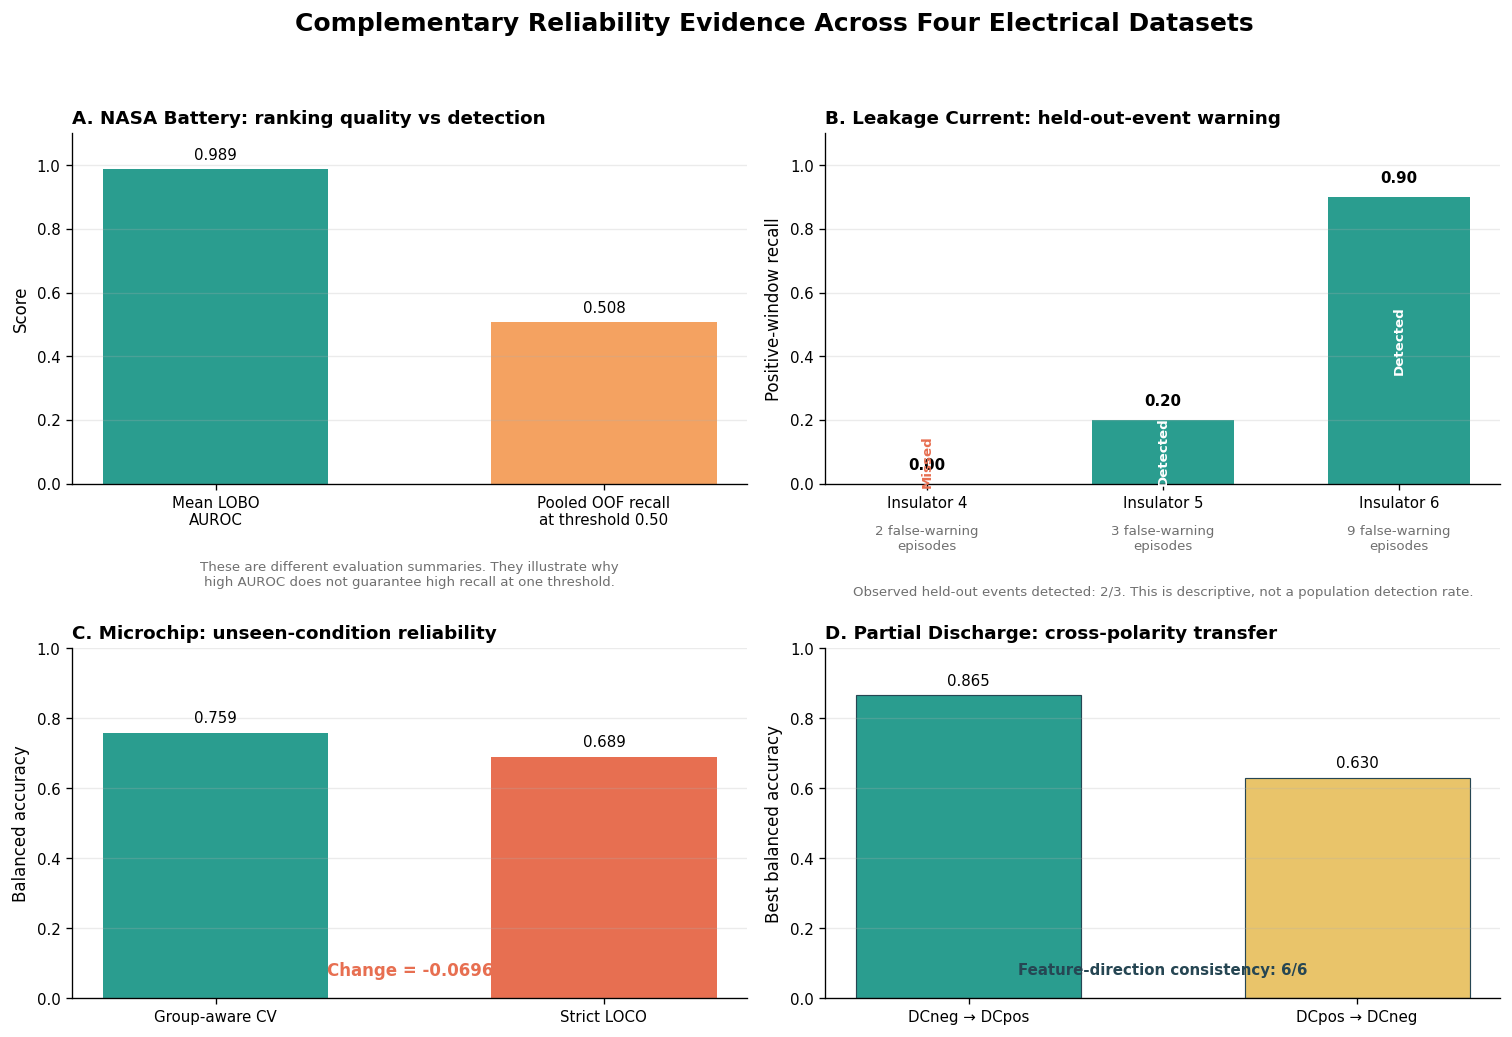

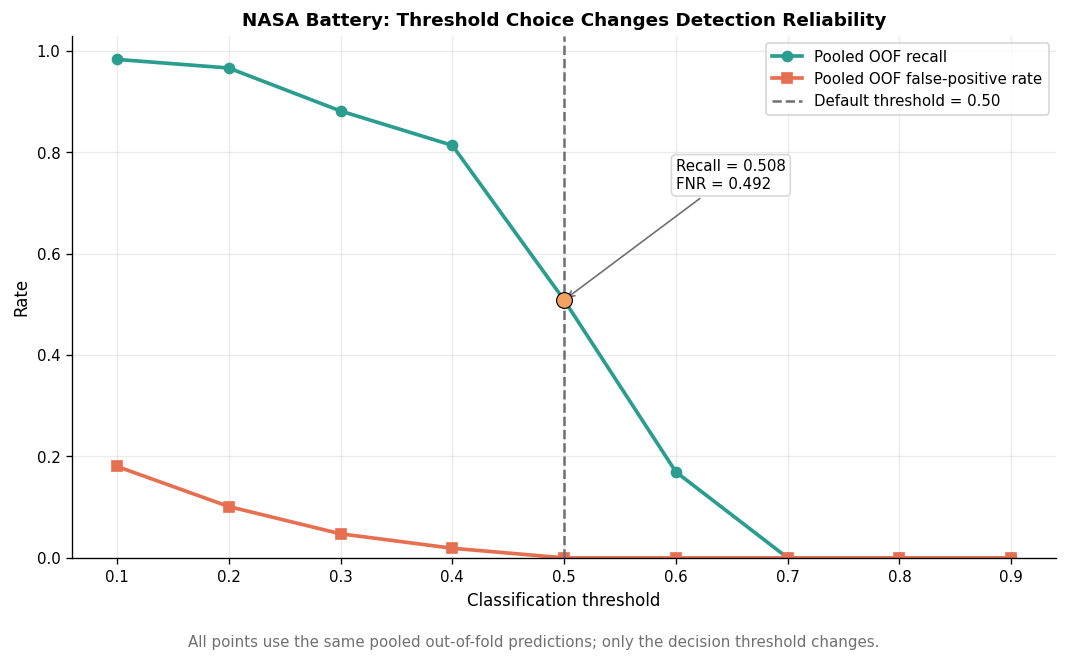

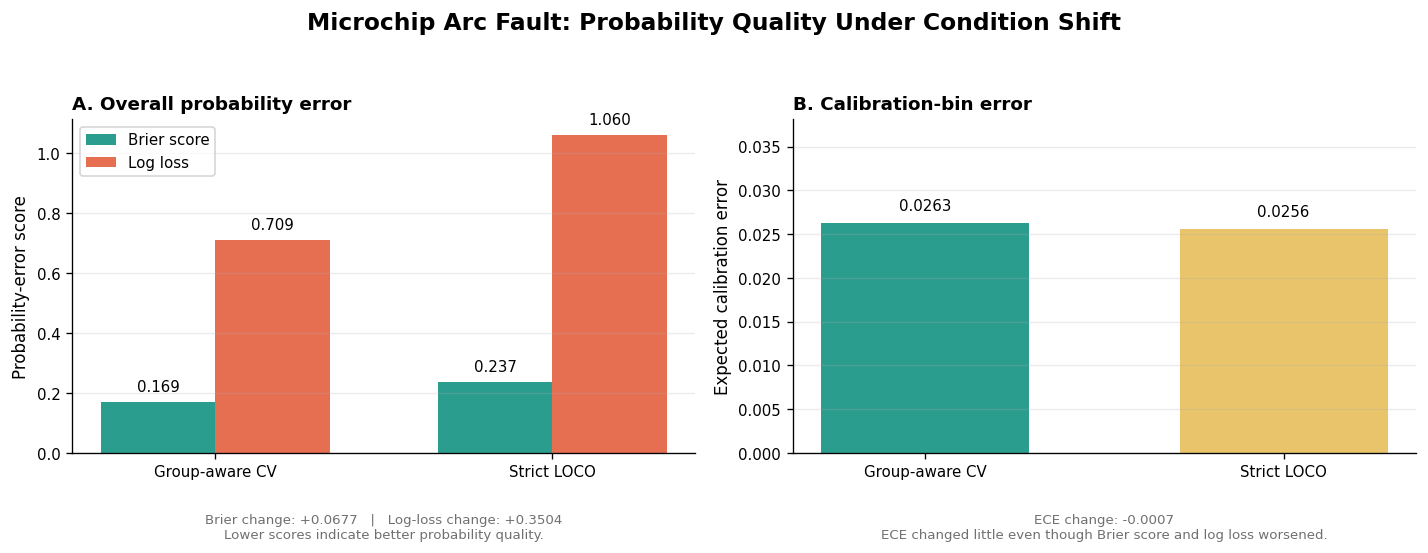


Figure directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Cross_Dataset_Reliability_Clean_Final/figures

Generated and verified files:
✓ 01_cross_dataset_reliability_evidence.png        396,557 bytes
✓ 01_cross_dataset_reliability_evidence.pdf        35,722 bytes
✓ 02_nasa_threshold_tradeoff.png                   212,209 bytes
✓ 02_nasa_threshold_tradeoff.pdf                   27,078 bytes
✓ 03_microchip_probability_quality.png             225,118 bytes
✓ 03_microchip_probability_quality.pdf             28,569 bytes

✓ Four complementary reliability tests are shown separately.
✓ NASA threshold sensitivity uses pooled OOF predictions.
✓ Leakage results remain event-specific and descriptive.
✓ Microchip ECE is separated from Brier score and log loss.
✓ Partial-discharge transfer directions remain distinct.
✓ No models were retrained.
✓ No frozen dataset-level results were modified.


In [36]:
# ============================================================
# CROSS-DATASET RELIABILITY SYNTHESIS
# CELL 3: ESSENTIAL RELIABILITY FIGURES
# ============================================================
#
# PURPOSE:
# Create three publication-quality figures summarizing the most
# important cross-dataset reliability findings.
#
# FIGURE 1:
#   Four-panel overview of NASA, Leakage Current, Microchip and
#   Partial Discharge reliability evidence.
#
# FIGURE 2:
#   NASA recall and false-positive-rate tradeoff across fixed
#   decision thresholds.
#
# FIGURE 3:
#   Microchip probability quality under familiar-condition
#   GroupCV and unseen-condition LOCO testing.
#
# Each figure is saved in:
#   - PNG format for slides, posters and general display
#   - PDF format for publication-quality vector output
#
# No models are trained and no frozen dataset results are changed.
# ============================================================


# ------------------------------------------------------------
# STEP 1 — IMPORT FIGURE AND DATA LIBRARIES
# ------------------------------------------------------------

# NumPy supports plotting positions and numerical checks.
import numpy as np

# pandas supports preparation and merging of figure data.
import pandas as pd

# matplotlib creates and saves the figures.
import matplotlib.pyplot as plt

# Path manages figure output locations.
from pathlib import Path


# Print the cell heading.
print("=" * 105)
print("CROSS-DATASET RELIABILITY SYNTHESIS")
print("CELL 3: ESSENTIAL RELIABILITY FIGURES")
print("=" * 105)


# ------------------------------------------------------------
# STEP 2 — DEFINE THE OUTPUT DIRECTORIES
# ------------------------------------------------------------

# Main directory for the clean cross-dataset synthesis.
CROSS_CLEAN_DIR = (
    RESULTS_ROOT /
    "Cross_Dataset_Reliability_Clean_Final"
)


# Store publication figures in a figures subdirectory.
CROSS_FIGURE_DIR = CROSS_CLEAN_DIR / "figures"


# Create the directories if they do not already exist.
CROSS_CLEAN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CROSS_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Store the path of every generated figure for final verification.
generated_figure_files = []


# ------------------------------------------------------------
# STEP 3 — DEFINE A CONSISTENT FIGURE STYLE
# ------------------------------------------------------------

plt.rcParams.update({
    # Resolution used while displaying figures in Colab.
    "figure.dpi": 120,

    # Resolution used for saved raster images.
    "savefig.dpi": 300,

    # Consistent text sizes.
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,

    # Remove unnecessary top and right borders.
    "axes.spines.top": False,
    "axes.spines.right": False
})


# Define a consistent, reusable color palette.
COLORS = {
    "navy": "#264653",
    "blue": "#2A9D8F",
    "gold": "#E9C46A",
    "orange": "#F4A261",
    "red": "#E76F51",
    "gray": "#707070",
    "light_gray": "#D9D9D9"
}


# ------------------------------------------------------------
# STEP 4 — DEFINE A FIGURE-SAVING FUNCTION
# ------------------------------------------------------------

def save_figure(fig, filename):
    """
    Save one figure in PNG and PDF formats and record both paths.
    """

    # Construct the PNG and PDF paths.
    png_path = CROSS_FIGURE_DIR / f"{filename}.png"
    pdf_path = CROSS_FIGURE_DIR / f"{filename}.pdf"


    # Save a high-resolution PNG with a white background.
    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )


    # Save a publication-quality PDF.
    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white"
    )


    # Add both files to the final verification list.
    generated_figure_files.extend([
        png_path,
        pdf_path
    ])


# ------------------------------------------------------------
# STEP 5 — DEFINE A BAR-LABELING FUNCTION
# ------------------------------------------------------------

def label_bars(
    ax,
    bars,
    decimals=3,
    vertical_offset=0.02
):
    """
    Add a numerical value above each finite vertical bar.
    """

    for bar in bars:

        # Retrieve the bar height.
        height = float(bar.get_height())


        # Add a label only when the value is finite.
        if np.isfinite(height):
            ax.text(
                # Center the label horizontally.
                bar.get_x() + bar.get_width() / 2,

                # Place it slightly above the bar.
                height + vertical_offset,

                # Format it with the requested decimal places.
                f"{height:.{decimals}f}",

                ha="center",
                va="bottom",
                fontsize=9
            )


# ============================================================
# PART 1 — PREPARE LEAKAGE CURRENT FIGURE DATA
# ============================================================


# ------------------------------------------------------------
# STEP 6 — SELECT EVENT-WARNING VARIABLES
# ------------------------------------------------------------

leakage_plot = leak_event[
    [
        "test_insulator",
        "event_detected",
        "positive_window_recall"
    ]
].copy()


# Define the columns required from the episode table.
leakage_episode_columns = [
    "test_insulator",
    "false_warning_episodes"
]


# Confirm that the required columns are available.
assert set(leakage_episode_columns).issubset(
    leak_false_warning_episodes.columns
), (
    "Required false-warning episode columns are missing."
)


# ------------------------------------------------------------
# STEP 7 — MERGE EVENT AND FALSE-WARNING RESULTS
# ------------------------------------------------------------

leakage_plot = leakage_plot.merge(
    leak_false_warning_episodes[
        leakage_episode_columns
    ],
    on="test_insulator",
    how="left"
)


# Arrange event insulators in numerical order.
leakage_plot = leakage_plot.sort_values(
    "test_insulator"
).reset_index(drop=True)


# ------------------------------------------------------------
# STEP 8 — STANDARDIZE LEAKAGE NUMERICAL VALUES
# ------------------------------------------------------------

# Require valid numeric positive-window recall values.
leakage_plot["positive_window_recall"] = pd.to_numeric(
    leakage_plot["positive_window_recall"],
    errors="raise"
)


# Convert episode counts to integers.
#
# Missing merged values would become zero, although the expected
# final table contains an episode count for every event.
leakage_plot["false_warning_episodes"] = (
    pd.to_numeric(
        leakage_plot["false_warning_episodes"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
)


# ------------------------------------------------------------
# STEP 9 — STANDARDIZE EVENT-DETECTION BOOLEANS
# ------------------------------------------------------------

# CSV imports may represent Boolean values as text.
if leakage_plot["event_detected"].dtype == object:
    leakage_plot["event_detected"] = (
        leakage_plot["event_detected"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False
        })
    )


# Stop if any value could not be interpreted.
assert leakage_plot["event_detected"].notna().all(), (
    "Leakage event_detected values could not be converted."
)


# Ensure the final column uses Boolean type.
leakage_plot["event_detected"] = (
    leakage_plot["event_detected"].astype(bool)
)


# ============================================================
# FIGURE 1 — FOUR COMPLEMENTARY RELIABILITY TESTS
# ============================================================


# ------------------------------------------------------------
# STEP 10 — CREATE A TWO-BY-TWO FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9)
)


# Add the overall figure title.
fig.suptitle(
    "Complementary Reliability Evidence Across Four Electrical Datasets",
    fontsize=15,
    fontweight="bold",
    y=0.995
)


# ------------------------------------------------------------
# STEP 11 — PANEL A: NASA BATTERY
# ------------------------------------------------------------

ax = axes[0, 0]


# Compare ranking ability with actual warning recall.
nasa_values = [
    float(nasa_mean_auroc),
    float(nasa_default_recall)
]


nasa_labels = [
    "Mean LOBO\nAUROC",
    "Pooled OOF recall\nat threshold 0.50"
]


# Create the two bars.
bars = ax.bar(
    nasa_labels,
    nasa_values,
    color=[
        COLORS["blue"],
        COLORS["orange"]
    ],
    width=0.58
)


# Format the axis.
ax.set_ylim(0, 1.10)
ax.set_ylabel("Score")

ax.set_title(
    "A. NASA Battery: ranking quality vs detection",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)


# Add numerical values above the bars.
label_bars(
    ax,
    bars,
    decimals=3
)


# Explain that AUROC and recall are different summaries.
ax.text(
    0.5,
    -0.22,
    "These are different evaluation summaries. They illustrate why\n"
    "high AUROC does not guarantee high recall at one threshold.",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=8,
    color=COLORS["gray"]
)


# ------------------------------------------------------------
# STEP 12 — PANEL B: LEAKAGE CURRENT
# ------------------------------------------------------------

ax = axes[0, 1]


# Create one x-axis position per held-out event insulator.
x = np.arange(
    len(leakage_plot)
)


# Use blue for detected events and red for missed events.
event_colors = [
    COLORS["blue"] if detected
    else COLORS["red"]
    for detected in leakage_plot["event_detected"]
]


# Plot positive-window recall for each event.
bars = ax.bar(
    x,
    leakage_plot["positive_window_recall"],
    color=event_colors,
    width=0.60
)


# Add insulator labels.
ax.set_xticks(x)

ax.set_xticklabels([
    f"Insulator {int(value)}"
    for value in leakage_plot["test_insulator"]
])


# Format the panel.
ax.set_ylim(0, 1.10)
ax.set_ylabel("Positive-window recall")

ax.set_title(
    "B. Leakage Current: held-out-event warning",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# STEP 13 — LABEL EACH LEAKAGE EVENT
# ------------------------------------------------------------

for position, row in leakage_plot.iterrows():

    # Retrieve event-window recall.
    recall_value = float(
        row["positive_window_recall"]
    )


    # Retrieve the event-detection outcome.
    detected = bool(
        row["event_detected"]
    )


    detected_text = (
        "Detected"
        if detected
        else "Missed"
    )


    # Add the numerical recall above the bar.
    ax.text(
        position,
        recall_value + 0.035,
        f"{recall_value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )


    # Place the status inside sufficiently tall bars.
    # For a short or zero bar, place it above the baseline in red.
    if recall_value >= 0.18:
        status_y = recall_value / 2
        status_color = "white"
    else:
        status_y = 0.07
        status_color = COLORS["red"]


    ax.text(
        position,
        status_y,
        detected_text,
        ha="center",
        va="center",
        rotation=90,
        fontsize=8,
        color=status_color,
        fontweight="bold"
    )


    # Add the false-warning episode count below each bar.
    ax.text(
        position,
        -0.13,
        (
            f"{int(row['false_warning_episodes'])} "
            "false-warning\nepisodes"
        ),
        ha="center",
        va="top",
        fontsize=8,
        color=COLORS["gray"]
    )


# Add the event-count scope safeguard.
ax.text(
    0.5,
    -0.29,
    (
        f"Observed held-out events detected: "
        f"{leakage_events_detected}/"
        f"{leakage_events_total}. "
        "This is descriptive, not a population detection rate."
    ),
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=8,
    color=COLORS["gray"]
)


# ------------------------------------------------------------
# STEP 14 — PANEL C: MICROCHIP ARC FAULT
# ------------------------------------------------------------

ax = axes[1, 0]


# Compare familiar-condition and unseen-condition performance.
micro_values = [
    float(micro_group_ba),
    float(micro_loco_ba)
]


micro_labels = [
    "Group-aware CV",
    "Strict LOCO"
]


bars = ax.bar(
    micro_labels,
    micro_values,
    color=[
        COLORS["blue"],
        COLORS["red"]
    ],
    width=0.58
)


# Format the panel.
ax.set_ylim(0, 1.0)
ax.set_ylabel("Balanced accuracy")

ax.set_title(
    "C. Microchip: unseen-condition reliability",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)


# Add numerical labels.
label_bars(
    ax,
    bars,
    decimals=3
)


# Display the LOCO-minus-GroupCV change.
ax.text(
    0.5,
    0.08,
    f"Change = {micro_ba_change:+.4f}",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color=COLORS["red"]
)


# ------------------------------------------------------------
# STEP 15 — PANEL D: PARTIAL DISCHARGE
# ------------------------------------------------------------

ax = axes[1, 1]


# Preserve both transfer directions as separate values.
pd_values = [
    float(pd_neg_to_pos_ba),
    float(pd_pos_to_neg_ba)
]


pd_labels = [
    "DCneg → DCpos",
    "DCpos → DCneg"
]


bars = ax.bar(
    pd_labels,
    pd_values,
    color=[
        COLORS["blue"],
        COLORS["gold"]
    ],
    edgecolor=COLORS["navy"],
    linewidth=0.7,
    width=0.58
)


# Format the panel.
ax.set_ylim(0, 1.0)
ax.set_ylabel("Best balanced accuracy")

ax.set_title(
    "D. Partial Discharge: cross-polarity transfer",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)


# Add numerical values above the bars.
label_bars(
    ax,
    bars,
    decimals=3
)


# Display feature-direction consistency inside the panel.
ax.text(
    0.5,
    0.08,
    (
        "Feature-direction consistency: "
        f"{pd_direction_consistent}/"
        f"{pd_direction_total}"
    ),
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold",
    color=COLORS["navy"]
)


# ------------------------------------------------------------
# STEP 16 — SAVE AND DISPLAY FIGURE 1
# ------------------------------------------------------------

# Adjust subplot spacing while reserving room for the main title
# and below-axis explanatory text.
plt.tight_layout(
    rect=[0, 0.04, 1, 0.96]
)


# Save PNG and PDF versions.
save_figure(
    fig,
    "01_cross_dataset_reliability_evidence"
)


# Display the figure in Colab.
plt.show()


# Release the figure from memory.
plt.close(fig)


# ============================================================
# FIGURE 2 — NASA THRESHOLD SENSITIVITY
# ============================================================


# ------------------------------------------------------------
# STEP 17 — VERIFY THE NASA THRESHOLD VARIABLES
# ------------------------------------------------------------

required_nasa_threshold_columns = {
    "threshold",
    "recall",
    "false_positive_rate"
}


assert required_nasa_threshold_columns.issubset(
    nasa_thresholds.columns
), (
    "NASA threshold table does not contain the required columns."
)


# Sort the threshold values from lowest to highest.
nasa_threshold_plot = (
    nasa_thresholds.copy()
    .sort_values("threshold")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 18 — CREATE THE NASA THRESHOLD FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)


# Plot pooled recall at each threshold.
ax.plot(
    nasa_threshold_plot["threshold"],
    nasa_threshold_plot["recall"],
    marker="o",
    linewidth=2.2,
    markersize=6,
    color=COLORS["blue"],
    label="Pooled OOF recall"
)


# Plot the pooled false-positive rate.
ax.plot(
    nasa_threshold_plot["threshold"],
    nasa_threshold_plot["false_positive_rate"],
    marker="s",
    linewidth=2.2,
    markersize=6,
    color=COLORS["red"],
    label="Pooled OOF false-positive rate"
)


# Mark the conventional 0.50 threshold.
ax.axvline(
    0.50,
    color=COLORS["gray"],
    linestyle="--",
    linewidth=1.5,
    label="Default threshold = 0.50"
)


# Highlight recall at threshold 0.50.
ax.scatter(
    [0.50],
    [nasa_default_recall],
    s=90,
    color=COLORS["orange"],
    edgecolor="black",
    linewidth=0.7,
    zorder=5
)


# ------------------------------------------------------------
# STEP 19 — ANNOTATE THE DEFAULT THRESHOLD
# ------------------------------------------------------------

ax.annotate(
    (
        f"Recall = {nasa_default_recall:.3f}\n"
        f"FNR = {nasa_default_fnr:.3f}"
    ),
    xy=(
        0.50,
        nasa_default_recall
    ),
    xytext=(
        0.60,
        min(
            nasa_default_recall + 0.22,
            0.92
        )
    ),
    arrowprops={
        "arrowstyle": "->",
        "color": COLORS["gray"]
    },
    fontsize=9,
    bbox={
        "boxstyle": "round,pad=0.3",
        "facecolor": "white",
        "edgecolor": COLORS["light_gray"]
    }
)


# Format the plot.
ax.set_ylim(0, 1.03)
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Rate")

ax.set_title(
    "NASA Battery: Threshold Choice Changes Detection Reliability",
    fontweight="bold"
)

ax.grid(alpha=0.25)
ax.legend(loc="best")


# Explain that the model probabilities remain unchanged.
fig.text(
    0.5,
    0.01,
    (
        "All points use the same pooled out-of-fold predictions; "
        "only the decision threshold changes."
    ),
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)


# ------------------------------------------------------------
# STEP 20 — SAVE AND DISPLAY FIGURE 2
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

save_figure(
    fig,
    "02_nasa_threshold_tradeoff"
)

plt.show()
plt.close(fig)


# ============================================================
# FIGURE 3 — MICROCHIP PROBABILITY QUALITY
# ============================================================


# ------------------------------------------------------------
# STEP 21 — VERIFY REQUIRED PROBABILITY METRICS
# ------------------------------------------------------------

required_probability_columns = {
    "multiclass_brier",
    "log_loss",
    "ece_10bin"
}


assert required_probability_columns.issubset(
    micro_calibration.columns
), (
    "Microchip probability table does not contain "
    "the required probability-quality columns."
)


# ------------------------------------------------------------
# STEP 22 — RETRIEVE GROUPCV AND LOCO VALUES
# ------------------------------------------------------------

group_brier = float(
    micro_group_probability["multiclass_brier"]
)

loco_brier = float(
    micro_loco_probability["multiclass_brier"]
)

group_logloss = float(
    micro_group_probability["log_loss"]
)

loco_logloss = float(
    micro_loco_probability["log_loss"]
)

group_ece = float(
    micro_group_probability["ece_10bin"]
)

loco_ece = float(
    micro_loco_probability["ece_10bin"]
)


# ------------------------------------------------------------
# STEP 23 — CREATE THE TWO-PANEL PROBABILITY FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5.2)
)


fig.suptitle(
    "Microchip Arc Fault: Probability Quality Under Condition Shift",
    fontsize=14,
    fontweight="bold"
)


evaluation_labels = [
    "Group-aware CV",
    "Strict LOCO"
]


x = np.arange(
    len(evaluation_labels)
)


# Width of each bar in the grouped chart.
width = 0.34


# ------------------------------------------------------------
# STEP 24 — PANEL A: BRIER SCORE AND LOG LOSS
# ------------------------------------------------------------

ax = axes[0]


brier_values = [
    group_brier,
    loco_brier
]


logloss_values = [
    group_logloss,
    loco_logloss
]


# Plot Brier scores slightly left of each group center.
brier_bars = ax.bar(
    x - width / 2,
    brier_values,
    width,
    label="Brier score",
    color=COLORS["blue"]
)


# Plot log loss slightly right of each group center.
logloss_bars = ax.bar(
    x + width / 2,
    logloss_values,
    width,
    label="Log loss",
    color=COLORS["red"]
)


# Add condition labels and axis title.
ax.set_xticks(x)
ax.set_xticklabels(evaluation_labels)
ax.set_ylabel("Probability-error score")

ax.set_title(
    "A. Overall probability error",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()


# Add numerical bar labels.
label_bars(
    ax,
    brier_bars,
    decimals=3,
    vertical_offset=0.025
)

label_bars(
    ax,
    logloss_bars,
    decimals=3,
    vertical_offset=0.025
)


# Display the changes and metric direction.
ax.text(
    0.5,
    -0.18,
    (
        f"Brier change: {micro_brier_change:+.4f}   |   "
        f"Log-loss change: {micro_logloss_change:+.4f}\n"
        "Lower scores indicate better probability quality."
    ),
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=8,
    color=COLORS["gray"]
)


# ------------------------------------------------------------
# STEP 25 — PANEL B: EXPECTED CALIBRATION ERROR
# ------------------------------------------------------------

ax = axes[1]


ece_values = [
    group_ece,
    loco_ece
]


ece_bars = ax.bar(
    evaluation_labels,
    ece_values,
    color=[
        COLORS["blue"],
        COLORS["gold"]
    ],
    width=0.58
)


# Set the vertical range dynamically so the small ECE values
# remain visible.
ece_upper = max(ece_values) * 1.45


# Use a safe fallback if the calculated limit is invalid.
if not np.isfinite(ece_upper) or ece_upper <= 0:
    ece_upper = 0.05


ax.set_ylim(0, ece_upper)
ax.set_ylabel("Expected calibration error")

ax.set_title(
    "B. Calibration-bin error",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)


# Add four-decimal labels because ECE values are small.
label_bars(
    ax,
    ece_bars,
    decimals=4,
    vertical_offset=max(ece_values) * 0.04
)


# Explain why ECE must be interpreted with other metrics.
ax.text(
    0.5,
    -0.18,
    (
        f"ECE change: {micro_ece_change:+.4f}\n"
        "ECE changed little even though Brier score "
        "and log loss worsened."
    ),
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=8,
    color=COLORS["gray"]
)


# ------------------------------------------------------------
# STEP 26 — SAVE AND DISPLAY FIGURE 3
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0.06, 1, 0.94]
)

save_figure(
    fig,
    "03_microchip_probability_quality"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# STEP 27 — VERIFY ALL GENERATED FIGURES
# ------------------------------------------------------------
#
# Three figures saved in two formats should produce six files.
# ------------------------------------------------------------

assert len(generated_figure_files) == 6, (
    "Expected three figures in both PNG and PDF formats."
)


# Confirm that every file exists and contains data.
for figure_file in generated_figure_files:

    assert figure_file.exists(), (
        f"Figure was not created: {figure_file}"
    )

    assert figure_file.stat().st_size > 0, (
        f"Figure is empty: {figure_file}"
    )


# ------------------------------------------------------------
# STEP 28 — PRINT THE FIGURE-EXPORT REPORT
# ------------------------------------------------------------

print()
print("Figure directory:")
print(CROSS_FIGURE_DIR)

print()
print("Generated and verified files:")

for figure_file in generated_figure_files:
    print(
        f"✓ {figure_file.name:<48} "
        f"{figure_file.stat().st_size:,} bytes"
    )


# Confirm the figure safeguards.
print()
print("✓ Four complementary reliability tests are shown separately.")
print("✓ NASA threshold sensitivity uses pooled OOF predictions.")
print("✓ Leakage results remain event-specific and descriptive.")
print("✓ Microchip ECE is separated from Brier score and log loss.")
print("✓ Partial-discharge transfer directions remain distinct.")
print("✓ No models were retrained.")
print("✓ No frozen dataset-level results were modified.")

##**4. Cross DS - Conclusions and Claim Safeguards**

In [37]:
# ============================================================
# CROSS-DATASET RELIABILITY SYNTHESIS
# CELL 4: CONCLUSIONS AND CLAIM SAFEGUARDS
#
# PURPOSE:
# Convert the numerical evidence from the four datasets into:
#
# 1. One supported conclusion for each dataset
# 2. A set of findings that connect the four studies
# 3. Safeguards against overstating the results
# 4. The final scientific and plain-language conclusions
#
# IMPORTANT:
# - This cell does not train any models.
# - It does not change any dataset-level results.
# - It only interprets results calculated in earlier cells.
# ============================================================

import numpy as np
import pandas as pd

# display() presents DataFrames as readable notebook tables.
from IPython.display import display


# ============================================================
# PRINT THE CELL HEADING
# ============================================================

print("=" * 105)
print("CROSS-DATASET RELIABILITY SYNTHESIS")
print("CELL 4: EVIDENCE-BASED CONCLUSIONS AND CLAIM SAFEGUARDS")
print("=" * 105)


# ============================================================
# STEP 1 — VERIFY THE NUMBERS USED IN THE CONCLUSIONS
#
# Before writing any conclusions, these assertions confirm that
# the variables created in the previous synthesis cells contain
# the frozen final results.
#
# If an earlier table or variable changes unexpectedly, the cell
# stops here instead of producing conclusions from wrong values.
# ============================================================


# ------------------------------------------------------------
# NASA BATTERY CHECKS
# ------------------------------------------------------------

# Confirm the mean leave-one-battery-out AUROC.
assert np.isclose(
    nasa_mean_auroc,
    0.9894,
    atol=0.0001
)

# Confirm the pooled out-of-fold recall at threshold 0.50.
assert np.isclose(
    nasa_default_recall,
    0.5085,
    atol=0.0001
)

# Confirm the corresponding false-negative rate.
assert np.isclose(
    nasa_default_fnr,
    0.4915,
    atol=0.0001
)


# ------------------------------------------------------------
# LEAKAGE-CURRENT CHECKS
# ------------------------------------------------------------

# Confirm that two of the three held-out events were detected.
assert leakage_events_detected == 2
assert leakage_events_total == 3

# Confirm the total number of false-warning episodes.
assert leakage_false_warning_episodes == 14


# ------------------------------------------------------------
# MICROCHIP ARC-FAULT CHECKS
# ------------------------------------------------------------

# Confirm balanced accuracy under familiar GroupCV conditions.
assert np.isclose(
    micro_group_ba,
    0.7585,
    atol=0.0001
)

# Confirm balanced accuracy when one complete operating
# condition was excluded from training.
assert np.isclose(
    micro_loco_ba,
    0.6889,
    atol=0.0001
)

# Positive changes mean Brier score and log loss became worse
# under strict leave-one-condition-out evaluation.
assert micro_brier_change > 0
assert micro_logloss_change > 0

# ECE remained nearly unchanged, so it must not be described
# as showing the same deterioration as the other two measures.
assert abs(micro_ece_change) < 0.01


# ------------------------------------------------------------
# PARTIAL-DISCHARGE CHECKS
# ------------------------------------------------------------

# Confirm that all six features preserved the same direction
# between the 2p and 2s categories across polarity.
assert pd_direction_consistent == 6
assert pd_direction_total == 6

# Confirm the best transfer performance in each direction.
assert np.isclose(
    pd_neg_to_pos_ba,
    0.865,
    atol=0.001
)

assert np.isclose(
    pd_pos_to_neg_ba,
    0.630,
    atol=0.001
)


# ============================================================
# STEP 2 — CREATE DATASET-SPECIFIC CONCLUSIONS
#
# Each row answers four questions:
#
# 1. What reliability question did the dataset test?
# 2. What numerical evidence was observed?
# 3. What conclusion does that evidence support?
# 4. What limitation must be stated?
#
# Keeping these fields separate makes it easier to distinguish
# the evidence from its interpretation.
# ============================================================

dataset_conclusions = pd.DataFrame([

    # --------------------------------------------------------
    # NASA BATTERY
    # --------------------------------------------------------
    {
        "dataset": "NASA Battery",

        "reliability_question":
            "Did strong ranking performance produce reliable "
            "warning decisions at a fixed threshold?",

        # Insert the frozen results into a readable sentence.
        "key_evidence":
            f"Mean LOBO AUROC={nasa_mean_auroc:.3f}; "
            f"pooled OOF recall at threshold 0.50="
            f"{nasa_default_recall:.3f}; "
            f"FNR={nasa_default_fnr:.3f}.",

        "supported_conclusion":
            "The model ranked degradation risk very well, but the "
            "standard threshold missed nearly half of the positive "
            "cases. Ranking quality alone was insufficient for "
            "evaluating warning sensitivity.",

        "claim_boundary":
            "The result applies to the four evaluated NASA batteries "
            "and does not establish performance across all batteries."
    },

    # --------------------------------------------------------
    # LEAKAGE CURRENT
    # --------------------------------------------------------
    {
        "dataset": "Leakage Current",

        "reliability_question":
            "Did window-level discrimination translate into "
            "consistent warning of held-out events?",

        "key_evidence":
            f"{leakage_events_detected}/{leakage_events_total} "
            f"held-out events detected; "
            f"{leakage_false_warning_episodes} false-warning episodes.",

        "supported_conclusion":
            "Window-level model performance did not guarantee that "
            "every unseen event would be detected. False-warning "
            "burden also remained relevant.",

        "claim_boundary":
            "Only three evaluable held-out events were available. "
            "The 2/3 result is descriptive and is not a population "
            "detection-rate estimate."
    },

    # --------------------------------------------------------
    # MICROCHIP ARC FAULT
    # --------------------------------------------------------
    {
        "dataset": "Microchip Arc Fault",

        "reliability_question":
            "Did performance and probability quality remain stable "
            "under an unseen operating condition?",

        "key_evidence":
            f"Balanced accuracy changed from {micro_group_ba:.3f} "
            f"to {micro_loco_ba:.3f} "
            f"({micro_ba_change:+.3f}); "
            f"Brier change={micro_brier_change:+.3f}; "
            f"log-loss change={micro_logloss_change:+.3f}; "
            f"ECE change={micro_ece_change:+.4f}.",

        "supported_conclusion":
            "Accuracy and overall probability quality weakened under "
            "strict unseen-condition testing. ECE changed little, "
            "showing that one calibration summary alone could conceal "
            "other probability-quality deterioration.",

        "claim_boundary":
            "The observed shift is specific to the four operating "
            "conditions in this dataset and does not quantify every "
            "possible real-world condition change."
    },

    # --------------------------------------------------------
    # PARTIAL DISCHARGE
    # --------------------------------------------------------
    {
        "dataset": "Partial Discharge",

        "reliability_question":
            "Did consistent physical feature relationships guarantee "
            "reliable classifier transfer between polarities?",

        "key_evidence":
            f"{pd_direction_consistent}/{pd_direction_total} feature "
            f"directions were consistent; best balanced accuracy was "
            f"{pd_neg_to_pos_ba:.3f} for DCneg→DCpos and "
            f"{pd_pos_to_neg_ba:.3f} for DCpos→DCneg.",

        "supported_conclusion":
            "Consistent feature directions did not guarantee equal "
            "predictive transfer. Transfer reliability depended on "
            "the training and testing direction.",

        "claim_boundary":
            "The void configurations are experimental categories, "
            "not longitudinal stages of degradation. The analysis "
            "does not establish a causal degradation pathway."
    }
])

print()
print("Dataset-specific conclusions:")
display(dataset_conclusions)


# ============================================================
# STEP 3 — IDENTIFY THE CROSS-DATASET FINDINGS
#
# The four datasets are not combined into one accuracy score.
# Instead, each contributes evidence about a different part of
# AI reliability.
#
# This prevents unrelated tasks and metrics from being averaged
# into a scientifically misleading universal score.
# ============================================================

cross_dataset_findings = pd.DataFrame([

    # NASA tests the effect of the decision threshold.
    {
        "finding_id": 1,
        "reliability_dimension":
            "Decision-threshold sensitivity",
        "supporting_dataset":
            "NASA Battery",
        "finding":
            "High AUROC did not guarantee high recall at the "
            "standard decision threshold."
    },

    # Leakage Current tests actual event-warning behavior.
    {
        "finding_id": 2,
        "reliability_dimension":
            "Event-level warning",
        "supporting_dataset":
            "Leakage Current",
        "finding":
            "Good window-level discrimination did not guarantee "
            "detection of every held-out event."
    },

    # Microchip tests performance under an unseen condition.
    {
        "finding_id": 3,
        "reliability_dimension":
            "Unseen-condition generalization",
        "supporting_dataset":
            "Microchip Arc Fault",
        "finding":
            "Performance declined when the model encountered an "
            "operating condition excluded from training."
    },

    # Microchip also tests the quality of predicted probabilities.
    {
        "finding_id": 4,
        "reliability_dimension":
            "Probability quality",
        "supporting_dataset":
            "Microchip Arc Fault",
        "finding":
            "Brier score and log loss worsened under condition shift "
            "while ECE remained nearly unchanged."
    },

    # Partial Discharge tests transfer between electrical polarities.
    {
        "finding_id": 5,
        "reliability_dimension":
            "Cross-condition transfer",
        "supporting_dataset":
            "Partial Discharge",
        "finding":
            "Physical feature consistency did not guarantee symmetric "
            "classifier transfer between polarities."
    }
])

print()
print("Cross-dataset findings:")
display(cross_dataset_findings)


# ============================================================
# STEP 4 — DEFINE CLAIM SAFEGUARDS
#
# These safeguards document exactly what the project may claim
# and what would overstate the evidence.
#
# They are important because the datasets represent different
# electrical systems and different reliability questions.
# ============================================================

claim_safeguards = pd.DataFrame([

    # --------------------------------------------------------
    # DATASET RELATIONSHIP
    # --------------------------------------------------------
    {
        "topic": "Meaning of the four datasets",

        "allowed_statement":
            "The datasets provide complementary case studies of "
            "electrical degradation, leakage warning, arc-fault "
            "classification, and partial-discharge transfer.",

        "statement_to_avoid":
            "The four datasets represent consecutive stages of one "
            "electrical degradation-to-fire process."
    },

    # --------------------------------------------------------
    # FIRE-PREDICTION CLAIM
    # --------------------------------------------------------
    {
        "topic": "Fire prediction",

        "allowed_statement":
            "The project evaluates the reliability of AI for "
            "electrical degradation and fault warning.",

        "statement_to_avoid":
            "The models directly predict or prevent electrical fires."
    },

    # --------------------------------------------------------
    # NASA METRIC AGGREGATION
    # --------------------------------------------------------
    {
        "topic": "NASA aggregation",

        "allowed_statement":
            "Mean LOBO AUROC and pooled OOF recall describe different "
            "aspects of performance.",

        "statement_to_avoid":
            "Treating mean LOBO AUROC and pooled OOF recall as if they "
            "were calculated using the same aggregation procedure."
    },

    # --------------------------------------------------------
    # LEAKAGE EVENT RESULT
    # --------------------------------------------------------
    {
        "topic": "Leakage event result",

        "allowed_statement":
            "Two of three observed held-out events were detected.",

        "statement_to_avoid":
            "The system has a general 66.7% event-detection rate."
    },

    # --------------------------------------------------------
    # MICROCHIP PROBABILITY QUALITY
    # --------------------------------------------------------
    {
        "topic": "Microchip probability quality",

        "allowed_statement":
            "Brier score and log loss worsened, while ECE changed "
            "little under strict LOCO evaluation.",

        "statement_to_avoid":
            "Every calibration measure worsened under condition shift."
    },

    # --------------------------------------------------------
    # PARTIAL-DISCHARGE MEANING
    # --------------------------------------------------------
    {
        "topic": "Partial-discharge interpretation",

        "allowed_statement":
            "Transfer was evaluated between experimental polarity "
            "conditions and void-configuration categories.",

        "statement_to_avoid":
            "The configurations are progressive stages of physical "
            "degradation."
    },

    # --------------------------------------------------------
    # CROSS-DATASET COMPARISON
    # --------------------------------------------------------
    {
        "topic": "Cross-dataset comparison",

        "allowed_statement":
            "Each dataset tests a different reliability dimension.",

        "statement_to_avoid":
            "Averaging unrelated metrics into one universal "
            "reliability score."
    },

    # --------------------------------------------------------
    # MODEL-FAMILY SCOPE
    # --------------------------------------------------------
    {
        "topic": "Model-family scope",

        "allowed_statement":
            "The clean analysis evaluates the frozen representative "
            "model under several strict reliability tests.",

        "statement_to_avoid":
            "The current results prove that every AI algorithm behaves "
            "the same way. Broader model sensitivity requires testing "
            "additional model families."
    }
])

print()
print("Claim and interpretation safeguards:")
display(claim_safeguards)


# ============================================================
# STEP 5 — WRITE THE FINAL SCIENTIFIC CONCLUSION
#
# This paragraph combines the four complementary case studies.
#
# It does not say that AI is bad or unusable. It says that
# conventional performance scores provide incomplete evidence
# of whether an electrical-warning model can be trusted.
# ============================================================

final_conclusion = (
    "Across four complementary electrical datasets, conventional "
    "performance measures provided useful but incomplete evidence of "
    "model reliability. The NASA analysis showed that high ranking "
    "performance did not guarantee high recall at a fixed warning "
    "threshold. The leakage-current analysis showed that window-level "
    "discrimination did not ensure detection of every held-out event. "
    "The Microchip arc-fault analysis showed reduced performance and "
    "worse overall probability quality under unseen operating "
    "conditions. The partial-discharge analysis showed that consistent "
    "physical feature relationships did not guarantee symmetric "
    "predictive transfer. Together, these case studies support using "
    "threshold sensitivity, event-level evaluation, strict "
    "unseen-condition testing, probability-quality analysis, and "
    "cross-condition transfer tests alongside conventional metrics "
    "when evaluating AI for electrical degradation and fault warning."
)


# ============================================================
# STEP 6 — WRITE A PLAIN-LANGUAGE VERSION
#
# This shorter version communicates the same result to judges
# or audience members who may not know the technical metrics.
# ============================================================

plain_language_conclusion = (
    "An AI model can receive a strong score and still miss warnings, "
    "struggle with an individual event, or become less dependable when "
    "electrical conditions change. Therefore, electrical-warning AI "
    "should be tested under realistic changes before it is considered "
    "trustworthy."
)

print()
print("Final research conclusion:")
print(final_conclusion)

print()
print("Plain-language conclusion:")
print(plain_language_conclusion)


# ============================================================
# STEP 7 — FINAL STRUCTURE AND LANGUAGE CHECKS
#
# These checks make sure:
#
# - All four datasets have a conclusion
# - All five reliability dimensions are represented
# - All eight safeguards are present
# - None of the final tables contains a missing value
# - The conclusion does not make prohibited overclaims
# ============================================================

assert len(dataset_conclusions) == 4
assert len(cross_dataset_findings) == 5
assert len(claim_safeguards) == 8

assert dataset_conclusions.isna().sum().sum() == 0
assert cross_dataset_findings.isna().sum().sum() == 0
assert claim_safeguards.isna().sum().sum() == 0

# Make sure the scientific conclusion does not claim that the
# project directly performs fire prediction.
assert "fire prediction" not in final_conclusion.lower()

# Make sure the conclusion does not claim that unrelated
# reliability results were combined into one universal score.
assert "universal reliability score" not in final_conclusion.lower()


# ============================================================
# FINAL VERIFICATION MESSAGE
# ============================================================

print()
print("✓ Four dataset-specific conclusions documented.")
print("✓ Five complementary reliability dimensions identified.")
print("✓ Numerical conclusions match the frozen exported evidence.")
print("✓ Leakage 2/3 result remains descriptive.")
print("✓ Microchip ECE is not incorrectly described as worsening.")
print("✓ Partial-discharge categories are not treated as aging stages.")
print("✓ No direct electrical-fire prediction claim was made.")
print("✓ The current model-family limitation is explicitly stated.")
print("✓ No universal reliability score was created.")
print("✓ No models were retrained.")

CROSS-DATASET RELIABILITY SYNTHESIS
CELL 4: EVIDENCE-BASED CONCLUSIONS AND CLAIM SAFEGUARDS

Dataset-specific conclusions:


,dataset,reliability_question,key_evidence,supported_conclusion,claim_boundary
0,NASA Battery,Did strong ranking performance produce reliabl...,Mean LOBO AUROC=0.989; pooled OOF recall at th...,"The model ranked degradation risk very well, b...",The result applies to the four evaluated NASA ...
1,Leakage Current,Did window-level discrimination translate into...,2/3 held-out events detected; 14 false-warning...,Window-level model performance did not guarant...,Only three evaluable held-out events were avai...
2,Microchip Arc Fault,Did performance and probability quality remain...,Balanced accuracy changed from 0.759 to 0.689 ...,Accuracy and overall probability quality weake...,The observed shift is specific to the four ope...
3,Partial Discharge,Did consistent physical feature relationships ...,6/6 feature directions were consistent; best b...,Consistent feature directions did not guarante...,The void configurations are experimental categ...



Cross-dataset findings:


,finding_id,reliability_dimension,supporting_dataset,finding
0,1,Decision-threshold sensitivity,NASA Battery,High AUROC did not guarantee high recall at th...
1,2,Event-level warning,Leakage Current,Good window-level discrimination did not guara...
2,3,Unseen-condition generalization,Microchip Arc Fault,Performance declined when the model encountere...
3,4,Probability quality,Microchip Arc Fault,Brier score and log loss worsened under condit...
4,5,Cross-condition transfer,Partial Discharge,Physical feature consistency did not guarantee...



Claim and interpretation safeguards:


,topic,allowed_statement,statement_to_avoid
0,Meaning of the four datasets,The datasets provide complementary case studie...,The four datasets represent consecutive stages...
1,Fire prediction,The project evaluates the reliability of AI fo...,The models directly predict or prevent electri...
2,NASA aggregation,Mean LOBO AUROC and pooled OOF recall describe...,Treating mean LOBO AUROC and pooled OOF recall...
3,Leakage event result,Two of three observed held-out events were det...,The system has a general 66.7% event-detection...
4,Microchip probability quality,"Brier score and log loss worsened, while ECE c...",Every calibration measure worsened under condi...
5,Partial-discharge interpretation,Transfer was evaluated between experimental po...,The configurations are progressive stages of p...
6,Cross-dataset comparison,Each dataset tests a different reliability dim...,Averaging unrelated metrics into one universal...
7,Model-family scope,The clean analysis evaluates the frozen repres...,The current results prove that every AI algori...



Final research conclusion:
Across four complementary electrical datasets, conventional performance measures provided useful but incomplete evidence of model reliability. The NASA analysis showed that high ranking performance did not guarantee high recall at a fixed warning threshold. The leakage-current analysis showed that window-level discrimination did not ensure detection of every held-out event. The Microchip arc-fault analysis showed reduced performance and worse overall probability quality under unseen operating conditions. The partial-discharge analysis showed that consistent physical feature relationships did not guarantee symmetric predictive transfer. Together, these case studies support using threshold sensitivity, event-level evaluation, strict unseen-condition testing, probability-quality analysis, and cross-condition transfer tests alongside conventional metrics when evaluating AI for electrical degradation and fault warning.

Plain-language conclusion:
An AI model can 

##**5.Cross DS - Multi-model Reliability Extension**

In [38]:
# ============================================================
# CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION
# CELL 5: LOAD AND VERIFY EXISTING MULTI-MODEL RESULTS
#
# PURPOSE:
# Load previously calculated model-comparison results for all
# four datasets and confirm that every expected result table and
# model family is available before performing the synthesis.
#
# IMPORTANT:
# - No model is trained in this cell.
# - No primary dataset result is modified.
# - NASA, Leakage, and Microchip contain three model families.
# - Partial Discharge contains four model families.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

print("=" * 110)
print("CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION")
print("CELL 5: LOAD AND VERIFY EXISTING MULTI-MODEL RESULTS")
print("=" * 110)


# ============================================================
# STEP 1 — DEFINE THE RESULT DIRECTORIES
#
# These folders contain the model-comparison results that were
# created previously inside each dataset section.
#
# This synthesis cell reads those results. It does not repeat
# the training process.
# ============================================================

# Main directory containing the controlled multi-model results.
MULTIMODEL_ROOT = (
    RESULTS_ROOT /
    "Controlled_Multi_Model_Sensitivity"
)

# Separate output folder for the cross-dataset multi-model
# synthesis. Keeping it separate protects the primary synthesis.
MULTIMODEL_SYNTHESIS_DIR = (
    CROSS_CLEAN_DIR /
    "multi_model_extension"
)

# Subdirectory used for the final multi-model figure.
MULTIMODEL_FIGURE_DIR = (
    MULTIMODEL_SYNTHESIS_DIR /
    "figures"
)

# Create the output folders if they do not already exist.
MULTIMODEL_SYNTHESIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MULTIMODEL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Dataset-specific multi-model result directories.
NASA_MM_DIR = (
    MULTIMODEL_ROOT /
    "NASA_Battery"
)

LEAKAGE_MM_DIR = (
    MULTIMODEL_ROOT /
    "Leakage_Current"
)

MICROCHIP_MM_DIR = (
    MULTIMODEL_ROOT /
    "Microchip_ArcFault"
)

# Partial Discharge already evaluated four models in its clean
# final analysis, so its primary clean directory is used.
PD_CLEAN_DIR = (
    RESULTS_ROOT /
    "EMorris_PD_Clean_Final"
)


# ============================================================
# STEP 2 — DEFINE AND VERIFY THE REQUIRED FILES
#
# Each entry connects a description of a result table to its
# expected location.
#
# Partial Discharge is handled separately because its table may
# already be available in notebook memory.
# ============================================================

required_files = {

    # NASA mean results across the strict LOBO folds.
    "NASA summary":
        NASA_MM_DIR /
        "04_multimodel_summary.csv",

    # NASA pooled warning results at the fixed 0.50 threshold.
    "NASA threshold 0.50":
        NASA_MM_DIR /
        "05_pooled_threshold_050.csv",

    # Leakage Current window-level results across event folds.
    "Leakage window summary":
        LEAKAGE_MM_DIR /
        "02_multimodel_event_fold_summary.csv",

    # Leakage Current nested event-warning results.
    "Leakage nested summary":
        LEAKAGE_MM_DIR /
        "05_multimodel_nested_summary.csv",

    # Microchip GroupCV and strict LOCO comparison results.
    "Microchip summary":
        MICROCHIP_MM_DIR /
        "07_multimodel_summary.csv"
}

# Confirm that every required result file exists and is not empty.
#
# If a file is missing, the cell stops with a clear message
# instead of creating an incomplete synthesis.
for description, file_path in required_files.items():

    assert file_path.exists(), (
        f"Missing {description} file:\n"
        f"{file_path}"
    )

    assert file_path.stat().st_size > 0, (
        f"Empty {description} file:\n"
        f"{file_path}"
    )


# ============================================================
# STEP 3 — LOAD NASA, LEAKAGE, AND MICROCHIP RESULTS
#
# pd.read_csv() restores each previously exported result table
# as a pandas DataFrame.
# ============================================================

nasa_mm_summary = pd.read_csv(
    required_files["NASA summary"]
)

nasa_mm_threshold_050 = pd.read_csv(
    required_files["NASA threshold 0.50"]
)

leakage_mm_window = pd.read_csv(
    required_files["Leakage window summary"]
)

leakage_mm_nested = pd.read_csv(
    required_files["Leakage nested summary"]
)

microchip_mm_summary = pd.read_csv(
    required_files["Microchip summary"]
)


# ============================================================
# STEP 4 — OBTAIN PARTIAL-DISCHARGE MULTI-MODEL RESULTS
#
# Three possible sources are checked in order:
#
# 1. pd_cross_polarity from Cross-Dataset Cell 1
# 2. cross_polarity_results from the PD analysis section
# 3. The exported Partial-Discharge CSV file
#
# This makes the cell more robust when the notebook is rerun
# from different starting points.
# ============================================================

# First choice:
# Use the table loaded during Cross-Dataset Cell 1.
if (
    "pd_cross_polarity" in globals()
    and isinstance(
        pd_cross_polarity,
        pd.DataFrame
    )
):

    # Work with a copy so the original table is not modified.
    pd_mm_transfer = (
        pd_cross_polarity.copy()
    )

    pd_source_description = (
        "pd_cross_polarity from Cross-Dataset Cell 1"
    )


# Second choice:
# Use the table still present from the PD analysis section.
elif (
    "cross_polarity_results" in globals()
    and isinstance(
        cross_polarity_results,
        pd.DataFrame
    )
):

    pd_mm_transfer = (
        cross_polarity_results.copy()
    )

    pd_source_description = (
        "cross_polarity_results from the PD section"
    )


# Final choice:
# Reload the exported CSV if the table is not in memory.
else:

    # Check both possible export locations.
    pd_file_candidates = [
        PD_CLEAN_DIR /
        "06_cross_polarity_classification.csv",

        RESULTS_ROOT /
        "EMorris_PD_Clean_Final" /
        "06_cross_polarity_classification.csv"
    ]

    # Retain only paths that currently exist.
    existing_pd_files = [
        file_path
        for file_path in pd_file_candidates
        if file_path.exists()
    ]

    # Stop if the table cannot be found anywhere.
    if not existing_pd_files:
        raise FileNotFoundError(
            "Partial Discharge multi-model results "
            "were not found in memory or in the "
            "expected clean export directory."
        )

    # Load the first verified file.
    pd_mm_transfer = pd.read_csv(
        existing_pd_files[0]
    )

    pd_source_description = str(
        existing_pd_files[0]
    )


# ============================================================
# STEP 5 — VERIFY THE LOADED MODEL TABLES
#
# These checks confirm that the expected number of model
# families is present for each dataset.
#
# Expected models:
# - NASA: 3
# - Leakage Current: 3
# - Microchip: 3
# - Partial Discharge: 4
#
# Partial Discharge has eight rows because four models were
# tested in two transfer directions.
# ============================================================

assert isinstance(
    pd_mm_transfer,
    pd.DataFrame
)

assert nasa_mm_summary["model"].nunique() == 3

assert (
    nasa_mm_threshold_050["model"].nunique()
    == 3
)

assert leakage_mm_window["model"].nunique() == 3

assert leakage_mm_nested["model"].nunique() == 3

assert (
    microchip_mm_summary["model"].nunique()
    == 3
)

assert pd_mm_transfer["model"].nunique() == 4

assert len(pd_mm_transfer) == 8


# ============================================================
# STEP 6 — DISPLAY WHAT WAS LOADED
#
# This output provides a quick audit of the number of rows and
# models available for each dataset.
# ============================================================

print()
print("Loaded multi-model evidence:")

print(
    f"✓ NASA summary: "
    f"{nasa_mm_summary.shape}, "
    f"{nasa_mm_summary['model'].nunique()} models"
)

print(
    f"✓ NASA threshold 0.50: "
    f"{nasa_mm_threshold_050.shape}, "
    f"{nasa_mm_threshold_050['model'].nunique()} models"
)

print(
    f"✓ Leakage window summary: "
    f"{leakage_mm_window.shape}, "
    f"{leakage_mm_window['model'].nunique()} models"
)

print(
    f"✓ Leakage nested summary: "
    f"{leakage_mm_nested.shape}, "
    f"{leakage_mm_nested['model'].nunique()} models"
)

print(
    f"✓ Microchip summary: "
    f"{microchip_mm_summary.shape}, "
    f"{microchip_mm_summary['model'].nunique()} models"
)

print(
    f"✓ Partial Discharge transfer: "
    f"{pd_mm_transfer.shape}, "
    f"{pd_mm_transfer['model'].nunique()} models"
)

print(
    "\nPartial Discharge source:"
)
print(pd_source_description)

print(
    "\n✓ All required multi-model results were loaded."
)
print(
    "✓ Expected model-family counts were verified."
)
print(
    "✓ No models were retrained."
)
print(
    "✓ No primary dataset or synthesis result was modified."
)

CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION
CELL 5: LOAD AND VERIFY EXISTING MULTI-MODEL RESULTS

Loaded multi-model evidence:
✓ NASA summary: (3, 15), 3 models
✓ NASA threshold 0.50: (3, 9), 3 models
✓ Leakage window summary: (3, 15), 3 models
✓ Leakage nested summary: (3, 8), 3 models
✓ Microchip summary: (3, 16), 3 models
✓ Partial Discharge transfer: (8, 12), 4 models

Partial Discharge source:
pd_cross_polarity from Cross-Dataset Cell 1

✓ All required multi-model results were loaded.
✓ Expected model-family counts were verified.
✓ No models were retrained.
✓ No primary dataset or synthesis result was modified.


##**6. Cross DS - Dataset Comparisons and Conclusions**

In [39]:
# ============================================================
# CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION
# CELL 6: DATASET COMPARISONS AND RELIABILITY CONCLUSIONS
#
# PURPOSE:
# Compare model families within each dataset under identical
# validation rules and determine whether the main reliability
# findings depend only on the original Random Forest.
#
# IMPORTANT:
# - Models are compared only within the same dataset.
# - Unrelated metrics are not averaged across datasets.
# - This is a sensitivity analysis.
# - It does not select one universally best model.
# - No models are trained in this cell.
# ============================================================


# ============================================================
# STEP 1 — NASA MULTI-MODEL EVIDENCE
#
# NASA uses:
# - Strict leave-one-battery-out evaluation
# - Mean AUROC and AUPRC across held-out batteries
# - Pooled warning behavior at threshold 0.50
#
# The two NASA tables are merged so ranking performance and
# warning behavior can be viewed together for each model.
# ============================================================

nasa_model_evidence = (
    nasa_mm_summary
    .merge(
        nasa_mm_threshold_050[
            [
                "model",
                "recall",
                "false_positive_rate",
                "precision",
                "true_positives",
                "false_negatives",
                "false_positives",
                "true_negatives"
            ]
        ],
        on="model",
        how="inner"
    )
    .rename(columns={

        # Rename the threshold-specific columns so they cannot
        # be confused with the mean fold-level measurements.
        "recall":
            "pooled_recall_at_050",

        "false_positive_rate":
            "pooled_fpr_at_050",

        "precision":
            "pooled_precision_at_050"
    })
    .sort_values("model")
    .reset_index(drop=True)
)

# Confirm that the merge retained all three models.
assert len(nasa_model_evidence) == 3

# Verify that all three models achieved very high ranking
# performance. This does not guarantee identical warning
# decisions at threshold 0.50.
assert (
    nasa_model_evidence["AUROC_mean"]
    > 0.98
).all()

# Find the range of pooled recall values across models.
nasa_recall_min = float(
    nasa_model_evidence[
        "pooled_recall_at_050"
    ].min()
)

nasa_recall_max = float(
    nasa_model_evidence[
        "pooled_recall_at_050"
    ].max()
)

# Find the range of pooled false-positive rates across models.
nasa_fpr_min = float(
    nasa_model_evidence[
        "pooled_fpr_at_050"
    ].min()
)

nasa_fpr_max = float(
    nasa_model_evidence[
        "pooled_fpr_at_050"
    ].max()
)


# ============================================================
# STEP 2 — LEAKAGE-CURRENT MULTI-MODEL EVIDENCE
#
# The window-level table is merged with the nested event-level
# table so that discrimination, event detection, and the
# false-warning burden can be evaluated together.
# ============================================================

leakage_model_evidence = (
    leakage_mm_window
    .merge(
        leakage_mm_nested,
        on="model",
        how="inner"
    )
    .sort_values("model")
    .reset_index(drop=True)
)

# Confirm that all three model families survived the merge.
assert len(leakage_model_evidence) == 3

# Find the lowest and highest number of held-out events detected
# by any of the three models.
leakage_events_min = int(
    leakage_model_evidence[
        "events_detected"
    ].min()
)

leakage_events_max = int(
    leakage_model_evidence[
        "events_detected"
    ].max()
)

# Find the range of false-warning episodes across models.
#
# This is important because detecting more events may also
# create more unnecessary warnings.
leakage_episodes_min = int(
    leakage_model_evidence[
        "total_false_warning_episodes"
    ].min()
)

leakage_episodes_max = int(
    leakage_model_evidence[
        "total_false_warning_episodes"
    ].max()
)


# ============================================================
# STEP 3 — MICROCHIP MULTI-MODEL EVIDENCE
#
# For every model, compare:
# - Group-aware CV on represented operating conditions
# - Strict LOCO with one complete condition unseen
#
# Negative performance changes represent declines.
# Positive Brier and log-loss changes represent deterioration
# because lower values are better for those two measurements.
# ============================================================

microchip_model_evidence = (
    microchip_mm_summary
    .sort_values("model")
    .reset_index(drop=True)
)

# Confirm that three model families are available.
assert len(microchip_model_evidence) == 3


# ------------------------------------------------------------
# Did balanced accuracy decline for every model?
# ------------------------------------------------------------

micro_all_ba_declined = bool(
    (
        microchip_model_evidence[
            "balanced_accuracy_change"
        ] < 0
    ).all()
)


# ------------------------------------------------------------
# Did macro-F1 decline for every model?
# ------------------------------------------------------------

micro_all_f1_declined = bool(
    (
        microchip_model_evidence[
            "macro_f1_change"
        ] < 0
    ).all()
)


# ------------------------------------------------------------
# Did the Brier score worsen for every model?
#
# A larger Brier score means the probability predictions moved
# farther from the correct class labels.
# ------------------------------------------------------------

micro_all_brier_worsened = bool(
    (
        microchip_model_evidence[
            "brier_change"
        ] > 0
    ).all()
)


# ------------------------------------------------------------
# Did log loss worsen for every model?
#
# A larger log loss means incorrect confident probabilities
# received a larger penalty.
# ------------------------------------------------------------

micro_all_logloss_worsened = bool(
    (
        microchip_model_evidence[
            "log_loss_change"
        ] > 0
    ).all()
)


# ------------------------------------------------------------
# Did ECE behave differently across model families?
#
# These two checks determine whether at least one model showed
# a decrease and at least one model showed an increase.
# ------------------------------------------------------------

micro_ece_has_decrease = bool(
    (
        microchip_model_evidence[
            "ece_change"
        ] < 0
    ).any()
)

micro_ece_has_increase = bool(
    (
        microchip_model_evidence[
            "ece_change"
        ] > 0
    ).any()
)

micro_ece_mixed = bool(
    micro_ece_has_decrease
    and micro_ece_has_increase
)


# ------------------------------------------------------------
# Confirm the expected Microchip pattern
# ------------------------------------------------------------

assert micro_all_ba_declined
assert micro_all_f1_declined
assert micro_all_brier_worsened
assert micro_all_logloss_worsened
assert micro_ece_mixed


# ============================================================
# STEP 4 — PARTIAL-DISCHARGE MULTI-MODEL EVIDENCE
#
# Compare strict transfer in two directions:
#
# - Train DC-negative and test DC-positive
# - Train DC-positive and test DC-negative
#
# The goal is to determine whether the direction-dependent
# transfer result persists across all four model families.
# ============================================================

# Identify the minimum columns required for this comparison.
required_pd_columns = {
    "model",
    "train_polarity",
    "test_polarity",
    "balanced_accuracy"
}

# Confirm that all required fields are available.
assert required_pd_columns.issubset(
    pd_mm_transfer.columns
)

# Retain only the fields needed for directional comparison.
pd_direction_table = pd_mm_transfer[
    [
        "model",
        "train_polarity",
        "test_polarity",
        "balanced_accuracy"
    ]
].copy()

# Create a readable label for each transfer direction.
pd_direction_table[
    "transfer_direction"
] = (
    pd_direction_table[
        "train_polarity"
    ].astype(str)
    + " → "
    + pd_direction_table[
        "test_polarity"
    ].astype(str)
)

# Reshape the table so each model has one row and each transfer
# direction has its own balanced-accuracy column.
pd_model_evidence = (
    pd_direction_table
    .pivot(
        index="model",
        columns="transfer_direction",
        values="balanced_accuracy"
    )
    .reset_index()
)

# Remove the extra column-axis label created by pivot().
pd_model_evidence.columns.name = None

# Both directional columns must be present.
required_pd_directions = {
    "DCneg → DCpos",
    "DCpos → DCneg"
}

assert required_pd_directions.issubset(
    pd_model_evidence.columns
)

# Calculate reverse-direction performance minus
# forward-direction performance.
#
# A negative result means DCpos → DCneg performed worse.
pd_model_evidence[
    "reverse_minus_forward"
] = (
    pd_model_evidence[
        "DCpos → DCneg"
    ]
    -
    pd_model_evidence[
        "DCneg → DCpos"
    ]
)

# Record whether forward transfer was better for each model.
pd_model_evidence[
    "forward_direction_higher"
] = (
    pd_model_evidence[
        "DCneg → DCpos"
    ]
    >
    pd_model_evidence[
        "DCpos → DCneg"
    ]
)

# Test whether the same transfer asymmetry occurred for all
# four model families.
pd_all_forward_higher = bool(
    pd_model_evidence[
        "forward_direction_higher"
    ].all()
)

assert len(pd_model_evidence) == 4
assert pd_all_forward_higher


# ============================================================
# STEP 5 — DISPLAY THE DATASET-SPECIFIC TABLES
#
# The datasets are displayed separately because they represent
# different prediction tasks and use different reliability
# measurements.
# ============================================================


# ------------------------------------------------------------
# NASA TABLE
# ------------------------------------------------------------

print()
print("=" * 110)
print("NASA BATTERY — MODEL SENSITIVITY")
print("=" * 110)

display(
    nasa_model_evidence[
        [
            "model",
            "AUROC_mean",
            "AUPRC_mean",
            "accuracy_mean",
            "recall_mean",
            "pooled_recall_at_050",
            "pooled_fpr_at_050",
            "pooled_precision_at_050"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# LEAKAGE-CURRENT TABLE
# ------------------------------------------------------------

print()
print("=" * 110)
print("LEAKAGE CURRENT — MODEL SENSITIVITY")
print("=" * 110)

display(
    leakage_model_evidence[
        [
            "model",
            "auroc_mean",
            "auprc_mean",
            "recall_mean",
            "events_detected",
            "events_evaluated",
            "mean_positive_window_recall",
            "total_false_warning_episodes"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# MICROCHIP TABLE
# ------------------------------------------------------------

print()
print("=" * 110)
print("MICROCHIP ARC FAULT — MODEL SENSITIVITY")
print("=" * 110)

display(
    microchip_model_evidence.round(4)
)


# ------------------------------------------------------------
# PARTIAL-DISCHARGE TABLE
# ------------------------------------------------------------

print()
print("=" * 110)
print("PARTIAL DISCHARGE — MODEL SENSITIVITY")
print("=" * 110)

display(
    pd_model_evidence.round(4)
)


# ============================================================
# STEP 6 — BUILD THE CROSS-DATASET FINDINGS TABLE
#
# Each row records:
# - The dataset
# - Number of models evaluated
# - Reliability test used
# - Observed multi-model evidence
# - The conclusion supported by that evidence
#
# These findings remain dataset-specific. They are not combined
# into one universal reliability score.
# ============================================================

multimodel_findings = pd.DataFrame([

    # --------------------------------------------------------
    # NASA FINDING
    # --------------------------------------------------------
    {
        "dataset":
            "NASA Battery",

        "models_evaluated":
            3,

        "reliability_test":
            "Strict LOBO and fixed threshold 0.50",

        "multi_model_evidence":
            (
                "All models had mean AUROC above 0.98, "
                f"while pooled recall ranged from "
                f"{nasa_recall_min:.3f} to "
                f"{nasa_recall_max:.3f} and pooled "
                f"FPR ranged from {nasa_fpr_min:.3f} "
                f"to {nasa_fpr_max:.3f}."
            ),

        "supported_conclusion":
            (
                "Similar ranking performance did not "
                "produce similar warning behavior at "
                "the same threshold."
            )
    },

    # --------------------------------------------------------
    # LEAKAGE-CURRENT FINDING
    # --------------------------------------------------------
    {
        "dataset":
            "Leakage Current",

        "models_evaluated":
            3,

        "reliability_test":
            (
                "Strict LOIO with nested "
                "event-warning thresholds"
            ),

        "multi_model_evidence":
            (
                f"Detected events ranged from "
                f"{leakage_events_min}/3 to "
                f"{leakage_events_max}/3, while "
                f"false-warning episodes ranged from "
                f"{leakage_episodes_min} to "
                f"{leakage_episodes_max}."
            ),

        "supported_conclusion":
            (
                "Event detection and false-warning "
                "burden depended on model family and "
                "had to be evaluated together."
            )
    },

    # --------------------------------------------------------
    # MICROCHIP FINDING
    # --------------------------------------------------------
    {
        "dataset":
            "Microchip Arc Fault",

        "models_evaluated":
            3,

        "reliability_test":
            "Group-aware CV versus strict LOCO",

        "multi_model_evidence":
            (
                "Balanced accuracy and macro-F1 declined "
                "for all three models. Brier score and "
                "log loss worsened for all three, while "
                "ECE changed in different directions."
            ),

        "supported_conclusion":
            (
                "Unseen-condition degradation was not "
                "specific to Random Forest, although its "
                "magnitude depended on model family."
            )
    },

    # --------------------------------------------------------
    # PARTIAL-DISCHARGE FINDING
    # --------------------------------------------------------
    {
        "dataset":
            "Partial Discharge",

        "models_evaluated":
            4,

        "reliability_test":
            (
                "Strict bidirectional "
                "cross-polarity transfer"
            ),

        "multi_model_evidence":
            (
                "DCneg-to-DCpos balanced accuracy was "
                "higher than DCpos-to-DCneg balanced "
                "accuracy for all four models."
            ),

        "supported_conclusion":
            (
                "Directional transfer asymmetry persisted "
                "across all evaluated model families."
            )
    }
])

print()
print("=" * 110)
print("CROSS-DATASET MULTI-MODEL FINDINGS")
print("=" * 110)

display(multimodel_findings)


# ============================================================
# STEP 7 — WRITE THE FINAL MULTI-MODEL CONCLUSION
#
# This conclusion answers the mentor's question:
#
# "Do the reliability findings occur only because Random Forest
# was used?"
#
# The conclusion is that the precise numerical behavior depends
# on the model, but the major reliability concerns are not
# limited to Random Forest.
# ============================================================

multimodel_conclusion = (
    "The primary reliability findings were not solely artifacts "
    "of using one Random Forest model. In the NASA analysis, "
    "three models achieved similarly high ranking performance "
    "but produced substantially different recall and false-"
    "positive rates at the same threshold. In the leakage-current "
    "analysis, event detection and false-warning burden varied "
    "across model families. In the Microchip analysis, balanced "
    "accuracy, macro-F1, Brier score, and log loss worsened under "
    "unseen-condition testing for all three models, although the "
    "size of the change and ECE behavior were model-dependent. "
    "In the partial-discharge analysis, all four models showed "
    "lower transfer performance in the DCpos-to-DCneg direction. "
    "These results support evaluating model family, decision "
    "thresholds, event-level behavior, probability quality, and "
    "condition transfer together rather than relying on one model "
    "or one conventional performance metric."
)


# ============================================================
# STEP 8 — RECORD THE LIMITATION
#
# The extension includes several different model families, but
# it does not test every available machine-learning algorithm.
#
# The number of genuinely independent batteries, events,
# conditions, and recording groups also remains limited.
# ============================================================

multimodel_limitation = (
    "The analysis covers three model families for NASA, Leakage "
    "Current, and Microchip, and four models for Partial Discharge. "
    "It does not represent every AI algorithm. The small numbers "
    "of independent batteries, events, operating conditions, and "
    "recording groups continue to limit population-level claims."
)


# ============================================================
# STEP 9 — DISPLAY THE CONCLUSION AND LIMITATION
# ============================================================

print()
print("Multi-model conclusion:")
print(multimodel_conclusion)

print()
print("Limitation:")
print(multimodel_limitation)


# ============================================================
# STEP 10 — FINAL CELL CHECKS
#
# Confirm that:
# - Four dataset findings were created
# - No findings contain missing values
# - The required model counts are correct
# - The conclusion does not claim universal AI coverage
# ============================================================

assert len(multimodel_findings) == 4

assert (
    multimodel_findings
    .isna()
    .sum()
    .sum()
    == 0
)

assert (
    multimodel_findings
    .set_index("dataset")
    .loc["NASA Battery", "models_evaluated"]
    == 3
)

assert (
    multimodel_findings
    .set_index("dataset")
    .loc["Leakage Current", "models_evaluated"]
    == 3
)

assert (
    multimodel_findings
    .set_index("dataset")
    .loc["Microchip Arc Fault", "models_evaluated"]
    == 3
)

assert (
    multimodel_findings
    .set_index("dataset")
    .loc["Partial Discharge", "models_evaluated"]
    == 4
)

print()
print("✓ NASA ranking and threshold behavior compared across models.")
print("✓ Leakage event detection and false warnings compared together.")
print("✓ Microchip unseen-condition changes checked across models.")
print("✓ Partial-discharge transfer direction compared across models.")
print("✓ Primary findings were not limited to Random Forest.")
print("✓ Dataset-specific limitations remain documented.")
print("✓ No universal best-model claim was made.")
print("✓ No models were retrained.")


NASA BATTERY — MODEL SENSITIVITY


,model,AUROC_mean,AUPRC_mean,accuracy_mean,recall_mean,pooled_recall_at_050,pooled_fpr_at_050,pooled_precision_at_050
0,Gradient Boosting,0.9891,0.9326,0.9262,0.9123,0.8983,0.0791,0.6795
1,Logistic Regression,0.9921,0.9454,0.9170,0.9615,0.9661,0.0918,0.6628
2,Random Forest,0.9894,0.9573,0.9192,0.5254,0.5085,0.0000,1.0000



LEAKAGE CURRENT — MODEL SENSITIVITY


,model,auroc_mean,auprc_mean,recall_mean,events_detected,events_evaluated,mean_positive_window_recall,total_false_warning_episodes
0,Gradient Boosting,0.8923,0.4200,0.4333,3,3,0.4000,23
1,Logistic Regression,0.7533,0.4688,0.4667,3,3,0.4667,22
2,Random Forest,0.8150,0.4278,0.1333,2,3,0.3667,14



MICROCHIP ARC FAULT — MODEL SENSITIVITY


...


PARTIAL DISCHARGE — MODEL SENSITIVITY


,model,DCneg → DCpos,DCpos → DCneg,reverse_minus_forward,forward_direction_higher
0,LinearSVM,0.865,0.498,-0.367,True
1,Logistic,0.772,0.630,-0.142,True
2,RF,0.771,0.580,-0.191,True
3,XGB,0.762,0.585,-0.177,True



CROSS-DATASET MULTI-MODEL FINDINGS


,dataset,models_evaluated,reliability_test,multi_model_evidence,supported_conclusion
0,NASA Battery,3,Strict LOBO and fixed threshold 0.50,"All models had mean AUROC above 0.98, while po...",Similar ranking performance did not produce si...
1,Leakage Current,3,Strict LOIO with nested event-warning thresholds,"Detected events ranged from 2/3 to 3/3, while ...",Event detection and false-warning burden depen...
2,Microchip Arc Fault,3,Group-aware CV versus strict LOCO,Balanced accuracy and macro-F1 declined for al...,Unseen-condition degradation was not specific ...
3,Partial Discharge,4,Strict bidirectional cross-polarity transfer,DCneg-to-DCpos balanced accuracy was higher th...,Directional transfer asymmetry persisted acros...



Multi-model conclusion:
The primary reliability findings were not solely artifacts of using one Random Forest model. In the NASA analysis, three models achieved similarly high ranking performance but produced substantially different recall and false-positive rates at the same threshold. In the leakage-current analysis, event detection and false-warning burden varied across model families. In the Microchip analysis, balanced accuracy, macro-F1, Brier score, and log loss worsened under unseen-condition testing for all three models, although the size of the change and ECE behavior were model-dependent. In the partial-discharge analysis, all four models showed lower transfer performance in the DCpos-to-DCneg direction. These results support evaluating model family, decision thresholds, event-level behavior, probability quality, and condition transfer together rather than relying on one model or one conventional performance metric.

Limitation:
The analysis covers three model families for 

##**7.Cross DS - Multi-Model Reliability Figure**

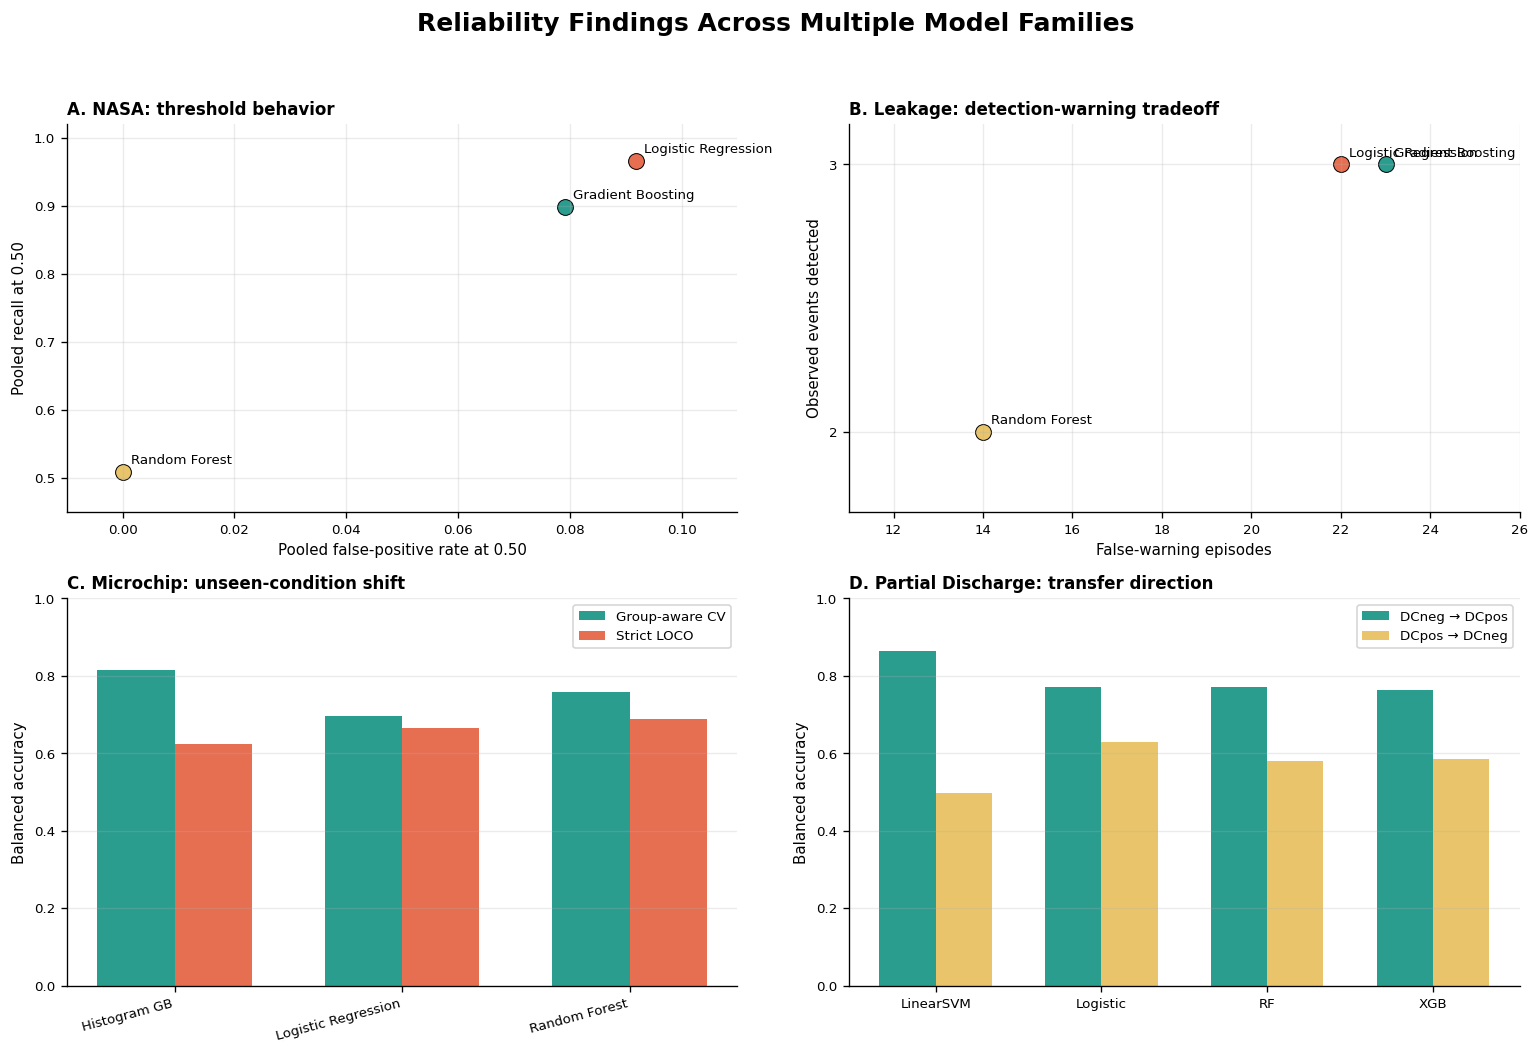

CROSS-DATASET MULTI-MODEL FIGURE

Figure directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Cross_Dataset_Reliability_Clean_Final/multi_model_extension/figures

Generated and verified files:
✓ 01_cross_dataset_multimodel_reliability.png          340,342 bytes
✓ 01_cross_dataset_multimodel_reliability.pdf          33,611 bytes

✓ NASA warning-threshold behavior shown across models.
✓ Leakage event detection and false warnings shown together.
✓ Microchip GroupCV and strict LOCO performance compared.
✓ Partial-discharge transfer directions kept separate.
✓ No unrelated metrics were averaged.
✓ No models were retrained.


In [40]:
# ============================================================
# CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION
# CELL 7: FOUR-PANEL MULTI-MODEL FIGURE
#
# PURPOSE:
# Visualize how model choice affects the reliability evidence
# for NASA, Leakage Current, Microchip, and Partial Discharge.
#
# FIGURE PANELS:
# A. NASA — recall versus false-positive rate
# B. Leakage — events detected versus false-warning episodes
# C. Microchip — GroupCV versus strict LOCO performance
# D. Partial Discharge — transfer in both polarity directions
#
# IMPORTANT:
# - Each panel uses measurements appropriate to its dataset.
# - The panels are not combined into one reliability score.
# - The figure uses results created in Cells 5 and 6.
# - No models are trained in this cell.
# ============================================================


# ============================================================
# STEP 1 — DEFINE CONSISTENT FIGURE STYLING
#
# rcParams controls the appearance of all four panels.
# The settings improve readability in reports, posters, and
# possible conference-paper figures.
# ============================================================

plt.rcParams.update({

    # Resolution used when displaying the figure in Colab.
    "figure.dpi": 120,

    # Higher resolution used for the saved PNG.
    "savefig.dpi": 300,

    # Text sizes.
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Remove unnecessary top and right borders.
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Use consistent colors for different model families.
model_colors = [
    "#2A9D8F",
    "#E76F51",
    "#E9C46A",
    "#457B9D"
]


# ============================================================
# STEP 2 — CREATE THE 2 × 2 FIGURE LAYOUT
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9)
)

# Add one overall title above all four panels.
fig.suptitle(
    "Reliability Findings Across Multiple Model Families",
    fontsize=15,
    fontweight="bold",
    y=0.99
)


# ============================================================
# STEP 3 — PANEL A: NASA THRESHOLD BEHAVIOR
#
# Each point represents one model at the same 0.50 threshold.
#
# Horizontal axis:
# False-positive rate — how often a negative case incorrectly
# produced a warning.
#
# Vertical axis:
# Recall — how many positive warning cases were detected.
#
# A desirable warning model would generally appear toward the
# upper-left: high recall and low false-positive rate.
# ============================================================

ax = axes[0, 0]

# Plot one point for every NASA model.
for index, row in nasa_model_evidence.iterrows():

    ax.scatter(
        row["pooled_fpr_at_050"],
        row["pooled_recall_at_050"],
        s=90,
        color=model_colors[index],
        edgecolor="black",
        linewidth=0.6
    )

    # Label the point with the model name.
    ax.annotate(
        row["model"],
        (
            row["pooled_fpr_at_050"],
            row["pooled_recall_at_050"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Use fixed limits so small but important differences are visible.
ax.set_xlim(-0.01, 0.11)
ax.set_ylim(0.45, 1.02)

ax.set_xlabel(
    "Pooled false-positive rate at 0.50"
)

ax.set_ylabel(
    "Pooled recall at 0.50"
)

ax.set_title(
    "A. NASA: threshold behavior",
    loc="left",
    fontweight="bold"
)

ax.grid(alpha=0.25)


# ============================================================
# STEP 4 — PANEL B: LEAKAGE EVENT-WARNING TRADEOFF
#
# Each point represents one model.
#
# Horizontal axis:
# Total false-warning episodes.
#
# Vertical axis:
# Number of the three held-out events detected.
#
# This panel shows why event detection and false-warning burden
# must be considered together.
# ============================================================

ax = axes[0, 1]

# Plot one point for each Leakage Current model.
for index, row in leakage_model_evidence.iterrows():

    ax.scatter(
        row["total_false_warning_episodes"],
        row["events_detected"],
        s=90,
        color=model_colors[index],
        edgecolor="black",
        linewidth=0.6
    )

    # Label each point with its model family.
    ax.annotate(
        row["model"],
        (
            row["total_false_warning_episodes"],
            row["events_detected"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Adapt the horizontal range to the observed false-warning
# episode counts while preventing the axis from starting below 0.
ax.set_xlim(
    max(
        0,
        leakage_episodes_min - 3
    ),
    leakage_episodes_max + 3
)

# The only observed event totals are two and three.
ax.set_ylim(1.7, 3.15)
ax.set_yticks([2, 3])

ax.set_xlabel(
    "False-warning episodes"
)

ax.set_ylabel(
    "Observed events detected"
)

ax.set_title(
    "B. Leakage: detection-warning tradeoff",
    loc="left",
    fontweight="bold"
)

ax.grid(alpha=0.25)


# ============================================================
# STEP 5 — PANEL C: MICROCHIP CONDITION SHIFT
#
# For each model, two bars are shown:
#
# - Group-aware CV:
#   Performance when all operating-condition types are
#   represented during model development.
#
# - Strict LOCO:
#   Performance when one complete operating condition is unseen.
#
# A lower LOCO bar indicates reduced generalization when the
# electrical condition changes.
# ============================================================

ax = axes[1, 0]

# Create one x-axis position for each model.
x = np.arange(
    len(microchip_model_evidence)
)

# Width of each bar.
width = 0.34

# Draw the GroupCV bar slightly left of each model position.
ax.bar(
    x - width / 2,
    microchip_model_evidence[
        "groupcv_balanced_accuracy"
    ],
    width,
    label="Group-aware CV",
    color="#2A9D8F"
)

# Draw the strict LOCO bar slightly right of each position.
ax.bar(
    x + width / 2,
    microchip_model_evidence[
        "loco_balanced_accuracy"
    ],
    width,
    label="Strict LOCO",
    color="#E76F51"
)

# Shorten the longest model name so the axis remains readable.
microchip_short_labels = [
    model_name.replace(
        "Histogram Gradient Boosting",
        "Histogram GB"
    )
    for model_name
    in microchip_model_evidence["model"]
]

ax.set_xticks(x)

ax.set_xticklabels(
    microchip_short_labels,
    rotation=15,
    ha="right"
)

# Balanced accuracy ranges from 0 to 1.
ax.set_ylim(0, 1.0)

ax.set_ylabel(
    "Balanced accuracy"
)

ax.set_title(
    "C. Microchip: unseen-condition shift",
    loc="left",
    fontweight="bold"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)


# ============================================================
# STEP 6 — PANEL D: PARTIAL-DISCHARGE TRANSFER DIRECTION
#
# For each model, compare:
#
# - Training on DC-negative and testing on DC-positive
# - Training on DC-positive and testing on DC-negative
#
# Different bar heights show that transfer reliability depends
# on direction even though the physical feature relationships
# were consistent across polarity.
# ============================================================

ax = axes[1, 1]

# Create one x-axis position for each PD model.
x = np.arange(
    len(pd_model_evidence)
)

# Draw forward-transfer balanced accuracy.
ax.bar(
    x - width / 2,
    pd_model_evidence[
        "DCneg → DCpos"
    ],
    width,
    label="DCneg → DCpos",
    color="#2A9D8F"
)

# Draw reverse-transfer balanced accuracy.
ax.bar(
    x + width / 2,
    pd_model_evidence[
        "DCpos → DCneg"
    ],
    width,
    label="DCpos → DCneg",
    color="#E9C46A"
)

ax.set_xticks(x)

ax.set_xticklabels(
    pd_model_evidence["model"]
)

# Balanced accuracy ranges from 0 to 1.
ax.set_ylim(0, 1.0)

ax.set_ylabel(
    "Balanced accuracy"
)

ax.set_title(
    "D. Partial Discharge: transfer direction",
    loc="left",
    fontweight="bold"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)


# ============================================================
# STEP 7 — ADJUST THE FIGURE LAYOUT
#
# Leave space at the top for the overall figure title.
# ============================================================

plt.tight_layout(
    rect=[0, 0.02, 1, 0.96]
)


# ============================================================
# STEP 8 — DEFINE THE OUTPUT FILES
#
# PNG is useful for posters and presentations.
# PDF preserves vector quality for papers and printing.
# ============================================================

figure_png = (
    MULTIMODEL_FIGURE_DIR /
    "01_cross_dataset_multimodel_reliability.png"
)

figure_pdf = (
    MULTIMODEL_FIGURE_DIR /
    "01_cross_dataset_multimodel_reliability.pdf"
)


# ============================================================
# STEP 9 — SAVE BOTH FIGURE FORMATS
# ============================================================

fig.savefig(
    figure_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# STEP 10 — DISPLAY AND CLOSE THE FIGURE
#
# Closing the figure after displaying it releases notebook
# memory and prevents duplicate output in later cells.
# ============================================================

plt.show()
plt.close(fig)


# ============================================================
# STEP 11 — VERIFY THE SAVED FIGURES
#
# Confirm that both files exist and contain data.
# ============================================================

assert figure_png.exists(), (
    f"PNG figure was not saved:\n{figure_png}"
)

assert figure_pdf.exists(), (
    f"PDF figure was not saved:\n{figure_pdf}"
)

assert figure_png.stat().st_size > 0, (
    f"PNG figure is empty:\n{figure_png}"
)

assert figure_pdf.stat().st_size > 0, (
    f"PDF figure is empty:\n{figure_pdf}"
)


# ============================================================
# FINAL OUTPUT
# ============================================================

print("=" * 110)
print("CROSS-DATASET MULTI-MODEL FIGURE")
print("=" * 110)

print(f"\nFigure directory:\n{MULTIMODEL_FIGURE_DIR}")

print("\nGenerated and verified files:")
print(
    f"✓ {figure_png.name:<52} "
    f"{figure_png.stat().st_size:,} bytes"
)
print(
    f"✓ {figure_pdf.name:<52} "
    f"{figure_pdf.stat().st_size:,} bytes"
)

print("\n✓ NASA warning-threshold behavior shown across models.")
print("✓ Leakage event detection and false warnings shown together.")
print("✓ Microchip GroupCV and strict LOCO performance compared.")
print("✓ Partial-discharge transfer directions kept separate.")
print("✓ No unrelated metrics were averaged.")
print("✓ No models were retrained.")

##**8.Cross DS - Export and Final Verification**

In [41]:
# ============================================================
# CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION
# CELL 8: CLEAN EXPORT AND FINAL VERIFICATION
#
# PURPOSE:
# Export the multi-model evidence tables, figure, metadata, and
# text summary, then reload and verify the saved outputs.
#
# IMPORTANT:
# - This extension is saved in a separate subdirectory.
# - It does not overwrite the frozen primary synthesis.
# - No models are trained in this cell.
# ============================================================


# ============================================================
# STEP 1 — DEFINE THE TABLES TO EXPORT
#
# Each DataFrame is assigned a numbered filename so the exported
# research evidence remains organized and reproducible.
# ============================================================

export_tables = {

    # NASA comparison of ranking and threshold behavior.
    "01_nasa_model_evidence.csv":
        nasa_model_evidence,

    # Leakage comparison of window and event-level behavior.
    "02_leakage_model_evidence.csv":
        leakage_model_evidence,

    # Microchip GroupCV versus strict LOCO comparison.
    "03_microchip_model_evidence.csv":
        microchip_model_evidence,

    # Partial-Discharge directional transfer comparison.
    "04_partial_discharge_model_evidence.csv":
        pd_model_evidence,

    # Final findings from all four dataset-specific comparisons.
    "05_cross_dataset_multimodel_findings.csv":
        multimodel_findings
}


# ============================================================
# STEP 2 — EXPORT THE TABLES
#
# index=False prevents pandas row numbers from being written as
# an unnecessary extra CSV column.
# ============================================================

for filename, dataframe in export_tables.items():

    dataframe.to_csv(
        MULTIMODEL_SYNTHESIS_DIR /
        filename,
        index=False
    )


# ============================================================
# STEP 3 — CREATE REPRODUCIBILITY METADATA
#
# Metadata records:
# - The project title and research question
# - The purpose of the analysis
# - How many models were evaluated
# - The logical checks supported by the results
# - The boundaries on what the study can claim
#
# This makes the exported results easier to interpret later.
# ============================================================

multimodel_metadata = {

    "project_title":
        PROJECT_TITLE,

    "research_question":
        RESEARCH_QUESTION,

    "analysis":
        "Cross-dataset multi-model reliability sensitivity",

    # Record when this export was created using UTC.
    "created_utc":
        datetime.now(timezone.utc).isoformat(),

    # Number of model families evaluated within each dataset.
    "models_per_dataset": {
        "NASA Battery": 3,
        "Leakage Current": 3,
        "Microchip Arc Fault": 3,
        "Partial Discharge": 4
    },

    # Record the main Boolean checks established in Cell 6.
    "key_checks": {

        "nasa_all_mean_auroc_above_0_98":
            True,

        "microchip_all_balanced_accuracy_declined":
            micro_all_ba_declined,

        "microchip_all_macro_f1_declined":
            micro_all_f1_declined,

        "microchip_all_brier_worsened":
            micro_all_brier_worsened,

        "microchip_all_logloss_worsened":
            micro_all_logloss_worsened,

        "microchip_ece_direction_mixed":
            micro_ece_mixed,

        "pd_forward_transfer_higher_for_all_models":
            pd_all_forward_higher
    },

    # These statements protect against conclusions that extend
    # beyond what the datasets actually demonstrate.
    "claim_boundaries": [
        "The models do not represent every AI algorithm.",
        "The four datasets are complementary case studies.",
        "The datasets are not stages of one fire pathway.",
        "Leakage event counts are descriptive.",
        "No universal reliability score was created.",
        "No direct fire-prediction claim is made."
    ],

    # Record where the Partial-Discharge results were obtained.
    "partial_discharge_source":
        pd_source_description,

    # Confirm that this synthesis only used existing results.
    "models_retrained_in_this_cell":
        False,

    # Confirm that the original synthesis was protected.
    "original_synthesis_files_modified":
        False
}


# ============================================================
# STEP 4 — EXPORT THE METADATA AS JSON
# ============================================================

metadata_path = (
    MULTIMODEL_SYNTHESIS_DIR /
    "06_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        multimodel_metadata,
        file,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# STEP 5 — CREATE A READABLE TEXT SUMMARY
#
# This summary presents the most important evidence without
# requiring the reader to open every CSV file.
#
# The numerical ranges are inserted from the values calculated
# in Cell 6 rather than typed manually.
# ============================================================

summary_text = f"""
CROSS-DATASET MULTI-MODEL RELIABILITY EXTENSION
================================================

PROJECT TITLE
{PROJECT_TITLE}

RESEARCH QUESTION
{RESEARCH_QUESTION}

MODELS EVALUATED
- NASA Battery: 3
- Leakage Current: 3
- Microchip Arc Fault: 3
- Partial Discharge: 4

NASA BATTERY
All three models achieved mean AUROC above 0.98.
Pooled recall at threshold 0.50 ranged from
{nasa_recall_min:.4f} to {nasa_recall_max:.4f}.
Pooled FPR ranged from
{nasa_fpr_min:.4f} to {nasa_fpr_max:.4f}.
Similar ranking performance did not produce similar warning behavior.

LEAKAGE CURRENT
Observed events detected ranged from
{leakage_events_min}/3 to {leakage_events_max}/3.
False-warning episodes ranged from
{leakage_episodes_min} to {leakage_episodes_max}.
Event detection and false-warning burden depended on model family.
Only three events were evaluated, so these results are descriptive.

MICROCHIP ARC FAULT
Balanced accuracy and macro-F1 declined under strict LOCO for all
three models. Brier score and log loss worsened for all three.
ECE changed in different directions across models.

PARTIAL DISCHARGE
DCneg-to-DCpos balanced accuracy was higher than DCpos-to-DCneg
balanced accuracy for all four models. Transfer asymmetry therefore
persisted across the evaluated model families.

FINAL CONCLUSION
{multimodel_conclusion}

LIMITATION
{multimodel_limitation}
""".strip()


# ============================================================
# STEP 6 — EXPORT THE TEXT SUMMARY
# ============================================================

summary_path = (
    MULTIMODEL_SYNTHESIS_DIR /
    "07_summary.txt"
)

summary_path.write_text(
    summary_text,
    encoding="utf-8"
)


# ============================================================
# STEP 7 — CREATE A COMPLETE OUTPUT MANIFEST
#
# The list includes:
# - Five evidence tables
# - One metadata file
# - One text summary
# - PNG and PDF versions of the figure from Cell 7
# ============================================================

expected_outputs = [

    # Add all exported CSV paths.
    MULTIMODEL_SYNTHESIS_DIR /
    filename
    for filename in export_tables

] + [

    metadata_path,
    summary_path,
    figure_png,
    figure_pdf
]


# ============================================================
# STEP 8 — VERIFY THAT EVERY OUTPUT EXISTS
#
# A file must:
# - Exist at the expected location
# - Have a size greater than zero bytes
#
# The cell stops if any expected output is missing or empty.
# ============================================================

for file_path in expected_outputs:

    assert file_path.exists(), (
        f"Missing output:\n{file_path}"
    )

    assert file_path.stat().st_size > 0, (
        f"Empty output:\n{file_path}"
    )


# ============================================================
# STEP 9 — RELOAD IMPORTANT EXPORTED FILES
#
# Reloading verifies that the files can actually be read after
# export. This is stronger than checking only that they exist.
# ============================================================

verified_findings = pd.read_csv(
    MULTIMODEL_SYNTHESIS_DIR /
    "05_cross_dataset_multimodel_findings.csv"
)

with open(
    metadata_path,
    "r",
    encoding="utf-8"
) as file:

    verified_metadata = json.load(file)

verified_summary = summary_path.read_text(
    encoding="utf-8"
)


# ============================================================
# STEP 10 — VERIFY THE RELOADED CONTENT
# ============================================================

# The final findings table must contain one row per dataset.
assert len(verified_findings) == 4

# Confirm the expected number of models for the four datasets,
# in the order used to construct the findings table.
assert (
    verified_findings[
        "models_evaluated"
    ].tolist()
    == [3, 3, 3, 4]
)

# Confirm that the exported metadata preserved the Microchip
# balanced-accuracy finding.
assert verified_metadata[
    "key_checks"
][
    "microchip_all_balanced_accuracy_declined"
] is True

# Confirm that Brier score worsened for all Microchip models.
assert verified_metadata[
    "key_checks"
][
    "microchip_all_brier_worsened"
] is True

# Confirm that Partial-Discharge transfer asymmetry appeared
# across all four models.
assert verified_metadata[
    "key_checks"
][
    "pd_forward_transfer_higher_for_all_models"
] is True

# Confirm that the text summary contains the final conclusion.
assert (
    "FINAL CONCLUSION"
    in verified_summary
)


# ============================================================
# STEP 11 — PRINT THE EXPORT REPORT
# ============================================================

print()
print("=" * 110)
print("MULTI-MODEL SYNTHESIS EXPORT")
print("=" * 110)

print()
print("Export directory:")
print(MULTIMODEL_SYNTHESIS_DIR)

print()
print("Verified files:")

# Display the filename and byte size of every verified output.
for file_path in expected_outputs:

    print(
        f"✓ {file_path.name:<55} "
        f"{file_path.stat().st_size:,} bytes"
    )


# ============================================================
# STEP 12 — PRINT THE FINAL EVIDENCE
# ============================================================

print()
print("Final evidence:")

# NASA: show the range of warning recall across models.
print(
    f"✓ NASA pooled recall range at 0.50: "
    f"{nasa_recall_min:.4f}–"
    f"{nasa_recall_max:.4f}"
)

# NASA: show the range of false-positive rates.
print(
    f"✓ NASA pooled FPR range at 0.50: "
    f"{nasa_fpr_min:.4f}–"
    f"{nasa_fpr_max:.4f}"
)

# Leakage: show the range of held-out event detections.
print(
    f"✓ Leakage event detection range: "
    f"{leakage_events_min}/3–"
    f"{leakage_events_max}/3"
)

# Leakage: show the range of false-warning episodes.
print(
    f"✓ Leakage false-warning episode range: "
    f"{leakage_episodes_min}–"
    f"{leakage_episodes_max}"
)

# Microchip: summarize performance under condition shift.
print(
    "✓ Microchip BA and macro-F1 declined "
    "across all three models."
)

# Microchip: summarize probability-quality deterioration.
print(
    "✓ Microchip Brier score and log loss "
    "worsened across all three models."
)

# ECE did not move consistently across model families.
print(
    "✓ Microchip ECE direction was model-dependent."
)

# Partial Discharge: summarize directional transfer.
print(
    "✓ Partial-discharge transfer asymmetry "
    "appeared across all four models."
)


# ============================================================
# STEP 13 — PRINT THE FINAL SAFEGUARDS
# ============================================================

print()
print("✓ Partial Discharge results were loaded successfully.")
print("✓ Original synthesis files remain unchanged.")
print("✓ No models were retrained in this cell.")
print("✓ No universal cross-dataset score was created.")
print("✓ No direct fire-prediction claim was made.")


# ============================================================
# FINAL COMPLETION MESSAGE
# ============================================================

print()
print(
    "✓ CROSS-DATASET MULTI-MODEL SYNTHESIS "
    "COMPLETE / EXPORTED / VERIFIED"
)


MULTI-MODEL SYNTHESIS EXPORT

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Cross_Dataset_Reliability_Clean_Final/multi_model_extension

Verified files:
✓ 01_nasa_model_evidence.csv                              1,306 bytes
✓ 02_leakage_model_evidence.csv                           1,367 bytes
✓ 03_microchip_model_evidence.csv                         1,162 bytes
✓ 04_partial_discharge_model_evidence.csv                 261 bytes
✓ 05_cross_dataset_multimodel_findings.csv                1,191 bytes
✓ 06_metadata.json                                        1,559 bytes
✓ 07_summary.txt                                          2,763 bytes
✓ 01_cross_dataset_multimodel_reliability.png             340,342 bytes
✓ 01_cross_dataset_multimodel_reliability.pdf             33,611 bytes

Final evidence:
✓ NASA pooled recall range at 0.50: 0.5085–0.9661
✓ NASA pooled FPR range at 0.50: 0.0000–0.0918
✓ Leakage event detection range: 2/3–3/3
✓ Leakage false-warning episode r

# F. Microchip Edge-AI deployment

##**1. MC Edge AI - deployment preparation audit**

In [42]:
# ======================================================================================
# PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
# Cell 1 — Microchip deployment preparation audit
# ======================================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 100)
print("PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION")
print("CELL 1 — MICROCHIP DEPLOYMENT PREPARATION AUDIT")
print("=" * 100)

# --------------------------------------------------------------------------------------
# Frozen Dataset #3 location
# --------------------------------------------------------------------------------------

MICROCHIP_DIR = (
    RESULTS_ROOT / "Microchip_ArcFault_FinalAnalysis"
)

FEATURE_FILE = (
    MICROCHIP_DIR / "02_feature_dataset.csv"
)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Frozen feature dataset not found:\n{FEATURE_FILE}"
    )

# --------------------------------------------------------------------------------------
# Load frozen feature dataset
# --------------------------------------------------------------------------------------

edge_df = pd.read_csv(FEATURE_FILE)

print("\nFrozen feature dataset:")
print(FEATURE_FILE)

print("\nShape:")
print(edge_df.shape)

print("\nColumns:")
for i, col in enumerate(edge_df.columns, 1):
    print(f"{i:2d}. {col}")

print("\nFirst 3 rows:")
print(edge_df.head(3).to_string())

# --------------------------------------------------------------------------------------
# Basic integrity audit
# --------------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("DATA INTEGRITY")
print("-" * 100)

print("Total rows:", len(edge_df))
print("Duplicate rows:", edge_df.duplicated().sum())
print("Total missing values:", int(edge_df.isna().sum().sum()))

# --------------------------------------------------------------------------------------
# Identify likely metadata / target columns
#
# IMPORTANT:
# We inspect rather than assuming the exact schema from memory.
# --------------------------------------------------------------------------------------

possible_target_columns = [
    c for c in edge_df.columns
    if c.lower() in {
        "label",
        "target",
        "class",
        "y"
    }
]

possible_condition_columns = [
    c for c in edge_df.columns
    if any(
        term in c.lower()
        for term in [
            "condition",
            "source",
            "file",
            "group",
            "record"
        ]
    )
]

print("\nPossible target columns:")
print(possible_target_columns)

print("\nPossible condition/group metadata columns:")
print(possible_condition_columns)

# --------------------------------------------------------------------------------------
# Column types
# --------------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("COLUMN TYPES")
print("-" * 100)

dtype_table = pd.DataFrame({
    "column": edge_df.columns,
    "dtype": [str(edge_df[c].dtype) for c in edge_df.columns],
    "unique_values": [edge_df[c].nunique(dropna=False) for c in edge_df.columns]
})

print(dtype_table.to_string(index=False))

# --------------------------------------------------------------------------------------
# Numeric columns — possible feature candidates
# --------------------------------------------------------------------------------------

numeric_columns = edge_df.select_dtypes(
    include=[np.number]
).columns.tolist()

print("\n" + "-" * 100)
print("NUMERIC COLUMNS")
print("-" * 100)

print("Number of numeric columns:", len(numeric_columns))

for col in numeric_columns:
    print(col)

# --------------------------------------------------------------------------------------
# Known Dataset #3 scientific constraints
# --------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("DEPLOYMENT EXPERIMENT CONSTRAINTS")
print("=" * 100)

print(
    "1. Dataset #3 primary analysis remains FROZEN."
)

print(
    "2. The ESP32 experiment will be a separate engineering-validation analysis."
)

print(
    "3. No existing Dataset #3 results will be overwritten or replaced."
)

print(
    "4. The edge model must be evaluated using held-out operating conditions, "
    "not a random row split."
)

print(
    "5. The ESP32 will initially process prerecorded/public-dataset-derived "
    "inputs only."
)

print(
    "6. No live electrical fault, arc, high-voltage, overheating, or fire "
    "generation is required."
)

print(
    "7. Model complexity will be chosen for embedded feasibility rather than "
    "maximum desktop accuracy."
)

print("\n" + "=" * 100)
print("CELL 1 COMPLETE — AUDIT ONLY; NO MODEL TRAINED")
print("=" * 100)

PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
CELL 1 — MICROCHIP DEPLOYMENT PREPARATION AUDIT

Frozen feature dataset:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Microchip_ArcFault_FinalAnalysis/02_feature_dataset.csv

Shape:
(81585, 35)

Columns:
 1. dataset
 2. arc_type
 3. load_condition
 4. window_id_within_dataset
 5. run_id
 6. group_id
 7. label
 8. start_index
 9. end_index
10. start_time
11. end_time
12. label_name
13. mean
14. abs_mean
15. rms
16. std
17. min
18. max
19. peak_to_peak
20. crest_factor
21. zero_crossing_rate
22. mean_abs_diff
23. max_abs_diff
24. skewness
25. kurtosis
26. spectral_centroid
27. spectral_spread
28. spectral_entropy
29. dominant_frequency
30. dominant_power_fraction
31. median_frequency
32. band_0_500
33. band_500_2000
34. band_2000_4000
35. band_4000_8000

First 3 rows:
                             dataset  arc_type load_condition  window_id_within_dataset  run_id                                 group_id  label  start_index  end_ind

##**2. MC Edge AI - Compact model under strict unseen-condition testing**

In [43]:
# ======================================================================================
# PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
# Cell 2 — Compact time-domain model under strict LOCO evaluation
# ======================================================================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix
)

print("=" * 100)
print("PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION")
print("CELL 2 — COMPACT EDGE MODEL: STRICT UNSEEN-CONDITION EVALUATION")
print("=" * 100)

# --------------------------------------------------------------------------------------
# 13 time-domain features from the frozen Dataset #3 feature representation
# --------------------------------------------------------------------------------------

EDGE_FEATURES = [
    "mean",
    "abs_mean",
    "rms",
    "std",
    "min",
    "max",
    "peak_to_peak",
    "crest_factor",
    "zero_crossing_rate",
    "mean_abs_diff",
    "max_abs_diff",
    "skewness",
    "kurtosis"
]

TARGET = "label"

# Operating condition:
# parallel_basic, parallel_load, series_basic, series_load
edge_df = edge_df.copy()

edge_df["operating_condition"] = (
    edge_df["arc_type"].astype(str)
    + "_"
    + edge_df["load_condition"].astype(str)
)

conditions = sorted(
    edge_df["operating_condition"].unique()
)

print("\nEdge features:", len(EDGE_FEATURES))
for i, feature in enumerate(EDGE_FEATURES, 1):
    print(f"{i:2d}. {feature}")

print("\nOperating conditions:")
for condition in conditions:
    n = (
        edge_df["operating_condition"]
        .eq(condition)
        .sum()
    )
    print(f"  {condition:<20} {n:,} windows")

print("\nClass labels:")
print(
    edge_df[
        ["label", "label_name"]
    ]
    .drop_duplicates()
    .sort_values("label")
    .to_string(index=False)
)

# --------------------------------------------------------------------------------------
# Strict leave-one-condition-out evaluation
# --------------------------------------------------------------------------------------

fold_results = []
oof_parts = []

for held_out in conditions:

    train_mask = (
        edge_df["operating_condition"] != held_out
    )

    test_mask = (
        edge_df["operating_condition"] == held_out
    )

    X_train = (
        edge_df.loc[train_mask, EDGE_FEATURES]
        .to_numpy(dtype=np.float64)
    )

    y_train = (
        edge_df.loc[train_mask, TARGET]
        .to_numpy()
    )

    X_test = (
        edge_df.loc[test_mask, EDGE_FEATURES]
        .to_numpy(dtype=np.float64)
    )

    y_test = (
        edge_df.loc[test_mask, TARGET]
        .to_numpy()
    )

    # ------------------------------------------------------------------
    # IMPORTANT:
    # Fit scaler ONLY on training conditions.
    # ------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    # ------------------------------------------------------------------
    # Compact ESP32-suitable classifier
    # ------------------------------------------------------------------

    model = LogisticRegression(
        class_weight="balanced",
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    y_pred = model.predict(
        X_test_scaled
    )

    y_prob = model.predict_proba(
        X_test_scaled
    )

    # ------------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        y_pred
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    recalls = recall_score(
        y_test,
        y_pred,
        labels=[-1, 0, 1],
        average=None,
        zero_division=0
    )

    fold_results.append({
        "held_out_condition": held_out,
        "train_n": len(y_train),
        "test_n": len(y_test),
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "macro_f1": macro_f1,
        "normal_recall": recalls[0],
        "transient_recall": recalls[1],
        "arc_recall": recalls[2]
    })

    # ------------------------------------------------------------------
    # Save OOF predictions for later deployment preparation
    # ------------------------------------------------------------------

    fold_oof = edge_df.loc[
        test_mask,
        [
            "dataset",
            "arc_type",
            "load_condition",
            "group_id",
            "label",
            "label_name",
            "operating_condition"
        ]
    ].copy()

    fold_oof["predicted_label"] = y_pred

    # Model.classes_ determines probability-column order
    for class_index, class_label in enumerate(
        model.classes_
    ):
        fold_oof[
            f"prob_class_{class_label}"
        ] = y_prob[:, class_index]

    oof_parts.append(
        fold_oof
    )

# --------------------------------------------------------------------------------------
# Final LOCO tables
# --------------------------------------------------------------------------------------

edge_loco_results = pd.DataFrame(
    fold_results
)

edge_oof_predictions = pd.concat(
    oof_parts,
    ignore_index=True
)

print("\n" + "-" * 100)
print("STRICT LOCO RESULTS")
print("-" * 100)

print(
    edge_loco_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# --------------------------------------------------------------------------------------
# Mean across held-out operating conditions
# --------------------------------------------------------------------------------------

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "normal_recall",
    "transient_recall",
    "arc_recall"
]

edge_loco_mean = (
    edge_loco_results[
        metric_columns
    ]
    .mean()
)

edge_loco_std = (
    edge_loco_results[
        metric_columns
    ]
    .std()
)

summary = pd.DataFrame({
    "metric": metric_columns,
    "mean_across_conditions":
        edge_loco_mean.values,
    "std_across_conditions":
        edge_loco_std.values
})

print("\n" + "-" * 100)
print("MEAN ± SD ACROSS HELD-OUT CONDITIONS")
print("-" * 100)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# --------------------------------------------------------------------------------------
# Overall OOF confusion matrix
# --------------------------------------------------------------------------------------

cm = confusion_matrix(
    edge_oof_predictions["label"],
    edge_oof_predictions["predicted_label"],
    labels=[-1, 0, 1]
)

print("\nOOF confusion matrix:")
print("Rows = true class; columns = predicted class")
print("Class order = [-1 normal, 0 transient, 1 arc]")
print(cm)

print("\n" + "=" * 100)
print("SCIENTIFIC SAFEGUARDS")
print("=" * 100)

print("✓ Compact model uses only 13 time-domain signal features.")
print("✓ No metadata, timestamps, indices, or labels are used as predictors.")
print("✓ Each operating condition is completely held out once.")
print("✓ Scaling is fitted on training conditions only.")
print("✓ Dataset #3 frozen primary analysis was not modified.")
print("✓ This model is evaluated for Edge-AI deployment feasibility.")
print("✓ No ESP32 deployment claim is made yet.")

print("\n" + "=" * 100)
print("CELL 2 COMPLETE")
print("=" * 100)

PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
CELL 2 — COMPACT EDGE MODEL: STRICT UNSEEN-CONDITION EVALUATION

Edge features: 13
 1. mean
 2. abs_mean
 3. rms
 4. std
 5. min
 6. max
 7. peak_to_peak
 8. crest_factor
 9. zero_crossing_rate
10. mean_abs_diff
11. max_abs_diff
12. skewness
13. kurtosis

Operating conditions:
  parallel_basic       19,416 windows
  parallel_load        20,141 windows
  series_basic         16,714 windows
  series_load          25,314 windows

Class labels:
 label label_name
    -1     normal
     0  transient
     1        arc

----------------------------------------------------------------------------------------------------
STRICT LOCO RESULTS
----------------------------------------------------------------------------------------------------
held_out_condition  train_n  test_n  accuracy  balanced_accuracy  macro_f1  normal_recall  transient_recall  arc_recall
    parallel_basic    62169   19416    0.8858             0.7124    0.7141         0.9531   

##**3. MC Edge AI - Feature Complexity vs Reliability**

In [44]:
# ======================================================================================
# PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
# Cell 3 — Feature complexity vs unseen-condition reliability
# FINAL CORRECTED VERSION
# ======================================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

import pandas as pd
import numpy as np

print("=" * 100)
print("PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION")
print("CELL 3 — FEATURE COMPLEXITY VS UNSEEN-CONDITION RELIABILITY")
print("=" * 100)

# --------------------------------------------------------------------------------------
# Predetermined feature sets
#
# These sets are defined before comparison.
# We are NOT searching many combinations for the best-performing subset.
# --------------------------------------------------------------------------------------

FEATURE_SETS = {

    "13_features": [
        "mean",
        "abs_mean",
        "rms",
        "std",
        "min",
        "max",
        "peak_to_peak",
        "crest_factor",
        "zero_crossing_rate",
        "mean_abs_diff",
        "max_abs_diff",
        "skewness",
        "kurtosis"
    ],

    "8_features": [
        "rms",
        "std",
        "peak_to_peak",
        "crest_factor",
        "zero_crossing_rate",
        "mean_abs_diff",
        "max_abs_diff",
        "kurtosis"
    ],

    "6_features": [
        "rms",
        "peak_to_peak",
        "zero_crossing_rate",
        "mean_abs_diff",
        "max_abs_diff",
        "kurtosis"
    ]
}

# --------------------------------------------------------------------------------------
# Verify required columns
# --------------------------------------------------------------------------------------

required_features = sorted(
    set(
        feature
        for feature_list in FEATURE_SETS.values()
        for feature in feature_list
    )
)

missing_features = [
    feature
    for feature in required_features
    if feature not in edge_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

if "operating_condition" not in edge_df.columns:
    edge_df["operating_condition"] = (
        edge_df["arc_type"].astype(str)
        + "_"
        + edge_df["load_condition"].astype(str)
    )

conditions = sorted(
    edge_df["operating_condition"].unique()
)

TARGET = "label"

print("\nPredetermined feature sets:")

for name, features in FEATURE_SETS.items():
    print(
        f"  {name:<12} "
        f"{len(features):>2} features: "
        + ", ".join(features)
    )

print("\nHeld-out operating conditions:")

for condition in conditions:
    print(" ", condition)

# ======================================================================================
# SAME STRICT LOCO PROTOCOL FOR EVERY FEATURE SET
# ======================================================================================

all_results = []

for set_name, features in FEATURE_SETS.items():

    print("\n" + "-" * 100)
    print(f"Testing {set_name}")
    print("-" * 100)

    for held_out in conditions:

        # ------------------------------------------------------------------
        # Entire operating condition held out
        # ------------------------------------------------------------------

        train_mask = (
            edge_df["operating_condition"] != held_out
        )

        test_mask = (
            edge_df["operating_condition"] == held_out
        )

        X_train = edge_df.loc[
            train_mask,
            features
        ].to_numpy(dtype=np.float64)

        y_train = edge_df.loc[
            train_mask,
            TARGET
        ].to_numpy()

        X_test = edge_df.loc[
            test_mask,
            features
        ].to_numpy(dtype=np.float64)

        y_test = edge_df.loc[
            test_mask,
            TARGET
        ].to_numpy()

        # ------------------------------------------------------------------
        # Fit preprocessing ONLY on training conditions
        # ------------------------------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train
        )

        X_test_scaled = scaler.transform(
            X_test
        )

        # ------------------------------------------------------------------
        # Same compact classifier for every feature representation
        # ------------------------------------------------------------------

        model = LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=2000,
            random_state=42
        )

        model.fit(
            X_train_scaled,
            y_train
        )

        y_pred = model.predict(
            X_test_scaled
        )

        # ------------------------------------------------------------------
        # Metrics
        # ------------------------------------------------------------------

        recalls = recall_score(
            y_test,
            y_pred,
            labels=[-1, 0, 1],
            average=None,
            zero_division=0
        )

        result = {

            "feature_set":
                set_name,

            "n_features":
                len(features),

            "held_out_condition":
                held_out,

            "train_n":
                len(y_train),

            "test_n":
                len(y_test),

            "accuracy":
                accuracy_score(
                    y_test,
                    y_pred
                ),

            "balanced_accuracy":
                balanced_accuracy_score(
                    y_test,
                    y_pred
                ),

            "macro_f1":
                f1_score(
                    y_test,
                    y_pred,
                    average="macro"
                ),

            "normal_recall":
                recalls[0],

            "transient_recall":
                recalls[1],

            "arc_recall":
                recalls[2]
        }

        all_results.append(result)

        print(
            f"{held_out:<20} "
            f"BA={result['balanced_accuracy']:.4f}  "
            f"F1={result['macro_f1']:.4f}"
        )

# ======================================================================================
# FOLD-LEVEL RESULTS
# ======================================================================================

edge_feature_ablation = pd.DataFrame(
    all_results
)

print("\n" + "=" * 100)
print("STRICT LOCO FOLD-LEVEL RESULTS")
print("=" * 100)

print(
    edge_feature_ablation.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ======================================================================================
# MEAN ± SD ACROSS HELD-OUT CONDITIONS
# ======================================================================================

metrics = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "normal_recall",
    "transient_recall",
    "arc_recall"
]

edge_feature_summary = (
    edge_feature_ablation
    .groupby(
        ["feature_set", "n_features"]
    )[metrics]
    .agg(["mean", "std"])
    .reset_index()
)

# --------------------------------------------------------------------------------------
# Correctly flatten pandas MultiIndex columns
# --------------------------------------------------------------------------------------

edge_feature_summary.columns = [
    col[0]
    if col[1] == ""
    else f"{col[0]}_{col[1]}"
    for col in edge_feature_summary.columns
]

edge_feature_summary = (
    edge_feature_summary
    .sort_values(
        "n_features",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("FEATURE COMPLEXITY SUMMARY")
print("=" * 100)

print(
    edge_feature_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ======================================================================================
# COMPACT DEPLOYMENT COMPARISON
# ======================================================================================

compact_comparison = (
    edge_feature_summary[
        [
            "feature_set",
            "n_features",
            "balanced_accuracy_mean",
            "macro_f1_mean",
            "transient_recall_mean",
            "arc_recall_mean"
        ]
    ]
    .copy()
)

compact_comparison.columns = [
    "feature_set",
    "n_features",
    "mean_balanced_accuracy",
    "mean_macro_f1",
    "mean_transient_recall",
    "mean_arc_recall"
]

print("\n" + "=" * 100)
print("EDGE DEPLOYMENT COMPARISON")
print("=" * 100)

print(
    compact_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ======================================================================================
# PRE-SPECIFIED COMPARISON TO FULL 13-FEATURE REPRESENTATION
#
# This quantifies the tradeoff but does NOT automatically select a model.
# ======================================================================================

full_row = compact_comparison.loc[
    compact_comparison["feature_set"]
    == "13_features"
].iloc[0]

tradeoff_rows = []

for _, row in compact_comparison.iterrows():

    tradeoff_rows.append({

        "feature_set":
            row["feature_set"],

        "n_features":
            int(row["n_features"]),

        "delta_balanced_accuracy_vs_13":
            row["mean_balanced_accuracy"]
            - full_row["mean_balanced_accuracy"],

        "delta_macro_f1_vs_13":
            row["mean_macro_f1"]
            - full_row["mean_macro_f1"],

        "delta_transient_recall_vs_13":
            row["mean_transient_recall"]
            - full_row["mean_transient_recall"],

        "delta_arc_recall_vs_13":
            row["mean_arc_recall"]
            - full_row["mean_arc_recall"]
    })

edge_complexity_tradeoff = pd.DataFrame(
    tradeoff_rows
)

print("\n" + "=" * 100)
print("CHANGE RELATIVE TO 13-FEATURE MODEL")
print("=" * 100)

print(
    edge_complexity_tradeoff.to_string(
        index=False,
        float_format=lambda x: f"{x:+.4f}"
    )
)

# ======================================================================================
# SCIENTIFIC SAFEGUARDS
# ======================================================================================

print("\n" + "=" * 100)
print("SCIENTIFIC SAFEGUARDS")
print("=" * 100)

print(
    "✓ All feature sets use the same classifier."
)

print(
    "✓ All feature sets use the same strict leave-one-condition-out protocol."
)

print(
    "✓ Scaling is fitted on training conditions only."
)

print(
    "✓ Feature sets were predetermined rather than exhaustively searched."
)

print(
    "✓ No random row split was used."
)

print(
    "✓ Dataset #3 frozen primary analysis was not modified."
)

print(
    "✓ This experiment evaluates the tradeoff between embedded simplicity "
    "and unseen-condition reliability."
)

print(
    "✓ No ESP32 deployment claim is made yet."
)

print("\n" + "=" * 100)
print("CELL 3 COMPLETE")
print("=" * 100)

PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
CELL 3 — FEATURE COMPLEXITY VS UNSEEN-CONDITION RELIABILITY

Predetermined feature sets:
  13_features  13 features: mean, abs_mean, rms, std, min, max, peak_to_peak, crest_factor, zero_crossing_rate, mean_abs_diff, max_abs_diff, skewness, kurtosis
  8_features    8 features: rms, std, peak_to_peak, crest_factor, zero_crossing_rate, mean_abs_diff, max_abs_diff, kurtosis
  6_features    6 features: rms, peak_to_peak, zero_crossing_rate, mean_abs_diff, max_abs_diff, kurtosis

Held-out operating conditions:
  parallel_basic
  parallel_load
  series_basic
  series_load

----------------------------------------------------------------------------------------------------
Testing 13_features
----------------------------------------------------------------------------------------------------
parallel_basic       BA=0.7124  F1=0.7141
parallel_load        BA=0.6721  F1=0.6639
series_basic         BA=0.7291  F1=0.7113
series_load          BA=0.5491 

##**4. MC Edge AI - Final Deployment Model + Fixed ESP32 Test Set**

In [45]:
# ======================================================================================
# PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
# Cell 4 — Final compact deployment model + fixed held-out ESP32 test set
# ======================================================================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix
)

print("=" * 100)
print("PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION")
print("CELL 4 — FINAL COMPACT MODEL + FIXED ESP32 TEST SET")
print("=" * 100)

# ======================================================================================
# FROZEN DEPLOYMENT DESIGN
# ======================================================================================

DEPLOYMENT_FEATURES = [
    "rms",
    "peak_to_peak",
    "zero_crossing_rate",
    "mean_abs_diff",
    "max_abs_diff",
    "kurtosis"
]

DEPLOYMENT_HELD_OUT = "series_load"

TARGET = "label"

print("\nDeployment features:")
for i, feature in enumerate(DEPLOYMENT_FEATURES, 1):
    print(f"{i}. {feature}")

print("\nHeld-out deployment condition:")
print(DEPLOYMENT_HELD_OUT)

# ======================================================================================
# TRAIN / HELD-OUT TEST PARTITION
# ======================================================================================

train_mask = (
    edge_df["operating_condition"]
    != DEPLOYMENT_HELD_OUT
)

test_mask = (
    edge_df["operating_condition"]
    == DEPLOYMENT_HELD_OUT
)

X_train = edge_df.loc[
    train_mask,
    DEPLOYMENT_FEATURES
].to_numpy(dtype=np.float64)

y_train = edge_df.loc[
    train_mask,
    TARGET
].to_numpy()

X_test = edge_df.loc[
    test_mask,
    DEPLOYMENT_FEATURES
].to_numpy(dtype=np.float64)

y_test = edge_df.loc[
    test_mask,
    TARGET
].to_numpy()

print("\nTraining windows:", len(y_train))
print("Held-out windows:", len(y_test))

print("\nTraining conditions:")

for condition in sorted(
    edge_df.loc[
        train_mask,
        "operating_condition"
    ].unique()
):
    print(" ", condition)

# ======================================================================================
# TRAINING-ONLY STANDARDIZATION
# ======================================================================================

deployment_scaler = StandardScaler()

X_train_scaled = deployment_scaler.fit_transform(
    X_train
)

X_test_scaled = deployment_scaler.transform(
    X_test
)

# ======================================================================================
# FINAL COMPACT MODEL
# ======================================================================================

deployment_model = LogisticRegression(
    class_weight="balanced",
    solver="lbfgs",
    max_iter=2000,
    random_state=42
)

deployment_model.fit(
    X_train_scaled,
    y_train
)

desktop_pred = deployment_model.predict(
    X_test_scaled
)

desktop_prob = deployment_model.predict_proba(
    X_test_scaled
)

# ======================================================================================
# FULL HELD-OUT CONDITION PERFORMANCE
# ======================================================================================

recalls = recall_score(
    y_test,
    desktop_pred,
    labels=[-1, 0, 1],
    average=None,
    zero_division=0
)

deployment_metrics = pd.DataFrame([{
    "held_out_condition":
        DEPLOYMENT_HELD_OUT,

    "train_n":
        len(y_train),

    "test_n":
        len(y_test),

    "n_features":
        len(DEPLOYMENT_FEATURES),

    "accuracy":
        accuracy_score(
            y_test,
            desktop_pred
        ),

    "balanced_accuracy":
        balanced_accuracy_score(
            y_test,
            desktop_pred
        ),

    "macro_f1":
        f1_score(
            y_test,
            desktop_pred,
            average="macro"
        ),

    "normal_recall":
        recalls[0],

    "transient_recall":
        recalls[1],

    "arc_recall":
        recalls[2]
}])

print("\n" + "-" * 100)
print("DESKTOP PERFORMANCE — FULL HELD-OUT CONDITION")
print("-" * 100)

print(
    deployment_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

cm = confusion_matrix(
    y_test,
    desktop_pred,
    labels=[-1, 0, 1]
)

print("\nConfusion matrix:")
print("Rows = true; columns = predicted")
print("Class order = [-1 normal, 0 transient, 1 arc]")
print(cm)

# ======================================================================================
# MODEL PARAMETERS
#
# These are the actual quantities required for ESP32 inference:
#
# standardized_feature = (x - mean) / scale
#
# class_score = intercept + sum(coef * standardized_feature)
#
# prediction = class with largest score
# ======================================================================================

deployment_parameters = pd.DataFrame({
    "feature": DEPLOYMENT_FEATURES,
    "scaler_mean": deployment_scaler.mean_,
    "scaler_scale": deployment_scaler.scale_
})

print("\n" + "-" * 100)
print("SCALER PARAMETERS")
print("-" * 100)

print(
    deployment_parameters.to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

print("\nModel class order:")
print(deployment_model.classes_)

print("\nModel coefficients:")
print(
    pd.DataFrame(
        deployment_model.coef_,
        index=[
            f"class_{c}"
            for c in deployment_model.classes_
        ],
        columns=DEPLOYMENT_FEATURES
    ).to_string(
        float_format=lambda x: f"{x:.10f}"
    )
)

print("\nModel intercepts:")
print(
    pd.Series(
        deployment_model.intercept_,
        index=[
            f"class_{c}"
            for c in deployment_model.classes_
        ]
    ).to_string(
        float_format=lambda x: f"{x:.10f}"
    )
)

# ======================================================================================
# CREATE FIXED ESP32 VALIDATION SET
#
# 30 samples:
#   10 normal
#   10 transient
#   10 arc
#
# Samples are selected deterministically from the held-out series_load condition.
# They remain prerecorded/public-dataset-derived inputs.
# ======================================================================================

held_out_df = edge_df.loc[
    test_mask
].copy()

held_out_df["desktop_prediction"] = desktop_pred

for class_index, class_label in enumerate(
    deployment_model.classes_
):
    held_out_df[
        f"desktop_prob_{class_label}"
    ] = desktop_prob[:, class_index]

sample_parts = []

for class_label in [-1, 0, 1]:

    class_rows = held_out_df[
        held_out_df["label"] == class_label
    ]

    if len(class_rows) < 10:
        raise ValueError(
            f"Not enough held-out samples for class {class_label}"
        )

    # Evenly distributed deterministic positions
    positions = np.linspace(
        0,
        len(class_rows) - 1,
        10,
        dtype=int
    )

    selected = class_rows.iloc[
        positions
    ].copy()

    sample_parts.append(
        selected
    )

esp32_test_set = pd.concat(
    sample_parts,
    ignore_index=True
)

esp32_test_set.insert(
    0,
    "esp32_sample_id",
    np.arange(1, len(esp32_test_set) + 1)
)

# ======================================================================================
# Verify test-set class composition
# ======================================================================================

print("\n" + "-" * 100)
print("FIXED ESP32 TEST SET")
print("-" * 100)

print("Total samples:", len(esp32_test_set))

print("\nTrue class counts:")
print(
    esp32_test_set[
        "label_name"
    ].value_counts()
)

print("\nDesktop prediction counts:")
print(
    esp32_test_set[
        "desktop_prediction"
    ].value_counts().sort_index()
)

# ======================================================================================
# Test-set reference table
# ======================================================================================

display_columns = (
    ["esp32_sample_id"]
    + DEPLOYMENT_FEATURES
    + [
        "label",
        "label_name",
        "desktop_prediction",
        "desktop_prob_-1",
        "desktop_prob_0",
        "desktop_prob_1"
    ]
)

print("\nReference samples:")
print(
    esp32_test_set[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

# ======================================================================================
# Desktop performance on the 30-sample hardware subset
#
# This is NOT the primary performance estimate.
# The full held-out condition above remains the scientific performance estimate.
# ======================================================================================

subset_accuracy = accuracy_score(
    esp32_test_set["label"],
    esp32_test_set["desktop_prediction"]
)

subset_balanced_accuracy = balanced_accuracy_score(
    esp32_test_set["label"],
    esp32_test_set["desktop_prediction"]
)

subset_macro_f1 = f1_score(
    esp32_test_set["label"],
    esp32_test_set["desktop_prediction"],
    average="macro"
)

print("\n" + "-" * 100)
print("30-SAMPLE HARDWARE SUBSET — DESKTOP REFERENCE")
print("-" * 100)

print(
    f"Accuracy:          {subset_accuracy:.4f}"
)

print(
    f"Balanced accuracy: {subset_balanced_accuracy:.4f}"
)

print(
    f"Macro-F1:          {subset_macro_f1:.4f}"
)

print("\nIMPORTANT:")
print(
    "The 30-sample subset is for ESP32 prediction-agreement and latency testing."
)

print(
    "It must NOT replace performance measured on the full held-out series_load condition."
)

# ======================================================================================
# SCIENTIFIC SAFEGUARDS
# ======================================================================================

print("\n" + "=" * 100)
print("SCIENTIFIC SAFEGUARDS")
print("=" * 100)

print("✓ Six-feature representation selected from Cell 3.")
print("✓ series_load is completely excluded from model training.")
print("✓ Standardization parameters are derived from training conditions only.")
print("✓ Full held-out condition remains the primary reliability evaluation.")
print("✓ Fixed 30-sample subset is reserved for hardware validation.")
print("✓ Hardware subset contains 10 samples from each true class.")
print("✓ ESP32 will later receive the same fixed feature vectors.")
print("✓ Dataset #3 primary analysis remains frozen.")
print("✓ No physical arc/fault/high-voltage experiment is required.")
print("✓ No ESP32 performance claim is made until physical-board measurements exist.")

print("\n" + "=" * 100)
print("CELL 4 COMPLETE")
print("=" * 100)

PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
CELL 4 — FINAL COMPACT MODEL + FIXED ESP32 TEST SET

Deployment features:
1. rms
2. peak_to_peak
3. zero_crossing_rate
4. mean_abs_diff
5. max_abs_diff
6. kurtosis

Held-out deployment condition:
series_load

Training windows: 56271
Held-out windows: 25314

Training conditions:
  parallel_basic
  parallel_load
  series_basic

----------------------------------------------------------------------------------------------------
DESKTOP PERFORMANCE — FULL HELD-OUT CONDITION
----------------------------------------------------------------------------------------------------
held_out_condition  train_n  test_n  n_features  accuracy  balanced_accuracy  macro_f1  normal_recall  transient_recall  arc_recall
       series_load    56271   25314           6    0.7070             0.5987    0.5599         0.6883            0.3797      0.7282

Confusion matrix:
Rows = true; columns = predicted
Class order = [-1 normal, 0 transient, 1 arc]
[[ 6054  2504 

##**5.MC Edge AI - Export ESP32 Deployment Package**

In [46]:
# ======================================================================================
# PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
# Cell 5 — Export frozen ESP32 deployment package
# ======================================================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path

print("=" * 100)
print("PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION")
print("CELL 5 — EXPORT FROZEN ESP32 DEPLOYMENT PACKAGE")
print("=" * 100)

# ======================================================================================
# OUTPUT DIRECTORY
# ======================================================================================

EDGE_DIR = (
    RESULTS_ROOT
    / "ESP32_EdgeAI_Deployment"
)

EDGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nDeployment directory:")
print(EDGE_DIR)

# ======================================================================================
# 1. MODEL SCALER PARAMETERS
# ======================================================================================

scaler_table = pd.DataFrame({
    "feature": DEPLOYMENT_FEATURES,
    "mean": deployment_scaler.mean_,
    "scale": deployment_scaler.scale_
})

scaler_file = (
    EDGE_DIR
    / "01_scaler_parameters.csv"
)

scaler_table.to_csv(
    scaler_file,
    index=False
)

# ======================================================================================
# 2. MODEL COEFFICIENTS
# ======================================================================================

coefficient_table = pd.DataFrame(
    deployment_model.coef_,
    columns=DEPLOYMENT_FEATURES
)

coefficient_table.insert(
    0,
    "class_label",
    deployment_model.classes_
)

coefficient_table.insert(
    1,
    "intercept",
    deployment_model.intercept_
)

coefficient_file = (
    EDGE_DIR
    / "02_logistic_regression_parameters.csv"
)

coefficient_table.to_csv(
    coefficient_file,
    index=False
)

# ======================================================================================
# 3. FULL HELD-OUT PERFORMANCE
# ======================================================================================

metrics_file = (
    EDGE_DIR
    / "03_full_heldout_metrics.csv"
)

deployment_metrics.to_csv(
    metrics_file,
    index=False
)

# ======================================================================================
# 4. FIXED 30-SAMPLE ESP32 TEST SET
#
# Export only what the ESP32 validation actually needs plus reference labels/predictions.
# ======================================================================================

hardware_columns = (
    ["esp32_sample_id"]
    + DEPLOYMENT_FEATURES
    + [
        "label",
        "label_name",
        "desktop_prediction",
        "desktop_prob_-1",
        "desktop_prob_0",
        "desktop_prob_1"
    ]
)

hardware_test_table = (
    esp32_test_set[
        hardware_columns
    ]
    .copy()
)

hardware_file = (
    EDGE_DIR
    / "04_fixed_esp32_test_set.csv"
)

hardware_test_table.to_csv(
    hardware_file,
    index=False
)

# ======================================================================================
# 5. CREATE ESP32 C/C++ HEADER
#
# This contains:
#   - feature order
#   - scaler parameters
#   - class order
#   - logistic-regression coefficients
#   - intercepts
#
# float is used because ESP32 inference will normally use 32-bit floating point.
# ======================================================================================

def c_float(value):
    return f"{float(value):.10f}f"


header_lines = []

header_lines.append(
    "#ifndef ELECTRICAL_FAULT_MODEL_H"
)

header_lines.append(
    "#define ELECTRICAL_FAULT_MODEL_H"
)

header_lines.append("")

header_lines.append(
    "// Auto-generated from Part VI Cell 5."
)

header_lines.append(
    "// Six-feature multinomial logistic-regression model."
)

header_lines.append(
    "// Held-out deployment condition: series_load"
)

header_lines.append("")

header_lines.append(
    f"const int NUM_FEATURES = {len(DEPLOYMENT_FEATURES)};"
)

header_lines.append(
    f"const int NUM_CLASSES = {len(deployment_model.classes_)};"
)

header_lines.append("")

# Feature names
header_lines.append(
    "const char* FEATURE_NAMES[NUM_FEATURES] = {"
)

for feature in DEPLOYMENT_FEATURES:
    header_lines.append(
        f'    "{feature}",'
    )

header_lines.append("};")
header_lines.append("")

# Class labels
class_values = ", ".join(
    str(int(x))
    for x in deployment_model.classes_
)

header_lines.append(
    f"const int CLASS_LABELS[NUM_CLASSES] = {{{class_values}}};"
)

header_lines.append("")

# Scaler means
mean_values = ", ".join(
    c_float(x)
    for x in deployment_scaler.mean_
)

header_lines.append(
    f"const float SCALER_MEAN[NUM_FEATURES] = {{{mean_values}}};"
)

# Scaler scales
scale_values = ", ".join(
    c_float(x)
    for x in deployment_scaler.scale_
)

header_lines.append(
    f"const float SCALER_SCALE[NUM_FEATURES] = {{{scale_values}}};"
)

header_lines.append("")

# Coefficients
header_lines.append(
    "const float MODEL_COEF[NUM_CLASSES][NUM_FEATURES] = {"
)

for row in deployment_model.coef_:

    values = ", ".join(
        c_float(x)
        for x in row
    )

    header_lines.append(
        f"    {{{values}}},"
    )

header_lines.append("};")
header_lines.append("")

# Intercepts
intercept_values = ", ".join(
    c_float(x)
    for x in deployment_model.intercept_
)

header_lines.append(
    f"const float MODEL_INTERCEPT[NUM_CLASSES] = {{{intercept_values}}};"
)

header_lines.append("")
header_lines.append(
    "#endif"
)

header_file = (
    EDGE_DIR
    / "05_electrical_fault_model.h"
)

header_file.write_text(
    "\n".join(header_lines)
)

# ======================================================================================
# 6. CREATE HARDWARE TEST VECTORS HEADER
#
# These are the exact 30 prerecorded feature vectors that will later be passed
# through the physical ESP32.
# ======================================================================================

test_header_lines = []

test_header_lines.append(
    "#ifndef ESP32_TEST_VECTORS_H"
)

test_header_lines.append(
    "#define ESP32_TEST_VECTORS_H"
)

test_header_lines.append("")

test_header_lines.append(
    "// Fixed prerecorded validation vectors."
)

test_header_lines.append(
    "// These inputs come from the held-out series_load condition."
)

test_header_lines.append("")

test_header_lines.append(
    f"const int NUM_TEST_SAMPLES = {len(hardware_test_table)};"
)

test_header_lines.append("")

test_header_lines.append(
    "const float TEST_FEATURES[NUM_TEST_SAMPLES][NUM_FEATURES] = {"
)

for _, row in hardware_test_table.iterrows():

    values = ", ".join(
        c_float(row[feature])
        for feature in DEPLOYMENT_FEATURES
    )

    test_header_lines.append(
        f"    {{{values}}},"
    )

test_header_lines.append("};")
test_header_lines.append("")

true_labels = ", ".join(
    str(int(x))
    for x in hardware_test_table["label"]
)

desktop_labels = ", ".join(
    str(int(x))
    for x in hardware_test_table[
        "desktop_prediction"
    ]
)

test_header_lines.append(
    f"const int TRUE_LABELS[NUM_TEST_SAMPLES] = {{{true_labels}}};"
)

test_header_lines.append("")

test_header_lines.append(
    f"const int DESKTOP_PREDICTIONS[NUM_TEST_SAMPLES] = {{{desktop_labels}}};"
)

test_header_lines.append("")
test_header_lines.append(
    "#endif"
)

test_header_file = (
    EDGE_DIR
    / "06_esp32_test_vectors.h"
)

test_header_file.write_text(
    "\n".join(test_header_lines)
)

# ======================================================================================
# 7. METADATA
# ======================================================================================

metadata = {

    "analysis":
        "ESP32 Edge-AI deployment validation",

    "source_dataset":
        "Microchip Arc-Fault",

    "primary_dataset_analysis_status":
        "FROZEN",

    "deployment_model":
        "Multinomial Logistic Regression",

    "n_features":
        len(DEPLOYMENT_FEATURES),

    "features":
        DEPLOYMENT_FEATURES,

    "class_order":
        [
            int(x)
            for x in deployment_model.classes_
        ],

    "class_meaning": {
        "-1": "normal",
        "0": "transient",
        "1": "arc"
    },

    "held_out_condition":
        DEPLOYMENT_HELD_OUT,

    "training_conditions": [
        "parallel_basic",
        "parallel_load",
        "series_basic"
    ],

    "full_heldout_n":
        int(len(y_test)),

    "hardware_validation_samples":
        int(len(hardware_test_table)),

    "hardware_samples_per_true_class":
        10,

    "hardware_validation_purpose":
        (
            "Prediction agreement and inference-time validation "
            "on a physical ESP32 using fixed prerecorded inputs."
        ),

    "important_interpretation":
        (
            "The 30-sample hardware subset is not the primary "
            "classification-performance estimate. Performance "
            "is evaluated on the complete held-out series_load condition."
        ),

    "physical_fault_generation":
        False,

    "live_high_voltage_testing":
        False
}

metadata_file = (
    EDGE_DIR
    / "07_deployment_metadata.json"
)

with open(
    metadata_file,
    "w"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

# ======================================================================================
# VERIFICATION
# ======================================================================================

expected_files = [
    scaler_file,
    coefficient_file,
    metrics_file,
    hardware_file,
    header_file,
    test_header_file,
    metadata_file
]

print("\n" + "-" * 100)
print("EXPORT VERIFICATION")
print("-" * 100)

all_ok = True

for file in expected_files:

    exists = file.exists()

    size = (
        file.stat().st_size
        if exists
        else 0
    )

    print(
        f"{'✓' if exists else '✗'} "
        f"{file.name:<45} "
        f"{size:,} bytes"
    )

    if not exists or size == 0:
        all_ok = False

# ======================================================================================
# NUMERICAL SANITY CHECK
#
# Reproduce predictions using exported-style float32 parameters.
# This approximates the arithmetic we will use on ESP32.
# ======================================================================================

means32 = deployment_scaler.mean_.astype(
    np.float32
)

scales32 = deployment_scaler.scale_.astype(
    np.float32
)

coef32 = deployment_model.coef_.astype(
    np.float32
)

intercept32 = deployment_model.intercept_.astype(
    np.float32
)

hardware_X32 = hardware_test_table[
    DEPLOYMENT_FEATURES
].to_numpy(
    dtype=np.float32
)

standardized32 = (
    hardware_X32 - means32
) / scales32

scores32 = (
    standardized32 @ coef32.T
    + intercept32
)

pred_indices32 = np.argmax(
    scores32,
    axis=1
)

pred_labels32 = deployment_model.classes_[
    pred_indices32
]

desktop_reference = hardware_test_table[
    "desktop_prediction"
].to_numpy()

float32_agreement = np.mean(
    pred_labels32
    == desktop_reference
)

print("\n" + "-" * 100)
print("FLOAT32 PRE-DEPLOYMENT SANITY CHECK")
print("-" * 100)

print(
    f"Prediction agreement with desktop reference: "
    f"{float32_agreement * 100:.2f}%"
)

mismatches = np.where(
    pred_labels32
    != desktop_reference
)[0]

print(
    "Mismatched samples:",
    len(mismatches)
)

if len(mismatches) > 0:
    print(
        "Sample IDs:",
        hardware_test_table.iloc[
            mismatches
        ]["esp32_sample_id"].tolist()
    )

print("\n" + "=" * 100)

if all_ok and float32_agreement == 1.0:

    print(
        "CELL 5 COMPLETE — DEPLOYMENT PACKAGE VERIFIED"
    )

else:

    print(
        "CELL 5 REQUIRES REVIEW — DO NOT PROCEED TO HARDWARE"
    )

print("=" * 100)

PART VI — EDGE AI / ESP32 DEPLOYMENT VALIDATION
CELL 5 — EXPORT FROZEN ESP32 DEPLOYMENT PACKAGE

Deployment directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/ESP32_EdgeAI_Deployment

----------------------------------------------------------------------------------------------------
EXPORT VERIFICATION
----------------------------------------------------------------------------------------------------
✓ 01_scaler_parameters.csv                      323 bytes
✓ 02_logistic_regression_parameters.csv         516 bytes
✓ 03_full_heldout_metrics.csv                   264 bytes
✓ 04_fixed_esp32_test_set.csv                   5,760 bytes
✓ 05_electrical_fault_model.h                   1,195 bytes
✓ 06_esp32_test_vectors.h                       3,473 bytes
✓ 07_deployment_metadata.json                   1,128 bytes

----------------------------------------------------------------------------------------------------
FLOAT32 PRE-DEPLOYMENT SANITY CHECK
---------------------------

#G. Reliability-Aware Electrical Warning Framework

##1. Frozen Framework Specification

In [47]:
# ============================================================
# PART VI — RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 1: FROZEN FRAMEWORK SPECIFICATION
#
# Purpose:
# Define the framework completely before evaluating it.
#
# Important:
# - This is a new secondary extension.
# - It does not modify the four frozen dataset analyses.
# - All limits are learned from outer-training data only.
# - An UNCERTAIN output is not counted automatically as correct.
# ============================================================

from google.colab import drive
from pathlib import Path

from datetime import datetime, timezone
import hashlib
import json

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# Framework identity
# ------------------------------------------------------------

RAEWF_NAME = (
    "Reliability-Aware Electrical Warning Framework"
)

RAEWF_SHORT_NAME = "RAEWF"
RAEWF_VERSION = "1.0"

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

RAEWF_RESULTS_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework"
)

RAEWF_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RAEWF_SPECIFICATION_FILE = (
    RAEWF_RESULTS_DIR
    / "00_frozen_framework_specification_v1.json"
)

# ------------------------------------------------------------
# Base-model ensemble
#
# These models were already included in the controlled
# multi-model sensitivity analysis.
# ------------------------------------------------------------

RAEWF_BASE_MODELS = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting"
]

RAEWF_RANDOM_STATE = 42

# ------------------------------------------------------------
# Probability calibration
#
# Each model's raw probability will be calibrated using
# predictions generated only inside the outer-training data.
#
# Sigmoid calibration is selected because it is more stable
# than isotonic calibration when the number of independent
# physical units is small.
# ------------------------------------------------------------

RAEWF_CALIBRATION_METHOD = (
    "training-only sigmoid calibration"
)

RAEWF_PROBABILITY_CLIP = 1e-6

# ------------------------------------------------------------
# Ensemble risk
#
# The calibrated probabilities from the three models will
# receive equal weight.
# ------------------------------------------------------------

RAEWF_ENSEMBLE_METHOD = (
    "unweighted mean of calibrated model probabilities"
)

# ------------------------------------------------------------
# Warning threshold
#
# From inner out-of-fold training predictions:
#
# 1. Find candidate thresholds with FPR <= 5%.
# 2. Select the threshold with the highest recall.
# 3. If recall is tied, select the lowest FPR.
# 4. If still tied, select the highest threshold.
#
# The outer held-out unit is never used for this selection.
# ------------------------------------------------------------

RAEWF_MAX_INNER_FPR = 0.05

RAEWF_WARNING_THRESHOLD_RULE = (
    "maximize inner-OOF recall subject to FPR <= 0.05; "
    "break ties by lower FPR, then higher threshold"
)

# ------------------------------------------------------------
# Model-disagreement check
#
# Disagreement is the standard deviation of the three
# calibrated fault probabilities.
#
# A sample is disagreement-uncertain when its disagreement
# exceeds the 95th percentile observed in the outer-training
# OOF predictions.
# ------------------------------------------------------------

RAEWF_DISAGREEMENT_QUANTILE = 0.95

RAEWF_DISAGREEMENT_DEFINITION = (
    "standard deviation of calibrated model probabilities"
)

# ------------------------------------------------------------
# Input-shift check
#
# For every feature:
#
# robust_z = (x - training median) /
#            (1.4826 * training MAD)
#
# MAD means median absolute deviation.
#
# The total shift score is the root mean square of the robust
# z-scores. Its cutoff is the 95th percentile of the scores
# observed in outer-training data.
# ------------------------------------------------------------

RAEWF_SHIFT_QUANTILE = 0.95
RAEWF_MINIMUM_ROBUST_SCALE = 1e-12

RAEWF_SHIFT_DEFINITION = (
    "root mean square of feature-wise robust z-scores "
    "using outer-training medians and MAD scales"
)

# ------------------------------------------------------------
# Frozen three-state decision rule
# ------------------------------------------------------------

RAEWF_DECISION_RULE = {
    "UNCERTAIN": (
        "input shift exceeds its training cutoff OR "
        "model disagreement exceeds its training cutoff"
    ),
    "WARNING": (
        "not uncertain AND ensemble risk is greater than "
        "or equal to the training-selected warning threshold"
    ),
    "NORMAL": (
        "not uncertain AND ensemble risk is below the "
        "training-selected warning threshold"
    )
}

RAEWF_DECISION_ORDER = [
    "UNCERTAIN",
    "WARNING",
    "NORMAL"
]

# ------------------------------------------------------------
# Evaluation safeguards
# ------------------------------------------------------------

RAEWF_SAFEGUARDS = [
    (
        "The complete outer test battery, insulator, condition, "
        "or polarity remains absent from training."
    ),
    (
        "Calibration uses inner out-of-fold predictions from "
        "outer-training data only."
    ),
    (
        "Warning, disagreement, and shift limits are frozen "
        "before outer-test predictions are evaluated."
    ),
    (
        "UNCERTAIN predictions are reported separately and are "
        "not counted automatically as correct."
    ),
    (
        "Coverage and uncertainty rates are reported together "
        "with performance on accepted predictions."
    ),
    (
        "Temporal event metrics are used only for datasets that "
        "contain temporal warning events."
    ),
    (
        "Microchip and Partial Discharge are not relabeled as "
        "temporal early-warning datasets."
    ),
    (
        "The original clean dataset results remain unchanged."
    )
]

# ------------------------------------------------------------
# Frozen evaluation plan
# ------------------------------------------------------------

RAEWF_EVALUATION_PLAN = {
    "NASA Battery": {
        "role": "temporal early warning",
        "outer_split": "leave one battery out",
        "primary_measures": [
            "warning recall",
            "false-positive rate",
            "false-negative rate",
            "uncertainty rate",
            "coverage",
            "accepted-prediction performance"
        ]
    },

    "Leakage Current": {
        "role": "temporal event warning",
        "outer_split": "leave one insulator out",
        "primary_measures": [
            "event detected",
            "earliest warning time",
            "false-warning episodes",
            "uncertainty rate",
            "coverage"
        ]
    },

    "Microchip Arc Fault": {
        "role": "unseen-condition classification",
        "outer_split": "leave one condition out",
        "primary_measures": [
            "balanced accuracy",
            "macro F1",
            "uncertainty rate",
            "coverage",
            "accepted-prediction error rate",
            "uncertainty enrichment"
        ]
    },

    "Partial Discharge": {
        "role": "cross-polarity transfer",
        "outer_split": "train one polarity and test the other",
        "primary_measures": [
            "balanced accuracy",
            "uncertainty rate",
            "coverage",
            "accepted-prediction error rate",
            "directional asymmetry"
        ]
    }
}

# ------------------------------------------------------------
# Required comparisons
# ------------------------------------------------------------

RAEWF_COMPARISONS = [
    "single primary model at threshold 0.50",
    "calibrated ensemble without uncertainty checks",
    "RAEWF with disagreement check only",
    "RAEWF with input-shift check only",
    "complete RAEWF with both uncertainty checks"
]

# ------------------------------------------------------------
# Construct the frozen specification
# ------------------------------------------------------------

raewf_specification = {
    "framework_name": RAEWF_NAME,
    "short_name": RAEWF_SHORT_NAME,
    "version": RAEWF_VERSION,
    "random_state": RAEWF_RANDOM_STATE,
    "base_models": RAEWF_BASE_MODELS,
    "calibration_method": RAEWF_CALIBRATION_METHOD,
    "probability_clip": RAEWF_PROBABILITY_CLIP,
    "ensemble_method": RAEWF_ENSEMBLE_METHOD,
    "maximum_inner_false_positive_rate":
        RAEWF_MAX_INNER_FPR,
    "warning_threshold_rule":
        RAEWF_WARNING_THRESHOLD_RULE,
    "disagreement_definition":
        RAEWF_DISAGREEMENT_DEFINITION,
    "disagreement_training_quantile":
        RAEWF_DISAGREEMENT_QUANTILE,
    "shift_definition":
        RAEWF_SHIFT_DEFINITION,
    "shift_training_quantile":
        RAEWF_SHIFT_QUANTILE,
    "minimum_robust_scale":
        RAEWF_MINIMUM_ROBUST_SCALE,
    "decision_order":
        RAEWF_DECISION_ORDER,
    "decision_rule":
        RAEWF_DECISION_RULE,
    "evaluation_plan":
        RAEWF_EVALUATION_PLAN,
    "required_comparisons":
        RAEWF_COMPARISONS,
    "safeguards":
        RAEWF_SAFEGUARDS
}

# ------------------------------------------------------------
# Create a reproducible specification fingerprint
#
# The timestamp is not included in the fingerprint.
# Therefore, rerunning an unchanged specification produces
# the same SHA-256 value.
# ------------------------------------------------------------

canonical_specification = json.dumps(
    raewf_specification,
    sort_keys=True,
    separators=(",", ":")
)

RAEWF_SPECIFICATION_SHA256 = hashlib.sha256(
    canonical_specification.encode("utf-8")
).hexdigest()

# ------------------------------------------------------------
# Save once or verify an existing frozen file
#
# If a file already exists:
# - identical specification: verify and continue
# - changed specification: stop instead of overwriting
# ------------------------------------------------------------

if RAEWF_SPECIFICATION_FILE.exists():

    with open(
        RAEWF_SPECIFICATION_FILE,
        "r"
    ) as file:

        existing_record = json.load(file)

    existing_specification = (
        existing_record["specification"]
    )

    assert (
        existing_specification
        == raewf_specification
    ), (
        "The framework specification has changed since it was "
        "frozen. Do not overwrite version 1. Create a documented "
        "version 2 if a scientifically justified change is needed."
    )

    assert (
        existing_record["specification_sha256"]
        == RAEWF_SPECIFICATION_SHA256
    ), "Stored framework fingerprint does not match."

    raewf_frozen_record = existing_record
    specification_status = (
        "Existing frozen specification verified"
    )

else:

    raewf_frozen_record = {
        "frozen_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "specification_sha256":
            RAEWF_SPECIFICATION_SHA256,
        "specification":
            raewf_specification
    }

    with open(
        RAEWF_SPECIFICATION_FILE,
        "w"
    ) as file:

        json.dump(
            raewf_frozen_record,
            file,
            indent=2
        )

    specification_status = (
        "New framework specification frozen"
    )

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 1: FROZEN FRAMEWORK SPECIFICATION")
print("=" * 100)

print(f"\nStatus: {specification_status}")
print(f"Framework: {RAEWF_NAME}")
print(f"Version: {RAEWF_VERSION}")

print(
    "\nFrozen at:",
    raewf_frozen_record["frozen_at_utc"]
)

print(
    "\nSHA-256 fingerprint:",
    RAEWF_SPECIFICATION_SHA256
)

print(
    "\nSpecification file:\n",
    RAEWF_SPECIFICATION_FILE
)

print("\nBase models:")
for model_name in RAEWF_BASE_MODELS:
    print(f"✓ {model_name}")

print("\nDecision rule:")
for output_name in RAEWF_DECISION_ORDER:
    print(
        f"✓ {output_name}: "
        f"{RAEWF_DECISION_RULE[output_name]}"
    )

print("\nSafeguards:")
for safeguard in RAEWF_SAFEGUARDS:
    print(f"✓ {safeguard}")

print(
    "\n✓ Framework rules were defined before framework "
    "test results were generated."
)
print(
    "✓ Existing clean dataset results were not modified."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 1: FROZEN FRAMEWORK SPECIFICATION

Status: Existing frozen specification verified
Framework: Reliability-Aware Electrical Warning Framework
Version: 1.0

Frozen at: 2026-09-13T18:16:05.744215+00:00

SHA-256 fingerprint: 2a2f388d0b5d5dc17a8204e22b0e88676970d59210fa097b888d2335f37c06f9

Specification file:
 /content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/00_frozen_framework_specification_v1.json

Base models:
✓ Logistic Regression
✓ Random Forest
✓ Gradient Boosting

Decision rule:
✓ UNCERTAIN: input shift exceeds its training cutoff OR model disagreement exceeds its training cutoff
✓ WARNING: not uncertain AND ensemble risk is greater than or equal to the training-selected warning threshold
✓ NORMAL: not uncertain AND ensemble risk is below the training-selected warning thre

##2. Frozen Computational Implementation

In [48]:
# ============================================================
# PART VI — RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 2: FROZEN COMPUTATIONAL IMPLEMENTATION
#
# Purpose:
# Freeze:
# - Exact model configurations
# - Inner-validation design
# - Calibration model
# - Warning-threshold selection
# - Shift and disagreement calculations
#
# This cell defines implementation details only.
# It does not train or evaluate any final held-out model.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# Confirm that Framework Cell 1 was executed
# ------------------------------------------------------------

required_cell_1_variables = [
    "RAEWF_RESULTS_DIR",
    "RAEWF_RANDOM_STATE",
    "RAEWF_MAX_INNER_FPR",
    "RAEWF_DISAGREEMENT_QUANTILE",
    "RAEWF_SHIFT_QUANTILE",
    "RAEWF_MINIMUM_ROBUST_SCALE",
    "RAEWF_PROBABILITY_CLIP",
    "RAEWF_SPECIFICATION_SHA256"
]

missing_cell_1_variables = [
    variable_name
    for variable_name in required_cell_1_variables
    if variable_name not in globals()
]

assert not missing_cell_1_variables, (
    "Run Framework Cell 1 before Cell 2. "
    f"Missing variables: {missing_cell_1_variables}"
)

# ------------------------------------------------------------
# Exact base-model configurations
#
# All random states are fixed for reproducibility.
# Standardization is performed inside the Logistic Regression
# pipeline so it is fitted using training data only.
# ------------------------------------------------------------

RAEWF_MODEL_PARAMETERS = {
    "Logistic Regression": {
        "scaler": "StandardScaler",
        "C": 1.0,
        "class_weight": "balanced",
        "max_iter": 5_000,
        "solver": "lbfgs",
        "random_state": RAEWF_RANDOM_STATE
    },

    "Random Forest": {
        "n_estimators": 500,
        "class_weight": "balanced",
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "random_state": RAEWF_RANDOM_STATE,
        "n_jobs": -1
    },

    "Gradient Boosting": {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 3,
        "subsample": 0.90,
        "random_state": RAEWF_RANDOM_STATE,
        "class_balance": (
            "balanced sample weights supplied during fitting"
        )
    }
}

# ------------------------------------------------------------
# Sigmoid-calibration configuration
#
# Each calibration model receives the logit of a base model's
# inner out-of-fold probability.
#
# The calibrator is fitted only using outer-training data.
# ------------------------------------------------------------

RAEWF_CALIBRATOR_PARAMETERS = {
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 5_000,
    "random_state": RAEWF_RANDOM_STATE
}

# ------------------------------------------------------------
# Inner-validation design
#
# LeaveOneGroupOut preserves complete physical groups.
#
# Examples:
# - NASA: one training battery held out internally
# - Leakage: one training insulator held out internally
# ------------------------------------------------------------

RAEWF_INNER_VALIDATION = "LeaveOneGroupOut"

# ------------------------------------------------------------
# Frozen implementation rules
# ------------------------------------------------------------

RAEWF_IMPLEMENTATION_RULES = {
    "binary_class_order": [0, 1],

    "positive_class": 1,

    "inner_validation":
        RAEWF_INNER_VALIDATION,

    "inner_fold_requirement":
        (
            "The inner training partition must contain "
            "both target classes."
        ),

    "calibration_input":
        (
            "logit-transformed inner out-of-fold "
            "positive-class probability"
        ),

    "ensemble_probability":
        (
            "arithmetic mean of the three calibrated "
            "positive-class probabilities"
        ),

    "warning_threshold_candidates":
        (
            "unique calibrated inner-OOF ensemble "
            "probabilities plus 0 and 1"
        ),

    "warning_threshold_objective":
        (
            "maximize recall subject to FPR <= 0.05; "
            "then minimize FPR; then maximize threshold"
        ),

    "disagreement":
        (
            "population standard deviation across the three "
            "calibrated positive-class probabilities"
        ),

    "disagreement_cutoff":
        (
            "95th percentile of inner-OOF disagreement"
        ),

    "robust_feature_center":
        (
            "outer-training feature median"
        ),

    "robust_feature_scale":
        (
            "1.4826 multiplied by outer-training median "
            "absolute deviation, with frozen minimum scale"
        ),

    "shift_score":
        (
            "root mean square of feature-wise robust z-scores"
        ),

    "shift_cutoff":
        (
            "95th percentile of outer-training shift scores"
        ),

    "uncertain_rule":
        (
            "shift score above cutoff OR disagreement "
            "above cutoff"
        ),

    "warning_rule":
        (
            "not uncertain AND calibrated ensemble "
            "probability >= warning threshold"
        )
}

# ------------------------------------------------------------
# Create model objects
# ------------------------------------------------------------

def build_raewf_binary_models():
    """
    Construct fresh, unfitted binary base models.

    Returns
    -------
    dict
        Model name mapped to an unfitted sklearn estimator.
    """

    models = {
        "Logistic Regression": Pipeline([
            (
                "scale",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    C=1.0,
                    class_weight="balanced",
                    max_iter=5_000,
                    solver="lbfgs",
                    random_state=RAEWF_RANDOM_STATE
                )
            )
        ]),

        "Random Forest": RandomForestClassifier(
            n_estimators=500,
            class_weight="balanced",
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=RAEWF_RANDOM_STATE,
            n_jobs=-1
        ),

        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.90,
            random_state=RAEWF_RANDOM_STATE
        )
    }

    assert list(models) == [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ]

    return models

# ------------------------------------------------------------
# Model-fitting helper
#
# Gradient Boosting does not have a class_weight parameter.
# Balanced sample weights are therefore supplied explicitly.
# ------------------------------------------------------------

def fit_raewf_binary_model(
    model_name,
    model,
    X_train,
    y_train
):
    """
    Fit one binary model using frozen class-balance rules.
    """

    y_array = np.asarray(
        y_train,
        dtype=int
    )

    assert set(
        np.unique(y_array)
    ) == {0, 1}, (
        f"{model_name} training data must contain "
        "both target classes."
    )

    fitted_model = clone(model)

    if model_name == "Gradient Boosting":

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_array
        )

        fitted_model.fit(
            X_train,
            y_array,
            sample_weight=sample_weights
        )

    else:

        fitted_model.fit(
            X_train,
            y_array
        )

    assert list(
        fitted_model.classes_
    ) == [0, 1]

    return fitted_model

# ------------------------------------------------------------
# Positive-class probability helper
# ------------------------------------------------------------

def predict_raewf_positive_probability(
    fitted_model,
    X
):
    """
    Return the probability assigned to positive class 1.
    """

    class_values = np.asarray(
        fitted_model.classes_
    )

    positive_positions = np.flatnonzero(
        class_values == 1
    )

    assert len(positive_positions) == 1

    positive_position = int(
        positive_positions[0]
    )

    probability = fitted_model.predict_proba(
        X
    )[:, positive_position]

    probability = np.asarray(
        probability,
        dtype=float
    )

    assert np.isfinite(probability).all()
    assert (
        (probability >= 0)
        & (probability <= 1)
    ).all()

    return probability

# ------------------------------------------------------------
# Safe logit transformation
#
# Probabilities are clipped to avoid log(0) or division by 0.
# ------------------------------------------------------------

def raewf_probability_to_logit(
    probability
):
    """
    Convert probabilities to log odds.
    """

    probability = np.asarray(
        probability,
        dtype=float
    )

    clipped_probability = np.clip(
        probability,
        RAEWF_PROBABILITY_CLIP,
        1.0 - RAEWF_PROBABILITY_CLIP
    )

    logit = np.log(
        clipped_probability
        / (1.0 - clipped_probability)
    )

    return logit.reshape(-1, 1)

# ------------------------------------------------------------
# Sigmoid calibrator
# ------------------------------------------------------------

def fit_raewf_sigmoid_calibrator(
    raw_probability,
    y_true
):
    """
    Fit a sigmoid probability calibrator using only
    inner out-of-fold predictions from outer-training data.
    """

    y_array = np.asarray(
        y_true,
        dtype=int
    )

    assert set(
        np.unique(y_array)
    ) == {0, 1}

    calibrator = LogisticRegression(
        **RAEWF_CALIBRATOR_PARAMETERS
    )

    calibrator.fit(
        raewf_probability_to_logit(
            raw_probability
        ),
        y_array
    )

    return calibrator


def apply_raewf_sigmoid_calibrator(
    calibrator,
    raw_probability
):
    """
    Apply a fitted sigmoid calibrator.
    """

    calibrated_probability = (
        calibrator.predict_proba(
            raewf_probability_to_logit(
                raw_probability
            )
        )[:, 1]
    )

    calibrated_probability = np.asarray(
        calibrated_probability,
        dtype=float
    )

    assert np.isfinite(
        calibrated_probability
    ).all()

    assert (
        (calibrated_probability >= 0)
        & (calibrated_probability <= 1)
    ).all()

    return calibrated_probability

# ------------------------------------------------------------
# Inner grouped out-of-fold predictions
#
# Every outer-training group is held out internally once.
# The outer test unit is not passed to this function.
# ------------------------------------------------------------

def generate_raewf_binary_group_oof(
    X,
    y,
    groups
):
    """
    Generate raw inner out-of-fold probabilities for all
    three base models using LeaveOneGroupOut.

    Parameters
    ----------
    X : DataFrame or ndarray
        Outer-training features.

    y : array-like
        Outer-training binary labels.

    groups : array-like
        Physical group identifier for every training sample.

    Returns
    -------
    raw_oof_probabilities : DataFrame
        One probability column per model.

    fold_assignments : ndarray
        Inner fold number assigned to every observation.
    """

    X_array = np.asarray(
        X,
        dtype=float
    )

    y_array = np.asarray(
        y,
        dtype=int
    )

    group_array = np.asarray(
        groups
    )

    assert len(X_array) == len(y_array)
    assert len(X_array) == len(group_array)
    assert set(np.unique(y_array)) == {0, 1}
    assert len(np.unique(group_array)) >= 3

    model_templates = (
        build_raewf_binary_models()
    )

    raw_oof = {
        model_name: np.full(
            len(y_array),
            np.nan,
            dtype=float
        )
        for model_name in model_templates
    }

    fold_assignments = np.full(
        len(y_array),
        -1,
        dtype=int
    )

    logo = LeaveOneGroupOut()

    for fold_number, (
        inner_train_indices,
        inner_validation_indices
    ) in enumerate(
        logo.split(
            X_array,
            y_array,
            group_array
        ),
        start=1
    ):

        inner_y_train = y_array[
            inner_train_indices
        ]

        assert set(
            np.unique(inner_y_train)
        ) == {0, 1}, (
            "An inner training fold contains only one class. "
            "The grouped calibration design cannot be applied "
            f"safely in inner fold {fold_number}."
        )

        held_out_groups = np.unique(
            group_array[
                inner_validation_indices
            ]
        )

        assert len(held_out_groups) == 1

        fold_assignments[
            inner_validation_indices
        ] = fold_number

        for model_name, model_template in (
            model_templates.items()
        ):

            fitted_model = (
                fit_raewf_binary_model(
                    model_name=model_name,
                    model=model_template,
                    X_train=X_array[
                        inner_train_indices
                    ],
                    y_train=inner_y_train
                )
            )

            raw_oof[
                model_name
            ][inner_validation_indices] = (
                predict_raewf_positive_probability(
                    fitted_model,
                    X_array[
                        inner_validation_indices
                    ]
                )
            )

    raw_oof_probabilities = pd.DataFrame(
        raw_oof
    )

    assert (
        raw_oof_probabilities
        .notna()
        .all()
        .all()
    )

    assert np.isfinite(
        raw_oof_probabilities.to_numpy()
    ).all()

    assert (
        fold_assignments > 0
    ).all()

    return (
        raw_oof_probabilities,
        fold_assignments
    )

# ------------------------------------------------------------
# Calibrate all three OOF probability columns
# ------------------------------------------------------------

def calibrate_raewf_oof_probabilities(
    raw_oof_probabilities,
    y_true
):
    """
    Fit one calibrator per model and return calibrated OOF
    probabilities.

    All inputs must come from outer-training data only.
    """

    y_array = np.asarray(
        y_true,
        dtype=int
    )

    calibrators = {}
    calibrated_columns = {}

    for model_name in (
        raw_oof_probabilities.columns
    ):

        calibrator = (
            fit_raewf_sigmoid_calibrator(
                raw_probability=(
                    raw_oof_probabilities[
                        model_name
                    ].to_numpy()
                ),
                y_true=y_array
            )
        )

        calibrators[model_name] = (
            calibrator
        )

        calibrated_columns[model_name] = (
            apply_raewf_sigmoid_calibrator(
                calibrator,
                raw_oof_probabilities[
                    model_name
                ].to_numpy()
            )
        )

    calibrated_oof = pd.DataFrame(
        calibrated_columns
    )

    assert calibrated_oof.shape == (
        len(y_array),
        3
    )

    assert np.isfinite(
        calibrated_oof.to_numpy()
    ).all()

    return calibrated_oof, calibrators

# ------------------------------------------------------------
# Ensemble risk and model disagreement
# ------------------------------------------------------------

def calculate_raewf_ensemble_outputs(
    calibrated_probabilities
):
    """
    Calculate:
    - Ensemble risk: mean probability
    - Disagreement: population standard deviation
    """

    probability_array = np.asarray(
        calibrated_probabilities,
        dtype=float
    )

    assert probability_array.ndim == 2
    assert probability_array.shape[1] == 3

    ensemble_risk = np.mean(
        probability_array,
        axis=1
    )

    disagreement = np.std(
        probability_array,
        axis=1,
        ddof=0
    )

    assert np.isfinite(
        ensemble_risk
    ).all()

    assert np.isfinite(
        disagreement
    ).all()

    return ensemble_risk, disagreement

# ------------------------------------------------------------
# Warning-threshold selection
# ------------------------------------------------------------

def select_raewf_warning_threshold(
    y_true,
    ensemble_risk,
    maximum_fpr=RAEWF_MAX_INNER_FPR
):
    """
    Select a warning threshold from inner OOF predictions.

    Selection priority:
    1. FPR must be <= maximum_fpr.
    2. Maximize recall.
    3. Minimize FPR.
    4. Select the highest threshold.
    """

    y_array = np.asarray(
        y_true,
        dtype=int
    )

    risk_array = np.asarray(
        ensemble_risk,
        dtype=float
    )

    assert set(np.unique(y_array)) == {0, 1}
    assert len(y_array) == len(risk_array)

    candidate_thresholds = np.unique(
        np.concatenate([
            np.array([0.0, 1.0]),
            risk_array
        ])
    )

    threshold_rows = []

    for threshold in candidate_thresholds:

        prediction = (
            risk_array >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_array,
            prediction,
            labels=[0, 1]
        ).ravel()

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        fpr = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        )

        threshold_rows.append({
            "threshold": float(threshold),
            "recall": float(recall),
            "false_positive_rate": float(fpr),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

    threshold_table = pd.DataFrame(
        threshold_rows
    )

    feasible = threshold_table.loc[
        threshold_table[
            "false_positive_rate"
        ].le(maximum_fpr)
    ].copy()

    assert len(feasible) > 0, (
        "No warning threshold satisfied the frozen "
        "false-positive-rate constraint."
    )

    selected = (
        feasible
        .sort_values(
            [
                "recall",
                "false_positive_rate",
                "threshold"
            ],
            ascending=[
                False,
                True,
                False
            ]
        )
        .iloc[0]
    )

    return float(
        selected["threshold"]
    ), selected.to_dict(), threshold_table

# ------------------------------------------------------------
# Robust input-shift reference
# ------------------------------------------------------------

def fit_raewf_shift_reference(
    X_train
):
    """
    Fit robust feature centers and scales using outer-training
    features only.
    """

    X_array = np.asarray(
        X_train,
        dtype=float
    )

    feature_median = np.median(
        X_array,
        axis=0
    )

    median_absolute_deviation = np.median(
        np.abs(
            X_array
            - feature_median
        ),
        axis=0
    )

    robust_scale = (
        1.4826
        * median_absolute_deviation
    )

    robust_scale = np.maximum(
        robust_scale,
        RAEWF_MINIMUM_ROBUST_SCALE
    )

    training_shift_score = (
        calculate_raewf_shift_score(
            X=X_array,
            feature_median=feature_median,
            robust_scale=robust_scale
        )
    )

    shift_cutoff = float(
        np.quantile(
            training_shift_score,
            RAEWF_SHIFT_QUANTILE
        )
    )

    return {
        "feature_median": feature_median,
        "robust_scale": robust_scale,
        "training_shift_score":
            training_shift_score,
        "shift_cutoff": shift_cutoff
    }


def calculate_raewf_shift_score(
    X,
    feature_median,
    robust_scale
):
    """
    Calculate the root-mean-square robust z-score.
    """

    X_array = np.asarray(
        X,
        dtype=float
    )

    robust_z = (
        X_array
        - np.asarray(feature_median)
    ) / np.asarray(robust_scale)

    shift_score = np.sqrt(
        np.mean(
            robust_z ** 2,
            axis=1
        )
    )

    assert np.isfinite(
        shift_score
    ).all()

    return shift_score

# ------------------------------------------------------------
# Three-state decision function
# ------------------------------------------------------------

def make_raewf_decisions(
    ensemble_risk,
    disagreement,
    shift_score,
    warning_threshold,
    disagreement_cutoff,
    shift_cutoff,
    use_disagreement=True,
    use_shift=True
):
    """
    Apply the frozen decision order:

    1. UNCERTAIN
    2. WARNING
    3. NORMAL
    """

    risk_array = np.asarray(
        ensemble_risk,
        dtype=float
    )

    disagreement_array = np.asarray(
        disagreement,
        dtype=float
    )

    shift_array = np.asarray(
        shift_score,
        dtype=float
    )

    assert (
        len(risk_array)
        == len(disagreement_array)
        == len(shift_array)
    )

    uncertain = np.zeros(
        len(risk_array),
        dtype=bool
    )

    if use_disagreement:
        uncertain |= (
            disagreement_array
            > disagreement_cutoff
        )

    if use_shift:
        uncertain |= (
            shift_array
            > shift_cutoff
        )

    decisions = np.where(
        uncertain,
        "UNCERTAIN",
        np.where(
            risk_array
            >= warning_threshold,
            "WARNING",
            "NORMAL"
        )
    )

    return decisions

# ------------------------------------------------------------
# Freeze the computational implementation
# ------------------------------------------------------------

RAEWF_IMPLEMENTATION_FILE = (
    RAEWF_RESULTS_DIR
    / "01_frozen_computational_implementation_v1.json"
)

raewf_implementation_specification = {
    "framework_specification_sha256":
        RAEWF_SPECIFICATION_SHA256,
    "model_parameters":
        RAEWF_MODEL_PARAMETERS,
    "calibrator_parameters":
        RAEWF_CALIBRATOR_PARAMETERS,
    "implementation_rules":
        RAEWF_IMPLEMENTATION_RULES
}

canonical_implementation = json.dumps(
    raewf_implementation_specification,
    sort_keys=True,
    separators=(",", ":")
)

RAEWF_IMPLEMENTATION_SHA256 = hashlib.sha256(
    canonical_implementation.encode("utf-8")
).hexdigest()

if RAEWF_IMPLEMENTATION_FILE.exists():

    with open(
        RAEWF_IMPLEMENTATION_FILE,
        "r"
    ) as file:

        existing_implementation = json.load(
            file
        )

    assert (
        existing_implementation[
            "implementation"
        ]
        == raewf_implementation_specification
    ), (
        "The computational implementation has changed. "
        "Do not overwrite frozen version 1."
    )

    assert (
        existing_implementation[
            "implementation_sha256"
        ]
        == RAEWF_IMPLEMENTATION_SHA256
    )

    implementation_record = (
        existing_implementation
    )

    implementation_status = (
        "Existing frozen implementation verified"
    )

else:

    implementation_record = {
        "frozen_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "implementation_sha256":
            RAEWF_IMPLEMENTATION_SHA256,
        "implementation":
            raewf_implementation_specification
    }

    with open(
        RAEWF_IMPLEMENTATION_FILE,
        "w"
    ) as file:

        json.dump(
            implementation_record,
            file,
            indent=2
        )

    implementation_status = (
        "New computational implementation frozen"
    )

# ------------------------------------------------------------
# Lightweight function checks
#
# These artificial values verify that the utility functions
# run correctly. They are not research data or test results.
# ------------------------------------------------------------

toy_probabilities = np.array([
    [0.10, 0.20, 0.15],
    [0.80, 0.70, 0.90],
    [0.40, 0.60, 0.50]
])

toy_risk, toy_disagreement = (
    calculate_raewf_ensemble_outputs(
        toy_probabilities
    )
)

assert np.allclose(
    toy_risk,
    [0.15, 0.80, 0.50]
)

toy_decisions = make_raewf_decisions(
    ensemble_risk=toy_risk,
    disagreement=toy_disagreement,
    shift_score=np.array([
        0.5,
        0.5,
        3.0
    ]),
    warning_threshold=0.60,
    disagreement_cutoff=0.20,
    shift_cutoff=2.0,
    use_disagreement=True,
    use_shift=True
)

assert list(toy_decisions) == [
    "NORMAL",
    "WARNING",
    "UNCERTAIN"
]

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 2: FROZEN COMPUTATIONAL IMPLEMENTATION")
print("=" * 100)

print(f"\nStatus: {implementation_status}")

print(
    "\nFramework specification fingerprint:",
    RAEWF_SPECIFICATION_SHA256
)

print(
    "\nImplementation fingerprint:",
    RAEWF_IMPLEMENTATION_SHA256
)

print(
    "\nFrozen at:",
    implementation_record["frozen_at_utc"]
)

print(
    "\nImplementation file:\n",
    RAEWF_IMPLEMENTATION_FILE
)

print("\nFrozen base models:")
for model_name, parameters in (
    RAEWF_MODEL_PARAMETERS.items()
):
    print(f"\n✓ {model_name}")
    for parameter_name, parameter_value in (
        parameters.items()
    ):
        print(
            f"    {parameter_name}: "
            f"{parameter_value}"
        )

print("\nFrozen implementation:")
print(
    f"✓ Inner validation: "
    f"{RAEWF_INNER_VALIDATION}"
)
print(
    f"✓ Maximum inner FPR: "
    f"{RAEWF_MAX_INNER_FPR:.2%}"
)
print(
    f"✓ Disagreement cutoff quantile: "
    f"{RAEWF_DISAGREEMENT_QUANTILE:.2f}"
)
print(
    f"✓ Shift cutoff quantile: "
    f"{RAEWF_SHIFT_QUANTILE:.2f}"
)

print("\nToy decision check:")
for index, decision in enumerate(
    toy_decisions,
    start=1
):
    print(f"✓ Toy sample {index}: {decision}")

print(
    "\n✓ Computational implementation frozen before "
    "held-out framework evaluation."
)
print(
    "✓ Shared binary framework functions verified."
)
print(
    "✓ No final dataset was evaluated in this cell."
)

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 2: FROZEN COMPUTATIONAL IMPLEMENTATION

Status: Existing frozen implementation verified

Framework specification fingerprint: 2a2f388d0b5d5dc17a8204e22b0e88676970d59210fa097b888d2335f37c06f9

Implementation fingerprint: 0d91d753f908c5949ed3f82bc96da920c22e078775c5bd6aa61ca7d1d2d403df

Frozen at: 2026-09-13T18:42:46.042008+00:00

Implementation file:
 /content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/01_frozen_computational_implementation_v1.json

Frozen base models:

✓ Logistic Regression
    scaler: StandardScaler
    C: 1.0
    class_weight: balanced
    max_iter: 5000
    solver: lbfgs
    random_state: 42

✓ Random Forest
    n_estimators: 500
    class_weight: balanced
    min_samples_leaf: 2
    max_features: sqrt
    random_state: 42
    n_jobs: -1

✓ Gradient Boosting
    n_estimators: 200
    learning_rate: 0.05
    max_depth: 3
    subsample: 0.9
    random_state: 42
    class_balance: balanc

##3. Shared Binary Outer-Evaluation Engine

In [49]:
# ============================================================
# PART VI — RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 3: SHARED BINARY OUTER-EVALUATION ENGINE
#
# Purpose:
# Apply the frozen framework inside one outer held-out fold.
#
# This engine will be used for:
# - NASA Battery
# - Leakage Current
#
# It performs all model fitting, calibration, threshold
# selection, and uncertainty-limit selection using only the
# outer-training data.
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# Required variables from Cells 1 and 2
# ------------------------------------------------------------

required_binary_engine_variables = [
    "RAEWF_SPECIFICATION_SHA256",
    "RAEWF_IMPLEMENTATION_SHA256",
    "RAEWF_MAX_INNER_FPR",
    "RAEWF_DISAGREEMENT_QUANTILE",
    "build_raewf_binary_models",
    "fit_raewf_binary_model",
    "predict_raewf_positive_probability",
    "generate_raewf_binary_group_oof",
    "calibrate_raewf_oof_probabilities",
    "apply_raewf_sigmoid_calibrator",
    "calculate_raewf_ensemble_outputs",
    "select_raewf_warning_threshold",
    "fit_raewf_shift_reference",
    "calculate_raewf_shift_score",
    "make_raewf_decisions"
]

missing_binary_engine_variables = [
    variable_name
    for variable_name in required_binary_engine_variables
    if variable_name not in globals()
]

assert not missing_binary_engine_variables, (
    "Run Framework Cells 1 and 2 before Cell 3. "
    f"Missing: {missing_binary_engine_variables}"
)

# ------------------------------------------------------------
# Convert three-state decisions into detailed counts
#
# UNCERTAIN is kept separate. It is not converted into a
# correct prediction.
# ------------------------------------------------------------

def summarize_raewf_binary_decisions(
    y_true,
    decisions,
    strategy_name,
    counterfactual_prediction=None
):
    """
    Summarize NORMAL, WARNING, and UNCERTAIN decisions.

    Parameters
    ----------
    y_true : array-like
        Binary truth: 0 = negative, 1 = positive.

    decisions : array-like
        NORMAL, WARNING, or UNCERTAIN.

    strategy_name : str
        Name of the evaluated strategy.

    counterfactual_prediction : array-like or None
        Prediction that would have been made without abstention.
        This is used only to determine whether uncertain samples
        were enriched for otherwise incorrect decisions.
    """

    y_array = np.asarray(
        y_true,
        dtype=int
    )

    decision_array = np.asarray(
        decisions,
        dtype=str
    )

    assert len(y_array) == len(decision_array)
    assert set(np.unique(y_array)).issubset({0, 1})

    valid_decisions = {
        "NORMAL",
        "WARNING",
        "UNCERTAIN"
    }

    assert set(
        np.unique(decision_array)
    ).issubset(valid_decisions)

    negative = y_array == 0
    positive = y_array == 1

    normal = decision_array == "NORMAL"
    warning = decision_array == "WARNING"
    uncertain = decision_array == "UNCERTAIN"
    accepted = ~uncertain

    # Three-way outcome counts.
    true_negative = int(
        np.sum(negative & normal)
    )

    false_warning = int(
        np.sum(negative & warning)
    )

    uncertain_negative = int(
        np.sum(negative & uncertain)
    )

    false_negative = int(
        np.sum(positive & normal)
    )

    true_warning = int(
        np.sum(positive & warning)
    )

    uncertain_positive = int(
        np.sum(positive & uncertain)
    )

    n_total = len(y_array)
    n_negative = int(negative.sum())
    n_positive = int(positive.sum())
    n_uncertain = int(uncertain.sum())
    n_accepted = int(accepted.sum())

    coverage = (
        n_accepted / n_total
        if n_total > 0
        else np.nan
    )

    uncertainty_rate = (
        n_uncertain / n_total
        if n_total > 0
        else np.nan
    )

    warning_recall_all_positives = (
        true_warning / n_positive
        if n_positive > 0
        else np.nan
    )

    false_warning_rate_all_negatives = (
        false_warning / n_negative
        if n_negative > 0
        else np.nan
    )

    positive_uncertainty_rate = (
        uncertain_positive / n_positive
        if n_positive > 0
        else np.nan
    )

    negative_uncertainty_rate = (
        uncertain_negative / n_negative
        if n_negative > 0
        else np.nan
    )

    # WARNING + UNCERTAIN among positives is called safety
    # capture, not accuracy. It shows how many positives were
    # either warned or explicitly withheld from a normal output.
    safety_capture = (
        (
            true_warning
            + uncertain_positive
        ) / n_positive
        if n_positive > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Accepted-only metrics
    #
    # These metrics are conditional on the system making a
    # definite NORMAL or WARNING decision.
    # --------------------------------------------------------

    if n_accepted > 0:

        accepted_truth = y_array[
            accepted
        ]

        accepted_prediction = (
            decision_array[accepted]
            == "WARNING"
        ).astype(int)

        accepted_accuracy = accuracy_score(
            accepted_truth,
            accepted_prediction
        )

        accepted_balanced_accuracy = (
            balanced_accuracy_score(
                accepted_truth,
                accepted_prediction
            )
            if len(
                np.unique(accepted_truth)
            ) == 2
            else np.nan
        )

        accepted_precision = precision_score(
            accepted_truth,
            accepted_prediction,
            zero_division=0
        )

        accepted_recall = recall_score(
            accepted_truth,
            accepted_prediction,
            zero_division=0
        )

        accepted_f1 = f1_score(
            accepted_truth,
            accepted_prediction,
            zero_division=0
        )

        accepted_error_rate = (
            1.0 - accepted_accuracy
        )

    else:

        accepted_accuracy = np.nan
        accepted_balanced_accuracy = np.nan
        accepted_precision = np.nan
        accepted_recall = np.nan
        accepted_f1 = np.nan
        accepted_error_rate = np.nan

    # --------------------------------------------------------
    # Error enrichment among uncertain samples
    #
    # This asks whether UNCERTAIN samples were more likely to
    # be wrong under the equivalent non-abstaining prediction.
    # --------------------------------------------------------

    if counterfactual_prediction is not None:

        counterfactual_array = np.asarray(
            counterfactual_prediction,
            dtype=int
        )

        assert len(
            counterfactual_array
        ) == n_total

        counterfactual_error = (
            counterfactual_array
            != y_array
        )

        overall_counterfactual_error_rate = (
            float(
                counterfactual_error.mean()
            )
        )

        uncertain_counterfactual_error_rate = (
            float(
                counterfactual_error[
                    uncertain
                ].mean()
            )
            if n_uncertain > 0
            else np.nan
        )

        error_enrichment_ratio = (
            uncertain_counterfactual_error_rate
            / overall_counterfactual_error_rate
            if (
                n_uncertain > 0
                and overall_counterfactual_error_rate > 0
            )
            else np.nan
        )

    else:

        overall_counterfactual_error_rate = np.nan
        uncertain_counterfactual_error_rate = np.nan
        error_enrichment_ratio = np.nan

    return {
        "strategy": strategy_name,
        "n_total": int(n_total),
        "n_positive": n_positive,
        "n_negative": n_negative,
        "n_accepted": n_accepted,
        "n_uncertain": n_uncertain,
        "coverage": coverage,
        "uncertainty_rate": uncertainty_rate,
        "positive_uncertainty_rate":
            positive_uncertainty_rate,
        "negative_uncertainty_rate":
            negative_uncertainty_rate,
        "warning_recall_all_positives":
            warning_recall_all_positives,
        "false_warning_rate_all_negatives":
            false_warning_rate_all_negatives,
        "safety_capture":
            safety_capture,
        "accepted_accuracy":
            accepted_accuracy,
        "accepted_balanced_accuracy":
            accepted_balanced_accuracy,
        "accepted_precision":
            accepted_precision,
        "accepted_recall":
            accepted_recall,
        "accepted_f1":
            accepted_f1,
        "accepted_error_rate":
            accepted_error_rate,
        "overall_counterfactual_error_rate":
            overall_counterfactual_error_rate,
        "uncertain_counterfactual_error_rate":
            uncertain_counterfactual_error_rate,
        "error_enrichment_ratio":
            error_enrichment_ratio,
        "TN_normal_negative":
            true_negative,
        "FP_warning_negative":
            false_warning,
        "UN_uncertain_negative":
            uncertain_negative,
        "FN_normal_positive":
            false_negative,
        "TP_warning_positive":
            true_warning,
        "UP_uncertain_positive":
            uncertain_positive
    }

# ------------------------------------------------------------
# Ranking metrics for a continuous probability
# ------------------------------------------------------------

def calculate_raewf_binary_ranking_metrics(
    y_true,
    probability
):
    """
    Calculate AUROC and AUPRC when both classes are present.
    """

    y_array = np.asarray(
        y_true,
        dtype=int
    )

    probability_array = np.asarray(
        probability,
        dtype=float
    )

    assert len(y_array) == len(
        probability_array
    )

    if len(np.unique(y_array)) == 2:

        auroc = roc_auc_score(
            y_array,
            probability_array
        )

        auprc = average_precision_score(
            y_array,
            probability_array
        )

    else:

        auroc = np.nan
        auprc = np.nan

    return {
        "auroc": auroc,
        "auprc": auprc
    }

# ------------------------------------------------------------
# Complete outer binary fold
# ------------------------------------------------------------

def run_raewf_binary_outer_fold(
    X_train,
    y_train,
    groups_train,
    X_test,
    y_test,
    test_metadata=None,
    outer_fold_name="outer_fold"
):
    """
    Run one complete outer held-out evaluation.

    The function never receives the outer-test group during:
    - inner model fitting;
    - calibration fitting;
    - warning-threshold selection;
    - disagreement-limit selection;
    - shift-reference fitting.

    Returns
    -------
    dict containing:
        predictions
        strategy_metrics
        training_parameters
        threshold_candidates
        calibrator_parameters
    """

    # --------------------------------------------------------
    # Convert inputs and validate structure
    # --------------------------------------------------------

    X_train_array = np.asarray(
        X_train,
        dtype=float
    )

    X_test_array = np.asarray(
        X_test,
        dtype=float
    )

    y_train_array = np.asarray(
        y_train,
        dtype=int
    )

    y_test_array = np.asarray(
        y_test,
        dtype=int
    )

    groups_train_array = np.asarray(
        groups_train
    )

    assert X_train_array.ndim == 2
    assert X_test_array.ndim == 2

    assert (
        X_train_array.shape[1]
        == X_test_array.shape[1]
    )

    assert len(X_train_array) == len(
        y_train_array
    )

    assert len(X_train_array) == len(
        groups_train_array
    )

    assert len(X_test_array) == len(
        y_test_array
    )

    assert set(
        np.unique(y_train_array)
    ) == {0, 1}

    assert np.isfinite(
        X_train_array
    ).all()

    assert np.isfinite(
        X_test_array
    ).all()

    # --------------------------------------------------------
    # Step 1: Generate raw inner OOF probabilities
    #
    # Only outer-training samples are used.
    # --------------------------------------------------------

    (
        raw_oof_probabilities,
        inner_fold_assignments
    ) = generate_raewf_binary_group_oof(
        X=X_train_array,
        y=y_train_array,
        groups=groups_train_array
    )

    # --------------------------------------------------------
    # Step 2: Fit training-only probability calibrators
    # --------------------------------------------------------

    (
        calibrated_oof_probabilities,
        calibrators
    ) = calibrate_raewf_oof_probabilities(
        raw_oof_probabilities=(
            raw_oof_probabilities
        ),
        y_true=y_train_array
    )

    # --------------------------------------------------------
    # Step 3: Calculate inner OOF ensemble and disagreement
    # --------------------------------------------------------

    (
        inner_ensemble_risk,
        inner_disagreement
    ) = calculate_raewf_ensemble_outputs(
        calibrated_oof_probabilities
    )

    # --------------------------------------------------------
    # Step 4: Select the warning threshold
    # --------------------------------------------------------

    (
        warning_threshold,
        selected_threshold_row,
        threshold_candidate_table
    ) = select_raewf_warning_threshold(
        y_true=y_train_array,
        ensemble_risk=inner_ensemble_risk,
        maximum_fpr=RAEWF_MAX_INNER_FPR
    )

    # --------------------------------------------------------
    # Step 5: Select disagreement cutoff
    # --------------------------------------------------------

    disagreement_cutoff = float(
        np.quantile(
            inner_disagreement,
            RAEWF_DISAGREEMENT_QUANTILE
        )
    )

    # --------------------------------------------------------
    # Step 6: Fit the input-shift reference
    # --------------------------------------------------------

    shift_reference = (
        fit_raewf_shift_reference(
            X_train_array
        )
    )

    shift_cutoff = float(
        shift_reference[
            "shift_cutoff"
        ]
    )

    # --------------------------------------------------------
    # Step 7: Fit each base model on all outer-training data
    # --------------------------------------------------------

    full_model_templates = (
        build_raewf_binary_models()
    )

    fitted_full_models = {}
    raw_test_columns = {}
    calibrated_test_columns = {}

    calibrator_rows = []

    for model_name, model_template in (
        full_model_templates.items()
    ):

        fitted_model = (
            fit_raewf_binary_model(
                model_name=model_name,
                model=model_template,
                X_train=X_train_array,
                y_train=y_train_array
            )
        )

        fitted_full_models[model_name] = (
            fitted_model
        )

        raw_test_probability = (
            predict_raewf_positive_probability(
                fitted_model,
                X_test_array
            )
        )

        calibrated_test_probability = (
            apply_raewf_sigmoid_calibrator(
                calibrators[model_name],
                raw_test_probability
            )
        )

        raw_test_columns[model_name] = (
            raw_test_probability
        )

        calibrated_test_columns[model_name] = (
            calibrated_test_probability
        )

        calibrator_model = calibrators[
            model_name
        ]

        calibrator_rows.append({
            "outer_fold": outer_fold_name,
            "model": model_name,
            "intercept": float(
                calibrator_model.intercept_[0]
            ),
            "coefficient": float(
                calibrator_model.coef_[0, 0]
            )
        })

    raw_test_probabilities = pd.DataFrame(
        raw_test_columns
    )

    calibrated_test_probabilities = (
        pd.DataFrame(
            calibrated_test_columns
        )
    )

    # --------------------------------------------------------
    # Step 8: Calculate outer-test reliability signals
    # --------------------------------------------------------

    (
        test_ensemble_risk,
        test_disagreement
    ) = calculate_raewf_ensemble_outputs(
        calibrated_test_probabilities
    )

    test_shift_score = (
        calculate_raewf_shift_score(
            X=X_test_array,
            feature_median=shift_reference[
                "feature_median"
            ],
            robust_scale=shift_reference[
                "robust_scale"
            ]
        )
    )

    # --------------------------------------------------------
    # Step 9: Non-abstaining reference predictions
    # --------------------------------------------------------

    rf_raw_probability = (
        raw_test_probabilities[
            "Random Forest"
        ].to_numpy()
    )

    rf_050_prediction = (
        rf_raw_probability >= 0.50
    ).astype(int)

    ensemble_050_prediction = (
        test_ensemble_risk >= 0.50
    ).astype(int)

    trained_threshold_prediction = (
        test_ensemble_risk
        >= warning_threshold
    ).astype(int)

    # --------------------------------------------------------
    # Step 10: Apply all frozen comparison strategies
    # --------------------------------------------------------

    strategy_decisions = {
        "Framework_RF_0.50": np.where(
            rf_050_prediction == 1,
            "WARNING",
            "NORMAL"
        ),

        "Calibrated_Ensemble_0.50": np.where(
            ensemble_050_prediction == 1,
            "WARNING",
            "NORMAL"
        ),

        "Calibrated_Ensemble_Training_Threshold":
            np.where(
                trained_threshold_prediction == 1,
                "WARNING",
                "NORMAL"
            ),

        "RAEWF_Disagreement_Only":
            make_raewf_decisions(
                ensemble_risk=test_ensemble_risk,
                disagreement=test_disagreement,
                shift_score=test_shift_score,
                warning_threshold=warning_threshold,
                disagreement_cutoff=(
                    disagreement_cutoff
                ),
                shift_cutoff=shift_cutoff,
                use_disagreement=True,
                use_shift=False
            ),

        "RAEWF_Shift_Only":
            make_raewf_decisions(
                ensemble_risk=test_ensemble_risk,
                disagreement=test_disagreement,
                shift_score=test_shift_score,
                warning_threshold=warning_threshold,
                disagreement_cutoff=(
                    disagreement_cutoff
                ),
                shift_cutoff=shift_cutoff,
                use_disagreement=False,
                use_shift=True
            ),

        "RAEWF_Complete":
            make_raewf_decisions(
                ensemble_risk=test_ensemble_risk,
                disagreement=test_disagreement,
                shift_score=test_shift_score,
                warning_threshold=warning_threshold,
                disagreement_cutoff=(
                    disagreement_cutoff
                ),
                shift_cutoff=shift_cutoff,
                use_disagreement=True,
                use_shift=True
            )
    }

    # --------------------------------------------------------
    # Step 11: Strategy metrics
    # --------------------------------------------------------

    strategy_metric_rows = []

    for strategy_name, decisions in (
        strategy_decisions.items()
    ):

        if strategy_name == (
            "Framework_RF_0.50"
        ):

            counterfactual = (
                rf_050_prediction
            )

        elif strategy_name == (
            "Calibrated_Ensemble_0.50"
        ):

            counterfactual = (
                ensemble_050_prediction
            )

        else:

            counterfactual = (
                trained_threshold_prediction
            )

        strategy_summary = (
            summarize_raewf_binary_decisions(
                y_true=y_test_array,
                decisions=decisions,
                strategy_name=strategy_name,
                counterfactual_prediction=(
                    counterfactual
                )
            )
        )

        strategy_summary[
            "outer_fold"
        ] = outer_fold_name

        strategy_metric_rows.append(
            strategy_summary
        )

    strategy_metrics = pd.DataFrame(
        strategy_metric_rows
    )

    # --------------------------------------------------------
    # Step 12: Build sample-level prediction table
    # --------------------------------------------------------

    if test_metadata is None:

        prediction_table = pd.DataFrame({
            "sample_position": np.arange(
                len(y_test_array),
                dtype=int
            )
        })

    else:

        prediction_table = (
            pd.DataFrame(
                test_metadata
            )
            .reset_index(drop=True)
            .copy()
        )

        assert len(
            prediction_table
        ) == len(y_test_array)

    prediction_table[
        "outer_fold"
    ] = outer_fold_name

    prediction_table[
        "true_label"
    ] = y_test_array

    for model_name in (
        raw_test_probabilities.columns
    ):

        safe_name = (
            model_name.lower()
            .replace(" ", "_")
        )

        prediction_table[
            f"raw_{safe_name}_probability"
        ] = raw_test_probabilities[
            model_name
        ].to_numpy()

        prediction_table[
            f"calibrated_{safe_name}_probability"
        ] = calibrated_test_probabilities[
            model_name
        ].to_numpy()

    prediction_table[
        "ensemble_risk"
    ] = test_ensemble_risk

    prediction_table[
        "model_disagreement"
    ] = test_disagreement

    prediction_table[
        "input_shift_score"
    ] = test_shift_score

    prediction_table[
        "warning_threshold"
    ] = warning_threshold

    prediction_table[
        "disagreement_cutoff"
    ] = disagreement_cutoff

    prediction_table[
        "shift_cutoff"
    ] = shift_cutoff

    for strategy_name, decisions in (
        strategy_decisions.items()
    ):

        prediction_table[
            f"decision__{strategy_name}"
        ] = decisions

    # --------------------------------------------------------
    # Step 13: Continuous ranking metrics
    # --------------------------------------------------------

    ranking_metrics = (
        calculate_raewf_binary_ranking_metrics(
            y_true=y_test_array,
            probability=test_ensemble_risk
        )
    )

    # --------------------------------------------------------
    # Step 14: Save fold-level training parameters
    # --------------------------------------------------------

    training_parameters = {
        "outer_fold": outer_fold_name,
        "n_train": int(
            len(y_train_array)
        ),
        "n_test": int(
            len(y_test_array)
        ),
        "train_groups": int(
            len(
                np.unique(
                    groups_train_array
                )
            )
        ),
        "train_positive": int(
            y_train_array.sum()
        ),
        "train_negative": int(
            (y_train_array == 0).sum()
        ),
        "test_positive": int(
            y_test_array.sum()
        ),
        "test_negative": int(
            (y_test_array == 0).sum()
        ),
        "warning_threshold":
            warning_threshold,
        "inner_threshold_recall": float(
            selected_threshold_row[
                "recall"
            ]
        ),
        "inner_threshold_fpr": float(
            selected_threshold_row[
                "false_positive_rate"
            ]
        ),
        "disagreement_cutoff":
            disagreement_cutoff,
        "shift_cutoff":
            shift_cutoff,
        "test_ensemble_auroc":
            ranking_metrics["auroc"],
        "test_ensemble_auprc":
            ranking_metrics["auprc"]
    }

    # Add fold identity to threshold candidates.
    threshold_candidate_table = (
        threshold_candidate_table.copy()
    )

    threshold_candidate_table[
        "outer_fold"
    ] = outer_fold_name

    threshold_candidate_table[
        "selected"
    ] = np.isclose(
        threshold_candidate_table[
            "threshold"
        ],
        warning_threshold
    )

    return {
        "predictions":
            prediction_table,

        "strategy_metrics":
            strategy_metrics,

        "training_parameters":
            training_parameters,

        "threshold_candidates":
            threshold_candidate_table,

        "calibrator_parameters":
            pd.DataFrame(
                calibrator_rows
            ),

        "inner_fold_assignments":
            inner_fold_assignments
    }

# ------------------------------------------------------------
# Lightweight three-state metric test
#
# These are artificial labels and decisions, not research data.
# ------------------------------------------------------------

toy_truth = np.array([
    0, 0, 0, 1, 1, 1
])

toy_three_state_decisions = np.array([
    "NORMAL",
    "WARNING",
    "UNCERTAIN",
    "WARNING",
    "NORMAL",
    "UNCERTAIN"
])

toy_counterfactual = np.array([
    0, 1, 0, 1, 0, 1
])

toy_summary = summarize_raewf_binary_decisions(
    y_true=toy_truth,
    decisions=toy_three_state_decisions,
    strategy_name="Toy Test",
    counterfactual_prediction=(
        toy_counterfactual
    )
)

assert toy_summary[
    "TN_normal_negative"
] == 1

assert toy_summary[
    "FP_warning_negative"
] == 1

assert toy_summary[
    "UN_uncertain_negative"
] == 1

assert toy_summary[
    "TP_warning_positive"
] == 1

assert toy_summary[
    "FN_normal_positive"
] == 1

assert toy_summary[
    "UP_uncertain_positive"
] == 1

assert np.isclose(
    toy_summary["coverage"],
    4 / 6
)

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 3: SHARED BINARY OUTER-EVALUATION ENGINE")
print("=" * 100)

print("\nThree-state metric test:")
display(
    pd.DataFrame([
        toy_summary
    ]).round(4)
)

print(
    "\n✓ Outer-fold binary evaluation engine defined."
)
print(
    "✓ UNCERTAIN remains separate from correct predictions."
)
print(
    "✓ Coverage and accepted-only performance are both retained."
)
print(
    "✓ Error enrichment can be measured for uncertain samples."
)
print(
    "✓ No NASA or Leakage Current model was evaluated."
)

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 3: SHARED BINARY OUTER-EVALUATION ENGINE

Three-state metric test:


,strategy,n_total,n_positive,n_negative,n_accepted,n_uncertain,coverage,uncertainty_rate,positive_uncertainty_rate,negative_uncertainty_rate,...,accepted_error_rate,overall_counterfactual_error_rate,uncertain_counterfactual_error_rate,error_enrichment_ratio,TN_normal_negative,FP_warning_negative,UN_uncertain_negative,FN_normal_positive,TP_warning_positive,UP_uncertain_positive
0,Toy Test,6,3,3,4,2,0.6667,0.3333,0.3333,0.3333,...,0.5,0.3333,0.0,0.0,1,1,1,1,1,1



✓ Outer-fold binary evaluation engine defined.
✓ UNCERTAIN remains separate from correct predictions.
✓ Coverage and accepted-only performance are both retained.
✓ Error enrichment can be measured for uncertain samples.
✓ No NASA or Leakage Current model was evaluated.


##4.NASA Battery Outer LOBO Evaluation

In [50]:
# ============================================================
# PART VI — RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 4: NASA BATTERY OUTER LOBO EVALUATION
#
# Purpose:
# Apply the frozen RAEWF binary engine to the strict
# pre-threshold NASA Battery dataset.
#
# Outer evaluation:
# - Train on three complete batteries
# - Test on the fourth complete battery
#
# All calibration, warning thresholds, disagreement limits,
# and shift limits are learned from the three training
# batteries only.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Verify framework cells
# ------------------------------------------------------------

required_framework_variables = [
    "RAEWF_RESULTS_DIR",
    "RAEWF_SPECIFICATION_SHA256",
    "RAEWF_IMPLEMENTATION_SHA256",
    "run_raewf_binary_outer_fold",
    "summarize_raewf_binary_decisions"
]

missing_framework_variables = [
    variable_name
    for variable_name in required_framework_variables
    if variable_name not in globals()
]

assert not missing_framework_variables, (
    "Run Framework Cells 1 through 3 first. "
    f"Missing: {missing_framework_variables}"
)

# ------------------------------------------------------------
# NASA clean-result paths
#
# The frozen primary-analysis directory is read only.
# Framework results are written to a separate directory.
# ------------------------------------------------------------

NASA_CLEAN_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/NASA_Battery_Clean_Final"
)

NASA_RAEWF_DIR = (
    RAEWF_RESULTS_DIR
    / "NASA_Battery"
)

NASA_RAEWF_DIR.mkdir(
    parents=True,
    exist_ok=True
)

NASA_FRAMEWORK_DATA_FILE = (
    NASA_CLEAN_DIR
    / "01_strict_prethreshold_dataset.csv"
)

NASA_PRIMARY_LOBO_FILE = (
    NASA_CLEAN_DIR
    / "02_strict_lobo_results.csv"
)

NASA_PRIMARY_OOF_FILE = (
    NASA_CLEAN_DIR
    / "03_oof_predictions.csv"
)

NASA_PRIMARY_THRESHOLD_FILE = (
    NASA_CLEAN_DIR
    / "04_fixed_threshold_sensitivity.csv"
)

required_nasa_files = [
    NASA_FRAMEWORK_DATA_FILE,
    NASA_PRIMARY_LOBO_FILE,
    NASA_PRIMARY_OOF_FILE,
    NASA_PRIMARY_THRESHOLD_FILE
]

missing_nasa_files = [
    file_path
    for file_path in required_nasa_files
    if not file_path.exists()
]

assert not missing_nasa_files, (
    "Missing NASA clean-result files:\n"
    + "\n".join(
        str(file_path)
        for file_path in missing_nasa_files
    )
)

# ------------------------------------------------------------
# Load frozen NASA data and primary reference results
# ------------------------------------------------------------

nasa_raewf_data = pd.read_csv(
    NASA_FRAMEWORK_DATA_FILE
)

nasa_primary_lobo = pd.read_csv(
    NASA_PRIMARY_LOBO_FILE
)

nasa_primary_oof = pd.read_csv(
    NASA_PRIMARY_OOF_FILE
)

nasa_primary_thresholds = pd.read_csv(
    NASA_PRIMARY_THRESHOLD_FILE
)

NASA_RAEWF_TARGET = "early_warning_50"

NASA_RAEWF_FEATURES = [
    "rms_current",
    "peak_current",
    "dI_dt",
    "dV_dt",
    "mean_v_mode",
    "mean_i_mode",
    "voltage_ripple"
]

NASA_RAEWF_GROUP = "battery"

# ------------------------------------------------------------
# Structural checks against frozen clean analysis
# ------------------------------------------------------------

required_columns = (
    [
        NASA_RAEWF_GROUP,
        NASA_RAEWF_TARGET
    ]
    + NASA_RAEWF_FEATURES
)

missing_columns = [
    column
    for column in required_columns
    if column not in nasa_raewf_data.columns
]

assert not missing_columns, (
    "NASA framework dataset is missing columns: "
    f"{missing_columns}"
)

assert len(nasa_raewf_data) == 375

assert int(
    nasa_raewf_data[
        NASA_RAEWF_TARGET
    ].sum()
) == 59

assert int(
    nasa_raewf_data[
        NASA_RAEWF_TARGET
    ].eq(0).sum()
) == 316

assert (
    nasa_raewf_data[
        NASA_RAEWF_GROUP
    ].nunique()
    == 4
)

assert (
    nasa_raewf_data[
        NASA_RAEWF_FEATURES
    ]
    .notna()
    .all()
    .all()
)

assert np.isfinite(
    nasa_raewf_data[
        NASA_RAEWF_FEATURES
    ].to_numpy()
).all()

# ------------------------------------------------------------
# Preserve useful sample metadata
# ------------------------------------------------------------

nasa_metadata_candidates = [
    "battery",
    "cycle_number",
    "cycle_type",
    "causal_smoothed_soh",
    "relative_soh_percent"
]

NASA_AVAILABLE_METADATA = [
    column
    for column in nasa_metadata_candidates
    if column in nasa_raewf_data.columns
]

# ------------------------------------------------------------
# Strict outer Leave-One-Battery-Out evaluation
# ------------------------------------------------------------

nasa_framework_fold_outputs = []

nasa_batteries = sorted(
    nasa_raewf_data[
        NASA_RAEWF_GROUP
    ].unique()
)

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 4: NASA BATTERY OUTER LOBO EVALUATION")
print("=" * 100)

print(
    f"\nBatteries: {nasa_batteries}"
)

print(
    f"Samples: {len(nasa_raewf_data):,}"
)

print(
    f"Positive warning samples: "
    f"{int(nasa_raewf_data[NASA_RAEWF_TARGET].sum())}"
)

for fold_number, test_battery in enumerate(
    nasa_batteries,
    start=1
):

    train = nasa_raewf_data.loc[
        nasa_raewf_data[
            NASA_RAEWF_GROUP
        ].ne(test_battery)
    ].copy()

    test = nasa_raewf_data.loc[
        nasa_raewf_data[
            NASA_RAEWF_GROUP
        ].eq(test_battery)
    ].copy()

    assert test_battery not in set(
        train[NASA_RAEWF_GROUP]
    )

    assert set(
        test[NASA_RAEWF_GROUP]
    ) == {test_battery}

    assert train[
        NASA_RAEWF_TARGET
    ].nunique() == 2

    assert test[
        NASA_RAEWF_TARGET
    ].nunique() == 2

    print(
        "\n" + "-" * 100
    )

    print(
        f"Outer fold {fold_number}/"
        f"{len(nasa_batteries)}: "
        f"held-out battery {test_battery}"
    )

    print(
        f"Training samples: {len(train):,} | "
        f"Test samples: {len(test):,}"
    )

    fold_output = (
        run_raewf_binary_outer_fold(
            X_train=train[
                NASA_RAEWF_FEATURES
            ],
            y_train=train[
                NASA_RAEWF_TARGET
            ],
            groups_train=train[
                NASA_RAEWF_GROUP
            ],
            X_test=test[
                NASA_RAEWF_FEATURES
            ],
            y_test=test[
                NASA_RAEWF_TARGET
            ],
            test_metadata=test[
                NASA_AVAILABLE_METADATA
            ],
            outer_fold_name=str(
                test_battery
            )
        )
    )

    nasa_framework_fold_outputs.append(
        fold_output
    )

    fold_parameters = (
        fold_output[
            "training_parameters"
        ]
    )

    complete_metrics = (
        fold_output[
            "strategy_metrics"
        ]
        .loc[
            lambda dataframe:
                dataframe[
                    "strategy"
                ].eq("RAEWF_Complete")
        ]
        .iloc[0]
    )

    print(
        f"Selected warning threshold: "
        f"{fold_parameters['warning_threshold']:.6f}"
    )

    print(
        f"Disagreement cutoff: "
        f"{fold_parameters['disagreement_cutoff']:.6f}"
    )

    print(
        f"Shift cutoff: "
        f"{fold_parameters['shift_cutoff']:.6f}"
    )

    print(
        f"RAEWF coverage: "
        f"{complete_metrics['coverage']:.2%}"
    )

    print(
        f"RAEWF warning recall: "
        f"{complete_metrics['warning_recall_all_positives']:.2%}"
    )

    print(
        f"RAEWF false-warning rate: "
        f"{complete_metrics['false_warning_rate_all_negatives']:.2%}"
    )

# ------------------------------------------------------------
# Combine all outer-fold outputs
# ------------------------------------------------------------

nasa_raewf_predictions = pd.concat(
    [
        fold_output["predictions"]
        for fold_output
        in nasa_framework_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_metrics_by_fold = pd.concat(
    [
        fold_output["strategy_metrics"]
        for fold_output
        in nasa_framework_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_fold_parameters = pd.DataFrame(
    [
        fold_output["training_parameters"]
        for fold_output
        in nasa_framework_fold_outputs
    ]
)

nasa_raewf_calibrators = pd.concat(
    [
        fold_output[
            "calibrator_parameters"
        ]
        for fold_output
        in nasa_framework_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_threshold_candidates = pd.concat(
    [
        fold_output[
            "threshold_candidates"
        ]
        for fold_output
        in nasa_framework_fold_outputs
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# Calculate pooled strategy results
#
# Pooled results treat every out-of-fold sample once.
# Mean-fold results give every battery equal weight.
# Both are retained and must not be confused.
# ------------------------------------------------------------

NASA_STRATEGIES = [
    "Framework_RF_0.50",
    "Calibrated_Ensemble_0.50",
    "Calibrated_Ensemble_Training_Threshold",
    "RAEWF_Disagreement_Only",
    "RAEWF_Shift_Only",
    "RAEWF_Complete"
]

pooled_strategy_rows = []

for strategy_name in NASA_STRATEGIES:

    decision_column = (
        f"decision__{strategy_name}"
    )

    assert (
        decision_column
        in nasa_raewf_predictions.columns
    )

    if strategy_name == "Framework_RF_0.50":

        counterfactual_prediction = (
            nasa_raewf_predictions[
                "raw_random_forest_probability"
            ].ge(0.50)
            .astype(int)
            .to_numpy()
        )

    elif strategy_name == (
        "Calibrated_Ensemble_0.50"
    ):

        counterfactual_prediction = (
            nasa_raewf_predictions[
                "ensemble_risk"
            ].ge(0.50)
            .astype(int)
            .to_numpy()
        )

    else:

        counterfactual_prediction = (
            nasa_raewf_predictions[
                "ensemble_risk"
            ]
            .ge(
                nasa_raewf_predictions[
                    "warning_threshold"
                ]
            )
            .astype(int)
            .to_numpy()
        )

    pooled_summary = (
        summarize_raewf_binary_decisions(
            y_true=nasa_raewf_predictions[
                "true_label"
            ],
            decisions=nasa_raewf_predictions[
                decision_column
            ],
            strategy_name=strategy_name,
            counterfactual_prediction=(
                counterfactual_prediction
            )
        )
    )

    pooled_strategy_rows.append(
        pooled_summary
    )

nasa_raewf_pooled_metrics = pd.DataFrame(
    pooled_strategy_rows
)

# ------------------------------------------------------------
# Mean rate across the four held-out batteries
# ------------------------------------------------------------

NASA_FOLD_RATE_COLUMNS = [
    "coverage",
    "uncertainty_rate",
    "positive_uncertainty_rate",
    "negative_uncertainty_rate",
    "warning_recall_all_positives",
    "false_warning_rate_all_negatives",
    "safety_capture",
    "accepted_accuracy",
    "accepted_balanced_accuracy",
    "accepted_recall",
    "accepted_f1",
    "accepted_error_rate",
    "uncertain_counterfactual_error_rate",
    "error_enrichment_ratio"
]

nasa_raewf_mean_fold_metrics = (
    nasa_raewf_metrics_by_fold
    .groupby(
        "strategy",
        as_index=False
    )[NASA_FOLD_RATE_COLUMNS]
    .mean()
)

nasa_raewf_mean_fold_metrics = (
    nasa_raewf_mean_fold_metrics
    .rename(
        columns={
            column:
                f"mean_fold_{column}"
            for column
            in NASA_FOLD_RATE_COLUMNS
        }
    )
)

nasa_raewf_strategy_summary = (
    nasa_raewf_pooled_metrics
    .merge(
        nasa_raewf_mean_fold_metrics,
        on="strategy",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# Add pooled ranking metrics for the calibrated ensemble
# ------------------------------------------------------------

nasa_raewf_pooled_auroc = roc_auc_score(
    nasa_raewf_predictions[
        "true_label"
    ],
    nasa_raewf_predictions[
        "ensemble_risk"
    ]
)

nasa_raewf_pooled_auprc = (
    average_precision_score(
        nasa_raewf_predictions[
            "true_label"
        ],
        nasa_raewf_predictions[
            "ensemble_risk"
        ]
    )
)

nasa_raewf_strategy_summary[
    "pooled_ensemble_auroc"
] = nasa_raewf_pooled_auroc

nasa_raewf_strategy_summary[
    "pooled_ensemble_auprc"
] = nasa_raewf_pooled_auprc

# ------------------------------------------------------------
# Frozen primary Random Forest reference
#
# These values come from the original clean analysis and are
# not recomputed or overwritten here.
# ------------------------------------------------------------

nasa_primary_threshold_050 = (
    nasa_primary_thresholds.loc[
        np.isclose(
            nasa_primary_thresholds[
                "threshold"
            ],
            0.50
        )
    ]
    .iloc[0]
)

nasa_primary_reference = pd.DataFrame([
    {
        "analysis":
            "Frozen primary Random Forest",
        "model_trees": 300,
        "mean_lobo_auroc":
            nasa_primary_lobo["AUROC"].mean(),
        "mean_lobo_auprc":
            nasa_primary_lobo["AUPRC"].mean(),
        "mean_lobo_recall_at_0.50":
            nasa_primary_lobo["recall"].mean(),
        "mean_lobo_f1_at_0.50":
            nasa_primary_lobo["f1"].mean(),
        "mean_lobo_fnr_at_0.50":
            nasa_primary_lobo[
                "false_negative_rate"
            ].mean(),
        "pooled_recall_at_0.50":
            nasa_primary_threshold_050[
                "recall"
            ],
        "pooled_fpr_at_0.50":
            nasa_primary_threshold_050[
                "false_positive_rate"
            ]
    }
])

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(
    nasa_raewf_predictions
) == 375

assert (
    nasa_raewf_predictions[
        "outer_fold"
    ].nunique()
    == 4
)

assert len(
    nasa_raewf_metrics_by_fold
) == 4 * len(NASA_STRATEGIES)

assert len(
    nasa_raewf_fold_parameters
) == 4

assert len(
    nasa_raewf_strategy_summary
) == len(NASA_STRATEGIES)

assert (
    nasa_raewf_predictions[
        "true_label"
    ].sum()
    == 59
)

assert (
    nasa_raewf_strategy_summary[
        "coverage"
    ]
    .between(0, 1)
    .all()
)

assert (
    nasa_raewf_strategy_summary[
        "uncertainty_rate"
    ]
    .between(0, 1)
    .all()
)

assert np.allclose(
    nasa_raewf_strategy_summary[
        "coverage"
    ]
    + nasa_raewf_strategy_summary[
        "uncertainty_rate"
    ],
    1.0
)

# ------------------------------------------------------------
# Export NASA framework results
# ------------------------------------------------------------

nasa_raewf_exports = {
    "01_sample_predictions.csv":
        nasa_raewf_predictions,

    "02_strategy_metrics_by_battery.csv":
        nasa_raewf_metrics_by_fold,

    "03_strategy_summary.csv":
        nasa_raewf_strategy_summary,

    "04_outer_fold_parameters.csv":
        nasa_raewf_fold_parameters,

    "05_calibrator_parameters.csv":
        nasa_raewf_calibrators,

    "06_threshold_candidates.csv":
        nasa_raewf_threshold_candidates,

    "07_frozen_primary_reference.csv":
        nasa_primary_reference
}

for filename, dataframe in (
    nasa_raewf_exports.items()
):

    export_path = (
        NASA_RAEWF_DIR
        / filename
    )

    dataframe.to_csv(
        export_path,
        index=False
    )

    assert export_path.exists()
    assert export_path.stat().st_size > 0

# ------------------------------------------------------------
# Concise output
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("NASA RAEWF RESULTS")
print("=" * 100)

print("\nOuter-fold training-selected parameters:")
display(
    nasa_raewf_fold_parameters.round(6)
)

print("\nPooled strategy comparison:")
display(
    nasa_raewf_strategy_summary[
        [
            "strategy",
            "coverage",
            "uncertainty_rate",
            "warning_recall_all_positives",
            "false_warning_rate_all_negatives",
            "safety_capture",
            "accepted_balanced_accuracy",
            "accepted_error_rate",
            "uncertain_counterfactual_error_rate",
            "error_enrichment_ratio"
        ]
    ].round(4)
)

print("\nFrozen primary Random Forest reference:")
display(
    nasa_primary_reference.round(4)
)

print(
    "\nCalibrated ensemble pooled AUROC: "
    f"{nasa_raewf_pooled_auroc:.4f}"
)

print(
    "Calibrated ensemble pooled AUPRC: "
    f"{nasa_raewf_pooled_auprc:.4f}"
)

print(
    f"\nExport directory:\n{NASA_RAEWF_DIR}"
)

print("\nVerified exports:")
for filename in nasa_raewf_exports:

    export_path = (
        NASA_RAEWF_DIR
        / filename
    )

    print(
        f"✓ {filename:<42} "
        f"{export_path.stat().st_size:,} bytes"
    )

print(
    "\n✓ Every battery was held out exactly once."
)
print(
    "✓ Every framework parameter was selected from "
    "outer-training data only."
)
print(
    "✓ UNCERTAIN predictions were not counted as correct."
)
print(
    "✓ Frozen primary NASA results were not modified."
)

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 4: NASA BATTERY OUTER LOBO EVALUATION

Batteries: ['B0005', 'B0006', 'B0007', 'B0018']
Samples: 375
Positive warning samples: 59

----------------------------------------------------------------------------------------------------
Outer fold 1/4: held-out battery B0005
Training samples: 269 | Test samples: 106
Selected warning threshold: 0.348928
Disagreement cutoff: 0.272123
Shift cutoff: 2.006039
RAEWF coverage: 100.00%
RAEWF warning recall: 91.67%
RAEWF false-warning rate: 1.06%

----------------------------------------------------------------------------------------------------
Outer fold 2/4: held-out battery B0006
Training samples: 311 | Test samples: 64
Selected warning threshold: 0.420872
Disagreement cutoff: 0.230285
Shift cutoff: 3.480640
RAEWF coverage: 64.06%
RAEWF warning recall: 76.92%
RAEWF false-warning rate: 0.00%

----------------------------------------------------------------------------------------------------
Out

,outer_fold,n_train,n_test,train_groups,train_positive,train_negative,test_positive,test_negative,warning_threshold,inner_threshold_recall,inner_threshold_fpr,disagreement_cutoff,shift_cutoff,test_ensemble_auroc,test_ensemble_auprc
0,B0005,269,106,3,47,222,12,94,0.348928,0.872340,0.031532,0.272123,2.006039,0.998227,0.988095
1,B0006,311,64,3,46,265,13,51,0.420872,0.891304,0.026415,0.230285,3.480640,0.996983,0.989744
2,B0007,248,127,3,46,202,13,114,0.230274,0.978261,0.044554,0.187405,2.052941,0.992578,0.950067
3,B0018,297,78,3,38,259,21,57,0.323105,0.894737,0.042471,0.195833,4.296846,0.986633,0.970503



Pooled strategy comparison:


,strategy,coverage,uncertainty_rate,warning_recall_all_positives,false_warning_rate_all_negatives,safety_capture,accepted_balanced_accuracy,accepted_error_rate,uncertain_counterfactual_error_rate,error_enrichment_ratio
0,Framework_RF_0.50,1.0000,0.0000,0.7966,0.0253,0.7966,0.8856,0.0533,NaN,NaN
1,Calibrated_Ensemble_0.50,1.0000,0.0000,0.7288,0.0538,0.7288,0.8375,0.0880,NaN,NaN
2,Calibrated_Ensemble_Training_Threshold,1.0000,0.0000,0.8475,0.0696,0.8475,0.8889,0.0827,NaN,NaN
3,RAEWF_Disagreement_Only,0.9413,0.0587,0.7119,0.0316,0.8475,0.8952,0.0538,0.5455,6.5982
4,RAEWF_Shift_Only,0.6000,0.4000,0.6271,0.0032,0.8475,0.8994,0.0444,0.1400,1.6935
5,RAEWF_Complete,0.5787,0.4213,0.5085,0.0032,0.8475,0.8818,0.0461,0.1329,1.6078



Frozen primary Random Forest reference:


,analysis,model_trees,mean_lobo_auroc,mean_lobo_auprc,mean_lobo_recall_at_0.50,mean_lobo_f1_at_0.50,mean_lobo_fnr_at_0.50,pooled_recall_at_0.50,pooled_fpr_at_0.50
0,Frozen primary Random Forest,300,0.9894,0.9573,0.5254,0.6626,0.4746,0.5085,0.0



Calibrated ensemble pooled AUROC: 0.9649
Calibrated ensemble pooled AUPRC: 0.8371

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/NASA_Battery

Verified exports:
✓ 01_sample_predictions.csv                  131,136 bytes
✓ 02_strategy_metrics_by_battery.csv         6,447 bytes
✓ 03_strategy_summary.csv                    4,383 bytes
✓ 04_outer_fold_parameters.csv               885 bytes
✓ 05_calibrator_parameters.csv               778 bytes
✓ 06_threshold_candidates.csv                77,881 bytes
✓ 07_frozen_primary_reference.csv            314 bytes

✓ Every battery was held out exactly once.
✓ Every framework parameter was selected from outer-training data only.
✓ UNCERTAIN predictions were not counted as correct.
✓ Frozen primary NASA results were not modified.


## 4B. Version 2 Shift-Cutoff Correction

In [51]:
# ============================================================
# PART VI — RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 4B: DOCUMENTED VERSION 2 SHIFT-CUTOFF CORRECTION
#
# Why Version 2 is needed:
#
# Version 1 calculated the shift cutoff from samples measured
# against a reference created from those same samples. However,
# the outer test battery was measured against a reference made
# from different batteries.
#
# Version 2 corrects this mismatch by estimating normal
# between-component shift from inner held-out physical groups.
#
# Important:
# - NASA is now designated as the development dataset.
# - Leakage, Microchip, and Partial Discharge have not yet been
#   evaluated with RAEWF and remain validation datasets.
# - Version 1 files and results are preserved.
# - No Version 2 held-out results are produced in this cell.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut

# ------------------------------------------------------------
# Verify Version 1 framework objects
# ------------------------------------------------------------

required_v1_objects = [
    "RAEWF_RESULTS_DIR",
    "RAEWF_SPECIFICATION_SHA256",
    "RAEWF_IMPLEMENTATION_SHA256",
    "RAEWF_SHIFT_QUANTILE",
    "RAEWF_MINIMUM_ROBUST_SCALE",
    "run_raewf_binary_outer_fold",
    "make_raewf_decisions",
    "summarize_raewf_binary_decisions"
]

missing_v1_objects = [
    object_name
    for object_name in required_v1_objects
    if object_name not in globals()
]

assert not missing_v1_objects, (
    "Run Framework Cells 1 through 4 first. "
    f"Missing: {missing_v1_objects}"
)

# ------------------------------------------------------------
# Version identity
# ------------------------------------------------------------

RAEWF_V2_VERSION = "2.0"

RAEWF_V2_CHANGE = (
    "Estimate the input-shift cutoff from inner held-out "
    "physical groups instead of in-sample outer-training "
    "shift scores."
)

RAEWF_V2_REASON = (
    "NASA Version 1 revealed that the in-sample shift cutoff "
    "was not comparable with shift scores from a completely "
    "held-out physical unit. B0007 received zero coverage "
    "because all of its shift scores exceeded the in-sample "
    "training cutoff."
)

RAEWF_V2_DEVELOPMENT_DATASET = (
    "NASA Battery"
)

RAEWF_V2_UNTOUCHED_VALIDATION_DATASETS = [
    "Leakage Current",
    "Microchip Arc Fault",
    "Partial Discharge"
]

# ------------------------------------------------------------
# Fit a robust shift reference
#
# This uses exactly the same center and scale definitions as
# Version 1. Only cutoff estimation changes.
# ------------------------------------------------------------

def fit_raewf_v2_robust_reference(
    X_reference
):
    """
    Fit feature medians and robust MAD scales.

    Parameters
    ----------
    X_reference : array-like
        Features from the current inner-training groups.

    Returns
    -------
    feature_median : ndarray
    robust_scale : ndarray
    """

    X_array = np.asarray(
        X_reference,
        dtype=float
    )

    assert X_array.ndim == 2
    assert np.isfinite(X_array).all()

    feature_median = np.median(
        X_array,
        axis=0
    )

    median_absolute_deviation = np.median(
        np.abs(
            X_array
            - feature_median
        ),
        axis=0
    )

    robust_scale = (
        1.4826
        * median_absolute_deviation
    )

    robust_scale = np.maximum(
        robust_scale,
        RAEWF_MINIMUM_ROBUST_SCALE
    )

    assert np.isfinite(
        feature_median
    ).all()

    assert np.isfinite(
        robust_scale
    ).all()

    assert (
        robust_scale > 0
    ).all()

    return feature_median, robust_scale

# ------------------------------------------------------------
# Score inner held-out physical groups
#
# Every outer-training group is treated once as if it were an
# unseen component:
#
# 1. Fit the robust reference on all other training groups.
# 2. Score the internally held-out group.
# 3. Combine those held-out scores.
#
# The outer test component is not used.
# ------------------------------------------------------------

def generate_raewf_v2_inner_group_shift_scores(
    X,
    groups
):
    """
    Generate shift scores for inner held-out physical groups.

    Returns
    -------
    shift_table : DataFrame
        One held-out shift score for every outer-training
        observation.

    shift_cutoff : float
        Frozen quantile of the inner held-out shift scores.
    """

    X_array = np.asarray(
        X,
        dtype=float
    )

    group_array = np.asarray(
        groups
    )

    assert X_array.ndim == 2
    assert len(X_array) == len(group_array)
    assert np.isfinite(X_array).all()
    assert len(np.unique(group_array)) >= 3

    inner_shift_scores = np.full(
        len(X_array),
        np.nan,
        dtype=float
    )

    inner_fold_numbers = np.full(
        len(X_array),
        -1,
        dtype=int
    )

    inner_reference_group_counts = np.full(
        len(X_array),
        -1,
        dtype=int
    )

    logo = LeaveOneGroupOut()

    for fold_number, (
        reference_indices,
        held_out_indices
    ) in enumerate(
        logo.split(
            X_array,
            groups=group_array
        ),
        start=1
    ):

        reference_groups = np.unique(
            group_array[
                reference_indices
            ]
        )

        held_out_groups = np.unique(
            group_array[
                held_out_indices
            ]
        )

        assert len(held_out_groups) == 1
        assert held_out_groups[0] not in set(
            reference_groups
        )

        (
            feature_median,
            robust_scale
        ) = fit_raewf_v2_robust_reference(
            X_array[
                reference_indices
            ]
        )

        held_out_shift = (
            calculate_raewf_shift_score(
                X=X_array[
                    held_out_indices
                ],
                feature_median=feature_median,
                robust_scale=robust_scale
            )
        )

        inner_shift_scores[
            held_out_indices
        ] = held_out_shift

        inner_fold_numbers[
            held_out_indices
        ] = fold_number

        inner_reference_group_counts[
            held_out_indices
        ] = len(reference_groups)

    assert np.isfinite(
        inner_shift_scores
    ).all()

    assert (
        inner_fold_numbers > 0
    ).all()

    shift_cutoff = float(
        np.quantile(
            inner_shift_scores,
            RAEWF_SHIFT_QUANTILE
        )
    )

    shift_table = pd.DataFrame({
        "group": group_array,
        "inner_fold": inner_fold_numbers,
        "reference_group_count":
            inner_reference_group_counts,
        "inner_heldout_shift_score":
            inner_shift_scores
    })

    return shift_table, shift_cutoff

# ------------------------------------------------------------
# Version 2 outer-fold wrapper
#
# The Version 1 engine still performs:
# - grouped OOF model predictions
# - calibration
# - warning-threshold selection
# - disagreement-limit selection
# - full outer-training model fitting
#
# Version 2 then replaces only the shift cutoff and recalculates
# the shift-based decisions and metrics.
# ------------------------------------------------------------

def run_raewf_binary_outer_fold_v2(
    X_train,
    y_train,
    groups_train,
    X_test,
    y_test,
    test_metadata=None,
    outer_fold_name="outer_fold"
):
    """
    Run one binary RAEWF Version 2 outer fold.
    """

    X_train_array = np.asarray(
        X_train,
        dtype=float
    )

    y_test_array = np.asarray(
        y_test,
        dtype=int
    )

    groups_train_array = np.asarray(
        groups_train
    )

    # --------------------------------------------------------
    # Run unchanged Version 1 computational components
    # --------------------------------------------------------

    output = run_raewf_binary_outer_fold(
        X_train=X_train,
        y_train=y_train,
        groups_train=groups_train,
        X_test=X_test,
        y_test=y_test,
        test_metadata=test_metadata,
        outer_fold_name=outer_fold_name
    )

    predictions = (
        output["predictions"].copy()
    )

    strategy_metrics = (
        output["strategy_metrics"].copy()
    )

    training_parameters = dict(
        output["training_parameters"]
    )

    # Preserve the deprecated Version 1 cutoff for audit.
    v1_shift_cutoff = float(
        training_parameters[
            "shift_cutoff"
        ]
    )

    # --------------------------------------------------------
    # Calculate Version 2 cutoff from inner held-out groups
    # --------------------------------------------------------

    (
        inner_group_shift_table,
        v2_shift_cutoff
    ) = (
        generate_raewf_v2_inner_group_shift_scores(
            X=X_train_array,
            groups=groups_train_array
        )
    )

    inner_group_shift_table[
        "outer_fold"
    ] = outer_fold_name

    inner_group_shift_table[
        "v2_shift_cutoff"
    ] = v2_shift_cutoff

    # --------------------------------------------------------
    # Recalculate only the two strategies that use shift
    # --------------------------------------------------------

    warning_threshold = float(
        training_parameters[
            "warning_threshold"
        ]
    )

    disagreement_cutoff = float(
        training_parameters[
            "disagreement_cutoff"
        ]
    )

    ensemble_risk = predictions[
        "ensemble_risk"
    ].to_numpy()

    disagreement = predictions[
        "model_disagreement"
    ].to_numpy()

    shift_score = predictions[
        "input_shift_score"
    ].to_numpy()

    trained_threshold_prediction = (
        ensemble_risk
        >= warning_threshold
    ).astype(int)

    v2_shift_only_decisions = (
        make_raewf_decisions(
            ensemble_risk=ensemble_risk,
            disagreement=disagreement,
            shift_score=shift_score,
            warning_threshold=warning_threshold,
            disagreement_cutoff=(
                disagreement_cutoff
            ),
            shift_cutoff=v2_shift_cutoff,
            use_disagreement=False,
            use_shift=True
        )
    )

    v2_complete_decisions = (
        make_raewf_decisions(
            ensemble_risk=ensemble_risk,
            disagreement=disagreement,
            shift_score=shift_score,
            warning_threshold=warning_threshold,
            disagreement_cutoff=(
                disagreement_cutoff
            ),
            shift_cutoff=v2_shift_cutoff,
            use_disagreement=True,
            use_shift=True
        )
    )

    predictions[
        "decision__RAEWF_Shift_Only"
    ] = v2_shift_only_decisions

    predictions[
        "decision__RAEWF_Complete"
    ] = v2_complete_decisions

    predictions[
        "deprecated_v1_shift_cutoff"
    ] = v1_shift_cutoff

    predictions[
        "shift_cutoff"
    ] = v2_shift_cutoff

    predictions[
        "framework_version"
    ] = RAEWF_V2_VERSION

    predictions[
        "shift_cutoff_method"
    ] = (
        "inner-held-out physical groups"
    )

    # --------------------------------------------------------
    # Replace the Version 1 shift-based metric rows
    # --------------------------------------------------------

    strategies_to_replace = {
        "RAEWF_Shift_Only":
            v2_shift_only_decisions,
        "RAEWF_Complete":
            v2_complete_decisions
    }

    retained_metric_rows = (
        strategy_metrics.loc[
            ~strategy_metrics[
                "strategy"
            ].isin(
                strategies_to_replace
            )
        ]
        .copy()
    )

    replacement_rows = []

    for strategy_name, decisions in (
        strategies_to_replace.items()
    ):

        summary = (
            summarize_raewf_binary_decisions(
                y_true=y_test_array,
                decisions=decisions,
                strategy_name=strategy_name,
                counterfactual_prediction=(
                    trained_threshold_prediction
                )
            )
        )

        summary[
            "outer_fold"
        ] = outer_fold_name

        replacement_rows.append(
            summary
        )

    replacement_metrics = pd.DataFrame(
        replacement_rows
    )

    strategy_metrics = pd.concat(
        [
            retained_metric_rows,
            replacement_metrics
        ],
        ignore_index=True
    )

    strategy_order = [
        "Framework_RF_0.50",
        "Calibrated_Ensemble_0.50",
        "Calibrated_Ensemble_Training_Threshold",
        "RAEWF_Disagreement_Only",
        "RAEWF_Shift_Only",
        "RAEWF_Complete"
    ]

    strategy_metrics[
        "strategy"
    ] = pd.Categorical(
        strategy_metrics[
            "strategy"
        ],
        categories=strategy_order,
        ordered=True
    )

    strategy_metrics = (
        strategy_metrics
        .sort_values("strategy")
        .reset_index(drop=True)
    )

    strategy_metrics[
        "strategy"
    ] = strategy_metrics[
        "strategy"
    ].astype(str)

    strategy_metrics[
        "framework_version"
    ] = RAEWF_V2_VERSION

    # --------------------------------------------------------
    # Update fold-level parameter record
    # --------------------------------------------------------

    training_parameters[
        "framework_version"
    ] = RAEWF_V2_VERSION

    training_parameters[
        "deprecated_v1_shift_cutoff"
    ] = v1_shift_cutoff

    training_parameters[
        "shift_cutoff"
    ] = v2_shift_cutoff

    training_parameters[
        "shift_cutoff_method"
    ] = (
        "95th percentile of inner-held-out "
        "physical-group shift scores"
    )

    # --------------------------------------------------------
    # Return Version 2 output
    # --------------------------------------------------------

    output[
        "predictions"
    ] = predictions

    output[
        "strategy_metrics"
    ] = strategy_metrics

    output[
        "training_parameters"
    ] = training_parameters

    output[
        "inner_group_shift_scores"
    ] = inner_group_shift_table

    return output

# ------------------------------------------------------------
# Freeze Version 2 revision record
# ------------------------------------------------------------

RAEWF_V2_SPECIFICATION_FILE = (
    RAEWF_RESULTS_DIR
    / "02_frozen_version_2_shift_revision.json"
)

raewf_v2_specification = {
    "framework_name":
        "Reliability-Aware Electrical Warning Framework",

    "version":
        RAEWF_V2_VERSION,

    "parent_framework_specification_sha256":
        RAEWF_SPECIFICATION_SHA256,

    "parent_implementation_sha256":
        RAEWF_IMPLEMENTATION_SHA256,

    "development_dataset":
        RAEWF_V2_DEVELOPMENT_DATASET,

    "untouched_validation_datasets":
        RAEWF_V2_UNTOUCHED_VALIDATION_DATASETS,

    "reason_for_revision":
        RAEWF_V2_REASON,

    "single_changed_component":
        RAEWF_V2_CHANGE,

    "unchanged_components": [
        "three base-model configurations",
        "training-only sigmoid calibration",
        "equal-weight calibrated ensemble",
        "warning-threshold objective",
        "5 percent inner false-positive constraint",
        "model-disagreement definition",
        "95th-percentile disagreement cutoff",
        "robust median and MAD shift score",
        "NORMAL/WARNING/UNCERTAIN decision order",
        "OR combination of shift and disagreement"
    ],

    "revised_shift_cutoff_rule": (
        "For every outer-training physical group, fit the "
        "robust shift reference on the remaining training "
        "groups and score the held-out group. Pool all inner "
        "held-out scores and use their 95th percentile as the "
        "outer-fold shift cutoff."
    ),

    "test_data_prohibition": (
        "No outer-test observation may be used to estimate "
        "the Version 2 shift cutoff."
    )
}

canonical_v2_specification = json.dumps(
    raewf_v2_specification,
    sort_keys=True,
    separators=(",", ":")
)

RAEWF_V2_SPECIFICATION_SHA256 = hashlib.sha256(
    canonical_v2_specification.encode("utf-8")
).hexdigest()

if RAEWF_V2_SPECIFICATION_FILE.exists():

    with open(
        RAEWF_V2_SPECIFICATION_FILE,
        "r"
    ) as file:

        existing_v2_record = json.load(
            file
        )

    assert (
        existing_v2_record[
            "specification"
        ]
        == raewf_v2_specification
    ), (
        "Version 2 specification has changed. "
        "Do not overwrite the frozen revision."
    )

    assert (
        existing_v2_record[
            "specification_sha256"
        ]
        == RAEWF_V2_SPECIFICATION_SHA256
    )

    raewf_v2_record = (
        existing_v2_record
    )

    v2_status = (
        "Existing Version 2 specification verified"
    )

else:

    raewf_v2_record = {
        "frozen_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "specification_sha256":
            RAEWF_V2_SPECIFICATION_SHA256,

        "specification":
            raewf_v2_specification
    }

    with open(
        RAEWF_V2_SPECIFICATION_FILE,
        "w"
    ) as file:

        json.dump(
            raewf_v2_record,
            file,
            indent=2
        )

    v2_status = (
        "New Version 2 specification frozen"
    )
# ------------------------------------------------------------
# Expose the verified frozen Version 2 specification
#
# Later Version 3 cells use this uppercase compatibility name.
# The content is taken directly from the verified frozen
# record created or loaded above.
# ------------------------------------------------------------

RAEWF_V2_SPECIFICATION = (
    raewf_v2_record["specification"].copy()
)

assert (
    RAEWF_V2_SPECIFICATION
    == raewf_v2_specification
)

assert (
    RAEWF_V2_SPECIFICATION["version"]
    == "2.0"
)
# ------------------------------------------------------------
# Lightweight function test
#
# Artificial values only; no research dataset is evaluated.
# ------------------------------------------------------------

toy_X_v2 = np.array([
    [0.0, 0.0],
    [0.1, 0.2],
    [1.0, 1.1],
    [1.1, 1.2],
    [2.0, 2.1],
    [2.1, 2.2],
    [3.0, 3.1],
    [3.1, 3.2]
])

toy_groups_v2 = np.array([
    "A", "A",
    "B", "B",
    "C", "C",
    "D", "D"
])

(
    toy_shift_table_v2,
    toy_shift_cutoff_v2
) = generate_raewf_v2_inner_group_shift_scores(
    X=toy_X_v2,
    groups=toy_groups_v2
)

assert len(
    toy_shift_table_v2
) == len(toy_X_v2)

assert np.isfinite(
    toy_shift_table_v2[
        "inner_heldout_shift_score"
    ]
).all()

assert np.isfinite(
    toy_shift_cutoff_v2
)

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 4B: DOCUMENTED VERSION 2 SHIFT CORRECTION")
print("=" * 100)

print(f"\nStatus: {v2_status}")
print(f"Version: {RAEWF_V2_VERSION}")

print(
    "\nFrozen at:",
    raewf_v2_record[
        "frozen_at_utc"
    ]
)

print(
    "\nVersion 2 fingerprint:",
    RAEWF_V2_SPECIFICATION_SHA256
)

print(
    "\nParent framework fingerprint:",
    RAEWF_SPECIFICATION_SHA256
)

print(
    "\nParent implementation fingerprint:",
    RAEWF_IMPLEMENTATION_SHA256
)

print(
    f"\nDevelopment dataset: "
    f"{RAEWF_V2_DEVELOPMENT_DATASET}"
)

print("\nUntouched validation datasets:")
for dataset_name in (
    RAEWF_V2_UNTOUCHED_VALIDATION_DATASETS
):
    print(f"✓ {dataset_name}")

print("\nSingle Version 2 change:")
print(
    f"✓ {RAEWF_V2_CHANGE}"
)

print("\nUnchanged:")
for component in (
    raewf_v2_specification[
        "unchanged_components"
    ]
):
    print(f"✓ {component}")

print(
    "\nToy inner-held-out shift cutoff:",
    round(
        toy_shift_cutoff_v2,
        6
    )
)

print(
    "\nSpecification file:\n",
    RAEWF_V2_SPECIFICATION_FILE
)

print(
    "\n✓ Version 1 was preserved."
)
print(
    "✓ Version 2 was frozen before evaluating "
    "the three validation datasets."
)
print(
    "✓ No Version 2 held-out result was generated."
)

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 4B: DOCUMENTED VERSION 2 SHIFT CORRECTION

Status: Existing Version 2 specification verified
Version: 2.0

Frozen at: 2026-09-13T20:15:03.736755+00:00

Version 2 fingerprint: da524b07edc00af0167eef449b32d76695280e070409bb7c71df57b36b8dcd49

Parent framework fingerprint: 2a2f388d0b5d5dc17a8204e22b0e88676970d59210fa097b888d2335f37c06f9

Parent implementation fingerprint: 0d91d753f908c5949ed3f82bc96da920c22e078775c5bd6aa61ca7d1d2d403df

Development dataset: NASA Battery

Untouched validation datasets:
✓ Leakage Current
✓ Microchip Arc Fault
✓ Partial Discharge

Single Version 2 change:
✓ Estimate the input-shift cutoff from inner held-out physical groups instead of in-sample outer-training shift scores.

Unchanged:
✓ three base-model configurations
✓ training-only sigmoid calibration
✓ equal-weight calibrated ensemble
✓ warning-threshold objective
✓ 5 percent inner false-positive constraint
✓ model-disagreement definition
✓ 95th-percenti

## 4C. NASA Version 2 Development Evaluation

In [52]:
# ============================================================
# PART VI — RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 4C: NASA VERSION 2 DEVELOPMENT EVALUATION
#
# Purpose:
# Evaluate the single documented Version 2 correction on NASA.
#
# NASA is the development dataset because its Version 1 result
# motivated the shift-cutoff correction.
#
# Version 1 results remain preserved.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# Verify required objects
# ------------------------------------------------------------

required_v2_nasa_objects = [
    "RAEWF_V2_VERSION",
    "RAEWF_V2_SPECIFICATION_SHA256",
    "run_raewf_binary_outer_fold_v2",
    "summarize_raewf_binary_decisions",
    "nasa_raewf_data",
    "NASA_RAEWF_FEATURES",
    "NASA_RAEWF_TARGET",
    "NASA_RAEWF_GROUP",
    "NASA_AVAILABLE_METADATA",
    "nasa_raewf_strategy_summary"
]

missing_v2_nasa_objects = [
    object_name
    for object_name in required_v2_nasa_objects
    if object_name not in globals()
]

assert not missing_v2_nasa_objects, (
    "Run all preceding framework and NASA cells first. "
    f"Missing: {missing_v2_nasa_objects}"
)

# Preserve Version 1 summary for direct comparison.
nasa_raewf_v1_strategy_summary = (
    nasa_raewf_strategy_summary.copy()
)

# ------------------------------------------------------------
# Separate Version 2 development output directory
# ------------------------------------------------------------

NASA_RAEWF_V2_DIR = (
    RAEWF_RESULTS_DIR
    / "NASA_Battery_V2_Development"
)

NASA_RAEWF_V2_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Outer LOBO evaluation using Version 2
# ------------------------------------------------------------

nasa_v2_fold_outputs = []

nasa_batteries_v2 = sorted(
    nasa_raewf_data[
        NASA_RAEWF_GROUP
    ].unique()
)

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 4C: NASA VERSION 2 DEVELOPMENT EVALUATION")
print("=" * 100)

for fold_number, test_battery in enumerate(
    nasa_batteries_v2,
    start=1
):

    train = nasa_raewf_data.loc[
        nasa_raewf_data[
            NASA_RAEWF_GROUP
        ].ne(test_battery)
    ].copy()

    test = nasa_raewf_data.loc[
        nasa_raewf_data[
            NASA_RAEWF_GROUP
        ].eq(test_battery)
    ].copy()

    assert test_battery not in set(
        train[NASA_RAEWF_GROUP]
    )

    assert set(
        test[NASA_RAEWF_GROUP]
    ) == {test_battery}

    print("\n" + "-" * 100)
    print(
        f"Outer fold {fold_number}/4: "
        f"held-out battery {test_battery}"
    )

    fold_output = (
        run_raewf_binary_outer_fold_v2(
            X_train=train[
                NASA_RAEWF_FEATURES
            ],
            y_train=train[
                NASA_RAEWF_TARGET
            ],
            groups_train=train[
                NASA_RAEWF_GROUP
            ],
            X_test=test[
                NASA_RAEWF_FEATURES
            ],
            y_test=test[
                NASA_RAEWF_TARGET
            ],
            test_metadata=test[
                NASA_AVAILABLE_METADATA
            ],
            outer_fold_name=str(
                test_battery
            )
        )
    )

    nasa_v2_fold_outputs.append(
        fold_output
    )

    parameters = fold_output[
        "training_parameters"
    ]

    complete_row = (
        fold_output[
            "strategy_metrics"
        ]
        .loc[
            lambda dataframe:
                dataframe[
                    "strategy"
                ].eq("RAEWF_Complete")
        ]
        .iloc[0]
    )

    print(
        "Version 1 shift cutoff: "
        f"{parameters['deprecated_v1_shift_cutoff']:.6f}"
    )

    print(
        "Version 2 shift cutoff: "
        f"{parameters['shift_cutoff']:.6f}"
    )

    print(
        "Complete-framework coverage: "
        f"{complete_row['coverage']:.2%}"
    )

    print(
        "Complete-framework warning recall: "
        f"{complete_row['warning_recall_all_positives']:.2%}"
    )

    print(
        "Complete-framework false-warning rate: "
        f"{complete_row['false_warning_rate_all_negatives']:.2%}"
    )

# ------------------------------------------------------------
# Combine Version 2 outputs
# ------------------------------------------------------------

nasa_raewf_v2_predictions = pd.concat(
    [
        output["predictions"]
        for output in nasa_v2_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_v2_metrics_by_fold = pd.concat(
    [
        output["strategy_metrics"]
        for output in nasa_v2_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_v2_fold_parameters = pd.DataFrame(
    [
        output["training_parameters"]
        for output in nasa_v2_fold_outputs
    ]
)

nasa_raewf_v2_calibrators = pd.concat(
    [
        output["calibrator_parameters"]
        for output in nasa_v2_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_v2_threshold_candidates = pd.concat(
    [
        output["threshold_candidates"]
        for output in nasa_v2_fold_outputs
    ],
    ignore_index=True
)

nasa_raewf_v2_inner_shift_scores = pd.concat(
    [
        output["inner_group_shift_scores"]
        for output in nasa_v2_fold_outputs
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# Pooled Version 2 strategy comparison
# ------------------------------------------------------------

NASA_V2_STRATEGIES = [
    "Framework_RF_0.50",
    "Calibrated_Ensemble_0.50",
    "Calibrated_Ensemble_Training_Threshold",
    "RAEWF_Disagreement_Only",
    "RAEWF_Shift_Only",
    "RAEWF_Complete"
]

nasa_v2_pooled_rows = []

for strategy_name in NASA_V2_STRATEGIES:

    decision_column = (
        f"decision__{strategy_name}"
    )

    if strategy_name == "Framework_RF_0.50":

        counterfactual = (
            nasa_raewf_v2_predictions[
                "raw_random_forest_probability"
            ]
            .ge(0.50)
            .astype(int)
            .to_numpy()
        )

    elif strategy_name == (
        "Calibrated_Ensemble_0.50"
    ):

        counterfactual = (
            nasa_raewf_v2_predictions[
                "ensemble_risk"
            ]
            .ge(0.50)
            .astype(int)
            .to_numpy()
        )

    else:

        counterfactual = (
            nasa_raewf_v2_predictions[
                "ensemble_risk"
            ]
            .ge(
                nasa_raewf_v2_predictions[
                    "warning_threshold"
                ]
            )
            .astype(int)
            .to_numpy()
        )

    pooled_row = (
        summarize_raewf_binary_decisions(
            y_true=nasa_raewf_v2_predictions[
                "true_label"
            ],
            decisions=nasa_raewf_v2_predictions[
                decision_column
            ],
            strategy_name=strategy_name,
            counterfactual_prediction=(
                counterfactual
            )
        )
    )

    nasa_v2_pooled_rows.append(
        pooled_row
    )

nasa_raewf_v2_pooled_metrics = pd.DataFrame(
    nasa_v2_pooled_rows
)

# ------------------------------------------------------------
# Mean across held-out battery folds
# ------------------------------------------------------------

NASA_V2_FOLD_RATE_COLUMNS = [
    "coverage",
    "uncertainty_rate",
    "positive_uncertainty_rate",
    "negative_uncertainty_rate",
    "warning_recall_all_positives",
    "false_warning_rate_all_negatives",
    "safety_capture",
    "accepted_accuracy",
    "accepted_balanced_accuracy",
    "accepted_recall",
    "accepted_f1",
    "accepted_error_rate",
    "uncertain_counterfactual_error_rate",
    "error_enrichment_ratio"
]

nasa_raewf_v2_mean_fold_metrics = (
    nasa_raewf_v2_metrics_by_fold
    .groupby(
        "strategy",
        as_index=False
    )[NASA_V2_FOLD_RATE_COLUMNS]
    .mean()
    .rename(
        columns={
            column:
                f"mean_fold_{column}"
            for column
            in NASA_V2_FOLD_RATE_COLUMNS
        }
    )
)

nasa_raewf_v2_strategy_summary = (
    nasa_raewf_v2_pooled_metrics
    .merge(
        nasa_raewf_v2_mean_fold_metrics,
        on="strategy",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# Continuous ensemble ranking metrics
# ------------------------------------------------------------

nasa_v2_ensemble_auroc = roc_auc_score(
    nasa_raewf_v2_predictions[
        "true_label"
    ],
    nasa_raewf_v2_predictions[
        "ensemble_risk"
    ]
)

nasa_v2_ensemble_auprc = (
    average_precision_score(
        nasa_raewf_v2_predictions[
            "true_label"
        ],
        nasa_raewf_v2_predictions[
            "ensemble_risk"
        ]
    )
)

nasa_raewf_v2_strategy_summary[
    "pooled_ensemble_auroc"
] = nasa_v2_ensemble_auroc

nasa_raewf_v2_strategy_summary[
    "pooled_ensemble_auprc"
] = nasa_v2_ensemble_auprc

# ------------------------------------------------------------
# Direct Version 1 versus Version 2 comparison
#
# Only shift-based strategies should change.
# ------------------------------------------------------------

comparison_columns = [
    "strategy",
    "coverage",
    "uncertainty_rate",
    "warning_recall_all_positives",
    "false_warning_rate_all_negatives",
    "accepted_balanced_accuracy",
    "accepted_error_rate",
    "uncertain_counterfactual_error_rate",
    "error_enrichment_ratio"
]

nasa_v1_for_comparison = (
    nasa_raewf_v1_strategy_summary[
        comparison_columns
    ]
    .copy()
    .add_suffix("_v1")
    .rename(
        columns={
            "strategy_v1":
                "strategy"
        }
    )
)

nasa_v2_for_comparison = (
    nasa_raewf_v2_strategy_summary[
        comparison_columns
    ]
    .copy()
    .add_suffix("_v2")
    .rename(
        columns={
            "strategy_v2":
                "strategy"
        }
    )
)

nasa_raewf_v1_vs_v2 = (
    nasa_v1_for_comparison
    .merge(
        nasa_v2_for_comparison,
        on="strategy",
        how="inner",
        validate="one_to_one"
    )
)

for metric in [
    "coverage",
    "uncertainty_rate",
    "warning_recall_all_positives",
    "false_warning_rate_all_negatives",
    "accepted_balanced_accuracy",
    "accepted_error_rate"
]:

    nasa_raewf_v1_vs_v2[
        f"{metric}_v2_minus_v1"
    ] = (
        nasa_raewf_v1_vs_v2[
            f"{metric}_v2"
        ]
        - nasa_raewf_v1_vs_v2[
            f"{metric}_v1"
        ]
    )

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(
    nasa_raewf_v2_predictions
) == 375

assert (
    nasa_raewf_v2_predictions[
        "outer_fold"
    ].nunique()
    == 4
)

assert (
    nasa_raewf_v2_predictions[
        "framework_version"
    ].eq("2.0").all()
)

assert len(
    nasa_raewf_v2_metrics_by_fold
) == 24

assert len(
    nasa_raewf_v2_fold_parameters
) == 4

assert (
    nasa_raewf_v2_fold_parameters[
        "shift_cutoff_method"
    ]
    .eq(
        "95th percentile of inner-held-out "
        "physical-group shift scores"
    )
    .all()
)

# Non-shift strategies must be identical between versions.
unchanged_strategies = [
    "Framework_RF_0.50",
    "Calibrated_Ensemble_0.50",
    "Calibrated_Ensemble_Training_Threshold",
    "RAEWF_Disagreement_Only"
]

unchanged_comparison = (
    nasa_raewf_v1_vs_v2.loc[
        nasa_raewf_v1_vs_v2[
            "strategy"
        ].isin(unchanged_strategies)
    ]
)

assert np.allclose(
    unchanged_comparison[
        "coverage_v1"
    ],
    unchanged_comparison[
        "coverage_v2"
    ]
)

assert np.allclose(
    unchanged_comparison[
        "warning_recall_all_positives_v1"
    ],
    unchanged_comparison[
        "warning_recall_all_positives_v2"
    ]
)

# ------------------------------------------------------------
# Export Version 2 NASA development results
# ------------------------------------------------------------

nasa_raewf_v2_exports = {
    "01_sample_predictions_v2.csv":
        nasa_raewf_v2_predictions,

    "02_strategy_metrics_by_battery_v2.csv":
        nasa_raewf_v2_metrics_by_fold,

    "03_strategy_summary_v2.csv":
        nasa_raewf_v2_strategy_summary,

    "04_outer_fold_parameters_v2.csv":
        nasa_raewf_v2_fold_parameters,

    "05_inner_group_shift_scores_v2.csv":
        nasa_raewf_v2_inner_shift_scores,

    "06_calibrator_parameters_v2.csv":
        nasa_raewf_v2_calibrators,

    "07_threshold_candidates_v2.csv":
        nasa_raewf_v2_threshold_candidates,

    "08_version1_vs_version2.csv":
        nasa_raewf_v1_vs_v2
}

for filename, dataframe in (
    nasa_raewf_v2_exports.items()
):

    export_path = (
        NASA_RAEWF_V2_DIR
        / filename
    )

    dataframe.to_csv(
        export_path,
        index=False
    )

    assert export_path.exists()
    assert export_path.stat().st_size > 0

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("NASA RAEWF VERSION 2 DEVELOPMENT RESULTS")
print("=" * 100)

print("\nVersion 2 fold parameters:")
display(
    nasa_raewf_v2_fold_parameters[
        [
            "outer_fold",
            "n_train",
            "n_test",
            "warning_threshold",
            "disagreement_cutoff",
            "deprecated_v1_shift_cutoff",
            "shift_cutoff"
        ]
    ].round(6)
)

print("\nVersion 2 pooled strategy comparison:")
display(
    nasa_raewf_v2_strategy_summary[
        [
            "strategy",
            "coverage",
            "uncertainty_rate",
            "warning_recall_all_positives",
            "false_warning_rate_all_negatives",
            "safety_capture",
            "accepted_balanced_accuracy",
            "accepted_error_rate",
            "uncertain_counterfactual_error_rate",
            "error_enrichment_ratio"
        ]
    ].round(4)
)

print("\nVersion 1 versus Version 2:")
display(
    nasa_raewf_v1_vs_v2[
        [
            "strategy",
            "coverage_v1",
            "coverage_v2",
            "coverage_v2_minus_v1",
            "warning_recall_all_positives_v1",
            "warning_recall_all_positives_v2",
            "false_warning_rate_all_negatives_v1",
            "false_warning_rate_all_negatives_v2"
        ]
    ].round(4)
)

print(
    "\nVersion 2 ensemble AUROC: "
    f"{nasa_v2_ensemble_auroc:.4f}"
)

print(
    "Version 2 ensemble AUPRC: "
    f"{nasa_v2_ensemble_auprc:.4f}"
)

print(
    f"\nExport directory:\n"
    f"{NASA_RAEWF_V2_DIR}"
)

print("\nVerified Version 2 exports:")
for filename in nasa_raewf_v2_exports:

    export_path = (
        NASA_RAEWF_V2_DIR
        / filename
    )

    print(
        f"✓ {filename:<48} "
        f"{export_path.stat().st_size:,} bytes"
    )

print(
    "\n✓ NASA is documented as the Version 2 "
    "development dataset."
)
print(
    "✓ Version 1 results remain preserved."
)
print(
    "✓ Only the shift cutoff changed."
)
print(
    "✓ No validation dataset was used."
)

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 4C: NASA VERSION 2 DEVELOPMENT EVALUATION

----------------------------------------------------------------------------------------------------
Outer fold 1/4: held-out battery B0005
Version 1 shift cutoff: 2.006039
Version 2 shift cutoff: 6.070350
Complete-framework coverage: 100.00%
Complete-framework warning recall: 91.67%
Complete-framework false-warning rate: 1.06%

----------------------------------------------------------------------------------------------------
Outer fold 2/4: held-out battery B0006
Version 1 shift cutoff: 3.480640
Version 2 shift cutoff: 5.597686
Complete-framework coverage: 100.00%
Complete-framework warning recall: 76.92%
Complete-framework false-warning rate: 0.00%

----------------------------------------------------------------------------------------------------
Outer fold 3/4: held-out battery B0007
Version 1 shift cutoff: 2.052941
Version 2 shift cutoff: 3.593795
Complete-framework coverage: 39.37%
C

,outer_fold,n_train,n_test,warning_threshold,disagreement_cutoff,deprecated_v1_shift_cutoff,shift_cutoff
0,B0005,269,106,0.348928,0.272123,2.006039,6.070350
1,B0006,311,64,0.420872,0.230285,3.480640,5.597686
2,B0007,248,127,0.230274,0.187405,2.052941,3.593795
3,B0018,297,78,0.323105,0.195833,4.296846,9.106192



Version 2 pooled strategy comparison:


,strategy,coverage,uncertainty_rate,warning_recall_all_positives,false_warning_rate_all_negatives,safety_capture,accepted_balanced_accuracy,accepted_error_rate,uncertain_counterfactual_error_rate,error_enrichment_ratio
0,Framework_RF_0.50,1.0000,0.0000,0.7966,0.0253,0.7966,0.8856,0.0533,NaN,NaN
1,Calibrated_Ensemble_0.50,1.0000,0.0000,0.7288,0.0538,0.7288,0.8375,0.0880,NaN,NaN
2,Calibrated_Ensemble_Training_Threshold,1.0000,0.0000,0.8475,0.0696,0.8475,0.8889,0.0827,NaN,NaN
3,RAEWF_Disagreement_Only,0.9413,0.0587,0.7119,0.0316,0.8475,0.8952,0.0538,0.5455,6.5982
4,RAEWF_Shift_Only,0.8080,0.1920,0.6610,0.0253,0.8475,0.8906,0.0561,0.1944,2.3522
5,RAEWF_Complete,0.7733,0.2267,0.5254,0.0158,0.8475,0.8775,0.0483,0.2000,2.4194



Version 1 versus Version 2:


,strategy,coverage_v1,coverage_v2,coverage_v2_minus_v1,warning_recall_all_positives_v1,warning_recall_all_positives_v2,false_warning_rate_all_negatives_v1,false_warning_rate_all_negatives_v2
0,Framework_RF_0.50,1.0000,1.0000,0.0000,0.7966,0.7966,0.0253,0.0253
1,Calibrated_Ensemble_0.50,1.0000,1.0000,0.0000,0.7288,0.7288,0.0538,0.0538
2,Calibrated_Ensemble_Training_Threshold,1.0000,1.0000,0.0000,0.8475,0.8475,0.0696,0.0696
3,RAEWF_Disagreement_Only,0.9413,0.9413,0.0000,0.7119,0.7119,0.0316,0.0316
4,RAEWF_Shift_Only,0.6000,0.8080,0.2080,0.6271,0.6610,0.0032,0.0253
5,RAEWF_Complete,0.5787,0.7733,0.1947,0.5085,0.5254,0.0032,0.0158



Version 2 ensemble AUROC: 0.9649
Version 2 ensemble AUPRC: 0.8371

Export directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/NASA_Battery_V2_Development

Verified Version 2 exports:
✓ 01_sample_predictions_v2.csv                     150,711 bytes
✓ 02_strategy_metrics_by_battery_v2.csv            6,827 bytes
✓ 03_strategy_summary_v2.csv                       4,389 bytes
✓ 04_outer_fold_parameters_v2.csv                  1,287 bytes
✓ 05_inner_group_shift_scores_v2.csv               59,332 bytes
✓ 06_calibrator_parameters_v2.csv                  778 bytes
✓ 07_threshold_candidates_v2.csv                   77,886 bytes
✓ 08_version1_vs_version2.csv                      2,499 bytes

✓ NASA is documented as the Version 2 development dataset.
✓ Version 1 results remain preserved.
✓ Only the shift cutoff changed.
✓ No validation dataset was used.


## 5A. Prepare Leakage current Validation data

In [53]:
# ============================================================
# RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 5A: PREPARE LEAKAGE CURRENT VALIDATION DATA
#
# Purpose:
# Prepare the completed 10-minute Leakage Current dataset for
# independent validation of the frozen Version 2 framework.
#
# IMPORTANT:
# - No framework rule is changed here.
# - NASA was the development dataset.
# - Leakage Current is an untouched validation dataset.
# - Insulators 4, 5, and 6 contain the three recorded events.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Verify that the Version 2 framework is already loaded
# ------------------------------------------------------------

required_framework_functions = [
    "run_raewf_binary_outer_fold_v2",
    "summarize_raewf_binary_decisions",
    "calculate_raewf_binary_ranking_metrics"
]

missing_framework_functions = [
    function_name
    for function_name in required_framework_functions
    if function_name not in globals()
]

assert not missing_framework_functions, (
    "Required Version 2 framework functions are not loaded:\n"
    + "\n".join(missing_framework_functions)
    + "\n\nRun Framework Cells 1–4B before this cell."
)


# ------------------------------------------------------------
# Verify the frozen Version 2 specification
# ------------------------------------------------------------

assert "RAEWF_V2_SPECIFICATION" in globals(), (
    "The frozen Version 2 specification is not loaded. "
    "Run Cell 4B first."
)

assert (
    RAEWF_V2_SPECIFICATION["version"] == "2.0"
), "The loaded framework is not Version 2.0."

assert (
    RAEWF_V2_SPECIFICATION["development_dataset"]
    == "NASA Battery"
), (
    "NASA must remain documented as the development dataset."
)

assert (
    "Leakage Current"
    in RAEWF_V2_SPECIFICATION["untouched_validation_datasets"]
), (
    "Leakage Current is not listed as an untouched "
    "validation dataset."
)


# ------------------------------------------------------------
# Use the completed Leakage Current feature dataset
#
# Prefer the table already created by Leakage Cell 4.
# If it is unavailable, load the clean exported copy.
# ------------------------------------------------------------

if "lc_features_10" in globals():

    lc_raewf_data = lc_features_10.copy()

    LC_RAEWF_DATA_SOURCE = (
        "Existing in-memory Leakage Cell 4 feature table"
    )

else:

    LC_CLEAN_RESULT_DIR = Path(
        "/content/drive/MyDrive/Electrical_Failure_2026/"
        "Results/LeakageCurrent_Clean_Final"
    )

    possible_feature_files = [
        (
            LC_CLEAN_RESULT_DIR
            / "tables"
            / "01_final_10min_feature_dataset.csv"
        ),
        (
            LC_CLEAN_RESULT_DIR
            / "01_final_10min_feature_dataset.csv"
        )
    ]

    existing_feature_files = [
        file_path
        for file_path in possible_feature_files
        if file_path.exists()
    ]

    assert existing_feature_files, (
        "The clean Leakage Current feature dataset was not found.\n"
        "Run Leakage Cell 4 or verify the clean export directory."
    )

    LC_RAEWF_FEATURE_FILE = existing_feature_files[0]

    lc_raewf_data = pd.read_csv(
        LC_RAEWF_FEATURE_FILE
    )

    LC_RAEWF_DATA_SOURCE = str(
        LC_RAEWF_FEATURE_FILE
    )


# ------------------------------------------------------------
# Restore timestamp fields when loading from CSV
# ------------------------------------------------------------

for timestamp_column in [
    "prediction_time",
    "event_time"
]:

    if timestamp_column in lc_raewf_data.columns:

        lc_raewf_data[timestamp_column] = pd.to_datetime(
            lc_raewf_data[timestamp_column],
            errors="coerce"
        )


# ------------------------------------------------------------
# Frozen Leakage feature definitions
#
# Use the original Leakage feature list if it is still loaded.
# Otherwise reproduce the same frozen list explicitly.
# ------------------------------------------------------------

if "LC_ABSOLUTE_ELECTRICAL_FEATURES" in globals():

    LC_RAEWF_FEATURES = (
        LC_ABSOLUTE_ELECTRICAL_FEATURES.copy()
    )

else:

    LC_RAEWF_FEATURES = [
        "rms_mean",
        "rms_std",
        "rms_min",
        "rms_max",
        "rms_median",
        "rms_range",
        "rms_slope",
        "rms_recent_change",
        "peak_mean",
        "peak_std",
        "peak_max",
        "peak_range",
        "peak_slope",
        "peak_recent_change",
        "peak_to_rms_ratio"
    ]


# ------------------------------------------------------------
# Columns needed for framework and event-level evaluation
# ------------------------------------------------------------

LC_RAEWF_REQUIRED_COLUMNS = [
    "insulator",
    "session_id",
    "prediction_time",
    "time_to_flashover_sec",
    "target"
] + LC_RAEWF_FEATURES

missing_columns = [
    column
    for column in LC_RAEWF_REQUIRED_COLUMNS
    if column not in lc_raewf_data.columns
]

assert not missing_columns, (
    "Required Leakage validation columns are missing:\n"
    + "\n".join(missing_columns)
)


# ------------------------------------------------------------
# Standardize data types and order
# ------------------------------------------------------------

lc_raewf_data["insulator"] = (
    pd.to_numeric(
        lc_raewf_data["insulator"],
        errors="raise"
    )
    .astype(int)
)

lc_raewf_data["session_id"] = (
    pd.to_numeric(
        lc_raewf_data["session_id"],
        errors="raise"
    )
    .astype(int)
)

lc_raewf_data["target"] = (
    pd.to_numeric(
        lc_raewf_data["target"],
        errors="raise"
    )
    .astype(int)
)

for feature in LC_RAEWF_FEATURES:

    lc_raewf_data[feature] = pd.to_numeric(
        lc_raewf_data[feature],
        errors="raise"
    )

lc_raewf_data = (
    lc_raewf_data
    .sort_values(
        [
            "insulator",
            "session_id",
            "prediction_time"
        ]
    )
    .reset_index(drop=True)
)

lc_raewf_data["validation_row_id"] = np.arange(
    len(lc_raewf_data),
    dtype=int
)


# ------------------------------------------------------------
# Define outer physical groups
#
# Only the three event-containing insulators are used as outer
# event-validation folds.
#
# All other insulators remain available in outer training.
# ------------------------------------------------------------

LC_RAEWF_EVENT_INSULATORS = [4, 5, 6]

lc_raewf_outer_groups = np.asarray(
    lc_raewf_data["insulator"],
    dtype=int
)

lc_raewf_X = (
    lc_raewf_data[
        LC_RAEWF_FEATURES
    ]
    .to_numpy(dtype=float)
)

lc_raewf_y = (
    lc_raewf_data["target"]
    .to_numpy(dtype=int)
)


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(lc_raewf_data) == 6_701, (
    "Unexpected number of Leakage windows."
)

assert int(lc_raewf_data["target"].sum()) == 30, (
    "Unexpected number of positive warning windows."
)

assert int(
    lc_raewf_data["target"].eq(0).sum()
) == 6_671, (
    "Unexpected number of negative windows."
)

assert set(
    lc_raewf_data["insulator"].unique()
) == {1, 2, 3, 4, 5, 6}

assert set(
    lc_raewf_data.loc[
        lc_raewf_data["target"].eq(1),
        "insulator"
    ].unique()
) == {4, 5, 6}

positive_counts = (
    lc_raewf_data
    .loc[
        lc_raewf_data["insulator"].isin(
            LC_RAEWF_EVENT_INSULATORS
        )
    ]
    .groupby("insulator")["target"]
    .sum()
)

assert positive_counts.to_dict() == {
    4: 10,
    5: 10,
    6: 10
}

assert (
    lc_raewf_data[LC_RAEWF_FEATURES]
    .notna()
    .all()
    .all()
), "Missing feature values remain."

assert np.isfinite(
    lc_raewf_X
).all(), "Non-finite feature values remain."

assert set(
    np.unique(lc_raewf_y)
) == {0, 1}


# ------------------------------------------------------------
# Validation summary
# ------------------------------------------------------------

lc_raewf_group_summary = (
    lc_raewf_data
    .groupby(
        "insulator",
        as_index=False
    )
    .agg(
        total_windows=(
            "validation_row_id",
            "size"
        ),
        positive_windows=(
            "target",
            "sum"
        ),
        sessions=(
            "session_id",
            "nunique"
        )
    )
)

lc_raewf_group_summary[
    "negative_windows"
] = (
    lc_raewf_group_summary["total_windows"]
    - lc_raewf_group_summary["positive_windows"]
)


# ------------------------------------------------------------
# Concise output
# ------------------------------------------------------------

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 5A: LEAKAGE CURRENT VALIDATION DATA")
print("=" * 100)

print(
    f"\nData source:\n{LC_RAEWF_DATA_SOURCE}"
)

print(
    f"\nValidation windows: "
    f"{len(lc_raewf_data):,}"
)

print(
    f"Positive warning windows: "
    f"{int(lc_raewf_y.sum()):,}"
)

print(
    f"Negative windows: "
    f"{int((lc_raewf_y == 0).sum()):,}"
)

print(
    f"Frozen electrical features: "
    f"{len(LC_RAEWF_FEATURES)}"
)

print(
    "\nOuter event-validation insulators:",
    LC_RAEWF_EVENT_INSULATORS
)

print("\nWindow counts by insulator:")
display(lc_raewf_group_summary)

print("\n✓ Leakage Current remains an untouched validation dataset.")
print("✓ The completed causal 10-minute feature table was reused.")
print("✓ No feature, label, or event endpoint was changed.")
print("✓ Insulators 4, 5, and 6 each contain ten warning windows.")
print("✓ No framework parameter was selected in this cell.")

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 5A: LEAKAGE CURRENT VALIDATION DATA

Data source:
Existing in-memory Leakage Cell 4 feature table

Validation windows: 6,701
Positive warning windows: 30
Negative windows: 6,671
Frozen electrical features: 15

Outer event-validation insulators: [4, 5, 6]

Window counts by insulator:


,insulator,total_windows,positive_windows,sessions,negative_windows
0,1,970,0,8,970
1,2,1478,0,13,1478
2,3,1478,0,13,1478
3,4,1026,10,10,1016
4,5,896,10,8,886
5,6,853,10,8,843



✓ Leakage Current remains an untouched validation dataset.
✓ The completed causal 10-minute feature table was reused.
✓ No feature, label, or event endpoint was changed.
✓ Insulators 4, 5, and 6 each contain ten warning windows.
✓ No framework parameter was selected in this cell.


## 5B. Leakage Current Version 2 Outer Validation

In [54]:
# ============================================================
# RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 5B: LEAKAGE CURRENT VERSION 2 OUTER VALIDATION
#
# Purpose:
# Evaluate the frozen Version 2 framework on each Leakage
# Current event insulator.
#
# Outer validation:
# - Train using every insulator except the test insulator.
# - Test on one completely unseen event insulator.
#
# Inner validation:
# - Calibration and all framework limits are learned using
#   only the outer-training insulators.
#
# IMPORTANT:
# Leakage Current was not used to design or revise Version 2.
# No framework setting is changed in this cell.
# ============================================================

import time

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Verify required data and framework functions
# ------------------------------------------------------------

assert "lc_raewf_data" in globals(), (
    "Leakage validation data is unavailable. "
    "Run Cell 5A first."
)

assert "run_raewf_binary_outer_fold_v2" in globals(), (
    "The Version 2 evaluation function is unavailable. "
    "Run Framework Cell 4B first."
)

assert LC_RAEWF_EVENT_INSULATORS == [4, 5, 6]

assert (
    RAEWF_V2_SPECIFICATION["version"] == "2.0"
)

assert (
    "Leakage Current"
    in RAEWF_V2_SPECIFICATION[
        "untouched_validation_datasets"
    ]
)


# ------------------------------------------------------------
# Metadata retained with every held-out prediction
#
# These fields are not prediction features. They are retained
# so warning timing and false-warning episodes can be measured
# later.
# ------------------------------------------------------------

LC_RAEWF_METADATA_COLUMNS = [
    column
    for column in [
        "validation_row_id",
        "insulator",
        "session_id",
        "prediction_time",
        "event_time",
        "time_to_flashover_sec",
        "target"
    ]
    if column in lc_raewf_data.columns
]


# ------------------------------------------------------------
# Containers for the three untouched outer-fold results
# ------------------------------------------------------------

lc_raewf_v2_fold_outputs = []
lc_raewf_v2_split_audit_rows = []

validation_start_time = time.time()


# ------------------------------------------------------------
# Strict outer leave-one-event-insulator-out validation
# ------------------------------------------------------------

for fold_number, test_insulator in enumerate(
    LC_RAEWF_EVENT_INSULATORS,
    start=1
):

    print("\n" + "-" * 100)

    print(
        f"Outer fold {fold_number}/"
        f"{len(LC_RAEWF_EVENT_INSULATORS)}: "
        f"held-out insulator {test_insulator}"
    )

    # --------------------------------------------------------
    # Create the outer training and test partitions
    # --------------------------------------------------------

    train_mask = (
        lc_raewf_data["insulator"]
        .ne(test_insulator)
    )

    test_mask = (
        lc_raewf_data["insulator"]
        .eq(test_insulator)
    )

    outer_train = (
        lc_raewf_data
        .loc[train_mask]
        .copy()
        .reset_index(drop=True)
    )

    outer_test = (
        lc_raewf_data
        .loc[test_mask]
        .copy()
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Confirm strict physical separation
    # --------------------------------------------------------

    assert test_insulator not in set(
        outer_train["insulator"]
    )

    assert set(
        outer_test["insulator"]
    ) == {test_insulator}

    assert (
        outer_train["target"].nunique()
        == 2
    ), (
        "Outer training data must contain both classes."
    )

    assert (
        outer_test["target"].sum()
        == 10
    ), (
        f"Insulator {test_insulator} should contain "
        "exactly ten positive warning windows."
    )

    train_insulators = sorted(
        outer_train["insulator"].unique()
    )

    # --------------------------------------------------------
    # Prepare model inputs
    # --------------------------------------------------------

    X_train = (
        outer_train[LC_RAEWF_FEATURES]
        .to_numpy(dtype=float)
    )

    y_train = (
        outer_train["target"]
        .to_numpy(dtype=int)
    )

    groups_train = (
        outer_train["insulator"]
        .to_numpy(dtype=int)
    )

    X_test = (
        outer_test[LC_RAEWF_FEATURES]
        .to_numpy(dtype=float)
    )

    y_test = (
        outer_test["target"]
        .to_numpy(dtype=int)
    )

    test_metadata = (
        outer_test[
            LC_RAEWF_METADATA_COLUMNS
        ]
        .copy()
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Run the already-frozen Version 2 framework
    #
    # This function learns all calibration parameters,
    # thresholds, disagreement limits, and shift limits using
    # outer-training data only.
    # --------------------------------------------------------

    fold_start_time = time.time()

    fold_output = run_raewf_binary_outer_fold_v2(
        X_train=X_train,
        y_train=y_train,
        groups_train=groups_train,
        X_test=X_test,
        y_test=y_test,
        test_metadata=test_metadata,
        outer_fold_name=f"Insulator_{test_insulator}"
    )

    fold_runtime_minutes = (
        time.time() - fold_start_time
    ) / 60

    # Preserve the returned object without modifying it.
    lc_raewf_v2_fold_outputs.append({
        "test_insulator": int(test_insulator),
        "output": fold_output
    })

    # --------------------------------------------------------
    # Record an independent split audit
    # --------------------------------------------------------

    lc_raewf_v2_split_audit_rows.append({
        "outer_fold":
            f"Insulator_{test_insulator}",
        "test_insulator":
            int(test_insulator),
        "train_insulators":
            ",".join(
                str(value)
                for value in train_insulators
            ),
        "n_train":
            len(outer_train),
        "n_test":
            len(outer_test),
        "train_positive":
            int(y_train.sum()),
        "train_negative":
            int((y_train == 0).sum()),
        "test_positive":
            int(y_test.sum()),
        "test_negative":
            int((y_test == 0).sum()),
        "runtime_minutes":
            fold_runtime_minutes
    })

    print(
        f"Training insulators: "
        f"{train_insulators}"
    )

    print(
        f"Training windows: {len(outer_train):,} | "
        f"Test windows: {len(outer_test):,}"
    )

    print(
        f"Test positives: {int(y_test.sum())} | "
        f"Test negatives: "
        f"{int((y_test == 0).sum())}"
    )

    print(
        f"Fold runtime: "
        f"{fold_runtime_minutes:.2f} minutes"
    )

    print(
        f"Returned object type: "
        f"{type(fold_output).__name__}"
    )

    if isinstance(fold_output, dict):

        print(
            "Returned result sections:",
            sorted(fold_output.keys())
        )


# ------------------------------------------------------------
# Complete split-audit table
# ------------------------------------------------------------

lc_raewf_v2_split_audit = pd.DataFrame(
    lc_raewf_v2_split_audit_rows
)

total_validation_minutes = (
    time.time() - validation_start_time
) / 60


# ------------------------------------------------------------
# Final integrity checks
# ------------------------------------------------------------

assert len(
    lc_raewf_v2_fold_outputs
) == 3

assert {
    result["test_insulator"]
    for result in lc_raewf_v2_fold_outputs
} == {4, 5, 6}

assert len(
    lc_raewf_v2_split_audit
) == 3

assert (
    lc_raewf_v2_split_audit[
        "test_positive"
    ]
    .eq(10)
    .all()
)

assert (
    lc_raewf_v2_split_audit[
        "test_insulator"
    ]
    .isin([4, 5, 6])
    .all()
)


# ------------------------------------------------------------
# Concise output
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 5B: LEAKAGE VERSION 2 OUTER VALIDATION COMPLETE")
print("=" * 100)

print("\nOuter-fold split audit:")
display(
    lc_raewf_v2_split_audit.round(4)
)

print(
    f"\nTotal validation runtime: "
    f"{total_validation_minutes:.2f} minutes"
)

print("\n✓ Three event insulators were held out separately.")
print("✓ Each held-out event contained ten positive windows.")
print("✓ Every framework parameter came from outer-training data.")
print("✓ Version 2 remained unchanged during Leakage validation.")
print("✓ Raw fold outputs were retained for event-level analysis.")


----------------------------------------------------------------------------------------------------
Outer fold 1/3: held-out insulator 4
Training insulators: [np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(6)]
Training windows: 5,675 | Test windows: 1,026
Test positives: 10 | Test negatives: 1016
Fold runtime: 0.88 minutes
Returned object type: dict
Returned result sections: ['calibrator_parameters', 'inner_fold_assignments', 'inner_group_shift_scores', 'predictions', 'strategy_metrics', 'threshold_candidates', 'training_parameters']

----------------------------------------------------------------------------------------------------
Outer fold 2/3: held-out insulator 5
Training insulators: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6)]
Training windows: 5,805 | Test windows: 896
Test positives: 10 | Test negatives: 886
Fold runtime: 0.85 minutes
Returned object type: dict
Returned result sections: ['calibrator_parameters', 'inner_fold_assignments', '

,outer_fold,test_insulator,train_insulators,n_train,n_test,train_positive,train_negative,test_positive,test_negative,runtime_minutes
0,Insulator_4,4,"1,2,3,5,6",5675,1026,20,5655,10,1016,0.8832
1,Insulator_5,5,"1,2,3,4,6",5805,896,20,5785,10,886,0.8483
2,Insulator_6,6,"1,2,3,4,5",5848,853,20,5828,10,843,0.8925



Total validation runtime: 2.62 minutes

✓ Three event insulators were held out separately.
✓ Each held-out event contained ten positive windows.
✓ Every framework parameter came from outer-training data.
✓ Version 2 remained unchanged during Leakage validation.
✓ Raw fold outputs were retained for event-level analysis.


## 5C. Leakage Event-Level Warning Evaluation

In [55]:
# ============================================================
# RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 5C: LEAKAGE EVENT-LEVEL WARNING EVALUATION
#
# Purpose:
# Convert held-out window predictions into event-level results.
#
# For each held-out event and strategy, calculate:
# - Whether at least one genuine WARNING occurred
# - Earliest accepted warning time
# - Number of positive windows marked WARNING
# - Number of positive windows marked UNCERTAIN
# - False-warning windows and episodes
# - Uncertain negative windows and episodes
#
# IMPORTANT:
# UNCERTAIN is not counted as a correct warning.
# It is reported separately as a safety flag.
# No models are trained in this cell.
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Combine predictions returned by the three outer folds
# ------------------------------------------------------------

lc_raewf_v2_predictions = pd.concat(
    [
        fold_result["output"]["predictions"].copy()
        for fold_result in lc_raewf_v2_fold_outputs
    ],
    ignore_index=True
)

lc_raewf_v2_strategy_metrics = pd.concat(
    [
        fold_result["output"]["strategy_metrics"].copy()
        for fold_result in lc_raewf_v2_fold_outputs
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Restore timestamps
# ------------------------------------------------------------

for timestamp_column in [
    "prediction_time",
    "event_time"
]:

    if timestamp_column in (
        lc_raewf_v2_predictions.columns
    ):

        lc_raewf_v2_predictions[
            timestamp_column
        ] = pd.to_datetime(
            lc_raewf_v2_predictions[
                timestamp_column
            ],
            errors="coerce"
        )


# ------------------------------------------------------------
# Available decision strategies
# ------------------------------------------------------------

LC_RAEWF_STRATEGIES = [
    "Framework_RF_0.50",
    "Calibrated_Ensemble_0.50",
    "Calibrated_Ensemble_Training_Threshold",
    "RAEWF_Disagreement_Only",
    "RAEWF_Shift_Only",
    "RAEWF_Complete"
]

LC_RAEWF_DECISION_COLUMNS = {
    strategy:
        f"decision__{strategy}"
    for strategy in LC_RAEWF_STRATEGIES
}

missing_decision_columns = [
    decision_column
    for decision_column
    in LC_RAEWF_DECISION_COLUMNS.values()
    if decision_column
    not in lc_raewf_v2_predictions.columns
]

assert not missing_decision_columns, (
    "Decision columns are missing:\n"
    + "\n".join(missing_decision_columns)
)


# ------------------------------------------------------------
# Standardize decision labels
# ------------------------------------------------------------

for decision_column in (
    LC_RAEWF_DECISION_COLUMNS.values()
):

    lc_raewf_v2_predictions[
        decision_column
    ] = (
        lc_raewf_v2_predictions[
            decision_column
        ]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    observed_decisions = set(
        lc_raewf_v2_predictions[
            decision_column
        ].unique()
    )

    assert observed_decisions.issubset(
        {"NORMAL", "WARNING", "UNCERTAIN"}
    ), (
        f"Unexpected decision values in "
        f"{decision_column}: "
        f"{observed_decisions}"
    )


# ------------------------------------------------------------
# Helper: count contiguous episodes
#
# Windows exactly 60 seconds apart in the same session are
# treated as part of the same episode.
# ------------------------------------------------------------

def count_lc_decision_episodes(
    dataframe,
    decision_column,
    decision_value
):

    selected = (
        dataframe
        .loc[
            dataframe[
                decision_column
            ].eq(decision_value)
        ]
        .sort_values(
            [
                "session_id",
                "prediction_time"
            ]
        )
        .copy()
    )

    if len(selected) == 0:

        return {
            "windows": 0,
            "episodes": 0,
            "longest_episode_windows": 0,
            "mean_episode_windows": 0.0
        }

    session_changed = (
        selected["session_id"]
        .ne(
            selected["session_id"].shift()
        )
    )

    time_gap_seconds = (
        selected["prediction_time"]
        .diff()
        .dt.total_seconds()
    )

    episode_started = (
        session_changed
        | time_gap_seconds.ne(60)
    )

    selected["episode_id"] = (
        episode_started.cumsum()
    )

    episode_sizes = (
        selected
        .groupby("episode_id")
        .size()
    )

    return {
        "windows": int(len(selected)),
        "episodes": int(len(episode_sizes)),
        "longest_episode_windows": int(
            episode_sizes.max()
        ),
        "mean_episode_windows": float(
            episode_sizes.mean()
        )
    }


# ------------------------------------------------------------
# Event-level and negative-episode calculations
# ------------------------------------------------------------

event_rows = []
episode_rows = []

for test_insulator in LC_RAEWF_EVENT_INSULATORS:

    fold_name = (
        f"Insulator_{test_insulator}"
    )

    fold_predictions = (
        lc_raewf_v2_predictions
        .loc[
            lc_raewf_v2_predictions[
                "outer_fold"
            ].eq(fold_name)
        ]
        .copy()
    )

    assert len(fold_predictions) > 0, (
        f"No predictions found for {fold_name}."
    )

    assert set(
        fold_predictions["insulator"]
    ) == {test_insulator}

    positive_windows = (
        fold_predictions
        .loc[
            fold_predictions[
                "true_label"
            ].eq(1)
        ]
        .copy()
    )

    negative_windows = (
        fold_predictions
        .loc[
            fold_predictions[
                "true_label"
            ].eq(0)
        ]
        .copy()
    )

    assert len(positive_windows) == 10

    for strategy in LC_RAEWF_STRATEGIES:

        decision_column = (
            LC_RAEWF_DECISION_COLUMNS[
                strategy
            ]
        )

        # ----------------------------------------------------
        # Positive event windows
        # ----------------------------------------------------

        positive_warning = (
            positive_windows
            .loc[
                positive_windows[
                    decision_column
                ].eq("WARNING")
            ]
            .copy()
        )

        positive_uncertain = (
            positive_windows
            .loc[
                positive_windows[
                    decision_column
                ].eq("UNCERTAIN")
            ]
            .copy()
        )

        positive_normal = (
            positive_windows
            .loc[
                positive_windows[
                    decision_column
                ].eq("NORMAL")
            ]
            .copy()
        )

        event_warning_detected = (
            len(positive_warning) > 0
        )

        event_safety_flagged = (
            (
                len(positive_warning)
                + len(positive_uncertain)
            )
            > 0
        )

        # The largest remaining lead time represents the
        # earliest warning before the event.
        earliest_warning_min = (
            positive_warning[
                "time_to_flashover_sec"
            ].max() / 60
            if event_warning_detected
            else np.nan
        )

        positive_safety_flags = pd.concat(
            [
                positive_warning,
                positive_uncertain
            ],
            ignore_index=True
        )

        earliest_safety_flag_min = (
            positive_safety_flags[
                "time_to_flashover_sec"
            ].max() / 60
            if event_safety_flagged
            else np.nan
        )

        event_rows.append({
            "strategy": strategy,
            "test_insulator":
                int(test_insulator),
            "outer_fold": fold_name,
            "positive_windows":
                len(positive_windows),
            "warning_windows":
                len(positive_warning),
            "uncertain_windows":
                len(positive_uncertain),
            "normal_windows":
                len(positive_normal),
            "event_warning_detected":
                bool(event_warning_detected),
            "event_safety_flagged":
                bool(event_safety_flagged),
            "earliest_warning_min":
                earliest_warning_min,
            "earliest_safety_flag_min":
                earliest_safety_flag_min,
            "positive_warning_recall":
                len(positive_warning)
                / len(positive_windows),
            "positive_uncertainty_rate":
                len(positive_uncertain)
                / len(positive_windows)
        })

        # ----------------------------------------------------
        # Negative windows
        #
        # WARNING on a negative window is a false warning.
        # UNCERTAIN on a negative window is not counted as a
        # false warning; it is reported separately.
        # ----------------------------------------------------

        false_warning_episode = (
            count_lc_decision_episodes(
                dataframe=negative_windows,
                decision_column=decision_column,
                decision_value="WARNING"
            )
        )

        uncertain_negative_episode = (
            count_lc_decision_episodes(
                dataframe=negative_windows,
                decision_column=decision_column,
                decision_value="UNCERTAIN"
            )
        )

        episode_rows.append({
            "strategy": strategy,
            "test_insulator":
                int(test_insulator),
            "outer_fold": fold_name,
            "negative_windows":
                len(negative_windows),

            "false_warning_windows":
                false_warning_episode[
                    "windows"
                ],
            "false_warning_episodes":
                false_warning_episode[
                    "episodes"
                ],
            "longest_false_warning_episode_windows":
                false_warning_episode[
                    "longest_episode_windows"
                ],
            "mean_false_warning_episode_windows":
                false_warning_episode[
                    "mean_episode_windows"
                ],
            "false_warning_rate":
                (
                    false_warning_episode[
                        "windows"
                    ]
                    / len(negative_windows)
                ),

            "uncertain_negative_windows":
                uncertain_negative_episode[
                    "windows"
                ],
            "uncertain_negative_episodes":
                uncertain_negative_episode[
                    "episodes"
                ],
            "longest_uncertain_episode_windows":
                uncertain_negative_episode[
                    "longest_episode_windows"
                ],
            "mean_uncertain_episode_windows":
                uncertain_negative_episode[
                    "mean_episode_windows"
                ],
            "negative_uncertainty_rate":
                (
                    uncertain_negative_episode[
                        "windows"
                    ]
                    / len(negative_windows)
                )
        })


# ------------------------------------------------------------
# Final event-level tables
# ------------------------------------------------------------

lc_raewf_v2_event_results = pd.DataFrame(
    event_rows
)

lc_raewf_v2_episode_results = pd.DataFrame(
    episode_rows
)


# ------------------------------------------------------------
# Cross-event summary
#
# Because there are only three events, these values are
# descriptive counts—not population detection-rate estimates.
# ------------------------------------------------------------

lc_raewf_v2_event_summary = (
    lc_raewf_v2_event_results
    .groupby(
        "strategy",
        as_index=False
    )
    .agg(
        evaluated_events=(
            "test_insulator",
            "nunique"
        ),
        events_with_warning=(
            "event_warning_detected",
            "sum"
        ),
        events_safety_flagged=(
            "event_safety_flagged",
            "sum"
        ),
        mean_positive_warning_recall=(
            "positive_warning_recall",
            "mean"
        ),
        mean_positive_uncertainty_rate=(
            "positive_uncertainty_rate",
            "mean"
        ),
        mean_earliest_warning_min=(
            "earliest_warning_min",
            "mean"
        )
    )
)

episode_summary = (
    lc_raewf_v2_episode_results
    .groupby(
        "strategy",
        as_index=False
    )
    .agg(
        negative_windows=(
            "negative_windows",
            "sum"
        ),
        false_warning_windows=(
            "false_warning_windows",
            "sum"
        ),
        false_warning_episodes=(
            "false_warning_episodes",
            "sum"
        ),
        uncertain_negative_windows=(
            "uncertain_negative_windows",
            "sum"
        ),
        uncertain_negative_episodes=(
            "uncertain_negative_episodes",
            "sum"
        )
    )
)

episode_summary[
    "pooled_false_warning_rate"
] = (
    episode_summary[
        "false_warning_windows"
    ]
    / episode_summary[
        "negative_windows"
    ]
)

episode_summary[
    "pooled_negative_uncertainty_rate"
] = (
    episode_summary[
        "uncertain_negative_windows"
    ]
    / episode_summary[
        "negative_windows"
    ]
)

lc_raewf_v2_event_summary = (
    lc_raewf_v2_event_summary
    .merge(
        episode_summary,
        on="strategy",
        how="left",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(
    lc_raewf_v2_predictions
) == (
    1_026 + 896 + 853
)

assert (
    lc_raewf_v2_predictions[
        "validation_row_id"
    ].is_unique
)

assert len(
    lc_raewf_v2_event_results
) == 18

assert len(
    lc_raewf_v2_episode_results
) == 18

assert len(
    lc_raewf_v2_event_summary
) == 6

assert (
    lc_raewf_v2_event_results[
        [
            "warning_windows",
            "uncertain_windows",
            "normal_windows"
        ]
    ]
    .sum(axis=1)
    .eq(10)
    .all()
)

assert (
    lc_raewf_v2_event_summary[
        "evaluated_events"
    ]
    .eq(3)
    .all()
)

assert (
    lc_raewf_v2_event_summary[
        "events_with_warning"
    ]
    .between(0, 3)
    .all()
)

assert (
    lc_raewf_v2_event_summary[
        "events_safety_flagged"
    ]
    .between(0, 3)
    .all()
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 105)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 5C: LEAKAGE EVENT-LEVEL WARNING RESULTS")
print("=" * 105)

print("\nEvent-specific results:")
display(
    lc_raewf_v2_event_results[
        [
            "strategy",
            "test_insulator",
            "warning_windows",
            "uncertain_windows",
            "normal_windows",
            "event_warning_detected",
            "event_safety_flagged",
            "earliest_warning_min",
            "positive_warning_recall"
        ]
    ]
    .sort_values(
        [
            "strategy",
            "test_insulator"
        ]
    )
    .reset_index(drop=True)
    .round(4)
)

print("\nCross-event summary:")
display(
    lc_raewf_v2_event_summary
    .sort_values("strategy")
    .reset_index(drop=True)
    .round(4)
)

print("\n✓ Three held-out events were evaluated separately.")
print("✓ UNCERTAIN was not counted as a correct warning.")
print("✓ False-warning windows were consolidated into episodes.")
print("✓ Negative uncertainty was reported separately.")
print("✓ No model was retrained in this cell.")
print(
    "✓ Results are descriptive because only three "
    "independent events were available."
)

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 5C: LEAKAGE EVENT-LEVEL WARNING RESULTS

Event-specific results:


,strategy,test_insulator,warning_windows,uncertain_windows,normal_windows,event_warning_detected,event_safety_flagged,earliest_warning_min,positive_warning_recall
0,Calibrated_Ensemble_0.50,4,0,0,10,False,False,NaN,0.0
1,Calibrated_Ensemble_0.50,5,0,0,10,False,False,NaN,0.0
2,Calibrated_Ensemble_0.50,6,0,0,10,False,False,NaN,0.0
3,Calibrated_Ensemble_Training_Threshold,4,0,0,10,False,False,NaN,0.0
4,Calibrated_Ensemble_Training_Threshold,5,2,0,8,True,True,1.15,0.2
5,Calibrated_Ensemble_Training_Threshold,6,5,0,5,True,True,7.75,0.5
6,Framework_RF_0.50,4,0,0,10,False,False,NaN,0.0
7,Framework_RF_0.50,5,1,0,9,True,True,0.15,0.1
8,Framework_RF_0.50,6,3,0,7,True,True,7.75,0.3
9,RAEWF_Complete,4,0,7,3,False,True,NaN,0.0



Cross-event summary:


,strategy,evaluated_events,events_with_warning,events_safety_flagged,mean_positive_warning_recall,mean_positive_uncertainty_rate,mean_earliest_warning_min,negative_windows,false_warning_windows,false_warning_episodes,uncertain_negative_windows,uncertain_negative_episodes,pooled_false_warning_rate,pooled_negative_uncertainty_rate
0,Calibrated_Ensemble_0.50,3,0,0,0.0000,0.0000,NaN,2745,0,0,0,0,0.0000,0.0000
1,Calibrated_Ensemble_Training_Threshold,3,2,2,0.2333,0.0000,4.45,2745,4,4,0,0,0.0015,0.0000
2,Framework_RF_0.50,3,2,2,0.1333,0.0000,3.95,2745,0,0,0,0,0.0000,0.0000
3,RAEWF_Complete,3,0,3,0.0000,0.6000,NaN,2745,1,1,149,105,0.0004,0.0543
4,RAEWF_Disagreement_Only,3,0,2,0.0000,0.3667,NaN,2745,2,2,5,5,0.0007,0.0018
5,RAEWF_Shift_Only,3,0,3,0.0000,0.6000,NaN,2745,2,2,148,104,0.0007,0.0539



✓ Three held-out events were evaluated separately.
✓ UNCERTAIN was not counted as a correct warning.
✓ False-warning windows were consolidated into episodes.
✓ Negative uncertainty was reported separately.
✓ No model was retrained in this cell.
✓ Results are descriptive because only three independent events were available.


##5D.  Documented version 3 Risk-priority revision for Reliability-Aware Electrical Warning Framework

In [56]:
# ============================================================
# RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 5D: DOCUMENTED VERSION 3 RISK-PRIORITY REVISION
#
# Why Version 3 is needed:
# Version 2 gave UNCERTAIN priority over WARNING. During the
# Leakage Current validation, this suppressed every event
# warning even though all three event regions were identified
# as unreliable.
#
# Version 3 separates:
# 1. Estimated electrical risk
# 2. Reliability of that estimate
#
# A high-risk sample always remains a warning. If the sample
# is also unfamiliar or models disagree, the warning is marked
# as low confidence rather than being removed.
#
# Development datasets:
# - NASA Battery
# - Leakage Current
#
# Untouched validation datasets:
# - Microchip Arc Fault
# - Partial Discharge
#
# No Version 3 validation result is generated in this cell.
# ============================================================

from pathlib import Path

from datetime import datetime, timezone

import hashlib
import json

import numpy as np


# ------------------------------------------------------------
# Verify parent framework records
# ------------------------------------------------------------

assert (
    RAEWF_V2_SPECIFICATION["version"]
    == "2.0"
)

assert (
    RAEWF_V2_SPECIFICATION_SHA256
    == "da524b07edc00af0167eef449b32d76695280e070409bb7c71df57b36b8dcd49"
), (
    "Unexpected Version 2 fingerprint."
)


# ------------------------------------------------------------
# Version 3 scientific specification
# ------------------------------------------------------------

RAEWF_V3_SPECIFICATION = {

    "framework_name":
        "Reliability-Aware Electrical Warning Framework",

    "version":
        "3.0",

    "parent_version":
        "2.0",

    "parent_version_2_sha256":
        RAEWF_V2_SPECIFICATION_SHA256,

    "revision_stage":
        (
            "Post-Leakage development revision, frozen before "
            "Microchip Arc Fault and Partial Discharge evaluation."
        ),

    "development_datasets": [
        "NASA Battery",
        "Leakage Current"
    ],

    "untouched_validation_datasets": [
        "Microchip Arc Fault",
        "Partial Discharge"
    ],

    "reason_for_revision":
        (
            "Version 2 gave UNCERTAIN priority over WARNING. "
            "On Leakage Current, this suppressed every actionable "
            "event warning even though the event regions were "
            "identified as unreliable. Version 3 separates risk "
            "classification from reliability status so uncertainty "
            "qualifies a high-risk warning instead of removing it."
        ),

    "single_changed_component":
        "Final decision combination and reporting policy",

    "risk_rule":
        (
            "Risk is WARNING when calibrated ensemble risk is "
            "greater than or equal to the outer-training-selected "
            "warning threshold; otherwise risk is NORMAL."
        ),

    "reliability_rule":
        (
            "Reliability is UNCERTAIN when model disagreement "
            "exceeds its outer-training cutoff OR input-shift score "
            "exceeds its Version 2 inner-held-out-group cutoff; "
            "otherwise reliability is RELIABLE."
        ),

    "operational_decision_priority": [
        (
            "WARNING: ensemble risk is at or above the warning "
            "threshold, regardless of reliability status."
        ),
        (
            "UNCERTAIN: ensemble risk is below the warning "
            "threshold, but reliability status is uncertain."
        ),
        (
            "NORMAL: ensemble risk is below the warning threshold "
            "and reliability status is reliable."
        )
    ],

    "combined_output_states": {
        "NORMAL":
            "Low estimated risk and reliable input",
        "UNCERTAIN":
            "Low estimated risk but unreliable input",
        "WARNING":
            "High estimated risk and reliable input",
        "WARNING_LOW_CONFIDENCE":
            "High estimated risk and unreliable input"
    },

    "safety_interpretation":
        (
            "WARNING_LOW_CONFIDENCE remains an actionable warning. "
            "It must also be reported separately from reliable "
            "warnings so uncertainty is not hidden."
        ),

    "unchanged_components": [
        "three base-model configurations",
        "training-only sigmoid calibration",
        "equal-weight calibrated ensemble",
        "warning-threshold selection objective",
        "five-percent inner false-positive constraint",
        "model-disagreement definition",
        "95th-percentile disagreement cutoff",
        "robust median and MAD input-shift score",
        "Version 2 inner-held-out-group shift cutoff",
        "OR combination of shift and disagreement",
        "strict outer physical-group separation"
    ],

    "reporting_requirements": [
        "Report total warning recall",
        "Report reliable-warning recall",
        "Report low-confidence-warning recall",
        "Report false-warning rate",
        "Report low-confidence false warnings separately",
        "Report uncertainty rate among non-warning samples",
        "Do not count uncertainty automatically as correct",
        "Preserve all Version 1 and Version 2 results"
    ],

    "test_data_prohibition":
        (
            "No Microchip Arc Fault or Partial Discharge held-out "
            "result may be used to alter Version 3."
        )
}


# ------------------------------------------------------------
# Produce reproducible specification fingerprint
# ------------------------------------------------------------

RAEWF_V3_CANONICAL_JSON = json.dumps(
    RAEWF_V3_SPECIFICATION,
    sort_keys=True,
    separators=(",", ":")
)

RAEWF_V3_SPECIFICATION_SHA256 = (
    hashlib.sha256(
        RAEWF_V3_CANONICAL_JSON.encode("utf-8")
    )
    .hexdigest()
)


# ------------------------------------------------------------
# Frozen Version 3 file
#
# If the file already exists, verify it instead of silently
# overwriting it.
# ------------------------------------------------------------

RAEWF_FRAMEWORK_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework"
)

RAEWF_FRAMEWORK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RAEWF_V3_SPECIFICATION_FILE = (
    RAEWF_FRAMEWORK_DIR
    / "03_frozen_version_3_risk_priority_revision.json"
)

if RAEWF_V3_SPECIFICATION_FILE.exists():

    with open(
        RAEWF_V3_SPECIFICATION_FILE,
        "r"
    ) as file:
        existing_v3_record = json.load(file)

    assert (
        existing_v3_record[
            "specification_sha256"
        ]
        == RAEWF_V3_SPECIFICATION_SHA256
    ), (
        "A different Version 3 specification already exists. "
        "Do not overwrite it."
    )

    RAEWF_V3_FROZEN_AT = (
        existing_v3_record["frozen_at_utc"]
    )

    v3_status = (
        "Existing Version 3 specification verified"
    )

else:

    RAEWF_V3_FROZEN_AT = datetime.now(
        timezone.utc
    ).isoformat()

    raewf_v3_saved_record = {
        "frozen_at_utc":
            RAEWF_V3_FROZEN_AT,
        "specification_sha256":
            RAEWF_V3_SPECIFICATION_SHA256,
        "specification":
            RAEWF_V3_SPECIFICATION
    }

    with open(
        RAEWF_V3_SPECIFICATION_FILE,
        "w"
    ) as file:
        json.dump(
            raewf_v3_saved_record,
            file,
            indent=2
        )

    v3_status = (
        "New Version 3 specification frozen"
    )


# ------------------------------------------------------------
# Version 3 final decision function
# ------------------------------------------------------------

def make_raewf_v3_decisions(
    ensemble_risk,
    model_disagreement,
    input_shift_score,
    warning_threshold,
    disagreement_cutoff,
    shift_cutoff
):
    """
    Produce separate risk and reliability outputs.

    Returns
    -------
    DataFrame-like dictionary containing:
    - risk_decision
    - reliability_status
    - operational_decision
    - combined_output
    - disagreement_uncertain
    - shift_uncertain
    - any_uncertain
    """

    ensemble_risk = np.asarray(
        ensemble_risk,
        dtype=float
    )

    model_disagreement = np.asarray(
        model_disagreement,
        dtype=float
    )

    input_shift_score = np.asarray(
        input_shift_score,
        dtype=float
    )

    assert (
        ensemble_risk.shape
        == model_disagreement.shape
        == input_shift_score.shape
    )

    # Risk and reliability are calculated independently.
    warning_mask = (
        ensemble_risk
        >= warning_threshold
    )

    disagreement_uncertain = (
        model_disagreement
        > disagreement_cutoff
    )

    shift_uncertain = (
        input_shift_score
        > shift_cutoff
    )

    any_uncertain = (
        disagreement_uncertain
        | shift_uncertain
    )

    risk_decision = np.where(
        warning_mask,
        "WARNING",
        "NORMAL"
    )

    reliability_status = np.where(
        any_uncertain,
        "UNCERTAIN",
        "RELIABLE"
    )

    # Risk has priority in the operational output.
    operational_decision = np.where(
        warning_mask,
        "WARNING",
        np.where(
            any_uncertain,
            "UNCERTAIN",
            "NORMAL"
        )
    )

    combined_output = np.select(
        [
            warning_mask & ~any_uncertain,
            warning_mask & any_uncertain,
            ~warning_mask & any_uncertain
        ],
        [
            "WARNING",
            "WARNING_LOW_CONFIDENCE",
            "UNCERTAIN"
        ],
        default="NORMAL"
    )

    return {
        "risk_decision":
            risk_decision,
        "reliability_status":
            reliability_status,
        "operational_decision":
            operational_decision,
        "combined_output":
            combined_output,
        "disagreement_uncertain":
            disagreement_uncertain,
        "shift_uncertain":
            shift_uncertain,
        "any_uncertain":
            any_uncertain
    }


# ------------------------------------------------------------
# Toy logic verification
#
# This checks the decision logic only. It is not a dataset
# result and does not fit any model.
# ------------------------------------------------------------

toy_v3 = make_raewf_v3_decisions(
    ensemble_risk=np.array([
        0.20,  # low risk, reliable
        0.80,  # high risk, reliable
        0.20,  # low risk, uncertain
        0.80   # high risk, uncertain
    ]),
    model_disagreement=np.array([
        0.05,
        0.05,
        0.40,
        0.40
    ]),
    input_shift_score=np.array([
        0.50,
        0.50,
        0.50,
        3.00
    ]),
    warning_threshold=0.50,
    disagreement_cutoff=0.20,
    shift_cutoff=2.00
)

assert toy_v3[
    "combined_output"
].tolist() == [
    "NORMAL",
    "WARNING",
    "UNCERTAIN",
    "WARNING_LOW_CONFIDENCE"
]

assert toy_v3[
    "operational_decision"
].tolist() == [
    "NORMAL",
    "WARNING",
    "UNCERTAIN",
    "WARNING"
]


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 100)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 5D: DOCUMENTED VERSION 3 RISK-PRIORITY REVISION")
print("=" * 100)

print(f"\nStatus: {v3_status}")
print("Version: 3.0")
print(
    f"\nFrozen at: "
    f"{RAEWF_V3_FROZEN_AT}"
)
print(
    f"\nVersion 3 fingerprint: "
    f"{RAEWF_V3_SPECIFICATION_SHA256}"
)
print(
    f"\nParent Version 2 fingerprint: "
    f"{RAEWF_V2_SPECIFICATION_SHA256}"
)

print("\nDevelopment datasets:")
print("✓ NASA Battery")
print("✓ Leakage Current")

print("\nUntouched validation datasets:")
print("✓ Microchip Arc Fault")
print("✓ Partial Discharge")

print("\nSingle Version 3 change:")
print(
    "✓ High estimated risk retains WARNING priority even "
    "when reliability checks are uncertain."
)

print("\nVersion 3 combined outputs:")
print("✓ NORMAL")
print("✓ UNCERTAIN")
print("✓ WARNING")
print("✓ WARNING_LOW_CONFIDENCE")

print("\nUnchanged:")
for component in (
    RAEWF_V3_SPECIFICATION[
        "unchanged_components"
    ]
):
    print(f"✓ {component}")

print(
    f"\nSpecification file:\n "
    f"{RAEWF_V3_SPECIFICATION_FILE}"
)

print("\nToy decision check:")
for index, combined_value in enumerate(
    toy_v3["combined_output"],
    start=1
):
    print(
        f"✓ Toy sample {index}: "
        f"{combined_value}"
    )

print("\n✓ Versions 1 and 2 were preserved.")
print("✓ Leakage is now documented as a development dataset.")
print("✓ Version 3 was frozen before remaining validation.")
print("✓ No Version 3 dataset result was generated.")

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 5D: DOCUMENTED VERSION 3 RISK-PRIORITY REVISION

Status: Existing Version 3 specification verified
Version: 3.0

Frozen at: 2026-09-13T21:16:46.619514+00:00

Version 3 fingerprint: c110d1b52c3c807b7b7b7346eac290c2e467ac4e215f1ff1fa60e554da239164

Parent Version 2 fingerprint: da524b07edc00af0167eef449b32d76695280e070409bb7c71df57b36b8dcd49

Development datasets:
✓ NASA Battery
✓ Leakage Current

Untouched validation datasets:
✓ Microchip Arc Fault
✓ Partial Discharge

Single Version 3 change:
✓ High estimated risk retains WARNING priority even when reliability checks are uncertain.

Version 3 combined outputs:
✓ NORMAL
✓ UNCERTAIN
✓ WARNING
✓ WARNING_LOW_CONFIDENCE

Unchanged:
✓ three base-model configurations
✓ training-only sigmoid calibration
✓ equal-weight calibrated ensemble
✓ warning-threshold selection objective
✓ five-percent inner false-positive constraint
✓ model-disagreement definition
✓ 95th-percentile disagreement cutoff


##5E. Version 3 Development-Data Evaluation

In [57]:
# ============================================================
# RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 5E: VERSION 3 DEVELOPMENT-DATA EVALUATION
#
# Purpose:
# Apply the frozen Version 3 risk-priority decision policy to
# the existing NASA and Leakage Version 2 predictions.
#
# No model is retrained.
# No probability is recalculated.
# No threshold or uncertainty cutoff is changed.
#
# NASA and Leakage are development datasets for Version 3.
# Microchip and Partial Discharge remain untouched.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Verify Version 3
# ------------------------------------------------------------

assert (
    RAEWF_V3_SPECIFICATION["version"]
    == "3.0"
)

assert (
    RAEWF_V3_SPECIFICATION_SHA256
    == "c110d1b52c3c807b7b7b7346eac290c2e467ac4e215f1ff1fa60e554da239164"
)

assert (
    RAEWF_V3_SPECIFICATION[
        "development_datasets"
    ]
    == [
        "NASA Battery",
        "Leakage Current"
    ]
)


# ------------------------------------------------------------
# Recover NASA Version 2 predictions if they are not in memory
# ------------------------------------------------------------

if "nasa_raewf_v2_predictions" in globals():

    nasa_v3_predictions = (
        nasa_raewf_v2_predictions.copy()
    )

elif "nasa_v2_predictions" in globals():

    nasa_v3_predictions = (
        nasa_v2_predictions.copy()
    )

else:

    NASA_V2_PREDICTION_FILE = Path(
        "/content/drive/MyDrive/Electrical_Failure_2026/"
        "Results/Reliability_Aware_Framework/"
        "NASA_Battery_V2_Development/"
        "01_sample_predictions_v2.csv"
    )

    assert NASA_V2_PREDICTION_FILE.exists(), (
        "NASA Version 2 prediction file not found:\n"
        f"{NASA_V2_PREDICTION_FILE}"
    )

    nasa_v3_predictions = pd.read_csv(
        NASA_V2_PREDICTION_FILE
    )


# ------------------------------------------------------------
# Recover Leakage Version 2 predictions
# ------------------------------------------------------------

assert "lc_raewf_v2_predictions" in globals(), (
    "Leakage Version 2 predictions are unavailable. "
    "Run Cells 5B and 5C first."
)

leakage_v3_predictions = (
    lc_raewf_v2_predictions.copy()
)


# ------------------------------------------------------------
# Shared Version 3 application function
# ------------------------------------------------------------

def apply_raewf_v3_to_predictions(
    predictions,
    dataset_name
):
    """
    Apply Version 3 using only frozen Version 2 prediction
    fields.

    Existing probabilities, thresholds, disagreement scores,
    and shift scores are preserved exactly.
    """

    dataframe = predictions.copy()

    required_columns = [
        "true_label",
        "ensemble_risk",
        "model_disagreement",
        "input_shift_score",
        "warning_threshold",
        "disagreement_cutoff",
        "shift_cutoff"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    assert not missing_columns, (
        f"{dataset_name} is missing required fields:\n"
        + "\n".join(missing_columns)
    )

    version_3_output = (
        make_raewf_v3_decisions(
            ensemble_risk=dataframe[
                "ensemble_risk"
            ].to_numpy(dtype=float),

            model_disagreement=dataframe[
                "model_disagreement"
            ].to_numpy(dtype=float),

            input_shift_score=dataframe[
                "input_shift_score"
            ].to_numpy(dtype=float),

            # Each prediction already contains the frozen
            # outer-fold-specific limits.
            warning_threshold=dataframe[
                "warning_threshold"
            ].to_numpy(dtype=float),

            disagreement_cutoff=dataframe[
                "disagreement_cutoff"
            ].to_numpy(dtype=float),

            shift_cutoff=dataframe[
                "shift_cutoff"
            ].to_numpy(dtype=float)
        )
    )

    dataframe[
        "v3_risk_decision"
    ] = version_3_output[
        "risk_decision"
    ]

    dataframe[
        "v3_reliability_status"
    ] = version_3_output[
        "reliability_status"
    ]

    dataframe[
        "v3_operational_decision"
    ] = version_3_output[
        "operational_decision"
    ]

    dataframe[
        "v3_combined_output"
    ] = version_3_output[
        "combined_output"
    ]

    dataframe[
        "v3_disagreement_uncertain"
    ] = version_3_output[
        "disagreement_uncertain"
    ]

    dataframe[
        "v3_shift_uncertain"
    ] = version_3_output[
        "shift_uncertain"
    ]

    dataframe[
        "v3_any_uncertain"
    ] = version_3_output[
        "any_uncertain"
    ]

    dataframe["framework_version"] = "3.0"
    dataframe["development_dataset"] = True

    return dataframe


# ------------------------------------------------------------
# Apply Version 3
# ------------------------------------------------------------

nasa_v3_predictions = (
    apply_raewf_v3_to_predictions(
        nasa_v3_predictions,
        "NASA Battery"
    )
)

leakage_v3_predictions = (
    apply_raewf_v3_to_predictions(
        leakage_v3_predictions,
        "Leakage Current"
    )
)


# ------------------------------------------------------------
# Shared development summary
# ------------------------------------------------------------

def summarize_raewf_v3_predictions(
    predictions,
    dataset_name
):

    y_true = (
        predictions["true_label"]
        .to_numpy(dtype=int)
    )

    operational_warning = (
        predictions[
            "v3_operational_decision"
        ]
        .eq("WARNING")
        .to_numpy()
    )

    reliable_warning = (
        predictions[
            "v3_combined_output"
        ]
        .eq("WARNING")
        .to_numpy()
    )

    low_confidence_warning = (
        predictions[
            "v3_combined_output"
        ]
        .eq("WARNING_LOW_CONFIDENCE")
        .to_numpy()
    )

    uncertain_nonwarning = (
        predictions[
            "v3_combined_output"
        ]
        .eq("UNCERTAIN")
        .to_numpy()
    )

    normal = (
        predictions[
            "v3_combined_output"
        ]
        .eq("NORMAL")
        .to_numpy()
    )

    positive = y_true == 1
    negative = y_true == 0

    tp = int(
        np.sum(
            operational_warning & positive
        )
    )

    fp = int(
        np.sum(
            operational_warning & negative
        )
    )

    fn = int(
        np.sum(
            ~operational_warning & positive
        )
    )

    tn = int(
        np.sum(
            ~operational_warning & negative
        )
    )

    return {
        "dataset": dataset_name,
        "n_samples": len(predictions),
        "n_positive": int(positive.sum()),
        "n_negative": int(negative.sum()),

        "operational_warning_recall":
            (
                tp / positive.sum()
                if positive.sum() > 0
                else np.nan
            ),

        "operational_false_warning_rate":
            (
                fp / negative.sum()
                if negative.sum() > 0
                else np.nan
            ),

        "reliable_warning_positive_rate":
            (
                np.sum(
                    reliable_warning & positive
                )
                / positive.sum()
                if positive.sum() > 0
                else np.nan
            ),

        "low_confidence_warning_positive_rate":
            (
                np.sum(
                    low_confidence_warning
                    & positive
                )
                / positive.sum()
                if positive.sum() > 0
                else np.nan
            ),

        "reliable_false_warning_rate":
            (
                np.sum(
                    reliable_warning & negative
                )
                / negative.sum()
                if negative.sum() > 0
                else np.nan
            ),

        "low_confidence_false_warning_rate":
            (
                np.sum(
                    low_confidence_warning
                    & negative
                )
                / negative.sum()
                if negative.sum() > 0
                else np.nan
            ),

        "nonwarning_uncertainty_rate":
            float(
                uncertain_nonwarning.mean()
            ),

        "overall_unreliable_rate":
            float(
                predictions[
                    "v3_any_uncertain"
                ].mean()
            ),

        "normal_rate":
            float(normal.mean()),

        "warning_count":
            int(
                operational_warning.sum()
            ),

        "reliable_warning_count":
            int(
                reliable_warning.sum()
            ),

        "low_confidence_warning_count":
            int(
                low_confidence_warning.sum()
            ),

        "uncertain_nonwarning_count":
            int(
                uncertain_nonwarning.sum()
            ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


raewf_v3_development_summary = pd.DataFrame([
    summarize_raewf_v3_predictions(
        nasa_v3_predictions,
        "NASA Battery"
    ),
    summarize_raewf_v3_predictions(
        leakage_v3_predictions,
        "Leakage Current"
    )
])


# ------------------------------------------------------------
# Leakage Version 3 event-level results
# ------------------------------------------------------------

leakage_v3_event_rows = []

for test_insulator in [4, 5, 6]:

    event_windows = (
        leakage_v3_predictions
        .loc[
            leakage_v3_predictions[
                "insulator"
            ].eq(test_insulator)
            & leakage_v3_predictions[
                "true_label"
            ].eq(1)
        ]
        .copy()
    )

    assert len(event_windows) == 10

    warning_windows = event_windows.loc[
        event_windows[
            "v3_operational_decision"
        ].eq("WARNING")
    ]

    reliable_warning_windows = (
        event_windows.loc[
            event_windows[
                "v3_combined_output"
            ].eq("WARNING")
        ]
    )

    low_confidence_warning_windows = (
        event_windows.loc[
            event_windows[
                "v3_combined_output"
            ].eq(
                "WARNING_LOW_CONFIDENCE"
            )
        ]
    )

    uncertain_nonwarning_windows = (
        event_windows.loc[
            event_windows[
                "v3_combined_output"
            ].eq("UNCERTAIN")
        ]
    )

    event_detected = (
        len(warning_windows) > 0
    )

    leakage_v3_event_rows.append({
        "test_insulator":
            int(test_insulator),

        "positive_windows":
            len(event_windows),

        "event_detected":
            bool(event_detected),

        "warning_windows":
            len(warning_windows),

        "reliable_warning_windows":
            len(
                reliable_warning_windows
            ),

        "low_confidence_warning_windows":
            len(
                low_confidence_warning_windows
            ),

        "uncertain_nonwarning_windows":
            len(
                uncertain_nonwarning_windows
            ),

        "earliest_warning_min":
            (
                warning_windows[
                    "time_to_flashover_sec"
                ].max() / 60
                if event_detected
                else np.nan
            ),

        "earliest_reliable_warning_min":
            (
                reliable_warning_windows[
                    "time_to_flashover_sec"
                ].max() / 60
                if len(
                    reliable_warning_windows
                ) > 0
                else np.nan
            ),

        "earliest_low_confidence_warning_min":
            (
                low_confidence_warning_windows[
                    "time_to_flashover_sec"
                ].max() / 60
                if len(
                    low_confidence_warning_windows
                ) > 0
                else np.nan
            )
    })


leakage_v3_event_results = pd.DataFrame(
    leakage_v3_event_rows
)


# ------------------------------------------------------------
# Verify that Version 3 did not change risk calculations
#
# Version 3 operational warnings must exactly equal the
# existing training-threshold ensemble warnings.
# ------------------------------------------------------------

for dataframe, dataset_name in [
    (
        nasa_v3_predictions,
        "NASA Battery"
    ),
    (
        leakage_v3_predictions,
        "Leakage Current"
    )
]:

    expected_warning = (
        dataframe["ensemble_risk"]
        >= dataframe["warning_threshold"]
    )

    observed_warning = (
        dataframe[
            "v3_operational_decision"
        ]
        .eq("WARNING")
    )

    assert np.array_equal(
        expected_warning.to_numpy(),
        observed_warning.to_numpy()
    ), (
        f"Version 3 changed risk decisions "
        f"for {dataset_name}."
    )

    combined_counts = (
        dataframe[
            "v3_combined_output"
        ]
        .value_counts()
        .sum()
    )

    assert combined_counts == len(dataframe)


# ------------------------------------------------------------
# Verify untouched validation datasets
# ------------------------------------------------------------

assert (
    RAEWF_V3_SPECIFICATION[
        "untouched_validation_datasets"
    ]
    == [
        "Microchip Arc Fault",
        "Partial Discharge"
    ]
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 105)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 5E: VERSION 3 DEVELOPMENT-DATA EVALUATION")
print("=" * 105)

print("\nDevelopment-dataset summary:")
display(
    raewf_v3_development_summary
    .round(4)
)

print("\nNASA Version 3 combined outputs:")
display(
    nasa_v3_predictions[
        "v3_combined_output"
    ]
    .value_counts()
    .rename("samples")
    .to_frame()
)

print("\nLeakage Version 3 combined outputs:")
display(
    leakage_v3_predictions[
        "v3_combined_output"
    ]
    .value_counts()
    .rename("windows")
    .to_frame()
)

print("\nLeakage event-level results:")
display(
    leakage_v3_event_results
    .round(4)
)

print(
    "\nLeakage events with a Version 3 warning:",
    int(
        leakage_v3_event_results[
            "event_detected"
        ].sum()
    ),
    "/ 3"
)

print("\n✓ No model was retrained.")
print("✓ No probability or threshold was changed.")
print("✓ Version 3 restored warning priority.")
print("✓ Low-confidence warnings remain visibly labeled.")
print("✓ NASA and Leakage are development results.")
print("✓ Microchip and Partial Discharge remain untouched.")

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 5E: VERSION 3 DEVELOPMENT-DATA EVALUATION

Development-dataset summary:


,dataset,n_samples,n_positive,n_negative,operational_warning_recall,operational_false_warning_rate,reliable_warning_positive_rate,low_confidence_warning_positive_rate,reliable_false_warning_rate,low_confidence_false_warning_rate,...,overall_unreliable_rate,normal_rate,warning_count,reliable_warning_count,low_confidence_warning_count,uncertain_nonwarning_count,TN,FP,FN,TP
0,NASA Battery,375,59,316,0.8475,0.0696,0.5254,0.3220,0.0158,0.0538,...,0.2267,0.6773,72,36,36,49,294,22,9,50
1,Leakage Current,2775,30,2745,0.2333,0.0015,0.0000,0.2333,0.0004,0.0011,...,0.0602,0.9395,11,1,10,157,2741,4,23,7



NASA Version 3 combined outputs:


,samples
v3_combined_output,
NORMAL,254
UNCERTAIN,49
WARNING,36
WARNING_LOW_CONFIDENCE,36



Leakage Version 3 combined outputs:


,windows
v3_combined_output,
NORMAL,2607
UNCERTAIN,157
WARNING_LOW_CONFIDENCE,10
WARNING,1



Leakage event-level results:


,test_insulator,positive_windows,event_detected,warning_windows,reliable_warning_windows,low_confidence_warning_windows,uncertain_nonwarning_windows,earliest_warning_min,earliest_reliable_warning_min,earliest_low_confidence_warning_min
0,4,10,False,0,0,0,7,NaN,NaN,NaN
1,5,10,True,2,0,2,0,1.15,NaN,1.15
2,6,10,True,5,0,5,4,7.75,NaN,7.75



Leakage events with a Version 3 warning: 2 / 3

✓ No model was retrained.
✓ No probability or threshold was changed.
✓ Version 3 restored warning priority.
✓ Low-confidence warnings remain visibly labeled.
✓ NASA and Leakage are development results.
✓ Microchip and Partial Discharge remain untouched.


##5F - Export version 3 development results

In [58]:
# ============================================================
# RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 5F: EXPORT VERSION 3 DEVELOPMENT RESULTS
#
# Purpose:
# Save the Version 3 NASA and Leakage development evidence
# before beginning evaluation on the remaining datasets.
#
# No models are trained.
# No probabilities or thresholds are changed.
# Existing Version 1 and Version 2 files are preserved.
# ============================================================

from pathlib import Path

import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

RAEWF_V3_DEVELOPMENT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework/"
    "Version_3_Development"
)

RAEWF_V3_DEVELOPMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Leakage Version 3 false-warning episodes
#
# Operational warnings include both:
# - WARNING
# - WARNING_LOW_CONFIDENCE
#
# Reliability categories are also counted separately.
# ------------------------------------------------------------

leakage_v3_episode_rows = []

for test_insulator in [4, 5, 6]:

    negative_windows = (
        leakage_v3_predictions
        .loc[
            leakage_v3_predictions[
                "insulator"
            ].eq(test_insulator)
            & leakage_v3_predictions[
                "true_label"
            ].eq(0)
        ]
        .sort_values(
            [
                "session_id",
                "prediction_time"
            ]
        )
        .copy()
    )

    assert len(negative_windows) > 0

    # Operational warnings combine reliable and
    # low-confidence warnings.
    operational_result = (
        count_lc_decision_episodes(
            dataframe=negative_windows,
            decision_column=(
                "v3_operational_decision"
            ),
            decision_value="WARNING"
        )
    )

    reliable_result = (
        count_lc_decision_episodes(
            dataframe=negative_windows,
            decision_column=(
                "v3_combined_output"
            ),
            decision_value="WARNING"
        )
    )

    low_confidence_result = (
        count_lc_decision_episodes(
            dataframe=negative_windows,
            decision_column=(
                "v3_combined_output"
            ),
            decision_value=(
                "WARNING_LOW_CONFIDENCE"
            )
        )
    )

    uncertain_nonwarning_result = (
        count_lc_decision_episodes(
            dataframe=negative_windows,
            decision_column=(
                "v3_combined_output"
            ),
            decision_value="UNCERTAIN"
        )
    )

    leakage_v3_episode_rows.append({
        "test_insulator":
            int(test_insulator),

        "negative_windows":
            len(negative_windows),

        "operational_false_warning_windows":
            operational_result["windows"],

        "operational_false_warning_episodes":
            operational_result["episodes"],

        "longest_operational_false_warning_episode":
            operational_result[
                "longest_episode_windows"
            ],

        "reliable_false_warning_windows":
            reliable_result["windows"],

        "reliable_false_warning_episodes":
            reliable_result["episodes"],

        "low_confidence_false_warning_windows":
            low_confidence_result["windows"],

        "low_confidence_false_warning_episodes":
            low_confidence_result[
                "episodes"
            ],

        "uncertain_nonwarning_windows":
            uncertain_nonwarning_result[
                "windows"
            ],

        "uncertain_nonwarning_episodes":
            uncertain_nonwarning_result[
                "episodes"
            ]
    })


leakage_v3_false_warning_episodes = (
    pd.DataFrame(
        leakage_v3_episode_rows
    )
)


# ------------------------------------------------------------
# Dataset-level combined-output counts
# ------------------------------------------------------------

def create_v3_output_count_table(
    predictions,
    dataset_name
):

    output_order = [
        "NORMAL",
        "UNCERTAIN",
        "WARNING",
        "WARNING_LOW_CONFIDENCE"
    ]

    counts = (
        predictions[
            "v3_combined_output"
        ]
        .value_counts()
        .reindex(
            output_order,
            fill_value=0
        )
    )

    result = counts.rename(
        "n_samples"
    ).reset_index()

    result.columns = [
        "combined_output",
        "n_samples"
    ]

    result.insert(
        0,
        "dataset",
        dataset_name
    )

    result["fraction"] = (
        result["n_samples"]
        / len(predictions)
    )

    return result


raewf_v3_output_counts = pd.concat(
    [
        create_v3_output_count_table(
            nasa_v3_predictions,
            "NASA Battery"
        ),
        create_v3_output_count_table(
            leakage_v3_predictions,
            "Leakage Current"
        )
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# NASA results by held-out battery
# ------------------------------------------------------------

nasa_v3_battery_rows = []

for outer_fold, fold_data in (
    nasa_v3_predictions.groupby(
        "outer_fold"
    )
):

    y_true = (
        fold_data["true_label"]
        .to_numpy(dtype=int)
    )

    warning = (
        fold_data[
            "v3_operational_decision"
        ]
        .eq("WARNING")
        .to_numpy()
    )

    reliable_warning = (
        fold_data[
            "v3_combined_output"
        ]
        .eq("WARNING")
        .to_numpy()
    )

    low_confidence_warning = (
        fold_data[
            "v3_combined_output"
        ]
        .eq("WARNING_LOW_CONFIDENCE")
        .to_numpy()
    )

    uncertain_nonwarning = (
        fold_data[
            "v3_combined_output"
        ]
        .eq("UNCERTAIN")
        .to_numpy()
    )

    positive = y_true == 1
    negative = y_true == 0

    nasa_v3_battery_rows.append({
        "outer_fold": outer_fold,
        "n_samples": len(fold_data),
        "positive_samples":
            int(positive.sum()),
        "negative_samples":
            int(negative.sum()),

        "warning_recall":
            (
                np.sum(
                    warning & positive
                )
                / positive.sum()
                if positive.sum() > 0
                else np.nan
            ),

        "false_warning_rate":
            (
                np.sum(
                    warning & negative
                )
                / negative.sum()
                if negative.sum() > 0
                else np.nan
            ),

        "reliable_positive_warnings":
            int(
                np.sum(
                    reliable_warning
                    & positive
                )
            ),

        "low_confidence_positive_warnings":
            int(
                np.sum(
                    low_confidence_warning
                    & positive
                )
            ),

        "reliable_false_warnings":
            int(
                np.sum(
                    reliable_warning
                    & negative
                )
            ),

        "low_confidence_false_warnings":
            int(
                np.sum(
                    low_confidence_warning
                    & negative
                )
            ),

        "uncertain_nonwarning_samples":
            int(
                uncertain_nonwarning.sum()
            ),

        "overall_unreliable_rate":
            float(
                fold_data[
                    "v3_any_uncertain"
                ].mean()
            )
    })


nasa_v3_by_battery = pd.DataFrame(
    nasa_v3_battery_rows
)


# ------------------------------------------------------------
# Version history table
# ------------------------------------------------------------

raewf_version_history = pd.DataFrame([
    {
        "version": "1.0",
        "development_evidence":
            "Initial prespecified framework",
        "change":
            "Original three-state framework",
        "status":
            "Preserved"
    },
    {
        "version": "2.0",
        "development_evidence":
            "NASA Battery",
        "change":
            (
                "Shift cutoff estimated from inner "
                "held-out physical groups"
            ),
        "status":
            "Preserved"
    },
    {
        "version": "3.0",
        "development_evidence":
            "NASA Battery and Leakage Current",
        "change":
            (
                "High risk retains warning priority; "
                "uncertainty becomes a reliability qualifier"
            ),
        "status":
            "Frozen before remaining validation"
    }
])


# ------------------------------------------------------------
# Export metadata
# ------------------------------------------------------------

raewf_v3_development_metadata = {

    "framework":
        "Reliability-Aware Electrical Warning Framework",

    "version":
        "3.0",

    "version_3_specification_sha256":
        RAEWF_V3_SPECIFICATION_SHA256,

    "parent_version_2_sha256":
        RAEWF_V2_SPECIFICATION_SHA256,

    "development_datasets": [
        "NASA Battery",
        "Leakage Current"
    ],

    "untouched_validation_datasets": [
        "Microchip Arc Fault",
        "Partial Discharge"
    ],

    "models_retrained_in_version_3":
        False,

    "probabilities_recalculated":
        False,

    "thresholds_changed":
        False,

    "decision_policy_change":
        (
            "High estimated risk retains WARNING. "
            "Uncertain high-risk predictions are reported as "
            "WARNING_LOW_CONFIDENCE."
        ),

    "leakage_event_warning_result":
        {
            "events_evaluated": 3,
            "events_warned": int(
                leakage_v3_event_results[
                    "event_detected"
                ].sum()
            )
        },

    "interpretation_safeguard":
        (
            "WARNING_LOW_CONFIDENCE remains actionable but "
            "must not be described as a reliable warning. "
            "NASA and Leakage results are development evidence, "
            "not independent Version 3 validation."
        )
}


# ------------------------------------------------------------
# Export tables
# ------------------------------------------------------------

v3_exports = {

    "01_nasa_sample_predictions_v3.csv":
        nasa_v3_predictions,

    "02_leakage_sample_predictions_v3.csv":
        leakage_v3_predictions,

    "03_development_dataset_summary_v3.csv":
        raewf_v3_development_summary,

    "04_combined_output_counts_v3.csv":
        raewf_v3_output_counts,

    "05_nasa_results_by_battery_v3.csv":
        nasa_v3_by_battery,

    "06_leakage_event_results_v3.csv":
        leakage_v3_event_results,

    "07_leakage_false_warning_episodes_v3.csv":
        leakage_v3_false_warning_episodes,

    "08_framework_version_history.csv":
        raewf_version_history
}


print("=" * 105)
print("RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 5F: EXPORT VERSION 3 DEVELOPMENT RESULTS")
print("=" * 105)

for filename, dataframe in (
    v3_exports.items()
):

    export_path = (
        RAEWF_V3_DEVELOPMENT_DIR
        / filename
    )

    dataframe.to_csv(
        export_path,
        index=False
    )

    # Reload to verify the saved file.
    verification_table = pd.read_csv(
        export_path
    )

    assert len(
        verification_table
    ) == len(dataframe)

    assert export_path.stat().st_size > 0

    print(
        f"✓ {filename:<48} "
        f"{export_path.stat().st_size:,} bytes"
    )


metadata_path = (
    RAEWF_V3_DEVELOPMENT_DIR
    / "09_development_metadata_v3.json"
)

with open(
    metadata_path,
    "w"
) as file:
    json.dump(
        raewf_v3_development_metadata,
        file,
        indent=2
    )

assert metadata_path.exists()
assert metadata_path.stat().st_size > 0

print(
    f"✓ {'09_development_metadata_v3.json':<48} "
    f"{metadata_path.stat().st_size:,} bytes"
)


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

assert int(
    leakage_v3_event_results[
        "event_detected"
    ].sum()
) == 2

assert (
    leakage_v3_false_warning_episodes[
        "operational_false_warning_windows"
    ].sum()
    == 4
)

assert (
    raewf_v3_development_summary[
        "dataset"
    ].tolist()
    == [
        "NASA Battery",
        "Leakage Current"
    ]
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("\nDevelopment directory:")
print(RAEWF_V3_DEVELOPMENT_DIR)

print("\nNASA by held-out battery:")
display(
    nasa_v3_by_battery.round(4)
)

print("\nLeakage event results:")
display(
    leakage_v3_event_results.round(4)
)

print("\nLeakage false-warning episodes:")
display(
    leakage_v3_false_warning_episodes
)

print("\nFramework version history:")
display(raewf_version_history)

print("\n✓ Version 3 development results exported and reloaded.")
print("✓ Versions 1 and 2 remain preserved.")
print("✓ NASA and Leakage are identified as development data.")
print("✓ No remaining validation dataset was evaluated.")

RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 5F: EXPORT VERSION 3 DEVELOPMENT RESULTS
✓ 01_nasa_sample_predictions_v3.csv                171,706 bytes
✓ 02_leakage_sample_predictions_v3.csv             1,278,248 bytes
✓ 03_development_dataset_summary_v3.csv            844 bytes
✓ 04_combined_output_counts_v3.csv                 418 bytes
✓ 05_nasa_results_by_battery_v3.csv                521 bytes
✓ 06_leakage_event_results_v3.csv                  315 bytes
✓ 07_leakage_false_warning_episodes_v3.csv         418 bytes
✓ 08_framework_version_history.csv                 357 bytes
✓ 09_development_metadata_v3.json                  1,012 bytes

Development directory:
/content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/Version_3_Development

NASA by held-out battery:


,outer_fold,n_samples,positive_samples,negative_samples,warning_recall,false_warning_rate,reliable_positive_warnings,low_confidence_positive_warnings,reliable_false_warnings,low_confidence_false_warnings,uncertain_nonwarning_samples,overall_unreliable_rate
0,B0005,106,12,94,0.9167,0.0106,11,0,1,0,0,0.0000
1,B0006,64,13,51,0.7692,0.0000,10,0,0,0,0,0.0000
2,B0007,127,13,114,1.0000,0.1842,1,12,4,17,48,0.6063
3,B0018,78,21,57,0.7619,0.0000,9,7,0,0,1,0.1026



Leakage event results:


,test_insulator,positive_windows,event_detected,warning_windows,reliable_warning_windows,low_confidence_warning_windows,uncertain_nonwarning_windows,earliest_warning_min,earliest_reliable_warning_min,earliest_low_confidence_warning_min
0,4,10,False,0,0,0,7,NaN,NaN,NaN
1,5,10,True,2,0,2,0,1.15,NaN,1.15
2,6,10,True,5,0,5,4,7.75,NaN,7.75



Leakage false-warning episodes:


,test_insulator,negative_windows,operational_false_warning_windows,operational_false_warning_episodes,longest_operational_false_warning_episode,reliable_false_warning_windows,reliable_false_warning_episodes,low_confidence_false_warning_windows,low_confidence_false_warning_episodes,uncertain_nonwarning_windows,uncertain_nonwarning_episodes
0,4,1016,2,2,1,1,1,1,1,11,11
1,5,886,2,2,1,0,0,2,2,134,91
2,6,843,0,0,0,0,0,0,0,1,1



Framework version history:


,version,development_evidence,change,status
0,1.0,Initial prespecified framework,Original three-state framework,Preserved
1,2.0,NASA Battery,Shift cutoff estimated from inner held-out phy...,Preserved
2,3.0,NASA Battery and Leakage Current,High risk retains warning priority; uncertaint...,Frozen before remaining validation



✓ Version 3 development results exported and reloaded.
✓ Versions 1 and 2 remain preserved.
✓ NASA and Leakage are identified as development data.
✓ No remaining validation dataset was evaluated.


## 6A. Freeze MicroChip Multiclass validation rules

In [59]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 7A: FREEZE MICROCHIP MULTICLASS VALIDATION RULES
#
# Purpose:
# Adapt the selected fixed-rule RAEWF to the Microchip
# three-class task:
#
# - Normal    = -1
# - Transient =  0
# - Arc       =  1
#
# Microchip is not treated as a temporal early-warning task.
# The framework predicts an electrical state and separately
# reports whether that state prediction is reliable or
# low-confidence.
#
# No Microchip framework model is trained in this cell.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json


# ------------------------------------------------------------
# Selected final framework identity
#
# The selected framework uses the Version 3 fixed reliability
# rule because it provided the strongest development-stage
# balance between coverage and error capture.
# ------------------------------------------------------------

FINAL_RAEWF_NAME = (
    "Reliability-Aware Electrical Warning Framework"
)

FINAL_RAEWF_SELECTION = (
    "Selected fixed shift-and-disagreement framework"
)

FINAL_RAEWF_DEVELOPMENT_DATASETS = [
    "NASA Battery",
    "Leakage Current"
]

FINAL_RAEWF_VALIDATION_DATASETS = [
    "Microchip Arc Fault",
    "Partial Discharge"
]


# ------------------------------------------------------------
# Microchip class definitions
# ------------------------------------------------------------

FINAL_MC_CLASS_LABELS = [-1, 0, 1]

FINAL_MC_CLASS_NAMES = {
    -1: "NORMAL",
     0: "TRANSIENT",
     1: "ARC"
}

assert FINAL_MC_CLASS_LABELS == [-1, 0, 1]


# ------------------------------------------------------------
# Frozen multiclass specification
# ------------------------------------------------------------

FINAL_RAEWF_MC_SPECIFICATION = {

    "framework_name":
        FINAL_RAEWF_NAME,

    "selected_framework":
        FINAL_RAEWF_SELECTION,

    "selected_binary_parent":
        "RAEWF Version 3 fixed-rule framework",

    "selection_basis":
        (
            "The fixed-rule framework was selected before "
            "Microchip framework evaluation because it provided "
            "a stronger development-stage balance between "
            "coverage and error capture than the learned-gate "
            "alternative."
        ),

    "development_datasets": [
        "NASA Battery",
        "Leakage Current"
    ],

    "validation_dataset":
        "Microchip Arc Fault",

    "validation_role":
        (
            "Evaluate classification reliability when an entire "
            "electrical operating condition is absent from "
            "framework training."
        ),

    "task_type":
        "Three-class electrical-state classification",

    "not_a_temporal_warning_task":
        True,

    "class_labels": [-1, 0, 1],

    "class_names": {
        "-1": "NORMAL",
        "0": "TRANSIENT",
        "1": "ARC"
    },

    "outer_validation":
        (
            "Strict leave-one-operating-condition-out evaluation"
        ),

    "inner_validation":
        (
            "Leave-one-condition-out evaluation using only the "
            "three outer-training conditions"
        ),

    "base_models": {

        "Logistic Regression": {
            "preprocessing":
                "StandardScaler",
            "class_weight":
                "balanced",
            "C":
                1.0,
            "max_iter":
                5000,
            "solver":
                "lbfgs",
            "random_state":
                42
        },

        "Random Forest": {
            "n_estimators":
                500,
            "class_weight":
                "balanced",
            "min_samples_leaf":
                2,
            "max_features":
                "sqrt",
            "random_state":
                42,
            "n_jobs":
                -1
        },

        "Histogram Gradient Boosting": {
            "max_iter":
                200,
            "learning_rate":
                0.05,
            "max_leaf_nodes":
                15,
            "random_state":
                42,
            "class_balance":
                "Balanced sample weights supplied during fitting"
        }
    },

    "calibration":
        (
            "For each base model, fit one-versus-rest sigmoid "
            "calibrators using inner condition-held-out "
            "predictions from outer-training data only. "
            "Calibrated class probabilities are normalized to "
            "sum to one."
        ),

    "ensemble":
        (
            "Equal arithmetic mean of the three calibrated "
            "base-model class-probability vectors"
        ),

    "class_prediction":
        (
            "Class with the largest ensemble probability"
        ),

    "probability_features": {

        "maximum_confidence":
            (
                "Largest ensemble class probability"
            ),

        "probability_margin":
            (
                "Difference between the largest and second-largest "
                "ensemble class probabilities"
            ),

        "normalized_entropy":
            (
                "Multiclass predictive entropy divided by log(3)"
            )
    },

    "model_disagreement":
        (
            "For each class, calculate the standard deviation of "
            "the three calibrated base-model probabilities. "
            "The sample disagreement score is the mean of those "
            "three class-specific standard deviations."
        ),

    "disagreement_cutoff":
        (
            "95th percentile of disagreement scores from inner "
            "condition-held-out outer-training predictions"
        ),

    "input_shift_score":
        (
            "Maximum robust standardized feature deviation using "
            "outer-training medians and median absolute deviations"
        ),

    "input_shift_cutoff":
        (
            "95th percentile of inner condition-held-out shift "
            "scores. For each inner fold, the shift reference is "
            "constructed without the inner held-out condition."
        ),

    "reliability_rule":
        (
            "LOW_CONFIDENCE when model disagreement exceeds its "
            "training cutoff OR input-shift score exceeds its "
            "training cutoff; RELIABLE otherwise."
        ),

    "combined_outputs": [
        "NORMAL",
        "NORMAL_LOW_CONFIDENCE",
        "TRANSIENT",
        "TRANSIENT_LOW_CONFIDENCE",
        "ARC",
        "ARC_LOW_CONFIDENCE"
    ],

    "decision_safeguard":
        (
            "Reliability status qualifies the predicted class but "
            "does not replace or suppress the class prediction."
        ),

    "primary_performance_metrics": [
        "balanced accuracy",
        "macro F1",
        "per-class recall"
    ],

    "primary_reliability_metrics": [
        "reliable coverage",
        "error capture in low-confidence predictions",
        "reliable-subset error rate",
        "low-confidence-subset error rate",
        "error-enrichment ratio"
    ],

    "probability_quality_metrics": [
        "multiclass Brier score",
        "multiclass log loss",
        "top-label 10-bin expected calibration error"
    ],

    "comparison_methods": [
        "Individual Random Forest reference",
        "Calibrated three-model ensemble",
        "Selected RAEWF reliability-qualified ensemble"
    ],

    "reporting_safeguards": [
        (
            "LOW_CONFIDENCE is not counted automatically as "
            "correct."
        ),
        (
            "Performance on all predictions is reported separately "
            "from performance on the reliable subset."
        ),
        (
            "No temporal early-warning claim is made for "
            "Microchip."
        ),
        (
            "The complete held-out operating condition remains "
            "absent from training and calibration."
        ),
        (
            "Microchip framework results cannot be used to modify "
            "the frozen multiclass rules."
        ),
        (
            "Existing clean Microchip results remain unchanged."
        )
    ]
}


# ------------------------------------------------------------
# Reproducible fingerprint
# ------------------------------------------------------------

FINAL_RAEWF_MC_CANONICAL_JSON = json.dumps(
    FINAL_RAEWF_MC_SPECIFICATION,
    sort_keys=True,
    separators=(",", ":")
)

FINAL_RAEWF_MC_SPECIFICATION_SHA256 = (
    hashlib.sha256(
        FINAL_RAEWF_MC_CANONICAL_JSON.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


# ------------------------------------------------------------
# Save the frozen multiclass specification
# ------------------------------------------------------------

RAEWF_RESULTS_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework"
)

RAEWF_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_RAEWF_MC_SPECIFICATION_FILE = (
    RAEWF_RESULTS_DIR
    / "08_frozen_selected_raewf_microchip_multiclass_specification.json"
)

if FINAL_RAEWF_MC_SPECIFICATION_FILE.exists():

    with open(
        FINAL_RAEWF_MC_SPECIFICATION_FILE,
        "r"
    ) as file:
        existing_mc_specification = json.load(
            file
        )

    assert (
        existing_mc_specification[
            "specification_sha256"
        ]
        == FINAL_RAEWF_MC_SPECIFICATION_SHA256
    ), (
        "A different Microchip multiclass specification "
        "already exists. Do not overwrite it."
    )

    FINAL_RAEWF_MC_FROZEN_AT = (
        existing_mc_specification[
            "frozen_at_utc"
        ]
    )

    specification_status = (
        "Existing Microchip multiclass specification verified"
    )

else:

    FINAL_RAEWF_MC_FROZEN_AT = (
        datetime.now(
            timezone.utc
        ).isoformat()
    )

    saved_mc_specification = {
        "frozen_at_utc":
            FINAL_RAEWF_MC_FROZEN_AT,

        "specification_sha256":
            FINAL_RAEWF_MC_SPECIFICATION_SHA256,

        "specification":
            FINAL_RAEWF_MC_SPECIFICATION
    }

    with open(
        FINAL_RAEWF_MC_SPECIFICATION_FILE,
        "w"
    ) as file:
        json.dump(
            saved_mc_specification,
            file,
            indent=2
        )

    specification_status = (
        "New Microchip multiclass specification frozen"
    )


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 7A: MICROCHIP MULTICLASS VALIDATION SPECIFICATION")
print("=" * 105)

print(
    f"\nStatus: "
    f"{specification_status}"
)

print(
    f"\nSelected framework:\n"
    f"{FINAL_RAEWF_SELECTION}"
)

print(
    f"\nFrozen at: "
    f"{FINAL_RAEWF_MC_FROZEN_AT}"
)

print(
    f"\nSpecification fingerprint: "
    f"{FINAL_RAEWF_MC_SPECIFICATION_SHA256}"
)

print("\nClasses:")
for class_label in FINAL_MC_CLASS_LABELS:
    print(
        f"✓ {class_label}: "
        f"{FINAL_MC_CLASS_NAMES[class_label]}"
    )

print("\nFrozen evaluation:")
print("✓ Strict leave-one-operating-condition-out")
print("✓ Inner condition-held-out calibration")
print("✓ Equal-weight calibrated three-model ensemble")
print("✓ Training-derived disagreement cutoff")
print("✓ Training-derived input-shift cutoff")

print("\nReliability rule:")
print(
    "✓ Predicted state remains visible when reliability "
    "is low."
)

print("\nCombined outputs:")
for output_name in (
    FINAL_RAEWF_MC_SPECIFICATION[
        "combined_outputs"
    ]
):
    print(f"✓ {output_name}")

print(
    f"\nSpecification file:\n "
    f"{FINAL_RAEWF_MC_SPECIFICATION_FILE}"
)

print("\n✓ Multiclass rules frozen before evaluation.")
print("✓ No Microchip framework model was trained.")
print("✓ Existing clean Microchip results were not modified.")

FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 7A: MICROCHIP MULTICLASS VALIDATION SPECIFICATION

Status: Existing Microchip multiclass specification verified

Selected framework:
Selected fixed shift-and-disagreement framework

Frozen at: 2026-09-13T23:06:38.021302+00:00

Specification fingerprint: e1d1bdb1d6d923d0ba1d0fd093de07f40028f79085f1d3a48d5363358ca492c0

Classes:
✓ -1: NORMAL
✓ 0: TRANSIENT
✓ 1: ARC

Frozen evaluation:
✓ Strict leave-one-operating-condition-out
✓ Inner condition-held-out calibration
✓ Equal-weight calibrated three-model ensemble
✓ Training-derived disagreement cutoff
✓ Training-derived input-shift cutoff

Reliability rule:
✓ Predicted state remains visible when reliability is low.

Combined outputs:
✓ NORMAL
✓ NORMAL_LOW_CONFIDENCE
✓ TRANSIENT
✓ TRANSIENT_LOW_CONFIDENCE
✓ ARC
✓ ARC_LOW_CONFIDENCE

Specification file:
 /content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/08_frozen_selected_raewf_microchip_multiclass_spe

##6B. Prepare the existing 81,585-window feature dataset and define multiclass calibration/reliability functions.

In [60]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 7B: MICROCHIP DATA AND MULTICLASS IMPLEMENTATION
#
# Purpose:
# - Reuse the completed 81,585-window Microchip feature table
# - Define the three frozen base models
# - Define training-only multiclass sigmoid calibration
# - Define ensemble disagreement and input-shift calculations
# - Freeze the computational implementation
#
# No outer LOCO validation is performed in this cell.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import (
    LogisticRegression
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight


# ------------------------------------------------------------
# Verify frozen Microchip specification
# ------------------------------------------------------------

assert (
    FINAL_RAEWF_MC_SPECIFICATION_SHA256
    == "e1d1bdb1d6d923d0ba1d0fd093de07f40028f79085f1d3a48d5363358ca492c0"
)

assert FINAL_MC_CLASS_LABELS == [-1, 0, 1]


# ------------------------------------------------------------
# Recover the existing Microchip feature dataset
# ------------------------------------------------------------

if "mc_feature_dataset" in globals():

    final_mc_data = (
        mc_feature_dataset.copy()
    )

    FINAL_MC_DATA_SOURCE = (
        "Existing in-memory Microchip Cell 3 feature table"
    )

else:

    FINAL_MC_RESULT_DIR = Path(
        "/content/drive/MyDrive/Electrical_Failure_2026/"
        "Results/Microchip_ArcFault_Clean_Final"
    )

    possible_feature_files = [
        (
            FINAL_MC_RESULT_DIR
            / "tables"
            / "01_final_time_feature_dataset.csv"
        ),
        (
            FINAL_MC_RESULT_DIR
            / "01_final_time_feature_dataset.csv"
        )
    ]

    existing_feature_files = [
        file_path
        for file_path in possible_feature_files
        if file_path.exists()
    ]

    assert existing_feature_files, (
        "The clean Microchip feature dataset was not found."
    )

    FINAL_MC_FEATURE_FILE = (
        existing_feature_files[0]
    )

    final_mc_data = pd.read_csv(
        FINAL_MC_FEATURE_FILE
    )

    FINAL_MC_DATA_SOURCE = str(
        FINAL_MC_FEATURE_FILE
    )


# ------------------------------------------------------------
# Frozen 13-feature list
# ------------------------------------------------------------

if "MC_TIME_FEATURES" in globals():

    FINAL_MC_FEATURES = (
        MC_TIME_FEATURES.copy()
    )

else:

    FINAL_MC_FEATURES = [
        "mean",
        "abs_mean",
        "rms",
        "std",
        "min",
        "max",
        "peak_to_peak",
        "crest_factor",
        "zero_crossing_rate",
        "mean_abs_diff",
        "max_abs_diff",
        "skewness",
        "kurtosis"
    ]


FINAL_MC_REQUIRED_COLUMNS = [
    "dataset",
    "group_id",
    "label"
] + FINAL_MC_FEATURES

missing_columns = [
    column
    for column in FINAL_MC_REQUIRED_COLUMNS
    if column not in final_mc_data.columns
]

assert not missing_columns, (
    "Microchip feature columns are missing:\n"
    + "\n".join(missing_columns)
)


# ------------------------------------------------------------
# Standardize data types
# ------------------------------------------------------------

final_mc_data["label"] = (
    pd.to_numeric(
        final_mc_data["label"],
        errors="raise"
    )
    .astype(int)
)

for feature in FINAL_MC_FEATURES:

    final_mc_data[feature] = pd.to_numeric(
        final_mc_data[feature],
        errors="raise"
    )

final_mc_data = (
    final_mc_data
    .reset_index(drop=True)
)

final_mc_data[
    "framework_row_id"
] = np.arange(
    len(final_mc_data),
    dtype=int
)


# ------------------------------------------------------------
# Frozen modeling arrays
# ------------------------------------------------------------

X_final_mc = (
    final_mc_data[
        FINAL_MC_FEATURES
    ]
    .to_numpy(dtype=float)
)

y_final_mc = (
    final_mc_data["label"]
    .to_numpy(dtype=int)
)

conditions_final_mc = (
    final_mc_data["dataset"]
    .astype(str)
    .to_numpy()
)


# ------------------------------------------------------------
# Dataset integrity checks
# ------------------------------------------------------------

assert final_mc_data.shape[0] == 81_585

assert X_final_mc.shape == (
    81_585,
    13
)

assert set(
    np.unique(y_final_mc)
) == {-1, 0, 1}

assert len(
    np.unique(conditions_final_mc)
) == 4

assert np.isfinite(
    X_final_mc
).all()

assert (
    final_mc_data[
        FINAL_MC_FEATURES
    ]
    .notna()
    .all()
    .all()
)


# ------------------------------------------------------------
# Build the frozen multiclass base models
# ------------------------------------------------------------

def build_final_mc_models():

    return {

        "Logistic Regression":
            Pipeline([
                (
                    "scale",
                    StandardScaler()
                ),
                (
                    "model",
                    LogisticRegression(
                        C=1.0,
                        class_weight="balanced",
                        max_iter=5_000,
                        solver="lbfgs",
                        random_state=42
                    )
                )
            ]),

        "Random Forest":
            RandomForestClassifier(
                n_estimators=500,
                class_weight="balanced",
                min_samples_leaf=2,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            ),

        "Histogram Gradient Boosting":
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=15,
                random_state=42
            )
    }


# ------------------------------------------------------------
# Fit one frozen base model
#
# Histogram Gradient Boosting receives balanced sample
# weights because it does not have a class_weight parameter.
# ------------------------------------------------------------

def fit_final_mc_model(
    model_name,
    model,
    X_train,
    y_train
):

    if (
        model_name
        == "Histogram Gradient Boosting"
    ):

        balanced_weights = (
            compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=balanced_weights
        )

    else:

        model.fit(
            X_train,
            y_train
        )

    return model


# ------------------------------------------------------------
# Return probabilities in the frozen class order
#
# Different estimators may internally store class columns in
# different positions. This function aligns every output to:
# [-1, 0, 1]
# ------------------------------------------------------------

def predict_final_mc_aligned_probability(
    model,
    X
):

    raw_probability = model.predict_proba(
        X
    )

    model_classes = np.asarray(
        model.classes_,
        dtype=int
    )

    aligned_probability = np.zeros(
        (
            len(X),
            len(FINAL_MC_CLASS_LABELS)
        ),
        dtype=float
    )

    for destination_index, class_label in enumerate(
        FINAL_MC_CLASS_LABELS
    ):

        matching_columns = np.flatnonzero(
            model_classes == class_label
        )

        assert len(
            matching_columns
        ) == 1

        aligned_probability[
            :,
            destination_index
        ] = raw_probability[
            :,
            matching_columns[0]
        ]

    assert np.allclose(
        aligned_probability.sum(axis=1),
        1.0,
        atol=1e-8
    )

    return aligned_probability


# ------------------------------------------------------------
# Multiclass one-versus-rest sigmoid calibration
#
# Each class receives a separate sigmoid calibrator fitted
# using inner condition-held-out probabilities only.
# ------------------------------------------------------------

FINAL_MC_PROBABILITY_CLIP = 1e-6


def final_mc_probability_to_logit(
    probability
):

    clipped_probability = np.clip(
        np.asarray(
            probability,
            dtype=float
        ),
        FINAL_MC_PROBABILITY_CLIP,
        1.0 - FINAL_MC_PROBABILITY_CLIP
    )

    return np.log(
        clipped_probability
        / (1.0 - clipped_probability)
    )


def fit_final_mc_calibrators(
    y_true,
    raw_probabilities
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    raw_probabilities = np.asarray(
        raw_probabilities,
        dtype=float
    )

    assert raw_probabilities.shape == (
        len(y_true),
        3
    )

    calibrators = {}

    for class_index, class_label in enumerate(
        FINAL_MC_CLASS_LABELS
    ):

        binary_target = (
            y_true == class_label
        ).astype(int)

        assert np.unique(
            binary_target
        ).size == 2

        class_logit = (
            final_mc_probability_to_logit(
                raw_probabilities[
                    :,
                    class_index
                ]
            )
            .reshape(-1, 1)
        )

        calibrator = LogisticRegression(
            C=1.0,
            max_iter=5_000,
            solver="lbfgs",
            random_state=42
        )

        calibrator.fit(
            class_logit,
            binary_target
        )

        calibrators[
            class_label
        ] = calibrator

    return calibrators


def apply_final_mc_calibrators(
    calibrators,
    raw_probabilities
):

    raw_probabilities = np.asarray(
        raw_probabilities,
        dtype=float
    )

    calibrated_scores = np.zeros_like(
        raw_probabilities,
        dtype=float
    )

    for class_index, class_label in enumerate(
        FINAL_MC_CLASS_LABELS
    ):

        class_logit = (
            final_mc_probability_to_logit(
                raw_probabilities[
                    :,
                    class_index
                ]
            )
            .reshape(-1, 1)
        )

        calibrated_scores[
            :,
            class_index
        ] = (
            calibrators[
                class_label
            ]
            .predict_proba(
                class_logit
            )[:, 1]
        )

    row_sums = calibrated_scores.sum(
        axis=1,
        keepdims=True
    )

    assert np.all(
        row_sums > 0
    )

    normalized_probability = (
        calibrated_scores
        / row_sums
    )

    assert np.allclose(
        normalized_probability.sum(axis=1),
        1.0,
        atol=1e-8
    )

    return normalized_probability


# ------------------------------------------------------------
# Equal-weight calibrated ensemble
# ------------------------------------------------------------

def calculate_final_mc_ensemble(
    calibrated_probability_dictionary
):

    model_names = sorted(
        calibrated_probability_dictionary
    )

    probability_stack = np.stack(
        [
            calibrated_probability_dictionary[
                model_name
            ]
            for model_name in model_names
        ],
        axis=0
    )

    ensemble_probability = (
        probability_stack.mean(axis=0)
    )

    # Mean class-specific standard deviation across models.
    model_disagreement = (
        probability_stack
        .std(axis=0)
        .mean(axis=1)
    )

    predicted_class = np.asarray(
        FINAL_MC_CLASS_LABELS
    )[
        np.argmax(
            ensemble_probability,
            axis=1
        )
    ]

    return {
        "model_names":
            model_names,
        "probability_stack":
            probability_stack,
        "ensemble_probability":
            ensemble_probability,
        "model_disagreement":
            model_disagreement,
        "predicted_class":
            predicted_class
    }


# ------------------------------------------------------------
# Multiclass probability features
# ------------------------------------------------------------

def calculate_final_mc_probability_features(
    ensemble_probability
):

    probability = np.clip(
        np.asarray(
            ensemble_probability,
            dtype=float
        ),
        FINAL_MC_PROBABILITY_CLIP,
        1.0
    )

    sorted_probability = np.sort(
        probability,
        axis=1
    )

    maximum_confidence = (
        sorted_probability[:, -1]
    )

    probability_margin = (
        sorted_probability[:, -1]
        - sorted_probability[:, -2]
    )

    normalized_entropy = (
        -np.sum(
            probability
            * np.log(probability),
            axis=1
        )
        / np.log(
            len(FINAL_MC_CLASS_LABELS)
        )
    )

    return {
        "maximum_confidence":
            maximum_confidence,
        "probability_margin":
            probability_margin,
        "normalized_entropy":
            normalized_entropy
    }


# ------------------------------------------------------------
# Robust input-shift reference and score
# ------------------------------------------------------------

FINAL_MC_MINIMUM_ROBUST_SCALE = 1e-12


def fit_final_mc_shift_reference(
    X_reference
):

    X_reference = np.asarray(
        X_reference,
        dtype=float
    )

    median = np.median(
        X_reference,
        axis=0
    )

    mad = np.median(
        np.abs(
            X_reference - median
        ),
        axis=0
    )

    robust_scale = (
        1.4826 * mad
    )

    robust_scale = np.maximum(
        robust_scale,
        FINAL_MC_MINIMUM_ROBUST_SCALE
    )

    return {
        "median": median,
        "robust_scale": robust_scale
    }


def calculate_final_mc_shift_score(
    X,
    shift_reference
):

    X = np.asarray(
        X,
        dtype=float
    )

    robust_deviation = np.abs(
        (
            X
            - shift_reference[
                "median"
            ]
        )
        / shift_reference[
            "robust_scale"
        ]
    )

    # Use the largest feature-level robust deviation.
    return np.max(
        robust_deviation,
        axis=1
    )


# ------------------------------------------------------------
# Final reliability-qualified output
# ------------------------------------------------------------

def make_final_mc_raewf_output(
    predicted_class,
    model_disagreement,
    input_shift_score,
    disagreement_cutoff,
    shift_cutoff
):

    predicted_class = np.asarray(
        predicted_class,
        dtype=int
    )

    disagreement_uncertain = (
        np.asarray(
            model_disagreement,
            dtype=float
        )
        > disagreement_cutoff
    )

    shift_uncertain = (
        np.asarray(
            input_shift_score,
            dtype=float
        )
        > shift_cutoff
    )

    low_confidence = (
        disagreement_uncertain
        | shift_uncertain
    )

    predicted_name = np.asarray([
        FINAL_MC_CLASS_NAMES[
            class_label
        ]
        for class_label in predicted_class
    ])

    combined_output = np.where(
        low_confidence,
        np.char.add(
            predicted_name,
            "_LOW_CONFIDENCE"
        ),
        predicted_name
    )

    return {
        "predicted_class":
            predicted_class,
        "predicted_name":
            predicted_name,
        "low_confidence":
            low_confidence,
        "disagreement_uncertain":
            disagreement_uncertain,
        "shift_uncertain":
            shift_uncertain,
        "combined_output":
            combined_output
    }


# ------------------------------------------------------------
# Freeze computational implementation
# ------------------------------------------------------------

FINAL_RAEWF_MC_IMPLEMENTATION = {

    "multiclass_specification_sha256":
        FINAL_RAEWF_MC_SPECIFICATION_SHA256,

    "features":
        FINAL_MC_FEATURES,

    "class_order":
        FINAL_MC_CLASS_LABELS,

    "models":
        FINAL_RAEWF_MC_SPECIFICATION[
            "base_models"
        ],

    "calibrator": {
        "method":
            "One-versus-rest sigmoid on probability logits",
        "C":
            1.0,
        "max_iter":
            5000,
        "solver":
            "lbfgs",
        "random_state":
            42,
        "probability_clip":
            FINAL_MC_PROBABILITY_CLIP
    },

    "ensemble":
        "Equal arithmetic mean",

    "disagreement":
        (
            "Mean across classes of the standard deviation "
            "across calibrated model probabilities"
        ),

    "disagreement_quantile":
        0.95,

    "shift_reference":
        "Feature median and 1.4826 times MAD",

    "shift_score":
        "Maximum absolute robust standardized deviation",

    "shift_cutoff_quantile":
        0.95,

    "minimum_robust_scale":
        FINAL_MC_MINIMUM_ROBUST_SCALE,

    "outer_validation":
        "Leave one operating condition out",

    "inner_validation":
        (
            "Leave one of the outer-training operating "
            "conditions out"
        )
}


FINAL_RAEWF_MC_IMPLEMENTATION_JSON = (
    json.dumps(
        FINAL_RAEWF_MC_IMPLEMENTATION,
        sort_keys=True,
        separators=(",", ":")
    )
)

FINAL_RAEWF_MC_IMPLEMENTATION_SHA256 = (
    hashlib.sha256(
        FINAL_RAEWF_MC_IMPLEMENTATION_JSON.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


FINAL_RAEWF_MC_IMPLEMENTATION_FILE = (
    RAEWF_RESULTS_DIR
    / "09_frozen_selected_raewf_microchip_multiclass_implementation.json"
)

if FINAL_RAEWF_MC_IMPLEMENTATION_FILE.exists():

    with open(
        FINAL_RAEWF_MC_IMPLEMENTATION_FILE,
        "r"
    ) as file:
        existing_mc_implementation = (
            json.load(file)
        )

    assert (
        existing_mc_implementation[
            "implementation_sha256"
        ]
        == FINAL_RAEWF_MC_IMPLEMENTATION_SHA256
    ), (
        "A different Microchip implementation already "
        "exists. Do not overwrite it."
    )

    FINAL_RAEWF_MC_IMPLEMENTATION_FROZEN_AT = (
        existing_mc_implementation[
            "frozen_at_utc"
        ]
    )

    implementation_status = (
        "Existing Microchip implementation verified"
    )

else:

    FINAL_RAEWF_MC_IMPLEMENTATION_FROZEN_AT = (
        datetime.now(
            timezone.utc
        ).isoformat()
    )

    saved_mc_implementation = {
        "frozen_at_utc":
            FINAL_RAEWF_MC_IMPLEMENTATION_FROZEN_AT,

        "implementation_sha256":
            FINAL_RAEWF_MC_IMPLEMENTATION_SHA256,

        "implementation":
            FINAL_RAEWF_MC_IMPLEMENTATION
    }

    with open(
        FINAL_RAEWF_MC_IMPLEMENTATION_FILE,
        "w"
    ) as file:
        json.dump(
            saved_mc_implementation,
            file,
            indent=2
        )

    implementation_status = (
        "New Microchip implementation frozen"
    )


# ------------------------------------------------------------
# Toy logic checks
# ------------------------------------------------------------

toy_probability_dictionary = {
    "Logistic Regression": np.array([
        [0.80, 0.15, 0.05],
        [0.15, 0.25, 0.60]
    ]),

    "Random Forest": np.array([
        [0.75, 0.20, 0.05],
        [0.10, 0.30, 0.60]
    ]),

    "Histogram Gradient Boosting": np.array([
        [0.85, 0.10, 0.05],
        [0.20, 0.20, 0.60]
    ])
}

toy_ensemble = calculate_final_mc_ensemble(
    toy_probability_dictionary
)

assert toy_ensemble[
    "predicted_class"
].tolist() == [-1, 1]

toy_output = make_final_mc_raewf_output(
    predicted_class=toy_ensemble[
        "predicted_class"
    ],
    model_disagreement=toy_ensemble[
        "model_disagreement"
    ],
    input_shift_score=np.array([
        1.0,
        5.0
    ]),
    disagreement_cutoff=0.20,
    shift_cutoff=3.0
)

assert toy_output[
    "combined_output"
].tolist() == [
    "NORMAL",
    "ARC_LOW_CONFIDENCE"
]


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 7B: MICROCHIP DATA AND IMPLEMENTATION")
print("=" * 105)

print(
    f"\nData source:\n"
    f"{FINAL_MC_DATA_SOURCE}"
)

print(
    f"\nFeature dataset: "
    f"{final_mc_data.shape}"
)

print(
    f"Operating conditions: "
    f"{len(np.unique(conditions_final_mc))}"
)

print(
    f"Features: "
    f"{len(FINAL_MC_FEATURES)}"
)

print("\nClass counts:")
display(
    final_mc_data[
        "label"
    ]
    .map(FINAL_MC_CLASS_NAMES)
    .value_counts()
    .rename("windows")
    .to_frame()
)

print("\nCondition counts:")
display(
    final_mc_data[
        "dataset"
    ]
    .value_counts()
    .rename("windows")
    .to_frame()
)

print(
    f"\nImplementation status: "
    f"{implementation_status}"
)

print(
    f"\nImplementation fingerprint: "
    f"{FINAL_RAEWF_MC_IMPLEMENTATION_SHA256}"
)

print(
    f"\nImplementation file:\n "
    f"{FINAL_RAEWF_MC_IMPLEMENTATION_FILE}"
)

print("\nToy output:")
print("✓ Sample 1: NORMAL")
print("✓ Sample 2: ARC_LOW_CONFIDENCE")

print("\n✓ Existing 81,585-window dataset verified.")
print("✓ Thirteen frozen features retained.")
print("✓ Multiclass probabilities use fixed class order.")
print("✓ Calibration and uncertainty functions defined.")
print("✓ Computational implementation frozen.")
print("✓ No outer Microchip validation was performed.")

FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
CELL 7B: MICROCHIP DATA AND IMPLEMENTATION

Data source:
Existing in-memory Microchip Cell 3 feature table

Feature dataset: (81585, 26)
Operating conditions: 4
Features: 13

Class counts:


,windows
label,
ARC,42618
NORMAL,34699
TRANSIENT,4268



Condition counts:


,windows
dataset,
cleaned_sequential_series_load,25314
cleaned_sequential_parallel_load,20141
cleaned_sequential_parallel_basic,19416
cleaned_sequential_series_basic,16714



Implementation status: Existing Microchip implementation verified

Implementation fingerprint: 6efcc3165fb646d08407225952fbc4ca61bc412db425b2e0f02c7ebb90cc0db4

Implementation file:
 /content/drive/MyDrive/Electrical_Failure_2026/Results/Reliability_Aware_Framework/09_frozen_selected_raewf_microchip_multiclass_implementation.json

Toy output:
✓ Sample 1: NORMAL
✓ Sample 2: ARC_LOW_CONFIDENCE

✓ Existing 81,585-window dataset verified.
✓ Thirteen frozen features retained.
✓ Multiclass probabilities use fixed class order.
✓ Calibration and uncertainty functions defined.
✓ Computational implementation frozen.
✓ No outer Microchip validation was performed.


##6C. Run strict outer LOCO evaluation.

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 7C: MICROCHIP STRICT LOCO FRAMEWORK VALIDATION
#
# Outer loop:
# Hold out one complete operating condition.
#
# Inner loop:
# Using only the three outer-training conditions:
# - Generate held-out probabilities for calibration
# - Calculate the disagreement cutoff
# - Calculate the input-shift cutoff
#
# Final outer test:
# Fit models on all outer-training conditions and evaluate the
# unseen condition using frozen inner-derived parameters.
# ============================================================

import time

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert (
    FINAL_RAEWF_MC_IMPLEMENTATION_SHA256
    == "6efcc3165fb646d08407225952fbc4ca61bc412db425b2e0f02c7ebb90cc0db4"
)

FINAL_MC_DISAGREEMENT_QUANTILE = 0.95
FINAL_MC_SHIFT_QUANTILE = 0.95

final_mc_conditions = sorted(
    np.unique(
        conditions_final_mc
    )
)

assert len(final_mc_conditions) == 4


# ------------------------------------------------------------
# Result containers
# ------------------------------------------------------------

final_mc_prediction_frames = []
final_mc_parameter_rows = []
final_mc_calibrator_rows = []
final_mc_inner_audit_rows = []

validation_start = time.time()


# ------------------------------------------------------------
# Outer leave-one-condition-out validation
# ------------------------------------------------------------

for outer_number, test_condition in enumerate(
    final_mc_conditions,
    start=1
):

    print("\n" + "=" * 105)
    print(
        f"OUTER CONDITION {outer_number}/4: "
        f"{test_condition}"
    )
    print("=" * 105)

    outer_start = time.time()

    outer_train_mask = (
        conditions_final_mc != test_condition
    )

    outer_test_mask = (
        conditions_final_mc == test_condition
    )

    X_outer_train = X_final_mc[
        outer_train_mask
    ]

    y_outer_train = y_final_mc[
        outer_train_mask
    ]

    groups_outer_train = (
        conditions_final_mc[
            outer_train_mask
        ]
    )

    X_outer_test = X_final_mc[
        outer_test_mask
    ]

    y_outer_test = y_final_mc[
        outer_test_mask
    ]

    outer_test_metadata = (
        final_mc_data
        .loc[
            outer_test_mask,
            [
                "framework_row_id",
                "dataset",
                "group_id",
                "label"
            ]
        ]
        .copy()
        .reset_index(drop=True)
    )

    assert test_condition not in set(
        groups_outer_train
    )

    assert set(
        outer_test_metadata["dataset"]
    ) == {test_condition}

    assert set(
        np.unique(y_outer_train)
    ) == {-1, 0, 1}

    assert set(
        np.unique(y_outer_test)
    ) == {-1, 0, 1}

    inner_conditions = sorted(
        np.unique(
            groups_outer_train
        )
    )

    assert len(inner_conditions) == 3

    print(
        f"Training windows: "
        f"{len(X_outer_train):,}"
    )

    print(
        f"Test windows: "
        f"{len(X_outer_test):,}"
    )

    print(
        f"Inner conditions: "
        f"{inner_conditions}"
    )


    # --------------------------------------------------------
    # Inner condition-held-out raw probabilities
    # --------------------------------------------------------

    inner_raw_probability = {
        model_name: np.full(
            (
                len(X_outer_train),
                3
            ),
            np.nan,
            dtype=float
        )
        for model_name
        in build_final_mc_models()
    }

    inner_shift_scores = np.full(
        len(X_outer_train),
        np.nan,
        dtype=float
    )

    inner_fold_assignment = np.empty(
        len(X_outer_train),
        dtype=object
    )


    for inner_number, inner_condition in enumerate(
        inner_conditions,
        start=1
    ):

        inner_start = time.time()

        inner_train_mask = (
            groups_outer_train
            != inner_condition
        )

        inner_validation_mask = (
            groups_outer_train
            == inner_condition
        )

        X_inner_train = X_outer_train[
            inner_train_mask
        ]

        y_inner_train = y_outer_train[
            inner_train_mask
        ]

        X_inner_validation = X_outer_train[
            inner_validation_mask
        ]

        y_inner_validation = y_outer_train[
            inner_validation_mask
        ]

        assert set(
            np.unique(y_inner_train)
        ) == {-1, 0, 1}

        assert set(
            np.unique(y_inner_validation)
        ) == {-1, 0, 1}

        # ----------------------------------------------------
        # Inner held-out shift scores
        # ----------------------------------------------------

        inner_shift_reference = (
            fit_final_mc_shift_reference(
                X_inner_train
            )
        )

        inner_shift_scores[
            inner_validation_mask
        ] = (
            calculate_final_mc_shift_score(
                X_inner_validation,
                inner_shift_reference
            )
        )

        inner_fold_assignment[
            inner_validation_mask
        ] = inner_condition

        # ----------------------------------------------------
        # Inner held-out base-model probabilities
        # ----------------------------------------------------

        inner_models = (
            build_final_mc_models()
        )

        for model_name, model in (
            inner_models.items()
        ):

            model = fit_final_mc_model(
                model_name=model_name,
                model=model,
                X_train=X_inner_train,
                y_train=y_inner_train
            )

            inner_raw_probability[
                model_name
            ][
                inner_validation_mask
            ] = (
                predict_final_mc_aligned_probability(
                    model,
                    X_inner_validation
                )
            )

        inner_runtime = (
            time.time() - inner_start
        ) / 60

        final_mc_inner_audit_rows.append({
            "outer_test_condition":
                test_condition,
            "inner_validation_condition":
                inner_condition,
            "inner_train_n":
                len(X_inner_train),
            "inner_validation_n":
                len(X_inner_validation),
            "inner_runtime_minutes":
                inner_runtime
        })

        print(
            f"  Inner {inner_number}/3 complete: "
            f"{inner_condition} | "
            f"{inner_runtime:.2f} minutes"
        )


    # --------------------------------------------------------
    # Verify complete inner held-out coverage
    # --------------------------------------------------------

    assert np.isfinite(
        inner_shift_scores
    ).all()

    assert pd.Series(
        inner_fold_assignment
    ).notna().all()

    for model_name in (
        inner_raw_probability
    ):

        assert np.isfinite(
            inner_raw_probability[
                model_name
            ]
        ).all()

        assert np.allclose(
            inner_raw_probability[
                model_name
            ].sum(axis=1),
            1.0,
            atol=1e-8
        )


    # --------------------------------------------------------
    # Fit calibrators from inner OOF predictions only
    # --------------------------------------------------------

    fitted_calibrators = {}
    inner_calibrated_probability = {}

    for model_name in (
        inner_raw_probability
    ):

        calibrators = (
            fit_final_mc_calibrators(
                y_true=y_outer_train,
                raw_probabilities=(
                    inner_raw_probability[
                        model_name
                    ]
                )
            )
        )

        fitted_calibrators[
            model_name
        ] = calibrators

        inner_calibrated_probability[
            model_name
        ] = (
            apply_final_mc_calibrators(
                calibrators=calibrators,
                raw_probabilities=(
                    inner_raw_probability[
                        model_name
                    ]
                )
            )
        )

        for class_label in (
            FINAL_MC_CLASS_LABELS
        ):

            calibrator = (
                calibrators[
                    class_label
                ]
            )

            final_mc_calibrator_rows.append({
                "outer_test_condition":
                    test_condition,
                "model":
                    model_name,
                "class_label":
                    int(class_label),
                "class_name":
                    FINAL_MC_CLASS_NAMES[
                        class_label
                    ],
                "intercept":
                    float(
                        calibrator.intercept_[0]
                    ),
                "coefficient":
                    float(
                        calibrator.coef_[0, 0]
                    )
            })


    # --------------------------------------------------------
    # Inner ensemble and training-derived disagreement cutoff
    # --------------------------------------------------------

    inner_ensemble_result = (
        calculate_final_mc_ensemble(
            inner_calibrated_probability
        )
    )

    disagreement_cutoff = float(
        np.quantile(
            inner_ensemble_result[
                "model_disagreement"
            ],
            FINAL_MC_DISAGREEMENT_QUANTILE
        )
    )

    # Version 2-style shift cutoff from inner held-out
    # operating conditions.
    shift_cutoff = float(
        np.quantile(
            inner_shift_scores,
            FINAL_MC_SHIFT_QUANTILE
        )
    )


    # --------------------------------------------------------
    # Fit all base models on complete outer-training data
    # --------------------------------------------------------

    final_models = (
        build_final_mc_models()
    )

    outer_raw_probability = {}
    outer_calibrated_probability = {}

    for model_name, model in (
        final_models.items()
    ):

        print(
            f"  Fitting final "
            f"{model_name}..."
        )

        model = fit_final_mc_model(
            model_name=model_name,
            model=model,
            X_train=X_outer_train,
            y_train=y_outer_train
        )

        raw_probability = (
            predict_final_mc_aligned_probability(
                model,
                X_outer_test
            )
        )

        calibrated_probability = (
            apply_final_mc_calibrators(
                calibrators=(
                    fitted_calibrators[
                        model_name
                    ]
                ),
                raw_probabilities=(
                    raw_probability
                )
            )
        )

        outer_raw_probability[
            model_name
        ] = raw_probability

        outer_calibrated_probability[
            model_name
        ] = calibrated_probability


    # --------------------------------------------------------
    # Final held-out ensemble
    # --------------------------------------------------------

    outer_ensemble_result = (
        calculate_final_mc_ensemble(
            outer_calibrated_probability
        )
    )

    outer_probability_features = (
        calculate_final_mc_probability_features(
            outer_ensemble_result[
                "ensemble_probability"
            ]
        )
    )


    # --------------------------------------------------------
    # Final held-out shift score
    #
    # Reference is constructed using all outer-training
    # conditions and never uses the held-out condition.
    # --------------------------------------------------------

    outer_shift_reference = (
        fit_final_mc_shift_reference(
            X_outer_train
        )
    )

    outer_shift_score = (
        calculate_final_mc_shift_score(
            X_outer_test,
            outer_shift_reference
        )
    )


    # --------------------------------------------------------
    # Final RAEWF reliability-qualified output
    # --------------------------------------------------------

    final_output = (
        make_final_mc_raewf_output(
            predicted_class=(
                outer_ensemble_result[
                    "predicted_class"
                ]
            ),
            model_disagreement=(
                outer_ensemble_result[
                    "model_disagreement"
                ]
            ),
            input_shift_score=(
                outer_shift_score
            ),
            disagreement_cutoff=(
                disagreement_cutoff
            ),
            shift_cutoff=(
                shift_cutoff
            )
        )
    )


    # --------------------------------------------------------
    # Build held-out prediction table
    # --------------------------------------------------------

    fold_predictions = (
        outer_test_metadata.copy()
    )

    fold_predictions[
        "outer_test_condition"
    ] = test_condition

    fold_predictions[
        "true_label"
    ] = y_outer_test

    fold_predictions[
        "true_name"
    ] = [
        FINAL_MC_CLASS_NAMES[
            value
        ]
        for value in y_outer_test
    ]

    # Save each model's raw and calibrated probabilities.
    safe_model_names = {
        "Logistic Regression":
            "logistic",
        "Random Forest":
            "random_forest",
        "Histogram Gradient Boosting":
            "hist_gradient_boosting"
    }

    for model_name in (
        outer_raw_probability
    ):

        safe_name = (
            safe_model_names[
                model_name
            ]
        )

        for class_index, class_label in enumerate(
            FINAL_MC_CLASS_LABELS
        ):

            class_name = (
                FINAL_MC_CLASS_NAMES[
                    class_label
                ].lower()
            )

            fold_predictions[
                f"raw_{safe_name}_probability_{class_name}"
            ] = (
                outer_raw_probability[
                    model_name
                ][
                    :,
                    class_index
                ]
            )

            fold_predictions[
                f"calibrated_{safe_name}_probability_{class_name}"
            ] = (
                outer_calibrated_probability[
                    model_name
                ][
                    :,
                    class_index
                ]
            )

    for class_index, class_label in enumerate(
        FINAL_MC_CLASS_LABELS
    ):

        class_name = (
            FINAL_MC_CLASS_NAMES[
                class_label
            ].lower()
        )

        fold_predictions[
            f"ensemble_probability_{class_name}"
        ] = (
            outer_ensemble_result[
                "ensemble_probability"
            ][
                :,
                class_index
            ]
        )

    fold_predictions[
        "ensemble_predicted_label"
    ] = final_output[
        "predicted_class"
    ]

    fold_predictions[
        "ensemble_predicted_name"
    ] = final_output[
        "predicted_name"
    ]

    fold_predictions[
        "maximum_confidence"
    ] = outer_probability_features[
        "maximum_confidence"
    ]

    fold_predictions[
        "probability_margin"
    ] = outer_probability_features[
        "probability_margin"
    ]

    fold_predictions[
        "normalized_entropy"
    ] = outer_probability_features[
        "normalized_entropy"
    ]

    fold_predictions[
        "model_disagreement"
    ] = outer_ensemble_result[
        "model_disagreement"
    ]

    fold_predictions[
        "input_shift_score"
    ] = outer_shift_score

    fold_predictions[
        "disagreement_cutoff"
    ] = disagreement_cutoff

    fold_predictions[
        "shift_cutoff"
    ] = shift_cutoff

    fold_predictions[
        "disagreement_uncertain"
    ] = final_output[
        "disagreement_uncertain"
    ]

    fold_predictions[
        "shift_uncertain"
    ] = final_output[
        "shift_uncertain"
    ]

    fold_predictions[
        "low_confidence"
    ] = final_output[
        "low_confidence"
    ]

    fold_predictions[
        "combined_output"
    ] = final_output[
        "combined_output"
    ]

    fold_predictions[
        "framework_name"
    ] = FINAL_RAEWF_NAME

    fold_predictions[
        "framework_specification_sha256"
    ] = (
        FINAL_RAEWF_MC_SPECIFICATION_SHA256
    )

    fold_predictions[
        "framework_implementation_sha256"
    ] = (
        FINAL_RAEWF_MC_IMPLEMENTATION_SHA256
    )


    # --------------------------------------------------------
    # Save fold output in memory
    # --------------------------------------------------------

    final_mc_prediction_frames.append(
        fold_predictions
    )

    outer_runtime = (
        time.time() - outer_start
    ) / 60

    final_mc_parameter_rows.append({
        "outer_test_condition":
            test_condition,
        "n_train":
            len(X_outer_train),
        "n_test":
            len(X_outer_test),
        "inner_conditions":
            ",".join(
                inner_conditions
            ),
        "disagreement_cutoff":
            disagreement_cutoff,
        "shift_cutoff":
            shift_cutoff,
        "test_low_confidence_n":
            int(
                final_output[
                    "low_confidence"
                ].sum()
            ),
        "test_reliable_coverage":
            float(
                1.0
                - final_output[
                    "low_confidence"
                ].mean()
            ),
        "outer_runtime_minutes":
            outer_runtime
    })

    print(
        f"\nCompleted held-out condition: "
        f"{test_condition}"
    )

    print(
        f"Disagreement cutoff: "
        f"{disagreement_cutoff:.6f}"
    )

    print(
        f"Shift cutoff: "
        f"{shift_cutoff:.6f}"
    )

    print(
        f"Reliable coverage: "
        f"{1-final_output['low_confidence'].mean():.2%}"
    )

    print(
        f"Outer runtime: "
        f"{outer_runtime:.2f} minutes"
    )


# ------------------------------------------------------------
# Combine all four held-out conditions
# ------------------------------------------------------------

final_mc_raewf_predictions = pd.concat(
    final_mc_prediction_frames,
    ignore_index=True
)

final_mc_raewf_parameters = pd.DataFrame(
    final_mc_parameter_rows
)

final_mc_raewf_calibrators = pd.DataFrame(
    final_mc_calibrator_rows
)

final_mc_raewf_inner_audit = pd.DataFrame(
    final_mc_inner_audit_rows
)

total_validation_runtime = (
    time.time() - validation_start
) / 60


# ------------------------------------------------------------
# Final integrity checks
# ------------------------------------------------------------

assert len(
    final_mc_raewf_predictions
) == 81_585

assert (
    final_mc_raewf_predictions[
        "framework_row_id"
    ].is_unique
)

assert set(
    final_mc_raewf_predictions[
        "outer_test_condition"
    ].unique()
) == set(
    final_mc_conditions
)

assert set(
    final_mc_raewf_predictions[
        "ensemble_predicted_label"
    ].unique()
).issubset(
    {-1, 0, 1}
)

assert (
    final_mc_raewf_predictions[
        "combined_output"
    ]
    .isin(
        FINAL_RAEWF_MC_SPECIFICATION[
            "combined_outputs"
        ]
    )
    .all()
)

ensemble_probability_columns = [
    "ensemble_probability_normal",
    "ensemble_probability_transient",
    "ensemble_probability_arc"
]

assert np.allclose(
    final_mc_raewf_predictions[
        ensemble_probability_columns
    ]
    .sum(axis=1)
    .to_numpy(),
    1.0,
    atol=1e-8
)

assert len(
    final_mc_raewf_parameters
) == 4

assert len(
    final_mc_raewf_calibrators
) == (
    4 * 3 * 3
)

assert len(
    final_mc_raewf_inner_audit
) == 12


# ------------------------------------------------------------
# Completion output
# ------------------------------------------------------------

print("\n" + "=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 7C: MICROCHIP STRICT LOCO VALIDATION COMPLETE")
print("=" * 105)

print(
    f"\nHeld-out predictions: "
    f"{len(final_mc_raewf_predictions):,}"
)

print(
    f"Outer operating conditions: "
    f"{len(final_mc_raewf_parameters)}"
)

print(
    f"Total runtime: "
    f"{total_validation_runtime:.2f} minutes"
)

print("\nOuter-fold parameters:")
display(
    final_mc_raewf_parameters.round(6)
)

print("\nCombined output counts:")
display(
    final_mc_raewf_predictions[
        "combined_output"
    ]
    .value_counts()
    .rename("windows")
    .to_frame()
)

print("\n✓ Every operating condition was held out once.")
print("✓ Calibration used inner held-out predictions only.")
print("✓ All reliability cutoffs came from outer-training data.")
print("✓ Predicted class remained visible for low-confidence cases.")
print("✓ No framework rule was modified during validation.")


OUTER CONDITION 1/4: cleaned_sequential_parallel_basic
Training windows: 62,169
Test windows: 19,416
Inner conditions: ['cleaned_sequential_parallel_load', 'cleaned_sequential_series_basic', 'cleaned_sequential_series_load']
  Inner 1/3 complete: cleaned_sequential_parallel_load | 1.71 minutes
  Inner 2/3 complete: cleaned_sequential_series_basic | 1.82 minutes
  Inner 3/3 complete: cleaned_sequential_series_load | 1.58 minutes
  Fitting final Logistic Regression...
  Fitting final Random Forest...
  Fitting final Histogram Gradient Boosting...

Completed held-out condition: cleaned_sequential_parallel_basic
Disagreement cutoff: 0.209350
Shift cutoff: 100.486400
Reliable coverage: 99.76%
Outer runtime: 8.04 minutes

OUTER CONDITION 2/4: cleaned_sequential_parallel_load
Training windows: 61,444
Test windows: 20,141
Inner conditions: ['cleaned_sequential_parallel_basic', 'cleaned_sequential_series_basic', 'cleaned_sequential_series_load']
  Inner 1/3 complete: cleaned_sequential_paralle

##6D. Calculate probability quality, reliability metrics, and export.

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 7D: MICROCHIP RELIABILITY RESULTS AND EXPORT
#
# Purpose:
# Determine whether low-confidence predictions are actually
# more error-prone than reliable predictions under unseen
# operating conditions.
#
# This cell calculates:
# - Balanced accuracy and macro-F1
# - Per-class recall
# - Reliable coverage
# - Error capture
# - Error enrichment
# - Brier score, log loss, and ECE
#
# No models are trained in this cell.
# ============================================================

from pathlib import Path

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss
)


# ------------------------------------------------------------
# Verify held-out prediction table
# ------------------------------------------------------------

assert len(
    final_mc_raewf_predictions
) == 81_585

assert (
    final_mc_raewf_predictions[
        "framework_row_id"
    ].is_unique
)

MC_PROBABILITY_COLUMNS = [
    "ensemble_probability_normal",
    "ensemble_probability_transient",
    "ensemble_probability_arc"
]

mc_y_true = (
    final_mc_raewf_predictions[
        "true_label"
    ]
    .to_numpy(dtype=int)
)

mc_y_pred = (
    final_mc_raewf_predictions[
        "ensemble_predicted_label"
    ]
    .to_numpy(dtype=int)
)

mc_probability = (
    final_mc_raewf_predictions[
        MC_PROBABILITY_COLUMNS
    ]
    .to_numpy(dtype=float)
)

mc_low_confidence = (
    final_mc_raewf_predictions[
        "low_confidence"
    ]
    .astype(bool)
    .to_numpy()
)

mc_error = (
    mc_y_pred != mc_y_true
)

assert np.allclose(
    mc_probability.sum(axis=1),
    1.0,
    atol=1e-8
)


# ------------------------------------------------------------
# Fixed-label classification metrics
# ------------------------------------------------------------

def calculate_mc_classification_metrics(
    y_true,
    y_pred,
    scope,
    subset
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int
    )

    if len(y_true) == 0:

        return {
            "scope": scope,
            "subset": subset,
            "n": 0,
            "accuracy": np.nan,
            "balanced_accuracy": np.nan,
            "macro_f1": np.nan,
            "recall_normal": np.nan,
            "recall_transient": np.nan,
            "recall_arc": np.nan
        }

    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=FINAL_MC_CLASS_LABELS
    )

    class_counts = matrix.sum(axis=1)

    class_recalls = np.divide(
        np.diag(matrix),
        class_counts,
        out=np.full(
            len(FINAL_MC_CLASS_LABELS),
            np.nan,
            dtype=float
        ),
        where=class_counts > 0
    )

    return {
        "scope": scope,
        "subset": subset,
        "n": len(y_true),
        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),
        "balanced_accuracy":
            float(
                np.nanmean(
                    class_recalls
                )
            ),
        "macro_f1":
            f1_score(
                y_true,
                y_pred,
                labels=FINAL_MC_CLASS_LABELS,
                average="macro",
                zero_division=0
            ),
        "recall_normal":
            class_recalls[0],
        "recall_transient":
            class_recalls[1],
        "recall_arc":
            class_recalls[2]
    }


# ------------------------------------------------------------
# Overall and condition-level classification performance
# ------------------------------------------------------------

performance_rows = []

performance_scopes = [
    (
        "All held-out conditions",
        np.ones(
            len(
                final_mc_raewf_predictions
            ),
            dtype=bool
        )
    )
]

for condition_name in final_mc_conditions:

    performance_scopes.append(
        (
            condition_name,
            final_mc_raewf_predictions[
                "outer_test_condition"
            ]
            .eq(condition_name)
            .to_numpy()
        )
    )


for scope_name, scope_mask in performance_scopes:

    subset_definitions = [
        (
            "All predictions",
            scope_mask
        ),
        (
            "Reliable only",
            scope_mask
            & ~mc_low_confidence
        ),
        (
            "Low confidence only",
            scope_mask
            & mc_low_confidence
        )
    ]

    for subset_name, subset_mask in (
        subset_definitions
    ):

        performance_rows.append(
            calculate_mc_classification_metrics(
                y_true=mc_y_true[
                    subset_mask
                ],
                y_pred=mc_y_pred[
                    subset_mask
                ],
                scope=scope_name,
                subset=subset_name
            )
        )


final_mc_performance = pd.DataFrame(
    performance_rows
)


# ------------------------------------------------------------
# Reliability metrics
# ------------------------------------------------------------

def calculate_mc_reliability_metrics(
    dataframe,
    scope_name
):

    true_label = (
        dataframe["true_label"]
        .to_numpy(dtype=int)
    )

    predicted_label = (
        dataframe[
            "ensemble_predicted_label"
        ]
        .to_numpy(dtype=int)
    )

    low_confidence = (
        dataframe[
            "low_confidence"
        ]
        .astype(bool)
        .to_numpy()
    )

    reliable = ~low_confidence

    errors = (
        true_label != predicted_label
    )

    total_errors = int(
        errors.sum()
    )

    low_confidence_errors = int(
        np.sum(
            low_confidence
            & errors
        )
    )

    reliable_errors = int(
        np.sum(
            reliable
            & errors
        )
    )

    overall_error_rate = float(
        errors.mean()
    )

    low_confidence_error_rate = (
        float(
            errors[
                low_confidence
            ].mean()
        )
        if low_confidence.any()
        else np.nan
    )

    reliable_error_rate = (
        float(
            errors[
                reliable
            ].mean()
        )
        if reliable.any()
        else np.nan
    )

    error_capture = (
        low_confidence_errors
        / total_errors
        if total_errors > 0
        else np.nan
    )

    enrichment = (
        low_confidence_error_rate
        / overall_error_rate
        if (
            low_confidence.any()
            and overall_error_rate > 0
        )
        else np.nan
    )

    return {
        "scope": scope_name,
        "n_samples": len(dataframe),
        "n_errors": total_errors,
        "overall_error_rate":
            overall_error_rate,
        "reliable_samples":
            int(reliable.sum()),
        "low_confidence_samples":
            int(low_confidence.sum()),
        "reliable_coverage":
            float(reliable.mean()),
        "low_confidence_rate":
            float(low_confidence.mean()),
        "errors_captured_low_confidence":
            low_confidence_errors,
        "errors_remaining_reliable":
            reliable_errors,
        "error_capture":
            error_capture,
        "low_confidence_error_rate":
            low_confidence_error_rate,
        "reliable_error_rate":
            reliable_error_rate,
        "error_enrichment_ratio":
            enrichment,
        "shift_low_confidence":
            int(
                dataframe[
                    "shift_uncertain"
                ]
                .astype(bool)
                .sum()
            ),
        "disagreement_low_confidence":
            int(
                dataframe[
                    "disagreement_uncertain"
                ]
                .astype(bool)
                .sum()
            ),
        "both_low_confidence":
            int(
                (
                    dataframe[
                        "shift_uncertain"
                    ].astype(bool)
                    &
                    dataframe[
                        "disagreement_uncertain"
                    ].astype(bool)
                )
                .sum()
            )
    }


reliability_rows = [
    calculate_mc_reliability_metrics(
        final_mc_raewf_predictions,
        "All held-out conditions"
    )
]

for condition_name in final_mc_conditions:

    condition_data = (
        final_mc_raewf_predictions
        .loc[
            final_mc_raewf_predictions[
                "outer_test_condition"
            ].eq(condition_name)
        ]
        .copy()
    )

    reliability_rows.append(
        calculate_mc_reliability_metrics(
            condition_data,
            condition_name
        )
    )


final_mc_reliability = pd.DataFrame(
    reliability_rows
)


# ------------------------------------------------------------
# Multiclass probability quality
# ------------------------------------------------------------

def calculate_mc_probability_quality_final(
    y_true,
    probability,
    scope_name,
    number_of_bins=10
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probability = np.asarray(
        probability,
        dtype=float
    )

    predicted_index = np.argmax(
        probability,
        axis=1
    )

    predicted_label = np.asarray(
        FINAL_MC_CLASS_LABELS
    )[
        predicted_index
    ]

    confidence = np.max(
        probability,
        axis=1
    )

    correct = (
        predicted_label
        == y_true
    ).astype(float)

    one_hot_truth = np.zeros_like(
        probability,
        dtype=float
    )

    for class_index, class_label in enumerate(
        FINAL_MC_CLASS_LABELS
    ):

        one_hot_truth[
            :,
            class_index
        ] = (
            y_true == class_label
        ).astype(float)

    multiclass_brier = float(
        np.mean(
            np.sum(
                (
                    probability
                    - one_hot_truth
                ) ** 2,
                axis=1
            )
        )
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        number_of_bins + 1
    )

    ece = 0.0
    bin_rows = []

    for bin_number in range(
        number_of_bins
    ):

        lower = bin_edges[
            bin_number
        ]

        upper = bin_edges[
            bin_number + 1
        ]

        if bin_number == 0:

            bin_mask = (
                (confidence >= lower)
                & (confidence <= upper)
            )

        else:

            bin_mask = (
                (confidence > lower)
                & (confidence <= upper)
            )

        number_in_bin = int(
            bin_mask.sum()
        )

        if number_in_bin == 0:

            bin_rows.append({
                "scope": scope_name,
                "bin": bin_number + 1,
                "lower": lower,
                "upper": upper,
                "n": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan,
                "absolute_gap": np.nan
            })

            continue

        bin_confidence = float(
            confidence[
                bin_mask
            ].mean()
        )

        bin_accuracy = float(
            correct[
                bin_mask
            ].mean()
        )

        absolute_gap = abs(
            bin_confidence
            - bin_accuracy
        )

        ece += (
            number_in_bin
            / len(y_true)
            * absolute_gap
        )

        bin_rows.append({
            "scope": scope_name,
            "bin": bin_number + 1,
            "lower": lower,
            "upper": upper,
            "n": number_in_bin,
            "mean_confidence":
                bin_confidence,
            "accuracy":
                bin_accuracy,
            "absolute_gap":
                absolute_gap
        })

    metrics = {
        "scope": scope_name,
        "n": len(y_true),
        "accuracy":
            accuracy_score(
                y_true,
                predicted_label
            ),
        "mean_max_confidence":
            float(
                confidence.mean()
            ),
        "confidence_minus_accuracy":
            float(
                confidence.mean()
                - correct.mean()
            ),
        "multiclass_brier":
            multiclass_brier,
        "log_loss":
            float(
                log_loss(
                    y_true,
                    probability,
                    labels=(
                        FINAL_MC_CLASS_LABELS
                    )
                )
            ),
        "ece_10bin":
            float(ece)
    }

    return metrics, pd.DataFrame(
        bin_rows
    )


probability_metric_rows = []
probability_bin_frames = []

overall_probability_metrics, overall_bins = (
    calculate_mc_probability_quality_final(
        y_true=mc_y_true,
        probability=mc_probability,
        scope_name=(
            "All held-out conditions"
        )
    )
)

probability_metric_rows.append(
    overall_probability_metrics
)

probability_bin_frames.append(
    overall_bins
)


for condition_name in final_mc_conditions:

    condition_mask = (
        final_mc_raewf_predictions[
            "outer_test_condition"
        ]
        .eq(condition_name)
        .to_numpy()
    )

    condition_metrics, condition_bins = (
        calculate_mc_probability_quality_final(
            y_true=mc_y_true[
                condition_mask
            ],
            probability=mc_probability[
                condition_mask
            ],
            scope_name=condition_name
        )
    )

    probability_metric_rows.append(
        condition_metrics
    )

    probability_bin_frames.append(
        condition_bins
    )


final_mc_probability_quality = (
    pd.DataFrame(
        probability_metric_rows
    )
)

final_mc_probability_bins = pd.concat(
    probability_bin_frames,
    ignore_index=True
)


# ------------------------------------------------------------
# Overall confusion matrix
# ------------------------------------------------------------

overall_confusion = confusion_matrix(
    mc_y_true,
    mc_y_pred,
    labels=FINAL_MC_CLASS_LABELS
)

final_mc_confusion_matrix = pd.DataFrame(
    overall_confusion,
    index=[
        "true_normal",
        "true_transient",
        "true_arc"
    ],
    columns=[
        "predicted_normal",
        "predicted_transient",
        "predicted_arc"
    ]
).reset_index().rename(
    columns={"index": "true_class"}
)


# ------------------------------------------------------------
# Historical clean Random Forest reference
#
# These values come from the previously frozen Microchip
# analysis and are not recalculated or modified here.
# ------------------------------------------------------------

final_mc_historical_reference = pd.DataFrame([
    {
        "analysis":
            "Frozen primary Random Forest",
        "familiar_groupcv_balanced_accuracy":
            0.7585,
        "strict_loco_balanced_accuracy":
            0.6889,
        "familiar_groupcv_brier":
            0.1689,
        "strict_loco_brier":
            0.2366,
        "familiar_groupcv_log_loss":
            0.7093,
        "strict_loco_log_loss":
            1.0597,
        "familiar_groupcv_ece":
            0.0263,
        "strict_loco_ece":
            0.0256
    }
])


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

overall_performance_row = (
    final_mc_performance
    .loc[
        final_mc_performance[
            "scope"
        ].eq(
            "All held-out conditions"
        )
        & final_mc_performance[
            "subset"
        ].eq(
            "All predictions"
        )
    ]
    .iloc[0]
)

overall_reliability_row = (
    final_mc_reliability
    .loc[
        final_mc_reliability[
            "scope"
        ].eq(
            "All held-out conditions"
        )
    ]
    .iloc[0]
)

assert np.isclose(
    overall_performance_row[
        "accuracy"
    ],
    1.0
    - overall_reliability_row[
        "overall_error_rate"
    ]
)

assert (
    overall_reliability_row[
        "errors_captured_low_confidence"
    ]
    + overall_reliability_row[
        "errors_remaining_reliable"
    ]
    == overall_reliability_row[
        "n_errors"
    ]
)

assert (
    overall_reliability_row[
        "reliable_samples"
    ]
    + overall_reliability_row[
        "low_confidence_samples"
    ]
    == 81_585
)

assert (
    final_mc_confusion_matrix[
        [
            "predicted_normal",
            "predicted_transient",
            "predicted_arc"
        ]
    ]
    .to_numpy()
    .sum()
    == 81_585
)


# ------------------------------------------------------------
# Export directory
# ------------------------------------------------------------

FINAL_MC_RAEWF_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework/"
    "Microchip_Final_Validation"
)

FINAL_MC_RAEWF_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

final_mc_raewf_metadata = {

    "framework":
        FINAL_RAEWF_NAME,

    "selected_framework":
        FINAL_RAEWF_SELECTION,

    "multiclass_specification_sha256":
        FINAL_RAEWF_MC_SPECIFICATION_SHA256,

    "multiclass_implementation_sha256":
        FINAL_RAEWF_MC_IMPLEMENTATION_SHA256,

    "dataset":
        "Microchip Arc Fault",

    "evaluation":
        (
            "Strict leave-one-operating-condition-out"
        ),

    "n_windows":
        int(
            len(
                final_mc_raewf_predictions
            )
        ),

    "n_conditions":
        4,

    "classes":
        FINAL_MC_CLASS_NAMES,

    "prediction_features":
        FINAL_MC_FEATURES,

    "models_retrained_in_results_cell":
        False,

    "framework_modified_after_validation":
        False,

    "temporal_early_warning_claim":
        False,

    "interpretation_safeguard":
        (
            "Low-confidence predictions are not counted as "
            "correct automatically. Reliability is evaluated "
            "by comparing error rates and error capture."
        )
}


# ------------------------------------------------------------
# Export and verify
# ------------------------------------------------------------

mc_exports = {

    "01_heldout_sample_predictions.csv":
        final_mc_raewf_predictions,

    "02_outer_fold_parameters.csv":
        final_mc_raewf_parameters,

    "03_calibrator_parameters.csv":
        final_mc_raewf_calibrators,

    "04_inner_fold_audit.csv":
        final_mc_raewf_inner_audit,

    "05_classification_performance.csv":
        final_mc_performance,

    "06_reliability_performance.csv":
        final_mc_reliability,

    "07_probability_quality.csv":
        final_mc_probability_quality,

    "08_probability_reliability_bins.csv":
        final_mc_probability_bins,

    "09_confusion_matrix.csv":
        final_mc_confusion_matrix,

    "10_historical_rf_reference.csv":
        final_mc_historical_reference
}


print("=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 7D: MICROCHIP RESULTS AND EXPORT")
print("=" * 105)

for filename, dataframe in (
    mc_exports.items()
):

    export_path = (
        FINAL_MC_RAEWF_DIR
        / filename
    )

    dataframe.to_csv(
        export_path,
        index=False
    )

    verification = pd.read_csv(
        export_path
    )

    assert len(verification) == len(
        dataframe
    )

    assert export_path.stat().st_size > 0

    print(
        f"✓ {filename:<43} "
        f"{export_path.stat().st_size:,} bytes"
    )


metadata_path = (
    FINAL_MC_RAEWF_DIR
    / "11_metadata.json"
)

with open(
    metadata_path,
    "w"
) as file:
    json.dump(
        final_mc_raewf_metadata,
        file,
        indent=2
    )

assert metadata_path.exists()
assert metadata_path.stat().st_size > 0

print(
    f"✓ {'11_metadata.json':<43} "
    f"{metadata_path.stat().st_size:,} bytes"
)


# ------------------------------------------------------------
# Final results
# ------------------------------------------------------------

print("\nOverall classification performance:")
display(
    final_mc_performance
    .loc[
        final_mc_performance[
            "scope"
        ].eq(
            "All held-out conditions"
        )
    ]
    .round(4)
)

print("\nReliability performance:")
display(
    final_mc_reliability
    .round(4)
)

print("\nProbability quality:")
display(
    final_mc_probability_quality
    .round(4)
)

print("\nOverall confusion matrix:")
display(
    final_mc_confusion_matrix
)

print("\nKey validation results:")
print(
    f"Balanced accuracy: "
    f"{overall_performance_row['balanced_accuracy']:.4f}"
)

print(
    f"Macro-F1: "
    f"{overall_performance_row['macro_f1']:.4f}"
)

print(
    f"Reliable coverage: "
    f"{overall_reliability_row['reliable_coverage']:.2%}"
)

print(
    f"Errors captured as low confidence: "
    f"{overall_reliability_row['error_capture']:.2%}"
)

print(
    f"Reliable error rate: "
    f"{overall_reliability_row['reliable_error_rate']:.2%}"
)

print(
    f"Low-confidence error rate: "
    f"{overall_reliability_row['low_confidence_error_rate']:.2%}"
)

print(
    f"Error-enrichment ratio: "
    f"{overall_reliability_row['error_enrichment_ratio']:.2f}×"
)

print("\nExport directory:")
print(FINAL_MC_RAEWF_DIR)

print("\n✓ All results use held-out operating conditions.")
print("✓ Low-confidence predictions remain separate.")
print("✓ No low-confidence prediction was counted automatically correct.")
print("✓ Existing clean Microchip results remain unchanged.")
print("✓ Framework rules remained frozen during validation.")

## 7A. Freeze Partial-Discharge Validation rules

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 8A: FREEZE PARTIAL-DISCHARGE VALIDATION RULES
#
# Purpose:
# Apply the selected fixed-rule RAEWF to strict transfer
# between DC-negative and DC-positive polarity.
#
# Binary classification:
# - 2p configuration = 0
# - 2s configuration = 1
#
# This is a cross-condition classification task, not a
# temporal degradation or early-warning task.
#
# Recording files remain the independent experimental units.
# No Partial Discharge framework model is trained here.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json


# ------------------------------------------------------------
# Final framework identity
# ------------------------------------------------------------

assert FINAL_RAEWF_SELECTION == (
    "Selected fixed shift-and-disagreement framework"
)

FINAL_PD_CLASS_LABELS = [0, 1]

FINAL_PD_CLASS_NAMES = {
    0: "2P",
    1: "2S"
}


# ------------------------------------------------------------
# Frozen Partial Discharge specification
# ------------------------------------------------------------

FINAL_RAEWF_PD_SPECIFICATION = {

    "framework_name":
        FINAL_RAEWF_NAME,

    "selected_framework":
        FINAL_RAEWF_SELECTION,

    "selected_binary_parent":
        "RAEWF Version 3 fixed-rule framework",

    "development_datasets": [
        "NASA Battery",
        "Leakage Current"
    ],

    "validation_dataset":
        "Partial Discharge",

    "validation_role":
        (
            "Evaluate whether classifier predictions and "
            "reliability indicators transfer when DC polarity "
            "is completely absent from training."
        ),

    "task_type":
        "Binary cross-polarity classification",

    "not_a_temporal_warning_task":
        True,

    "classes": {
        "0": "2P",
        "1": "2S"
    },

    "outer_transfer_directions": [
        "DCneg -> DCpos",
        "DCpos -> DCneg"
    ],

    "outer_separation":
        (
            "The complete test polarity is absent from model "
            "training, calibration, and cutoff selection."
        ),

    "independent_unit":
        "Recording file",

    "pulse_segments_role":
        (
            "Pulse segments provide within-recording observations "
            "and are not treated as independent recording files."
        ),

    "prediction_features": [
        "std",
        "peak_abs_centered",
        "peak_to_peak",
        "mean_abs_centered",
        "energy",
        "max_abs_diff"
    ],

    "base_models": {

        "Logistic Regression": {
            "preprocessing":
                "StandardScaler",
            "C":
                1.0,
            "class_weight":
                "balanced",
            "max_iter":
                5000,
            "solver":
                "lbfgs",
            "random_state":
                42
        },

        "Random Forest": {
            "n_estimators":
                500,
            "class_weight":
                "balanced",
            "min_samples_leaf":
                2,
            "max_features":
                "sqrt",
            "random_state":
                42,
            "n_jobs":
                -1
        },

        "Gradient Boosting": {
            "n_estimators":
                200,
            "learning_rate":
                0.05,
            "max_depth":
                3,
            "subsample":
                0.9,
            "random_state":
                42,
            "class_balance":
                "Balanced sample weights supplied during fitting"
        }
    },

    "inner_validation":
        (
            "Leave-one-recording-file-out using only the "
            "outer-training polarity"
        ),

    "calibration":
        (
            "Each base model receives sigmoid calibration fitted "
            "from inner file-held-out probabilities using only "
            "the outer-training polarity."
        ),

    "ensemble":
        (
            "Equal arithmetic mean of the three calibrated "
            "probabilities for class 2s"
        ),

    "classification_threshold":
        0.50,

    "model_disagreement":
        (
            "Standard deviation of the three calibrated 2s "
            "probabilities"
        ),

    "disagreement_cutoff":
        (
            "95th percentile of model disagreement from inner "
            "file-held-out outer-training predictions"
        ),

    "input_shift_score":
        (
            "Maximum robust standardized feature deviation using "
            "feature medians and median absolute deviations"
        ),

    "input_shift_cutoff":
        (
            "95th percentile of inner file-held-out shift scores; "
            "each inner reference excludes its held-out file"
        ),

    "reliability_rule":
        (
            "LOW_CONFIDENCE when model disagreement exceeds its "
            "training cutoff OR input-shift score exceeds its "
            "training cutoff; RELIABLE otherwise."
        ),

    "combined_outputs": [
        "2P",
        "2P_LOW_CONFIDENCE",
        "2S",
        "2S_LOW_CONFIDENCE"
    ],

    "pulse_level_evaluation": [
        "balanced accuracy",
        "F1",
        "2p recall",
        "2s recall",
        "reliable coverage",
        "error capture",
        "reliable error rate",
        "low-confidence error rate",
        "error-enrichment ratio"
    ],

    "file_level_aggregation": {
        "class_probability":
            (
                "Mean calibrated ensemble 2s probability across "
                "all pulse segments in the recording file"
            ),
        "predicted_class":
            (
                "2s when mean probability is at least 0.50; "
                "otherwise 2p"
            ),
        "reliability":
            (
                "File is LOW_CONFIDENCE when at least half of its "
                "pulse segments are low confidence"
            )
    },

    "file_level_evaluation": [
        "balanced accuracy",
        "2p recall",
        "2s recall",
        "reliable coverage",
        "error capture"
    ],

    "comparison_reference":
        (
            "Previously frozen four-model directional transfer "
            "results, including best balanced accuracy of 0.865 "
            "for DCneg to DCpos and 0.630 for DCpos to DCneg"
        ),

    "reporting_safeguards": [
        (
            "Pulse segments are not described as independent "
            "experimental units."
        ),
        (
            "Recording-file results are reported separately from "
            "pulse-segment results."
        ),
        (
            "LOW_CONFIDENCE is not counted automatically as "
            "correct."
        ),
        (
            "No temporal early-warning or longitudinal degradation "
            "claim is made."
        ),
        (
            "Directionally consistent physical features are not "
            "claimed to guarantee classifier transfer."
        ),
        (
            "Partial Discharge results cannot be used to modify "
            "the frozen framework."
        ),
        (
            "Existing clean Partial Discharge results remain "
            "unchanged."
        )
    ]
}


# ------------------------------------------------------------
# Reproducible specification fingerprint
# ------------------------------------------------------------

FINAL_RAEWF_PD_CANONICAL_JSON = json.dumps(
    FINAL_RAEWF_PD_SPECIFICATION,
    sort_keys=True,
    separators=(",", ":")
)

FINAL_RAEWF_PD_SPECIFICATION_SHA256 = (
    hashlib.sha256(
        FINAL_RAEWF_PD_CANONICAL_JSON.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


# ------------------------------------------------------------
# Save frozen specification
# ------------------------------------------------------------

FINAL_RAEWF_PD_SPECIFICATION_FILE = (
    RAEWF_RESULTS_DIR
    / "10_frozen_selected_raewf_partial_discharge_specification.json"
)

if FINAL_RAEWF_PD_SPECIFICATION_FILE.exists():

    with open(
        FINAL_RAEWF_PD_SPECIFICATION_FILE,
        "r"
    ) as file:
        existing_pd_specification = json.load(
            file
        )

    assert (
        existing_pd_specification[
            "specification_sha256"
        ]
        == FINAL_RAEWF_PD_SPECIFICATION_SHA256
    ), (
        "A different Partial Discharge specification "
        "already exists. Do not overwrite it."
    )

    FINAL_RAEWF_PD_FROZEN_AT = (
        existing_pd_specification[
            "frozen_at_utc"
        ]
    )

    specification_status = (
        "Existing Partial Discharge specification verified"
    )

else:

    FINAL_RAEWF_PD_FROZEN_AT = (
        datetime.now(
            timezone.utc
        ).isoformat()
    )

    saved_pd_specification = {
        "frozen_at_utc":
            FINAL_RAEWF_PD_FROZEN_AT,

        "specification_sha256":
            FINAL_RAEWF_PD_SPECIFICATION_SHA256,

        "specification":
            FINAL_RAEWF_PD_SPECIFICATION
    }

    with open(
        FINAL_RAEWF_PD_SPECIFICATION_FILE,
        "w"
    ) as file:
        json.dump(
            saved_pd_specification,
            file,
            indent=2
        )

    specification_status = (
        "New Partial Discharge specification frozen"
    )


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 8A: PARTIAL-DISCHARGE VALIDATION SPECIFICATION")
print("=" * 105)

print(
    f"\nStatus: "
    f"{specification_status}"
)

print(
    f"\nSelected framework:\n"
    f"{FINAL_RAEWF_SELECTION}"
)

print(
    f"\nFrozen at: "
    f"{FINAL_RAEWF_PD_FROZEN_AT}"
)

print(
    f"\nSpecification fingerprint: "
    f"{FINAL_RAEWF_PD_SPECIFICATION_SHA256}"
)

print("\nTransfer directions:")
for direction in (
    FINAL_RAEWF_PD_SPECIFICATION[
        "outer_transfer_directions"
    ]
):
    print(f"✓ {direction}")

print("\nIndependent unit:")
print("✓ Recording file")

print("\nClasses:")
print("✓ 0: 2P")
print("✓ 1: 2S")

print("\nFrozen evaluation:")
print("✓ Complete test polarity absent from training")
print("✓ Inner leave-one-recording-file-out calibration")
print("✓ Three calibrated base models")
print("✓ Training-derived disagreement cutoff")
print("✓ Training-derived input-shift cutoff")
print("✓ Pulse-level and recording-file-level reporting")

print("\nCombined outputs:")
for output_name in (
    FINAL_RAEWF_PD_SPECIFICATION[
        "combined_outputs"
    ]
):
    print(f"✓ {output_name}")

print(
    f"\nSpecification file:\n "
    f"{FINAL_RAEWF_PD_SPECIFICATION_FILE}"
)

print("\n✓ Partial Discharge rules frozen before evaluation.")
print("✓ No Partial Discharge framework model was trained.")
print("✓ Existing clean results were not modified.")

##7B. Partial-Discharge Data and Impleementation

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 8B: PARTIAL-DISCHARGE DATA AND IMPLEMENTATION
#
# Purpose:
# - Prepare the controlled 2,000-pulse DC-polarity dataset
# - Define the three frozen binary models
# - Define file-held-out sigmoid calibration
# - Define disagreement and robust input-shift calculations
# - Freeze the computational implementation
#
# No cross-polarity validation is performed in this cell.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight


# ------------------------------------------------------------
# Verify frozen Partial Discharge specification
# ------------------------------------------------------------

assert (
    FINAL_RAEWF_PD_SPECIFICATION_SHA256
    == "e4aa23d51590961d1601b824a8be3735fda7904ca5bfa244c8889635b3294bf9"
)


# ------------------------------------------------------------
# Frozen six-feature list
# ------------------------------------------------------------

FINAL_PD_FEATURES = [
    "std",
    "peak_abs_centered",
    "peak_to_peak",
    "mean_abs_centered",
    "energy",
    "max_abs_diff"
]


# ------------------------------------------------------------
# Recover the controlled pulse table
# ------------------------------------------------------------

if "pd_controlled_dc" in globals():

    final_pd_data = (
        pd_controlled_dc.copy()
    )

    FINAL_PD_DATA_SOURCE = (
        "Existing in-memory Partial Discharge Cell 3 table"
    )

else:

    FINAL_PD_RESULT_DIR = Path(
        "/content/drive/MyDrive/Electrical_Failure_2026/"
        "Results/EMorris_PD_Clean_Final"
    )

    possible_feature_files = [
        (
            FINAL_PD_RESULT_DIR
            / "tables"
            / "03_matched_pulse_features.csv"
        ),
        (
            FINAL_PD_RESULT_DIR
            / "03_matched_pulse_features.csv"
        )
    ]

    existing_feature_files = [
        file_path
        for file_path in possible_feature_files
        if file_path.exists()
    ]

    assert existing_feature_files, (
        "The clean Partial Discharge pulse-feature "
        "dataset was not found."
    )

    FINAL_PD_FEATURE_FILE = (
        existing_feature_files[0]
    )

    all_pd_features = pd.read_csv(
        FINAL_PD_FEATURE_FILE
    )

    final_pd_data = (
        all_pd_features
        .loc[
            all_pd_features[
                "voltage"
            ].isin(
                ["DCneg", "DCpos"]
            )
            & all_pd_features[
                "material"
            ].eq("LDPE")
            & all_pd_features[
                "void"
            ].isin(
                ["2p", "2s"]
            )
        ]
        .copy()
    )

    FINAL_PD_DATA_SOURCE = str(
        FINAL_PD_FEATURE_FILE
    )


# ------------------------------------------------------------
# Construct frozen binary label
# ------------------------------------------------------------

FINAL_PD_REQUIRED_COLUMNS = [
    "filename",
    "voltage",
    "void",
    "segment_index"
] + FINAL_PD_FEATURES

missing_columns = [
    column
    for column in FINAL_PD_REQUIRED_COLUMNS
    if column not in final_pd_data.columns
]

assert not missing_columns, (
    "Partial Discharge columns are missing:\n"
    + "\n".join(missing_columns)
)

final_pd_data["label"] = (
    final_pd_data[
        "void"
    ]
    .eq("2s")
    .astype(int)
)

for feature in FINAL_PD_FEATURES:

    final_pd_data[feature] = pd.to_numeric(
        final_pd_data[feature],
        errors="raise"
    )

final_pd_data = (
    final_pd_data
    .sort_values(
        [
            "voltage",
            "filename",
            "segment_index"
        ]
    )
    .reset_index(drop=True)
)

final_pd_data[
    "framework_row_id"
] = np.arange(
    len(final_pd_data),
    dtype=int
)


# ------------------------------------------------------------
# Modeling arrays
# ------------------------------------------------------------

X_final_pd = (
    final_pd_data[
        FINAL_PD_FEATURES
    ]
    .to_numpy(dtype=float)
)

y_final_pd = (
    final_pd_data[
        "label"
    ]
    .to_numpy(dtype=int)
)

polarity_final_pd = (
    final_pd_data[
        "voltage"
    ]
    .astype(str)
    .to_numpy()
)

file_group_final_pd = (
    final_pd_data[
        "filename"
    ]
    .astype(str)
    .to_numpy()
)


# ------------------------------------------------------------
# Dataset integrity checks
# ------------------------------------------------------------

assert len(final_pd_data) == 2_000
assert final_pd_data["filename"].nunique() == 20

assert (
    final_pd_data
    .groupby(
        ["voltage", "void"]
    )["filename"]
    .nunique()
    .to_dict()
    == {
        ("DCneg", "2p"): 5,
        ("DCneg", "2s"): 5,
        ("DCpos", "2p"): 5,
        ("DCpos", "2s"): 5
    }
)

assert (
    final_pd_data
    .groupby(
        ["voltage", "label"]
    )
    .size()
    .to_dict()
    == {
        ("DCneg", 0): 500,
        ("DCneg", 1): 500,
        ("DCpos", 0): 500,
        ("DCpos", 1): 500
    }
)

assert np.isfinite(
    X_final_pd
).all()


# ------------------------------------------------------------
# Frozen base models
# ------------------------------------------------------------

def build_final_pd_models():

    return {

        "Logistic Regression":
            Pipeline([
                (
                    "scale",
                    StandardScaler()
                ),
                (
                    "model",
                    LogisticRegression(
                        C=1.0,
                        class_weight="balanced",
                        max_iter=5_000,
                        solver="lbfgs",
                        random_state=42
                    )
                )
            ]),

        "Random Forest":
            RandomForestClassifier(
                n_estimators=500,
                class_weight="balanced",
                min_samples_leaf=2,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            ),

        "Gradient Boosting":
            GradientBoostingClassifier(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                subsample=0.9,
                random_state=42
            )
    }


# ------------------------------------------------------------
# Fit one model
# ------------------------------------------------------------

def fit_final_pd_model(
    model_name,
    model,
    X_train,
    y_train
):

    if model_name == "Gradient Boosting":

        balanced_weights = (
            compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=balanced_weights
        )

    else:

        model.fit(
            X_train,
            y_train
        )

    return model


# ------------------------------------------------------------
# Extract class-1 probability
# ------------------------------------------------------------

def predict_final_pd_probability(
    model,
    X
):

    probability = model.predict_proba(
        X
    )

    model_classes = np.asarray(
        model.classes_,
        dtype=int
    )

    positive_column = np.flatnonzero(
        model_classes == 1
    )

    assert len(positive_column) == 1

    return probability[
        :,
        positive_column[0]
    ]


# ------------------------------------------------------------
# Binary sigmoid calibration
# ------------------------------------------------------------

FINAL_PD_PROBABILITY_CLIP = 1e-6


def final_pd_probability_to_logit(
    probability
):

    clipped = np.clip(
        np.asarray(
            probability,
            dtype=float
        ),
        FINAL_PD_PROBABILITY_CLIP,
        1.0 - FINAL_PD_PROBABILITY_CLIP
    )

    return np.log(
        clipped / (1.0 - clipped)
    )


def fit_final_pd_calibrator(
    y_true,
    raw_probability
):

    calibrator = LogisticRegression(
        C=1.0,
        max_iter=5_000,
        solver="lbfgs",
        random_state=42
    )

    calibrator.fit(
        final_pd_probability_to_logit(
            raw_probability
        ).reshape(-1, 1),
        np.asarray(
            y_true,
            dtype=int
        )
    )

    return calibrator


def apply_final_pd_calibrator(
    calibrator,
    raw_probability
):

    return calibrator.predict_proba(
        final_pd_probability_to_logit(
            raw_probability
        ).reshape(-1, 1)
    )[:, 1]


# ------------------------------------------------------------
# Equal-weight ensemble and disagreement
# ------------------------------------------------------------

def calculate_final_pd_ensemble(
    calibrated_probability_dictionary
):

    model_names = sorted(
        calibrated_probability_dictionary
    )

    probability_stack = np.column_stack(
        [
            calibrated_probability_dictionary[
                model_name
            ]
            for model_name in model_names
        ]
    )

    ensemble_probability = (
        probability_stack.mean(axis=1)
    )

    disagreement = (
        probability_stack.std(axis=1)
    )

    prediction = (
        ensemble_probability >= 0.50
    ).astype(int)

    return {
        "model_names":
            model_names,
        "probability_stack":
            probability_stack,
        "ensemble_probability":
            ensemble_probability,
        "model_disagreement":
            disagreement,
        "predicted_label":
            prediction
    }


# ------------------------------------------------------------
# Robust input-shift calculation
# ------------------------------------------------------------

FINAL_PD_MINIMUM_ROBUST_SCALE = 1e-12


def fit_final_pd_shift_reference(
    X_reference
):

    X_reference = np.asarray(
        X_reference,
        dtype=float
    )

    median = np.median(
        X_reference,
        axis=0
    )

    mad = np.median(
        np.abs(
            X_reference - median
        ),
        axis=0
    )

    robust_scale = np.maximum(
        1.4826 * mad,
        FINAL_PD_MINIMUM_ROBUST_SCALE
    )

    return {
        "median": median,
        "robust_scale": robust_scale
    }


def calculate_final_pd_shift_score(
    X,
    shift_reference
):

    robust_deviation = np.abs(
        (
            np.asarray(
                X,
                dtype=float
            )
            - shift_reference["median"]
        )
        / shift_reference["robust_scale"]
    )

    return np.max(
        robust_deviation,
        axis=1
    )


# ------------------------------------------------------------
# Reliability-qualified class output
# ------------------------------------------------------------

def make_final_pd_raewf_output(
    predicted_label,
    model_disagreement,
    input_shift_score,
    disagreement_cutoff,
    shift_cutoff
):

    predicted_label = np.asarray(
        predicted_label,
        dtype=int
    )

    disagreement_uncertain = (
        np.asarray(
            model_disagreement,
            dtype=float
        )
        > disagreement_cutoff
    )

    shift_uncertain = (
        np.asarray(
            input_shift_score,
            dtype=float
        )
        > shift_cutoff
    )

    low_confidence = (
        disagreement_uncertain
        | shift_uncertain
    )

    predicted_name = np.where(
        predicted_label == 1,
        "2S",
        "2P"
    )

    combined_output = np.where(
        low_confidence,
        np.char.add(
            predicted_name,
            "_LOW_CONFIDENCE"
        ),
        predicted_name
    )

    return {
        "predicted_label":
            predicted_label,
        "predicted_name":
            predicted_name,
        "disagreement_uncertain":
            disagreement_uncertain,
        "shift_uncertain":
            shift_uncertain,
        "low_confidence":
            low_confidence,
        "combined_output":
            combined_output
    }


# ------------------------------------------------------------
# Freeze implementation
# ------------------------------------------------------------

FINAL_RAEWF_PD_IMPLEMENTATION = {

    "partial_discharge_specification_sha256":
        FINAL_RAEWF_PD_SPECIFICATION_SHA256,

    "features":
        FINAL_PD_FEATURES,

    "models":
        FINAL_RAEWF_PD_SPECIFICATION[
            "base_models"
        ],

    "calibration":
        {
            "method":
                "Sigmoid calibration on probability logits",
            "C":
                1.0,
            "max_iter":
                5000,
            "solver":
                "lbfgs",
            "random_state":
                42,
            "probability_clip":
                FINAL_PD_PROBABILITY_CLIP
        },

    "inner_validation":
        "Leave one recording file out",

    "ensemble":
        "Equal mean of three calibrated probabilities",

    "classification_threshold":
        0.50,

    "disagreement":
        (
            "Standard deviation across three calibrated "
            "class-2s probabilities"
        ),

    "disagreement_quantile":
        0.95,

    "shift_reference":
        "Feature median and 1.4826 times MAD",

    "shift_score":
        "Maximum robust standardized feature deviation",

    "shift_quantile":
        0.95,

    "file_level_probability":
        "Mean pulse-level ensemble probability",

    "file_level_low_confidence_rule":
        (
            "At least half of the file's pulse segments "
            "are low confidence"
        )
}


FINAL_RAEWF_PD_IMPLEMENTATION_JSON = (
    json.dumps(
        FINAL_RAEWF_PD_IMPLEMENTATION,
        sort_keys=True,
        separators=(",", ":")
    )
)

FINAL_RAEWF_PD_IMPLEMENTATION_SHA256 = (
    hashlib.sha256(
        FINAL_RAEWF_PD_IMPLEMENTATION_JSON.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


FINAL_RAEWF_PD_IMPLEMENTATION_FILE = (
    RAEWF_RESULTS_DIR
    / "11_frozen_selected_raewf_partial_discharge_implementation.json"
)

if FINAL_RAEWF_PD_IMPLEMENTATION_FILE.exists():

    with open(
        FINAL_RAEWF_PD_IMPLEMENTATION_FILE,
        "r"
    ) as file:
        existing_pd_implementation = (
            json.load(file)
        )

    assert (
        existing_pd_implementation[
            "implementation_sha256"
        ]
        == FINAL_RAEWF_PD_IMPLEMENTATION_SHA256
    ), (
        "A different Partial Discharge implementation "
        "already exists. Do not overwrite it."
    )

    FINAL_RAEWF_PD_IMPLEMENTATION_FROZEN_AT = (
        existing_pd_implementation[
            "frozen_at_utc"
        ]
    )

    implementation_status = (
        "Existing Partial Discharge implementation verified"
    )

else:

    FINAL_RAEWF_PD_IMPLEMENTATION_FROZEN_AT = (
        datetime.now(
            timezone.utc
        ).isoformat()
    )

    saved_pd_implementation = {
        "frozen_at_utc":
            FINAL_RAEWF_PD_IMPLEMENTATION_FROZEN_AT,

        "implementation_sha256":
            FINAL_RAEWF_PD_IMPLEMENTATION_SHA256,

        "implementation":
            FINAL_RAEWF_PD_IMPLEMENTATION
    }

    with open(
        FINAL_RAEWF_PD_IMPLEMENTATION_FILE,
        "w"
    ) as file:
        json.dump(
            saved_pd_implementation,
            file,
            indent=2
        )

    implementation_status = (
        "New Partial Discharge implementation frozen"
    )


# ------------------------------------------------------------
# Toy output check
# ------------------------------------------------------------

toy_pd_ensemble = calculate_final_pd_ensemble({
    "Logistic Regression":
        np.array([0.20, 0.80]),

    "Random Forest":
        np.array([0.25, 0.75]),

    "Gradient Boosting":
        np.array([0.15, 0.85])
})

toy_pd_output = make_final_pd_raewf_output(
    predicted_label=toy_pd_ensemble[
        "predicted_label"
    ],
    model_disagreement=toy_pd_ensemble[
        "model_disagreement"
    ],
    input_shift_score=np.array([
        1.0,
        5.0
    ]),
    disagreement_cutoff=0.20,
    shift_cutoff=3.0
)

assert toy_pd_output[
    "combined_output"
].tolist() == [
    "2P",
    "2S_LOW_CONFIDENCE"
]


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 8B: PARTIAL-DISCHARGE DATA AND IMPLEMENTATION")
print("=" * 105)

print(
    f"\nData source:\n"
    f"{FINAL_PD_DATA_SOURCE}"
)

print(
    f"\nControlled pulse segments: "
    f"{len(final_pd_data):,}"
)

print(
    f"Independent recording files: "
    f"{final_pd_data['filename'].nunique()}"
)

print(
    f"Features: "
    f"{len(FINAL_PD_FEATURES)}"
)

print("\nControlled condition counts:")
display(
    final_pd_data
    .groupby(
        ["voltage", "void"]
    )
    .agg(
        recording_files=(
            "filename",
            "nunique"
        ),
        pulse_segments=(
            "segment_index",
            "size"
        )
    )
)

print(
    f"\nImplementation status: "
    f"{implementation_status}"
)

print(
    f"\nImplementation fingerprint: "
    f"{FINAL_RAEWF_PD_IMPLEMENTATION_SHA256}"
)

print(
    f"\nImplementation file:\n "
    f"{FINAL_RAEWF_PD_IMPLEMENTATION_FILE}"
)

print("\nToy output:")
print("✓ Sample 1: 2P")
print("✓ Sample 2: 2S_LOW_CONFIDENCE")

print("\n✓ Controlled 2,000-pulse dataset verified.")
print("✓ Twenty recording files retained as independent units.")
print("✓ Three calibrated base models defined.")
print("✓ Reliability calculations frozen.")
print("✓ No cross-polarity validation was performed.")

##7C. Strict Cross-Polarity Validation

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 8C: STRICT CROSS-POLARITY VALIDATION
#
# Directions:
# 1. Train DC-negative, test DC-positive
# 2. Train DC-positive, test DC-negative
#
# Within each training polarity:
# - Leave one recording file out at a time
# - Generate calibration probabilities
# - Estimate disagreement and input-shift cutoffs
#
# The test polarity remains completely unseen.
# ============================================================

import time

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Verify frozen implementation
# ------------------------------------------------------------

assert (
    FINAL_RAEWF_PD_IMPLEMENTATION_SHA256
    == "0963e9d4a5fd83177ce116597d143ef0ee2f254837724e6f8cb6b6675d42eca0"
)

FINAL_PD_DISAGREEMENT_QUANTILE = 0.95
FINAL_PD_SHIFT_QUANTILE = 0.95

FINAL_PD_TRANSFER_DIRECTIONS = [
    ("DCneg", "DCpos"),
    ("DCpos", "DCneg")
]


# ------------------------------------------------------------
# Result containers
# ------------------------------------------------------------

final_pd_prediction_frames = []
final_pd_parameter_rows = []
final_pd_calibrator_rows = []
final_pd_inner_audit_rows = []

pd_validation_start = time.time()


# ------------------------------------------------------------
# Strict directional validation
# ------------------------------------------------------------

for direction_number, (
    train_polarity,
    test_polarity
) in enumerate(
    FINAL_PD_TRANSFER_DIRECTIONS,
    start=1
):

    direction_name = (
        f"{train_polarity} -> {test_polarity}"
    )

    print("\n" + "=" * 105)
    print(
        f"DIRECTION {direction_number}/2: "
        f"{direction_name}"
    )
    print("=" * 105)

    direction_start = time.time()

    train_mask = (
        polarity_final_pd
        == train_polarity
    )

    test_mask = (
        polarity_final_pd
        == test_polarity
    )

    X_outer_train = X_final_pd[
        train_mask
    ]

    y_outer_train = y_final_pd[
        train_mask
    ]

    files_outer_train = (
        file_group_final_pd[
            train_mask
        ]
    )

    X_outer_test = X_final_pd[
        test_mask
    ]

    y_outer_test = y_final_pd[
        test_mask
    ]

    outer_test_metadata = (
        final_pd_data
        .loc[
            test_mask,
            [
                "framework_row_id",
                "filename",
                "voltage",
                "void",
                "segment_index",
                "label"
            ]
        ]
        .copy()
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Strict separation checks
    # --------------------------------------------------------

    assert len(X_outer_train) == 1_000
    assert len(X_outer_test) == 1_000

    assert (
        np.unique(
            files_outer_train
        ).size
        == 10
    )

    assert (
        outer_test_metadata[
            "filename"
        ].nunique()
        == 10
    )

    assert set(
        outer_test_metadata[
            "voltage"
        ]
    ) == {test_polarity}

    assert train_polarity not in set(
        outer_test_metadata[
            "voltage"
        ]
    )

    assert np.bincount(
        y_outer_train,
        minlength=2
    ).tolist() == [500, 500]

    assert np.bincount(
        y_outer_test,
        minlength=2
    ).tolist() == [500, 500]


    # --------------------------------------------------------
    # Inner file-held-out arrays
    # --------------------------------------------------------

    model_names = list(
        build_final_pd_models().keys()
    )

    inner_raw_probability = {
        model_name: np.full(
            len(X_outer_train),
            np.nan,
            dtype=float
        )
        for model_name in model_names
    }

    inner_shift_score = np.full(
        len(X_outer_train),
        np.nan,
        dtype=float
    )

    inner_fold_file = np.empty(
        len(X_outer_train),
        dtype=object
    )

    training_files = sorted(
        np.unique(
            files_outer_train
        )
    )


    # --------------------------------------------------------
    # Inner leave-one-recording-file-out validation
    # --------------------------------------------------------

    for inner_number, held_out_file in enumerate(
        training_files,
        start=1
    ):

        inner_start = time.time()

        inner_train_mask = (
            files_outer_train
            != held_out_file
        )

        inner_validation_mask = (
            files_outer_train
            == held_out_file
        )

        X_inner_train = X_outer_train[
            inner_train_mask
        ]

        y_inner_train = y_outer_train[
            inner_train_mask
        ]

        X_inner_validation = X_outer_train[
            inner_validation_mask
        ]

        y_inner_validation = y_outer_train[
            inner_validation_mask
        ]

        assert set(
            np.unique(y_inner_train)
        ) == {0, 1}

        assert len(
            X_inner_validation
        ) == 100

        # ----------------------------------------------------
        # Inner held-out input-shift score
        # ----------------------------------------------------

        inner_reference = (
            fit_final_pd_shift_reference(
                X_inner_train
            )
        )

        inner_shift_score[
            inner_validation_mask
        ] = (
            calculate_final_pd_shift_score(
                X_inner_validation,
                inner_reference
            )
        )

        inner_fold_file[
            inner_validation_mask
        ] = held_out_file

        # ----------------------------------------------------
        # Inner held-out model probabilities
        # ----------------------------------------------------

        inner_models = (
            build_final_pd_models()
        )

        for model_name, model in (
            inner_models.items()
        ):

            fitted_model = (
                fit_final_pd_model(
                    model_name=model_name,
                    model=model,
                    X_train=X_inner_train,
                    y_train=y_inner_train
                )
            )

            inner_raw_probability[
                model_name
            ][
                inner_validation_mask
            ] = (
                predict_final_pd_probability(
                    fitted_model,
                    X_inner_validation
                )
            )

        inner_runtime = (
            time.time() - inner_start
        ) / 60

        final_pd_inner_audit_rows.append({
            "transfer_direction":
                direction_name,
            "training_polarity":
                train_polarity,
            "held_out_training_file":
                held_out_file,
            "held_out_file_label":
                int(
                    y_inner_validation[0]
                ),
            "inner_train_n":
                len(X_inner_train),
            "inner_validation_n":
                len(X_inner_validation),
            "runtime_minutes":
                inner_runtime
        })

        print(
            f"  Inner file {inner_number}/10 "
            f"complete | "
            f"{inner_runtime:.2f} minutes"
        )


    # --------------------------------------------------------
    # Verify complete inner OOF predictions
    # --------------------------------------------------------

    assert np.isfinite(
        inner_shift_score
    ).all()

    assert pd.Series(
        inner_fold_file
    ).notna().all()

    for model_name in model_names:

        assert np.isfinite(
            inner_raw_probability[
                model_name
            ]
        ).all()


    # --------------------------------------------------------
    # Fit calibrators from inner OOF probabilities
    # --------------------------------------------------------

    fitted_calibrators = {}
    inner_calibrated_probability = {}

    for model_name in model_names:

        calibrator = (
            fit_final_pd_calibrator(
                y_true=y_outer_train,
                raw_probability=(
                    inner_raw_probability[
                        model_name
                    ]
                )
            )
        )

        fitted_calibrators[
            model_name
        ] = calibrator

        inner_calibrated_probability[
            model_name
        ] = (
            apply_final_pd_calibrator(
                calibrator,
                inner_raw_probability[
                    model_name
                ]
            )
        )

        final_pd_calibrator_rows.append({
            "transfer_direction":
                direction_name,
            "training_polarity":
                train_polarity,
            "model":
                model_name,
            "intercept":
                float(
                    calibrator.intercept_[0]
                ),
            "coefficient":
                float(
                    calibrator.coef_[0, 0]
                )
        })


    # --------------------------------------------------------
    # Inner ensemble and disagreement cutoff
    # --------------------------------------------------------

    inner_ensemble = (
        calculate_final_pd_ensemble(
            inner_calibrated_probability
        )
    )

    disagreement_cutoff = float(
        np.quantile(
            inner_ensemble[
                "model_disagreement"
            ],
            FINAL_PD_DISAGREEMENT_QUANTILE
        )
    )

    shift_cutoff = float(
        np.quantile(
            inner_shift_score,
            FINAL_PD_SHIFT_QUANTILE
        )
    )


    # --------------------------------------------------------
    # Fit final models on complete training polarity
    # --------------------------------------------------------

    final_models = (
        build_final_pd_models()
    )

    outer_raw_probability = {}
    outer_calibrated_probability = {}

    for model_name, model in (
        final_models.items()
    ):

        print(
            f"  Fitting final "
            f"{model_name}..."
        )

        fitted_model = fit_final_pd_model(
            model_name=model_name,
            model=model,
            X_train=X_outer_train,
            y_train=y_outer_train
        )

        raw_probability = (
            predict_final_pd_probability(
                fitted_model,
                X_outer_test
            )
        )

        calibrated_probability = (
            apply_final_pd_calibrator(
                fitted_calibrators[
                    model_name
                ],
                raw_probability
            )
        )

        outer_raw_probability[
            model_name
        ] = raw_probability

        outer_calibrated_probability[
            model_name
        ] = calibrated_probability


    # --------------------------------------------------------
    # Final held-out ensemble
    # --------------------------------------------------------

    outer_ensemble = (
        calculate_final_pd_ensemble(
            outer_calibrated_probability
        )
    )


    # --------------------------------------------------------
    # Final held-out input-shift score
    # --------------------------------------------------------

    final_shift_reference = (
        fit_final_pd_shift_reference(
            X_outer_train
        )
    )

    outer_shift_score = (
        calculate_final_pd_shift_score(
            X_outer_test,
            final_shift_reference
        )
    )


    # --------------------------------------------------------
    # Reliability-qualified output
    # --------------------------------------------------------

    outer_output = (
        make_final_pd_raewf_output(
            predicted_label=(
                outer_ensemble[
                    "predicted_label"
                ]
            ),
            model_disagreement=(
                outer_ensemble[
                    "model_disagreement"
                ]
            ),
            input_shift_score=(
                outer_shift_score
            ),
            disagreement_cutoff=(
                disagreement_cutoff
            ),
            shift_cutoff=(
                shift_cutoff
            )
        )
    )


    # --------------------------------------------------------
    # Held-out prediction table
    # --------------------------------------------------------

    fold_predictions = (
        outer_test_metadata.copy()
    )

    fold_predictions[
        "transfer_direction"
    ] = direction_name

    fold_predictions[
        "training_polarity"
    ] = train_polarity

    fold_predictions[
        "test_polarity"
    ] = test_polarity

    fold_predictions[
        "true_label"
    ] = y_outer_test

    fold_predictions[
        "true_name"
    ] = np.where(
        y_outer_test == 1,
        "2S",
        "2P"
    )

    safe_model_names = {
        "Logistic Regression":
            "logistic",
        "Random Forest":
            "random_forest",
        "Gradient Boosting":
            "gradient_boosting"
    }

    for model_name in model_names:

        safe_name = (
            safe_model_names[
                model_name
            ]
        )

        fold_predictions[
            f"raw_{safe_name}_probability_2s"
        ] = (
            outer_raw_probability[
                model_name
            ]
        )

        fold_predictions[
            f"calibrated_{safe_name}_probability_2s"
        ] = (
            outer_calibrated_probability[
                model_name
            ]
        )

    fold_predictions[
        "ensemble_probability_2s"
    ] = outer_ensemble[
        "ensemble_probability"
    ]

    fold_predictions[
        "ensemble_predicted_label"
    ] = outer_output[
        "predicted_label"
    ]

    fold_predictions[
        "ensemble_predicted_name"
    ] = outer_output[
        "predicted_name"
    ]

    fold_predictions[
        "model_disagreement"
    ] = outer_ensemble[
        "model_disagreement"
    ]

    fold_predictions[
        "input_shift_score"
    ] = outer_shift_score

    fold_predictions[
        "disagreement_cutoff"
    ] = disagreement_cutoff

    fold_predictions[
        "shift_cutoff"
    ] = shift_cutoff

    fold_predictions[
        "disagreement_uncertain"
    ] = outer_output[
        "disagreement_uncertain"
    ]

    fold_predictions[
        "shift_uncertain"
    ] = outer_output[
        "shift_uncertain"
    ]

    fold_predictions[
        "low_confidence"
    ] = outer_output[
        "low_confidence"
    ]

    fold_predictions[
        "combined_output"
    ] = outer_output[
        "combined_output"
    ]

    fold_predictions[
        "framework_specification_sha256"
    ] = (
        FINAL_RAEWF_PD_SPECIFICATION_SHA256
    )

    fold_predictions[
        "framework_implementation_sha256"
    ] = (
        FINAL_RAEWF_PD_IMPLEMENTATION_SHA256
    )

    final_pd_prediction_frames.append(
        fold_predictions
    )


    # --------------------------------------------------------
    # Direction parameters
    # --------------------------------------------------------

    direction_runtime = (
        time.time() - direction_start
    ) / 60

    final_pd_parameter_rows.append({
        "transfer_direction":
            direction_name,
        "training_polarity":
            train_polarity,
        "test_polarity":
            test_polarity,
        "train_n":
            len(X_outer_train),
        "test_n":
            len(X_outer_test),
        "train_files":
            int(
                np.unique(
                    files_outer_train
                ).size
            ),
        "test_files":
            int(
                outer_test_metadata[
                    "filename"
                ].nunique()
            ),
        "disagreement_cutoff":
            disagreement_cutoff,
        "shift_cutoff":
            shift_cutoff,
        "low_confidence_n":
            int(
                outer_output[
                    "low_confidence"
                ].sum()
            ),
        "reliable_coverage":
            float(
                1.0
                - outer_output[
                    "low_confidence"
                ].mean()
            ),
        "runtime_minutes":
            direction_runtime
    })

    print(
        f"\nCompleted: "
        f"{direction_name}"
    )

    print(
        f"Disagreement cutoff: "
        f"{disagreement_cutoff:.6f}"
    )

    print(
        f"Shift cutoff: "
        f"{shift_cutoff:.6f}"
    )

    print(
        f"Reliable coverage: "
        f"{1-outer_output['low_confidence'].mean():.2%}"
    )

    print(
        f"Runtime: "
        f"{direction_runtime:.2f} minutes"
    )


# ------------------------------------------------------------
# Combine both directional results
# ------------------------------------------------------------

final_pd_raewf_predictions = pd.concat(
    final_pd_prediction_frames,
    ignore_index=True
)

final_pd_raewf_parameters = pd.DataFrame(
    final_pd_parameter_rows
)

final_pd_raewf_calibrators = pd.DataFrame(
    final_pd_calibrator_rows
)

final_pd_raewf_inner_audit = pd.DataFrame(
    final_pd_inner_audit_rows
)

total_pd_validation_runtime = (
    time.time() - pd_validation_start
) / 60


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(
    final_pd_raewf_predictions
) == 2_000

assert (
    final_pd_raewf_predictions[
        "framework_row_id"
    ].is_unique
)

assert set(
    final_pd_raewf_predictions[
        "transfer_direction"
    ].unique()
) == {
    "DCneg -> DCpos",
    "DCpos -> DCneg"
}

assert (
    final_pd_raewf_predictions[
        "filename"
    ].nunique()
    == 20
)

assert (
    final_pd_raewf_predictions[
        "combined_output"
    ]
    .isin(
        FINAL_RAEWF_PD_SPECIFICATION[
            "combined_outputs"
        ]
    )
    .all()
)

assert len(
    final_pd_raewf_parameters
) == 2

assert len(
    final_pd_raewf_calibrators
) == 6

assert len(
    final_pd_raewf_inner_audit
) == 20


# ------------------------------------------------------------
# Completion output
# ------------------------------------------------------------

print("\n" + "=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 8C: CROSS-POLARITY VALIDATION COMPLETE")
print("=" * 105)

print(
    f"\nHeld-out pulse predictions: "
    f"{len(final_pd_raewf_predictions):,}"
)

print(
    f"Independent test files: "
    f"{final_pd_raewf_predictions['filename'].nunique()}"
)

print(
    f"Total runtime: "
    f"{total_pd_validation_runtime:.2f} minutes"
)

print("\nDirectional parameters:")
display(
    final_pd_raewf_parameters
    .round(6)
)

print("\nCombined output counts:")
display(
    final_pd_raewf_predictions[
        "combined_output"
    ]
    .value_counts()
    .rename("pulse_segments")
    .to_frame()
)

print("\n✓ Both transfer directions were evaluated.")
print("✓ Test polarity was completely absent from training.")
print("✓ Calibration used inner file-held-out predictions.")
print("✓ Reliability cutoffs used training polarity only.")
print("✓ Recording-file identities were preserved.")
print("✓ Framework rules remained unchanged.")

##7d. Partial-Discharge results and export

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 8D: PARTIAL-DISCHARGE RESULTS AND EXPORT
#
# Purpose:
# Evaluate whether low-confidence predictions are more likely
# to be wrong during strict cross-polarity transfer.
#
# Results are reported at:
# 1. Pulse-segment level
# 2. Independent recording-file level
#
# No models are trained in this cell.
# ============================================================

from pathlib import Path

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    recall_score
)


# ------------------------------------------------------------
# Verify held-out predictions
# ------------------------------------------------------------

assert len(
    final_pd_raewf_predictions
) == 2_000

assert (
    final_pd_raewf_predictions[
        "filename"
    ].nunique()
    == 20
)


# ------------------------------------------------------------
# Shared binary performance calculation
# ------------------------------------------------------------

def calculate_final_pd_performance(
    dataframe,
    scope_name,
    level_name
):

    y_true = (
        dataframe["true_label"]
        .to_numpy(dtype=int)
    )

    y_pred = (
        dataframe[
            "ensemble_predicted_label"
        ]
        .to_numpy(dtype=int)
    )

    return {
        "scope": scope_name,
        "evaluation_level": level_name,
        "n": len(dataframe),
        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),
        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),
        "f1_2s":
            f1_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0
            ),
        "recall_2p":
            recall_score(
                y_true,
                y_pred,
                pos_label=0,
                zero_division=0
            ),
        "recall_2s":
            recall_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0
            )
    }


# ------------------------------------------------------------
# Shared reliability calculation
# ------------------------------------------------------------

def calculate_final_pd_reliability(
    dataframe,
    scope_name,
    level_name
):

    y_true = (
        dataframe["true_label"]
        .to_numpy(dtype=int)
    )

    y_pred = (
        dataframe[
            "ensemble_predicted_label"
        ]
        .to_numpy(dtype=int)
    )

    low_confidence = (
        dataframe["low_confidence"]
        .astype(bool)
        .to_numpy()
    )

    reliable = ~low_confidence

    errors = (
        y_true != y_pred
    )

    total_errors = int(
        errors.sum()
    )

    low_confidence_errors = int(
        np.sum(
            low_confidence
            & errors
        )
    )

    reliable_errors = int(
        np.sum(
            reliable
            & errors
        )
    )

    overall_error_rate = float(
        errors.mean()
    )

    low_confidence_error_rate = (
        float(
            errors[
                low_confidence
            ].mean()
        )
        if low_confidence.any()
        else np.nan
    )

    reliable_error_rate = (
        float(
            errors[
                reliable
            ].mean()
        )
        if reliable.any()
        else np.nan
    )

    error_capture = (
        low_confidence_errors
        / total_errors
        if total_errors > 0
        else np.nan
    )

    error_enrichment = (
        low_confidence_error_rate
        / overall_error_rate
        if (
            low_confidence.any()
            and overall_error_rate > 0
        )
        else np.nan
    )

    result = {
        "scope": scope_name,
        "evaluation_level": level_name,
        "n": len(dataframe),
        "n_errors": total_errors,
        "overall_error_rate":
            overall_error_rate,
        "reliable_n":
            int(reliable.sum()),
        "low_confidence_n":
            int(low_confidence.sum()),
        "reliable_coverage":
            float(reliable.mean()),
        "low_confidence_rate":
            float(low_confidence.mean()),
        "errors_captured_low_confidence":
            low_confidence_errors,
        "errors_remaining_reliable":
            reliable_errors,
        "error_capture":
            error_capture,
        "low_confidence_error_rate":
            low_confidence_error_rate,
        "reliable_error_rate":
            reliable_error_rate,
        "error_enrichment_ratio":
            error_enrichment
    }

    # These source columns exist at pulse level.
    if (
        "shift_uncertain"
        in dataframe.columns
    ):

        result[
            "shift_low_confidence"
        ] = int(
            dataframe[
                "shift_uncertain"
            ]
            .astype(bool)
            .sum()
        )

        result[
            "disagreement_low_confidence"
        ] = int(
            dataframe[
                "disagreement_uncertain"
            ]
            .astype(bool)
            .sum()
        )

        result[
            "both_low_confidence"
        ] = int(
            (
                dataframe[
                    "shift_uncertain"
                ].astype(bool)
                &
                dataframe[
                    "disagreement_uncertain"
                ].astype(bool)
            )
            .sum()
        )

    return result


# ------------------------------------------------------------
# Pulse-level performance
# ------------------------------------------------------------

pulse_performance_rows = [
    calculate_final_pd_performance(
        final_pd_raewf_predictions,
        "Both directions",
        "Pulse segment"
    )
]

pulse_reliability_rows = [
    calculate_final_pd_reliability(
        final_pd_raewf_predictions,
        "Both directions",
        "Pulse segment"
    )
]

for direction_name in [
    "DCneg -> DCpos",
    "DCpos -> DCneg"
]:

    direction_data = (
        final_pd_raewf_predictions
        .loc[
            final_pd_raewf_predictions[
                "transfer_direction"
            ].eq(direction_name)
        ]
        .copy()
    )

    pulse_performance_rows.append(
        calculate_final_pd_performance(
            direction_data,
            direction_name,
            "Pulse segment"
        )
    )

    pulse_reliability_rows.append(
        calculate_final_pd_reliability(
            direction_data,
            direction_name,
            "Pulse segment"
        )
    )


final_pd_pulse_performance = pd.DataFrame(
    pulse_performance_rows
)

final_pd_pulse_reliability = pd.DataFrame(
    pulse_reliability_rows
)


# ------------------------------------------------------------
# Recording-file aggregation
#
# Each file receives:
# - Mean calibrated ensemble probability
# - One predicted configuration
# - Low confidence if at least 50% of its pulses are flagged
# ------------------------------------------------------------

final_pd_file_results = (
    final_pd_raewf_predictions
    .groupby(
        [
            "transfer_direction",
            "training_polarity",
            "test_polarity",
            "filename",
            "void",
            "true_label"
        ],
        as_index=False
    )
    .agg(
        pulse_segments=(
            "segment_index",
            "size"
        ),
        mean_ensemble_probability_2s=(
            "ensemble_probability_2s",
            "mean"
        ),
        pulse_low_confidence_fraction=(
            "low_confidence",
            "mean"
        ),
        pulse_error_fraction=(
            "ensemble_predicted_label",
            lambda prediction:
                np.mean(
                    prediction.to_numpy()
                    != final_pd_raewf_predictions
                    .loc[
                        prediction.index,
                        "true_label"
                    ]
                    .to_numpy()
                )
        )
    )
)

final_pd_file_results[
    "ensemble_predicted_label"
] = (
    final_pd_file_results[
        "mean_ensemble_probability_2s"
    ]
    >= 0.50
).astype(int)

final_pd_file_results[
    "ensemble_predicted_name"
] = np.where(
    final_pd_file_results[
        "ensemble_predicted_label"
    ].eq(1),
    "2S",
    "2P"
)

final_pd_file_results[
    "low_confidence"
] = (
    final_pd_file_results[
        "pulse_low_confidence_fraction"
    ]
    >= 0.50
)

final_pd_file_results[
    "combined_output"
] = np.where(
    final_pd_file_results[
        "low_confidence"
    ],
    (
        final_pd_file_results[
            "ensemble_predicted_name"
        ]
        + "_LOW_CONFIDENCE"
    ),
    final_pd_file_results[
        "ensemble_predicted_name"
    ]
)


# ------------------------------------------------------------
# Recording-file-level performance
# ------------------------------------------------------------

file_performance_rows = [
    calculate_final_pd_performance(
        final_pd_file_results,
        "Both directions",
        "Recording file"
    )
]

file_reliability_rows = [
    calculate_final_pd_reliability(
        final_pd_file_results,
        "Both directions",
        "Recording file"
    )
]

for direction_name in [
    "DCneg -> DCpos",
    "DCpos -> DCneg"
]:

    direction_files = (
        final_pd_file_results
        .loc[
            final_pd_file_results[
                "transfer_direction"
            ].eq(direction_name)
        ]
        .copy()
    )

    file_performance_rows.append(
        calculate_final_pd_performance(
            direction_files,
            direction_name,
            "Recording file"
        )
    )

    file_reliability_rows.append(
        calculate_final_pd_reliability(
            direction_files,
            direction_name,
            "Recording file"
        )
    )


final_pd_file_performance = pd.DataFrame(
    file_performance_rows
)

final_pd_file_reliability = pd.DataFrame(
    file_reliability_rows
)


# ------------------------------------------------------------
# Binary probability quality
# ------------------------------------------------------------

def calculate_final_pd_probability_quality(
    dataframe,
    scope_name
):

    y_true = (
        dataframe["true_label"]
        .to_numpy(dtype=int)
    )

    probability = np.clip(
        dataframe[
            "ensemble_probability_2s"
        ]
        .to_numpy(dtype=float),
        1e-12,
        1 - 1e-12
    )

    prediction = (
        probability >= 0.50
    ).astype(int)

    confidence = np.maximum(
        probability,
        1 - probability
    )

    correct = (
        prediction == y_true
    ).astype(float)

    bin_edges = np.linspace(
        0.0,
        1.0,
        11
    )

    ece = 0.0

    for bin_index in range(10):

        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == 0:

            bin_mask = (
                (confidence >= lower)
                & (confidence <= upper)
            )

        else:

            bin_mask = (
                (confidence > lower)
                & (confidence <= upper)
            )

        if not bin_mask.any():
            continue

        ece += (
            bin_mask.mean()
            * abs(
                confidence[
                    bin_mask
                ].mean()
                - correct[
                    bin_mask
                ].mean()
            )
        )

    return {
        "scope": scope_name,
        "n": len(dataframe),
        "accuracy":
            accuracy_score(
                y_true,
                prediction
            ),
        "brier_score":
            float(
                np.mean(
                    (
                        probability
                        - y_true
                    ) ** 2
                )
            ),
        "log_loss":
            float(
                log_loss(
                    y_true,
                    probability,
                    labels=[0, 1]
                )
            ),
        "ece_10bin":
            float(ece),
        "mean_confidence":
            float(
                confidence.mean()
            ),
        "confidence_minus_accuracy":
            float(
                confidence.mean()
                - correct.mean()
            )
    }


probability_rows = [
    calculate_final_pd_probability_quality(
        final_pd_raewf_predictions,
        "Both directions"
    )
]

for direction_name in [
    "DCneg -> DCpos",
    "DCpos -> DCneg"
]:

    direction_data = (
        final_pd_raewf_predictions
        .loc[
            final_pd_raewf_predictions[
                "transfer_direction"
            ].eq(direction_name)
        ]
    )

    probability_rows.append(
        calculate_final_pd_probability_quality(
            direction_data,
            direction_name
        )
    )


final_pd_probability_quality = pd.DataFrame(
    probability_rows
)


# ------------------------------------------------------------
# Frozen historical comparison
# ------------------------------------------------------------

final_pd_historical_reference = pd.DataFrame([
    {
        "transfer_direction":
            "DCneg -> DCpos",
        "historical_best_model":
            (
                pd_direction_best
                .loc[
                    pd_direction_best[
                        "transfer_direction"
                    ].eq(
                        "DCneg -> DCpos"
                    ),
                    "model"
                ]
                .iloc[0]
                if "pd_direction_best" in globals()
                else "Frozen historical best"
            ),
        "historical_best_balanced_accuracy":
            0.865
    },
    {
        "transfer_direction":
            "DCpos -> DCneg",
        "historical_best_model":
            (
                pd_direction_best
                .loc[
                    pd_direction_best[
                        "transfer_direction"
                    ].eq(
                        "DCpos -> DCneg"
                    ),
                    "model"
                ]
                .iloc[0]
                if "pd_direction_best" in globals()
                else "Frozen historical best"
            ),
        "historical_best_balanced_accuracy":
            0.630
    }
])


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(
    final_pd_file_results
) == 20

assert (
    final_pd_file_results[
        "pulse_segments"
    ]
    .eq(100)
    .all()
)

assert (
    final_pd_file_results[
        "filename"
    ].is_unique
)

assert (
    final_pd_file_results[
        "ensemble_predicted_label"
    ]
    .isin([0, 1])
    .all()
)

assert (
    final_pd_file_results[
        "combined_output"
    ]
    .isin(
        FINAL_RAEWF_PD_SPECIFICATION[
            "combined_outputs"
        ]
    )
    .all()
)

for reliability_table in [
    final_pd_pulse_reliability,
    final_pd_file_reliability
]:

    assert (
        reliability_table[
            "errors_captured_low_confidence"
        ]
        + reliability_table[
            "errors_remaining_reliable"
        ]
        == reliability_table[
            "n_errors"
        ]
    ).all()


# ------------------------------------------------------------
# Export directory
# ------------------------------------------------------------

FINAL_PD_RAEWF_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework/"
    "Partial_Discharge_Final_Validation"
)

FINAL_PD_RAEWF_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

final_pd_raewf_metadata = {

    "framework":
        FINAL_RAEWF_NAME,

    "selected_framework":
        FINAL_RAEWF_SELECTION,

    "specification_sha256":
        FINAL_RAEWF_PD_SPECIFICATION_SHA256,

    "implementation_sha256":
        FINAL_RAEWF_PD_IMPLEMENTATION_SHA256,

    "dataset":
        "Partial Discharge",

    "outer_validation":
        "Strict cross-polarity transfer",

    "directions": [
        "DCneg -> DCpos",
        "DCpos -> DCneg"
    ],

    "independent_unit":
        "Recording file",

    "n_recording_files":
        20,

    "n_pulse_segments":
        2_000,

    "file_low_confidence_rule":
        (
            "At least 50 percent of the file's pulse "
            "segments are low confidence"
        ),

    "temporal_early_warning_claim":
        False,

    "framework_modified_after_validation":
        False
}


# ------------------------------------------------------------
# Export and reload verification
# ------------------------------------------------------------

pd_exports = {

    "01_heldout_pulse_predictions.csv":
        final_pd_raewf_predictions,

    "02_direction_parameters.csv":
        final_pd_raewf_parameters,

    "03_calibrator_parameters.csv":
        final_pd_raewf_calibrators,

    "04_inner_file_audit.csv":
        final_pd_raewf_inner_audit,

    "05_pulse_performance.csv":
        final_pd_pulse_performance,

    "06_pulse_reliability.csv":
        final_pd_pulse_reliability,

    "07_recording_file_results.csv":
        final_pd_file_results,

    "08_recording_file_performance.csv":
        final_pd_file_performance,

    "09_recording_file_reliability.csv":
        final_pd_file_reliability,

    "10_probability_quality.csv":
        final_pd_probability_quality,

    "11_historical_directional_reference.csv":
        final_pd_historical_reference
}


print("=" * 105)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 8D: PARTIAL-DISCHARGE RESULTS AND EXPORT")
print("=" * 105)

for filename, dataframe in (
    pd_exports.items()
):

    path = (
        FINAL_PD_RAEWF_DIR
        / filename
    )

    dataframe.to_csv(
        path,
        index=False
    )

    verification = pd.read_csv(
        path
    )

    assert len(verification) == len(
        dataframe
    )

    assert path.stat().st_size > 0

    print(
        f"✓ {filename:<45} "
        f"{path.stat().st_size:,} bytes"
    )


metadata_path = (
    FINAL_PD_RAEWF_DIR
    / "12_metadata.json"
)

with open(
    metadata_path,
    "w"
) as file:
    json.dump(
        final_pd_raewf_metadata,
        file,
        indent=2
    )

assert metadata_path.exists()
assert metadata_path.stat().st_size > 0

print(
    f"✓ {'12_metadata.json':<45} "
    f"{metadata_path.stat().st_size:,} bytes"
)


# ------------------------------------------------------------
# Final results
# ------------------------------------------------------------

print("\nPulse-level performance:")
display(
    final_pd_pulse_performance
    .round(4)
)

print("\nPulse-level reliability:")
display(
    final_pd_pulse_reliability
    .round(4)
)

print("\nIndependent recording-file results:")
display(
    final_pd_file_results
    .sort_values(
        [
            "transfer_direction",
            "filename"
        ]
    )
    .reset_index(drop=True)
    .round(4)
)

print("\nRecording-file performance:")
display(
    final_pd_file_performance
    .round(4)
)

print("\nRecording-file reliability:")
display(
    final_pd_file_reliability
    .round(4)
)

print("\nProbability quality:")
display(
    final_pd_probability_quality
    .round(4)
)

print("\nHistorical directional reference:")
display(
    final_pd_historical_reference
)

print("\nExport directory:")
print(FINAL_PD_RAEWF_DIR)

print("\n✓ Both cross-polarity directions were evaluated.")
print("✓ Pulse and recording-file results are separated.")
print("✓ Low confidence was not counted automatically correct.")
print("✓ Framework rules remained frozen.")
print("✓ Existing clean Partial Discharge results remain unchanged.")

##8A. Load and Verify Cross-Dataset Framework Results

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 9A: LOAD AND VERIFY CROSS-DATASET FRAMEWORK RESULTS
#
# Purpose:
# 1. Preserve the previously completed conventional-model
#    cross-dataset synthesis.
# 2. Load the selected Version 3 development results.
# 3. Load the untouched Microchip and Partial Discharge
#    validation results.
# 4. Verify that all required result packages are complete.
#
# Important:
# - No model is trained in this cell.
# - No result file is modified.
# - Large sample-level prediction files are not loaded.
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import numpy as np
import pandas as pd

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# Main results directory
# ------------------------------------------------------------

RESULTS_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results"
)

FRAMEWORK_ROOT = (
    RESULTS_ROOT
    / "Reliability_Aware_Framework"
)

# ------------------------------------------------------------
# Previously completed conventional-model synthesis
#
# This remains the original answer to:
# "How reliable were the ordinary models?"
# ------------------------------------------------------------

ORIGINAL_SYNTHESIS_DIR = (
    RESULTS_ROOT
    / "Cross_Dataset_Reliability_Clean_Final"
)

# ------------------------------------------------------------
# Selected Version 3 framework results
#
# NASA and Leakage Current were used during development.
# Microchip and Partial Discharge were preserved as the
# untouched validation datasets.
# ------------------------------------------------------------

V3_DEVELOPMENT_DIR = (
    FRAMEWORK_ROOT
    / "Version_3_Development"
)

MICROCHIP_VALIDATION_DIR = (
    FRAMEWORK_ROOT
    / "Microchip_Final_Validation"
)

PD_VALIDATION_DIR = (
    FRAMEWORK_ROOT
    / "Partial_Discharge_Final_Validation"
)

# ------------------------------------------------------------
# Verify required directories
# ------------------------------------------------------------

required_directories = {
    "Original cross-dataset synthesis":
        ORIGINAL_SYNTHESIS_DIR,

    "Version 3 development results":
        V3_DEVELOPMENT_DIR,

    "Microchip final validation":
        MICROCHIP_VALIDATION_DIR,

    "Partial Discharge final validation":
        PD_VALIDATION_DIR
}

for description, directory in (
    required_directories.items()
):

    assert directory.exists(), (
        f"Missing {description} directory:\n"
        f"{directory}"
    )


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def load_required_csv(
    directory,
    filename,
    description
):
    """
    Load one required CSV file and verify that it is not empty.
    """

    path = directory / filename

    assert path.exists(), (
        f"Missing {description} file:\n{path}"
    )

    dataframe = pd.read_csv(path)

    assert len(dataframe) > 0, (
        f"{description} is empty:\n{path}"
    )

    return dataframe


def load_required_json(
    directory,
    filename,
    description
):
    """
    Load one required JSON file.
    """

    path = directory / filename

    assert path.exists(), (
        f"Missing {description} file:\n{path}"
    )

    with open(path, "r") as file:
        content = json.load(file)

    assert isinstance(content, dict), (
        f"{description} must contain a JSON object."
    )

    return content


def require_columns(
    dataframe,
    columns,
    description
):
    """
    Confirm that a result table contains the fields needed by
    the later synthesis cells.
    """

    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    assert not missing, (
        f"{description} is missing columns: {missing}"
    )


# ============================================================
# A. ORIGINAL CROSS-DATASET SYNTHESIS
# ============================================================

original_master_evidence = load_required_csv(
    ORIGINAL_SYNTHESIS_DIR,
    "01_master_reliability_evidence.csv",
    "original master reliability evidence"
)

original_dataset_conclusions = load_required_csv(
    ORIGINAL_SYNTHESIS_DIR,
    "03_dataset_conclusions.csv",
    "original dataset conclusions"
)

original_cross_dataset_findings = load_required_csv(
    ORIGINAL_SYNTHESIS_DIR,
    "04_cross_dataset_findings.csv",
    "original cross-dataset findings"
)

original_claim_safeguards = load_required_csv(
    ORIGINAL_SYNTHESIS_DIR,
    "05_claim_safeguards.csv",
    "original claim safeguards"
)

original_synthesis_metadata = load_required_json(
    ORIGINAL_SYNTHESIS_DIR,
    "07_metadata.json",
    "original synthesis metadata"
)


# ============================================================
# B. VERSION 3 DEVELOPMENT RESULTS
#
# These results helped develop and select the final framework.
# They must not be described as independent validation.
# ============================================================

v3_development_summary = load_required_csv(
    V3_DEVELOPMENT_DIR,
    "03_development_dataset_summary_v3.csv",
    "Version 3 development summary"
)

v3_output_counts = load_required_csv(
    V3_DEVELOPMENT_DIR,
    "04_combined_output_counts_v3.csv",
    "Version 3 output counts"
)

v3_nasa_by_battery = load_required_csv(
    V3_DEVELOPMENT_DIR,
    "05_nasa_results_by_battery_v3.csv",
    "NASA Version 3 battery results"
)

v3_leakage_event_results = load_required_csv(
    V3_DEVELOPMENT_DIR,
    "06_leakage_event_results_v3.csv",
    "Leakage Version 3 event results"
)

v3_leakage_false_warnings = load_required_csv(
    V3_DEVELOPMENT_DIR,
    "07_leakage_false_warning_episodes_v3.csv",
    "Leakage Version 3 false-warning results"
)

v3_version_history = load_required_csv(
    V3_DEVELOPMENT_DIR,
    "08_framework_version_history.csv",
    "framework version history"
)

v3_development_metadata = load_required_json(
    V3_DEVELOPMENT_DIR,
    "09_development_metadata_v3.json",
    "Version 3 development metadata"
)


# ============================================================
# C. MICROCHIP UNTOUCHED VALIDATION
#
# The very large held-out prediction file is intentionally
# not loaded. The verified summary tables are sufficient for
# the cross-dataset synthesis.
# ============================================================

mc_classification_performance = load_required_csv(
    MICROCHIP_VALIDATION_DIR,
    "05_classification_performance.csv",
    "Microchip classification performance"
)

mc_reliability_performance = load_required_csv(
    MICROCHIP_VALIDATION_DIR,
    "06_reliability_performance.csv",
    "Microchip reliability performance"
)

mc_probability_quality = load_required_csv(
    MICROCHIP_VALIDATION_DIR,
    "07_probability_quality.csv",
    "Microchip probability quality"
)

mc_historical_reference = load_required_csv(
    MICROCHIP_VALIDATION_DIR,
    "10_historical_rf_reference.csv",
    "Microchip historical Random Forest reference"
)

mc_validation_metadata = load_required_json(
    MICROCHIP_VALIDATION_DIR,
    "11_metadata.json",
    "Microchip validation metadata"
)


# ============================================================
# D. PARTIAL DISCHARGE UNTOUCHED VALIDATION
#
# Pulse-level and recording-file-level results are loaded
# separately. Recording files are the independent units.
# ============================================================

pd_pulse_performance = load_required_csv(
    PD_VALIDATION_DIR,
    "05_pulse_performance.csv",
    "Partial Discharge pulse performance"
)

pd_pulse_reliability = load_required_csv(
    PD_VALIDATION_DIR,
    "06_pulse_reliability.csv",
    "Partial Discharge pulse reliability"
)

pd_recording_file_results = load_required_csv(
    PD_VALIDATION_DIR,
    "07_recording_file_results.csv",
    "Partial Discharge recording-file results"
)

pd_recording_file_performance = load_required_csv(
    PD_VALIDATION_DIR,
    "08_recording_file_performance.csv",
    "Partial Discharge recording-file performance"
)

pd_recording_file_reliability = load_required_csv(
    PD_VALIDATION_DIR,
    "09_recording_file_reliability.csv",
    "Partial Discharge recording-file reliability"
)

pd_probability_quality = load_required_csv(
    PD_VALIDATION_DIR,
    "10_probability_quality.csv",
    "Partial Discharge probability quality"
)

pd_historical_reference = load_required_csv(
    PD_VALIDATION_DIR,
    "11_historical_directional_reference.csv",
    "Partial Discharge historical reference"
)

pd_validation_metadata = load_required_json(
    PD_VALIDATION_DIR,
    "12_metadata.json",
    "Partial Discharge validation metadata"
)


# ============================================================
# STRUCTURAL CHECKS
# ============================================================

# ------------------------------------------------------------
# Version 3 development checks
# ------------------------------------------------------------

require_columns(
    v3_output_counts,
    [
        "dataset",
        "combined_output",
        "n_samples",
        "fraction"
    ],
    "Version 3 output counts"
)

require_columns(
    v3_nasa_by_battery,
    [
        "outer_fold",
        "n_samples",
        "positive_samples",
        "negative_samples",
        "warning_recall",
        "false_warning_rate"
    ],
    "NASA Version 3 battery results"
)

require_columns(
    v3_leakage_event_results,
    [
        "test_insulator",
        "positive_windows",
        "event_detected"
    ],
    "Leakage Version 3 event results"
)

assert len(v3_nasa_by_battery) == 4, (
    "Expected four held-out NASA batteries."
)

assert set(
    v3_nasa_by_battery["outer_fold"]
) == {
    "B0005",
    "B0006",
    "B0007",
    "B0018"
}

assert len(v3_leakage_event_results) == 3, (
    "Expected three Leakage Current events."
)

assert set(
    v3_leakage_event_results["test_insulator"]
    .astype(int)
) == {4, 5, 6}

assert str(
    v3_development_metadata.get("version")
) == "3.0"

assert set(
    v3_development_metadata[
        "development_datasets"
    ]
) == {
    "NASA Battery",
    "Leakage Current"
}

assert set(
    v3_development_metadata[
        "untouched_validation_datasets"
    ]
) == {
    "Microchip Arc Fault",
    "Partial Discharge"
}


# ------------------------------------------------------------
# Microchip validation checks
# ------------------------------------------------------------

require_columns(
    mc_classification_performance,
    [
        "scope",
        "subset",
        "n",
        "accuracy",
        "balanced_accuracy",
        "macro_f1"
    ],
    "Microchip classification performance"
)

require_columns(
    mc_reliability_performance,
    [
        "scope",
        "n_samples",
        "n_errors",
        "reliable_coverage",
        "error_capture",
        "low_confidence_error_rate",
        "reliable_error_rate",
        "error_enrichment_ratio"
    ],
    "Microchip reliability performance"
)

mc_overall_classification = (
    mc_classification_performance
    .loc[
        mc_classification_performance[
            "scope"
        ].eq("All held-out conditions")
        &
        mc_classification_performance[
            "subset"
        ].eq("All predictions")
    ]
)

assert len(mc_overall_classification) == 1

mc_overall_classification = (
    mc_overall_classification.iloc[0]
)

mc_overall_reliability = (
    mc_reliability_performance
    .loc[
        mc_reliability_performance[
            "scope"
        ].eq("All held-out conditions")
    ]
)

assert len(mc_overall_reliability) == 1

mc_overall_reliability = (
    mc_overall_reliability.iloc[0]
)

assert int(
    mc_overall_classification["n"]
) == 81_585

assert np.isclose(
    mc_overall_classification[
        "balanced_accuracy"
    ],
    0.6212,
    atol=0.001
)

assert np.isclose(
    mc_overall_reliability[
        "reliable_coverage"
    ],
    0.8979,
    atol=0.001
)

assert np.isclose(
    mc_overall_reliability[
        "error_enrichment_ratio"
    ],
    4.9575,
    atol=0.01
)


# ------------------------------------------------------------
# Partial Discharge validation checks
# ------------------------------------------------------------

require_columns(
    pd_pulse_performance,
    [
        "scope",
        "evaluation_level",
        "n",
        "accuracy",
        "balanced_accuracy"
    ],
    "Partial Discharge pulse performance"
)

require_columns(
    pd_recording_file_performance,
    [
        "scope",
        "evaluation_level",
        "n",
        "accuracy",
        "balanced_accuracy"
    ],
    "Partial Discharge recording-file performance"
)

require_columns(
    pd_recording_file_reliability,
    [
        "scope",
        "evaluation_level",
        "n",
        "n_errors",
        "reliable_coverage",
        "error_capture",
        "low_confidence_error_rate",
        "reliable_error_rate",
        "error_enrichment_ratio"
    ],
    "Partial Discharge recording-file reliability"
)

pd_overall_pulse = (
    pd_pulse_performance
    .loc[
        pd_pulse_performance[
            "scope"
        ].eq("Both directions")
    ]
)

assert len(pd_overall_pulse) == 1

pd_overall_pulse = pd_overall_pulse.iloc[0]

pd_overall_file = (
    pd_recording_file_performance
    .loc[
        pd_recording_file_performance[
            "scope"
        ].eq("Both directions")
    ]
)

assert len(pd_overall_file) == 1

pd_overall_file = pd_overall_file.iloc[0]

pd_overall_file_reliability = (
    pd_recording_file_reliability
    .loc[
        pd_recording_file_reliability[
            "scope"
        ].eq("Both directions")
    ]
)

assert len(pd_overall_file_reliability) == 1

pd_overall_file_reliability = (
    pd_overall_file_reliability.iloc[0]
)

assert int(
    pd_overall_pulse["n"]
) == 2_000

assert int(
    pd_overall_file["n"]
) == 20

assert np.isclose(
    pd_overall_file[
        "balanced_accuracy"
    ],
    0.7500,
    atol=0.001
)

assert np.isclose(
    pd_overall_file_reliability[
        "reliable_coverage"
    ],
    0.8000,
    atol=0.001
)

assert np.isclose(
    pd_overall_file_reliability[
        "error_capture"
    ],
    0.6000,
    atol=0.001
)

assert np.isclose(
    pd_overall_file_reliability[
        "error_enrichment_ratio"
    ],
    3.0000,
    atol=0.001
)


# ============================================================
# LOADED-TABLE MANIFEST
# ============================================================

loaded_summary_tables = {
    "Original master evidence":
        original_master_evidence,

    "Original dataset conclusions":
        original_dataset_conclusions,

    "Version 3 development summary":
        v3_development_summary,

    "NASA Version 3 by battery":
        v3_nasa_by_battery,

    "Leakage Version 3 events":
        v3_leakage_event_results,

    "Microchip classification":
        mc_classification_performance,

    "Microchip reliability":
        mc_reliability_performance,

    "Microchip probability quality":
        mc_probability_quality,

    "Partial Discharge pulse performance":
        pd_pulse_performance,

    "Partial Discharge pulse reliability":
        pd_pulse_reliability,

    "Partial Discharge file performance":
        pd_recording_file_performance,

    "Partial Discharge file reliability":
        pd_recording_file_reliability,

    "Partial Discharge probability quality":
        pd_probability_quality
}


# ============================================================
# CONCISE VERIFICATION OUTPUT
# ============================================================

print("=" * 108)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 9A: CROSS-DATASET FRAMEWORK RESULT VERIFICATION")
print("=" * 108)

print("\nResult directories:")

for description, directory in (
    required_directories.items()
):
    print(f"✓ {description:<42} {directory}")

print("\nLoaded summary tables:")

for description, dataframe in (
    loaded_summary_tables.items()
):
    print(
        f"✓ {description:<42} "
        f"{dataframe.shape}"
    )

print("\nStudy roles:")
print("✓ NASA Battery: development dataset")
print("✓ Leakage Current: development dataset")
print("✓ Microchip Arc Fault: untouched validation dataset")
print("✓ Partial Discharge: untouched validation dataset")

print("\nVerified validation evidence:")

print(
    "✓ Microchip balanced accuracy: "
    f"{mc_overall_classification['balanced_accuracy']:.4f}"
)

print(
    "✓ Microchip reliable coverage: "
    f"{mc_overall_reliability['reliable_coverage']:.2%}"
)

print(
    "✓ Microchip error enrichment: "
    f"{mc_overall_reliability['error_enrichment_ratio']:.2f}×"
)

print(
    "✓ Partial Discharge file balanced accuracy: "
    f"{pd_overall_file['balanced_accuracy']:.4f}"
)

print(
    "✓ Partial Discharge file reliable coverage: "
    f"{pd_overall_file_reliability['reliable_coverage']:.2%}"
)

print(
    "✓ Partial Discharge file error capture: "
    f"{pd_overall_file_reliability['error_capture']:.2%}"
)

print(
    "✓ Partial Discharge file error enrichment: "
    f"{pd_overall_file_reliability['error_enrichment_ratio']:.2f}×"
)

print(
    "\n✓ Original cross-dataset synthesis preserved."
)

print(
    "✓ Version 3 development evidence loaded separately "
    "from untouched validation evidence."
)

print(
    "✓ Large prediction files were not loaded."
)

print(
    "✓ No model was retrained."
)

print(
    "✓ No existing result file was modified."
)

##8B. Master Cross-Dataset Framework Comparison

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 9B: MASTER CROSS-DATASET FRAMEWORK COMPARISON
#
# Purpose:
# 1. Summarize NASA and Leakage as development evidence.
# 2. Summarize Microchip and Partial Discharge as untouched
#    validation evidence.
# 3. Compare the framework with the frozen conventional-model
#    references where a direct comparison is valid.
# 4. Keep prediction performance separate from reliability
#    qualification performance.
#
# Important:
# - Different datasets represent different prediction tasks.
# - Their metrics must not be averaged into one project
#   accuracy.
# - No model is trained or modified in this cell.
# ============================================================


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def convert_csv_boolean(series):
    """
    Convert a CSV column containing True/False values into
    a reliable Boolean Series.
    """

    if pd.api.types.is_bool_dtype(series):
        return series.astype(bool)

    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
    )


def get_single_row(
    dataframe,
    mask,
    description
):
    """
    Return exactly one matching row.
    """

    matching_rows = dataframe.loc[mask]

    assert len(matching_rows) == 1, (
        f"Expected one row for {description}, "
        f"but found {len(matching_rows)}."
    )

    return matching_rows.iloc[0]


# ============================================================
# A. DATASET ROLES AND SCIENTIFIC SCOPE
# ============================================================

framework_dataset_roles = pd.DataFrame([
    {
        "dataset": "NASA Battery",
        "framework_role": "Development",
        "prediction_task":
            "Pre-threshold battery degradation warning",
        "held_out_unit":
            "Complete battery",
        "primary_evaluation_level":
            "Battery and cycle observation",
        "main_framework_question":
            (
                "Can high-risk warnings be retained while "
                "qualifying warnings affected by shift or "
                "model disagreement?"
            )
    },
    {
        "dataset": "Leakage Current",
        "framework_role": "Development",
        "prediction_task":
            "Ten-minute pre-event warning",
        "held_out_unit":
            "Complete insulator event",
        "primary_evaluation_level":
            "Event and time window",
        "main_framework_question":
            (
                "Can the framework preserve event warnings "
                "while distinguishing lower-confidence "
                "warnings and non-warning uncertainty?"
            )
    },
    {
        "dataset": "Microchip Arc Fault",
        "framework_role": "Untouched validation",
        "prediction_task":
            "Normal/transient/arc classification",
        "held_out_unit":
            "Complete operating condition",
        "primary_evaluation_level":
            "Signal window and operating condition",
        "main_framework_question":
            (
                "Do low-confidence labels identify an "
                "error-enriched subset under unseen "
                "operating conditions?"
            )
    },
    {
        "dataset": "Partial Discharge",
        "framework_role": "Untouched validation",
        "prediction_task":
            "2p-versus-2s cross-polarity classification",
        "held_out_unit":
            "Complete DC polarity",
        "primary_evaluation_level":
            "Recording file",
        "main_framework_question":
            (
                "Do low-confidence labels identify "
                "error-prone recording files when polarity "
                "changes?"
            )
    }
])


# ============================================================
# B. DEVELOPMENT-DATA SUMMARY
#
# NASA and Leakage influenced framework development.
# These results describe framework behavior but are not
# independent confirmation of generalization.
# ============================================================

nasa_development_row = get_single_row(
    v3_development_summary,
    v3_development_summary[
        "dataset"
    ].eq("NASA Battery"),
    "NASA development summary"
)

leakage_development_row = get_single_row(
    v3_development_summary,
    v3_development_summary[
        "dataset"
    ].eq("Leakage Current"),
    "Leakage development summary"
)

# Convert event_detected after loading from CSV.
v3_leakage_event_results[
    "event_detected"
] = convert_csv_boolean(
    v3_leakage_event_results[
        "event_detected"
    ]
)

leakage_events_evaluated = int(
    len(v3_leakage_event_results)
)

leakage_events_detected = int(
    v3_leakage_event_results[
        "event_detected"
    ].sum()
)

# Operational false-warning episodes include both reliable
# and low-confidence warnings because both remain actionable.
leakage_false_warning_episodes = int(
    v3_leakage_false_warnings[
        "operational_false_warning_episodes"
    ].sum()
)

framework_development_evidence = pd.DataFrame([
    {
        "dataset": "NASA Battery",
        "framework_role": "Development",
        "n_independent_units": 4,
        "primary_measure":
            "Cycle-level warning recall",
        "primary_value":
            float(
                nasa_development_row[
                    "operational_warning_recall"
                ]
            ),
        "secondary_measure":
            "False-warning rate",
        "secondary_value":
            float(
                nasa_development_row[
                    "operational_false_warning_rate"
                ]
            ),
        "overall_unreliable_rate":
            float(
                nasa_development_row[
                    "overall_unreliable_rate"
                ]
            ),
        "interpretation":
            (
                "Risk-priority retained positive warnings, "
                "while shift and disagreement qualified "
                "lower-confidence outputs."
            )
    },
    {
        "dataset": "Leakage Current",
        "framework_role": "Development",
        "n_independent_units":
            leakage_events_evaluated,
        "primary_measure":
            "Events detected",
        "primary_value":
            leakage_events_detected,
        "secondary_measure":
            "Operational false-warning episodes",
        "secondary_value":
            leakage_false_warning_episodes,
        "overall_unreliable_rate":
            float(
                leakage_development_row[
                    "overall_unreliable_rate"
                ]
            ),
        "interpretation":
            (
                "The framework warned for two of three "
                "held-out events. The detected event "
                "warnings were classified as low confidence."
            )
    }
])


# ============================================================
# C. MICROCHIP UNTOUCHED VALIDATION SUMMARY
# ============================================================

mc_all_predictions = get_single_row(
    mc_classification_performance,
    (
        mc_classification_performance[
            "scope"
        ].eq("All held-out conditions")
        &
        mc_classification_performance[
            "subset"
        ].eq("All predictions")
    ),
    "overall Microchip classification"
)

mc_reliable_predictions = get_single_row(
    mc_classification_performance,
    (
        mc_classification_performance[
            "scope"
        ].eq("All held-out conditions")
        &
        mc_classification_performance[
            "subset"
        ].eq("Reliable only")
    ),
    "reliable-only Microchip classification"
)

mc_low_confidence_predictions = get_single_row(
    mc_classification_performance,
    (
        mc_classification_performance[
            "scope"
        ].eq("All held-out conditions")
        &
        mc_classification_performance[
            "subset"
        ].eq("Low confidence only")
    ),
    "low-confidence Microchip classification"
)

mc_overall_reliability = get_single_row(
    mc_reliability_performance,
    mc_reliability_performance[
        "scope"
    ].eq("All held-out conditions"),
    "overall Microchip reliability"
)

# Frozen historical strict-LOCO Random Forest result.
MC_HISTORICAL_RF_BALANCED_ACCURACY = 0.6889

# Verify that the historical reference is represented in the
# previously frozen result package.
assert np.isclose(
    MC_HISTORICAL_RF_BALANCED_ACCURACY,
    0.6889,
    atol=0.0001
)


# ============================================================
# D. PARTIAL-DISCHARGE UNTOUCHED VALIDATION SUMMARY
# ============================================================

pd_pulse_both = get_single_row(
    pd_pulse_performance,
    pd_pulse_performance[
        "scope"
    ].eq("Both directions"),
    "overall Partial Discharge pulse performance"
)

pd_pulse_neg_to_pos = get_single_row(
    pd_pulse_performance,
    pd_pulse_performance[
        "scope"
    ].eq("DCneg -> DCpos"),
    "DCneg-to-DCpos pulse performance"
)

pd_pulse_pos_to_neg = get_single_row(
    pd_pulse_performance,
    pd_pulse_performance[
        "scope"
    ].eq("DCpos -> DCneg"),
    "DCpos-to-DCneg pulse performance"
)

pd_file_both = get_single_row(
    pd_recording_file_performance,
    pd_recording_file_performance[
        "scope"
    ].eq("Both directions"),
    "overall Partial Discharge file performance"
)

pd_file_reliability_both = get_single_row(
    pd_recording_file_reliability,
    pd_recording_file_reliability[
        "scope"
    ].eq("Both directions"),
    "overall Partial Discharge file reliability"
)

# Historical directional results were pulse-level results.
pd_historical_neg_to_pos = get_single_row(
    pd_historical_reference,
    pd_historical_reference[
        "transfer_direction"
    ].eq("DCneg -> DCpos"),
    "historical DCneg-to-DCpos result"
)

pd_historical_pos_to_neg = get_single_row(
    pd_historical_reference,
    pd_historical_reference[
        "transfer_direction"
    ].eq("DCpos -> DCneg"),
    "historical DCpos-to-DCneg result"
)


# ============================================================
# E. DIRECT PREDICTION-PERFORMANCE COMPARISONS
#
# These comparisons answer:
# "Did the framework ensemble classify better?"
#
# They do not measure whether low-confidence outputs were
# useful. That is evaluated separately below.
# ============================================================

framework_prediction_comparison = pd.DataFrame([
    {
        "dataset": "Microchip Arc Fault",
        "framework_role": "Untouched validation",
        "evaluation_level": "Signal window",
        "comparison_scope":
            "Strict unseen operating conditions",
        "metric": "Balanced accuracy",
        "conventional_reference":
            MC_HISTORICAL_RF_BALANCED_ACCURACY,
        "framework_ensemble":
            float(
                mc_all_predictions[
                    "balanced_accuracy"
                ]
            ),
        "framework_minus_reference":
            float(
                mc_all_predictions[
                    "balanced_accuracy"
                ]
                - MC_HISTORICAL_RF_BALANCED_ACCURACY
            ),
        "higher_raw_performance":
            "Conventional Random Forest"
    },
    {
        "dataset": "Partial Discharge",
        "framework_role": "Untouched validation",
        "evaluation_level": "Pulse segment",
        "comparison_scope":
            "DCneg -> DCpos",
        "metric": "Balanced accuracy",
        "conventional_reference":
            float(
                pd_historical_neg_to_pos[
                    "historical_best_balanced_accuracy"
                ]
            ),
        "framework_ensemble":
            float(
                pd_pulse_neg_to_pos[
                    "balanced_accuracy"
                ]
            ),
        "framework_minus_reference":
            float(
                pd_pulse_neg_to_pos[
                    "balanced_accuracy"
                ]
                - pd_historical_neg_to_pos[
                    "historical_best_balanced_accuracy"
                ]
            ),
        "higher_raw_performance":
            "Historical best individual model"
    },
    {
        "dataset": "Partial Discharge",
        "framework_role": "Untouched validation",
        "evaluation_level": "Pulse segment",
        "comparison_scope":
            "DCpos -> DCneg",
        "metric": "Balanced accuracy",
        "conventional_reference":
            float(
                pd_historical_pos_to_neg[
                    "historical_best_balanced_accuracy"
                ]
            ),
        "framework_ensemble":
            float(
                pd_pulse_pos_to_neg[
                    "balanced_accuracy"
                ]
            ),
        "framework_minus_reference":
            float(
                pd_pulse_pos_to_neg[
                    "balanced_accuracy"
                ]
                - pd_historical_pos_to_neg[
                    "historical_best_balanced_accuracy"
                ]
            ),
        "higher_raw_performance":
            "Historical best individual model"
    }
])


# ============================================================
# F. UNTOUCHED RELIABILITY-VALIDATION SUMMARY
#
# These results answer:
# "Did the reliability label isolate a riskier subset?"
# ============================================================

framework_validation_reliability = pd.DataFrame([
    {
        "dataset":
            "Microchip Arc Fault",
        "framework_role":
            "Untouched validation",
        "evaluation_level":
            "Signal window",
        "n_evaluated":
            int(
                mc_overall_reliability[
                    "n_samples"
                ]
            ),
        "n_errors":
            int(
                mc_overall_reliability[
                    "n_errors"
                ]
            ),
        "reliable_coverage":
            float(
                mc_overall_reliability[
                    "reliable_coverage"
                ]
            ),
        "low_confidence_rate":
            float(
                mc_overall_reliability[
                    "low_confidence_rate"
                ]
            ),
        "error_capture":
            float(
                mc_overall_reliability[
                    "error_capture"
                ]
            ),
        "reliable_error_rate":
            float(
                mc_overall_reliability[
                    "reliable_error_rate"
                ]
            ),
        "low_confidence_error_rate":
            float(
                mc_overall_reliability[
                    "low_confidence_error_rate"
                ]
            ),
        "error_enrichment_ratio":
            float(
                mc_overall_reliability[
                    "error_enrichment_ratio"
                ]
            )
    },
    {
        "dataset":
            "Partial Discharge",
        "framework_role":
            "Untouched validation",
        "evaluation_level":
            "Recording file",
        "n_evaluated":
            int(
                pd_file_reliability_both["n"]
            ),
        "n_errors":
            int(
                pd_file_reliability_both[
                    "n_errors"
                ]
            ),
        "reliable_coverage":
            float(
                pd_file_reliability_both[
                    "reliable_coverage"
                ]
            ),
        "low_confidence_rate":
            float(
                pd_file_reliability_both[
                    "low_confidence_rate"
                ]
            ),
        "error_capture":
            float(
                pd_file_reliability_both[
                    "error_capture"
                ]
            ),
        "reliable_error_rate":
            float(
                pd_file_reliability_both[
                    "reliable_error_rate"
                ]
            ),
        "low_confidence_error_rate":
            float(
                pd_file_reliability_both[
                    "low_confidence_error_rate"
                ]
            ),
        "error_enrichment_ratio":
            float(
                pd_file_reliability_both[
                    "error_enrichment_ratio"
                ]
            )
    }
])

framework_validation_reliability[
    "low_confidence_minus_reliable_error"
] = (
    framework_validation_reliability[
        "low_confidence_error_rate"
    ]
    - framework_validation_reliability[
        "reliable_error_rate"
    ]
)


# ============================================================
# G. RECORDING-FILE RESULT FOR PARTIAL DISCHARGE
#
# This remains separate because historical pulse-level values
# cannot be compared directly with recording-file values.
# ============================================================

pd_independent_unit_summary = pd.DataFrame([
    {
        "dataset": "Partial Discharge",
        "evaluation_level": "Recording file",
        "n_files": int(pd_file_both["n"]),
        "accuracy":
            float(pd_file_both["accuracy"]),
        "balanced_accuracy":
            float(
                pd_file_both[
                    "balanced_accuracy"
                ]
            ),
        "recall_2p":
            float(pd_file_both["recall_2p"]),
        "recall_2s":
            float(pd_file_both["recall_2s"]),
        "reliable_coverage":
            float(
                pd_file_reliability_both[
                    "reliable_coverage"
                ]
            ),
        "error_capture":
            float(
                pd_file_reliability_both[
                    "error_capture"
                ]
            ),
        "error_enrichment_ratio":
            float(
                pd_file_reliability_both[
                    "error_enrichment_ratio"
                ]
            )
    }
])


# ============================================================
# H. INTEGRITY CHECKS
# ============================================================

assert set(
    framework_dataset_roles["framework_role"]
) == {
    "Development",
    "Untouched validation"
}

assert len(
    framework_prediction_comparison
) == 3

assert len(
    framework_validation_reliability
) == 2

# The framework ensemble did not exceed the frozen
# conventional reference on the untouched validation tasks.
assert (
    framework_prediction_comparison[
        "framework_minus_reference"
    ] < 0
).all()

# The low-confidence subset must have a greater error rate
# than the reliable subset on both untouched validations.
assert (
    framework_validation_reliability[
        "low_confidence_error_rate"
    ]
    >
    framework_validation_reliability[
        "reliable_error_rate"
    ]
).all()

# Error enrichment must be greater than one.
assert (
    framework_validation_reliability[
        "error_enrichment_ratio"
    ] > 1
).all()

# Frozen validation checks.
assert np.isclose(
    framework_validation_reliability.loc[
        framework_validation_reliability[
            "dataset"
        ].eq("Microchip Arc Fault"),
        "error_enrichment_ratio"
    ].iloc[0],
    4.9575,
    atol=0.01
)

assert np.isclose(
    framework_validation_reliability.loc[
        framework_validation_reliability[
            "dataset"
        ].eq("Partial Discharge"),
        "error_enrichment_ratio"
    ].iloc[0],
    3.0,
    atol=0.001
)


# ============================================================
# I. CONCISE OUTPUT
# ============================================================

print("=" * 108)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 9B: MASTER CROSS-DATASET FRAMEWORK COMPARISON")
print("=" * 108)

print("\nDataset roles:")
display(
    framework_dataset_roles
)

print("\nDevelopment evidence:")
display(
    framework_development_evidence.round(4)
)

print("\nDirect raw-performance comparison:")
display(
    framework_prediction_comparison.round(4)
)

print("\nUntouched reliability-validation evidence:")
display(
    framework_validation_reliability.round(4)
)

print("\nPartial Discharge independent-file result:")
display(
    pd_independent_unit_summary.round(4)
)

print("\nInterpretation:")
print(
    "✓ The framework ensemble did not outperform the best "
    "conventional reference in raw balanced accuracy."
)

print(
    "✓ On both untouched validation datasets, low-confidence "
    "outputs had substantially higher error rates than "
    "reliable outputs."
)

print(
    "✓ Microchip low-confidence predictions were "
    f"{mc_overall_reliability['error_enrichment_ratio']:.2f}× "
    "more error-prone."
)

print(
    "✓ Partial Discharge low-confidence recording files were "
    f"{pd_file_reliability_both['error_enrichment_ratio']:.2f}× "
    "more error-prone."
)

print(
    "✓ Development and untouched-validation evidence remain "
    "separate."
)

print(
    "✓ No single cross-dataset accuracy was calculated."
)

print(
    "✓ No model was retrained and no frozen result was changed."
)

##8C. Final Cross-Dataset Framework Figures

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 9C: FINAL CROSS-DATASET FRAMEWORK FIGURES
#
# Figures:
# 1. Overall, reliable, and low-confidence error rates
# 2. Reliable coverage versus error capture
# 3. Conventional reference versus framework balanced accuracy
#
# Important:
# - Microchip reliability is evaluated at the signal-window
#   level.
# - Partial Discharge reliability is evaluated at the
#   independent recording-file level.
# - Raw balanced-accuracy comparisons use matching evaluation
#   levels.
# - No models are trained in this cell.
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

FRAMEWORK_SYNTHESIS_DIR = (
    FRAMEWORK_ROOT
    / "Final_Cross_Dataset_Synthesis"
)

FRAMEWORK_FIGURE_DIR = (
    FRAMEWORK_SYNTHESIS_DIR
    / "figures"
)

FRAMEWORK_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CONSISTENT FIGURE STYLE
# ============================================================

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False
})

COLOR_OVERALL = "#7A7A7A"
COLOR_RELIABLE = "#2E86AB"
COLOR_LOW_CONFIDENCE = "#D95F59"

COLOR_REFERENCE = "#555555"
COLOR_FRAMEWORK = "#6A4C93"

COLOR_COVERAGE = "#2E86AB"
COLOR_CAPTURE = "#E69F00"


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def add_bar_labels(
    axis,
    bars,
    percentage=False,
    decimals=1
):
    """
    Add numerical labels above bars.
    """

    for bar in bars:

        value = bar.get_height()

        if not np.isfinite(value):
            continue

        if percentage:
            label = f"{value * 100:.{decimals}f}%"
        else:
            label = f"{value:.{decimals}f}"

        axis.annotate(
            label,
            xy=(
                bar.get_x()
                + bar.get_width() / 2,
                value
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )


def save_framework_figure(
    figure,
    stem
):
    """
    Save one figure as both PNG and PDF.
    """

    png_path = (
        FRAMEWORK_FIGURE_DIR
        / f"{stem}.png"
    )

    pdf_path = (
        FRAMEWORK_FIGURE_DIR
        / f"{stem}.pdf"
    )

    figure.savefig(
        png_path,
        bbox_inches="tight",
        facecolor="white"
    )

    figure.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white"
    )

    assert png_path.exists()
    assert pdf_path.exists()

    assert png_path.stat().st_size > 0
    assert pdf_path.stat().st_size > 0

    return png_path, pdf_path


# ============================================================
# FIGURE 1 — ERROR RATE BY RELIABILITY LABEL
#
# This figure shows whether low-confidence outputs actually
# contained more errors than reliable outputs.
# ============================================================

error_rate_figure_data = (
    framework_validation_reliability[
        [
            "dataset",
            "evaluation_level",
            "n_evaluated",
            "n_errors",
            "reliable_error_rate",
            "low_confidence_error_rate"
        ]
    ]
    .copy()
)

error_rate_figure_data[
    "overall_error_rate"
] = (
    error_rate_figure_data["n_errors"]
    / error_rate_figure_data["n_evaluated"]
)

error_rate_figure_data[
    "display_name"
] = [
    "Microchip\n(signal windows)",
    "Partial Discharge\n(recording files)"
]

x = np.arange(
    len(error_rate_figure_data)
)

bar_width = 0.23

fig1, ax1 = plt.subplots(
    figsize=(9.2, 5.8)
)

bars_overall = ax1.bar(
    x - bar_width,
    error_rate_figure_data[
        "overall_error_rate"
    ],
    width=bar_width,
    color=COLOR_OVERALL,
    label="All predictions"
)

bars_reliable = ax1.bar(
    x,
    error_rate_figure_data[
        "reliable_error_rate"
    ],
    width=bar_width,
    color=COLOR_RELIABLE,
    label="Reliable"
)

bars_low_confidence = ax1.bar(
    x + bar_width,
    error_rate_figure_data[
        "low_confidence_error_rate"
    ],
    width=bar_width,
    color=COLOR_LOW_CONFIDENCE,
    label="Low confidence"
)

add_bar_labels(
    ax1,
    bars_overall,
    percentage=True
)

add_bar_labels(
    ax1,
    bars_reliable,
    percentage=True
)

add_bar_labels(
    ax1,
    bars_low_confidence,
    percentage=True
)

ax1.set_title(
    "Errors Concentrated in Low-Confidence Outputs"
)

ax1.set_ylabel(
    "Observed error rate"
)

ax1.set_xticks(x)

ax1.set_xticklabels(
    error_rate_figure_data[
        "display_name"
    ]
)

ax1.set_ylim(0, 0.86)

ax1.set_yticks(
    np.arange(0, 0.81, 0.10)
)

ax1.set_yticklabels([
    f"{value:.0%}"
    for value in np.arange(
        0,
        0.81,
        0.10
    )
])

ax1.grid(
    axis="y",
    alpha=0.25
)

ax1.legend(
    loc="upper left"
)

ax1.text(
    0.5,
    -0.18,
    (
        "Microchip is evaluated per held-out signal window; "
        "Partial Discharge is evaluated per independent "
        "recording file."
    ),
    transform=ax1.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    color="#444444"
)

fig1.tight_layout()

fig1_png, fig1_pdf = save_framework_figure(
    fig1,
    "01_reliable_vs_low_confidence_error"
)

plt.show()


# ============================================================
# FIGURE 2 — COVERAGE VERSUS ERROR CAPTURE
#
# Reliable coverage:
# Fraction of outputs not marked low confidence.
#
# Error capture:
# Fraction of all observed errors located inside the
# low-confidence subset.
# ============================================================

coverage_capture_data = (
    framework_validation_reliability[
        [
            "dataset",
            "evaluation_level",
            "reliable_coverage",
            "error_capture"
        ]
    ]
    .copy()
)

coverage_capture_data[
    "display_name"
] = [
    "Microchip\n(signal windows)",
    "Partial Discharge\n(recording files)"
]

x = np.arange(
    len(coverage_capture_data)
)

bar_width = 0.32

fig2, ax2 = plt.subplots(
    figsize=(9.2, 5.8)
)

bars_coverage = ax2.bar(
    x - bar_width / 2,
    coverage_capture_data[
        "reliable_coverage"
    ],
    width=bar_width,
    color=COLOR_COVERAGE,
    label="Reliable coverage"
)

bars_capture = ax2.bar(
    x + bar_width / 2,
    coverage_capture_data[
        "error_capture"
    ],
    width=bar_width,
    color=COLOR_CAPTURE,
    label="Errors captured as low confidence"
)

add_bar_labels(
    ax2,
    bars_coverage,
    percentage=True
)

add_bar_labels(
    ax2,
    bars_capture,
    percentage=True
)

ax2.set_title(
    "Reliability Coverage and Error Capture"
)

ax2.set_ylabel(
    "Fraction of evaluated outputs"
)

ax2.set_xticks(x)

ax2.set_xticklabels(
    coverage_capture_data[
        "display_name"
    ]
)

ax2.set_ylim(0, 1.08)

ax2.set_yticks(
    np.arange(0, 1.01, 0.10)
)

ax2.set_yticklabels([
    f"{value:.0%}"
    for value in np.arange(
        0,
        1.01,
        0.10
    )
])

ax2.grid(
    axis="y",
    alpha=0.25
)

ax2.legend(
    loc="upper right"
)

ax2.text(
    0.5,
    -0.18,
    (
        "A useful reliability label should retain meaningful "
        "coverage while concentrating a substantial fraction "
        "of errors in the low-confidence subset."
    ),
    transform=ax2.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    color="#444444"
)

fig2.tight_layout()

fig2_png, fig2_pdf = save_framework_figure(
    fig2,
    "02_reliable_coverage_and_error_capture"
)

plt.show()


# ============================================================
# FIGURE 3 — RAW BALANCED-ACCURACY COMPARISON
#
# This figure transparently shows that the framework ensemble
# did not outperform the best frozen conventional references.
#
# Partial Discharge comparisons are pulse-level because the
# historical results were calculated at the pulse level.
# ============================================================

accuracy_figure_data = (
    framework_prediction_comparison.copy()
)

accuracy_figure_data[
    "display_name"
] = [
    "Microchip\nstrict LOCO",
    "PD\nDCneg → DCpos",
    "PD\nDCpos → DCneg"
]

x = np.arange(
    len(accuracy_figure_data)
)

bar_width = 0.34

fig3, ax3 = plt.subplots(
    figsize=(10.2, 5.9)
)

bars_reference = ax3.bar(
    x - bar_width / 2,
    accuracy_figure_data[
        "conventional_reference"
    ],
    width=bar_width,
    color=COLOR_REFERENCE,
    label="Frozen conventional reference"
)

bars_framework = ax3.bar(
    x + bar_width / 2,
    accuracy_figure_data[
        "framework_ensemble"
    ],
    width=bar_width,
    color=COLOR_FRAMEWORK,
    label="Reliability-aware ensemble"
)

add_bar_labels(
    ax3,
    bars_reference,
    percentage=False,
    decimals=3
)

add_bar_labels(
    ax3,
    bars_framework,
    percentage=False,
    decimals=3
)

ax3.set_title(
    "Raw Classification Performance Was Not Improved"
)

ax3.set_ylabel(
    "Balanced accuracy"
)

ax3.set_xticks(x)

ax3.set_xticklabels(
    accuracy_figure_data[
        "display_name"
    ]
)

ax3.set_ylim(0, 1.02)

ax3.set_yticks(
    np.arange(0, 1.01, 0.10)
)

ax3.grid(
    axis="y",
    alpha=0.25
)

ax3.legend(
    loc="upper right"
)

ax3.text(
    0.5,
    -0.20,
    (
        "Microchip uses signal-window evaluation. "
        "Partial Discharge uses pulse-segment evaluation here "
        "to match the historical directional references."
    ),
    transform=ax3.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    color="#444444"
)

fig3.tight_layout()

fig3_png, fig3_pdf = save_framework_figure(
    fig3,
    "03_reference_vs_framework_balanced_accuracy"
)

plt.show()


# ============================================================
# FIGURE MANIFEST
# ============================================================

framework_figure_manifest = pd.DataFrame([
    {
        "figure_number": 1,
        "figure_title":
            "Reliable versus low-confidence error rates",
        "png_file": fig1_png.name,
        "pdf_file": fig1_pdf.name,
        "scientific_purpose":
            (
                "Show whether low-confidence outputs contain "
                "a higher observed error rate."
            )
    },
    {
        "figure_number": 2,
        "figure_title":
            "Reliable coverage and error capture",
        "png_file": fig2_png.name,
        "pdf_file": fig2_pdf.name,
        "scientific_purpose":
            (
                "Show the tradeoff between retaining reliable "
                "outputs and identifying observed errors."
            )
    },
    {
        "figure_number": 3,
        "figure_title":
            (
                "Conventional reference versus framework "
                "balanced accuracy"
            ),
        "png_file": fig3_png.name,
        "pdf_file": fig3_pdf.name,
        "scientific_purpose":
            (
                "Show transparently that the framework did "
                "not improve raw balanced accuracy."
            )
    }
])


# ============================================================
# FINAL FILE VERIFICATION
# ============================================================

expected_figure_files = [
    fig1_png,
    fig1_pdf,
    fig2_png,
    fig2_pdf,
    fig3_png,
    fig3_pdf
]

for file_path in expected_figure_files:

    assert file_path.exists()

    assert file_path.stat().st_size > 0


# ============================================================
# OUTPUT
# ============================================================

print("=" * 108)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 9C: FINAL CROSS-DATASET FRAMEWORK FIGURES")
print("=" * 108)

print(
    f"\nFigure directory:\n"
    f"{FRAMEWORK_FIGURE_DIR}"
)

print("\nGenerated and verified figures:")

for file_path in expected_figure_files:

    print(
        f"✓ {file_path.name:<58} "
        f"{file_path.stat().st_size:,} bytes"
    )

print("\nFigure manifest:")

display(
    framework_figure_manifest
)

print(
    "\n✓ Reliability performance is separated from raw "
    "classification performance."
)

print(
    "✓ Microchip and Partial Discharge evaluation levels "
    "remain explicitly identified."
)

print(
    "✓ The figures do not imply that low-confidence outputs "
    "are automatically incorrect."
)

print(
    "✓ The framework's raw-performance limitation is shown "
    "transparently."
)

print(
    "✓ No model was retrained and no frozen result was changed."
)

##8D. clean export, conclusions, and verification

In [ ]:
# ============================================================
# FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
# CELL 9D: CLEAN EXPORT, CONCLUSIONS, AND FINAL VERIFICATION
#
# Purpose:
# 1. Export the final framework synthesis tables.
# 2. Document the main findings and claim safeguards.
# 3. Save reproducibility metadata.
# 4. Independently reload and verify all exported files.
#
# No models are trained in this cell.
# No earlier dataset or synthesis result is modified.
# ============================================================

import json
from datetime import datetime, timezone


# ============================================================
# FINAL FROZEN IDENTIFIERS
# ============================================================

SELECTED_FRAMEWORK_NAME = (
    "Reliability-Aware Electrical Warning Framework"
)

SELECTED_FRAMEWORK_VERSION = "3.0"

SELECTED_FRAMEWORK_FINGERPRINT = (
    "c110d1b52c3c807b7b7b7346eac290c2e467ac4e215f1ff1fa60e554da239164"
)

MICROCHIP_SPECIFICATION_FINGERPRINT = (
    "e1d1bdb1d6d923d0ba1d0fd093de07f40028f79085f1d3a48d5363358ca492c0"
)

PARTIAL_DISCHARGE_SPECIFICATION_FINGERPRINT = (
    "e4aa23d51590961d1601b824a8be3735fda7904ca5bfa244c8889635b3294bf9"
)


# ============================================================
# FINAL NUMERICAL VALUES
# ============================================================

# ------------------------------------------------------------
# Development evidence
# ------------------------------------------------------------

NASA_FRAMEWORK_WARNING_RECALL = float(
    nasa_development_row[
        "operational_warning_recall"
    ]
)

NASA_FRAMEWORK_FALSE_WARNING_RATE = float(
    nasa_development_row[
        "operational_false_warning_rate"
    ]
)

LEAKAGE_FRAMEWORK_EVENTS_DETECTED = int(
    leakage_events_detected
)

LEAKAGE_FRAMEWORK_EVENTS_EVALUATED = int(
    leakage_events_evaluated
)

LEAKAGE_FRAMEWORK_FALSE_WARNING_EPISODES = int(
    leakage_false_warning_episodes
)

# ------------------------------------------------------------
# Untouched Microchip validation
# ------------------------------------------------------------

MICROCHIP_FRAMEWORK_BALANCED_ACCURACY = float(
    mc_all_predictions[
        "balanced_accuracy"
    ]
)

MICROCHIP_RELIABLE_COVERAGE = float(
    mc_overall_reliability[
        "reliable_coverage"
    ]
)

MICROCHIP_ERROR_CAPTURE = float(
    mc_overall_reliability[
        "error_capture"
    ]
)

MICROCHIP_RELIABLE_ERROR_RATE = float(
    mc_overall_reliability[
        "reliable_error_rate"
    ]
)

MICROCHIP_LOW_CONFIDENCE_ERROR_RATE = float(
    mc_overall_reliability[
        "low_confidence_error_rate"
    ]
)

MICROCHIP_ERROR_ENRICHMENT = float(
    mc_overall_reliability[
        "error_enrichment_ratio"
    ]
)

MICROCHIP_LOW_VS_RELIABLE_ERROR_RATIO = (
    MICROCHIP_LOW_CONFIDENCE_ERROR_RATE
    / MICROCHIP_RELIABLE_ERROR_RATE
)

# ------------------------------------------------------------
# Untouched Partial Discharge validation
# ------------------------------------------------------------

PD_FILE_BALANCED_ACCURACY = float(
    pd_file_both[
        "balanced_accuracy"
    ]
)

PD_FILE_RELIABLE_COVERAGE = float(
    pd_file_reliability_both[
        "reliable_coverage"
    ]
)

PD_FILE_ERROR_CAPTURE = float(
    pd_file_reliability_both[
        "error_capture"
    ]
)

PD_FILE_RELIABLE_ERROR_RATE = float(
    pd_file_reliability_both[
        "reliable_error_rate"
    ]
)

PD_FILE_LOW_CONFIDENCE_ERROR_RATE = float(
    pd_file_reliability_both[
        "low_confidence_error_rate"
    ]
)

PD_FILE_ERROR_ENRICHMENT = float(
    pd_file_reliability_both[
        "error_enrichment_ratio"
    ]
)

PD_LOW_VS_RELIABLE_ERROR_RATIO = (
    PD_FILE_LOW_CONFIDENCE_ERROR_RATE
    / PD_FILE_RELIABLE_ERROR_RATE
)


# ============================================================
# FINAL CROSS-DATASET FINDINGS
# ============================================================

framework_final_findings = pd.DataFrame([
    {
        "finding_id": 1,
        "evidence_role": "Untouched validation",
        "dataset_scope":
            "Microchip and Partial Discharge",
        "finding":
            (
                "The reliability-aware ensemble did not "
                "outperform the strongest frozen conventional "
                "references in raw balanced accuracy."
            ),
        "supported_claim":
            (
                "The framework should not be presented as a "
                "universally more accurate classifier."
            )
    },
    {
        "finding_id": 2,
        "evidence_role": "Untouched validation",
        "dataset_scope":
            "Microchip Arc Fault",
        "finding":
            (
                "Low-confidence signal windows had a 69.88% "
                "error rate compared with 7.75% for reliable "
                "windows."
            ),
        "supported_claim":
            (
                "The framework identified a substantially "
                "more error-prone subset under unseen "
                "operating conditions."
            )
    },
    {
        "finding_id": 3,
        "evidence_role": "Untouched validation",
        "dataset_scope":
            "Microchip Arc Fault",
        "finding":
            (
                "Low-confidence windows represented 10.21% "
                "of predictions and contained 50.62% of all "
                "observed errors."
            ),
        "supported_claim":
            (
                "Reliability qualification concentrated "
                "approximately half of the observed errors "
                "inside a relatively small subset."
            )
    },
    {
        "finding_id": 4,
        "evidence_role": "Untouched validation",
        "dataset_scope":
            "Partial Discharge",
        "finding":
            (
                "Low-confidence recording files had a 75.0% "
                "error rate compared with 12.5% for reliable "
                "files."
            ),
        "supported_claim":
            (
                "The framework identified more error-prone "
                "independent recording files during strict "
                "cross-polarity transfer."
            )
    },
    {
        "finding_id": 5,
        "evidence_role": "Untouched validation",
        "dataset_scope":
            "Partial Discharge",
        "finding":
            (
                "Low-confidence files represented 20% of "
                "recording files and contained 60% of the "
                "observed file-level errors."
            ),
        "supported_claim":
            (
                "The reliability mechanism provided useful "
                "file-level error concentration despite the "
                "small number of independent files."
            )
    },
    {
        "finding_id": 6,
        "evidence_role": "Development",
        "dataset_scope":
            "NASA Battery",
        "finding":
            (
                f"Version 3 produced {NASA_FRAMEWORK_WARNING_RECALL:.2%} "
                "warning recall with a "
                f"{NASA_FRAMEWORK_FALSE_WARNING_RATE:.2%} "
                "false-warning rate."
            ),
        "supported_claim":
            (
                "The development process exposed a tradeoff "
                "between warning sensitivity and false "
                "warnings."
            )
    },
    {
        "finding_id": 7,
        "evidence_role": "Development",
        "dataset_scope":
            "Leakage Current",
        "finding":
            (
                f"The framework warned for "
                f"{LEAKAGE_FRAMEWORK_EVENTS_DETECTED} of "
                f"{LEAKAGE_FRAMEWORK_EVENTS_EVALUATED} events "
                f"and produced "
                f"{LEAKAGE_FRAMEWORK_FALSE_WARNING_EPISODES} "
                "operational false-warning episodes."
            ),
        "supported_claim":
            (
                "Event-level evaluation remained necessary "
                "because window-level metrics alone did not "
                "describe operational warning behavior."
            )
    },
    {
        "finding_id": 8,
        "evidence_role": "Cross-dataset conclusion",
        "dataset_scope":
            "All four datasets",
        "finding":
            (
                "Raw classification quality and reliability "
                "qualification represented different "
                "objectives."
            ),
        "supported_claim":
            (
                "A model can fail to achieve the highest "
                "accuracy while still provide useful "
                "information about when its outputs are less "
                "trustworthy."
            )
    }
])


# ============================================================
# FINAL CLAIM SAFEGUARDS
# ============================================================

framework_claim_safeguards = pd.DataFrame([
    {
        "topic": "Raw performance",
        "required_wording":
            (
                "The framework did not consistently improve "
                "raw classification accuracy."
            ),
        "prohibited_overclaim":
            (
                "Do not claim that the framework outperformed "
                "all conventional models."
            )
    },
    {
        "topic": "Reliability value",
        "required_wording":
            (
                "Low-confidence outputs contained higher "
                "observed error rates on both untouched "
                "validation datasets."
            ),
        "prohibited_overclaim":
            (
                "Do not claim that every low-confidence "
                "output was incorrect."
            )
    },
    {
        "topic": "Development evidence",
        "required_wording":
            (
                "NASA and Leakage Current were development "
                "datasets."
            ),
        "prohibited_overclaim":
            (
                "Do not describe their Version 3 results as "
                "independent framework validation."
            )
    },
    {
        "topic": "Independent validation",
        "required_wording":
            (
                "Microchip and Partial Discharge were "
                "preserved as untouched validation datasets "
                "after Version 3 was frozen."
            ),
        "prohibited_overclaim":
            (
                "Do not modify the framework based on these "
                "validation results and continue describing "
                "them as untouched."
            )
    },
    {
        "topic": "Partial Discharge unit",
        "required_wording":
            (
                "Recording files are the independent "
                "experimental units."
            ),
        "prohibited_overclaim":
            (
                "Do not describe 2,000 pulse segments as "
                "2,000 independent experiments."
            )
    },
    {
        "topic": "Cross-dataset metrics",
        "required_wording":
            (
                "Each dataset represents a different "
                "prediction and reliability task."
            ),
        "prohibited_overclaim":
            (
                "Do not calculate or report one combined "
                "cross-dataset accuracy."
            )
    },
    {
        "topic": "Early warning",
        "required_wording":
            (
                "Temporal early-warning claims apply only "
                "to NASA Battery and Leakage Current."
            ),
        "prohibited_overclaim":
            (
                "Do not describe Microchip or Partial "
                "Discharge classification as temporal "
                "early-warning prediction."
            )
    },
    {
        "topic": "Causality",
        "required_wording":
            (
                "The results demonstrate associations and "
                "predictive transfer within the evaluated "
                "datasets."
            ),
        "prohibited_overclaim":
            (
                "Do not claim that the framework establishes "
                "a physical causal mechanism."
            )
    },
    {
        "topic": "Deployment",
        "required_wording":
            (
                "Computer-side ESP32 preparation is separate "
                "from unfinished physical-device validation."
            ),
        "prohibited_overclaim":
            (
                "Do not claim completed ESP32 hardware "
                "deployment until physical testing is "
                "finished."
            )
    }
])


# ============================================================
# FINAL CONCLUSION TABLE
# ============================================================

framework_final_conclusion = pd.DataFrame([
    {
        "framework":
            SELECTED_FRAMEWORK_NAME,
        "selected_version":
            SELECTED_FRAMEWORK_VERSION,
        "development_datasets":
            "NASA Battery; Leakage Current",
        "untouched_validation_datasets":
            "Microchip Arc Fault; Partial Discharge",
        "raw_accuracy_conclusion":
            (
                "The framework ensemble did not outperform "
                "the strongest frozen conventional references."
            ),
        "reliability_conclusion":
            (
                "Low-confidence outputs showed substantially "
                "higher observed error rates on both untouched "
                "validation datasets."
            ),
        "microchip_validation":
            (
                f"{MICROCHIP_RELIABLE_COVERAGE:.2%} reliable "
                f"coverage; {MICROCHIP_ERROR_CAPTURE:.2%} "
                f"error capture; "
                f"{MICROCHIP_ERROR_ENRICHMENT:.2f}x "
                "low-confidence versus overall error "
                "enrichment."
            ),
        "partial_discharge_validation":
            (
                f"{PD_FILE_RELIABLE_COVERAGE:.2%} reliable "
                f"file coverage; {PD_FILE_ERROR_CAPTURE:.2%} "
                f"file-error capture; "
                f"{PD_FILE_ERROR_ENRICHMENT:.2f}x "
                "low-confidence versus overall file-error "
                "enrichment."
            ),
        "overall_interpretation":
            (
                "The framework's demonstrated value is "
                "reliability qualification rather than "
                "universal accuracy improvement."
            )
    }
])


# ============================================================
# FINAL METADATA
# ============================================================

framework_final_metadata = {
    "project_title":
        (
            "Can We Trust AI for Early Electrical Fault "
            "Warning? A Reliability Evaluation Across "
            "Changing Electrical Conditions"
        ),

    "framework_name":
        SELECTED_FRAMEWORK_NAME,

    "selected_framework_version":
        SELECTED_FRAMEWORK_VERSION,

    "selected_framework_fingerprint":
        SELECTED_FRAMEWORK_FINGERPRINT,

    "microchip_specification_fingerprint":
        MICROCHIP_SPECIFICATION_FINGERPRINT,

    "partial_discharge_specification_fingerprint":
        PARTIAL_DISCHARGE_SPECIFICATION_FINGERPRINT,

    "exported_at_utc":
        datetime.now(timezone.utc).isoformat(),

    "development_datasets": [
        "NASA Battery",
        "Leakage Current"
    ],

    "untouched_validation_datasets": [
        "Microchip Arc Fault",
        "Partial Discharge"
    ],

    "base_models": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "reliability_checks": [
        "Model disagreement",
        "Robust input-shift score"
    ],

    "combined_output_policy":
        (
            "The predicted electrical state remains visible. "
            "Predictions affected by reliability checks receive "
            "a LOW_CONFIDENCE qualifier. High estimated risk "
            "retains warning priority."
        ),

    "microchip_validation_level":
        "Held-out signal windows and operating conditions",

    "partial_discharge_validation_level":
        "Pulse segments and independent recording files",

    "primary_contribution":
        (
            "Reliability qualification under changing "
            "electrical conditions, not universal improvement "
            "in raw classification accuracy."
        ),

    "models_retrained_in_synthesis":
        False,

    "frozen_results_modified":
        False,

    "original_cross_dataset_synthesis_preserved":
        True,

    "esp32_physical_validation_completed":
        False
}


# ============================================================
# FINAL PLAIN-LANGUAGE SUMMARY
# ============================================================

framework_summary_text = f"""
FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK
====================================================

Project:
Can We Trust AI for Early Electrical Fault Warning?
A Reliability Evaluation Across Changing Electrical Conditions

Selected framework:
{SELECTED_FRAMEWORK_NAME}, Version {SELECTED_FRAMEWORK_VERSION}

STUDY DESIGN
------------

NASA Battery and Leakage Current were used as development
datasets. Microchip Arc Fault and Partial Discharge were
preserved as untouched validation datasets after the selected
framework was frozen.

The framework combines calibrated predictions from Logistic
Regression, Random Forest, and Gradient Boosting. It retains
the predicted electrical state while adding a LOW_CONFIDENCE
qualifier when input shift or model disagreement exceeds
training-derived limits.

DEVELOPMENT EVIDENCE
--------------------

NASA Battery:
Warning recall = {NASA_FRAMEWORK_WARNING_RECALL:.4f}
False-warning rate = {NASA_FRAMEWORK_FALSE_WARNING_RATE:.4f}

Leakage Current:
Events warned = {LEAKAGE_FRAMEWORK_EVENTS_DETECTED}/{LEAKAGE_FRAMEWORK_EVENTS_EVALUATED}
Operational false-warning episodes =
{LEAKAGE_FRAMEWORK_FALSE_WARNING_EPISODES}

These are development results and must not be described as
independent validation.

UNTOUCHED MICROCHIP VALIDATION
------------------------------

Framework balanced accuracy =
{MICROCHIP_FRAMEWORK_BALANCED_ACCURACY:.4f}

Frozen Random Forest balanced accuracy =
{MC_HISTORICAL_RF_BALANCED_ACCURACY:.4f}

Reliable coverage =
{MICROCHIP_RELIABLE_COVERAGE:.4f}

Errors captured as low confidence =
{MICROCHIP_ERROR_CAPTURE:.4f}

Reliable error rate =
{MICROCHIP_RELIABLE_ERROR_RATE:.4f}

Low-confidence error rate =
{MICROCHIP_LOW_CONFIDENCE_ERROR_RATE:.4f}

Low-confidence versus reliable error-rate ratio =
{MICROCHIP_LOW_VS_RELIABLE_ERROR_RATIO:.4f}

Low-confidence versus overall error enrichment =
{MICROCHIP_ERROR_ENRICHMENT:.4f}

UNTOUCHED PARTIAL-DISCHARGE VALIDATION
--------------------------------------

Independent recording files = 20

File-level balanced accuracy =
{PD_FILE_BALANCED_ACCURACY:.4f}

Reliable file coverage =
{PD_FILE_RELIABLE_COVERAGE:.4f}

File errors captured as low confidence =
{PD_FILE_ERROR_CAPTURE:.4f}

Reliable-file error rate =
{PD_FILE_RELIABLE_ERROR_RATE:.4f}

Low-confidence-file error rate =
{PD_FILE_LOW_CONFIDENCE_ERROR_RATE:.4f}

Low-confidence versus reliable file-error ratio =
{PD_LOW_VS_RELIABLE_ERROR_RATIO:.4f}

Low-confidence versus overall file-error enrichment =
{PD_FILE_ERROR_ENRICHMENT:.4f}

FINAL INTERPRETATION
--------------------

The framework ensemble did not outperform the strongest frozen
conventional references in raw balanced accuracy. However, on
both untouched validation datasets, its low-confidence outputs
contained substantially higher observed error rates than its
reliable outputs.

Therefore, the demonstrated value of the framework is not
universal accuracy improvement. Its value is providing an
additional reliability qualification that identifies outputs
with elevated observed error risk under changing electrical
conditions.

LIMITATIONS
-----------

The datasets contain limited numbers of independent batteries,
events, operating conditions, polarities, and recording files.
The four datasets also represent different prediction tasks,
so no combined project accuracy is calculated.

Low confidence does not mean a prediction is automatically
incorrect, and a reliable label does not guarantee correctness.

Physical ESP32 validation remains incomplete and is not included
as a finished experimental result.

REPRODUCIBILITY
---------------

No model was retrained during this synthesis.
No frozen dataset-level result was changed.
The original cross-dataset reliability synthesis was preserved.
""".strip()


# ============================================================
# EXPORT TABLES
# ============================================================

framework_final_exports = {
    "01_framework_dataset_roles.csv":
        framework_dataset_roles,

    "02_development_evidence.csv":
        framework_development_evidence,

    "03_raw_performance_comparison.csv":
        framework_prediction_comparison,

    "04_untouched_validation_reliability.csv":
        framework_validation_reliability,

    "05_partial_discharge_file_summary.csv":
        pd_independent_unit_summary,

    "06_final_framework_findings.csv":
        framework_final_findings,

    "07_claim_safeguards.csv":
        framework_claim_safeguards,

    "08_figure_manifest.csv":
        framework_figure_manifest,

    "09_final_conclusion.csv":
        framework_final_conclusion
}


print("=" * 108)
print("FINAL RELIABILITY-AWARE ELECTRICAL WARNING FRAMEWORK")
print("CELL 9D: CLEAN EXPORT AND FINAL VERIFICATION")
print("=" * 108)

print(
    f"\nExport directory:\n"
    f"{FRAMEWORK_SYNTHESIS_DIR}"
)

print("\nExporting synthesis tables:")

for filename, dataframe in (
    framework_final_exports.items()
):

    file_path = (
        FRAMEWORK_SYNTHESIS_DIR
        / filename
    )

    dataframe.to_csv(
        file_path,
        index=False
    )

    print(
        f"✓ {filename:<52} "
        f"{file_path.stat().st_size:,} bytes"
    )


# ============================================================
# EXPORT METADATA AND SUMMARY
# ============================================================

metadata_path = (
    FRAMEWORK_SYNTHESIS_DIR
    / "10_metadata.json"
)

with open(metadata_path, "w") as file:

    json.dump(
        framework_final_metadata,
        file,
        indent=2
    )

summary_path = (
    FRAMEWORK_SYNTHESIS_DIR
    / "11_summary.txt"
)

with open(summary_path, "w") as file:

    file.write(
        framework_summary_text
    )

print(
    f"✓ {'10_metadata.json':<52} "
    f"{metadata_path.stat().st_size:,} bytes"
)

print(
    f"✓ {'11_summary.txt':<52} "
    f"{summary_path.stat().st_size:,} bytes"
)


# ============================================================
# INDEPENDENT RELOAD VERIFICATION
# ============================================================

print("\n" + "-" * 108)
print("INDEPENDENT RELOAD VERIFICATION")
print("-" * 108)

for filename, original_dataframe in (
    framework_final_exports.items()
):

    file_path = (
        FRAMEWORK_SYNTHESIS_DIR
        / filename
    )

    reloaded_dataframe = pd.read_csv(
        file_path
    )

    assert reloaded_dataframe.shape == (
        original_dataframe.shape
    )

    print(
        f"✓ {filename:<52} "
        f"{reloaded_dataframe.shape}"
    )

with open(metadata_path, "r") as file:

    reloaded_metadata = json.load(file)

assert (
    reloaded_metadata[
        "selected_framework_version"
    ]
    == "3.0"
)

assert set(
    reloaded_metadata[
        "development_datasets"
    ]
) == {
    "NASA Battery",
    "Leakage Current"
}

assert set(
    reloaded_metadata[
        "untouched_validation_datasets"
    ]
) == {
    "Microchip Arc Fault",
    "Partial Discharge"
}

with open(summary_path, "r") as file:

    reloaded_summary = file.read()

assert len(reloaded_summary) > 0

assert (
    "universal accuracy improvement"
    in reloaded_summary
)

print("✓ Metadata independently reloaded and verified.")
print("✓ Summary independently reloaded and verified.")


# ============================================================
# VERIFY FINAL FIGURES AGAIN
# ============================================================

print("\nVerified figure files:")

for file_path in expected_figure_files:

    assert file_path.exists()
    assert file_path.stat().st_size > 0

    print(
        f"✓ {file_path.name:<58} "
        f"{file_path.stat().st_size:,} bytes"
    )


# ============================================================
# FINAL NUMERICAL RESULT
# ============================================================

print("\n" + "-" * 108)
print("FINAL VALIDATION EVIDENCE")
print("-" * 108)

print(
    f"✓ Microchip framework balanced accuracy: "
    f"{MICROCHIP_FRAMEWORK_BALANCED_ACCURACY:.4f}"
)

print(
    f"✓ Microchip reliable coverage: "
    f"{MICROCHIP_RELIABLE_COVERAGE:.2%}"
)

print(
    f"✓ Microchip error capture: "
    f"{MICROCHIP_ERROR_CAPTURE:.2%}"
)

print(
    f"✓ Microchip low-confidence versus reliable "
    f"error ratio: "
    f"{MICROCHIP_LOW_VS_RELIABLE_ERROR_RATIO:.2f}×"
)

print(
    f"✓ Partial Discharge file balanced accuracy: "
    f"{PD_FILE_BALANCED_ACCURACY:.4f}"
)

print(
    f"✓ Partial Discharge reliable file coverage: "
    f"{PD_FILE_RELIABLE_COVERAGE:.2%}"
)

print(
    f"✓ Partial Discharge file-error capture: "
    f"{PD_FILE_ERROR_CAPTURE:.2%}"
)

print(
    f"✓ Partial Discharge low-confidence versus reliable "
    f"file-error ratio: "
    f"{PD_LOW_VS_RELIABLE_ERROR_RATIO:.2f}×"
)


# ============================================================
# FINAL INTERPRETATION
# ============================================================

print("\n" + "-" * 108)
print("FINAL INTERPRETATION")
print("-" * 108)

print(
    "\nThe framework did not improve raw balanced accuracy "
    "over the strongest frozen conventional references."
)

print(
    "\nHowever, on both untouched validation datasets, "
    "low-confidence outputs had substantially higher "
    "observed error rates than reliable outputs."
)

print(
    "\nThe demonstrated framework contribution is therefore "
    "reliability qualification—not universal classification "
    "improvement."
)

print(
    "\n✓ Development and untouched-validation evidence "
    "remain separated."
)

print(
    "✓ No single cross-dataset accuracy was calculated."
)

print(
    "✓ Original cross-dataset synthesis remains preserved."
)

print(
    "✓ No model was retrained."
)

print(
    "✓ No frozen result was modified."
)

print(
    "\n✓ FINAL RELIABILITY-AWARE FRAMEWORK SYNTHESIS "
    "COMPLETE / EXPORTED / VERIFIED"
)

# MAJOR REVISION ANALYSES

The following cells address reviewer requests for uncertainty
reporting, framework ablation, uncertainty baselines, risk–coverage
analysis, and reproducibility.

In [ ]:
# ============================================================
# MAJOR-REVISION AUDIT — CELL R1
# EXISTING FRAMEWORK ABLATION AND BASELINE INVENTORY
#
# Purpose:
# Determine which reviewer-requested analyses already exist in
# the frozen result files before performing new experiments.
#
# This cell:
#   1. Searches all framework CSV and JSON result files.
#   2. Identifies uncertainty, disagreement, shift, coverage,
#      risk, entropy, variance, and ensemble-related fields.
#   3. Lists existing strategy names such as disagreement-only,
#      shift-only, and the complete framework.
#   4. Determines which requested analyses are still missing.
#
# No models are trained.
# No existing files are changed.
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import numpy as np
import pandas as pd

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# Step 1 — Locate the frozen framework result directory
# ------------------------------------------------------------

REVISION_FRAMEWORK_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results/"
    "Reliability_Aware_Framework"
)

assert REVISION_FRAMEWORK_ROOT.exists(), (
    "Reliability-aware framework directory was not found:\n"
    f"{REVISION_FRAMEWORK_ROOT}"
)

# Avoid loading extremely large prediction files into memory.
REVISION_MAX_AUDIT_FILE_MB = 50.0

# Terms associated with the reviewer's requested analyses.
REVISION_AUDIT_TERMS = [
    "strategy",
    "ablation",
    "disagreement",
    "shift",
    "uncertain",
    "confidence",
    "entropy",
    "variance",
    "coverage",
    "risk",
    "error",
    "aurc",
    "ensemble",
    "weight",
    "probability"
]

# ------------------------------------------------------------
# Step 2 — Find all CSV and JSON result files
# ------------------------------------------------------------

revision_result_files = sorted(
    [
        path
        for path in REVISION_FRAMEWORK_ROOT.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".csv", ".json"}
    ],
    key=lambda path: str(path)
)

assert revision_result_files, (
    "No CSV or JSON framework results were found."
)

# ------------------------------------------------------------
# Step 3 — Audit CSV structures
# ------------------------------------------------------------

csv_audit_rows = []
strategy_value_rows = []

for path in revision_result_files:

    if path.suffix.lower() != ".csv":
        continue

    relative_path = path.relative_to(
        REVISION_FRAMEWORK_ROOT
    )

    file_size_mb = (
        path.stat().st_size / (1024 ** 2)
    )

    try:
        # Read only the header initially.
        header = pd.read_csv(
            path,
            nrows=0
        )

        columns = list(header.columns)

        matching_columns = [
            column
            for column in columns
            if any(
                term in column.lower()
                for term in REVISION_AUDIT_TERMS
            )
        ]

        csv_audit_rows.append({
            "file": str(relative_path),
            "size_MB": file_size_mb,
            "n_columns": len(columns),
            "matching_columns": (
                ", ".join(matching_columns)
                if matching_columns
                else ""
            ),
            "has_relevant_fields": bool(
                matching_columns
            )
        })

        # Search manageable tables for named strategies.
        if file_size_mb <= REVISION_MAX_AUDIT_FILE_MB:

            strategy_columns = [
                column
                for column in columns
                if (
                    "strategy" in column.lower()
                    or "method" in column.lower()
                    or "approach" in column.lower()
                    or column.lower() == "model"
                )
            ]

            if strategy_columns:

                selected = pd.read_csv(
                    path,
                    usecols=strategy_columns
                )

                for column in strategy_columns:

                    unique_values = (
                        selected[column]
                        .dropna()
                        .astype(str)
                        .drop_duplicates()
                        .tolist()
                    )

                    for value in unique_values:

                        strategy_value_rows.append({
                            "file": str(relative_path),
                            "column": column,
                            "value": value
                        })

    except Exception as error:

        csv_audit_rows.append({
            "file": str(relative_path),
            "size_MB": file_size_mb,
            "n_columns": np.nan,
            "matching_columns": "",
            "has_relevant_fields": False,
            "read_error": str(error)
        })

csv_audit = pd.DataFrame(
    csv_audit_rows
)

strategy_values = pd.DataFrame(
    strategy_value_rows
)

# ------------------------------------------------------------
# Step 4 — Recursively search JSON specifications
# ------------------------------------------------------------

def flatten_json(value, prefix=""):
    """
    Convert nested JSON fields into searchable key-value paths.
    """

    rows = []

    if isinstance(value, dict):

        for key, nested_value in value.items():

            next_prefix = (
                f"{prefix}.{key}"
                if prefix
                else str(key)
            )

            rows.extend(
                flatten_json(
                    nested_value,
                    next_prefix
                )
            )

    elif isinstance(value, list):

        for index, nested_value in enumerate(value):

            next_prefix = (
                f"{prefix}[{index}]"
            )

            rows.extend(
                flatten_json(
                    nested_value,
                    next_prefix
                )
            )

    else:

        rows.append({
            "json_path": prefix,
            "value": value
        })

    return rows


json_audit_rows = []

for path in revision_result_files:

    if path.suffix.lower() != ".json":
        continue

    file_size_mb = (
        path.stat().st_size / (1024 ** 2)
    )

    if file_size_mb > REVISION_MAX_AUDIT_FILE_MB:
        continue

    relative_path = path.relative_to(
        REVISION_FRAMEWORK_ROOT
    )

    try:
        with open(
            path,
            "r",
            encoding="utf-8"
        ) as file:
            json_data = json.load(file)

        flattened = flatten_json(
            json_data
        )

        for item in flattened:

            searchable_text = (
                f"{item['json_path']} "
                f"{item['value']}"
            ).lower()

            matching_terms = [
                term
                for term in REVISION_AUDIT_TERMS
                if term in searchable_text
            ]

            if matching_terms:

                json_audit_rows.append({
                    "file": str(relative_path),
                    "json_path": item["json_path"],
                    "value": str(item["value"]),
                    "matching_terms": ", ".join(
                        matching_terms
                    )
                })

    except Exception as error:

        json_audit_rows.append({
            "file": str(relative_path),
            "json_path": "READ_ERROR",
            "value": str(error),
            "matching_terms": ""
        })

json_audit = pd.DataFrame(
    json_audit_rows
)

# ------------------------------------------------------------
# Step 5 — Automatically check requested evidence
# ------------------------------------------------------------

all_searchable_text = " ".join(
    (
        csv_audit.get(
            "matching_columns",
            pd.Series(dtype=str)
        )
        .fillna("")
        .astype(str)
        .tolist()
    )
    + (
        strategy_values.get(
            "value",
            pd.Series(dtype=str)
        )
        .fillna("")
        .astype(str)
        .tolist()
    )
    + (
        json_audit.get(
            "json_path",
            pd.Series(dtype=str)
        )
        .fillna("")
        .astype(str)
        .tolist()
    )
    + (
        json_audit.get(
            "value",
            pd.Series(dtype=str)
        )
        .fillna("")
        .astype(str)
        .tolist()
    )
).lower()

requested_evidence = {
    "Disagreement-only ablation":
        (
            "disagreement_only" in all_searchable_text
            or "disagreement only" in all_searchable_text
        ),

    "Shift-only ablation":
        (
            "shift_only" in all_searchable_text
            or "shift only" in all_searchable_text
        ),

    "Combined framework":
        (
            "raewf_complete" in all_searchable_text
            or "complete framework" in all_searchable_text
            or "shift-and-disagreement" in all_searchable_text
        ),

    "Maximum-probability baseline":
        (
            "max_probability" in all_searchable_text
            or "maximum_probability" in all_searchable_text
            or "max probability" in all_searchable_text
        ),

    "Entropy baseline":
        "entropy" in all_searchable_text,

    "Ensemble-variance baseline":
        (
            "ensemble_variance" in all_searchable_text
            or "ensemble variance" in all_searchable_text
            or "probability_variance" in all_searchable_text
        ),

    "Risk-coverage results":
        (
            "risk_coverage" in all_searchable_text
            or "risk coverage" in all_searchable_text
        ),

    "AURC":
        "aurc" in all_searchable_text,

    "Equal ensemble weighting":
        (
            "equal_weight" in all_searchable_text
            or "equal-weight" in all_searchable_text
            or "equal weight" in all_searchable_text
        ),

    "Alternative ensemble weighting":
        (
            "performance_weight" in all_searchable_text
            or "weighted_ensemble" in all_searchable_text
            or "performance weight" in all_searchable_text
        )
}

requested_evidence_audit = pd.DataFrame([
    {
        "reviewer_requested_item": item,
        "evidence_found_in_existing_exports": found,
        "likely_action": (
            "Verify and report"
            if found
            else "New computation required"
        )
    }
    for item, found in requested_evidence.items()
])

# ------------------------------------------------------------
# Step 6 — Display the audit
# ------------------------------------------------------------

print("=" * 110)
print("MAJOR-REVISION AUDIT")
print("CELL R1: EXISTING ABLATION AND BASELINE INVENTORY")
print("=" * 110)

print(
    f"\nFramework result directory:\n"
    f"{REVISION_FRAMEWORK_ROOT}"
)

print(
    f"\nCSV/JSON files found: "
    f"{len(revision_result_files)}"
)

print("\nRelevant CSV files and columns:")

display(
    csv_audit.loc[
        csv_audit["has_relevant_fields"]
    ]
    .sort_values("file")
    .reset_index(drop=True)
    .round({"size_MB": 3})
)

print("\nExisting strategy or method names:")

if len(strategy_values) > 0:

    display(
        strategy_values
        .sort_values(
            ["file", "column", "value"]
        )
        .reset_index(drop=True)
    )

else:

    print(
        "No explicit strategy columns were found."
    )

print("\nRelevant frozen JSON fields:")

if len(json_audit) > 0:

    display(
        json_audit[
            [
                "file",
                "json_path",
                "value",
                "matching_terms"
            ]
        ]
        .sort_values(
            ["file", "json_path"]
        )
        .reset_index(drop=True)
    )

else:

    print(
        "No matching JSON fields were found."
    )

print("\nReviewer-requested evidence audit:")

display(
    requested_evidence_audit
)

print("\n✓ Existing result files were audited read-only.")
print("✓ No models were trained.")
print("✓ No result file was created, changed, or deleted.")
print(
    "✓ Items marked 'New computation required' "
    "will be addressed in the next revision cells."
)

In [ ]:
# ============================================================
# MAJOR-REVISION AUDIT — CELL R2
# FINAL-VALIDATION PREDICTION COLUMN VERIFICATION
#
# Purpose:
# Verify which uncertainty signals and ablation flags are
# available for Microchip and Partial Discharge.
#
# This cell reads only column names and selected small samples.
# It does not train models or modify any result.
# ============================================================

from google.colab import drive
from pathlib import Path

import pandas as pd

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# Step 1 — Define final-validation prediction files
# ------------------------------------------------------------

RAEWF_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results/"
    "Reliability_Aware_Framework"
)

MICROCHIP_PREDICTION_FILE = (
    RAEWF_ROOT
    / "Microchip_Final_Validation"
    / "01_heldout_sample_predictions.csv"
)

PD_PREDICTION_FILE = (
    RAEWF_ROOT
    / "Partial_Discharge_Final_Validation"
    / "01_heldout_pulse_predictions.csv"
)

assert MICROCHIP_PREDICTION_FILE.exists(), (
    "Microchip prediction file not found:\n"
    f"{MICROCHIP_PREDICTION_FILE}"
)

assert PD_PREDICTION_FILE.exists(), (
    "Partial Discharge prediction file not found:\n"
    f"{PD_PREDICTION_FILE}"
)

# ------------------------------------------------------------
# Step 2 — Terms relevant to the reviewer requests
# ------------------------------------------------------------

AUDIT_TERMS = [
    "true",
    "label",
    "target",
    "prediction",
    "predicted",
    "probability",
    "ensemble",
    "confidence",
    "entropy",
    "variance",
    "disagreement",
    "shift",
    "cutoff",
    "uncertain",
    "low_confidence",
    "reliable",
    "error",
    "fold",
    "condition",
    "direction",
    "filename"
]

# ------------------------------------------------------------
# Step 3 — Inspect a prediction file without loading it fully
# ------------------------------------------------------------

def audit_prediction_file(
    path,
    dataset_name
):

    header = pd.read_csv(
        path,
        nrows=0
    )

    columns = list(
        header.columns
    )

    relevant_columns = [
        column
        for column in columns
        if any(
            term in column.lower()
            for term in AUDIT_TERMS
        )
    ]

    sample = pd.read_csv(
        path,
        usecols=relevant_columns,
        nrows=5
    )

    column_rows = []

    for column_number, column in enumerate(
        columns,
        start=1
    ):

        matched_terms = [
            term
            for term in AUDIT_TERMS
            if term in column.lower()
        ]

        column_rows.append({
            "dataset": dataset_name,
            "column_number": column_number,
            "column": column,
            "relevant_to_revision": bool(
                matched_terms
            ),
            "matched_terms": ", ".join(
                matched_terms
            )
        })

    return (
        pd.DataFrame(column_rows),
        sample
    )


microchip_columns, microchip_sample = (
    audit_prediction_file(
        MICROCHIP_PREDICTION_FILE,
        "Microchip"
    )
)

pd_columns, pd_sample = (
    audit_prediction_file(
        PD_PREDICTION_FILE,
        "Partial Discharge"
    )
)

# ------------------------------------------------------------
# Step 4 — Classify available uncertainty information
# ------------------------------------------------------------

def signal_availability(
    dataframe,
    dataset_name
):

    normalized_columns = {
        column.lower(): column
        for column in dataframe["column"]
    }

    joined_columns = " ".join(
        normalized_columns.keys()
    )

    checks = {
        "True class":
            (
                "true_label" in joined_columns
                or "target" in joined_columns
                or "label" in joined_columns
            ),

        "Predicted class":
            (
                "predicted" in joined_columns
                or "prediction" in joined_columns
            ),

        "Ensemble probabilities":
            (
                "ensemble" in joined_columns
                and "probability" in joined_columns
            ),

        "Individual-model probabilities":
            (
                "logistic" in joined_columns
                and "random_forest" in joined_columns
            ),

        "Maximum confidence":
            (
                "max_confidence" in joined_columns
                or "maximum_confidence" in joined_columns
            ),

        "Entropy":
            "entropy" in joined_columns,

        "Ensemble variance":
            (
                "ensemble_variance" in joined_columns
                or "probability_variance" in joined_columns
            ),

        "Model disagreement":
            "disagreement" in joined_columns,

        "Input-shift score":
            (
                "input_shift" in joined_columns
                or "shift_score" in joined_columns
            ),

        "Disagreement cutoff":
            (
                "disagreement_cutoff"
                in joined_columns
            ),

        "Shift cutoff":
            "shift_cutoff" in joined_columns,

        "Combined low-confidence flag":
            (
                "low_confidence" in joined_columns
                or "uncertain" in joined_columns
            ),

        "Outer fold or condition":
            (
                "outer_fold" in joined_columns
                or "condition" in joined_columns
                or "transfer_direction"
                in joined_columns
            ),

        "Recording-file identity":
            "filename" in joined_columns
    }

    return pd.DataFrame([
        {
            "dataset": dataset_name,
            "required_information": item,
            "available": available
        }
        for item, available in checks.items()
    ])


signal_audit = pd.concat(
    [
        signal_availability(
            microchip_columns,
            "Microchip"
        ),
        signal_availability(
            pd_columns,
            "Partial Discharge"
        )
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# Step 5 — Print concise verification
# ------------------------------------------------------------

print("=" * 110)
print("MAJOR-REVISION AUDIT")
print("CELL R2: FINAL-VALIDATION PREDICTION COLUMNS")
print("=" * 110)

print("\nMicrochip prediction file:")
print(MICROCHIP_PREDICTION_FILE)

print(
    "\nMicrochip revision-relevant columns:"
)

display(
    microchip_columns.loc[
        microchip_columns[
            "relevant_to_revision"
        ]
    ]
    .reset_index(drop=True)
)

print("\nMicrochip five-row sample:")

display(microchip_sample)

print("\nPartial Discharge prediction file:")
print(PD_PREDICTION_FILE)

print(
    "\nPartial Discharge revision-relevant columns:"
)

display(
    pd_columns.loc[
        pd_columns[
            "relevant_to_revision"
        ]
    ]
    .reset_index(drop=True)
)

print("\nPartial Discharge five-row sample:")

display(pd_sample)

print("\nUncertainty-signal availability:")

display(
    signal_audit.pivot(
        index="required_information",
        columns="dataset",
        values="available"
    )
    .reset_index()
)

print(
    "\n✓ Final-validation prediction structures "
    "were inspected."
)
print("✓ No model was trained.")
print("✓ No existing result was modified.")
print(
    "✓ The next cell can calculate reviewer-requested "
    "baselines directly from saved held-out predictions "
    "where the required columns are available."
)

In [ ]:
# ============================================================
# MAJOR-REVISION AUDIT — CELL R3
# EXACT FRAMEWORK DEFINITION AND AGGREGATION VERIFICATION
#
# Purpose:
# Verify:
#   1. How the equal-weight ensemble was calculated.
#   2. How model disagreement was calculated.
#   3. Whether the combined low-confidence flag is exactly the
#      OR of disagreement and shift.
#   4. Which recording-file-level Partial Discharge fields
#      already exist.
#
# No models are trained.
# No result files are modified.
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import numpy as np
import pandas as pd

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# Step 1 — Locate final validation files
# ------------------------------------------------------------

RAEWF_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results/"
    "Reliability_Aware_Framework"
)

MICROCHIP_FILE = (
    RAEWF_ROOT
    / "Microchip_Final_Validation"
    / "01_heldout_sample_predictions.csv"
)

PD_PULSE_FILE = (
    RAEWF_ROOT
    / "Partial_Discharge_Final_Validation"
    / "01_heldout_pulse_predictions.csv"
)

assert MICROCHIP_FILE.exists()
assert PD_PULSE_FILE.exists()

# Find the recording-file-level PD table without assuming its
# complete filename.
pd_recording_candidates = sorted(
    (
        RAEWF_ROOT
        / "Partial_Discharge_Final_Validation"
    ).glob("07_recording*.csv")
)

assert len(pd_recording_candidates) == 1, (
    "Expected exactly one Partial Discharge recording-file "
    "table beginning with '07_recording'. Found:\n"
    + "\n".join(
        str(path)
        for path in pd_recording_candidates
    )
)

PD_RECORDING_FILE = (
    pd_recording_candidates[0]
)

# ------------------------------------------------------------
# Step 2 — Verify the Microchip ensemble calculation
# ------------------------------------------------------------

microchip_required_columns = [
    "true_label",

    "calibrated_logistic_probability_normal",
    "calibrated_logistic_probability_transient",
    "calibrated_logistic_probability_arc",

    "calibrated_random_forest_probability_normal",
    "calibrated_random_forest_probability_transient",
    "calibrated_random_forest_probability_arc",

    "calibrated_hist_gradient_boosting_probability_normal",
    "calibrated_hist_gradient_boosting_probability_transient",
    "calibrated_hist_gradient_boosting_probability_arc",

    "ensemble_probability_normal",
    "ensemble_probability_transient",
    "ensemble_probability_arc",

    "model_disagreement",
    "input_shift_score",
    "disagreement_cutoff",
    "shift_cutoff",
    "disagreement_uncertain",
    "shift_uncertain",
    "low_confidence"
]

microchip = pd.read_csv(
    MICROCHIP_FILE,
    usecols=microchip_required_columns
)

micro_model_probabilities = np.stack(
    [
        microchip[
            [
                "calibrated_logistic_probability_normal",
                "calibrated_logistic_probability_transient",
                "calibrated_logistic_probability_arc"
            ]
        ].to_numpy(dtype=float),

        microchip[
            [
                "calibrated_random_forest_probability_normal",
                "calibrated_random_forest_probability_transient",
                "calibrated_random_forest_probability_arc"
            ]
        ].to_numpy(dtype=float),

        microchip[
            [
                "calibrated_hist_gradient_boosting_probability_normal",
                "calibrated_hist_gradient_boosting_probability_transient",
                "calibrated_hist_gradient_boosting_probability_arc"
            ]
        ].to_numpy(dtype=float)
    ],
    axis=1
)

micro_saved_ensemble = microchip[
    [
        "ensemble_probability_normal",
        "ensemble_probability_transient",
        "ensemble_probability_arc"
    ]
].to_numpy(dtype=float)

micro_reconstructed_ensemble = (
    micro_model_probabilities.mean(axis=1)
)

micro_ensemble_max_difference = float(
    np.max(
        np.abs(
            micro_saved_ensemble
            - micro_reconstructed_ensemble
        )
    )
)

# ------------------------------------------------------------
# Step 3 — Test plausible Microchip disagreement definitions
# ------------------------------------------------------------

# Standard deviation across the three models for every class.
micro_classwise_std = np.std(
    micro_model_probabilities,
    axis=1,
    ddof=0
)

micro_disagreement_candidates = {
    "mean_classwise_standard_deviation":
        micro_classwise_std.mean(axis=1),

    "maximum_classwise_standard_deviation":
        micro_classwise_std.max(axis=1),

    "root_mean_classwise_variance":
        np.sqrt(
            np.mean(
                np.var(
                    micro_model_probabilities,
                    axis=1,
                    ddof=0
                ),
                axis=1
            )
        )
}

micro_saved_disagreement = microchip[
    "model_disagreement"
].to_numpy(dtype=float)

micro_disagreement_checks = []

for definition, values in (
    micro_disagreement_candidates.items()
):

    micro_disagreement_checks.append({
        "dataset": "Microchip",
        "candidate_definition": definition,
        "maximum_absolute_difference": float(
            np.max(
                np.abs(
                    values
                    - micro_saved_disagreement
                )
            )
        ),
        "mean_absolute_difference": float(
            np.mean(
                np.abs(
                    values
                    - micro_saved_disagreement
                )
            )
        )
    })

# ------------------------------------------------------------
# Step 4 — Verify Partial Discharge ensemble/disagreement
# ------------------------------------------------------------

pd_required_columns = [
    "filename",
    "transfer_direction",
    "true_label",

    "calibrated_logistic_probability_2s",
    "calibrated_random_forest_probability_2s",
    "calibrated_gradient_boosting_probability_2s",

    "ensemble_probability_2s",
    "model_disagreement",
    "input_shift_score",
    "disagreement_cutoff",
    "shift_cutoff",
    "disagreement_uncertain",
    "shift_uncertain",
    "low_confidence"
]

pd_pulses = pd.read_csv(
    PD_PULSE_FILE,
    usecols=pd_required_columns
)

pd_model_probabilities = pd_pulses[
    [
        "calibrated_logistic_probability_2s",
        "calibrated_random_forest_probability_2s",
        "calibrated_gradient_boosting_probability_2s"
    ]
].to_numpy(dtype=float)

pd_saved_ensemble = pd_pulses[
    "ensemble_probability_2s"
].to_numpy(dtype=float)

pd_reconstructed_ensemble = (
    pd_model_probabilities.mean(axis=1)
)

pd_ensemble_max_difference = float(
    np.max(
        np.abs(
            pd_saved_ensemble
            - pd_reconstructed_ensemble
        )
    )
)

pd_reconstructed_disagreement = np.std(
    pd_model_probabilities,
    axis=1,
    ddof=0
)

pd_disagreement_max_difference = float(
    np.max(
        np.abs(
            pd_reconstructed_disagreement
            - pd_pulses[
                "model_disagreement"
            ].to_numpy(dtype=float)
        )
    )
)

# ------------------------------------------------------------
# Step 5 — Verify the combined OR rule
# ------------------------------------------------------------

micro_reconstructed_low_confidence = (
    microchip["disagreement_uncertain"].astype(bool)
    | microchip["shift_uncertain"].astype(bool)
)

pd_reconstructed_low_confidence = (
    pd_pulses["disagreement_uncertain"].astype(bool)
    | pd_pulses["shift_uncertain"].astype(bool)
)

micro_low_confidence_mismatches = int(
    (
        micro_reconstructed_low_confidence
        != microchip["low_confidence"].astype(bool)
    ).sum()
)

pd_low_confidence_mismatches = int(
    (
        pd_reconstructed_low_confidence
        != pd_pulses["low_confidence"].astype(bool)
    ).sum()
)

# ------------------------------------------------------------
# Step 6 — Inspect the existing PD recording-level table
# ------------------------------------------------------------

pd_recording_header = pd.read_csv(
    PD_RECORDING_FILE,
    nrows=0
)

pd_recording_columns = pd.DataFrame({
    "column_number": np.arange(
        1,
        len(pd_recording_header.columns) + 1
    ),
    "column": pd_recording_header.columns
})

pd_recording_sample = pd.read_csv(
    PD_RECORDING_FILE,
    nrows=10
)

# ------------------------------------------------------------
# Step 7 — Search final frozen specifications
# ------------------------------------------------------------

specification_files = sorted(
    [
        path
        for path in RAEWF_ROOT.glob("*.json")
        if any(
            term in path.name.lower()
            for term in [
                "microchip",
                "partial_discharge",
                "framework_specification",
                "computational_implementation"
            ]
        )
    ],
    key=lambda path: path.name
)

definition_terms = [
    "disagreement",
    "shift",
    "cutoff",
    "calibration",
    "weight",
    "ensemble",
    "random_state",
    "entropy"
]

definition_rows = []

def search_json(
    value,
    file_name,
    path=""
):

    if isinstance(value, dict):

        for key, nested_value in value.items():

            next_path = (
                f"{path}.{key}"
                if path
                else str(key)
            )

            search_json(
                nested_value,
                file_name,
                next_path
            )

    elif isinstance(value, list):

        for index, nested_value in enumerate(value):

            search_json(
                nested_value,
                file_name,
                f"{path}[{index}]"
            )

    else:

        searchable = (
            f"{path} {value}"
        ).lower()

        if any(
            term in searchable
            for term in definition_terms
        ):

            definition_rows.append({
                "file": file_name,
                "json_path": path,
                "value": str(value)
            })


for path in specification_files:

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as file:
        content = json.load(file)

    search_json(
        content,
        path.name
    )

frozen_definition_audit = pd.DataFrame(
    definition_rows
)

# ------------------------------------------------------------
# Step 8 — Integrity checks
# ------------------------------------------------------------

assert micro_ensemble_max_difference < 1e-10, (
    "Saved Microchip ensemble is not the exact equal-weight "
    "mean of the three calibrated models."
)

assert pd_ensemble_max_difference < 1e-10, (
    "Saved PD ensemble is not the exact equal-weight mean of "
    "the three calibrated models."
)

assert pd_disagreement_max_difference < 1e-10, (
    "Saved PD disagreement is not the standard deviation of "
    "the three calibrated model probabilities."
)

assert micro_low_confidence_mismatches == 0, (
    "Microchip combined flag does not exactly equal "
    "disagreement OR shift."
)

assert pd_low_confidence_mismatches == 0, (
    "PD combined flag does not exactly equal "
    "disagreement OR shift."
)

# ------------------------------------------------------------
# Step 9 — Output
# ------------------------------------------------------------

print("=" * 110)
print("MAJOR-REVISION AUDIT")
print("CELL R3: EXACT FRAMEWORK DEFINITION VERIFICATION")
print("=" * 110)

print("\nEqual-weight ensemble reconstruction:")

display(
    pd.DataFrame([
        {
            "dataset": "Microchip",
            "maximum_absolute_difference":
                micro_ensemble_max_difference
        },
        {
            "dataset": "Partial Discharge",
            "maximum_absolute_difference":
                pd_ensemble_max_difference
        }
    ])
)

print("\nMicrochip disagreement-definition checks:")

display(
    pd.DataFrame(
        micro_disagreement_checks
    )
    .sort_values(
        "maximum_absolute_difference"
    )
    .reset_index(drop=True)
)

print("\nPartial Discharge disagreement check:")

display(
    pd.DataFrame([{
        "candidate_definition":
            "standard deviation of three calibrated "
            "2s probabilities",
        "maximum_absolute_difference":
            pd_disagreement_max_difference
    }])
)

print("\nCombined low-confidence OR-rule verification:")

display(
    pd.DataFrame([
        {
            "dataset": "Microchip",
            "mismatches": (
                micro_low_confidence_mismatches
            )
        },
        {
            "dataset": "Partial Discharge",
            "mismatches": (
                pd_low_confidence_mismatches
            )
        }
    ])
)

print(
    "\nPartial Discharge recording-level file:\n"
    f"{PD_RECORDING_FILE}"
)

print("\nRecording-level columns:")

display(pd_recording_columns)

print("\nRecording-level sample:")

display(pd_recording_sample)

print("\nRelevant frozen specification fields:")

if len(frozen_definition_audit) > 0:

    display(
        frozen_definition_audit
        .sort_values(
            ["file", "json_path"]
        )
        .reset_index(drop=True)
    )

else:

    print(
        "No matching specification fields found."
    )

print("\n✓ Equal-weight probability calculations verified.")
print("✓ Disagreement definitions checked.")
print("✓ Combined OR rule verified.")
print("✓ Recording-file aggregation fields identified.")
print("✓ No model was retrained.")
print("✓ No existing result was modified.")

In [ ]:
# ============================================================
# MAJOR REVISION — CELL R4
# UNCERTAINTY BASELINES, RISK–COVERAGE, AND AURC
#
# Reviewer requests addressed:
#   1. Maximum-probability uncertainty baseline
#   2. Predictive-entropy baseline
#   3. Ensemble-variance baseline
#   4. Disagreement-only ablation
#   5. Input-shift-only ablation
#   6. Combined RAEWF uncertainty score
#   7. Risk–coverage evaluation
#   8. Area under the risk–coverage curve (AURC)
#
# Evaluation levels:
#   - Microchip: held-out labeled windows
#   - Partial Discharge: independent recording files
#
# Lower AURC is better because it means the retained,
# supposedly reliable predictions accumulate errors more slowly.
#
# No model is retrained.
# All calculations use previously saved held-out predictions.
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import numpy as np
import pandas as pd

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# Step 1 — Input and revision-output directories
# ------------------------------------------------------------

RAEWF_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results/"
    "Reliability_Aware_Framework"
)

MICROCHIP_FILE = (
    RAEWF_ROOT
    / "Microchip_Final_Validation"
    / "01_heldout_sample_predictions.csv"
)

PD_PULSE_FILE = (
    RAEWF_ROOT
    / "Partial_Discharge_Final_Validation"
    / "01_heldout_pulse_predictions.csv"
)

PD_RECORDING_FILE = (
    RAEWF_ROOT
    / "Partial_Discharge_Final_Validation"
    / "07_recording_file_results.csv"
)

REVISION_RESULT_DIR = (
    RAEWF_ROOT
    / "Major_Revision_Analysis"
)

REVISION_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for required_path in [
    MICROCHIP_FILE,
    PD_PULSE_FILE,
    PD_RECORDING_FILE
]:
    assert required_path.exists(), (
        f"Required file not found:\n{required_path}"
    )

# ------------------------------------------------------------
# Step 2 — Shared numerical functions
# ------------------------------------------------------------

def normalized_binary_entropy(probability):
    """
    Binary entropy divided by log(2), producing values from
    zero to one.
    """

    probability = np.clip(
        np.asarray(probability, dtype=float),
        1e-15,
        1.0 - 1e-15
    )

    entropy = -(
        probability * np.log(probability)
        + (1.0 - probability)
        * np.log(1.0 - probability)
    )

    return entropy / np.log(2.0)


def calculate_tie_aware_risk_curve(
    errors,
    uncertainty
):
    """
    Construct a risk–coverage curve.

    Samples are retained from lowest to highest uncertainty.
    When several samples have exactly the same uncertainty,
    their expected error contribution is distributed evenly
    through that tied block. This prevents arbitrary row order
    from determining AURC.

    Returns
    -------
    curve : DataFrame
        Expected retained risk at every achievable sample count.
    aurc : float
        Mean retained risk over all sample-level coverages.
        Lower values indicate better error-risk ranking.
    """

    errors = np.asarray(
        errors,
        dtype=float
    )

    uncertainty = np.asarray(
        uncertainty,
        dtype=float
    )

    valid = (
        np.isfinite(errors)
        & np.isfinite(uncertainty)
    )

    errors = errors[valid]
    uncertainty = uncertainty[valid]

    assert len(errors) > 0
    assert set(np.unique(errors)).issubset(
        {0.0, 1.0}
    )

    order = np.argsort(
        uncertainty,
        kind="mergesort"
    )

    sorted_errors = errors[order]
    sorted_uncertainty = uncertainty[order]

    n_samples = len(sorted_errors)
    total_errors = float(
        sorted_errors.sum()
    )

    coverage_rows = []

    accepted_before = 0
    errors_before = 0.0

    block_start = 0

    while block_start < n_samples:

        block_value = (
            sorted_uncertainty[block_start]
        )

        block_end = block_start + 1

        while (
            block_end < n_samples
            and sorted_uncertainty[block_end]
            == block_value
        ):
            block_end += 1

        block_errors = float(
            sorted_errors[
                block_start:block_end
            ].sum()
        )

        block_size = (
            block_end - block_start
        )

        # Expected cumulative errors if tied samples have no
        # privileged internal ordering.
        for position_in_block in range(
            1,
            block_size + 1
        ):

            accepted_n = (
                accepted_before
                + position_in_block
            )

            expected_accepted_errors = (
                errors_before
                + position_in_block
                * block_errors
                / block_size
            )

            coverage = (
                accepted_n / n_samples
            )

            retained_risk = (
                expected_accepted_errors
                / accepted_n
            )

            rejected_error_fraction = (
                (
                    total_errors
                    - expected_accepted_errors
                )
                / total_errors
                if total_errors > 0
                else np.nan
            )

            coverage_rows.append({
                "accepted_n": accepted_n,
                "coverage": coverage,
                "retained_risk":
                    retained_risk,
                "expected_accepted_errors":
                    expected_accepted_errors,
                "rejected_error_fraction":
                    rejected_error_fraction,
                "uncertainty_boundary":
                    block_value
            })

        accepted_before += block_size
        errors_before += block_errors
        block_start = block_end

    curve = pd.DataFrame(
        coverage_rows
    )

    aurc = float(
        curve["retained_risk"].mean()
    )

    return curve, aurc


def metrics_at_target_coverage(
    curve,
    target_coverage
):
    """
    Select the risk-curve row whose achieved coverage is
    nearest to the requested target.
    """

    row_index = (
        curve["coverage"]
        .sub(target_coverage)
        .abs()
        .idxmin()
    )

    row = curve.loc[row_index]

    return {
        "target_coverage":
            float(target_coverage),
        "achieved_coverage":
            float(row["coverage"]),
        "accepted_n":
            int(row["accepted_n"]),
        "retained_risk":
            float(row["retained_risk"]),
        "rejected_error_fraction":
            float(
                row[
                    "rejected_error_fraction"
                ]
            ),
        "uncertainty_boundary":
            float(
                row[
                    "uncertainty_boundary"
                ]
            )
    }


def evaluate_uncertainty_methods(
    dataset_name,
    evaluation_unit,
    errors,
    uncertainty_methods,
    group_values
):
    """
    Evaluate every uncertainty ranking overall and separately
    within each held-out physical group.
    """

    overall_rows = []
    coverage_rows = []
    curve_tables = []
    group_rows = []

    errors = np.asarray(
        errors,
        dtype=int
    )

    group_values = np.asarray(
        group_values
    )

    for method_name, uncertainty in (
        uncertainty_methods.items()
    ):

        uncertainty = np.asarray(
            uncertainty,
            dtype=float
        )

        assert len(uncertainty) == len(errors)

        overall_curve, overall_aurc = (
            calculate_tie_aware_risk_curve(
                errors,
                uncertainty
            )
        )

        overall_curve.insert(
            0,
            "method",
            method_name
        )

        overall_curve.insert(
            0,
            "evaluation_unit",
            evaluation_unit
        )

        overall_curve.insert(
            0,
            "dataset",
            dataset_name
        )

        curve_tables.append(
            overall_curve
        )

        overall_rows.append({
            "dataset": dataset_name,
            "evaluation_unit":
                evaluation_unit,
            "method": method_name,
            "n": len(errors),
            "n_errors": int(errors.sum()),
            "overall_error_rate":
                float(errors.mean()),
            "aurc": overall_aurc
        })

        for target_coverage in [
            0.80,
            0.90,
            0.95
        ]:

            target_metrics = (
                metrics_at_target_coverage(
                    overall_curve,
                    target_coverage
                )
            )

            coverage_rows.append({
                "dataset": dataset_name,
                "evaluation_unit":
                    evaluation_unit,
                "method": method_name,
                **target_metrics
            })

        # Evaluate the same uncertainty ranking separately
        # within each held-out condition or direction.
        for group in pd.unique(
            group_values
        ):

            mask = (
                group_values == group
            )

            group_curve, group_aurc = (
                calculate_tie_aware_risk_curve(
                    errors[mask],
                    uncertainty[mask]
                )
            )

            group_rows.append({
                "dataset": dataset_name,
                "evaluation_unit":
                    evaluation_unit,
                "method": method_name,
                "held_out_group": str(group),
                "n": int(mask.sum()),
                "n_errors": int(
                    errors[mask].sum()
                ),
                "error_rate": float(
                    errors[mask].mean()
                ),
                "aurc": group_aurc
            })

    return (
        pd.DataFrame(overall_rows),
        pd.DataFrame(coverage_rows),
        pd.concat(
            curve_tables,
            ignore_index=True
        ),
        pd.DataFrame(group_rows)
    )

# ------------------------------------------------------------
# Step 3 — Load Microchip held-out predictions
# ------------------------------------------------------------

microchip_columns = [
    "outer_test_condition",
    "true_label",
    "ensemble_predicted_label",

    "calibrated_logistic_probability_normal",
    "calibrated_logistic_probability_transient",
    "calibrated_logistic_probability_arc",

    "calibrated_random_forest_probability_normal",
    "calibrated_random_forest_probability_transient",
    "calibrated_random_forest_probability_arc",

    "calibrated_hist_gradient_boosting_probability_normal",
    "calibrated_hist_gradient_boosting_probability_transient",
    "calibrated_hist_gradient_boosting_probability_arc",

    "ensemble_probability_normal",
    "ensemble_probability_transient",
    "ensemble_probability_arc",

    "maximum_confidence",
    "normalized_entropy",
    "model_disagreement",
    "input_shift_score",
    "disagreement_cutoff",
    "shift_cutoff"
]

microchip = pd.read_csv(
    MICROCHIP_FILE,
    usecols=microchip_columns
)

microchip_errors = (
    microchip["ensemble_predicted_label"]
    .to_numpy(dtype=int)
    != microchip["true_label"]
    .to_numpy(dtype=int)
).astype(int)

microchip_model_probabilities = np.stack(
    [
        microchip[
            [
                "calibrated_logistic_probability_normal",
                "calibrated_logistic_probability_transient",
                "calibrated_logistic_probability_arc"
            ]
        ].to_numpy(dtype=float),

        microchip[
            [
                "calibrated_random_forest_probability_normal",
                "calibrated_random_forest_probability_transient",
                "calibrated_random_forest_probability_arc"
            ]
        ].to_numpy(dtype=float),

        microchip[
            [
                "calibrated_hist_gradient_boosting_probability_normal",
                "calibrated_hist_gradient_boosting_probability_transient",
                "calibrated_hist_gradient_boosting_probability_arc"
            ]
        ].to_numpy(dtype=float)
    ],
    axis=1
)

# Mean classwise variance across the three models.
microchip_ensemble_variance = np.mean(
    np.var(
        microchip_model_probabilities,
        axis=1,
        ddof=0
    ),
    axis=1
)

microchip_disagreement_ratio = (
    microchip["model_disagreement"]
    .to_numpy(dtype=float)
    / microchip["disagreement_cutoff"]
    .to_numpy(dtype=float)
)

microchip_shift_ratio = (
    microchip["input_shift_score"]
    .to_numpy(dtype=float)
    / microchip["shift_cutoff"]
    .to_numpy(dtype=float)
)

# Continuous extension of the frozen OR rule:
# whichever normalized reliability signal is more extreme.
microchip_raewf_score = np.maximum(
    microchip_disagreement_ratio,
    microchip_shift_ratio
)

microchip_uncertainty_methods = {
    "Maximum probability":
        (
            1.0
            - microchip[
                "maximum_confidence"
            ].to_numpy(dtype=float)
        ),

    "Predictive entropy":
        microchip[
            "normalized_entropy"
        ].to_numpy(dtype=float),

    "Ensemble variance":
        microchip_ensemble_variance,

    "Disagreement only":
        microchip_disagreement_ratio,

    "Input shift only":
        microchip_shift_ratio,

    "RAEWF combined":
        microchip_raewf_score
}

# ------------------------------------------------------------
# Step 4 — Build Partial Discharge recording-file scores
# ------------------------------------------------------------

pd_pulse_columns = [
    "transfer_direction",
    "filename",
    "true_label",

    "calibrated_logistic_probability_2s",
    "calibrated_random_forest_probability_2s",
    "calibrated_gradient_boosting_probability_2s",

    "ensemble_probability_2s",
    "model_disagreement",
    "input_shift_score",
    "disagreement_cutoff",
    "shift_cutoff"
]

pd_pulses = pd.read_csv(
    PD_PULSE_FILE,
    usecols=pd_pulse_columns
)

pd_pulses["disagreement_ratio"] = (
    pd_pulses["model_disagreement"]
    / pd_pulses["disagreement_cutoff"]
)

pd_pulses["shift_ratio"] = (
    pd_pulses["input_shift_score"]
    / pd_pulses["shift_cutoff"]
)

pd_pulses["raewf_combined_score"] = np.maximum(
    pd_pulses["disagreement_ratio"],
    pd_pulses["shift_ratio"]
)

# Aggregate calibrated model probabilities and reliability
# evidence within each independent recording file.
pd_file_scores = (
    pd_pulses
    .groupby(
        [
            "transfer_direction",
            "filename"
        ],
        as_index=False
    )
    .agg(
        true_label=(
            "true_label",
            "first"
        ),

        logistic_probability_2s=(
            "calibrated_logistic_probability_2s",
            "mean"
        ),

        random_forest_probability_2s=(
            "calibrated_random_forest_probability_2s",
            "mean"
        ),

        gradient_boosting_probability_2s=(
            "calibrated_gradient_boosting_probability_2s",
            "mean"
        ),

        ensemble_probability_2s=(
            "ensemble_probability_2s",
            "mean"
        ),

        disagreement_only_score=(
            "disagreement_ratio",
            "mean"
        ),

        input_shift_only_score=(
            "shift_ratio",
            "mean"
        ),

        raewf_combined_score=(
            "raewf_combined_score",
            "mean"
        ),

        pulse_segments=(
            "true_label",
            "size"
        )
    )
)

pd_file_scores[
    "ensemble_predicted_label"
] = (
    pd_file_scores[
        "ensemble_probability_2s"
    ] >= 0.50
).astype(int)

pd_file_scores[
    "maximum_probability_uncertainty"
] = (
    1.0
    - np.maximum(
        pd_file_scores[
            "ensemble_probability_2s"
        ],
        1.0
        - pd_file_scores[
            "ensemble_probability_2s"
        ]
    )
)

pd_file_scores[
    "predictive_entropy"
] = normalized_binary_entropy(
    pd_file_scores[
        "ensemble_probability_2s"
    ]
)

pd_file_model_probabilities = (
    pd_file_scores[
        [
            "logistic_probability_2s",
            "random_forest_probability_2s",
            "gradient_boosting_probability_2s"
        ]
    ].to_numpy(dtype=float)
)

pd_file_scores[
    "ensemble_variance"
] = np.var(
    pd_file_model_probabilities,
    axis=1,
    ddof=0
)

pd_file_scores["error"] = (
    pd_file_scores[
        "ensemble_predicted_label"
    ].to_numpy(dtype=int)
    != pd_file_scores[
        "true_label"
    ].to_numpy(dtype=int)
).astype(int)

# ------------------------------------------------------------
# Step 5 — Verify PD aggregation against frozen file results
# ------------------------------------------------------------

pd_saved_file_results = pd.read_csv(
    PD_RECORDING_FILE
)

pd_verification = pd_file_scores.merge(
    pd_saved_file_results[
        [
            "transfer_direction",
            "filename",
            "mean_ensemble_probability_2s",
            "ensemble_predicted_label"
        ]
    ],
    on=[
        "transfer_direction",
        "filename"
    ],
    how="inner",
    validate="one_to_one"
)

assert len(pd_verification) == 20

assert np.allclose(
    pd_verification[
        "ensemble_probability_2s"
    ],
    pd_verification[
        "mean_ensemble_probability_2s"
    ],
    atol=1e-12,
    rtol=0
)

assert (
    pd_verification[
        "ensemble_predicted_label_x"
    ].to_numpy(dtype=int)
    == pd_verification[
        "ensemble_predicted_label_y"
    ].to_numpy(dtype=int)
).all()

# ------------------------------------------------------------
# Step 6 — Evaluate Microchip uncertainty rankings
# ------------------------------------------------------------

(
    microchip_aurc,
    microchip_target_coverage,
    microchip_risk_curves,
    microchip_group_aurc
) = evaluate_uncertainty_methods(
    dataset_name="Microchip Arc Fault",
    evaluation_unit="window",
    errors=microchip_errors,
    uncertainty_methods=(
        microchip_uncertainty_methods
    ),
    group_values=microchip[
        "outer_test_condition"
    ].to_numpy()
)

# ------------------------------------------------------------
# Step 7 — Evaluate PD file-level uncertainty rankings
# ------------------------------------------------------------

pd_uncertainty_methods = {
    "Maximum probability":
        pd_file_scores[
            "maximum_probability_uncertainty"
        ].to_numpy(dtype=float),

    "Predictive entropy":
        pd_file_scores[
            "predictive_entropy"
        ].to_numpy(dtype=float),

    "Ensemble variance":
        pd_file_scores[
            "ensemble_variance"
        ].to_numpy(dtype=float),

    "Disagreement only":
        pd_file_scores[
            "disagreement_only_score"
        ].to_numpy(dtype=float),

    "Input shift only":
        pd_file_scores[
            "input_shift_only_score"
        ].to_numpy(dtype=float),

    "RAEWF combined":
        pd_file_scores[
            "raewf_combined_score"
        ].to_numpy(dtype=float)
}

(
    pd_aurc,
    pd_target_coverage,
    pd_risk_curves,
    pd_group_aurc
) = evaluate_uncertainty_methods(
    dataset_name="Partial Discharge",
    evaluation_unit="recording file",
    errors=pd_file_scores[
        "error"
    ].to_numpy(dtype=int),
    uncertainty_methods=pd_uncertainty_methods,
    group_values=pd_file_scores[
        "transfer_direction"
    ].to_numpy()
)

# ------------------------------------------------------------
# Step 8 — Combine and summarize results
# ------------------------------------------------------------

revision_aurc_summary = pd.concat(
    [
        microchip_aurc,
        pd_aurc
    ],
    ignore_index=True
)

revision_target_coverage = pd.concat(
    [
        microchip_target_coverage,
        pd_target_coverage
    ],
    ignore_index=True
)

revision_risk_curves = pd.concat(
    [
        microchip_risk_curves,
        pd_risk_curves
    ],
    ignore_index=True
)

revision_group_aurc = pd.concat(
    [
        microchip_group_aurc,
        pd_group_aurc
    ],
    ignore_index=True
)

revision_macro_group_summary = (
    revision_group_aurc
    .groupby(
        [
            "dataset",
            "evaluation_unit",
            "method"
        ],
        as_index=False
    )
    .agg(
        groups=(
            "held_out_group",
            "nunique"
        ),
        mean_group_aurc=(
            "aurc",
            "mean"
        ),
        minimum_group_aurc=(
            "aurc",
            "min"
        ),
        maximum_group_aurc=(
            "aurc",
            "max"
        )
    )
)

# Rank methods separately within each dataset.
revision_aurc_summary[
    "aurc_rank"
] = (
    revision_aurc_summary
    .groupby("dataset")["aurc"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

revision_aurc_summary = (
    revision_aurc_summary
    .sort_values(
        [
            "dataset",
            "aurc_rank",
            "method"
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Step 9 — Export the new revision evidence
# ------------------------------------------------------------

revision_aurc_summary.to_csv(
    REVISION_RESULT_DIR
    / "01_uncertainty_baseline_aurc.csv",
    index=False
)

revision_target_coverage.to_csv(
    REVISION_RESULT_DIR
    / "02_risk_at_target_coverage.csv",
    index=False
)

revision_group_aurc.to_csv(
    REVISION_RESULT_DIR
    / "03_groupwise_aurc.csv",
    index=False
)

revision_macro_group_summary.to_csv(
    REVISION_RESULT_DIR
    / "04_macro_group_aurc_summary.csv",
    index=False
)

revision_risk_curves.to_csv(
    REVISION_RESULT_DIR
    / "05_risk_coverage_curves.csv",
    index=False
)

pd_file_scores.to_csv(
    REVISION_RESULT_DIR
    / "06_partial_discharge_file_uncertainty_scores.csv",
    index=False
)

# Metadata records the exact newly derived definitions.
revision_metadata = {
    "analysis": (
        "Major-revision uncertainty baseline and "
        "risk-coverage analysis"
    ),

    "models_retrained": False,

    "microchip_evaluation_unit":
        "held-out labeled window",

    "partial_discharge_evaluation_unit":
        "independent recording file",

    "uncertainty_methods": {
        "Maximum probability":
            "1 minus the largest ensemble class probability",

        "Predictive entropy":
            "normalized entropy of ensemble probabilities",

        "Ensemble variance": (
            "Microchip: mean classwise variance across "
            "three calibrated models; Partial Discharge: "
            "variance across three file-mean calibrated "
            "2s probabilities"
        ),

        "Disagreement only": (
            "cutoff-normalized frozen model-disagreement "
            "score"
        ),

        "Input shift only": (
            "cutoff-normalized frozen robust input-shift "
            "score"
        ),

        "RAEWF combined": (
            "maximum of cutoff-normalized disagreement "
            "and shift scores; file score is the mean "
            "pulse-level combined score"
        )
    },

    "aurc_definition": (
        "Mean expected retained error risk over all "
        "sample-level coverages after ranking from lowest "
        "to highest uncertainty; tied scores handled by "
        "expected within-tie error allocation"
    ),

    "lower_aurc_is_better": True
}

with open(
    REVISION_RESULT_DIR
    / "07_uncertainty_analysis_metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        revision_metadata,
        file,
        indent=2
    )

# ------------------------------------------------------------
# Step 10 — Independent reload verification
# ------------------------------------------------------------

reloaded_aurc = pd.read_csv(
    REVISION_RESULT_DIR
    / "01_uncertainty_baseline_aurc.csv"
)

reloaded_coverage = pd.read_csv(
    REVISION_RESULT_DIR
    / "02_risk_at_target_coverage.csv"
)

assert len(reloaded_aurc) == 12
assert len(reloaded_coverage) == 36

assert set(
    reloaded_aurc["method"]
) == {
    "Maximum probability",
    "Predictive entropy",
    "Ensemble variance",
    "Disagreement only",
    "Input shift only",
    "RAEWF combined"
}

assert (
    reloaded_aurc["aurc"] >= 0
).all()

assert (
    reloaded_aurc["aurc"] <= 1
).all()

# ------------------------------------------------------------
# Step 11 — Output
# ------------------------------------------------------------

print("=" * 112)
print("MAJOR REVISION ANALYSIS")
print("CELL R4: UNCERTAINTY BASELINES AND RISK–COVERAGE")
print("=" * 112)

print(
    f"\nRevision result directory:\n"
    f"{REVISION_RESULT_DIR}"
)

print("\nOverall AURC comparison — lower is better:")

display(
    revision_aurc_summary[
        [
            "dataset",
            "evaluation_unit",
            "method",
            "n",
            "n_errors",
            "overall_error_rate",
            "aurc",
            "aurc_rank"
        ]
    ].round(6)
)

print(
    "\nRisk and rejected-error capture "
    "at target coverages:"
)

display(
    revision_target_coverage[
        [
            "dataset",
            "evaluation_unit",
            "method",
            "target_coverage",
            "achieved_coverage",
            "retained_risk",
            "rejected_error_fraction"
        ]
    ]
    .sort_values(
        [
            "dataset",
            "target_coverage",
            "retained_risk"
        ]
    )
    .reset_index(drop=True)
    .round(6)
)

print("\nAURC by held-out condition or direction:")

display(
    revision_group_aurc[
        [
            "dataset",
            "evaluation_unit",
            "method",
            "held_out_group",
            "n",
            "n_errors",
            "error_rate",
            "aurc"
        ]
    ]
    .sort_values(
        [
            "dataset",
            "held_out_group",
            "aurc"
        ]
    )
    .reset_index(drop=True)
    .round(6)
)

print("\nMacro group-level AURC summary:")

display(
    revision_macro_group_summary
    .sort_values(
        [
            "dataset",
            "mean_group_aurc"
        ]
    )
    .reset_index(drop=True)
    .round(6)
)

print("\nExported revision files:")

for path in sorted(
    REVISION_RESULT_DIR.glob("*")
):

    print(
        f"✓ {path.name:<55} "
        f"{path.stat().st_size:,} bytes"
    )

print("\n✓ Six uncertainty methods evaluated.")
print("✓ Risk–coverage and AURC calculated.")
print("✓ Microchip evaluated at window level.")
print(
    "✓ Partial Discharge evaluated at independent "
    "recording-file level."
)
print("✓ Held-out predictions reused without retraining.")
print("✓ Original frozen results were not modified.")

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R5: PUBLICATION-QUALITY RISK–COVERAGE FIGURE
#
# Purpose:
# - Plot risk–coverage curves requested by the reviewer.
# - Compare the combined RAEWF score with simpler uncertainty
#   baselines and the individual framework components.
# - Include AURC values directly in the legend.
# - Export vector PDF and high-resolution PNG versions.
#
# Lower selective risk is better.
# Lower AURC is better.
#
# No model is retrained in this cell.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


# ------------------------------------------------------------
# 1. Locate the exported Cell R4 results
# ------------------------------------------------------------

REVISION_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework/"
    "Major_Revision_Analysis"
)

RISK_CURVE_FILE = (
    REVISION_RESULT_DIR
    / "05_risk_coverage_curves.csv"
)

AURC_FILE = (
    REVISION_RESULT_DIR
    / "01_uncertainty_baseline_aurc.csv"
)

assert RISK_CURVE_FILE.exists(), (
    "Risk–coverage results were not found. "
    "Run Cell R4 first."
)

assert AURC_FILE.exists(), (
    "AURC summary was not found. "
    "Run Cell R4 first."
)


# ------------------------------------------------------------
# 2. Reuse in-memory data when available
#
# Reading the 66-MB risk-coverage file may take approximately
# 10–30 seconds. If Cell R4 is still in memory, the exported
# DataFrame can be reused instead.
# ------------------------------------------------------------

if (
    "risk_coverage_curves" in globals()
    and isinstance(
        risk_coverage_curves,
        pd.DataFrame
    )
):
    risk_curves = (
        risk_coverage_curves.copy()
    )
    risk_curve_source = (
        "Existing in-memory Cell R4 table"
    )

else:
    risk_curves = pd.read_csv(
        RISK_CURVE_FILE
    )
    risk_curve_source = (
        "Exported Cell R4 CSV"
    )

aurc_summary = pd.read_csv(
    AURC_FILE
)


# ------------------------------------------------------------
# 3. Identify the curve-column names robustly
# ------------------------------------------------------------

def first_existing_column(
    dataframe,
    candidates
):
    """
    Return the first candidate column found in a DataFrame.
    """

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    raise KeyError(
        "None of these expected columns were found: "
        f"{candidates}\n"
        f"Available columns: "
        f"{list(dataframe.columns)}"
    )


coverage_column = first_existing_column(
    risk_curves,
    [
        "coverage",
        "achieved_coverage"
    ]
)

risk_column = first_existing_column(
    risk_curves,
    [
        "selective_risk",
        "retained_risk",
        "risk"
    ]
)

required_curve_columns = {
    "dataset",
    "method",
    coverage_column,
    risk_column
}

missing_curve_columns = (
    required_curve_columns
    - set(risk_curves.columns)
)

assert not missing_curve_columns, (
    "Missing risk-coverage columns: "
    f"{sorted(missing_curve_columns)}"
)

required_aurc_columns = {
    "dataset",
    "method",
    "aurc"
}

missing_aurc_columns = (
    required_aurc_columns
    - set(aurc_summary.columns)
)

assert not missing_aurc_columns, (
    "Missing AURC columns: "
    f"{sorted(missing_aurc_columns)}"
)


# ------------------------------------------------------------
# 4. Define consistent visual styles
# ------------------------------------------------------------

METHOD_ORDER = [
    "Maximum probability",
    "Predictive entropy",
    "Ensemble variance",
    "Disagreement only",
    "Input shift only",
    "RAEWF combined"
]

METHOD_COLORS = {
    "Maximum probability": "#0072B2",
    "Predictive entropy": "#009E73",
    "Ensemble variance": "#56B4E9",
    "Disagreement only": "#E69F00",
    "Input shift only": "#CC79A7",
    "RAEWF combined": "#D55E00"
}

METHOD_LINESTYLES = {
    "Maximum probability": "-",
    "Predictive entropy": "--",
    "Ensemble variance": "-.",
    "Disagreement only": ":",
    "Input shift only": (0, (5, 2)),
    "RAEWF combined": "-"
}

METHOD_LINEWIDTHS = {
    "Maximum probability": 1.7,
    "Predictive entropy": 1.7,
    "Ensemble variance": 1.7,
    "Disagreement only": 1.7,
    "Input shift only": 1.7,
    "RAEWF combined": 2.6
}

DATASET_ORDER = [
    "Microchip Arc Fault",
    "Partial Discharge"
]

PANEL_TITLES = {
    "Microchip Arc Fault":
        "(a) Microchip Arc Fault — windows",

    "Partial Discharge":
        "(b) Partial Discharge — recording files"
}


# ------------------------------------------------------------
# 5. Reduce plotting density without changing calculations
#
# The original curves remain stored in the exported CSV.
# Downsampling here affects only figure rendering and prevents
# the vector PDF from becoming unnecessarily large.
# ------------------------------------------------------------

def downsample_curve(
    dataframe,
    maximum_points=800
):
    """
    Select evenly spaced plotting points while preserving the
    first and final observations.
    """

    dataframe = (
        dataframe
        .sort_values(coverage_column)
        .reset_index(drop=True)
    )

    if len(dataframe) <= maximum_points:
        return dataframe

    selected_indices = np.unique(
        np.linspace(
            0,
            len(dataframe) - 1,
            maximum_points
        ).astype(int)
    )

    return (
        dataframe
        .iloc[selected_indices]
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 6. Create a two-panel IEEE-compatible figure
#
# Vector PDF preserves text and line clarity.
# The PNG is exported at 600 dpi for systems requiring a
# raster image.
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8.5,
    "axes.titlesize": 9.5,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 7.3,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(7.15, 3.25),
    constrained_layout=False
)

for axis, dataset_name in zip(
    axes,
    DATASET_ORDER
):

    dataset_curves = risk_curves.loc[
        risk_curves["dataset"].eq(
            dataset_name
        )
    ].copy()

    dataset_aurc = (
        aurc_summary.loc[
            aurc_summary["dataset"].eq(
                dataset_name
            )
        ]
        .set_index("method")["aurc"]
        .to_dict()
    )

    assert not dataset_curves.empty, (
        f"No risk-coverage curves found for "
        f"{dataset_name}."
    )

    for method_name in METHOD_ORDER:

        method_curve = dataset_curves.loc[
            dataset_curves["method"].eq(
                method_name
            )
        ].copy()

        if method_curve.empty:
            continue

        method_curve = downsample_curve(
            method_curve,
            maximum_points=800
        )

        aurc_value = dataset_aurc.get(
            method_name,
            np.nan
        )

        legend_label = (
            f"{method_name} "
            f"(AURC={aurc_value:.3f})"
        )

        axis.plot(
            method_curve[coverage_column],
            method_curve[risk_column],
            label=legend_label,
            color=METHOD_COLORS[method_name],
            linestyle=(
                METHOD_LINESTYLES[
                    method_name
                ]
            ),
            linewidth=(
                METHOD_LINEWIDTHS[
                    method_name
                ]
            ),
            alpha=0.97
        )

    axis.set_title(
        PANEL_TITLES[dataset_name],
        fontweight="bold",
        pad=6
    )

    axis.set_xlabel(
        "Retained coverage"
    )

    axis.set_ylabel(
        "Error rate among retained predictions"
    )

    axis.xaxis.set_major_formatter(
        PercentFormatter(
            xmax=1.0,
            decimals=0
        )
    )

    axis.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=1.0,
            decimals=0
        )
    )

    # The principal operational range is shown.
    axis.set_xlim(0.50, 1.00)
    axis.set_ylim(bottom=0.0)

    axis.grid(
        True,
        linestyle=":",
        linewidth=0.55,
        alpha=0.55
    )

    for spine in axis.spines.values():
        spine.set_linewidth(0.8)

    axis.legend(
        loc="upper left",
        frameon=True,
        framealpha=0.95,
        borderpad=0.45,
        handlelength=2.5
    )


# ------------------------------------------------------------
# 7. Add a concise figure-level explanation
# ------------------------------------------------------------

figure.suptitle(
    "Risk–Coverage Performance of Uncertainty Methods",
    fontsize=10.5,
    fontweight="bold",
    y=0.995
)

figure.text(
    0.5,
    0.012,
    "Lower curves and lower AURC indicate better "
    "concentration of errors into rejected predictions.",
    ha="center",
    va="bottom",
    fontsize=8
)

figure.subplots_adjust(
    left=0.075,
    right=0.985,
    top=0.87,
    bottom=0.19,
    wspace=0.28
)


# ------------------------------------------------------------
# 8. Export vector and high-resolution versions
# ------------------------------------------------------------

FIGURE_DIRECTORY = (
    REVISION_RESULT_DIR / "figures"
)

FIGURE_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

PDF_OUTPUT = (
    FIGURE_DIRECTORY
    / "04_uncertainty_risk_coverage.pdf"
)

PNG_OUTPUT = (
    FIGURE_DIRECTORY
    / "04_uncertainty_risk_coverage.png"
)

figure.savefig(
    PDF_OUTPUT,
    format="pdf",
    bbox_inches="tight"
)

figure.savefig(
    PNG_OUTPUT,
    format="png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(figure)


# ------------------------------------------------------------
# 9. Verify the exported figure files
# ------------------------------------------------------------

assert PDF_OUTPUT.exists()
assert PNG_OUTPUT.exists()

assert PDF_OUTPUT.stat().st_size > 1_000
assert PNG_OUTPUT.stat().st_size > 10_000


# ------------------------------------------------------------
# 10. Print the exact numerical interpretation
# ------------------------------------------------------------

microchip_best = (
    aurc_summary.loc[
        aurc_summary["dataset"].eq(
            "Microchip Arc Fault"
        )
    ]
    .sort_values("aurc")
    .iloc[0]
)

pd_best = (
    aurc_summary.loc[
        aurc_summary["dataset"].eq(
            "Partial Discharge"
        )
    ]
    .sort_values("aurc")
    .iloc[0]
)

microchip_combined = (
    aurc_summary.loc[
        aurc_summary["dataset"].eq(
            "Microchip Arc Fault"
        )
        & aurc_summary["method"].eq(
            "RAEWF combined"
        ),
        "aurc"
    ]
    .iloc[0]
)

pd_combined = (
    aurc_summary.loc[
        aurc_summary["dataset"].eq(
            "Partial Discharge"
        )
        & aurc_summary["method"].eq(
            "RAEWF combined"
        ),
        "aurc"
    ]
    .iloc[0]
)


print("=" * 112)
print("MAJOR REVISION ANALYSIS")
print("CELL R5: PUBLICATION-QUALITY RISK–COVERAGE FIGURE")
print("=" * 112)

print(f"\nCurve source: {risk_curve_source}")

print("\nExported figures:")
print(
    f"✓ {PDF_OUTPUT.name:<48} "
    f"{PDF_OUTPUT.stat().st_size:,} bytes"
)
print(
    f"✓ {PNG_OUTPUT.name:<48} "
    f"{PNG_OUTPUT.stat().st_size:,} bytes"
)

print("\nBest AURC results — lower is better:")

print(
    "✓ Microchip: "
    f"{microchip_best['method']} "
    f"(AURC={microchip_best['aurc']:.6f})"
)

print(
    "✓ Partial Discharge: "
    f"{pd_best['method']} "
    f"(AURC={pd_best['aurc']:.6f})"
)

print("\nCombined-framework AURC:")

print(
    "✓ Microchip RAEWF combined: "
    f"{microchip_combined:.6f}"
)

print(
    "✓ Partial Discharge RAEWF combined: "
    f"{pd_combined:.6f}"
)

print(
    "\n✓ Risk–coverage curves generated from saved "
    "held-out predictions."
)
print(
    "✓ AURC values are displayed directly in the legend."
)
print(
    "✓ Microchip uses windows; Partial Discharge uses "
    "recording files."
)
print(
    "✓ PDF output is vector based with embedded-compatible "
    "fonts."
)
print(
    "✓ PNG output was exported at 600 dpi."
)
print(
    "✓ No model was retrained and no frozen result was changed."
)

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R6A: PER-UNIT RESULT TABLE INVENTORY
#
# Purpose:
# Find the existing battery-, insulator-, condition-, and
# direction-level result tables required for uncertainty
# reporting.
#
# This cell:
# - reads only table headers and small result files;
# - does not train models;
# - does not modify existing results.
# ============================================================

from pathlib import Path

import pandas as pd


# ------------------------------------------------------------
# 1. Define the four clean-result directories
# ------------------------------------------------------------

RESULTS_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results"
)

CLEAN_RESULT_DIRECTORIES = {
    "NASA Battery":
        RESULTS_ROOT / "NASA_Battery_Clean_Final",

    "Leakage Current":
        RESULTS_ROOT / "LeakageCurrent_Clean_Final",

    "Microchip Arc Fault":
        RESULTS_ROOT / "Microchip_ArcFault_Clean_Final",

    "Partial Discharge":
        RESULTS_ROOT / "EMorris_PD_Clean_Final"
}


# ------------------------------------------------------------
# 2. Terms identifying independent units and useful metrics
# ------------------------------------------------------------

UNIT_TERMS = [
    "battery",
    "insulator",
    "condition",
    "dataset",
    "polarity",
    "direction",
    "outer_fold",
    "test_group",
    "held_out"
]

METRIC_TERMS = [
    "accuracy",
    "balanced_accuracy",
    "auroc",
    "roc_auc",
    "auprc",
    "average_precision",
    "precision",
    "recall",
    "f1",
    "false_negative",
    "false_positive",
    "brier",
    "log_loss",
    "ece",
    "event_detected",
    "lead_time",
    "warning",
    "error_rate"
]


# ------------------------------------------------------------
# 3. Audit candidate CSV tables
# ------------------------------------------------------------

inventory_rows = []

for dataset_name, directory in (
    CLEAN_RESULT_DIRECTORIES.items()
):

    assert directory.exists(), (
        f"Missing clean-result directory:\n{directory}"
    )

    for csv_path in sorted(
        directory.rglob("*.csv")
    ):

        try:
            # Most result tables are small. Read the full table
            # so the row count can also be reported.
            table = pd.read_csv(csv_path)

        except Exception as error:
            inventory_rows.append({
                "dataset": dataset_name,
                "relative_file": str(
                    csv_path.relative_to(directory)
                ),
                "rows": None,
                "columns": None,
                "unit_columns": "",
                "metric_columns": "",
                "candidate": False,
                "read_error": str(error)
            })
            continue

        column_names = list(table.columns)

        unit_columns = [
            column
            for column in column_names
            if any(
                term in column.lower()
                for term in UNIT_TERMS
            )
        ]

        metric_columns = [
            column
            for column in column_names
            if any(
                term in column.lower()
                for term in METRIC_TERMS
            )
        ]

        candidate = bool(
            unit_columns and metric_columns
        )

        inventory_rows.append({
            "dataset": dataset_name,
            "relative_file": str(
                csv_path.relative_to(directory)
            ),
            "rows": len(table),
            "columns": len(column_names),
            "unit_columns": ", ".join(
                unit_columns
            ),
            "metric_columns": ", ".join(
                metric_columns
            ),
            "candidate": candidate,
            "read_error": ""
        })


result_table_inventory = pd.DataFrame(
    inventory_rows
)

candidate_result_tables = (
    result_table_inventory.loc[
        result_table_inventory["candidate"]
    ]
    .sort_values(
        ["dataset", "relative_file"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Basic verification
# ------------------------------------------------------------

assert not candidate_result_tables.empty, (
    "No per-unit candidate result tables were found."
)

assert set(
    CLEAN_RESULT_DIRECTORIES
).issubset(
    set(result_table_inventory["dataset"])
)


# ------------------------------------------------------------
# 5. Display concise inventory
# ------------------------------------------------------------

print("=" * 112)
print("MAJOR REVISION ANALYSIS")
print("CELL R6A: PER-UNIT RESULT TABLE INVENTORY")
print("=" * 112)

print(
    f"\nCSV files audited: "
    f"{len(result_table_inventory)}"
)

print(
    f"Candidate per-unit result tables: "
    f"{len(candidate_result_tables)}"
)

for dataset_name in CLEAN_RESULT_DIRECTORIES:

    dataset_candidates = (
        candidate_result_tables.loc[
            candidate_result_tables[
                "dataset"
            ].eq(dataset_name)
        ]
        .reset_index(drop=True)
    )

    print("\n" + "-" * 112)
    print(dataset_name.upper())
    print("-" * 112)

    if dataset_candidates.empty:
        print(
            "No candidate per-unit table was "
            "identified automatically."
        )
    else:
        display(
            dataset_candidates[
                [
                    "relative_file",
                    "rows",
                    "unit_columns",
                    "metric_columns"
                ]
            ]
        )

print(
    "\n✓ Existing clean result files were audited."
)
print(
    "✓ Candidate per-unit tables were identified."
)
print(
    "✓ No model was retrained."
)
print(
    "✓ No existing result was modified."
)

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R6B: PER-UNIT RESULTS, RANGES, AND UNCERTAINTY
#
# Purpose:
# Address the reviewer request for:
# - per-battery results;
# - per-insulator/event results;
# - per-condition results;
# - per-transfer-direction results;
# - ranges rather than means alone;
# - bootstrap intervals where the independent-unit count
#   permits a cautious calculation.
#
# Important:
# - Resampling is performed over folds or physical units,
#   never over nested windows or pulse segments.
# - With only four or five units, bootstrap intervals remain
#   unstable and are reported as exploratory.
# - No confidence interval is calculated from fewer than four
#   usable units.
# - No model is retrained.
# ============================================================

from pathlib import Path

import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

REVISION_RANDOM_STATE = 42
REVISION_BOOTSTRAP_REPETITIONS = 10_000

rng = np.random.default_rng(
    REVISION_RANDOM_STATE
)

RESULTS_ROOT = Path(
    "/content/drive/MyDrive/"
    "Electrical_Failure_2026/Results"
)

NASA_DIRECTORY = (
    RESULTS_ROOT
    / "NASA_Battery_Clean_Final"
)

LEAKAGE_DIRECTORY = (
    RESULTS_ROOT
    / "LeakageCurrent_Clean_Final"
    / "tables"
)

MICROCHIP_DIRECTORY = (
    RESULTS_ROOT
    / "Microchip_ArcFault_Clean_Final"
    / "tables"
)

PD_DIRECTORY = (
    RESULTS_ROOT
    / "EMorris_PD_Clean_Final"
    / "tables"
)

REVISION_RESULT_DIR = (
    RESULTS_ROOT
    / "Reliability_Aware_Framework"
    / "Major_Revision_Analysis"
)

REVISION_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Load the frozen per-unit result tables
# ------------------------------------------------------------

nasa_per_battery = pd.read_csv(
    NASA_DIRECTORY
    / "02_strict_lobo_results.csv"
)

leakage_per_insulator = pd.read_csv(
    LEAKAGE_DIRECTORY
    / "02_rf_loio_results.csv"
)

leakage_events = pd.read_csv(
    LEAKAGE_DIRECTORY
    / "04_nested_event_warning.csv"
)

leakage_false_episodes = pd.read_csv(
    LEAKAGE_DIRECTORY
    / "05_false_warning_episodes.csv"
)

microchip_groupcv = pd.read_csv(
    MICROCHIP_DIRECTORY
    / "02_groupcv_performance.csv"
)

microchip_loco = pd.read_csv(
    MICROCHIP_DIRECTORY
    / "03_loco_performance_by_condition.csv"
)

microchip_probability = pd.read_csv(
    MICROCHIP_DIRECTORY
    / "07_loco_probability_by_condition.csv"
)

pd_all_models = pd.read_csv(
    PD_DIRECTORY
    / "06_cross_polarity_classification.csv"
)

pd_directional_best = pd.read_csv(
    PD_DIRECTORY
    / "07_directional_best_results.csv"
)


# ------------------------------------------------------------
# 3. Verify independent-unit counts
# ------------------------------------------------------------

assert len(nasa_per_battery) == 4
assert len(leakage_per_insulator) == 6
assert len(leakage_events) == 3
assert len(leakage_false_episodes) == 3
assert len(microchip_groupcv) == 5
assert len(microchip_loco) == 4
assert len(microchip_probability) == 4
assert len(pd_all_models) == 8
assert len(pd_directional_best) == 2


# ------------------------------------------------------------
# 4. Merge Leakage event outcomes and false-warning episodes
# ------------------------------------------------------------

leakage_event_cases = leakage_events.merge(
    leakage_false_episodes,
    on="test_insulator",
    how="left",
    validate="one_to_one",
    suffixes=("", "_false_warning")
)

assert len(leakage_event_cases) == 3


# ------------------------------------------------------------
# 5. Helper functions
# ------------------------------------------------------------

def available_columns(
    dataframe,
    requested_columns
):
    """
    Retain requested columns that exist in the table.
    """

    return [
        column
        for column in requested_columns
        if column in dataframe.columns
    ]


def numeric_metric_columns(
    dataframe,
    requested_columns
):
    """
    Retain requested columns that exist and contain numeric data.
    """

    retained = []

    for column in requested_columns:

        if column not in dataframe.columns:
            continue

        converted = pd.to_numeric(
            dataframe[column],
            errors="coerce"
        )

        if converted.notna().any():
            retained.append(column)

    return retained


def bootstrap_mean_interval(
    values,
    repetitions=10_000,
    confidence_level=0.95,
    random_generator=None
):
    """
    Calculate a percentile bootstrap interval for a mean.

    Each supplied value must represent one fold or independent
    physical unit. Nested samples must not be supplied here.
    """

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(values)
    ]

    number_of_units = len(values)

    if number_of_units < 4:
        return np.nan, np.nan

    if random_generator is None:
        random_generator = (
            np.random.default_rng(42)
        )

    sample_indices = (
        random_generator.integers(
            low=0,
            high=number_of_units,
            size=(
                repetitions,
                number_of_units
            )
        )
    )

    bootstrap_means = (
        values[sample_indices]
        .mean(axis=1)
    )

    alpha = 1.0 - confidence_level

    lower = np.quantile(
        bootstrap_means,
        alpha / 2
    )

    upper = np.quantile(
        bootstrap_means,
        1.0 - alpha / 2
    )

    return float(lower), float(upper)


def summarize_metrics(
    dataframe,
    dataset,
    evaluation,
    resampling_unit,
    metric_columns,
    allow_bootstrap
):
    """
    Produce mean, standard deviation, range, and—where
    permitted—an exploratory unit-level bootstrap interval.
    """

    summary_rows = []

    for metric in metric_columns:

        values = pd.to_numeric(
            dataframe[metric],
            errors="coerce"
        )

        values = values[
            np.isfinite(values)
        ].to_numpy(dtype=float)

        usable_units = len(values)

        if usable_units == 0:
            continue

        if (
            allow_bootstrap
            and usable_units >= 4
        ):
            ci_lower, ci_upper = (
                bootstrap_mean_interval(
                    values=values,
                    repetitions=(
                        REVISION_BOOTSTRAP_REPETITIONS
                    ),
                    confidence_level=0.95,
                    random_generator=rng
                )
            )

            interval_status = (
                "Exploratory unit-level "
                "percentile bootstrap interval"
            )

        else:
            ci_lower = np.nan
            ci_upper = np.nan

            interval_status = (
                "Not calculated: fewer than four "
                "usable units or descriptive analysis"
            )

        summary_rows.append({
            "dataset": dataset,
            "evaluation": evaluation,
            "resampling_unit": resampling_unit,
            "metric": metric,
            "usable_units": usable_units,
            "mean": float(np.mean(values)),
            "standard_deviation": (
                float(np.std(values, ddof=1))
                if usable_units > 1
                else np.nan
            ),
            "minimum": float(np.min(values)),
            "maximum": float(np.max(values)),
            "range_width": float(
                np.max(values) - np.min(values)
            ),
            "bootstrap_95_ci_lower": ci_lower,
            "bootstrap_95_ci_upper": ci_upper,
            "interval_status": interval_status
        })

    return pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 6. Select scientifically relevant metrics
# ------------------------------------------------------------

NASA_METRICS = numeric_metric_columns(
    nasa_per_battery,
    [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "AUROC",
        "AUPRC",
        "false_negative_rate"
    ]
)

LEAKAGE_METRICS = numeric_metric_columns(
    leakage_per_insulator,
    [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "auroc",
        "auprc",
        "false_negative_rate"
    ]
)

MICROCHIP_CLASSIFICATION_METRICS = (
    numeric_metric_columns(
        microchip_loco,
        [
            "accuracy",
            "balanced_accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "recall_NORMAL",
            "recall_TRANSIENT",
            "recall_ARC",
            "recall_normal",
            "recall_transient",
            "recall_arc"
        ]
    )
)

MICROCHIP_GROUPCV_METRICS = (
    numeric_metric_columns(
        microchip_groupcv,
        [
            "accuracy",
            "balanced_accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "recall_NORMAL",
            "recall_TRANSIENT",
            "recall_ARC",
            "recall_normal",
            "recall_transient",
            "recall_arc"
        ]
    )
)

MICROCHIP_PROBABILITY_METRICS = (
    numeric_metric_columns(
        microchip_probability,
        [
            "accuracy",
            "multiclass_brier",
            "brier_score",
            "brier",
            "log_loss",
            "ece_10bin",
            "ece",
            "mean_max_confidence",
            "confidence_minus_accuracy",
            "high_confidence_error_rate"
        ]
    )
)

PD_METRICS = numeric_metric_columns(
    pd_all_models,
    [
        "accuracy",
        "balanced_accuracy",
        "f1",
        "recall_2p",
        "recall_2s"
    ]
)


# ------------------------------------------------------------
# 7. Calculate fold- and unit-level summaries
# ------------------------------------------------------------

summary_tables = []

summary_tables.append(
    summarize_metrics(
        dataframe=nasa_per_battery,
        dataset="NASA Battery",
        evaluation="Strict LOBO",
        resampling_unit="Held-out battery",
        metric_columns=NASA_METRICS,
        allow_bootstrap=True
    )
)

summary_tables.append(
    summarize_metrics(
        dataframe=leakage_per_insulator,
        dataset="Leakage Current",
        evaluation="Strict LOIO",
        resampling_unit="Held-out insulator",
        metric_columns=LEAKAGE_METRICS,
        allow_bootstrap=False
    )
)

summary_tables.append(
    summarize_metrics(
        dataframe=microchip_groupcv,
        dataset="Microchip Arc Fault",
        evaluation="Group-aware CV",
        resampling_unit="Held-out group fold",
        metric_columns=(
            MICROCHIP_GROUPCV_METRICS
        ),
        allow_bootstrap=True
    )
)

summary_tables.append(
    summarize_metrics(
        dataframe=microchip_loco,
        dataset="Microchip Arc Fault",
        evaluation="Strict LOCO classification",
        resampling_unit=(
            "Held-out operating condition"
        ),
        metric_columns=(
            MICROCHIP_CLASSIFICATION_METRICS
        ),
        allow_bootstrap=True
    )
)

summary_tables.append(
    summarize_metrics(
        dataframe=microchip_probability,
        dataset="Microchip Arc Fault",
        evaluation="Strict LOCO probability quality",
        resampling_unit=(
            "Held-out operating condition"
        ),
        metric_columns=(
            MICROCHIP_PROBABILITY_METRICS
        ),
        allow_bootstrap=True
    )
)

# Partial Discharge contains four models in each direction.
# These eight rows are not eight independent physical units.
# Therefore, their ranges are descriptive and no bootstrap
# interval is calculated.
summary_tables.append(
    summarize_metrics(
        dataframe=pd_all_models,
        dataset="Partial Discharge",
        evaluation=(
            "Cross-polarity model-direction results"
        ),
        resampling_unit=(
            "Model and transfer-direction combination"
        ),
        metric_columns=PD_METRICS,
        allow_bootstrap=False
    )
)

independent_unit_summary = pd.concat(
    summary_tables,
    ignore_index=True
)


# ------------------------------------------------------------
# 8. Produce a compact reviewer-facing summary
# ------------------------------------------------------------

reviewer_metrics = [
    (
        "NASA Battery",
        "Strict LOBO",
        "AUROC"
    ),
    (
        "NASA Battery",
        "Strict LOBO",
        "AUPRC"
    ),
    (
        "NASA Battery",
        "Strict LOBO",
        "recall"
    ),
    (
        "Microchip Arc Fault",
        "Group-aware CV",
        "balanced_accuracy"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO classification",
        "balanced_accuracy"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO probability quality",
        "multiclass_brier"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO probability quality",
        "brier_score"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO probability quality",
        "brier"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO probability quality",
        "log_loss"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO probability quality",
        "ece_10bin"
    ),
    (
        "Microchip Arc Fault",
        "Strict LOCO probability quality",
        "ece"
    )
]

reviewer_summary_parts = []

for dataset, evaluation, metric in reviewer_metrics:

    selected = independent_unit_summary.loc[
        independent_unit_summary[
            "dataset"
        ].eq(dataset)
        & independent_unit_summary[
            "evaluation"
        ].eq(evaluation)
        & independent_unit_summary[
            "metric"
        ].eq(metric)
    ]

    if not selected.empty:
        reviewer_summary_parts.append(
            selected
        )

reviewer_facing_summary = (
    pd.concat(
        reviewer_summary_parts,
        ignore_index=True
    )
    if reviewer_summary_parts
    else pd.DataFrame()
)


# ------------------------------------------------------------
# 9. Export reproducible revision tables
# ------------------------------------------------------------

EXPORT_TABLES = {
    "08_nasa_per_battery_results.csv":
        nasa_per_battery,

    "09_leakage_per_insulator_results.csv":
        leakage_per_insulator,

    "10_leakage_event_cases.csv":
        leakage_event_cases,

    "11_microchip_groupcv_per_fold.csv":
        microchip_groupcv,

    "12_microchip_loco_per_condition.csv":
        microchip_loco,

    "13_microchip_probability_per_condition.csv":
        microchip_probability,

    "14_partial_discharge_all_model_directions.csv":
        pd_all_models,

    "15_partial_discharge_directional_best.csv":
        pd_directional_best,

    "16_per_unit_metric_summary.csv":
        independent_unit_summary,

    "17_reviewer_facing_uncertainty_summary.csv":
        reviewer_facing_summary
}

for filename, dataframe in EXPORT_TABLES.items():

    output_path = (
        REVISION_RESULT_DIR / filename
    )

    dataframe.to_csv(
        output_path,
        index=False
    )

    assert output_path.exists()
    assert output_path.stat().st_size > 0


# ------------------------------------------------------------
# 10. Export analysis metadata
# ------------------------------------------------------------

uncertainty_metadata = {
    "random_state":
        REVISION_RANDOM_STATE,

    "bootstrap_repetitions":
        REVISION_BOOTSTRAP_REPETITIONS,

    "bootstrap_interval":
        "95 percent percentile interval",

    "bootstrap_resampling_level":
        (
            "Reported fold or independent physical unit; "
            "nested windows and pulses were not resampled "
            "as independent units."
        ),

    "minimum_units_for_interval":
        4,

    "interpretation":
        (
            "Intervals based on four or five units are "
            "exploratory and unstable. Ranges and individual "
            "fold values remain the primary evidence."
        ),

    "leakage_current":
        (
            "Three evaluable warning events are reported "
            "descriptively without a confidence interval."
        ),

    "partial_discharge":
        (
            "Two transfer directions and model-direction "
            "combinations are reported descriptively without "
            "a confidence interval."
        ),

    "model_retraining":
        False
}

METADATA_PATH = (
    REVISION_RESULT_DIR
    / "18_per_unit_uncertainty_metadata.json"
)

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        uncertainty_metadata,
        file,
        indent=2
    )


# ------------------------------------------------------------
# 11. Output
# ------------------------------------------------------------

print("=" * 116)
print("MAJOR REVISION ANALYSIS")
print("CELL R6B: PER-UNIT RESULTS, RANGES, AND UNCERTAINTY")
print("=" * 116)

print("\nNASA per-battery LOBO results:")
display(
    nasa_per_battery.round(4)
)

print("\nLeakage Current per-insulator LOIO results:")
display(
    leakage_per_insulator.round(4)
)

print("\nLeakage Current event cases:")
display(
    leakage_event_cases.round(4)
)

print("\nMicrochip group-aware results by fold:")
display(
    microchip_groupcv.round(4)
)

print("\nMicrochip strict LOCO results by condition:")
display(
    microchip_loco.round(4)
)

print("\nMicrochip probability quality by condition:")
display(
    microchip_probability.round(4)
)

print("\nPartial Discharge results by model and direction:")
display(
    pd_all_models.round(4)
)

print("\nCompact uncertainty summary:")
display(
    reviewer_facing_summary[
        [
            "dataset",
            "evaluation",
            "metric",
            "usable_units",
            "mean",
            "minimum",
            "maximum",
            "bootstrap_95_ci_lower",
            "bootstrap_95_ci_upper"
        ]
    ].round(4)
)

print("\nExported revision files:")

for filename in EXPORT_TABLES:

    path = REVISION_RESULT_DIR / filename

    print(
        f"✓ {filename:<52} "
        f"{path.stat().st_size:,} bytes"
    )

print(
    f"✓ {METADATA_PATH.name:<52} "
    f"{METADATA_PATH.stat().st_size:,} bytes"
)

print(
    "\n✓ Per-battery values and ranges retained."
)
print(
    "✓ Per-insulator and individual event cases retained."
)
print(
    "✓ Microchip fold and held-out-condition values retained."
)
print(
    "✓ Partial Discharge model-direction results retained."
)
print(
    "✓ Bootstrap resampling used folds or physical units, "
    "not nested observations."
)
print(
    "✓ No interval was calculated from fewer than four "
    "usable units."
)
print(
    "✓ Small-unit intervals are explicitly marked "
    "exploratory."
)
print(
    "✓ No model was retrained and no frozen result was changed."
)

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R7A: MICROCHIP CALIBRATION-DATA AUDIT
#
# Purpose:
# Identify saved probability predictions or calibration-bin
# tables that can be used to create reliability diagrams for
# the original GroupCV and strict LOCO comparisons.
#
# No model is retrained.
# No result file is modified.
# ============================================================

from pathlib import Path

import pandas as pd


# ------------------------------------------------------------
# 1. Locate the clean Microchip results
# ------------------------------------------------------------

MICROCHIP_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Microchip_ArcFault_Clean_Final"
)

assert MICROCHIP_RESULT_DIR.exists(), (
    "Microchip clean-result directory not found:\n"
    f"{MICROCHIP_RESULT_DIR}"
)


# ------------------------------------------------------------
# 2. Find all potentially relevant saved files
# ------------------------------------------------------------

supported_extensions = {
    ".csv",
    ".parquet",
    ".json"
}

candidate_files = sorted(
    [
        path
        for path in MICROCHIP_RESULT_DIR.rglob("*")
        if path.is_file()
        and path.suffix.lower()
        in supported_extensions
    ],
    key=lambda path: str(path)
)


# ------------------------------------------------------------
# 3. Inspect table headers without loading large data files
# ------------------------------------------------------------

audit_rows = []

relevant_terms = [
    "true",
    "label",
    "target",
    "pred",
    "prob",
    "confidence",
    "correct",
    "bin",
    "ece",
    "brier",
    "log_loss",
    "fold",
    "condition",
    "group"
]

for path in candidate_files:

    relative_path = str(
        path.relative_to(
            MICROCHIP_RESULT_DIR
        )
    )

    size_mb = (
        path.stat().st_size
        / (1024 ** 2)
    )

    columns = []
    read_status = "not inspected"

    try:

        if path.suffix.lower() == ".csv":

            header = pd.read_csv(
                path,
                nrows=0
            )

            columns = list(
                header.columns
            )

            read_status = "CSV header read"

        elif path.suffix.lower() == ".parquet":

            # Read schema through pandas. These files are not
            # expected to be large, but only the column names
            # are retained.
            parquet_table = pd.read_parquet(
                path
            )

            columns = list(
                parquet_table.columns
            )

            read_status = "Parquet schema read"

        elif path.suffix.lower() == ".json":

            read_status = (
                "JSON file—content not loaded"
            )

    except Exception as error:

        read_status = (
            f"Header inspection failed: {error}"
        )

    matching_columns = [
        column
        for column in columns
        if any(
            term in column.lower()
            for term in relevant_terms
        )
    ]

    filename_relevant = any(
        term in path.name.lower()
        for term in [
            "predict",
            "probab",
            "calibr",
            "reliab",
            "groupcv",
            "loco",
            "fold"
        ]
    )

    audit_rows.append({
        "relative_file": relative_path,
        "file_type": path.suffix.lower(),
        "size_MB": size_mb,
        "n_columns": len(columns),
        "matching_columns": (
            ", ".join(matching_columns)
        ),
        "filename_relevant": (
            filename_relevant
        ),
        "has_matching_columns": bool(
            matching_columns
        ),
        "read_status": read_status
    })


microchip_calibration_audit = (
    pd.DataFrame(audit_rows)
)

microchip_calibration_candidates = (
    microchip_calibration_audit.loc[
        microchip_calibration_audit[
            "filename_relevant"
        ]
        | microchip_calibration_audit[
            "has_matching_columns"
        ]
    ]
    .sort_values(
        [
            "filename_relevant",
            "size_MB"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Output
# ------------------------------------------------------------

print("=" * 112)
print("MAJOR REVISION ANALYSIS")
print("CELL R7A: MICROCHIP CALIBRATION-DATA AUDIT")
print("=" * 112)

print(
    f"\nSupported files found: "
    f"{len(candidate_files)}"
)

print(
    f"Potential calibration/prediction files: "
    f"{len(microchip_calibration_candidates)}"
)

display(
    microchip_calibration_candidates[
        [
            "relative_file",
            "file_type",
            "size_MB",
            "n_columns",
            "matching_columns",
            "read_status"
        ]
    ].round({
        "size_MB": 3
    })
)

print(
    "\n✓ Microchip result files audited."
)
print(
    "✓ Large CSV files were not fully loaded."
)
print(
    "✓ No model was retrained."
)
print(
    "✓ No existing result was modified."
)

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R7B: MICROCHIP RELIABILITY DIAGRAMS
#
# Purpose:
# - Visualize probability calibration under group-aware CV
#   and strict leave-one-condition-out (LOCO) testing.
# - Display observed accuracy against predicted confidence.
# - Export a vector PDF and a 600-dpi PNG.
#
# The diagram uses previously exported held-out calibration
# bins. No model is retrained.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


# ------------------------------------------------------------
# 1. Locate and load the saved calibration-bin table
# ------------------------------------------------------------

MICROCHIP_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Microchip_ArcFault_Clean_Final"
)

CALIBRATION_BIN_FILE = (
    MICROCHIP_RESULT_DIR
    / "tables"
    / "08_probability_reliability_bins.csv"
)

REVISION_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework/"
    "Major_Revision_Analysis"
)

FIGURE_DIRECTORY = (
    REVISION_RESULT_DIR / "figures"
)

FIGURE_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

assert CALIBRATION_BIN_FILE.exists(), (
    "Saved Microchip calibration-bin table not found:\n"
    f"{CALIBRATION_BIN_FILE}"
)

calibration_bins = pd.read_csv(
    CALIBRATION_BIN_FILE
)


# ------------------------------------------------------------
# 2. Identify columns robustly
# ------------------------------------------------------------

def first_existing_column(
    dataframe,
    candidates,
    required=True
):
    """
    Return the first matching column from a list of candidates.
    """

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    if required:
        raise KeyError(
            "Expected one of these columns:\n"
            f"{candidates}\n\n"
            "Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


scheme_column = first_existing_column(
    calibration_bins,
    [
        "evaluation",
        "evaluation_scheme",
        "validation_scheme",
        "validation",
        "scheme",
        "method",
        "protocol",
        "setting"
    ],
    required=False
)

confidence_column = first_existing_column(
    calibration_bins,
    [
        "mean_confidence",
        "average_confidence",
        "bin_mean_confidence",
        "confidence"
    ]
)

accuracy_column = first_existing_column(
    calibration_bins,
    [
        "empirical_accuracy",
        "observed_accuracy",
        "fraction_correct",
        "bin_accuracy",
        "accuracy"
    ]
)

count_column = first_existing_column(
    calibration_bins,
    [
        "count",
        "bin_count",
        "n",
        "samples",
        "sample_count"
    ],
    required=False
)

bin_column = first_existing_column(
    calibration_bins,
    [
        "bin",
        "bin_number",
        "bin_index"
    ],
    required=False
)


# ------------------------------------------------------------
# 3. Recover a scheme column if its name was unexpected
# ------------------------------------------------------------

if scheme_column is None:

    excluded_columns = {
        confidence_column,
        accuracy_column,
        count_column,
        bin_column
    }

    possible_scheme_columns = []

    for column in calibration_bins.columns:

        if column in excluded_columns:
            continue

        unique_count = (
            calibration_bins[column]
            .nunique(dropna=True)
        )

        if (
            2 <= unique_count <= 5
            and (
                pd.api.types.is_object_dtype(
                    calibration_bins[column]
                )
                or pd.api.types.is_string_dtype(
                    calibration_bins[column]
                )
            )
        ):
            possible_scheme_columns.append(
                column
            )

    if len(possible_scheme_columns) == 1:
        scheme_column = (
            possible_scheme_columns[0]
        )

    else:
        raise KeyError(
            "The validation-scheme column could not be "
            "identified automatically.\n"
            f"Available columns: "
            f"{list(calibration_bins.columns)}"
        )


# ------------------------------------------------------------
# 4. Clean and verify the saved bins
# ------------------------------------------------------------

calibration_bins[confidence_column] = (
    pd.to_numeric(
        calibration_bins[
            confidence_column
        ],
        errors="coerce"
    )
)

calibration_bins[accuracy_column] = (
    pd.to_numeric(
        calibration_bins[
            accuracy_column
        ],
        errors="coerce"
    )
)

calibration_bins = calibration_bins.loc[
    calibration_bins[
        confidence_column
    ].notna()
    & calibration_bins[
        accuracy_column
    ].notna()
].copy()

schemes = list(
    calibration_bins[
        scheme_column
    ]
    .dropna()
    .astype(str)
    .unique()
)

assert len(schemes) >= 2, (
    "The saved reliability table does not contain "
    "at least two validation schemes."
)


# ------------------------------------------------------------
# 5. Determine presentation order and labels
# ------------------------------------------------------------

def scheme_priority(value):
    """
    Place group-aware evaluation before strict LOCO.
    """

    normalized = str(value).lower()

    if (
        "group" in normalized
        or "familiar" in normalized
    ):
        return 0

    if (
        "loco" in normalized
        or "condition" in normalized
        or "strict" in normalized
    ):
        return 1

    return 2


schemes = sorted(
    schemes,
    key=scheme_priority
)


def display_scheme_name(value):

    normalized = str(value).lower()

    if (
        "group" in normalized
        or "familiar" in normalized
    ):
        return "Group-aware cross-validation"

    if (
        "loco" in normalized
        or "condition" in normalized
        or "strict" in normalized
    ):
        return "Strict leave-one-condition-out"

    return str(value).replace("_", " ")


# ------------------------------------------------------------
# 6. Create the reliability diagrams
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.titlesize": 9.5,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

number_of_panels = len(schemes)

figure, axes = plt.subplots(
    nrows=1,
    ncols=number_of_panels,
    figsize=(
        3.45 * number_of_panels,
        3.05
    ),
    squeeze=False
)

axes = axes.ravel()

panel_letters = [
    "(a)",
    "(b)",
    "(c)",
    "(d)"
]

for panel_index, (
    axis,
    scheme
) in enumerate(
    zip(axes, schemes)
):

    scheme_bins = (
        calibration_bins.loc[
            calibration_bins[
                scheme_column
            ].astype(str).eq(str(scheme))
        ]
        .sort_values(confidence_column)
        .reset_index(drop=True)
    )

    if count_column is not None:

        point_counts = pd.to_numeric(
            scheme_bins[count_column],
            errors="coerce"
        ).fillna(1.0)

        # Marker area changes only moderately with count so
        # small bins remain visible.
        marker_sizes = (
            28
            + 65
            * np.sqrt(
                point_counts
                / point_counts.max()
            )
        )

    else:
        marker_sizes = 55

    # Perfect-calibration reference.
    axis.plot(
        [0, 1],
        [0, 1],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Perfect calibration",
        zorder=1
    )

    # Observed calibration.
    axis.plot(
        scheme_bins[confidence_column],
        scheme_bins[accuracy_column],
        color="#0072B2",
        linewidth=1.8,
        zorder=2
    )

    axis.scatter(
        scheme_bins[confidence_column],
        scheme_bins[accuracy_column],
        s=marker_sizes,
        color="#0072B2",
        edgecolor="white",
        linewidth=0.7,
        alpha=0.95,
        label="Observed bins",
        zorder=3
    )

    axis.set_xlim(0.0, 1.0)
    axis.set_ylim(0.0, 1.0)

    axis.set_aspect(
        "equal",
        adjustable="box"
    )

    axis.set_xlabel(
        "Mean predicted confidence"
    )

    axis.set_ylabel(
        "Observed accuracy"
    )

    axis.xaxis.set_major_formatter(
        PercentFormatter(
            xmax=1.0,
            decimals=0
        )
    )

    axis.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=1.0,
            decimals=0
        )
    )

    title_prefix = (
        panel_letters[panel_index]
        if panel_index < len(panel_letters)
        else ""
    )

    axis.set_title(
        f"{title_prefix} "
        f"{display_scheme_name(scheme)}",
        fontweight="bold",
        pad=7
    )

    axis.grid(
        True,
        linestyle=":",
        linewidth=0.55,
        alpha=0.55
    )

    axis.legend(
        loc="lower right",
        frameon=True,
        framealpha=0.95
    )


figure.suptitle(
    "Microchip Probability Reliability Under Condition Shift",
    fontsize=10.5,
    fontweight="bold",
    y=0.99
)

figure.tight_layout(
    rect=[0.01, 0.01, 0.99, 0.94]
)


# ------------------------------------------------------------
# 7. Export vector and high-resolution versions
# ------------------------------------------------------------

PDF_OUTPUT = (
    FIGURE_DIRECTORY
    / "05_microchip_reliability_diagrams.pdf"
)

PNG_OUTPUT = (
    FIGURE_DIRECTORY
    / "05_microchip_reliability_diagrams.png"
)

figure.savefig(
    PDF_OUTPUT,
    format="pdf",
    bbox_inches="tight"
)

figure.savefig(
    PNG_OUTPUT,
    format="png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(figure)


# ------------------------------------------------------------
# 8. Export a revision copy of the plotted bins
# ------------------------------------------------------------

BIN_EXPORT = (
    REVISION_RESULT_DIR
    / "19_microchip_reliability_diagram_bins.csv"
)

calibration_bins.to_csv(
    BIN_EXPORT,
    index=False
)


# ------------------------------------------------------------
# 9. Verification and output
# ------------------------------------------------------------

assert PDF_OUTPUT.exists()
assert PNG_OUTPUT.exists()
assert BIN_EXPORT.exists()

assert PDF_OUTPUT.stat().st_size > 1_000
assert PNG_OUTPUT.stat().st_size > 10_000

print("=" * 112)
print("MAJOR REVISION ANALYSIS")
print("CELL R7B: MICROCHIP RELIABILITY DIAGRAMS")
print("=" * 112)

print("\nSaved-bin columns:")
print(list(calibration_bins.columns))

print("\nValidation schemes:")
for scheme in schemes:
    print(
        f"✓ {display_scheme_name(scheme)}"
    )

print("\nCalibration-bin table:")
display(
    calibration_bins.round(4)
)

print("\nExported files:")
print(
    f"✓ {PDF_OUTPUT.name:<52} "
    f"{PDF_OUTPUT.stat().st_size:,} bytes"
)
print(
    f"✓ {PNG_OUTPUT.name:<52} "
    f"{PNG_OUTPUT.stat().st_size:,} bytes"
)
print(
    f"✓ {BIN_EXPORT.name:<52} "
    f"{BIN_EXPORT.stat().st_size:,} bytes"
)

print(
    "\n✓ Reliability diagrams generated from saved "
    "held-out probability bins."
)
print(
    "✓ Group-aware and strict LOCO calibration are "
    "shown separately."
)
print(
    "✓ The diagonal represents perfect calibration."
)
print(
    "✓ Vector PDF and 600-dpi PNG outputs were created."
)
print(
    "✓ No model was retrained and no frozen result was changed."
)

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R8A: NASA LEAD-TIME DATA AUDIT
#
# Purpose:
# Identify the saved NASA held-out predictions and determine
# whether warning lead time can be calculated without
# retraining the model.
#
# No model is trained.
# No existing result is modified.
# ============================================================

from pathlib import Path

import pandas as pd


# ------------------------------------------------------------
# 1. Locate the clean NASA result directory
# ------------------------------------------------------------

NASA_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/NASA_Battery_Clean_Final"
)

assert NASA_RESULT_DIR.exists(), (
    "NASA clean-result directory not found:\n"
    f"{NASA_RESULT_DIR}"
)


# ------------------------------------------------------------
# 2. Audit every saved NASA table
# ------------------------------------------------------------

audit_rows = []

for csv_path in sorted(
    NASA_RESULT_DIR.rglob("*.csv")
):

    try:
        header = pd.read_csv(
            csv_path,
            nrows=0
        )

        columns = list(
            header.columns
        )

        status = "Header read"

    except Exception as error:
        columns = []
        status = f"Read failed: {error}"

    relevant_terms = [
        "battery",
        "cycle",
        "threshold",
        "warning",
        "target",
        "label",
        "prob",
        "prediction",
        "soh",
        "capacity",
        "horizon"
    ]

    matching_columns = [
        column
        for column in columns
        if any(
            term in column.lower()
            for term in relevant_terms
        )
    ]

    audit_rows.append({
        "relative_file": str(
            csv_path.relative_to(
                NASA_RESULT_DIR
            )
        ),
        "size_MB": (
            csv_path.stat().st_size
            / (1024 ** 2)
        ),
        "n_columns": len(columns),
        "matching_columns": (
            ", ".join(matching_columns)
        ),
        "all_columns": (
            ", ".join(columns)
        ),
        "status": status
    })


nasa_lead_time_audit = pd.DataFrame(
    audit_rows
)


# ------------------------------------------------------------
# 3. Display all NASA files and their relevant columns
# ------------------------------------------------------------

print("=" * 112)
print("MAJOR REVISION ANALYSIS")
print("CELL R8A: NASA LEAD-TIME DATA AUDIT")
print("=" * 112)

print(
    f"\nNASA CSV files found: "
    f"{len(nasa_lead_time_audit)}"
)

display(
    nasa_lead_time_audit[
        [
            "relative_file",
            "size_MB",
            "n_columns",
            "matching_columns",
            "status"
        ]
    ].round({
        "size_MB": 4
    })
)

print("\nComplete column lists:")

for row in nasa_lead_time_audit.itertuples(
    index=False
):
    print("\n" + "-" * 100)
    print(row.relative_file)
    print("-" * 100)
    print(row.all_columns)

print(
    "\n✓ NASA result files audited."
)
print(
    "✓ The analysis checked for cycle, threshold, "
    "target, and held-out probability fields."
)
print(
    "✓ No model was retrained."
)
print(
    "✓ No existing result was modified."
)

In [ ]:
# ============================================================
# MAJOR REVISION ANALYSIS
# CELL R8B: NASA WARNING LEAD-TIME ANALYSIS
#
# Purpose:
# - Reconnect frozen out-of-fold probabilities to cycle data.
# - Infer threshold-crossing cycle numbers from the frozen
#   50-cycle labels.
# - Calculate the earliest successful positive-window warning.
# - Report exact lead time when the crossing cycle is unique,
#   or a defensible range when multiple cycles are consistent.
#
# Important:
# - Lead time is measured in cycle-number units, not days.
# - Only warnings inside the defined positive pre-threshold
#   region count as successful early warnings.
# - Earlier negative-window warnings remain false positives.
# - No model is retrained.
# ============================================================

from pathlib import Path

import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

NASA_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/NASA_Battery_Clean_Final"
)

REVISION_RESULT_DIR = Path(
    "/content/drive/MyDrive/Electrical_Failure_2026/"
    "Results/Reliability_Aware_Framework/"
    "Major_Revision_Analysis"
)

REVISION_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

NASA_WARNING_HORIZON = 50

NASA_FIXED_THRESHOLDS = np.round(
    np.arange(
        0.10,
        0.91,
        0.10
    ),
    2
)


# ------------------------------------------------------------
# 2. Load frozen NASA data and held-out predictions
# ------------------------------------------------------------

nasa_dataset = pd.read_csv(
    NASA_RESULT_DIR
    / "01_strict_prethreshold_dataset.csv"
)

nasa_oof = pd.read_csv(
    NASA_RESULT_DIR
    / "03_oof_predictions.csv"
)


# ------------------------------------------------------------
# 3. Reconstruct the exported dataset row identifier
#
# The original dataset was exported without its pandas index.
# The saved OOF row_index corresponds to the row position in
# that frozen dataset.
# ------------------------------------------------------------

nasa_dataset = (
    nasa_dataset
    .reset_index(drop=True)
    .reset_index()
    .rename(columns={
        "index": "row_index"
    })
)

assert nasa_dataset[
    "row_index"
].is_unique

assert nasa_oof[
    "row_index"
].is_unique

assert len(nasa_dataset) == 375
assert len(nasa_oof) == 375

assert set(
    nasa_oof["row_index"]
) == set(
    nasa_dataset["row_index"]
), (
    "OOF row identifiers do not match the frozen "
    "NASA dataset row positions."
)


# ------------------------------------------------------------
# 4. Merge probabilities with battery cycle information
# ------------------------------------------------------------

nasa_prediction_cycles = (
    nasa_oof
    .merge(
        nasa_dataset[
            [
                "row_index",
                "battery",
                "cycle_number",
                "causal_smoothed_soh",
                "early_warning_50"
            ]
        ],
        on="row_index",
        how="left",
        validate="one_to_one",
        suffixes=(
            "_prediction",
            "_dataset"
        )
    )
)

assert (
    nasa_prediction_cycles[
        "battery_prediction"
    ].astype(str)
    == nasa_prediction_cycles[
        "battery_dataset"
    ].astype(str)
).all(), (
    "Battery identities did not match after merging."
)

assert (
    nasa_prediction_cycles[
        "true_label"
    ].astype(int)
    == nasa_prediction_cycles[
        "early_warning_50"
    ].astype(int)
).all(), (
    "Saved OOF labels do not match the frozen "
    "early-warning labels."
)

nasa_prediction_cycles["battery"] = (
    nasa_prediction_cycles[
        "battery_dataset"
    ].astype(str)
)

nasa_prediction_cycles[
    "cycle_number"
] = pd.to_numeric(
    nasa_prediction_cycles[
        "cycle_number"
    ],
    errors="raise"
)

nasa_prediction_cycles[
    "probability"
] = pd.to_numeric(
    nasa_prediction_cycles[
        "probability"
    ],
    errors="raise"
)


# ------------------------------------------------------------
# 5. Infer cycle-number candidates for threshold crossing
#
# For a positive observation at cycle c:
#       0 < threshold_cycle - c <= 50
#
# For a retained negative observation at cycle c:
#       threshold_cycle - c > 50
#
# Candidate crossing cycles are accepted only when they
# reproduce every frozen label for that battery exactly.
# ------------------------------------------------------------

def infer_threshold_cycle_candidates(
    battery_table,
    warning_horizon=50
):
    """
    Return integer cycle numbers that exactly reproduce the
    frozen pre-threshold labels.
    """

    battery_table = (
        battery_table
        .sort_values("cycle_number")
        .reset_index(drop=True)
    )

    cycles = battery_table[
        "cycle_number"
    ].to_numpy(dtype=float)

    labels = battery_table[
        "true_label"
    ].to_numpy(dtype=int)

    positive_cycles = cycles[
        labels == 1
    ]

    negative_cycles = cycles[
        labels == 0
    ]

    if len(positive_cycles) == 0:
        return []

    # All positive rows require crossing <= cycle + horizon.
    upper_bound = int(
        np.floor(
            np.min(
                positive_cycles
                + warning_horizon
            )
        )
    )

    # The crossing must occur after every retained row.
    lower_requirements = [
        np.max(cycles)
    ]

    # Negative rows require crossing > cycle + horizon.
    if len(negative_cycles) > 0:
        lower_requirements.append(
            np.max(
                negative_cycles
                + warning_horizon
            )
        )

    strict_lower_bound = max(
        lower_requirements
    )

    first_integer_candidate = int(
        np.floor(
            strict_lower_bound
        )
    ) + 1

    if first_integer_candidate > upper_bound:
        return []

    verified_candidates = []

    for candidate in range(
        first_integer_candidate,
        upper_bound + 1
    ):

        reconstructed_labels = (
            (
                candidate - cycles
            ) > 0
        ) & (
            (
                candidate - cycles
            ) <= warning_horizon
        )

        if np.array_equal(
            reconstructed_labels.astype(int),
            labels
        ):
            verified_candidates.append(
                int(candidate)
            )

    return verified_candidates


threshold_candidate_rows = []

for battery, battery_table in (
    nasa_prediction_cycles
    .groupby("battery")
):

    candidates = (
        infer_threshold_cycle_candidates(
            battery_table,
            warning_horizon=(
                NASA_WARNING_HORIZON
            )
        )
    )

    assert candidates, (
        "No threshold-cycle candidate reproduced the "
        f"frozen labels for battery {battery}."
    )

    threshold_candidate_rows.append({
        "battery": battery,
        "candidate_count": len(candidates),
        "minimum_candidate_cycle": min(
            candidates
        ),
        "maximum_candidate_cycle": max(
            candidates
        ),
        "unique_candidate": (
            len(candidates) == 1
        ),
        "candidate_cycles": ",".join(
            str(value)
            for value in candidates
        )
    })

nasa_threshold_candidates = pd.DataFrame(
    threshold_candidate_rows
)


# ------------------------------------------------------------
# 6. Calculate warning lead time at each fixed threshold
# ------------------------------------------------------------

lead_time_rows = []

for battery, battery_table in (
    nasa_prediction_cycles
    .groupby("battery")
):

    battery_table = (
        battery_table
        .sort_values("cycle_number")
        .reset_index(drop=True)
    )

    candidate_row = (
        nasa_threshold_candidates.loc[
            nasa_threshold_candidates[
                "battery"
            ].eq(battery)
        ]
        .iloc[0]
    )

    minimum_crossing = int(
        candidate_row[
            "minimum_candidate_cycle"
        ]
    )

    maximum_crossing = int(
        candidate_row[
            "maximum_candidate_cycle"
        ]
    )

    positive_table = battery_table.loc[
        battery_table[
            "true_label"
        ].eq(1)
    ].copy()

    negative_table = battery_table.loc[
        battery_table[
            "true_label"
        ].eq(0)
    ].copy()

    for threshold in NASA_FIXED_THRESHOLDS:

        positive_warnings = (
            positive_table.loc[
                positive_table[
                    "probability"
                ].ge(threshold)
            ]
            .sort_values("cycle_number")
        )

        negative_warnings = (
            negative_table.loc[
                negative_table[
                    "probability"
                ].ge(threshold)
            ]
        )

        warning_detected = (
            not positive_warnings.empty
        )

        if warning_detected:

            first_warning_cycle = float(
                positive_warnings[
                    "cycle_number"
                ].iloc[0]
            )

            minimum_lead = (
                minimum_crossing
                - first_warning_cycle
            )

            maximum_lead = (
                maximum_crossing
                - first_warning_cycle
            )

            if np.isclose(
                minimum_lead,
                maximum_lead
            ):
                exact_lead = float(
                    minimum_lead
                )
            else:
                exact_lead = np.nan

            first_warning_probability = float(
                positive_warnings[
                    "probability"
                ].iloc[0]
            )

        else:

            first_warning_cycle = np.nan
            minimum_lead = np.nan
            maximum_lead = np.nan
            exact_lead = np.nan
            first_warning_probability = np.nan

        lead_time_rows.append({
            "battery": battery,
            "decision_threshold": float(
                threshold
            ),
            "warning_detected": bool(
                warning_detected
            ),
            "first_positive_warning_cycle":
                first_warning_cycle,
            "first_warning_probability":
                first_warning_probability,
            "threshold_candidate_count": int(
                candidate_row[
                    "candidate_count"
                ]
            ),
            "minimum_threshold_cycle":
                minimum_crossing,
            "maximum_threshold_cycle":
                maximum_crossing,
            "exact_lead_cycle_units":
                exact_lead,
            "minimum_lead_cycle_units":
                minimum_lead,
            "maximum_lead_cycle_units":
                maximum_lead,
            "false_positive_windows_before_region":
                int(len(negative_warnings)),
            "positive_warning_windows":
                int(len(positive_warnings)),
            "positive_windows":
                int(len(positive_table))
        })


nasa_lead_time_by_threshold = pd.DataFrame(
    lead_time_rows
)


# ------------------------------------------------------------
# 7. Extract the conventional 0.50-threshold result
# ------------------------------------------------------------

nasa_lead_time_050 = (
    nasa_lead_time_by_threshold.loc[
        np.isclose(
            nasa_lead_time_by_threshold[
                "decision_threshold"
            ],
            0.50
        )
    ]
    .sort_values("battery")
    .reset_index(drop=True)
)

assert len(nasa_lead_time_050) == 4

assert (
    nasa_lead_time_050[
        "false_positive_windows_before_region"
    ].sum()
    == 0
), (
    "The frozen pooled 0.50 false-positive result "
    "was expected to be zero."
)


# ------------------------------------------------------------
# 8. Create threshold-level lead-time summary
# ------------------------------------------------------------

lead_time_threshold_summary = (
    nasa_lead_time_by_threshold
    .groupby(
        "decision_threshold",
        as_index=False
    )
    .agg(
        batteries_detected=(
            "warning_detected",
            "sum"
        ),
        batteries_evaluated=(
            "battery",
            "nunique"
        ),
        false_positive_windows=(
            "false_positive_windows_before_region",
            "sum"
        ),
        minimum_observed_lead=(
            "minimum_lead_cycle_units",
            "min"
        ),
        maximum_observed_lead=(
            "maximum_lead_cycle_units",
            "max"
        )
    )
)

lead_time_threshold_summary[
    "battery_detection_fraction"
] = (
    lead_time_threshold_summary[
        "batteries_detected"
    ]
    / lead_time_threshold_summary[
        "batteries_evaluated"
    ]
)


# ------------------------------------------------------------
# 9. Export results
# ------------------------------------------------------------

EXPORT_TABLES = {
    "20_nasa_threshold_cycle_candidates.csv":
        nasa_threshold_candidates,

    "21_nasa_warning_lead_time_by_threshold.csv":
        nasa_lead_time_by_threshold,

    "22_nasa_warning_lead_time_at_050.csv":
        nasa_lead_time_050,

    "23_nasa_lead_time_threshold_summary.csv":
        lead_time_threshold_summary
}

for filename, dataframe in EXPORT_TABLES.items():

    output_path = (
        REVISION_RESULT_DIR / filename
    )

    dataframe.to_csv(
        output_path,
        index=False
    )

    assert output_path.exists()
    assert output_path.stat().st_size > 0


# ------------------------------------------------------------
# 10. Export metadata
# ------------------------------------------------------------

metadata = {
    "warning_horizon_cycle_number_units":
        NASA_WARNING_HORIZON,

    "lead_time_unit":
        "cycle-number units",

    "primary_decision_threshold":
        0.50,

    "threshold_crossing_cycle_stored_directly":
        False,

    "threshold_inference":
        (
            "Integer crossing-cycle candidates were retained "
            "only when they reproduced every frozen 50-cycle "
            "warning label for the battery."
        ),

    "ambiguity_handling":
        (
            "Exact lead time is reported only when the crossing "
            "cycle is unique. Otherwise minimum and maximum "
            "lead-time values are retained."
        ),

    "successful_warning_definition":
        (
            "Earliest held-out prediction exceeding the "
            "decision threshold inside the frozen positive "
            "pre-threshold region."
        ),

    "false_positive_definition":
        (
            "Prediction exceeding the decision threshold in a "
            "retained negative window before the positive "
            "warning region."
        ),

    "model_retrained":
        False
}

METADATA_FILE = (
    REVISION_RESULT_DIR
    / "24_nasa_lead_time_metadata.json"
)

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        metadata,
        file,
        indent=2
    )


# ------------------------------------------------------------
# 11. Output
# ------------------------------------------------------------

print("=" * 116)
print("MAJOR REVISION ANALYSIS")
print("CELL R8B: NASA WARNING LEAD-TIME ANALYSIS")
print("=" * 116)

print("\nThreshold-crossing cycle candidates:")
display(
    nasa_threshold_candidates
)

print("\nWarning lead time at probability threshold 0.50:")
display(
    nasa_lead_time_050.round(4)
)

print("\nLead-time tradeoff across fixed thresholds:")
display(
    lead_time_threshold_summary.round(4)
)

print("\nExported revision files:")

for filename in EXPORT_TABLES:

    path = REVISION_RESULT_DIR / filename

    print(
        f"✓ {filename:<54} "
        f"{path.stat().st_size:,} bytes"
    )

print(
    f"✓ {METADATA_FILE.name:<54} "
    f"{METADATA_FILE.stat().st_size:,} bytes"
)

print(
    "\n✓ OOF probabilities were matched to their original "
    "battery cycles."
)
print(
    "✓ Every inferred threshold candidate reproduced all "
    "frozen warning labels."
)
print(
    "✓ Lead time was measured in cycle-number units."
)
print(
    "✓ Positive-region warnings and earlier false positives "
    "were kept separate."
)
print(
    "✓ Exact lead time was used only when the threshold "
    "crossing cycle was uniquely identifiable."
)
print(
    "✓ No model was retrained and no frozen result was changed."
)